# Do burning and emission restrictions reduce air pollution in Northern India?
**A multi-source analysis of stubble fires, weather and GRAP interventions** · BADIR notebook

**What this notebook does.** Delhi-NCR and the cities of the Indo-Gangetic plain suffer severe PM2.5 episodes every winter. Two things are often blamed or credited: crop-residue fires upwind, and the emergency restrictions of the Graded Response Action Plan (GRAP). Starting from one analysis-ready table of hourly PM2.5 readings at 54 monitoring stations (OpenAQ), weather (ERA5), fire detections (NASA FIRMS) and GRAP orders (CAQM), we ask two questions:

- **H1:** are higher *upwind* fire counts in the previous days associated with higher PM2.5, once wind, temperature, humidity and boundary-layer height are accounted for?
- **H2:** does PM2.5 fall after a GRAP stage is switched on, compared with what weather and fires alone would predict?

The notebook follows **BADIR**: **B**usiness question, **A**nalysis plan, **D**ata, **I**nsights, **R**ecommendations.

| Phase | Content | BADIR |
|---|---|---|
| 0 | Setup and loading | D |
| 1 | Business question, hypotheses, KPIs, decision rules | B, A |
| 2 | Data sources and structure | D |
| 3 | Data quality: missing data, outages, validation | D |
| 4 | Analysis tables (station-day) | D |
| 5 | EDA: numbers | A |
| 6 | EDA: figures | A |
| 7 | EDA findings and the frozen analysis plan | A |
| 8 | H1: fire and PM2.5 | I |
| 9 | H2: GRAP and PM2.5 | I |
| 10 | Synthesis: robustness, hypothesis status, monitoring | I |
| 11 | Recommendations, roadmap and responsible AI | R |
| 12 | Final checks | all |

**How to run.** Open this notebook from the repository root or from the `notebooks/` folder in Jupyter or VS Code and use *Restart and run all*. No cloud account is needed; in Google Colab, run the next cell first (it mounts Drive and moves into the copy of the repository there). The input file is `data/processed/final_dataset.parquet`.

> **Reading the results.** Everything here is an *association* found in observational data from one burning season. It is not proof that fires or policies *caused* a change.

*Currently built: Phases 0 to 12.*

In [1]:
# Step 0.1b: Google Colab setup: mounts Drive, moves into the copy of the repository there and installs shap if missing; does nothing on a local machine
import os, sys, subprocess
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_DIR = os.environ.get("REPO_DIR", "/content/drive/MyDrive/air-quality-policy-impact-india")       # the copy of the repository on Drive: change this path if yours differs
    os.environ["NOTEBOOK_ROOT"] = REPO_DIR; os.chdir(os.path.join(REPO_DIR, "notebooks"))
    try:
        import shap
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=False)
    needed = ["data/processed/final_dataset.parquet", "notebooks/air_quality_policy_impact.ipynb"]         # step 12.1 reads the notebook file itself
    missing = [f for f in needed if not os.path.exists(os.path.join(REPO_DIR, f))]
    assert not missing, f"missing in {REPO_DIR}: {missing}. Copy the repository, with data/processed/final_dataset.parquet, to Drive."
    print("Colab: repository root set to", REPO_DIR)
else:
    print("Not running in Colab: nothing to set up.")

Not running in Colab: nothing to set up.


In [2]:
# Step 0.2: paths, random seed and output folders (local by default; the Colab case is handled in step 0.1b)
import os

# Find the repository root whether the notebook is opened from the root or from notebooks/
ROOT = os.environ.get("NOTEBOOK_ROOT") or (os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())

PARQUET = os.path.join(ROOT, "data", "processed", "final_dataset.parquet")
OUT_DIR = os.path.join(ROOT, "outputs")
FIG_DIR = os.path.join(OUT_DIR, "figures")
TAB_DIR = os.path.join(OUT_DIR, "tables")

# One seed for everything random in this notebook (used later for resampling)
SEED = 20261115

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

print("Repository root:", ROOT)
print("Input file     :", PARQUET, "| exists:", os.path.exists(PARQUET))
print("Figures go to  :", FIG_DIR)
print("Tables go to   :", TAB_DIR)
if not os.path.exists(PARQUET):                       # a clear message instead of a file error later (for example in Google Colab)
    raise FileNotFoundError(f"{PARQUET} not found. The final table is git-ignored: copy final_dataset.parquet into data/processed/ of the cloned repository and start the notebook from the repository root or from notebooks/.")

Repository root: D:\College\air-quality-policy-impact-india
Input file     : D:\College\air-quality-policy-impact-india\data\processed\final_dataset.parquet | exists: True
Figures go to  : D:\College\air-quality-policy-impact-india\outputs\figures
Tables go to   : D:\College\air-quality-policy-impact-india\outputs\tables


In [3]:
# Step 0.3: imports, plotting theme and the colours used in every figure
import sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")

# Project colours: the same meaning in every figure (colour-blind safe)
COL = {"treated": "#D55E00", "control": "#0072B2"}   # treated = GRAP applies, control = outside the NCR
GREY = "#999999"                                      # network outages and missing data

# Global look: readable fonts (labels at least 11, value labels at least 9)
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.fontsize": 10,
})

np.random.seed(SEED); NOTEBOOK_START = time.time()    # the final checks (12.4) print the run time since this point
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

python 3.12.10 | pandas 3.0.6 | numpy 2.4.6


In [4]:
# Step 0.4a: helpers for loading data and saving outputs, defined once and reused in every later phase
def load_df():
    # Read the final table and add an IST calendar date (the key for daily work)
    data = pd.read_parquet(PARQUET)
    data["hour_ist"] = pd.to_datetime(data["hour_ist"])
    data["date_ist"] = data["hour_ist"].dt.normalize()
    return data

def save_fig(fig, name):
    # Save a figure twice: PNG (200 dpi, for slides) and SVG (sharp, for the report)
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200, bbox_inches="tight")
    fig.savefig(os.path.join(FIG_DIR, name + ".svg"), bbox_inches="tight")
    print("saved figure:", name)

def save_table(table, name):
    # Save a table as CSV (the index is kept because many of our tables use it as a label)
    table.to_csv(os.path.join(TAB_DIR, name + ".csv"))
    print("saved table :", name)

In [5]:
# Step 0.4b: helpers for charts and for text that is built from variables
def label_bars(ax, bars, fmt="{:,.0f}"):
    # Write the value on top of every bar (the plan requires values on the graph)
    for bar in bars:
        ax.annotate(fmt.format(bar.get_height()),
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")

def show_takeaway(text):
    # Render a "What we learn" sentence as markdown; the numbers come from variables, so text cannot drift
    display(Markdown(text))

# Added in the phase that needs them: valid_station_day() and group_day() in Phase 4, cluster_ols() in Phase 8.

In [6]:
# Step 0.5: load the final table and print what is in it
df = load_df()

n_rows = len(df)
n_stations = df["station_id"].nunique()
n_hours = df["hour_ist"].nunique()
stations_per_group = df.groupby("group")["station_id"].nunique()

print(f"Rows    : {n_rows:,}  ({n_stations} stations x {n_hours:,} hours)")
print(f"Columns : {df.shape[1] - 1} in the file (+1 added here: date_ist)")
print(f"Period  : {df['hour_ist'].min()} to {df['hour_ist'].max()} (IST)")
print("Stations per group:", stations_per_group.to_dict())
display(df[["station_id", "city", "group", "hour_ist", "pm25", "network_outage", "grap_stage_applied"]].head())

Rows    : 763,344  (54 stations x 14,136 hours)
Columns : 70 in the file (+1 added here: date_ist)
Period  : 2025-02-19 00:00:00 to 2026-09-30 23:00:00 (IST)
Stations per group: {'control': 15, 'treated': 39}


,station_id,city,group,hour_ist,pm25,network_outage,grap_stage_applied
0,17,Delhi (25 km),treated,2025-02-19 00:00:00,123.0,False,2
1,17,Delhi (25 km),treated,2025-02-19 01:00:00,97.0,False,2
2,17,Delhi (25 km),treated,2025-02-19 02:00:00,88.0,False,2
3,17,Delhi (25 km),treated,2025-02-19 03:00:00,114.0,False,2
4,17,Delhi (25 km),treated,2025-02-19 04:00:00,67.0,False,2


In [7]:
# Step 0.6: core checks. If any assert fails, the file is not the one the plan describes.
RAW_COLUMNS = df.shape[1] - 1                       # date_ist was added by load_df()

assert RAW_COLUMNS == 70, "the file should have 70 columns"
assert n_rows == n_stations * n_hours, "every station should have every hour"
assert n_stations == 54 and n_hours == 14136, "expected 54 stations x 14,136 hours"
assert stations_per_group.to_dict() == {"control": 15, "treated": 39}, "expected 39 treated and 15 control stations"
assert not df.duplicated(["station_id", "hour_ist"]).any(), "(station_id, hour_ist) must be unique"
assert df["pm25"].dropna().between(0, 1000).all(), "PM2.5 must lie between 0 and 1000 ug/m3"

# Fire columns may only look back: every one must end in _lag1 or _lag2 (there is no same-day fire column)
fire_columns = [c for c in df.columns if c.startswith(("n_nh_", "frp_nh_", "n_up_nh_", "frp_up_nh_"))]
assert len(fire_columns) > 0
assert all(c.endswith(("_lag1", "_lag2")) for c in fire_columns), "found a fire column without a lag"

print("All core checks passed.")
print(f"Fire columns checked ({len(fire_columns)}): all are lagged by one or two days.")

All core checks passed.
Fire columns checked (14): all are lagged by one or two days.


### What the file is and what the checks showed

The input is one table with **one row per monitoring station per hour**. Each row carries the PM2.5 reading, the weather at the station, the fire activity in the previous days, and the GRAP stage in force. Times are in Indian Standard Time (IST); `hour_ist` is the **start** of the hour, so the row for 18:00 averages 18:00 to 19:00.

The checks above confirmed, by calculation rather than by trust:
- the table is **complete in structure**: every station has a row for every hour (54 stations x 14,136 hours), though many cells are *empty* where no reading exists (Phase 3 studies those gaps);
- there are **39 treated stations** (inside the NCR, where GRAP applies) and **15 control stations** (Patna, Lucknow, Kanpur, outside it);
- each (station, hour) pair appears once, and PM2.5 values lie in a plausible range;
- **fire variables look back only**: a reading can never be explained by a fire detected after it.

**What the checks do not show.** They confirm the file is the one we built and is internally consistent. They say nothing yet about data *quality* (how much is missing, how outages behave), which is the job of Phase 3.

In [8]:
# Takeaway for Phase 0: the numbers come from the variables above
n_pm25 = int(df["pm25"].notna().sum())
share_pm25 = n_pm25 / n_rows * 100
show_takeaway(
    f"**What we learn:** the table has **{n_rows:,}** station-hours from **{n_stations}** stations "
    f"({stations_per_group['treated']} treated, {stations_per_group['control']} control) "
    f"between **{df['hour_ist'].min():%d %b %Y}** and **{df['hour_ist'].max():%d %b %Y}**. "
    f"PM2.5 is present in **{n_pm25:,}** of them (**{share_pm25:.1f}%**)."
)

**What we learn:** the table has **763,344** station-hours from **54** stations (39 treated, 15 control) between **19 Feb 2025** and **30 Sep 2026**. PM2.5 is present in **664,591** of them (**87.1%**).

---
# Phase 1: Business question, hypotheses, KPIs and decision rules
*BADIR: **B**usiness question and **A**nalysis plan.* This phase says who needs the answer, what exactly we ask, how we will measure it, and, before any model is fitted, what result would count as *supported*, *not supported* or *inconclusive*.

## 1.1 Stakeholders and the decisions they make

| Stakeholder | Decision they make | Evidence this notebook can offer | Outside our data |
|---|---|---|---|
| **CAQM** (Commission for Air Quality Management in NCR and adjoining areas) | When to invoke, tighten or lift each GRAP stage; how to design the stages | **H2:** how PM2.5 behaves after a stage is switched on, compared with what weather and fires alone would predict. Data gaps worth fixing (outages, order times) | Why a stage is chosen on a given day (AQI forecasts are not in our data); the cost of restrictions; compliance with them |
| **State pollution control boards** | Where to enforce crop-residue and local action plans; how to prioritise fire-season measures | **H1:** whether more upwind fires in the previous days are associated with higher PM2.5 in Delhi-NCR and, as a comparison, Patna, Lucknow and Kanpur | **Stations exist only in Delhi-NCR, Patna, Lucknow and Kanpur: no Punjab or Haryana monitors, so no state-specific stubble claims.** Fire counts are not tonnes of smoke |
| **City health departments** | When to issue advisories, close schools or limit outdoor activity | Daily PM2.5 level, the number of days above the 60 ug/m3 24-hour standard, and how PM2.5 moves in the days after a stage change | Health outcomes (admissions, deaths) and personal exposure: we measure outdoor PM2.5 at stations only |

**Constraints that shape everything below:** GRAP applies inside the NCR only (our *treated* stations); our *control* cities have their own local rules and different weather; there is one burning season in the data; and GRAP stages are switched on *because* pollution is already high.

## 1.2 Business problem, objective and key questions

**Business problem.** Every winter, PM2.5 in Delhi-NCR reaches levels that harm health. Two measures dominate the debate: stopping crop-residue burning upwind, and the emergency restrictions of GRAP. Decision makers need to know whether the data support either as a lever, and how confident they can be.

**Objective.** Use one consistent hourly dataset (PM2.5, weather, fire detections, GRAP stage) to estimate, with honest uncertainty, (a) how PM2.5 is associated with upwind fires and (b) how PM2.5 behaves after GRAP activation. The aim is **evidence and recommendations**, not proof of cause.

**Key analytical questions**
1. How high and how variable is PM2.5 at treated and control stations, and how often does it exceed 60 ug/m3?
2. When do fires, stages and the data outage occur, and how do they overlap?
3. **H1:** how much do upwind fires of the previous days add to PM2.5 *beyond what weather already explains*?
4. **H2:** after a GRAP stage is switched on, is PM2.5 lower than the weather-and-fire model predicts, and does that survive placebo and robustness checks?
5. Which recommendations are justified by the evidence, and where must we say "collect more data" instead?

**Hypotheses (from the Stage 1 proposal)**
- **H1.** Higher *upwind* fire counts in the previous 1 to 3 days are associated with higher PM2.5 (coefficient > 0, p < 0.05), controlling for wind, temperature, humidity and boundary-layer height.
- **H2.** PM2.5 falls after GRAP activation relative to the trend predicted by weather and fires alone.

*"Upwind" means fire detections within 100 km whose direction from the station lies within 45 degrees of where the wind came from.* **Terms used later:** a *lag* is a number from an earlier day (lag 1 = the previous day); a *counterfactual* is our estimate of what PM2.5 would have been without the stage.

## 1.3 Key performance indicators (KPIs)

**Question:** what simple, repeatable numbers describe the situation that stakeholders care about, and are they computable from the final table?
**Sample:** all stations, two periods: the **full window** (19 Feb 2025 to 30 Sep 2026) and the **winter sample** (1 Oct 2025 to 28 Feb 2026), which is the main sample for H1 and H2.
**Rules (fixed in advance):** an *hour is valid* if PM2.5 is present and the hour is not a network outage; a *station-day is valid* with at least 18 of 24 valid hours; a *group-day counts* if at least half of that group's stations have a valid day.
**Look for:** the gap between treated and control, and how much data each number rests on.

In [9]:
# Step 1.3a: constants and the valid station-day table (hours -> days)
WINTER_START, WINTER_END = pd.Timestamp("2025-10-01"), pd.Timestamp("2026-02-28")
MIN_VALID_HOURS = 18            # a station-day needs at least 18 of 24 valid hours
STANDARD = 60                   # 24-hour PM2.5 standard, ug/m3

# An hour is valid when PM2.5 exists and the whole network was not in an outage
df["valid_hour"] = df["pm25"].notna() & ~df["network_outage"]
df["pm25_valid"] = df["pm25"].where(df["valid_hour"])      # outage and missing hours stay empty (never zero)

kpi_station_day = (df.groupby(["station_id", "group", "date_ist"])
                 .agg(pm25_day=("pm25_valid", "mean"), valid_hours=("valid_hour", "sum"))
                 .reset_index())
kpi_station_day = kpi_station_day[kpi_station_day["valid_hours"] >= MIN_VALID_HOURS]

print("Station-days in total :", df.groupby(["station_id", "date_ist"]).ngroups)
print("Valid station-days    :", len(kpi_station_day))

Station-days in total : 31806
Valid station-days    : 26725


In [10]:
# Step 1.3b: from station-days to one value per group per day (needs at least half of the group's stations)
stations_in_group = df.groupby("group")["station_id"].nunique()

kpi_group_day = (kpi_station_day.groupby(["group", "date_ist"])
                        .agg(pm25=("pm25_day", "mean"), n_stations=("station_id", "nunique"))
                        .reset_index())
kpi_group_day["stations_total"] = kpi_group_day["group"].map(stations_in_group)
kpi_group_day = kpi_group_day[kpi_group_day["n_stations"] >= 0.5 * kpi_group_day["stations_total"]]

# Check: every kept day really has at least half of the stations
assert (kpi_group_day["n_stations"] * 2 >= kpi_group_day["stations_total"]).all()
print(kpi_group_day.groupby("group").agg(days=("date_ist", "count"), mean_pm25=("pm25", "mean")).round(1))

         days  mean_pm25
group                   
control   544       47.3
treated   542       78.9


In [11]:
# Step 1.3c: the KPI table (one row per KPI, columns = group and period)
periods = {"full window": (df["date_ist"].min(), df["date_ist"].max()), "winter": (WINTER_START, WINTER_END)}
treated_stage34 = df[(df["group"] == "treated") & (df["grap_stage_applied"] >= 3)]
rows = {"Mean daily PM2.5 (ug/m3)": {}, "Days above 60 ug/m3 (count)": {}, "Days above 60 ug/m3 (% of valid days)": {},
        "Valid group-days (count)": {}, "Hours with valid PM2.5 (% of station-hours)": {},
        "Network-outage hours (count)": {}, "Hours at GRAP Stage III or IV (count)": {}}
for period, (start, end) in periods.items():
    for g in ["treated", "control"]:
        key = f"{g.capitalize()} ({period})"
        days = kpi_group_day[(kpi_group_day["group"] == g) & kpi_group_day["date_ist"].between(start, end)]
        hours = df[(df["group"] == g) & df["date_ist"].between(start, end)]
        rows["Mean daily PM2.5 (ug/m3)"][key] = days["pm25"].mean()
        rows["Days above 60 ug/m3 (count)"][key] = (days["pm25"] > STANDARD).sum()
        rows["Days above 60 ug/m3 (% of valid days)"][key] = (days["pm25"] > STANDARD).mean() * 100
        rows["Valid group-days (count)"][key] = len(days)
        rows["Hours with valid PM2.5 (% of station-hours)"][key] = hours["valid_hour"].mean() * 100
        rows["Network-outage hours (count)"][key] = hours.loc[hours["network_outage"], "hour_ist"].nunique()
        in_period = treated_stage34["date_ist"].between(start, end)
        rows["Hours at GRAP Stage III or IV (count)"][key] = treated_stage34.loc[in_period, "hour_ist"].nunique() if g == "treated" else 0
kpi_table = pd.DataFrame(rows).T.round(1)
kpi_table.index.name = "KPI"
save_table(kpi_table, "T00_kpis")

saved table : T00_kpis


In [12]:
# Step 1.3d: show the KPI table with counts as whole numbers and percentages with one decimal
kpi_show = kpi_table.astype(object)
for kpi in kpi_table.index:
    if "count" in kpi:
        kpi_show.loc[kpi] = kpi_table.loc[kpi].astype(int)      # counts are whole numbers
display(kpi_show)

,Treated (full window),Control (full window),Treated (winter),Control (winter)
KPI,,,,
Mean daily PM2.5 (ug/m3),78.9,47.3,163.4,65.1
Days above 60 ug/m3 (count),258,149,122,87
Days above 60 ug/m3 (% of valid days),47.6,27.4,94.6,66.9
Valid group-days (count),542,544,129,130
Hours with valid PM2.5 (% of station-hours),87.0,86.1,84.7,84.5
Network-outage hours (count),928,928,424,424
Hours at GRAP Stage III or IV (count),971,0,971,0


In [13]:
# Step 1.3e: cross-checks against numbers recorded earlier (validation run) and takeaway text from variables
full_stage34_hours = int(kpi_table.loc["Hours at GRAP Stage III or IV (count)", "Treated (full window)"])
full_outage_hours = int(kpi_table.loc["Network-outage hours (count)", "Treated (full window)"])
print("Stage III/IV hours (treated):", full_stage34_hours, "| outage hours:", full_outage_hours)

t_mean, c_mean = kpi_table.loc["Mean daily PM2.5 (ug/m3)", ["Treated (winter)", "Control (winter)"]]
t_above, c_above = kpi_table.loc["Days above 60 ug/m3 (% of valid days)", ["Treated (winter)", "Control (winter)"]]
show_takeaway(
    f"**What we learn:** in the winter sample the average daily PM2.5 is **{t_mean:.0f} ug/m3** at treated stations and "
    f"**{c_mean:.0f} ug/m3** at control stations. Treated stations exceed the 60 ug/m3 standard on **{t_above:.0f}%** of valid days, "
    f"control stations on **{c_above:.0f}%**. The data contain **{full_outage_hours:,}** network-outage hours and "
    f"**{full_stage34_hours:,}** hours at Stage III or IV."
)

Stage III/IV hours (treated): 971 | outage hours: 928


**What we learn:** in the winter sample the average daily PM2.5 is **163 ug/m3** at treated stations and **65 ug/m3** at control stations. Treated stations exceed the 60 ug/m3 standard on **95%** of valid days, control stations on **67%**. The data contain **928** network-outage hours and **971** hours at Stage III or IV.

### 1.4 What each KPI means and how it would be used

| KPI | Definition | Unit | Source column(s) | How a stakeholder would use it |
|---|---|---|---|---|
| Mean daily PM2.5 | Mean over valid station-days, then over stations of the group | ug/m3 | `pm25` | CAQM and health departments: the headline level; compare winters and groups |
| Days above 60 ug/m3 | Group-days whose mean PM2.5 exceeds the 24-hour standard | days, % | `pm25` | Health departments: how often advisories would be warranted |
| Valid group-days | Days with at least half the group's stations valid | days | `pm25`, `network_outage` | Everyone: how much data each other KPI rests on |
| Hours with valid PM2.5 | Share of station-hours with a reading outside outages | % | `pm25`, `network_outage` | CAQM, boards: monitoring reliability |
| Network-outage hours | Hours when fewer than half the stations report | hours | `network_outage` | CAQM: where the evidence is missing, not where the air was clean |
| Hours at GRAP Stage III or IV | Hours in which the strictest stages applied to treated stations | hours | `grap_stage_applied` | CAQM: how much evidence exists for H2 |

*Two KPIs are added after the models are fitted: the **share of PM2.5 variation explained by fires beyond weather** (from H1, Phase 8) and the **3-day response of PM2.5 after a stage change** (from H2, Phase 9).*

**What this table does not show.** It describes levels and counts; it says nothing about *why* the groups differ. Treated and control cities differ in weather, fire exposure and local rules, and the periods differ in length, so the full-window and winter columns are not directly comparable. A "day above 60" depends on the valid-day rule above.

## 1.5 Decision rules for the hypotheses (frozen before any model is fitted)

> **These rules were written before the models were fitted and are not changed afterwards.** Anything added after seeing results will be labelled *"added after seeing results"*. The rules come from the project plan (section 5.4).

| Status | H1 (fire) | H2 (GRAP) |
|---|---|---|
| **Supported** | Primary coefficient > 0 with the 95% CI excluding 0, **and** the same sign in at least 75% of robustness checks, **and** the fire model beats the weather-only model on the test period | Pooled post-activation *actual minus predicted* is below 0 with the 95% CI excluding 0, **and** the real events lie in the lower tail of the placebo distribution, **and** the same sign in at least 75% of robustness checks |
| **Not supported** | The CI excludes 0 on the wrong side, or the coefficient is close to 0 with a tight CI that rules out a meaningful effect (we will state the size we could rule out) | Same logic for H2 |
| **Inconclusive** | Anything else: a wide CI, a sign that flips between checks, too few independent days | Anything else, including few usable events, results driven by one event, or placebo results as large as the real ones |

**How the result will be worded:** in plain words ("supported", "not supported" or "inconclusive") and with the evidence behind it. Never "significant, therefore causal". **"Inconclusive" is a valid and honest result**, and with one burning season it is a real possibility.

## 1.6 Evaluation strategy

| Element | Choice | Why |
|---|---|---|
| **Main sample** | Winter sample: 1 Oct 2025 to 28 Feb 2026 (one burning season and one winter). The full window is a sensitivity run | This is where fires and GRAP stages occur |
| **Unit of analysis** | Station-day for H1; group-day series per event for H2 | Fires are daily; hourly values are noisy and strongly autocorrelated |
| **Valid data** | Drop outage hours; a valid station-day has at least 18 of 24 valid hours (sensitivity: 12 and 20). Short-gap interpolation (up to 3 hours, never across an outage) is a sensitivity run only | Outages are missing data, not clean air |
| **Prediction check (H1)** | Time-blocked split: train Feb to Dec 2025, test Jan to Sep 2026; compare with simple baselines | A by-year split is impossible with this window |
| **Uncertainty** | 95% confidence intervals; standard errors clustered by station (and by date as a check) | Neighbouring hours and stations are not independent |
| **Reverse causation (H2)** | Counterfactual from weather and fires; placebo events (equally polluted days with no stage; the same dates in control cities) | Stages are switched on *because* pollution is high, so a later fall may be regression to the mean |
| **Robustness** | A fixed list of checks per hypothesis; we report how many were tried and how many agree | Avoids choosing the one specification that looks best |
| **Randomness** | One seed (`SEED`) for every resampling step | Same result on every run |

**Known weak spots (stated now, repeated beside the results):** a single burning season (low power for H1); only a handful of Stage III/IV episodes, almost all between Nov 2025 and Jan 2026 (H2 rests on few events); a network-wide outage in January 2026 that overlaps some Stage III/IV hours; control cities that differ in weather, fire exposure and local rules, so they are a comparison and not a clean counterfactual; and fire counts that are a proxy for smoke, not a measurement of it.

---
# Phase 2: Understand the data: sources and structure
*BADIR: **D**ata.* Where does each column come from, how were the sources joined into one table, and what does the table look like? A reader who has never seen the data should be able to answer these after this phase.

## 2.1 Data sources (table T1)

**Question:** which providers supply the data, at what resolution, and how complete is each source in the final table?
**Sample:** the 70 columns of the final table, grouped by source. **Look for:** the join key of each source and the coverage figure (the share of cells that are not empty).

In [14]:
# Step 2.1a: sources table T1. Descriptions are typed from the dictionary; coverage and retrieval dates are computed
prov = pd.read_csv(os.path.join(ROOT, "docs", "provenance_log.csv"))
prov = prov[~prov["source"].str.contains("Test fixture")]                      # a fixture is not a data source
prov["retrieved"] = pd.to_datetime(prov["retrieved on"].str.extract(r"(\d{4}-\d{2}-\d{2})")[0])   # first date inside the text

weather_cols = ["u10", "v10", "wind_speed", "wind_from_deg", "t2m_c", "d2m_c", "sp_hpa", "blh_m", "tp_mm"]
pollution_cols = ["pm25", "pm10", "no", "no2", "nox", "so2", "co", "o3"]
fire_all = fire_columns + ["fire_day_status", "fire_is_nrt"]                    # 14 fire counts + 2 status flags
# (provider, text to find in the provenance log, columns, resolution, join key, unit)
source_info = [
    ("OpenAQ archive (CPCB monitors)", "OpenAQ archive", pollution_cols, "hourly mean of 15-minute readings", "station_id + hour_ist", "ug/m3 (NOx in ppm)"),
    ("ERA5 reanalysis (Copernicus)", "ERA5", weather_cols, "hourly, nearest 0.25 degree cell", "station_id + hour (UTC stamp)", "m/s, degrees, C, hPa, m, mm"),
    ("NASA FIRMS (VIIRS fire detections)", "FIRMS", fire_all, "daily counts of the previous 1 to 2 IST days", "station_id + IST date", "count; MW"),
    ("CAQM GRAP orders (and PIB releases)", "CAQM GRAP order", ["grap_stage", "grap_stage_applied"], "hourly stage in force", "hour_ist", "stage 0 to 4"),
    ("Delhi government holiday notifications", "Government of NCT", ["festival", "festival_day", "festival_window"], "daily", "IST date", "name, true/false"),
]
rows = []
for provider, keyword, cols, resolution, join_key, unit in source_info:
    dates = prov.loc[prov["source"].str.contains(keyword), "retrieved"]
    rows.append({"Source": provider, "Columns used": len(cols), "Non-empty cells (%)": round(df[cols].notna().mean().mean() * 100, 1),
                 "Resolution": resolution, "Join key": join_key, "Unit": unit,
                 "Retrieved": f"{dates.min():%d %b %Y}" if dates.notna().any() else "n/a"})
t1_sources = pd.DataFrame(rows).set_index("Source")
display(t1_sources)
save_table(t1_sources, "T01_sources")

,Columns used,Non-empty cells (%),Resolution,Join key,Unit,Retrieved
Source,,,,,,
OpenAQ archive (CPCB monitors),8,81.7,hourly mean of 15-minute readings,station_id + hour_ist,ug/m3 (NOx in ppm),23 Oct 2026
ERA5 reanalysis (Copernicus),9,100.0,"hourly, nearest 0.25 degree cell",station_id + hour (UTC stamp),"m/s, degrees, C, hPa, m, mm",23 Oct 2026
NASA FIRMS (VIIRS fire detections),16,97.6,daily counts of the previous 1 to 2 IST days,station_id + IST date,count; MW,23 Oct 2026
CAQM GRAP orders (and PIB releases),2,100.0,hourly stage in force,hour_ist,stage 0 to 4,23 Oct 2026
Delhi government holiday notifications,3,100.0,daily,IST date,"name, true/false",03 Nov 2026


saved table : T01_sources


In [15]:
# Step 2.1b: takeaway text from the table above
lowest = t1_sources["Non-empty cells (%)"].idxmin()
show_takeaway(
    f"**What we learn:** the table combines **{len(t1_sources)}** sources. Coverage is "
    f"**{t1_sources['Non-empty cells (%)'].min():.1f}%** or better for every group of columns; the least complete is "
    f"*{lowest}* ({t1_sources['Non-empty cells (%)'].min():.1f}% non-empty), mainly because the "
    f"gas and local-sensor columns inside the pollution group are sparse (Phase 3)."
)

**What we learn:** the table combines **5** sources. Coverage is **81.7%** or better for every group of columns; the least complete is *OpenAQ archive (CPCB monitors)* (81.7% non-empty), mainly because the gas and local-sensor columns inside the pollution group are sparse (Phase 3).

**What it shows.** One row per source: who provides it, how many of our columns come from it, how complete it is, its time resolution, the key used to attach it to a station-hour, and its unit. The fire source counts 14 fire columns plus 2 status flags (16 in all). Coverage counts non-empty cells over the listed columns; the festival column uses the word `none` for ordinary days, so it counts as complete.

**What it does not show.** Coverage is not quality: a full column can still be wrong (the gas units, for instance, are mislabelled "ppb" in the archive, so we use the units of the dictionary). Fire counts are detections by a satellite that passes a few times a day, not measured smoke. The full list of web addresses and request settings is in `docs/provenance_log.csv`.

## 2.2 From five sources to one table (figure F0)

**Question:** how do the sources become one table, and does any step lose or duplicate rows?
**Sample:** the build script's own record of its inputs and joins (`docs/final_dataset_run_output.txt`). **Look for:** the key on each arrow and the matched / unmatched counts.

In [16]:
# Step 2.2a: read the row counts from the saved run output of the build script (not typed by hand)
import re
run_text = open(os.path.join(ROOT, "docs", "final_dataset_run_output.txt"), encoding="utf-8").read()

# The line that lists the inputs, e.g. "stations: 54; pollution: 777,480 rows; weather: 763,344 rows; ..."
found = re.search(r"stations: (\d+); pollution: ([\d,]+) rows; weather: ([\d,]+) rows; GRAP: ([\d,]+) hours; "
                  r"fire: ([\d,]+) daily rows, ([\d,]+) upwind rows", run_text)
n_stn_in, n_pol_in, n_wx_in, n_grap_in, n_fire_in, n_up_in = [int(x.replace(",", "")) for x in found.groups()]

# The join report: one line per join (name, key, matched, unmatched, rows after the join)
join_lines = re.findall(r"^\s+(.+?) \((.+?)\): ([\d,]+) matched, ([\d,]+) unmatched, ([\d,]+) rows after the join", run_text, flags=re.M)
join_table = pd.DataFrame(join_lines, columns=["Join", "Key", "Matched", "Unmatched", "Rows after"])
for col in ["Matched", "Unmatched", "Rows after"]:
    join_table[col] = join_table[col].str.replace(",", "").astype(int)

# Checks: no join changed the row count, and the counts agree with the loaded table
assert (join_table["Rows after"] == n_rows).all() and (join_table["Matched"] + join_table["Unmatched"] == n_rows).all()
assert n_stn_in == n_stations and n_wx_in == n_rows and n_grap_in == n_hours
display(join_table.set_index("Join"))
save_table(join_table.set_index("Join"), "T01b_join_report")

,Key,Matched,Unmatched,Rows after
Join,,,,
pollution,"station, hour",763344,0,763344
weather,"station, ERA5 stamp",763074,270,763344
policy,hour,763344,0,763344
fire lags,"station, IST date",763344,0,763344
"upwind, previous day","station, IST date",760752,2592,763344


saved table : T01b_join_report


In [17]:
# Step 2.2b: the text of each box and arrow for F0 (row counts and match counts come from the join report)
unmatched = join_table.set_index("Join")["Unmatched"]
matched = join_table.set_index("Join")["Matched"]
sources_boxes = [   # (box text, arrow label)
    (f"Stations list\n{n_stn_in} stations", "builds the spine\n(stations x hours)"),
    (f"OpenAQ pollution\n{n_pol_in:,} rows", f"key: station, hour\nmatched {matched['pollution']:,} | unmatched {unmatched['pollution']:,}"),
    (f"ERA5 weather\n{n_wx_in:,} rows", f"key: station, ERA5 stamp\nmatched {matched['weather']:,} | unmatched {unmatched['weather']:,}"),
    (f"CAQM GRAP orders\n{n_grap_in:,} hours", f"key: hour\nmatched {matched['policy']:,} | unmatched {unmatched['policy']:,}"),
    (f"FIRMS fire lags\n{n_fire_in:,} daily rows", f"key: station, IST date\nmatched {matched['fire lags']:,} | unmatched {unmatched['fire lags']:,}"),
    (f"FIRMS upwind\n{n_up_in:,} daily rows", f"key: station, IST date (previous day)\nmatched {matched['upwind, previous day']:,} | unmatched {unmatched['upwind, previous day']:,}"),
    ("Calendar and festivals\nderived from the timestamp", "no join needed"),
]
print(len(sources_boxes), "boxes prepared")

7 boxes prepared


saved figure: F0_data_integration_flow


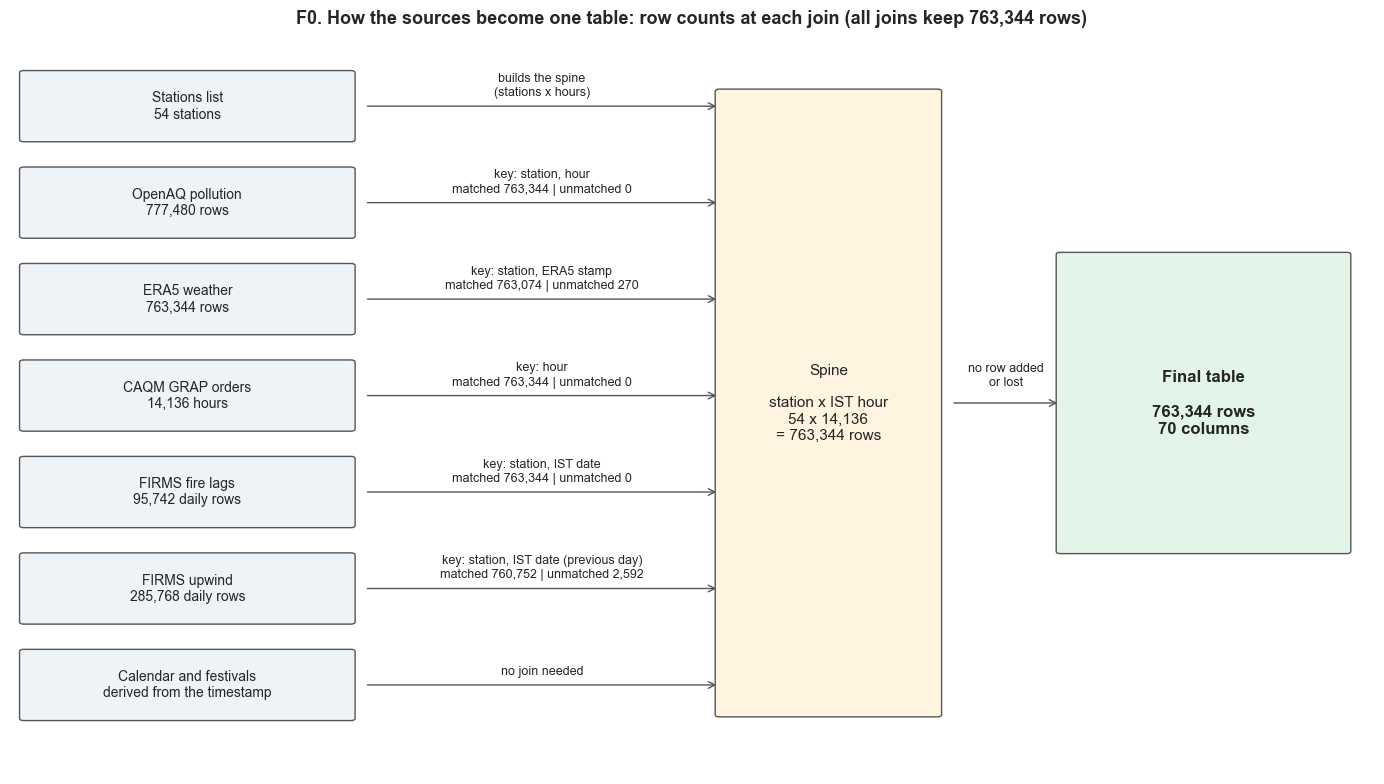

In [18]:
# Step 2.2c: draw F0 (boxes = tables, arrows = joins, labels = key and match counts)
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(14, 8)); ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
for i, (text, label) in enumerate(sources_boxes):
    y = 90 - i * 13
    ax.add_patch(FancyBboxPatch((1, y - 4.5), 24, 9, boxstyle="round,pad=0.3", fc="#EEF3F8", ec="#555555"))
    ax.text(13, y, text, ha="center", va="center", fontsize=10)
    ax.annotate("", xy=(52, y), xytext=(26, y), arrowprops=dict(arrowstyle="->", color="#555555"))
    ax.text(39, y + 1, label, ha="center", va="bottom", fontsize=9, bbox=dict(fc="white", ec="none", pad=1))
ax.add_patch(FancyBboxPatch((52, 8), 16, 84, boxstyle="round,pad=0.3", fc="#FFF4E0", ec="#555555"))
ax.text(60, 50, f"Spine\n\nstation x IST hour\n{n_stations} x {n_hours:,}\n= {n_rows:,} rows", ha="center", va="center", fontsize=11)
ax.annotate("", xy=(77, 50), xytext=(69, 50), arrowprops=dict(arrowstyle="->", color="#555555"))
ax.text(73, 52, "no row added\nor lost", ha="center", va="bottom", fontsize=9)
ax.add_patch(FancyBboxPatch((77, 30), 21, 40, boxstyle="round,pad=0.3", fc="#E3F4E8", ec="#555555"))
ax.text(87.5, 50, f"Final table\n\n{n_rows:,} rows\n{RAW_COLUMNS} columns", ha="center", va="center", fontsize=12, fontweight="bold")
ax.set_title("F0. How the sources become one table: row counts at each join (all joins keep " + f"{n_rows:,} rows)")
plt.tight_layout(); save_fig(fig, "F0_data_integration_flow"); plt.show()

In [19]:
# Step 2.2d: takeaway text from the join table
total_unmatched = int(join_table["Unmatched"].sum())
worst = join_table.loc[join_table["Unmatched"].idxmax()]
show_takeaway(
    f"**What we learn:** all **{len(join_table)}** joins keep exactly **{n_rows:,}** rows. Rows without a match are left empty, never dropped: "
    f"**{total_unmatched:,}** in total, the most in the *{worst['Join']}* join (**{worst['Unmatched']:,}** rows)."
)

**What we learn:** all **5** joins keep exactly **763,344** rows. Rows without a match are left empty, never dropped: **2,862** in total, the most in the *upwind, previous day* join (**2,592** rows).

*F0. Data-integration flow: sources, join keys and row counts at each step. Period: 19 Feb 2025 to 30 Sep 2026 (IST). Source: `docs/final_dataset_run_output.txt` (the build script's record).*

**What it shows.** Each box on the left is one input table with its row count. An arrow joins it to the **spine**, a table with one row for every station and every hour, using the key written on the arrow. The label gives how many spine rows found a match and how many did not.

**What it does not show.** A clean join says the table has the right shape, not that the values are right: those were checked separately by the build script and are re-run in Phase 3. The counts come from the script's saved output, which is only as current as the last build.

## 2.3 How the sources were aligned

- **Spine (stations x hours).** The 54 selected monitors times every IST hour from 19 Feb 2025 00:00 to 30 Sep 2026 23:00. Every station has every hour, so missing data shows up as an *empty cell*, never as a missing row.
- **Pollution (by station and hour).** `hour_ist` is the **start** of the PM2.5 hour. In the pollution file the PM2.5 label was shifted by one hour, so a value stamped H is the average of the hour before H. The gas and local-sensor columns have raw stamps that are real clock times, so they were taken from the row one hour earlier and every column in a row now describes the same hour.
- **Weather (by station and ERA5 stamp).** Each station takes the ERA5 values of its nearest 0.25 degree cell. The ERA5 stamp used is the PM2.5 hour's mid-point rounded up to the hour. The first five hours of the window have no weather, which explains the 270 unmatched rows.
- **Policy (by hour).** The GRAP stage is the same for all stations in an hour. `grap_stage_applied` equals it for treated stations and is 0 for control stations, which are outside the NCR.
- **Fire (by station and IST date, previous days only).** Every hour of date *d* receives the fire counts of day *d-1* (`lag1`) or of *d-1* plus *d-2* (`lag2`). **There is no same-day fire column on purpose**: a detection later in the day cannot explain an earlier reading. The *upwind* count keeps only detections within 100 km whose direction from the station lies within 45 degrees of where the wind came from. The upwind table starts on 20 Feb 2025, so the first two dates have no upwind value (the 2,592 unmatched rows).
- **Days without satellite data.** A day with no detections is set to zero only when the rule judges it a cloud day; otherwise it stays empty (an *outage* day), so the day after it has an empty lag.
- **Calendar.** Hour, weekday, season and festival windows are derived from the timestamp, so they need no join.

## 2.4 Structure of the table: column groups and types

**Question:** what kinds of columns are there, and how complete is each group?
**Sample:** the 70 columns of the file. **Look for:** how many columns each group has and how many of their cells are empty.

In [20]:
# Step 2.4a: assign every one of the 70 file columns to exactly one group
import pyarrow.parquet as pq
column_groups = {
    "Identifiers": ["station_id", "name", "city", "sub_area", "group", "latitude", "longitude", "hour_ist", "hour_utc"],
    "Pollution": pollution_cols + ["n_pm25", "n_pm10", "n_no", "n_no2", "n_nox", "n_so2", "n_co", "n_o3",
                  "local_temp_c", "local_rh", "local_wind_speed", "network_pm25_share", "network_outage"],
    "Weather": ["era5_time_utc"] + weather_cols,
    "Fire": fire_all,
    "Policy": ["grap_stage", "grap_stage_applied", "schedule_version", "grap_uncertain", "grap_inferred",
               "hours_since_stage_change", "last_change_direction"],
    "Calendar": ["hour", "weekday", "month", "season", "festival", "festival_day", "festival_window"],
}
listed = sum(column_groups.values(), [])
file_columns = pq.read_schema(PARQUET).names               # the columns exactly as stored in the file
assert len(listed) == len(set(listed)) == len(file_columns) and set(listed) == set(file_columns)
print("Every one of the", len(file_columns), "file columns is in exactly one group.")

Every one of the 70 file columns is in exactly one group.


In [21]:
# Step 2.4b: one row per group: number of columns, share of empty cells, examples
group_rows = []
for name, cols in column_groups.items():
    group_rows.append({"Group": name, "Columns": len(cols), "Empty cells (%)": round(df[cols].isna().mean().mean() * 100, 1),
                       "Examples": ", ".join(cols[:4]) + (", ..." if len(cols) > 4 else "")})
group_table = pd.DataFrame(group_rows).set_index("Group")
display(group_table)
save_table(group_table, "T01c_column_groups")

print("\nColumn types in the file:")
display(df[listed].dtypes.astype(str).value_counts().rename("columns").to_frame())
print("Five random station-hours (seeded) with one column from each group:")
display(df[["station_id", "hour_ist", "pm25", "wind_speed", "n_up_nh_100km_45deg_lag1", "grap_stage_applied", "season"]]
        .sample(5, random_state=SEED).sort_index())

,Columns,Empty cells (%),Examples
Group,,,
Identifiers,9,0.0,"station_id, name, city, sub_area, ..."
Pollution,21,11.9,"pm25, pm10, no, no2, ..."
Weather,10,0.0,"era5_time_utc, u10, v10, wind_speed, ..."
Fire,16,2.4,"n_nh_50km_lag1, n_nh_50km_lag2, frp_nh_50km_la..."
Policy,7,0.1,"grap_stage, grap_stage_applied, schedule_versi..."
Calendar,7,0.0,"hour, weekday, month, season, ..."


saved table : T01c_column_groups

Column types in the file:


,columns
float64,44
str,9
bool,6
int64,5
datetime64[us],3
int32,3


Five random station-hours (seeded) with one column from each group:


,station_id,hour_ist,pm25,wind_speed,n_up_nh_100km_45deg_lag1,grap_stage_applied,season
51217,5404,2026-02-21 01:00:00,67.175,2.2815,4.0,1,winter
181784,5634,2026-07-10 08:00:00,30.275,2.6736,0.0,0,monsoon
385434,8235,2025-07-25 18:00:00,65.000,1.2564,0.0,0,monsoon
421617,8365,2026-06-20 09:00:00,44.000,3.9387,1.0,0,monsoon
567453,229252,2025-05-13 21:00:00,48.250,2.5429,20.0,0,summer


**What it shows.** The 70 columns fall into six groups. The table lists how many columns each group holds and how many of their cells are empty, then the data types (numbers, text, true/false, timestamps), then five random rows so that the reader can see real values.

**What it does not show.** "Empty" means no reading, not zero. The empty share of a group mixes very complete columns with very sparse ones (for example PM2.5 against local wind speed), so Phase 3 looks at columns one by one.

## 2.5 Stations by group and sub-area

**Question:** how many monitors are there in each place, and how balanced are the treated and control groups?
**Sample:** the 54 stations. **Look for:** the very different group sizes and how few stations some sub-areas have.

In [22]:
# Step 2.5a: number of stations per group and sub-area
stations = df.drop_duplicates("station_id")
subarea_counts = (stations.groupby(["group", "sub_area"]).size().rename("stations").reset_index()
                          .sort_values(["group", "stations"], ascending=[False, False]).reset_index(drop=True))
assert subarea_counts["stations"].sum() == n_stations        # every station is counted once
display(subarea_counts)
save_table(subarea_counts.set_index("sub_area"), "T01d_stations_per_sub_area")

,group,sub_area,stations
0,treated,Delhi,33
1,treated,Ghaziabad,3
2,treated,Noida,2
3,treated,Gurugram,1
4,control,Patna,7
5,control,Lucknow,5
6,control,Kanpur,3


saved table : T01d_stations_per_sub_area


saved figure: F0b_stations_per_sub_area


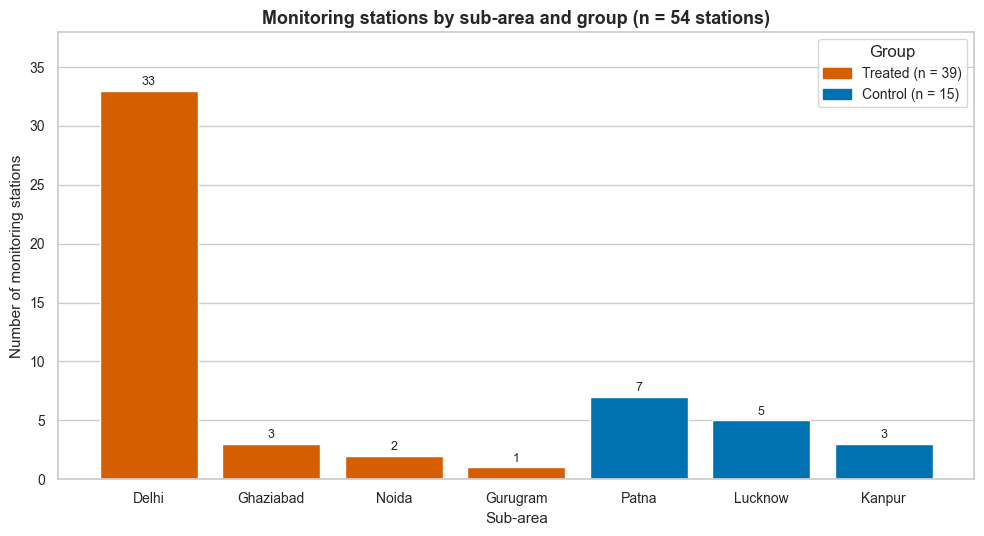

In [23]:
# Step 2.5b: bar chart, one bar per sub-area, coloured by group, count written on every bar
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(subarea_counts["sub_area"], subarea_counts["stations"], color=subarea_counts["group"].map(COL))
label_bars(ax, bars, "{:,.0f}")
ax.set_ylim(0, subarea_counts["stations"].max() * 1.15)
ax.grid(axis="x", visible=False)                      # no vertical lines through the value labels
ax.set_xlabel("Sub-area")
ax.set_ylabel("Number of monitoring stations")
ax.set_title(f"Monitoring stations by sub-area and group (n = {n_stations} stations)")
legend_items = [Patch(color=COL[g], label=f"{g.capitalize()} (n = {stations_per_group[g]})") for g in ["treated", "control"]]
ax.legend(handles=legend_items, title="Group")
plt.tight_layout(); save_fig(fig, "F0b_stations_per_sub_area"); plt.show()

In [24]:
# Step 2.5c: takeaway text from the table above
by_area = subarea_counts.set_index("sub_area")["stations"]
share_delhi = by_area["Delhi"] / n_stations * 100
show_takeaway(
    f"**What we learn:** **{stations_per_group['treated']}** treated stations against **{stations_per_group['control']}** control stations. "
    f"Delhi alone holds **{by_area['Delhi']}** stations (**{share_delhi:.0f}%** of all), while the smallest sub-areas have only "
    f"**{by_area.min()}** station(s)."
)

**What we learn:** **39** treated stations against **15** control stations. Delhi alone holds **33** stations (**61%** of all), while the smallest sub-areas have only **1** station(s).

*F0b. Number of monitoring stations by sub-area, coloured by group (treated = inside the NCR, where GRAP applies; control = Patna, Lucknow, Kanpur). n = 54 stations. Source: `final_dataset.parquet`.*

### 2.6 What the structure means for the analysis

**What it shows.** Each bar is one sub-area; the number on it is its station count; the colour says whether GRAP applies there.

**Why it matters.** The groups are **unbalanced**: treated stations far outnumber control stations, and the treated group is dominated by Delhi. A simple average over stations would mostly describe Delhi. Later phases therefore average by group, report the number of stations behind each value, and run leave-one-city-out checks. The three control cities are a comparison group, not a perfect copy of Delhi without GRAP: they differ in weather, fire exposure and local rules.

**What it does not show.** The number of stations says nothing about their quality or their location relative to traffic or industry, and several stations in one city are strongly correlated with each other, so 39 treated stations are not 39 independent observations.

---
# Phase 3: Data quality: missing data, outages, cleaning, validation
*BADIR: **D**ata.* Before any analysis we must know **where the data are missing, why, and whether that missingness is linked to what we study**. This phase measures the gaps, studies the network-wide outage, summarises the cleaning that was applied, and re-runs the main validation checks on the table we loaded.

## 3.1 Missing values by column (table T2)

**Question:** which columns are complete and which are sparse?
**Sample:** all 763,344 station-hours; the key columns of each group. **Look for:** the gap between the outcome (`pm25`) and the secondary variables (gases, local sensors).

In [25]:
# Step 3.1: T2, empty cells in the key columns (count and share of all station-hours)
key_columns = ["pm25", "pm10", "no", "no2", "nox", "so2", "co", "o3", "local_temp_c", "local_rh", "local_wind_speed",
               "u10", "wind_speed", "blh_m", "n_nh_100km_lag1", "n_nh_100km_lag2", "n_up_nh_100km_45deg_lag1",
               "hours_since_stage_change"]
t2_missing = pd.DataFrame({"Missing (count)": df[key_columns].isna().sum(),
                           "Missing (%)": (df[key_columns].isna().mean() * 100).round(1)})
t2_missing = t2_missing.sort_values("Missing (%)", ascending=False)
t2_missing.index.name = "Column"
display(t2_missing)
save_table(t2_missing, "T02_missingness")

,Missing (count),Missing (%)
Column,,
local_wind_speed,417957,54.8
nox,358508,47.0
local_temp_c,193555,25.4
local_rh,185085,24.2
so2,177639,23.3
pm10,106271,13.9
pm25,98753,12.9
no,96826,12.7
o3,93282,12.2


saved table : T02_missingness


saved figure: F02a_missing_by_column


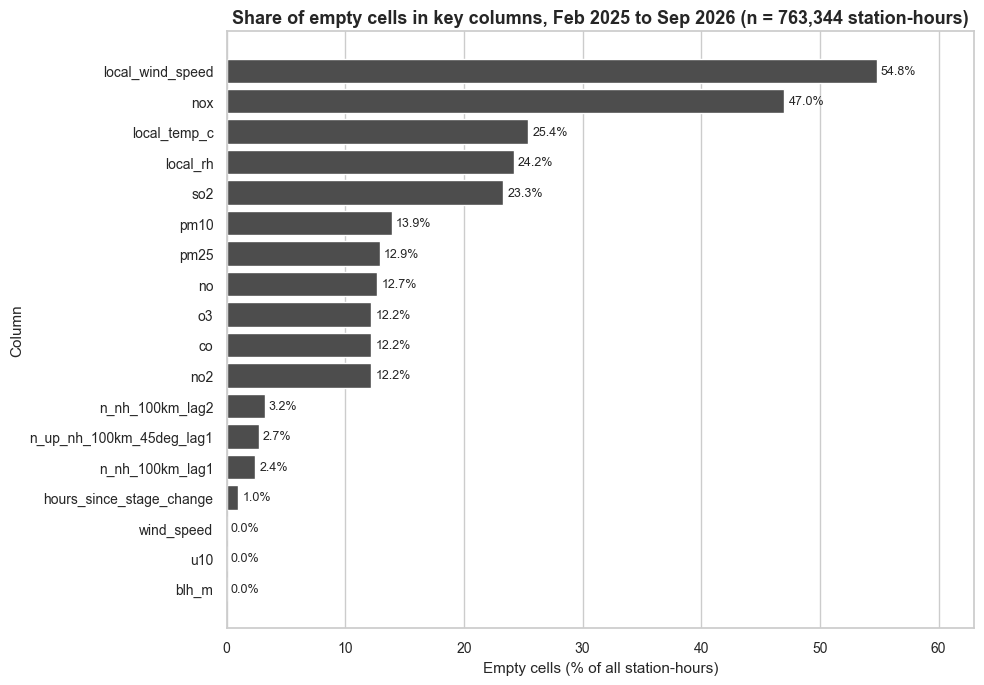

In [26]:
# Step 3.2: bar chart of the share of empty cells per key column, percentage written on every bar
plot_missing = t2_missing.sort_values("Missing (%)")                      # smallest at the bottom
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(plot_missing.index, plot_missing["Missing (%)"], color="#4D4D4D")
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_xlim(0, plot_missing["Missing (%)"].max() * 1.15)
ax.set_xlabel("Empty cells (% of all station-hours)")
ax.set_ylabel("Column")
ax.set_title(f"Share of empty cells in key columns, Feb 2025 to Sep 2026 (n = {n_rows:,} station-hours)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); save_fig(fig, "F02a_missing_by_column"); plt.show()

In [27]:
# Step 3.2b: takeaway text from the table above
worst_col = t2_missing.index[0]
weather_missing_rows = int(df["u10"].isna().sum())
show_takeaway(
    f"**What we learn:** PM2.5 is empty in **{t2_missing.loc['pm25', 'Missing (%)']:.1f}%** of station-hours, which is the share of "
    f"the outcome we cannot use. The sparsest key column is `{worst_col}` (**{t2_missing.iloc[0]['Missing (%)']:.1f}%** empty). "
    f"Weather is missing in only **{weather_missing_rows:,}** rows, which is **{weather_missing_rows / n_stations:.0f}** hours per station."
)

**What we learn:** PM2.5 is empty in **12.9%** of station-hours, which is the share of the outcome we cannot use. The sparsest key column is `local_wind_speed` (**54.8%** empty). Weather is missing in only **270** rows, which is **5** hours per station.

In [28]:
# Step 3.2c: why are some columns sparse? Count stations with no data at all and find when the local wind sensor starts
sensor_cols = ["local_temp_c", "local_rh", "local_wind_speed", "nox"]
share_present = df.groupby("station_id")[sensor_cols].agg(lambda s: s.notna().mean())
no_data = (share_present == 0).sum()                         # stations with no reading at all in the whole window
under_half = (share_present < 0.5).sum()                     # stations present in fewer than half of the hours
wind_first = df.loc[df["local_wind_speed"].notna(), "hour_ist"].min()
display(pd.DataFrame({"Stations with no data": no_data, "Stations with data in under half of hours": under_half}))
show_takeaway(
    f"**What we learn:** **{no_data['local_temp_c']}** of **{n_stations}** stations have no local temperature or humidity sensor data at all, and "
    f"the local wind sensor's first reading is on **{wind_first:%d %b %Y}**. NOx is different: every station reports some NOx "
    f"(**{no_data['nox']}** stations with none), but **{under_half['nox']}** stations report it in under half of the hours."
)

,Stations with no data,Stations with data in under half of hours
local_temp_c,8,8
local_rh,8,8
local_wind_speed,8,12
nox,0,6


**What we learn:** **8** of **54** stations have no local temperature or humidity sensor data at all, and the local wind sensor's first reading is on **08 Oct 2025**. NOx is different: every station reports some NOx (**0** stations with none), but **6** stations report it in under half of the hours.

*F02a. Share of empty cells per key column, all station-hours, Feb 2025 to Sep 2026 (IST). n = 763,344. Source: `final_dataset.parquet`.*

**What it shows.** Each bar is one column; its length and label give the percentage of station-hours with no value.

**What we learn (reading the bars).** The outcome `pm25` and the gas columns are mostly present. `nox` and the stations' own temperature, humidity and wind sensors are much sparser. The numbers just above show why: some stations have no local sensors at all, the local wind sensor only starts in October 2025, and NOx is reported in under half of the hours at a few stations. Weather (ERA5) is complete except for the first few hours of the window, which come before the first available ERA5 stamp. The fire lag columns are empty on days after a satellite outage, and `hours_since_stage_change` is empty only before the first GRAP change on 24 Feb 2025. For this reason the gases and local sensors are **secondary variables** in the analysis.

**What it does not show.** A percentage over all stations hides *which* stations and months are missing (Phase 6, figure F1) and says nothing about whether the missing hours are random. They are not: the largest gap is a network-wide outage, studied next.

## 3.4 The network-wide outage

**Question:** when did the whole monitoring network stop reporting, and for how long?
**Rule:** an hour is a *network outage* when fewer than half of the 54 stations report PM2.5. That is missing data from the network, not clean air.
**Look for:** the many short runs, and the one very long run.

In [29]:
# Step 3.4: outage runs: group consecutive outage hours into runs (the flag is the same for every station in an hour)
outage_hours = df.loc[df["network_outage"], "hour_ist"].drop_duplicates().sort_values()
run_id = (outage_hours.diff() != pd.Timedelta("1h")).cumsum()                 # a new run starts after any gap
outage_runs = outage_hours.groupby(run_id).agg(start="min", end="max", hours="size").reset_index(drop=True)

# Stage III or IV hours (treated stations) that fall inside each run
stage34_hours = df.loc[(df["group"] == "treated") & (df["grap_stage_applied"] >= 3), "hour_ist"].drop_duplicates()
outage_runs["stage34_hours_inside"] = [int(stage34_hours.between(s, e).sum()) for s, e in zip(outage_runs["start"], outage_runs["end"])]
outage_runs["days"] = (outage_runs["hours"] / 24).round(1)
outage_runs.index = outage_runs.index + 1
outage_runs.index.name = "Run"
save_table(outage_runs, "T02b_outage_runs")                       # the full list of runs is saved

LONG_RUN_HOURS = 12                                               # runs of at least this length are shown below
long_runs = outage_runs[outage_runs["hours"] >= LONG_RUN_HOURS]
n_short, short_hours = int((outage_runs["hours"] < LONG_RUN_HOURS).sum()), int(outage_runs.loc[outage_runs["hours"] < LONG_RUN_HOURS, "hours"].sum())
display(long_runs)
print(f"Not shown: {n_short} runs shorter than {LONG_RUN_HOURS} hours, {short_hours} hours in all (all runs are in T02b).")
print("Total outage hours:", outage_runs["hours"].sum(), "in", len(outage_runs), "runs")

saved table : T02b_outage_runs


,start,end,hours,stage34_hours_inside,days
Run,,,,,
2,2025-04-09 06:00:00,2025-04-11 18:00:00,61,0,2.5
3,2025-04-14 13:00:00,2025-04-15 01:00:00,13,0,0.5
4,2025-04-15 18:00:00,2025-04-16 07:00:00,14,0,0.6
9,2025-05-25 18:00:00,2025-05-26 16:00:00,23,0,1.0
44,2025-10-26 10:00:00,2025-10-27 01:00:00,16,0,0.7
50,2025-11-03 20:00:00,2025-11-04 08:00:00,13,0,0.5
69,2026-01-10 17:00:00,2026-01-20 18:00:00,242,94,10.1
72,2026-02-03 14:00:00,2026-02-04 05:00:00,16,0,0.7
75,2026-02-08 00:00:00,2026-02-08 19:00:00,20,0,0.8


Not shown: 154 runs shorter than 12 hours, 331 hours in all (all runs are in T02b).
Total outage hours: 928 in 170 runs


saved figure: F02b_outage_runs


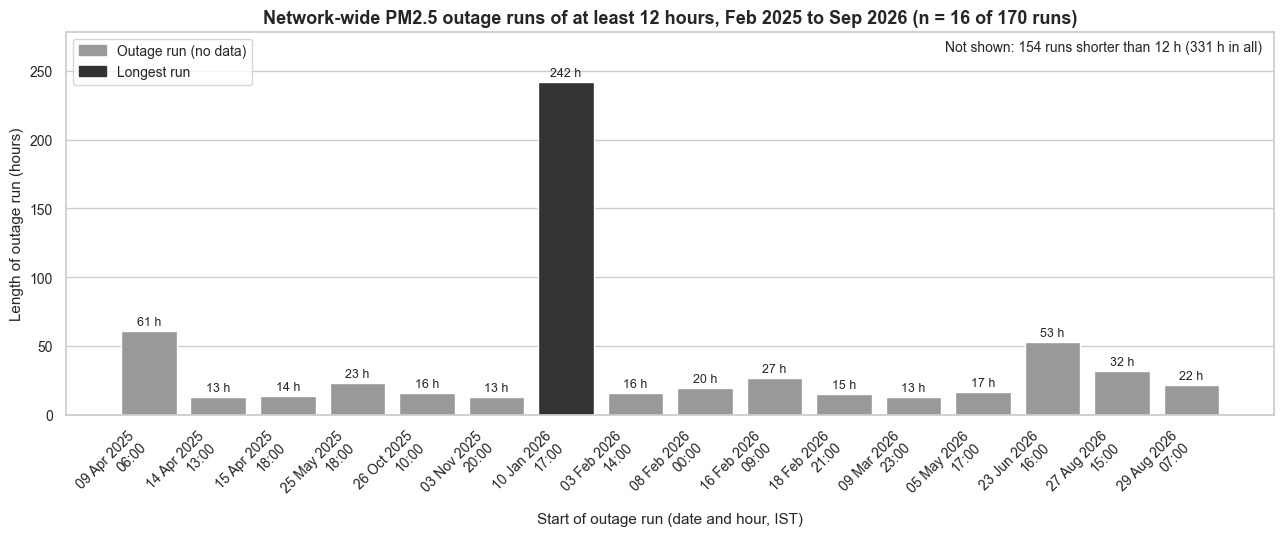

In [30]:
# Step 3.5: bar chart of outage length per run, hours written on top; the longest run is highlighted
longest = outage_runs["hours"].idxmax()
colours = [("#333333" if run == longest else GREY) for run in long_runs.index]
labels = [f"{s:%d %b %Y}\n{s:%H:%M}" for s in long_runs["start"]]
fig, ax = plt.subplots(figsize=(13, 5.5))
bars = ax.bar(labels, long_runs["hours"], color=colours)
label_bars(ax, bars, "{:,.0f} h")
ax.set_ylim(0, long_runs["hours"].max() * 1.15)
ax.text(0.99, 0.95, f"Not shown: {n_short} runs shorter than {LONG_RUN_HOURS} h ({short_hours} h in all)", transform=ax.transAxes, ha="right", fontsize=10)
plt.xticks(rotation=45, ha="right")
ax.grid(axis="x", visible=False)
ax.set_xlabel("Start of outage run (date and hour, IST)")
ax.set_ylabel("Length of outage run (hours)")
ax.set_title(f"Network-wide PM2.5 outage runs of at least {LONG_RUN_HOURS} hours, Feb 2025 to Sep 2026 (n = {len(long_runs)} of {len(outage_runs)} runs)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=GREY, label="Outage run (no data)"), Patch(color="#333333", label="Longest run")], loc="upper left")
plt.tight_layout(); save_fig(fig, "F02b_outage_runs"); plt.show()

In [31]:
# Step 3.5b: takeaway text from the outage table
long_run = outage_runs.loc[longest]
share_outage = outage_runs["hours"].sum() / n_hours * 100
show_takeaway(
    f"**What we learn:** the network was in outage for **{outage_runs['hours'].sum():,}** of **{n_hours:,}** hours (**{share_outage:.1f}%**), in "
    f"**{len(outage_runs)}** runs: **{n_short}** short ones (under {LONG_RUN_HOURS} hours) and **{len(long_runs)}** long ones. The longest started on **{long_run['start']:%d %b %Y %H:%M}** and ran **{long_run['hours']:,}** hours "
    f"(**{long_run['hours'] / outage_runs['hours'].sum() * 100:.0f}%** of all outage hours)."
)

**What we learn:** the network was in outage for **928** of **14,136** hours (**6.6%**), in **170** runs: **154** short ones (under 12 hours) and **16** long ones. The longest started on **10 Jan 2026 17:00** and ran **242** hours (**26%** of all outage hours).

*F02b. Length of the network-wide PM2.5 outage runs of at least 12 hours (fewer than half of the 54 stations reporting). Start times in IST. n = number of runs shown, given in the title; shorter runs are summarised on the chart and listed in T02b. Source: `final_dataset.parquet`, column `network_outage`.*

**What it shows.** One bar per long outage run. The label under the bar is when the run started; the number on top is how many hours it lasted. The darker bar is the longest run. Most runs are short (an hour or two) and would not be readable on this chart, so the note on the chart gives their number and total.

**A note on the longest run.** The outage flag marks it from 10 Jan 2026 17:00 (242 hours), one hour earlier than the 241-hour window (18:00 to 18:00 on 20 Jan) in which *no* station reported. At 17:00 only 37% of stations were still reporting, which is below the half that defines an outage. The Stage III/IV counts are the same with either start.

**What it does not show.** The chart does not say what caused each outage, nor what PM2.5 was doing while the network was silent. It also counts only *network-wide* outages; individual stations have their own shorter gaps, which are part of the missing share in table T2.

## 3.6 Does the outage overlap the strongest GRAP stages?

**Question:** how many Stage III or IV hours fall inside an outage? This matters because **missing data that is linked to the policy variable can bias H2**.
**Sample:** hours when the treated stations were at Stage III or IV, counted once per hour (not per station). The result is also cross-checked against the earlier validation script.

In [32]:
# Step 3.6a: Stage III/IV hours inside an outage, and the share (counted per hour, not per station)
n_stage34 = len(stage34_hours)
in_outage = stage34_hours.isin(outage_hours)
n_inside = int(in_outage.sum())
long_start, long_end = outage_runs.loc[longest, ["start", "end"]]
n_inside_long = int(stage34_hours.between(long_start, long_end).sum())
n_inside_short = n_inside - n_inside_long

print(f"Stage III/IV hours (treated)          : {n_stage34:,}")
print(f"  inside any outage                   : {n_inside:,} ({n_inside / n_stage34 * 100:.1f}%)")
print(f"    inside the longest run            : {n_inside_long:,}")
print(f"    inside the shorter runs           : {n_inside_short:,}")
print(f"For comparison, outage hours are {share_outage:.1f}% of all hours.")

Stage III/IV hours (treated)          : 971
  inside any outage                   : 112 (11.5%)
    inside the longest run            : 94
    inside the shorter runs           : 18
For comparison, outage hours are 6.6% of all hours.


In [33]:
# Step 3.6b: cross-check against the validation script's saved output (they must agree)
val_text = open(os.path.join(ROOT, "docs", "validation_run_output.txt"), encoding="utf-8").read()
v_total = int(re.search(r"Stage III/IV hours in the window -- ([\d,]+) hours", val_text).group(1).replace(",", ""))
v_inside = int(re.search(r"fall inside a network outage -- ([\d,]+) hours", val_text).group(1).replace(",", ""))
v_long, v_short = [int(x) for x in re.search(r"in shorter outages -- (\d+) / (\d+)", val_text).groups()]

cross = pd.DataFrame({"Notebook": [n_stage34, n_inside, n_inside_long, n_inside_short],
                      "Validation script": [v_total, v_inside, v_long, v_short]},
                     index=["Stage III/IV hours", "inside any outage", "inside the longest run", "inside shorter runs"])
cross["Same"] = cross["Notebook"] == cross["Validation script"]
display(cross)
assert cross["Same"].all(), "notebook and validation script disagree"

,Notebook,Validation script,Same
Stage III/IV hours,971,971,True
inside any outage,112,112,True
inside the longest run,94,94,True
inside shorter runs,18,18,True


**What it shows.** The number of Stage III/IV hours, how many of them fall inside an outage, and a cross-check against the validation script written earlier (an independent piece of code).

**What we learn.** The two counts agree. Outage hours are only a small share of all hours, but they make up a clearly larger share of the Stage III/IV hours, so the missing data is **not** spread evenly: it is concentrated in the strongest GRAP period.

In [34]:
# Step 3.6c: takeaway text from the variables above
show_takeaway(
    f"**What we learn:** **{n_inside:,}** of **{n_stage34:,}** Stage III/IV hours (**{n_inside / n_stage34 * 100:.1f}%**) fall inside an outage, "
    f"against **{share_outage:.1f}%** of all hours. Of these, **{n_inside_long:,}** are inside the longest run."
)

**What we learn:** **112** of **971** Stage III/IV hours (**11.5%**) fall inside an outage, against **6.6%** of all hours. Of these, **94** are inside the longest run.

### 3.7 What the outage means for the analysis

**Why it is missing data, not clean air.** During an outage no station reports PM2.5. If we treated the gap as zero, or filled it by interpolation, we would invent a fall in pollution at exactly the time the strictest GRAP stages applied.

**How it is handled.** The **primary analysis drops outage hours**. A station-day counts only with at least 18 of 24 valid hours, and a group-day with at least half of the group's stations valid. A sensitivity run later fills gaps of up to three hours, never across an outage.

**Why it matters for H2.** The outage overlaps a measurable share of the Stage III/IV hours (see above). Events whose windows fall in the outage will be flagged and tested with and without them. This is a threat to H2, so it is stated here and repeated beside the H2 results.

**What it does not show.** We cannot know how high PM2.5 was during the outage. Nothing here says the outage *caused* a bias, only that missing data and the strongest stage coincide in time.

## 3.8 Cleaning that was applied

**Question:** how many readings were removed as impossible or suspect, and where?
**Sample:** the 54 stations of the final table. **Two stages:** the pollution table (negatives, implausibly high PM, long flat runs) and the final table (physical limits for gases and local sensors, rule B-11). Spikes (a change of more than 300 ug/m3 from one hour to the next) are only *counted*, never removed.

In [35]:
# Step 3.8a: readings removed when the pollution table was built (from the quality report), per pollutant
quality = pd.read_csv(os.path.join(ROOT, "data", "processed", "pollution_quality_report.csv"))
quality = quality[quality["station_id"].isin(df["station_id"].unique())]          # drop the validation-only station
quality["removed"] = quality["hours_with_data"] - quality["hours_valid_after_qc"]
assert (quality["removed"] == quality["negative"] + quality["implausibly_high"] + quality["flatline_hours"]).all()

by_param = quality.groupby("parameter")[["hours_with_data", "negative", "implausibly_high", "flatline_hours", "removed", "spikes_gt300"]].sum()
by_param = by_param.loc[["pm25", "pm10", "no", "no2", "nox", "so2", "co", "o3"]]
display(by_param)

,hours_with_data,negative,implausibly_high,flatline_hours,removed,spikes_gt300
parameter,,,,,,
pm25,667585,842,571,1581,2994,819
pm10,659824,396,664,1691,2751,3368
no,667307,645,0,0,645,0
no2,670921,678,0,0,678,0
nox,405071,182,0,0,182,0
so2,586051,238,0,0,238,0
co,671331,1295,0,0,1295,0
o3,671142,838,0,0,838,0


In [36]:
# Step 3.8b: values set empty by the physical-limit rule B-11 in the final table (parsed from the build script's output)
b11_text = re.search(r"B-11 values set to empty \(outside physical limits\): (.+)", run_text).group(1)
b11 = {name: int(n.replace(",", "")) for name, n in re.findall(r"(\w+) ([\d,]+)", b11_text)}

cleaning = by_param[["hours_with_data", "removed", "spikes_gt300"]].rename(
    columns={"hours_with_data": "Hours with data", "removed": "Removed: pollution table", "spikes_gt300": "Hour-to-hour jumps >300 (counted only)"})
cleaning["Removed: final table (B-11)"] = [b11.get(p, 0) for p in cleaning.index]
cleaning["Total removed"] = cleaning["Removed: pollution table"] + cleaning["Removed: final table (B-11)"]
cleaning["Share removed (%)"] = (cleaning["Total removed"] / cleaning["Hours with data"] * 100).round(2)
display(cleaning)
save_table(cleaning, "T02c_cleaning_summary")
print("Local sensors cleaned in B-11:", {k: v for k, v in b11.items() if k.startswith("local_")})

,Hours with data,Removed: pollution table,Hour-to-hour jumps >300 (counted only),Removed: final table (B-11),Total removed,Share removed (%)
parameter,,,,,,
pm25,667585,2994,819,0,2994,0.45
pm10,659824,2751,3368,0,2751,0.42
no,667307,645,0,91,736,0.11
no2,670921,678,0,32,710,0.11
nox,405071,182,0,0,182,0.04
so2,586051,238,0,64,302,0.05
co,671331,1295,0,3,1298,0.19
o3,671142,838,0,190,1028,0.15


saved table : T02c_cleaning_summary
Local sensors cleaned in B-11: {'local_temp_c': 102, 'local_rh': 1382, 'local_wind_speed': 1}


saved figure: F02c_values_removed


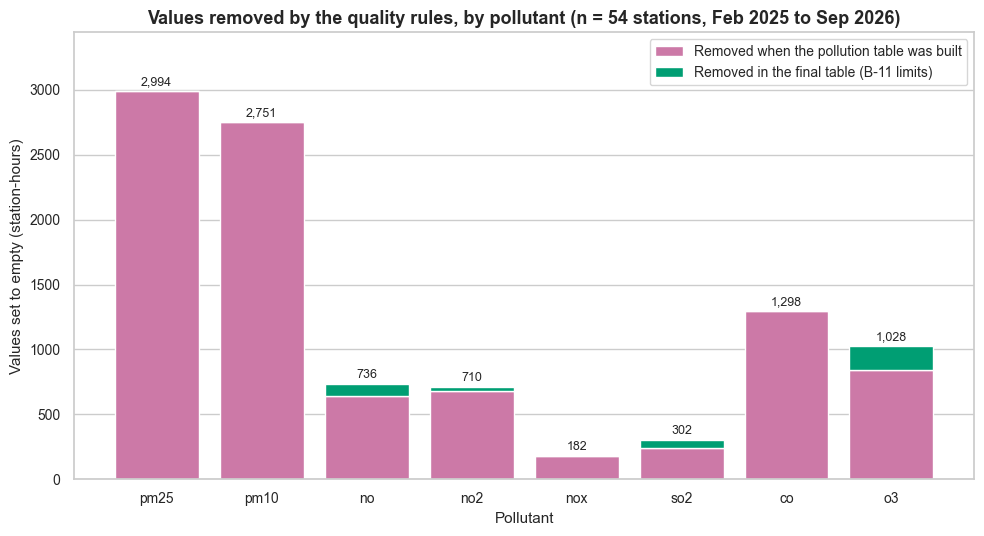

In [37]:
# Step 3.8c: stacked bar chart of values removed per pollutant, total written on every bar
fig, ax = plt.subplots(figsize=(10, 5.5))
stage1, stage2 = cleaning["Removed: pollution table"], cleaning["Removed: final table (B-11)"]
ax.bar(cleaning.index, stage1, color="#CC79A7", label="Removed when the pollution table was built")
bars = ax.bar(cleaning.index, stage2, bottom=stage1, color="#009E73", label="Removed in the final table (B-11 limits)")
for x, total in zip(cleaning.index, cleaning["Total removed"]):
    ax.annotate(f"{total:,.0f}", (x, total), ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")
ax.set_ylim(0, cleaning["Total removed"].max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Pollutant")
ax.set_ylabel("Values set to empty (station-hours)")
ax.set_title(f"Values removed by the quality rules, by pollutant (n = {n_stations} stations, Feb 2025 to Sep 2026)")
ax.legend()
plt.tight_layout(); save_fig(fig, "F02c_values_removed"); plt.show()

In [38]:
# Step 3.8d: takeaway text from the cleaning table
top = cleaning["Total removed"].idxmax()
show_takeaway(
    f"**What we learn:** the rules removed **{int(cleaning['Total removed'].sum()):,}** values in all. The most affected pollutant is "
    f"**{top}** (**{int(cleaning.loc[top, 'Total removed']):,}** values, **{cleaning.loc[top, 'Share removed (%)']:.2f}%** of its readings). "
    f"For PM2.5, the outcome, **{cleaning.loc['pm25', 'Share removed (%)']:.2f}%** of readings were removed, while "
    f"**{int((df['pm25'] > 300).sum()):,}** station-hours with PM2.5 above 300 ug/m3 were kept."
)

**What we learn:** the rules removed **10,001** values in all. The most affected pollutant is **pm25** (**2,994** values, **0.45%** of its readings). For PM2.5, the outcome, **0.45%** of readings were removed, while **14,229** station-hours with PM2.5 above 300 ug/m3 were kept.

*F02c. Values set to empty by the quality rules, by pollutant, 54 stations, Feb 2025 to Sep 2026. Pink = removed when the pollution table was built (negative values, PM2.5 above 1,000 or PM10 above 2,000 ug/m3, runs of 24 or more identical hours); green = removed in the final table (values outside physical limits for gases and sensors). Sources: `pollution_quality_report.csv`, `final_dataset_run_output.txt`.*

**What it shows.** For each pollutant, how many hourly values were set to empty and by which rule. The table above also shows the share removed and the number of hour-to-hour jumps above 300 ug/m3 that were counted and left in place.

**What it does not show.** A removed value is a judgement: a rule cannot tell an instrument glitch from a real extreme. A jump of more than 300 ug/m3 in one hour is counted but was **kept**, and so were high PM values themselves (the sentence above gives how many PM2.5 station-hours exceed 300 ug/m3): only impossible values and long flat lines were removed. We cannot test how many wrong values remain.

## 3.9 Re-running the validation checks on the loaded table

**Question:** is the table that this notebook loaded still the table that was validated when it was built?
**Method:** the main checks of `src/validate_final_dataset.py`, re-implemented here in plain pandas so the logic is visible. Each prints PASS or FAIL.

In [39]:
# Step 3.9a: checks on structure and time (each entry is a statement that must be True)
checks = {}
hours_per_station = df.groupby("station_id")["hour_ist"].nunique()
checks["763,344 rows (54 stations x 14,136 hours)"] = len(df) == 763344
checks["70 columns in the file"] = RAW_COLUMNS == 70
checks["(station_id, hour_ist) is unique"] = not df.duplicated(["station_id", "hour_ist"]).any()
checks["every station has every hour"] = len(hours_per_station) == 54 and (hours_per_station == 14136).all()
checks["hour_ist runs 19 Feb 2025 00:00 to 30 Sep 2026 23:00"] = (
    df["hour_ist"].min() == pd.Timestamp("2025-02-19 00:00") and df["hour_ist"].max() == pd.Timestamp("2026-09-30 23:00"))
checks["hour_utc = hour_ist - 5:30"] = (pd.to_datetime(df["hour_utc"]) == df["hour_ist"] - pd.Timedelta(hours=5, minutes=30)).all()
checks["39 treated and 15 control stations"] = stations_per_group.to_dict() == {"control": 15, "treated": 39}
checks["PM2.5 present in 664,591 rows"] = df["pm25"].notna().sum() == 664591
checks["PM2.5 lies between 0 and 1,000 ug/m3"] = df["pm25"].dropna().between(0, 1000).all()
checks["n_pm25 > 0 wherever PM2.5 is present"] = (df.loc[df["pm25"].notna(), "n_pm25"] > 0).all()
print(len(checks), "structure checks defined")

10 structure checks defined


In [40]:
# Step 3.9b: checks on outages, weather, fire and policy
by_hour = df.groupby("hour_ist")
january = df["hour_ist"].between(pd.Timestamp("2026-01-10 18:00"), pd.Timestamp("2026-01-20 18:00"))
stage_series = df[df["group"] == "treated"].groupby("hour_ist")["grap_stage"].max()
checks["network_outage is exactly 'share of stations reporting < 0.5'"] = (df["network_outage"] == (df["network_pm25_share"] < 0.5)).all()
checks["network_outage is the same for all stations in an hour"] = (by_hour["network_outage"].nunique() == 1).all()
checks["928 outage hours"] = by_hour["network_outage"].max().sum() == 928
checks["PM2.5 empty at every station, 10 Jan 18:00 to 20 Jan 18:00 2026"] = df.loc[january, "pm25"].isna().all()
checks["weather empty only in the first 5 hours of 19 Feb 2025"] = (
    df["u10"].isna().sum() == 54 * 5 and (df.loc[df["u10"].isna(), "hour_ist"] < pd.Timestamp("2025-02-19 05:00")).all())
checks["every fire column ends in _lag1 or _lag2 (no same-day column)"] = all(c.endswith(("_lag1", "_lag2")) for c in fire_columns)
checks["fire values are constant within each station and IST date"] = (
    df.groupby(["station_id", "date_ist"])[fire_columns].nunique(dropna=False) <= 1).all().all()
checks["grap_stage_applied = grap_stage (treated), 0 (control)"] = (
    (df["grap_stage_applied"] == np.where(df["group"] == "treated", df["grap_stage"], 0)).all())
checks["30 GRAP stage changes in the window"] = int(stage_series.diff().fillna(0).ne(0).sum()) == 30
checks["Stage III/IV hours: 971 in total, 112 inside an outage"] = (n_stage34, n_inside) == (971, 112)
print(len(checks), "checks defined in total")

20 checks defined in total


In [41]:
# Step 3.9c: run the verdicts: PASS or FAIL for each check, then the total
verdicts = pd.Series({name: bool(result) for name, result in checks.items()})
for name, ok_check in verdicts.items():
    print(("[PASS] " if ok_check else "[FAIL] ") + name)

script_summary = re.search(r"(\d+) passed, (\d+) failed", val_text).group(0)        # the validation script's own total
print(f"\nNotebook: {verdicts.sum()} passed, {(~verdicts).sum()} failed of {len(verdicts)} checks.")
print(f"Validation script (more checks, run separately): {script_summary}.")
assert verdicts.all(), "a validation check failed: do not continue until this is understood"

[PASS] 763,344 rows (54 stations x 14,136 hours)
[PASS] 70 columns in the file
[PASS] (station_id, hour_ist) is unique
[PASS] every station has every hour
[PASS] hour_ist runs 19 Feb 2025 00:00 to 30 Sep 2026 23:00
[PASS] hour_utc = hour_ist - 5:30
[PASS] 39 treated and 15 control stations
[PASS] PM2.5 present in 664,591 rows
[PASS] PM2.5 lies between 0 and 1,000 ug/m3
[PASS] n_pm25 > 0 wherever PM2.5 is present
[PASS] network_outage is exactly 'share of stations reporting < 0.5'
[PASS] network_outage is the same for all stations in an hour
[PASS] 928 outage hours
[PASS] PM2.5 empty at every station, 10 Jan 18:00 to 20 Jan 18:00 2026
[PASS] weather empty only in the first 5 hours of 19 Feb 2025
[PASS] every fire column ends in _lag1 or _lag2 (no same-day column)
[PASS] fire values are constant within each station and IST date
[PASS] grap_stage_applied = grap_stage (treated), 0 (control)
[PASS] 30 GRAP stage changes in the window
[PASS] Stage III/IV hours: 971 in total, 112 inside an ou

**What it shows.** Every line is a statement about the table that must be true; PASS means it is. The checks cover the shape of the table, time keys, the outage flag, the weather gap, the lag-only rule for fire, the GRAP columns and the Stage III/IV overlap.

**What we learn.** The loaded table passes all checks that were re-run here, so what the notebook analyses is what was built and validated. The validation script runs more checks (value ranges for every column, the dictionary's empty-cell counts, fire-radius ordering); its saved output in `docs/validation_run_output.txt` records that all of them passed.

**What it does not show.** Passing checks means *internally consistent*, not *correct*: the checks cannot detect a wrong source file, or a reading that is plausible but wrong.

In [42]:
# Step 3.10a: numbers for the caveats below, computed from the table
raw_but_emptied = int(((df["n_pm25"] > 0) & df["pm25"].isna()).sum())
usable_pm25 = int((df["valid_hour"]).sum())
show_takeaway(
    f"**What we learn:** **{usable_pm25:,}** station-hours ({usable_pm25 / n_rows * 100:.1f}%) have valid PM2.5 and are outside outages: "
    f"this is the data that the analysis rests on. **{raw_but_emptied:,}** further rows have raw readings behind them but PM2.5 emptied by the "
    f"quality rules (values above 1,000 ug/m3 or long flat runs)."
)

**What we learn:** **662,378** station-hours (86.8%) have valid PM2.5 and are outside outages: this is the data that the analysis rests on. **2,994** further rows have raw readings behind them but PM2.5 emptied by the quality rules (values above 1,000 ug/m3 or long flat runs).

In [43]:
# Step 3.10b: data check of the unit statement. If NO and NO2 are in ug/m3 and NOx in ppm, then NOx = 0.001 x (NO/1.23 + NO2/1.88)
gas = df.dropna(subset=["no", "no2", "nox"])
gas = gas[(gas["nox"] > 0) & (gas["no"] >= 0) & (gas["no2"] >= 0)]
predictor = gas["no"] / 1.23 + gas["no2"] / 1.88               # CPCB conversion factors from ug/m3 to ppb
slope = (predictor * gas["nox"]).sum() / (predictor ** 2).sum()  # least-squares slope through the origin
corr = np.corrcoef(predictor, gas["nox"])[0, 1]
show_takeaway(
    f"**What we learn:** the fitted slope is **{slope:.5f}** (correlation **{corr:.2f}**, n = **{len(gas):,}** station-hours). A slope close to "
    f"0.001 is what we expect if NO and NO2 are in ug/m3 and NOx is in ppm, which supports the unit statement in the dictionary."
)

**What we learn:** the fitted slope is **0.00099** (correlation **0.89**, n = **399,260** station-hours). A slope close to 0.001 is what we expect if NO and NO2 are in ug/m3 and NOx is in ppm, which supports the unit statement in the dictionary.

### 3.10 Rules and caveats carried forward

**Missing-data rule (primary).** An hour is *valid* when PM2.5 is present and the hour is not a network outage. Outage hours are **dropped**, never set to zero and never interpolated. A *station-day* needs at least 18 of 24 valid hours (sensitivities: 12 and 20); a *group-day* needs at least half of that group's stations valid. Interpolating gaps of up to three hours, never across an outage, is a sensitivity run only.

**Caveat 1: `n_pm25` is a raw count.** It counts the readings behind an hour *before* the quality rules. So `n_pm25 > 0` does not guarantee a PM2.5 value (see the count above). To decide whether an hour has PM2.5, always test `pm25` itself.

**Caveat 2: gas units are mislabelled.** The archive labels the gases "ppb" but the dictionary shows the real units: NO and NO2 in ug/m3, NOx in ppm (the slope check above supports this); SO2 and CO are probably ug/m3 and mg/m3 (not testable here). Gases are secondary variables and are not compared with standards in this notebook.

**Caveat 3: the outage overlaps the strongest stage.** Missing data and Stage III/IV are not independent (Section 3.6). H2 must show results with and without those events.

**What this phase does not show.** It measures missing data but cannot recover it. The conclusions of Phases 8 and 9 can only be as good as the readings that exist.

---
# Phase 4: Prepare the analysis tables
*BADIR: **D**ata.* The hypotheses are tested on **daily** data. This phase turns the hourly table into a **station-day table** (one row per station and IST date) and a **group-day series** (one value per group per day), checks the result against the raw hours, and saves it for the model phases.

## 4.1 Why we move from hourly to daily

- **Noise.** One hourly PM2.5 value is dominated by traffic, local plumes and instrument noise. A daily mean smooths this out and describes what a person is exposed to over a day.
- **Autocorrelation.** Neighbouring hours are almost the same (the PM2.5 of 10:00 predicts 11:00). Treating 24 hours as 24 independent observations would make us far too confident. Daily values are still correlated from day to day, which later phases handle with clustered standard errors.
- **The fire variable is daily.** Fire detections come as counts per IST date, so every hour of a day carries the same fire value. Analysing at the hourly level would only repeat that value 24 times.

**Rules (fixed in advance):** an *hour is valid* when PM2.5 is present and the hour is not a network outage; a *station-day is valid* with at least 18 of 24 valid hours (sensitivities: 12 and 20); a *group-day counts* when at least half of the group's stations have a valid day.

In [44]:
# Step 4.2a: the two helper functions of this phase (defined once here, reused in Phases 5 to 10)
MIN_VALID_HOURS = 18                       # primary rule; the sensitivity runs use 12 and 20

def valid_station_day(data, min_hours=MIN_VALID_HOURS):
    # One row per station and IST date: daily mean PM2.5 over valid hours; keep days with at least min_hours valid hours
    is_valid = data["pm25"].notna() & ~data["network_outage"]          # outage hours are dropped, never set to zero
    work = data.assign(valid=is_valid, pm25_ok=data["pm25"].where(is_valid))
    day = (work.groupby(["station_id", "group", "date_ist"])
               .agg(pm25_day=("pm25_ok", "mean"), valid_hours=("valid", "sum")).reset_index())
    return day[day["valid_hours"] >= min_hours].reset_index(drop=True)

def group_day(day_table, stations_in_group, min_share=0.5):
    # One row per group and date: mean over stations, with a 95% band over stations; needs at least half the stations
    out = (day_table.groupby(["group", "date_ist"])
                    .agg(pm25=("pm25_day", "mean"), sd=("pm25_day", "std"), n_stations=("station_id", "nunique")).reset_index())
    out["stations_total"] = out["group"].map(stations_in_group)
    out = out[out["n_stations"] >= min_share * out["stations_total"]].copy()
    out["se"] = out["sd"] / np.sqrt(out["n_stations"])
    out["ci_low"], out["ci_high"] = out["pm25"] - 1.96 * out["se"], out["pm25"] + 1.96 * out["se"]
    return out.reset_index(drop=True)
print("helpers defined: valid_station_day(), group_day()")

helpers defined: valid_station_day(), group_day()


In [45]:
# Step 4.2b: how many valid hours does each station-day have? (the whole grid of station-days, before any filtering)
all_days = valid_station_day(df, min_hours=0)                 # min_hours=0 keeps every station-day with its count
total_station_days = n_stations * (n_hours // 24)
assert len(all_days) == total_station_days, "every station should have every date"

bins = pd.cut(all_days["valid_hours"], [-1, 0, 11, 17, 24], labels=["0 valid hours", "1 to 11", "12 to 17", "18 to 24"])
valid_count_table = bins.value_counts().sort_index().rename("station-days").to_frame()
valid_count_table["share (%)"] = (valid_count_table["station-days"] / len(all_days) * 100).round(1)
display(valid_count_table)

,station-days,share (%)
valid_hours,,
0 valid hours,1209,3.8
1 to 11,1510,4.7
12 to 17,2362,7.4
18 to 24,26725,84.0


**What it shows.** Every station has 24 hours on every date. The table counts how many station-days fall into each band of valid hours.

**What it does not show.** Days with fewer than 18 valid hours are not necessarily bad; they are dropped from the primary analysis to avoid a daily mean that rests on a few hours of one time of day (for example only the cleaner afternoon). The 12 and 20 hour rules are tested later as sensitivity runs.

## 4.3 The station-day table

**Question:** what does one row of the daily table contain?
**Contents:** daily PM2.5 (outcome), daily weather (mean over the 24 hours of the IST date), fire values (the previous days, constant within the date), GRAP stage (maximum during the day and the value at 12:00), quality flags, and calendar fields.
**Rule for weather:** the daily mean uses all hours of the date, because weather drives pollution whether or not the monitor reported that hour. Humidity is computed from temperature and dew point.

In [46]:
# Step 4.3a: daily weather and policy per station-day (all 24 hours of the IST date)
# Relative humidity (%) from temperature and dew point (Magnus formula), then daily means
df["rh_pct"] = 100 * np.exp(17.625 * df["d2m_c"] / (243.04 + df["d2m_c"])) / np.exp(17.625 * df["t2m_c"] / (243.04 + df["t2m_c"]))

daily_weather = (df.groupby(["station_id", "date_ist"])
                   .agg(u10=("u10", "mean"), v10=("v10", "mean"), wind_speed=("wind_speed", "mean"),
                        t2m_c=("t2m_c", "mean"), d2m_c=("d2m_c", "mean"), rh_pct=("rh_pct", "mean"),
                        sp_hpa=("sp_hpa", "mean"), blh_m=("blh_m", "mean"),
                        tp_mm=("tp_mm", lambda x: x.sum(min_count=1)),            # total rain of the day (empty if no weather)
                        stage_max=("grap_stage_applied", "max"), grap_uncertain=("grap_uncertain", "max"),
                        grap_inferred=("grap_inferred", "max"), outage_hours=("network_outage", "sum")).reset_index())

# Wind direction from the daily mean wind vector (the direction the wind blows FROM), plus sine and cosine terms
daily_weather["wind_from_deg"] = (180 + np.degrees(np.arctan2(daily_weather["u10"], daily_weather["v10"]))) % 360
daily_weather["wind_dir_sin"] = np.sin(np.radians(daily_weather["wind_from_deg"]))
daily_weather["wind_dir_cos"] = np.cos(np.radians(daily_weather["wind_from_deg"]))
print("daily weather and policy rows:", len(daily_weather), "| relative humidity range:", daily_weather["rh_pct"].min().round(1), "to", daily_weather["rh_pct"].max().round(1))

daily weather and policy rows: 31806 | relative humidity range: 19.9 to 99.2


In [47]:
# Step 4.3b: daily fire values, GRAP stage at 12:00 and calendar fields (these are constant within the date)
fire_daily_cols = fire_columns + ["fire_day_status", "fire_is_nrt"]
daily_fire = df.groupby(["station_id", "date_ist"])[fire_daily_cols].first().reset_index()    # same value in all 24 hours

noon = (df[df["hour"] == 12][["station_id", "date_ist", "grap_stage_applied"]]
        .rename(columns={"grap_stage_applied": "stage_noon"}))
calendar = df.groupby(["station_id", "date_ist"])[["weekday", "month", "season", "festival"]].first().reset_index()
station_info = df.drop_duplicates("station_id")[["station_id", "city", "sub_area"]]

n_dates = n_hours // 24
assert all(len(t) == n_stations * n_dates for t in [daily_weather, daily_fire, noon, calendar]), "each daily table needs one row per station-date"
print("daily fire, noon-stage and calendar tables built:", len(daily_fire), "rows each")

daily fire, noon-stage and calendar tables built: 31806 rows each


In [48]:
# Step 4.3c: put it all together, keep days with at least 18 valid hours, and add the winter-sample flag
station_day_18 = valid_station_day(df, 18)                                   # outcome and valid-hour count
keys = ["station_id", "date_ist"]
analysis_station_day = (station_day_18.merge(station_info, on="station_id")
                        .merge(daily_weather, on=keys).merge(daily_fire, on=keys)
                        .merge(noon, on=keys).merge(calendar, on=keys))
analysis_station_day["in_winter_sample"] = analysis_station_day["date_ist"].between(WINTER_START, WINTER_END)

assert len(analysis_station_day) == len(station_day_18), "merges must not add or drop rows"
assert not analysis_station_day.duplicated(keys).any()
print("Station-day table:", analysis_station_day.shape[0], "rows x", analysis_station_day.shape[1], "columns")
print("Winter sample rows:", int(analysis_station_day["in_winter_sample"].sum()))

Station-day table: 26725 rows x 45 columns
Winter sample rows: 6623


In [49]:
# Step 4.3d: does it matter that daily weather uses all 24 hours? Compare with weather averaged over the valid-PM2.5 hours only
valid_rows = df[df["pm25"].notna() & ~df["network_outage"]]
weather_valid = valid_rows.groupby(["station_id", "date_ist"])[["wind_speed", "t2m_c", "blh_m"]].mean().reset_index()
compare = analysis_station_day[keys + ["wind_speed", "t2m_c", "blh_m"]].merge(weather_valid, on=keys, suffixes=("", "_valid"))
rows = []
for col in ["wind_speed", "t2m_c", "blh_m"]:
    diff = (compare[col] - compare[col + "_valid"]).abs()
    rows.append({"Variable": col, "Correlation": round(compare[col].corr(compare[col + "_valid"]), 4),
                 "Mean abs. difference": round(diff.mean(), 3), "99th percentile of difference": round(diff.quantile(0.99), 3)})
weather_rule_check = pd.DataFrame(rows).set_index("Variable")
display(weather_rule_check)
show_takeaway(f"**What we learn:** the two ways of averaging weather agree closely on the kept days: the lowest correlation is **{weather_rule_check['Correlation'].min():.3f}**.")

,Correlation,Mean abs. difference,99th percentile of difference
Variable,,,
wind_speed,0.9978,0.025,0.283
t2m_c,0.9992,0.101,1.217
blh_m,0.9846,15.944,180.900


**What we learn:** the two ways of averaging weather agree closely on the kept days: the lowest correlation is **0.985**.

In [50]:
# Step 4.3e: the 12-hour and 20-hour variants for the sensitivity runs (same table, different validity rule)
variant_hours = [12, 18, 20]
variant_counts = pd.DataFrame({"Minimum valid hours": variant_hours,
                               "Station-days kept": [len(valid_station_day(df, h)) for h in variant_hours]})
variant_counts["Share of all station-days (%)"] = (variant_counts["Station-days kept"] / total_station_days * 100).round(1)
display(variant_counts.set_index("Minimum valid hours"))

# A looser rule keeps more days, a stricter rule keeps fewer: the counts must be ordered
assert variant_counts["Station-days kept"].is_monotonic_decreasing
station_day_12, station_day_20 = valid_station_day(df, 12), valid_station_day(df, 20)

,Station-days kept,Share of all station-days (%)
Minimum valid hours,,
12,29087,91.5
18,26725,84.0
20,25418,79.9


**What it shows.** How many station-days survive each validity rule. The primary table uses 18 hours; the 12- and 20-hour tables are for sensitivity runs only.

**What it does not show.** These counts say how much data is kept, not whether the kept days are representative. Dropped days cluster in the outages (Phase 3), so the daily table under-represents those periods.

## 4.4 The group-day series

**Question:** what is the daily PM2.5 of the treated group and of the control group, with its uncertainty?
**Method:** the mean over the group's valid stations; the band is the 95% interval of that mean over stations (mean plus and minus 1.96 standard errors). A group-day counts only when at least half of the group's stations have a valid day.

In [51]:
# Step 4.4a: group-day series (treated and control), using the helper defined above
stations_by_group = df.groupby("group")["station_id"].nunique()
analysis_group_day = group_day(analysis_station_day, stations_by_group)

# Add group means of the daily drivers, and the stage (the same for every treated station on a day)
drivers = ["n_up_nh_100km_45deg_lag1", "n_nh_100km_lag1", "wind_speed", "t2m_c", "blh_m"]
group_drivers = analysis_station_day.groupby(["group", "date_ist"])[drivers].mean().reset_index()
group_stage = analysis_station_day.groupby(["group", "date_ist"])["stage_max"].max().reset_index()
analysis_group_day = analysis_group_day.merge(group_drivers, on=["group", "date_ist"]).merge(group_stage, on=["group", "date_ist"])

print(analysis_group_day.groupby("group").agg(days=("date_ist", "count"), mean_pm25=("pm25", "mean"), mean_stations=("n_stations", "mean")).round(1))
display(analysis_group_day.head())

         days  mean_pm25  mean_stations
group                                  
control   544       47.3           13.5
treated   542       78.9           35.6


,group,date_ist,pm25,sd,n_stations,stations_total,se,ci_low,ci_high,n_up_nh_100km_45deg_lag1,n_nh_100km_lag1,wind_speed,t2m_c,blh_m,stage_max
0,control,2025-02-19,84.306748,37.479771,15,15,9.677235,65.339367,103.274130,NaN,3.000000,1.827801,22.474744,505.690498,0
1,control,2025-02-20,83.922129,29.714371,14,15,7.941500,68.356790,99.487468,NaN,3.928571,2.333292,20.990744,391.126958,0
2,control,2025-02-21,85.494563,32.238340,15,15,8.323904,69.179712,101.809414,0.000000,0.000000,1.847557,22.202056,449.741558,0
3,control,2025-02-22,72.286476,35.455103,14,15,9.475775,53.713957,90.858995,1.928571,4.285714,2.293226,21.557908,486.148994,0
4,control,2025-02-23,64.203067,34.941991,14,15,9.338640,45.899333,82.506801,1.071429,4.500000,2.273450,20.865324,493.324283,0


**What it shows.** One row per group and day: the mean PM2.5, how many stations it rests on, the 95% band, the group's mean fire, weather and boundary-layer values, and the GRAP stage.

**What it does not show.** The band reflects differences *between stations* on that day, not measurement error. A day with few stations has a wide band (or none, with one station), so figures later in the notebook always show the number of stations.

## 4.5 Checks: do the daily tables match the hours?

**Question:** can we trust the daily tables? **Method:** (1) the counts must add up, (2) the daily table must equal the Phase 1 tables built with separate code, (3) five station-days (three random, two on days with GRAP Stage II or higher, all seeded) are recomputed from the raw hours with a different method and compared value by value.

In [52]:
# Step 4.5a: the row counts add up, and the new tables agree with the Phase 1 KPI tables (built by separate code)
dropped = total_station_days - len(station_day_18)
print(f"All station-days {total_station_days:,} = kept {len(station_day_18):,} + dropped {dropped:,}")
assert total_station_days == len(station_day_18) + (all_days["valid_hours"] < 18).sum()

same_days = analysis_station_day[["station_id", "date_ist", "pm25_day"]].merge(
    kpi_station_day[["station_id", "date_ist", "pm25_day"]], on=["station_id", "date_ist"], suffixes=("", "_phase1"))
assert len(same_days) == len(kpi_station_day) == len(analysis_station_day)
assert np.allclose(same_days["pm25_day"], same_days["pm25_day_phase1"]), "station-day PM2.5 differs from Phase 1"

# The group-day mean must match too (Phase 1 used the same rule with other code)
check_group = analysis_group_day.merge(kpi_group_day, on=["group", "date_ist"], suffixes=("", "_phase1"))
assert len(check_group) == len(kpi_group_day) == len(analysis_group_day)
assert np.allclose(check_group["pm25"], check_group["pm25_phase1"])
print("Station-day and group-day PM2.5 equal the Phase 1 values in every row.")

All station-days 31,806 = kept 26,725 + dropped 5,081
Station-day and group-day PM2.5 equal the Phase 1 values in every row.


In [53]:
# Step 4.5b: recompute 5 station-days by hand from the hourly rows (3 random, 2 with GRAP Stage II or higher) and compare
rng = np.random.default_rng(SEED)
random_rows = analysis_station_day.iloc[rng.choice(len(analysis_station_day), 3, replace=False)]
stage_rows = analysis_station_day[analysis_station_day["stage_max"] >= 2].sample(2, random_state=SEED)
sample_rows = pd.concat([random_rows, stage_rows])
rows = []
for _, row in sample_rows.iterrows():
    hours = df[(df["station_id"] == row["station_id"]) & (df["date_ist"] == row["date_ist"])]
    good = hours[hours["pm25"].notna() & ~hours["network_outage"]]
    by_hand = {"pm25_day": good["pm25"].mean(), "valid_hours": len(good), "t2m_c": hours["t2m_c"].mean(),
               "n_up_nh_100km_45deg_lag1": hours["n_up_nh_100km_45deg_lag1"].iloc[0], "stage_max": hours["grap_stage_applied"].max()}
    for name, value in by_hand.items():
        assert np.isclose(row[name], value, equal_nan=True), f"{name} differs for station {row['station_id']} on {row['date_ist']:%Y-%m-%d}"
    rows.append({"station": int(row["station_id"]), "date": f"{row['date_ist']:%Y-%m-%d}", **{k: round(float(v), 2) for k, v in by_hand.items()}})
display(pd.DataFrame(rows))
print("All 5 station-days match the hourly data on 5 columns each.")

,station,date,pm25_day,valid_hours,t2m_c,n_up_nh_100km_45deg_lag1,stage_max
0,5610,2026-05-16,67.79,24.0,32.99,6.0,0.0
1,6960,2025-10-12,66.00,24.0,25.00,1.0,0.0
2,6934,2026-04-25,85.13,23.0,34.86,17.0,1.0
3,8475,2026-02-02,127.91,23.0,14.98,0.0,2.0
4,6938,2025-12-31,271.09,24.0,11.91,0.0,3.0


All 5 station-days match the hourly data on 5 columns each.


**What it shows.** The daily tables are consistent with the hours they were built from: counts add up, the PM2.5 values equal the Phase 1 values (built separately), and five station-days recomputed by hand match on PM2.5, valid hours, temperature, fire and stage.

**What it does not show.** The checks prove that the aggregation is done as intended, not that the rules are the right ones. They also cover five rows only; the Phase 1 comparison covers every row for PM2.5.

In [54]:
# Step 4.6: save the analysis tables and list the columns of the station-day table
DATA_DIR = os.path.join(ROOT, "data", "processed")
analysis_station_day.to_parquet(os.path.join(DATA_DIR, "analysis_station_day.parquet"), index=False)
station_day_12.to_parquet(os.path.join(DATA_DIR, "analysis_station_day_min12h.parquet"), index=False)
station_day_20.to_parquet(os.path.join(DATA_DIR, "analysis_station_day_min20h.parquet"), index=False)
save_table(analysis_group_day.set_index(["group", "date_ist"]), "T04_group_day")

# Read the saved file back: the file must equal what is in memory
reread = pd.read_parquet(os.path.join(DATA_DIR, "analysis_station_day.parquet"))
assert reread.shape == analysis_station_day.shape and list(reread.columns) == list(analysis_station_day.columns)
print("Saved analysis_station_day.parquet:", reread.shape[0], "rows x", reread.shape[1], "columns")
print(list(reread.columns))

saved table : T04_group_day
Saved analysis_station_day.parquet: 26725 rows x 45 columns
['station_id', 'group', 'date_ist', 'pm25_day', 'valid_hours', 'city', 'sub_area', 'u10', 'v10', 'wind_speed', 't2m_c', 'd2m_c', 'rh_pct', 'sp_hpa', 'blh_m', 'tp_mm', 'stage_max', 'grap_uncertain', 'grap_inferred', 'outage_hours', 'wind_from_deg', 'wind_dir_sin', 'wind_dir_cos', 'n_nh_50km_lag1', 'n_nh_50km_lag2', 'frp_nh_50km_lag1', 'frp_nh_50km_lag2', 'n_nh_100km_lag1', 'n_nh_100km_lag2', 'frp_nh_100km_lag1', 'frp_nh_100km_lag2', 'n_nh_200km_lag1', 'n_nh_200km_lag2', 'frp_nh_200km_lag1', 'frp_nh_200km_lag2', 'n_up_nh_100km_45deg_lag1', 'frp_up_nh_100km_45deg_lag1', 'fire_day_status', 'fire_is_nrt', 'stage_noon', 'weekday', 'month', 'season', 'festival', 'in_winter_sample']


In [55]:
# Step 4.7: takeaway text for the documentation below (numbers from the tables)
kept_share = len(analysis_station_day) / total_station_days * 100
# Are dropped days linked to outages? Share of dropped and of kept station-days that contain at least one outage hour
had_outage = df.groupby(["station_id", "date_ist"])["network_outage"].any().rename("had_outage").reset_index()
flagged = all_days.merge(had_outage, on=["station_id", "date_ist"])
outage_share_dropped = flagged.loc[flagged["valid_hours"] < MIN_VALID_HOURS, "had_outage"].mean() * 100
outage_share_kept = flagged.loc[flagged["valid_hours"] >= MIN_VALID_HOURS, "had_outage"].mean() * 100
winter_days = analysis_station_day[analysis_station_day["in_winter_sample"]]
show_takeaway(
    f"**What we learn:** of **{total_station_days:,}** station-days, **{len(analysis_station_day):,}** (**{kept_share:.1f}%**) have at least "
    f"{MIN_VALID_HOURS} valid hours and enter the analysis; **{dropped:,}** are dropped. The winter sample holds **{len(winter_days):,}** "
    f"station-days from **{winter_days['station_id'].nunique()}** stations. The group-day series has **{len(analysis_group_day):,}** group-days. "
    f"Dropped days are linked to outages: **{outage_share_dropped:.0f}%** of them contain a network-outage hour, against **{outage_share_kept:.0f}%** of kept days."
)

**What we learn:** of **31,806** station-days, **26,725** (**84.0%**) have at least 18 valid hours and enter the analysis; **5,081** are dropped. The winter sample holds **6,623** station-days from **54** stations. The group-day series has **1,086** group-days. Dropped days are linked to outages: **61%** of them contain a network-outage hour, against **23%** of kept days.

## 4.7 Documentation of the analysis tables

**`analysis_station_day.parquet`**: one row per station and IST date with at least 18 valid PM2.5 hours.

| Columns | Meaning | Unit |
|---|---|---|
| `station_id`, `group`, `city`, `sub_area`, `date_ist` | Keys and place; `group` is treated or control | IST date |
| `pm25_day`, `valid_hours` | Outcome: mean PM2.5 over valid hours; number of valid hours behind it | ug/m3; hours |
| `u10`, `v10`, `wind_speed`, `wind_from_deg`, `wind_dir_sin`, `wind_dir_cos` | Daily mean wind; direction is where the wind blows **from**, from the daily mean vector | m/s; degrees; no unit |
| `t2m_c`, `d2m_c`, `rh_pct`, `sp_hpa`, `blh_m`, `tp_mm` | Daily mean temperature, dew point, relative humidity (computed), pressure, boundary-layer height; total rain | C; C; %; hPa; m; mm |
| `n_nh_*km_lag1/2`, `frp_nh_*km_lag1/2`, `n_up_nh_100km_45deg_lag1`, `frp_up_nh_100km_45deg_lag1` | Fire counts and radiative power of the previous 1 or 2 days (upwind = within 45 degrees of the wind, within 100 km) | count; MW |
| `fire_day_status`, `fire_is_nrt` | Whether the previous day was observed, assumed zero (cloud) or an outage; whether it is preliminary data | text; true/false |
| `stage_max`, `stage_noon` | GRAP stage applied to the station: highest during the day, and at 12:00 | 0 to 4 |
| `grap_uncertain`, `grap_inferred`, `outage_hours` | Quality flags: stage possibly wrong around a change; stage inferred from surrounding orders; network-outage hours of the day | true/false; hours |
| `weekday`, `month`, `season`, `festival`, `in_winter_sample` | Calendar fields and the winter-sample flag (1 Oct 2025 to 28 Feb 2026) | |

**`analysis_group_day`** (saved as `outputs/tables/T04_group_day.csv`): one row per group and date with `pm25` (mean over stations), `sd`, `n_stations`, `stations_total`, `se`, `ci_low`, `ci_high` (95% band over stations), group means of five drivers, and `stage_max`.

**Dropped and kept.** A station-day is dropped when it has fewer than 18 valid hours: more often days with a network-outage hour (the share is given in the sentence above), and otherwise days when the station itself was silent. The counts are given above. **The 12-hour and 20-hour variants** are saved as `analysis_station_day_min12h.parquet` and `analysis_station_day_min20h.parquet` (PM2.5 columns only; they are re-merged with the weather and fire fields when a sensitivity run needs them).

**What it does not show.** The tables inherit every limit of the hourly data: outages, a single burning season, and fire counts that stand in for smoke. Fire values at a station are those of the previous day and are the same for the whole date by design.

---
# Phase 5: Exploratory data analysis, numbers first
*BADIR: **A**nalysis.* Before drawing any chart or fitting any model we put numbers on the main variables: how high is PM2.5 and how much does it vary, how often is each GRAP stage in force, how large are fire counts, and how are the variables related? These numbers also decide the details of the H1 and H2 analysis plans in Phase 7.

**Sample:** the **station-day table** from Phase 4 (valid days only). *A station-day is one station on one IST date*; station-days of the same station or the same date are not independent, so counts here describe the data, not the evidence.

## 5.0 Data summary (dfSummary)

**Question:** before any number is computed by group or by season, what does each key column look like: its type, how many values are valid, how many are missing, how many distinct values it has, and its range?
**Sample:** the full hourly table, only the columns that matter for the analysis (not every column), so that the summary runs quickly.

In [56]:
# Step 5.0: dfSummary of the key columns (summarytools)
import sys, subprocess
try:
    from summarytools import dfSummary
except ImportError:                                   # install the package once if it is missing (Colab, a fresh machine)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "summarytools"], check=True); from summarytools import dfSummary
key_cols = ["pm25", "pm10", "no2", "t2m_c", "rh_pct", "wind_speed", "blh_m", "tp_mm", "sp_hpa", "n_up_nh_100km_45deg_lag1", "frp_up_nh_100km_45deg_lag1", "grap_stage_applied", "network_outage", "group"]
key_cols = [c for c in key_cols if c in df.columns]
display(dfSummary(df[key_cols]))

No,Variable,Stats / Values,Freqs / (% of Valid),Graph,Missing
1,pm25[float64],Mean (sd) : 71.4 (73.6)min < med < max:0.0 < 48.0 < 1000.0IQR (CV) : 56.5 (1.0),"71,534 distinct values","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAALQAAABGCAYAAABll74gAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjksIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvJkbTWQAAAAlwSFlzAAAQ6wAAEOsBUJTofAAAAb1JREFUeJzt2TGK21AUhtGnMDixYZLGRcgOxjjpglulyGq9hGnUpBC4mmZ2kMblQBRswwvewEAkOYGfc1pxn17xFUK3qbUWSPHmf18A5nT32sOmab6UUu5neM9LrfVphnNgfNDXmHe73fflcvmrjDQMw6rv+8ex8zBn0OUac9u2z2Wkrusexs7C3/INTRRBE0XQRBE0UQRNFEETRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEETRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEETRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEETRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0Ue5u/YLj8fixlPK5aZopx7zUWp/muxWpbh70+Xx+u91uv67X6/dj5odhWPV9/zj/zUh086CvFovF77Ztn8fMdl33MP+NSOUbmiiCJoqgiSJoogiaKIImyj/5bTeFxQxRQVvMEBX01MXMfr//NsPq/cr6PSHo6+p5yrbucrm8O51Oozd+U+eHYfiw2Wx2q9XqU5ngcDj8bJrmfsoZlMlqrT9ee/4H52hpK9GWm6kAAAAASUVORK5CYII="">","98,753(12.9%)"
2,pm10[float64],Mean (sd) : 161.7 (134.0)min < med < max:0.0 < 126.2 < 2000.0IQR (CV) : 136.9 (1.2),"97,531 distinct values","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAALQAAABGCAYAAABll74gAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjksIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvJkbTWQAAAAlwSFlzAAAQ6wAAEOsBUJTofAAAAbtJREFUeJzt3bFu00Acx/EzqgKJVFgyIN6gUeiGsnrhqbt4YbCUqUvfgCVjJYySSIf8ApWwXUA/Pp/V+l9u+A433ClNrbVAijd/ewOwpJuXPjZNc19KuV3gd55rrY8LrAPTgx5jPhwOX9fr9Y8y0TAMm77vH6bOw5JBlzHmtm2fykRd191NnYXf5QxNFEETRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEETRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEETRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEETRdBEETRRBE0UQRNF0EQRNP/Xn9fPdTqdPpZSPjdNM2eZ51rr43K7ItWrB325XN7u9/sv2+32/ZT5YRg2fd8/LL8zEr160KPVavWzbdunKbNd190tvyNSOUMTRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEET5Y/ctpvDfWqignafmqigR+5TExX0P3BkGXkGlhD0+ARqzquR6/X67nw+T355Mnd+GIYPu93usNlsPpUZjsfj96ZpbuesQZmt1vrtpe+/AKqdbC31z9xAAAAAAElFTkSuQmCC"">","106,271(13.9%)"
3,no2[float64],Mean (sd) : 35.7 (30.5)min < med < max:0.0 < 27.3 < 1000.0IQR (CV) : 29.4 (1.2),"76,304 distinct values","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAALQAAABGCAYAAABll74gAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjksIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvJkbTWQAAAAlwSFlzAAAQ6wAAEOsBUJTofAAAAYlJREFUeJzt1rFKw1AYhuETkWoFnTp4C0J1k65ZvGqXLA5ZXbyIjoKRtnAkN1AwTRE+n2cN/zn/8BJOU2stkOLirxeAOV0e+9g0zVMp5XaGez5rre8znAPTgx5j3mw2L8vl8qtMNAzDTd/3r1PnYc6gyxhz27YfZaKu6x6mzsJveUMTRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEETRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEETRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEETRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEETRdBEETRRBE0UQRNF0EQRNFEETRRBE0XQRBE0UQRNFEET5fLcF2y32/tSymPTNKcc81lrfZ9vK1KdPej9fn+1Xq+fV6vV3ZT5YRhu+r5/nX8zEp096NFisfhu2/ZjymzXdQ/zb8S/DXr8Q54S1eFwuN7tdpPDHO+f4clCyVBrfTv2/Qf5IEEWd/eRfwAAAABJRU5ErkJggg=="">","93,186(12.2%)"
4,t2m_c[float64],Mean (sd) : 26.5 (7.3)min < med < max:4.4 < 28.1 < 44.9IQR (CV) : 9.1 (3.6),"32,517 distinct values","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAALQAAABGCAYAAABll74gAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjksIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvJkbTWQAAAAlwSFlzAAAQ6wAAEOsBUJTofAAAAgZJREFUeJzt3b9OwkAAgPGrISgmMDG4ORoTcDOsXXxVXsKFlcHFxZ21o0RI+VPTF1BTy8F9/X6zbRrzhbR3vWtWVVWQKK7OfQFSm3qtnk0nk2XZUwhh+M/TfFZV9R7ADDodw9ls9jIYDL6aHLzZbG6Xy+VrgDPohNQx53n+0eTYxWLxGDrAe2ihGLRQDFooBi0UgxaKQQvFoIXiOHQ6s3zT9Xp9F0JoNA7dFQadwCxfbbVaPRyPx227l8Vj0AnM8tXm8/l9u1fE5D20UAxaKAYtFIMWikELxaCFYtBCMWihGLRQDFooBi0UgxaKQQvFoIVi0EIxaKEYtFAMWigGLRSDFopBC8WghWLQQjFooRi0UAxaKG4F1hFFUdQbPU6zLEN/Fs6gO2K3211PJpPn8Xg8In8WzqDjbId7EVvh9vv9Lf2zcAYdYTtct8KNx6AjbIfrVrjxOMohFIMWikELxaCFgn8o9AtU3YIP2i9QdUuvC5Mah8NhlOf5W9MTOOyWjosP2kkN0YJ2UkN/5iiHUAxaKCe/5aC8qaY0xLiH9k01sR4KfVMtfUU7K15OvuoliVEOpb/iJdaqF4NWlBUvsVa9OMohFIMWikELxaCF4kOhUJvd/Bi0L8crtc1ueqec5au5J4VibnYT5ZajLMubpmOQ+/3+pizLcK7jvYZwMf/H+hf6t7/5BtdTCPcDebeVAAAAAElFTkSuQmCC"">",270(0.0%)
5,rh_pct[float64],Mean (sd) : 69.4 

**What it shows.** For each key column the type, the number of valid values, the missing share, the number of distinct values, basic statistics and a small histogram, so a reader can see the range and the gaps of every variable at a glance.

**What it does not show.** Differences between treated and control groups or between seasons (5.1 and 5.2 do). *Missing means no reading, not zero:* an empty PM2.5 cell is a station that did not report, and a fire count of zero is a day with no detection.

**About 'Duplicates'.** The count in the header is the number of repeated rows across the 14 columns shown, which is expected for hourly sensor data with many repeated values. It is not a count of duplicate station-hours: the key (station_id, hour_ist) is unique, as asserted in Step 0.6 and Phase 3.

## 5.0b Outliers: how extreme are the high PM2.5 values, and what was done with them? (T05h)

**Question:** are the very high PM2.5 values errors or real episodes, and how many are there?
**Method:** for the hourly PM2.5 (`pm25`) and the daily station mean (`pm25_day`): the quartiles, the **upper IQR fence** (Q3 plus 1.5 times the interquartile range), the share of values above the fence and above 300 ug/m3, and the number of hour-to-hour (day-to-day) jumps above 300 ug/m3. **Decision rule (Phase 3):** impossible values (negative, above 1,000 ug/m3, flat runs of 24 or more identical hours) are removed; a jump or a high value is only *counted*, because severe smog episodes are real.

In [57]:
# Step 5.0b: the outlier table (T05h): IQR fence, shares above the fence and above 300 ug/m3, jumps above 300, and the decision for hourly and daily PM2.5
def outlier_row(label, values, jumps, decision):
    v = values.dropna(); q1, q3 = v.quantile([0.25, 0.75]); fence = q3 + 1.5 * (q3 - q1)
    return {"Variable": label, "Values": len(v), "Q1": q1, "Q3": q3, "Upper IQR fence": fence, "Share above the fence (%)": (v > fence).mean() * 100,
            "Share above 300 ug/m3 (%)": (v > 300).mean() * 100, "Maximum": v.max(), "Jumps above 300 (counted)": jumps, "Decision": decision}
day_sorted = analysis_station_day.sort_values(["station_id", "date_ist"]); consecutive = day_sorted["date_ist"].diff().dt.days.eq(1) & day_sorted["station_id"].eq(day_sorted["station_id"].shift())
day_jumps = int((day_sorted["pm25_day"].diff().abs()[consecutive] > 300).sum()); n_removed = int(cleaning.loc["pm25", "Total removed"])
kept = f"kept: high values are real episodes; only {n_removed:,} impossible hourly values were removed (T02c)"
outliers = pd.DataFrame([outlier_row("pm25 (hourly, ug/m3)", df["pm25"], int(cleaning.loc["pm25", "Hour-to-hour jumps >300 (counted only)"]), kept),
                         outlier_row("pm25_day (station-day mean, ug/m3)", analysis_station_day["pm25_day"], day_jumps, "kept: a daily mean above the fence is a smog day, not an error")]).set_index("Variable")
display(outliers.drop(columns="Decision").round(1)); save_table(outliers.round(2), "T05h_outliers")
show_takeaway(f"**What we learn:** **{outliers.iloc[0]['Share above the fence (%)']:.1f}%** of hourly and **{outliers.iloc[1]['Share above the fence (%)']:.1f}%** of daily PM2.5 values lie above the upper IQR fence (**{outliers.iloc[0]['Upper IQR fence']:.0f}** and **{outliers.iloc[1]['Upper IQR fence']:.0f} ug/m3**), "
              f"but only **{outliers.iloc[0]['Share above 300 ug/m3 (%)']:.1f}%** and **{outliers.iloc[1]['Share above 300 ug/m3 (%)']:.1f}%** exceed 300. There are **{int(outliers.iloc[0]['Jumps above 300 (counted)'])}** hourly jumps above 300 ug/m3 and **{day_jumps}** daily ones. All are kept; the removed values are the **{n_removed:,}** impossible hourly readings.")

,Values,Q1,Q3,Upper IQR fence,Share above the fence (%),Share above 300 ug/m3 (%),Maximum,Jumps above 300 (counted)
Variable,,,,,,,,
"pm25 (hourly, ug/m3)",664591,28.5,85.0,169.8,8.2,2.1,1000.0,819
"pm25_day (station-day mean, ug/m3)",26725,32.9,84.2,161.1,8.4,1.2,570.9,0


saved table : T05h_outliers


**What we learn:** **8.2%** of hourly and **8.4%** of daily PM2.5 values lie above the upper IQR fence (**170** and **161 ug/m3**), but only **2.1%** and **1.2%** exceed 300. There are **819** hourly jumps above 300 ug/m3 and **0** daily ones. All are kept; the removed values are the **2,994** impossible hourly readings.

**What it shows.** That the upper tail of PM2.5 is long because winter smog is severe, so a standard outlier fence flags many values that are not errors; the table gives the counts behind each decision.

**What it does not show.** That every high value is correct: a sensor can read high without a smog episode, and a jump above 300 ug/m3 between two hours is rare but possible in a real episode. Values are kept and counted, not repaired, and the robustness runs of Phase 8 use alternative validity rules.

## 5.1 PM2.5 summary by group

**Question:** how high and how variable is daily PM2.5 at treated and at control stations?
**Columns:** *count* of valid station-days, mean, median, standard deviation (SD), 5th / 95th / 99th percentile (the value below which 5 / 95 / 99% of days fall), and the share of days above the 60 ug/m3 24-hour standard.

In [58]:
# Step 5.1: summary statistics of daily PM2.5 (station-days), by group and for all stations together
pm_day = analysis_station_day["pm25_day"]

def describe_pm(values):
    # one row of statistics for a set of daily PM2.5 values (ug/m3)
    return pd.Series({"Station-days": len(values), "Mean": values.mean(), "Median": values.median(), "SD": values.std(),
                      "5th pct": values.quantile(0.05), "95th pct": values.quantile(0.95), "99th pct": values.quantile(0.99),
                      "Days above 60 (%)": (values > STANDARD).mean() * 100})

summary_group = analysis_station_day.groupby("group")["pm25_day"].apply(describe_pm).unstack().loc[["treated", "control"]]
summary_group.loc["all stations"] = describe_pm(pm_day)
summary_group = summary_group.round(1)
summary_group["Station-days"] = summary_group["Station-days"].astype(int)
display(summary_group)
save_table(summary_group, "T05a_pm25_summary_by_group")

,Station-days,Mean,Median,SD,5th pct,95th pct,99th pct,Days above 60 (%)
group,,,,,,,,
treated,19379,80.2,57.1,68.2,20.3,232.5,328.5,47.4
control,7346,48.1,42.5,28.5,13.9,98.9,138.5,28.7
all stations,26725,71.4,52.1,61.6,18.0,208.1,311.6,42.2


saved table : T05a_pm25_summary_by_group


In [59]:
# Step 5.1b: takeaway text from the table above
t, c = summary_group.loc["treated"], summary_group.loc["control"]
show_takeaway(
    f"**What we learn:** treated stations average **{t['Mean']:.0f} ug/m3** (median {t['Median']:.0f}) against **{c['Mean']:.0f} ug/m3** "
    f"(median {c['Median']:.0f}) at control stations, a gap of **{t['Mean'] - c['Mean']:.0f} ug/m3**. The 95th percentile is **{t['95th pct']:.0f} ug/m3** "
    f"for treated and **{c['95th pct']:.0f} ug/m3** for control stations. **{t['Days above 60 (%)']:.0f}%** of treated and **{c['Days above 60 (%)']:.0f}%** of control station-days "
    f"exceed 60 ug/m3. The mean is above the median in both groups, so a few very polluted days pull the mean up."
)

**What we learn:** treated stations average **80 ug/m3** (median 57) against **48 ug/m3** (median 42) at control stations, a gap of **32 ug/m3**. The 95th percentile is **232 ug/m3** for treated and **99 ug/m3** for control stations. **47%** of treated and **29%** of control station-days exceed 60 ug/m3. The mean is above the median in both groups, so a few very polluted days pull the mean up.

**What it shows.** One row per group; each column describes the distribution of daily PM2.5 over valid station-days.

**What it does not show.** The groups differ in more than GRAP: city, weather, fire exposure and local rules. The averages are over the whole window, so they mix the clean monsoon with the polluted winter (next table). The treated group is dominated by Delhi, which holds most of its stations.

## 5.2 PM2.5 by month and by season

**Question:** how strongly does PM2.5 follow the seasons, and in which months are the two groups furthest apart?
**Look for:** the months with the highest mean and the highest share of days above 60 ug/m3, and the number of station-days behind each row.

In [60]:
# Step 5.2a: PM2.5 by month and group (station-days): count, mean, median, share above 60
by_month = analysis_station_day.assign(month_label=analysis_station_day["date_ist"].dt.strftime("%Y-%m"))
month_stats = (by_month.groupby(["month_label", "group"])["pm25_day"]
               .agg(n="count", mean="mean", median="median", above60=lambda x: (x > STANDARD).mean() * 100).round(1))
month_table = pd.DataFrame(index=sorted(by_month["month_label"].unique()))
for g in ["treated", "control"]:
    one_group = month_stats.xs(g, level="group")                        # rows of one group, indexed by month
    month_table[f"Station-days ({g})"] = one_group["n"]
    month_table[f"Mean ({g})"] = one_group["mean"]
    month_table[f"Median ({g})"] = one_group["median"]
    month_table[f"Above 60 % ({g})"] = one_group["above60"]
month_table.index.name = "Month"
display(month_table)
save_table(month_table, "T05b_pm25_by_month")

,Station-days (treated),Mean (treated),Median (treated),Above 60 % (treated),Station-days (control),Mean (control),Median (control),Above 60 % (control)
Month,,,,,,,,
2025-02,352,76.0,71.8,69.9,143,75.7,68.9,63.6
2025-03,1113,73.3,66.6,57.5,439,62.9,56.7,45.6
2025-04,828,79.6,73.2,71.0,321,58.0,57.7,44.2
2025-05,1023,67.3,61.9,52.8,398,46.8,44.3,23.9
2025-06,957,48.0,44.6,24.8,371,43.5,38.9,20.8
2025-07,1095,30.1,27.7,2.0,423,30.2,23.7,6.6
2025-08,1055,34.4,30.4,6.2,378,25.8,21.9,4.0
2025-09,1040,37.4,34.4,10.1,383,34.8,29.4,9.7
2025-10,1084,105.1,93.3,72.5,415,55.2,48.4,38.8


saved table : T05b_pm25_by_month


In [61]:
# Step 5.2b: the same by season (seasons as defined in the dictionary: winter Dec-Feb, summer Mar-May, monsoon Jun-Sep, post-monsoon Oct-Nov)
season_order = ["winter", "summer", "monsoon", "post_monsoon"]
season_stats = (analysis_station_day.groupby(["season", "group"])["pm25_day"]
                .agg(n="count", mean="mean", median="median", p95=lambda x: x.quantile(0.95), above60=lambda x: (x > STANDARD).mean() * 100).round(1))
season_table = season_stats.reset_index().set_index(["season", "group"]).loc[[(s, g) for s in season_order for g in ["treated", "control"]]]
season_table.columns = ["Station-days", "Mean", "Median", "95th pct", "Above 60 (%)"]
display(season_table)
save_table(season_table, "T05c_pm25_by_season")

Station-days   Mean  Median  95th pct  Above 60 (%)
season       group                                                       
winter       treated          3030  154.4   136.1     307.2          94.7
             control          1165   67.7    65.2     113.0          57.6
summer       treated          6101   70.4    65.0     126.5          57.9
             control          2379   53.8    48.5      98.6          33.5
monsoon      treated          8132   38.7    35.0      74.1          11.9
             control          2995   31.8    27.2      67.5           6.7
post_monsoon treated          2116  161.9   153.4     320.8          85.8
             control           807   63.7    62.7     120.1          54.0

saved table : T05c_pm25_by_season


In [62]:
# Step 5.2c: takeaway text: the highest and lowest months and the largest treated-control gap
treated_mean = month_table["Mean (treated)"]
control_mean = month_table["Mean (control)"]
gap = (treated_mean - control_mean).dropna()
show_takeaway(
    f"**What we learn:** the treated group's monthly mean is highest in **{treated_mean.idxmax()}** (**{treated_mean.max():.0f} ug/m3**) and "
    f"lowest in **{treated_mean.idxmin()}** (**{treated_mean.min():.0f} ug/m3**), a ratio of **{treated_mean.max() / treated_mean.min():.1f}**. "
    f"The treated-control gap is largest in **{gap.idxmax()}** (**{gap.max():+.0f} ug/m3**) and smallest in **{gap.idxmin()}** (**{gap.min():+.1f} ug/m3**; a negative value means control stations were higher)."
)

**What we learn:** the treated group's monthly mean is highest in **2025-11** (**222 ug/m3**) and lowest in **2025-07** (**30 ug/m3**), a ratio of **7.4**. The treated-control gap is largest in **2025-11** (**+149 ug/m3**) and smallest in **2025-07** (**-0.1 ug/m3**; a negative value means control stations were higher).

**What it shows.** The month table gives the number of station-days, mean, median and share of days above 60 ug/m3 for each month and group; the season table does the same for the four seasons.

**What it does not show.** Months with few station-days (look at the count columns) are less reliable, and the January 2026 outage removes days from that month. October to January occur **once** in the window and February to September occur twice (2025 and 2026, February 2025 only from the 19th), so for the polluted season we cannot separate a seasonal pattern from a one-off year effect: there is a single winter.

## 5.3 How often is each GRAP stage in force?

**Question:** how much of the time is each stage active, and when? This tells us how much evidence exists for each stage in H2.
**Sample:** hours and days of the **treated** stations (GRAP applies there). The stage is the same at every treated station in an hour.

In [63]:
# Step 5.3a: hours at each stage, by month (treated stations; one count per hour, not per station)
stage_hourly = (df[df["group"] == "treated"].groupby("hour_ist")["grap_stage_applied"].max().rename("stage").reset_index())
stage_hourly["month_label"] = stage_hourly["hour_ist"].dt.strftime("%Y-%m")
stage_hours = pd.crosstab(stage_hourly["month_label"], stage_hourly["stage"])
stage_hours.columns = [f"Stage {s}" for s in stage_hours.columns]
stage_hours["All hours"] = stage_hours.sum(axis=1)
stage_hours.loc["Total"] = stage_hours.sum()
display(stage_hours)
save_table(stage_hours, "T05d_grap_stage_hours_by_month")
assert stage_hours.loc["Total", "All hours"] == n_hours, "the stage hours must add up to all hours"

,Stage 0,Stage 1,Stage 2,Stage 3,Stage 4,All hours
month_label,,,,,,
2025-02,0,101,139,0,0,240
2025-03,266,478,0,0,0,744
2025-04,43,677,0,0,0,720
2025-05,631,113,0,0,0,744
2025-06,520,200,0,0,0,720
2025-07,744,0,0,0,0,744
2025-08,744,0,0,0,0,744
2025-09,720,0,0,0,0,720
2025-10,324,120,300,0,0,744


saved table : T05d_grap_stage_hours_by_month


In [64]:
# Step 5.3b: days by the highest stage reached that day, and the share of all days
stage_daily = stage_hourly.assign(date=stage_hourly["hour_ist"].dt.normalize()).groupby("date")["stage"].max()
stage_days = stage_daily.value_counts().sort_index().rename("Days").to_frame()
stage_days.index = [f"Highest stage {s}" for s in stage_days.index]
stage_days["Share of days (%)"] = (stage_days["Days"] / len(stage_daily) * 100).round(1)
display(stage_days)
save_table(stage_days, "T05e_grap_stage_days")

,Days,Share of days (%)
Highest stage 0,329,55.9
Highest stage 1,131,22.2
Highest stage 2,85,14.4
Highest stage 3,28,4.8
Highest stage 4,16,2.7


saved table : T05e_grap_stage_days


In [65]:
# Step 5.3c: takeaway text from the stage tables
stage_cols = [c for c in stage_hours.columns if c.startswith("Stage")]
total_hours = stage_hours.loc["Total", stage_cols]
hi = stage_hours.loc[stage_hours.index != "Total", ["Stage 3", "Stage 4"]].sum(axis=1)          # Stage III or IV hours per month
months_with_hi = hi[hi > 0].index
show_takeaway(
    f"**What we learn:** the treated stations were at **Stage 0** for **{total_hours['Stage 0']:,}** of **{n_hours:,}** hours "
    f"(**{total_hours['Stage 0'] / n_hours * 100:.0f}%**). Stages III and IV together account for **{int(total_hours['Stage 3'] + total_hours['Stage 4']):,}** hours "
    f"(**{(total_hours['Stage 3'] + total_hours['Stage 4']) / n_hours * 100:.1f}%**), all of them between **{months_with_hi.min()}** and **{months_with_hi.max()}**. "
    f"Stage IV was in force on **{int((stage_daily == 4).sum())}** days."
)

**What we learn:** the treated stations were at **Stage 0** for **8,067** of **14,136** hours (**57%**). Stages III and IV together account for **971** hours (**6.9%**), all of them between **2025-11** and **2026-01**. Stage IV was in force on **16** days.

**What it shows.** The first table counts hours at each stage in each month; the second counts days by the highest stage reached that day.

**What it does not show.** *Why* a stage was in force: stages are raised **because** pollution is already high, so a stage and high PM2.5 go together by design. Stages III and IV are rare and concentrated in a few months, so H2 rests on a handful of episodes, not on many independent policy changes. Stage hours are not randomly assigned.

## 5.4 How large are the fire counts?

**Question:** what is a typical and what is an extreme value of the upwind fire count? The answer fixes the **unit** in which the H1 effect is reported (for example "per +10 upwind detections").
**Sample:** treated stations, winter sample (1 Oct 2025 to 28 Feb 2026), station-days. **Variable:** `n_up_nh_100km_45deg_lag1` = fire detections within 100 km and within 45 degrees of where the wind came from, on the previous IST day. For comparison: all directions within 100 km, and the fire radiative power (FRP, in megawatts) of the upwind fires.

In [66]:
# Step 5.4: distribution of the fire variables for treated stations in the winter sample
winter_treated = analysis_station_day[(analysis_station_day["group"] == "treated") & analysis_station_day["in_winter_sample"]]
fire_vars = {"n_up_nh_100km_45deg_lag1": "Upwind detections (100 km, 45 deg)", "n_nh_100km_lag1": "All-direction detections (100 km)",
             "frp_up_nh_100km_45deg_lag1": "Upwind FRP (MW)"}
rows = {}
for column, label in fire_vars.items():
    v = winter_treated[column]
    rows[label] = {"Station-days with a value": int(v.notna().sum()), "Share zero (%)": (v.dropna() == 0).mean() * 100, "Mean": v.mean(), "Median": v.median(),
                   "SD": v.std(), "95th pct": v.quantile(0.95), "99th pct": v.quantile(0.99), "Maximum": v.max()}
fire_summary = pd.DataFrame(rows).T.round(1)
fire_summary["Station-days with a value"] = fire_summary["Station-days with a value"].astype(int)
display(fire_summary)
save_table(fire_summary, "T05f_fire_distribution")

,Station-days with a value,Share zero (%),Mean,Median,SD,95th pct,99th pct,Maximum
"Upwind detections (100 km, 45 deg)",4757,28.0,4.1,2.0,5.0,14.0,24.0,28.0
All-direction detections (100 km),4757,12.0,13.2,11.0,11.1,35.0,45.0,54.0
Upwind FRP (MW),4757,28.0,11.6,4.3,16.6,49.6,70.0,129.1


saved table : T05f_fire_distribution


In [67]:
# Step 5.4b: takeaway text, including how big "+10 detections" is in standard deviations
up = fire_summary.loc["Upwind detections (100 km, 45 deg)"]
share_over_10 = (winter_treated["n_up_nh_100km_45deg_lag1"].dropna() > 10).mean() * 100
skew = winter_treated["n_up_nh_100km_45deg_lag1"].skew()
show_takeaway(
    f"**What we learn:** the upwind count is zero on **{up['Share zero (%)']:.0f}%** of winter station-days, with a median of **{up['Median']:.0f}**, a mean of "
    f"**{up['Mean']:.1f}**, a 99th percentile of **{up['99th pct']:.0f}** and a maximum of **{up['Maximum']:.0f}**. The standard deviation is **{up['SD']:.1f}**, "
    f"so **+10 detections is about {10 / up['SD']:.1f} SD**, while the 95th percentile of the count is **{up['95th pct']:.0f}**: counts above 10 occur on only "
    f"**{share_over_10:.0f}%** of station-days. The distribution is right-skewed (skewness **{skew:.1f}**): the mean is **{up['Mean'] / up['Median']:.1f}** times the median."
)

**What we learn:** the upwind count is zero on **28%** of winter station-days, with a median of **2**, a mean of **4.1**, a 99th percentile of **24** and a maximum of **28**. The standard deviation is **5.0**, so **+10 detections is about 2.0 SD**, while the 95th percentile of the count is **14**: counts above 10 occur on only **11%** of station-days. The distribution is right-skewed (skewness **1.8**): the mean is **2.0** times the median.

**What it shows.** The distribution of the main H1 predictor and of two comparison variables for the treated winter sample.

**What it does not show.** Fire detections are counts of satellite-detected fire pixels, not tonnes of smoke, and a satellite can miss fires under cloud or between passes. The previous-day count is the **same for all hours of a day**, so these are daily values. A "per +1 detection" effect would be very small and a change of +10 is rare, so the unit in which the H1 effect is reported has to be chosen with care; Phase 7 fixes it before any model is fitted.

## 5.5 Correlations between PM2.5, weather and fire

**Question:** which variables move with PM2.5 and with each other? Strong correlations between predictors (for example temperature and boundary-layer height) warn that a model cannot separate their effects.
**Sample:** treated stations, winter sample, station-days. **Measure:** Pearson correlation (from -1 to +1); 0 means no linear relationship.

In [68]:
# Step 5.5: correlation matrix of daily PM2.5, weather and fire (treated stations, winter sample)
corr_vars = {"pm25_day": "PM2.5", "wind_speed": "Wind speed", "t2m_c": "Temperature", "rh_pct": "Humidity", "blh_m": "Boundary layer height",
             "sp_hpa": "Pressure", "tp_mm": "Rain", "n_up_nh_100km_45deg_lag1": "Upwind fire (lag 1)", "n_nh_100km_lag1": "All-direction fire (lag 1)"}
corr_data = winter_treated[list(corr_vars)].rename(columns=corr_vars)
corr_matrix = corr_data.corr().round(2)
display(corr_matrix)
save_table(corr_matrix, "T05g_correlation_matrix")
print("Station-days used:", len(corr_data), "| complete rows:", len(corr_data.dropna()))

,PM2.5,Wind speed,Temperature,Humidity,Boundary layer height,Pressure,Rain,Upwind fire (lag 1),All-direction fire (lag 1)
PM2.5,1.00,-0.10,-0.35,0.01,-0.48,0.33,-0.15,0.30,0.32
Wind speed,-0.10,1.00,-0.26,-0.31,0.05,0.22,0.17,0.14,0.29
Temperature,-0.35,-0.26,1.00,-0.27,0.73,-0.83,0.02,-0.09,-0.22
Humidity,0.01,-0.31,-0.27,1.00,-0.26,0.16,0.33,-0.41,-0.37
Boundary layer height,-0.48,0.05,0.73,-0.26,1.00,-0.62,0.05,-0.16,-0.29
Pressure,0.33,0.22,-0.83,0.16,-0.62,1.00,-0.09,0.17,0.30
Rain,-0.15,0.17,0.02,0.33,0.05,-0.09,1.00,-0.12,-0.03
Upwind fire (lag 1),0.30,0.14,-0.09,-0.41,-0.16,0.17,-0.12,1.00,0.77
All-direction fire (lag 1),0.32,0.29,-0.22,-0.37,-0.29,0.30,-0.03,0.77,1.00


saved table : T05g_correlation_matrix
Station-days used: 4794 | complete rows: 4757


In [69]:
# Step 5.5b: takeaway text: the variables most strongly related to PM2.5, and the strongest pair among the predictors
with_pm = corr_matrix["PM2.5"].drop("PM2.5")
strongest = with_pm.abs().sort_values(ascending=False)
pairs = corr_matrix.drop(index="PM2.5", columns="PM2.5").where(np.triu(np.ones((len(corr_matrix) - 1,) * 2), k=1).astype(bool)).stack()
top_pair = pairs.abs().idxmax()
show_takeaway(
    f"**What we learn:** the variable most strongly related to PM2.5 is **{strongest.index[0].lower()}** (r = **{with_pm[strongest.index[0]]:+.2f}**), "
    f"then **{strongest.index[1].lower()}** (**{with_pm[strongest.index[1]]:+.2f}**) and **{strongest.index[2].lower()}** (**{with_pm[strongest.index[2]]:+.2f}**). "
    f"The upwind fire count has r = **{with_pm['Upwind fire (lag 1)']:+.2f}** with PM2.5. Among the predictors the strongest pair is "
    f"**{top_pair[0].lower()}** and **{top_pair[1].lower()}** (r = **{pairs[top_pair]:+.2f}**)."
)

**What we learn:** the variable most strongly related to PM2.5 is **boundary layer height** (r = **-0.48**), then **temperature** (**-0.35**) and **pressure** (**+0.33**). The upwind fire count has r = **+0.30** with PM2.5. Among the predictors the strongest pair is **temperature** and **pressure** (r = **-0.83**).

**What it shows.** Each cell is the correlation between two daily variables. The PM2.5 column shows which drivers move with PM2.5; the other cells show how the drivers relate to each other.

**What it does not show.** A correlation is a raw association: it does not remove the effect of other variables, so the fire correlation above is **not** the H1 estimate (that needs the regression in Phase 8). Station-days of the same station and the same date are strongly correlated, so these coefficients are descriptive and carry no confidence intervals here. Pearson correlation measures straight-line relations and is sensitive to extreme days.

## 5.6 What the numbers say, in words

- **Level and spread:** PM2.5 is much higher and more variable at treated stations than at control stations, and the distribution has a long upper tail (mean above median).
- **Seasons:** PM2.5 follows the season strongly (the winter and post-monsoon means are several times the monsoon mean), so any "before and after" comparison must account for the time of year; there is only one winter in the data.
- **GRAP stages:** most hours are at Stage 0 and Stage III/IV is rare and confined to a few months, so H2 will rest on a handful of episodes.
- **Fire:** the upwind count is small on most winter days and large only on a minority; its spread decides the unit of the H1 effect in Phase 7.
- **Relations:** several weather predictors are strongly correlated with each other (the strongest pair is named above), so their separate effects are hard to tell apart and they must be interpreted together.

These numbers feed the EDA findings table and the frozen analysis plans in Phase 7. **None of them is a test of H1 or H2.**

---
# Phase 6: Exploratory data analysis, figures
*BADIR: **A**nalysis.* The numbers of Phase 5 are now drawn. Every figure has a title with the unit of observation and period, axis labels with units, a legend, the number of observations, values written on the graph, and a caption. Missing data appear as gaps and network outages as grey bands: never as zero, never interpolated.

**Colour code (fixed for the whole notebook):** orange = treated stations, blue = control stations, grey = outage or missing data. All times are IST.

## 6.1 Figure F1: Where and when do we have PM2.5 data?

**Question:** which places and months have complete PM2.5 records, and where are the gaps?
**Sample:** all 54 stations, every hour, Feb 2025 to Sep 2026. **Colour:** the share of hours with a PM2.5 value. **Look for:** low-value (dark) cells and the months marked * that contain a long network outage.

In [70]:
# Step 6.1a: share of hours with PM2.5, by sub-area and month (prepare the numbers)
df["month_label"] = df["hour_ist"].dt.strftime("%Y-%m")
df["has_pm25"] = df["pm25"].notna()
area_order = ["Delhi", "Ghaziabad", "Noida", "Gurugram", "Patna", "Lucknow", "Kanpur"]     # treated first, then control
avail_area = df.pivot_table(index="sub_area", columns="month_label", values="has_pm25", aggfunc="mean").loc[area_order] * 100

# Months that contain a long network outage run (12 hours or more), shown with a star
outage_months = set(long_runs["start"].dt.strftime("%Y-%m")) | set(long_runs["end"].dt.strftime("%Y-%m"))
month_labels = [m + ("*" if m in outage_months else "") for m in avail_area.columns]
print("Months with a long outage run:", sorted(outage_months))
print("Lowest cell:", avail_area.stack().idxmin(), round(avail_area.stack().min(), 1), "%")

Months with a long outage run: ['2025-04', '2025-05', '2025-10', '2025-11', '2026-01', '2026-02', '2026-03', '2026-05', '2026-06', '2026-08']
Lowest cell: ('Ghaziabad', '2026-01') 61.3 %


saved figure: F1_pm25_availability_by_sub_area


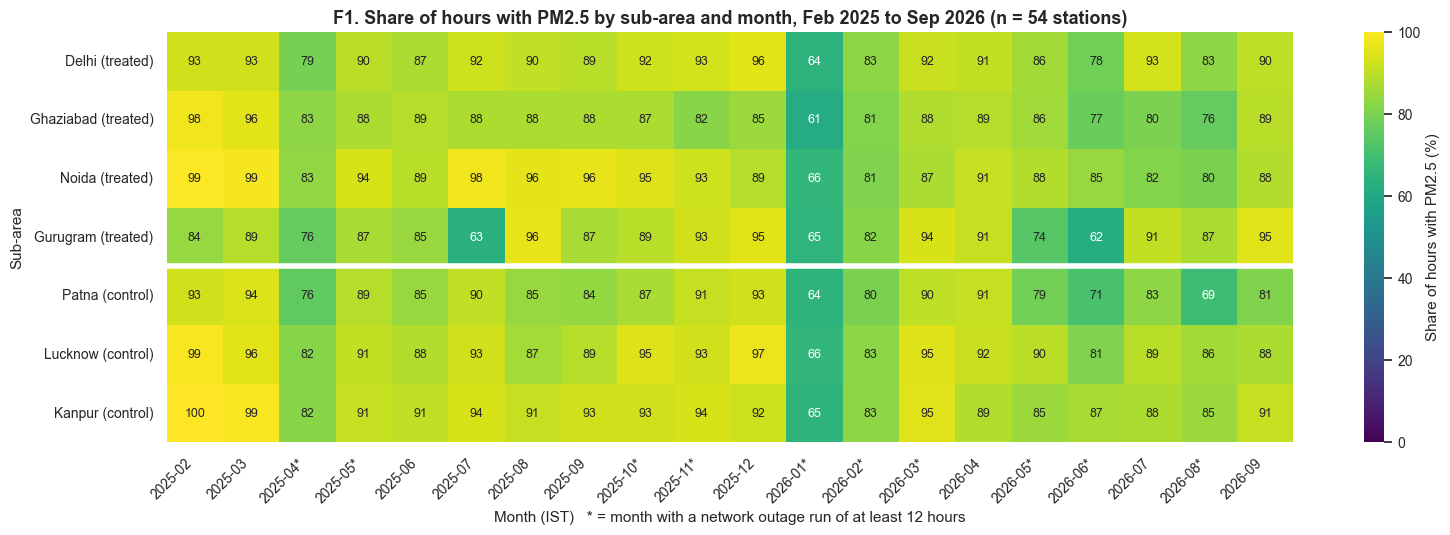

In [71]:
# Step 6.1b: F1 heatmap by sub-area (percentage written in every cell)
fig, ax = plt.subplots(figsize=(16, 5.5))
sns.heatmap(avail_area, ax=ax, cmap="viridis", vmin=0, vmax=100, annot=True, fmt=".0f", annot_kws={"size": 9},
            cbar_kws={"label": "Share of hours with PM2.5 (%)"}, xticklabels=month_labels,
            yticklabels=[f"{a} ({'treated' if a in area_order[:4] else 'control'})" for a in area_order])
ax.axhline(4, color="white", lw=4)                                  # boundary between treated and control sub-areas
ax.set_xlabel("Month (IST)   * = month with a network outage run of at least 12 hours")
ax.set_ylabel("Sub-area")
ax.set_title(f"F1. Share of hours with PM2.5 by sub-area and month, Feb 2025 to Sep 2026 (n = {n_stations} stations)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
save_fig(fig, "F1_pm25_availability_by_sub_area"); plt.show()

saved figure: F1b_pm25_availability_by_station


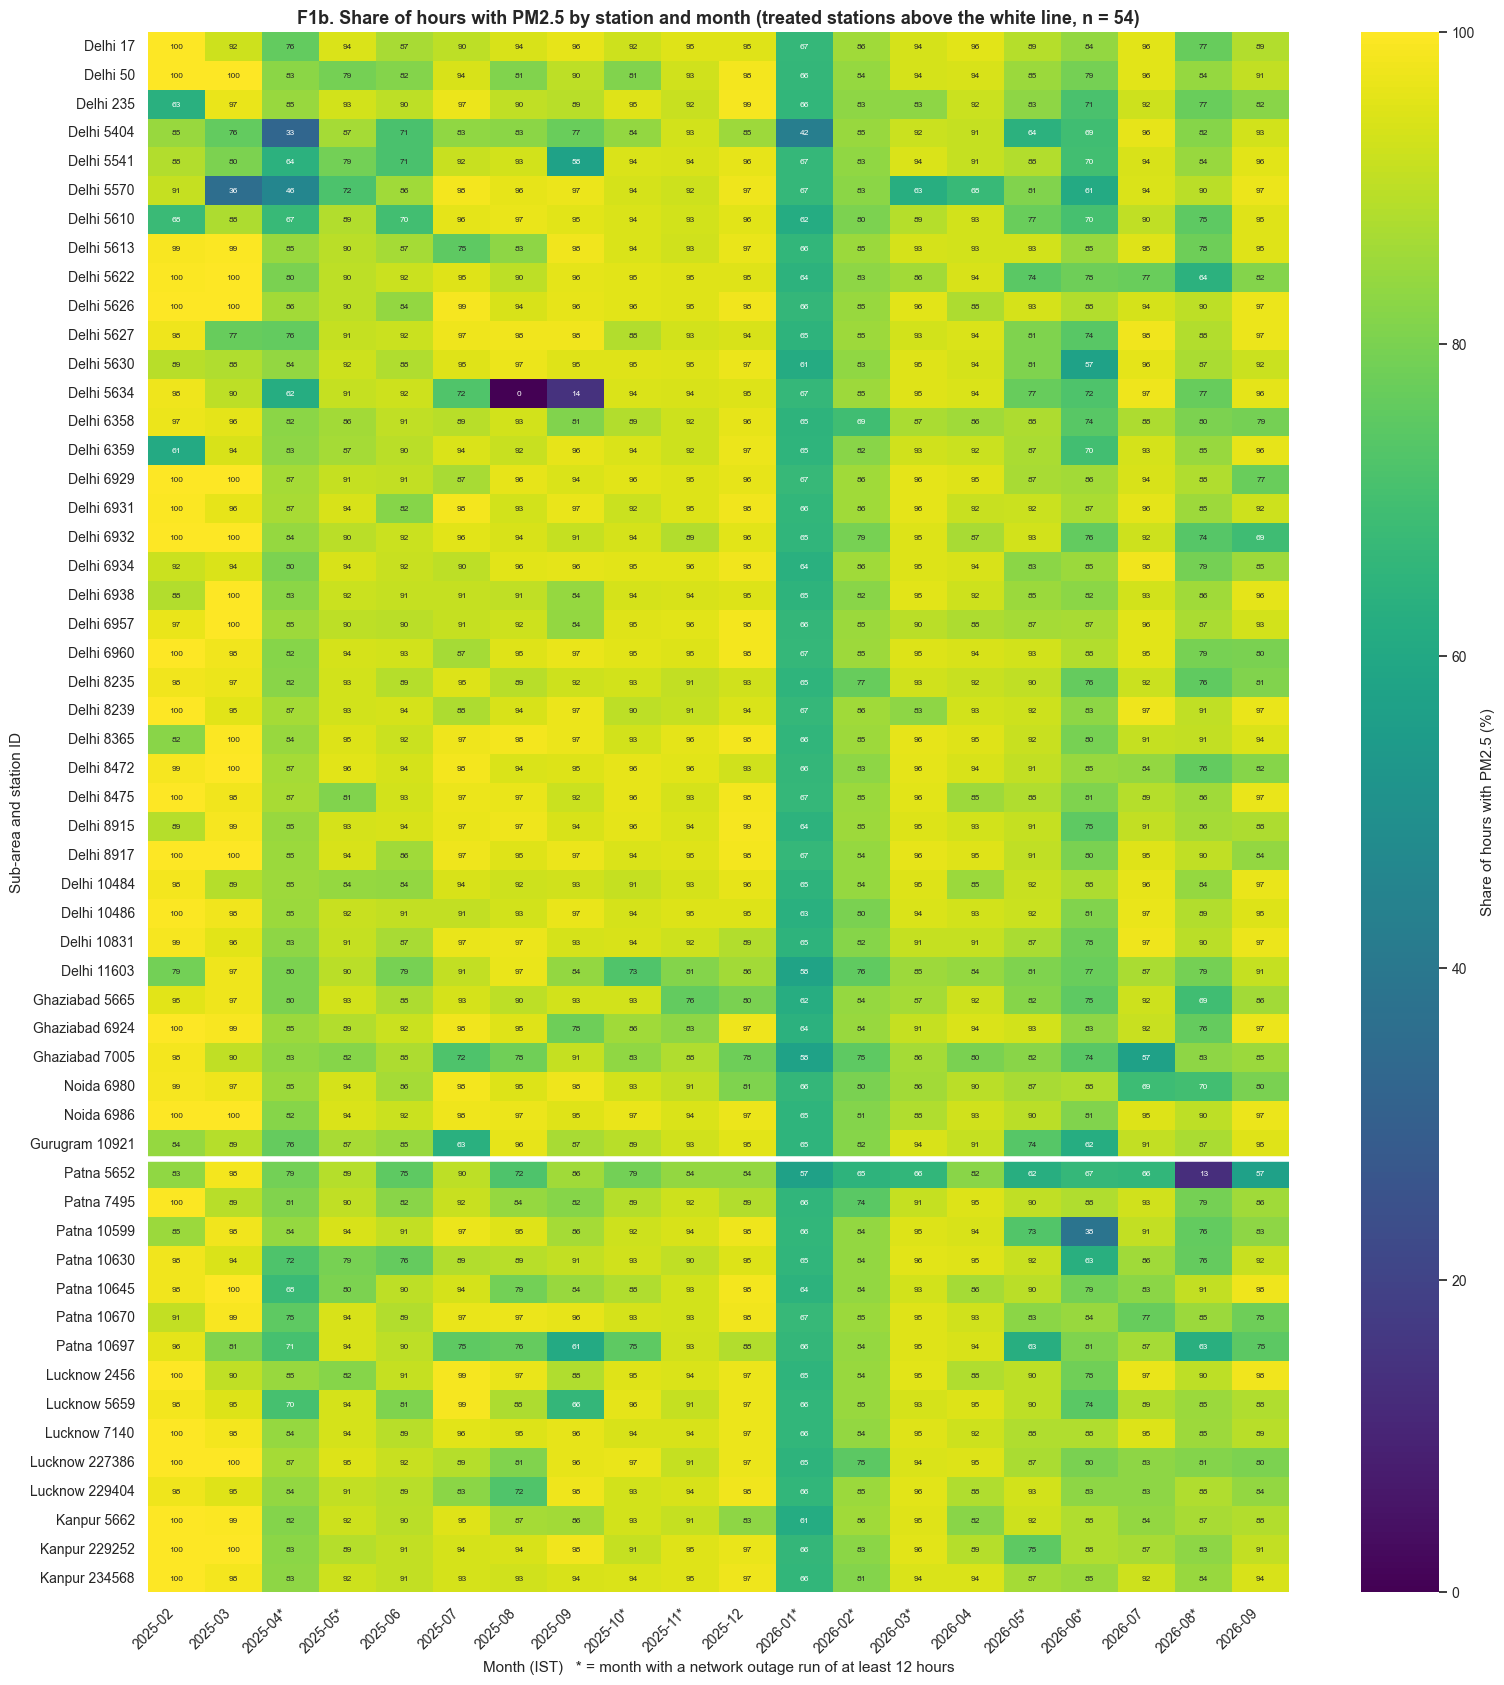

In [72]:
# Step 6.1c: F1 second version: one row per station (small font), treated above control
station_order = (df.drop_duplicates("station_id").assign(rank=lambda d: d["sub_area"].map({a: i for i, a in enumerate(area_order)}))
                   .sort_values(["rank", "station_id"])["station_id"].tolist())
avail_station = df.pivot_table(index="station_id", columns="month_label", values="has_pm25", aggfunc="mean").loc[station_order] * 100
area_of = df.drop_duplicates("station_id").set_index("station_id")["sub_area"]
fig, ax = plt.subplots(figsize=(16, 17))
sns.heatmap(avail_station, ax=ax, cmap="viridis", vmin=0, vmax=100, annot=True, fmt=".0f", annot_kws={"size": 6},
            cbar_kws={"label": "Share of hours with PM2.5 (%)"}, xticklabels=month_labels,
            yticklabels=[f"{area_of[s]} {s}" for s in avail_station.index])
ax.axhline(int((area_of[station_order].isin(area_order[:4])).sum()), color="white", lw=4)
ax.set_xlabel("Month (IST)   * = month with a network outage run of at least 12 hours"); ax.set_ylabel("Sub-area and station ID")
ax.set_title(f"F1b. Share of hours with PM2.5 by station and month (treated stations above the white line, n = {n_stations})")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
save_fig(fig, "F1b_pm25_availability_by_station"); plt.show()

In [73]:
# Step 6.1d: takeaway text
low_area, low_month = avail_area.stack().idxmin()
treated_share = df.loc[df["group"] == "treated", "has_pm25"].mean() * 100
control_share = df.loc[df["group"] == "control", "has_pm25"].mean() * 100
station_low = avail_station.mean(axis=1).sort_values().head(3)
show_takeaway(
    f"**What we learn:** PM2.5 is present in **{treated_share:.0f}%** of treated and **{control_share:.0f}%** of control station-hours. The weakest sub-area-month is "
    f"**{low_area} in {low_month}** (**{avail_area.loc[low_area, low_month]:.0f}%**). The three stations with the lowest overall coverage "
    f"(IDs **{', '.join(str(s) for s in station_low.index)}**) report only **{station_low.iloc[0]:.0f}%** to **{station_low.iloc[-1]:.0f}%** of hours."
)

**What we learn:** PM2.5 is present in **87%** of treated and **86%** of control station-hours. The weakest sub-area-month is **Ghaziabad in 2026-01** (**61%**). The three stations with the lowest overall coverage (IDs **5652, 5634, 5404**) report only **73%** to **79%** of hours.

*F1. Share of hours with PM2.5 by sub-area and month, Feb 2025 to Sep 2026 (IST); percentage written in every cell. n = 54 stations (39 treated, 15 control). Source: `final_dataset.parquet`.*

*F1b. The same by station and month (treated stations above the white line, control below), with the sub-area and station ID on the vertical axis. n = 54 stations. Source: `final_dataset.parquet`.*

**What it shows.** Each cell is the percentage of hours with a PM2.5 value for one sub-area (or station) in one month. Dark cells are gaps. Treated sub-areas are above the white line, control below. A * on a month marks a network-wide outage run of at least 12 hours.

**What it does not show.** It shows *presence* of data, not quality. A month can be 100% present and still contain suspect values (Phase 3 shows how few were removed). The sub-area view averages over stations, so a single missing station is hidden there but visible in the station view.

## 6.2 Figure F2: Where are the stations?

**Question:** where are the monitors, and how far apart are the treated and control cities?
**Sample:** the 54 stations. **Note:** no basemap; longitude and latitude in degrees. The dashed circle is 25 km around central Delhi.

In [74]:
# Step 6.2a: station positions and the label for each sub-area (centre of its stations and the number of stations)
stations_xy = df.drop_duplicates("station_id")[["station_id", "sub_area", "group", "latitude", "longitude"]]
area_centres = stations_xy.groupby("sub_area").agg(lon=("longitude", "mean"), lat=("latitude", "mean"), n=("station_id", "size"), group=("group", "first"))

# Distance from central Delhi to each sub-area centre (great-circle, km)
lat0, lon0 = 28.6139, 77.2090
dlat, dlon = np.radians(area_centres["lat"] - lat0), np.radians(area_centres["lon"] - lon0)
haversine = np.sin(dlat / 2) ** 2 + np.cos(np.radians(lat0)) * np.cos(np.radians(area_centres["lat"])) * np.sin(dlon / 2) ** 2
area_centres["km_from_central_delhi"] = (6371 * 2 * np.arcsin(np.sqrt(haversine))).round(0)
display(area_centres.loc[area_order])

,lon,lat,n,group,km_from_central_delhi
sub_area,,,,,
Delhi,77.191696,28.641582,33,treated,4.0
Ghaziabad,77.331374,28.687954,3,treated,15.0
Noida,77.387812,28.573151,2,treated,18.0
Gurugram,77.148944,28.422681,1,treated,22.0
Patna,85.142988,25.612322,7,control,853.0
Lucknow,80.949300,26.844332,5,control,417.0
Kanpur,80.299888,26.469517,3,control,387.0


saved figure: F2_station_map


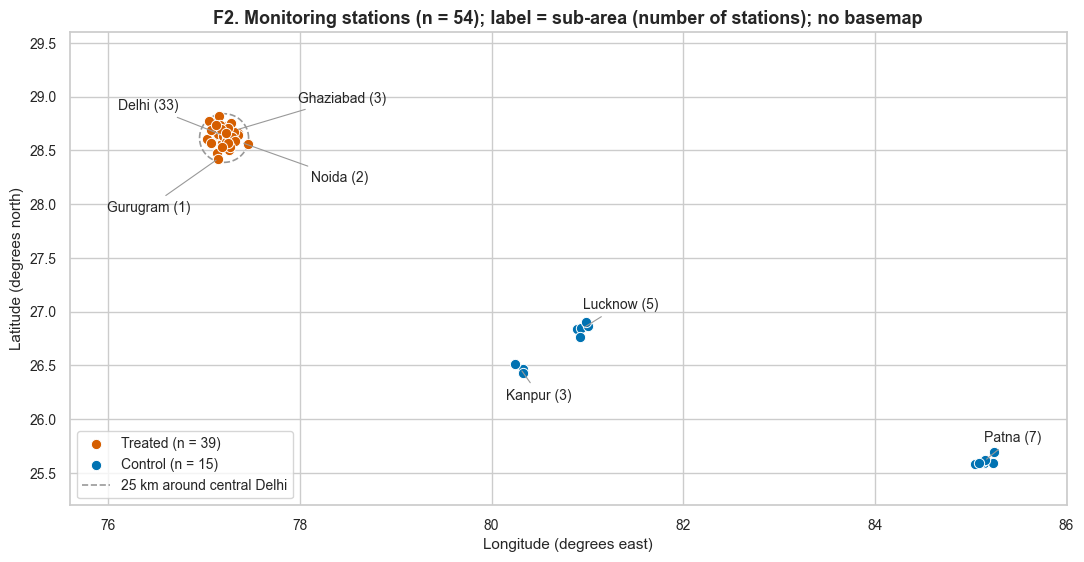

In [75]:
# Step 6.2b: F2 station map
label_offsets = {"Delhi": (-75, 18), "Ghaziabad": (45, 20), "Noida": (50, -28), "Gurugram": (-80, -38),
                 "Patna": (0, 14), "Lucknow": (0, 14), "Kanpur": (-10, -22)}      # label positions in points, to avoid overlaps
fig, ax = plt.subplots(figsize=(11, 6.5))
for g in ["treated", "control"]:
    sub = stations_xy[stations_xy["group"] == g]
    ax.scatter(sub["longitude"], sub["latitude"], s=55, c=COL[g], edgecolor="white", lw=0.7, label=f"{g.capitalize()} (n = {len(sub)})", zorder=3)
theta = np.linspace(0, 2 * np.pi, 200)
ax.plot(lon0 + 25 / (111.32 * np.cos(np.radians(lat0))) * np.cos(theta), lat0 + 25 / 110.57 * np.sin(theta), color=GREY, ls="--", lw=1.2, label="25 km around central Delhi")
for area, row in area_centres.iterrows():
    ax.annotate(f"{area} ({row['n']})", (row["lon"], row["lat"]), xytext=label_offsets[area], textcoords="offset points", fontsize=10,
                arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
ax.set_aspect(1 / np.cos(np.radians(27)))                          # so that distances look right at this latitude
ax.set_xlim(75.6, 86.0); ax.set_ylim(25.2, 29.6)                  # room for the labels inside the frame
ax.set_xlabel("Longitude (degrees east)"); ax.set_ylabel("Latitude (degrees north)")
ax.set_title(f"F2. Monitoring stations (n = {n_stations}); label = sub-area (number of stations); no basemap")
ax.legend(loc="lower left"); plt.tight_layout()
save_fig(fig, "F2_station_map"); plt.show()

In [76]:
# Step 6.2c: takeaway text
control_areas = area_centres[area_centres["group"] == "control"]
show_takeaway(
    f"**What we learn:** the control cities lie **{control_areas['km_from_central_delhi'].min():.0f}** to **{control_areas['km_from_central_delhi'].max():.0f} km** from central Delhi "
    f"(Kanpur, Lucknow and Patna are all to the south-east). The treated stations are packed within about "
    f"**{area_centres.loc[['Delhi', 'Ghaziabad', 'Noida', 'Gurugram'], 'km_from_central_delhi'].max():.0f} km** of the centre, with **{area_centres.loc['Delhi', 'n']}** of "
    f"**{stations_per_group['treated']}** in Delhi itself."
)

**What we learn:** the control cities lie **387** to **853 km** from central Delhi (Kanpur, Lucknow and Patna are all to the south-east). The treated stations are packed within about **22 km** of the centre, with **33** of **39** in Delhi itself.

*F2. Monitoring stations, coloured by group, with the number of stations per sub-area in brackets. Coordinates in degrees (no basemap); the dashed circle marks 25 km around central Delhi. n = 54 stations. Source: `final_dataset.parquet`.*

**What it shows.** The position of every station. Orange dots are treated stations (inside the NCR, where GRAP applies); blue dots are control stations in three other cities.

**What it does not show.** The map says nothing about pollution levels, and the controls are hundreds of kilometres away: their weather, fire exposure and local rules differ from Delhi's, so they are a comparison, not a copy of Delhi without GRAP. Sub-areas inside the NCR overlap on the map because they lie close together.

## 6.3 Figure F3: PM2.5 and GRAP stage through time

**Question:** how did daily PM2.5 move at treated and control stations, and when was each GRAP stage in force?
**Sample:** group-day series from Phase 4. **Top panel:** daily mean PM2.5 with a 95% band over stations. **Bottom strip:** the GRAP stage at treated stations. **Grey bands:** network outages. **Look for:** when treated and control move together, and what happens around the stage changes.

In [77]:
# Step 6.3a: the daily series for the two groups on the full date grid (so that missing days stay gaps, never zero)
date_grid = pd.date_range(df["date_ist"].min(), df["date_ist"].max(), freq="D")
series = {g: analysis_group_day[analysis_group_day["group"] == g].set_index("date_ist").reindex(date_grid) for g in ["treated", "control"]}
peaks = pd.DataFrame({g: {"Peak PM2.5 (ug/m3)": series[g]["pm25"].max(), "Peak date": series[g]["pm25"].idxmax().strftime("%d %b %Y"),
                          "Days with a value": int(series[g]["pm25"].notna().sum())} for g in series}).T
display(peaks)

# GRAP stage as constant segments (to write the stage number in the strip)
segment = (stage_hourly["stage"].diff() != 0).cumsum()
stage_segments = stage_hourly.groupby(segment).agg(stage=("stage", "first"), start=("hour_ist", "min"), end=("hour_ist", "max"))
stage_segments["days"] = (stage_segments["end"] - stage_segments["start"]).dt.total_seconds() / 86400
long_segments = stage_segments[stage_segments["days"] >= 7]               # only long segments get a stage number in the strip
print("Stage segments:", len(stage_segments), "| segments of at least 7 days:", len(long_segments))
from matplotlib.patches import Patch                                   # used by the legend of the figure below
from matplotlib.lines import Line2D

,Peak PM2.5 (ug/m3),Peak date,Days with a value
treated,381.352487,14 Dec 2025,542
control,138.749418,21 Oct 2025,544


Stage segments: 31 | segments of at least 7 days: 20


saved figure: F3_pm25_and_grap_timeline


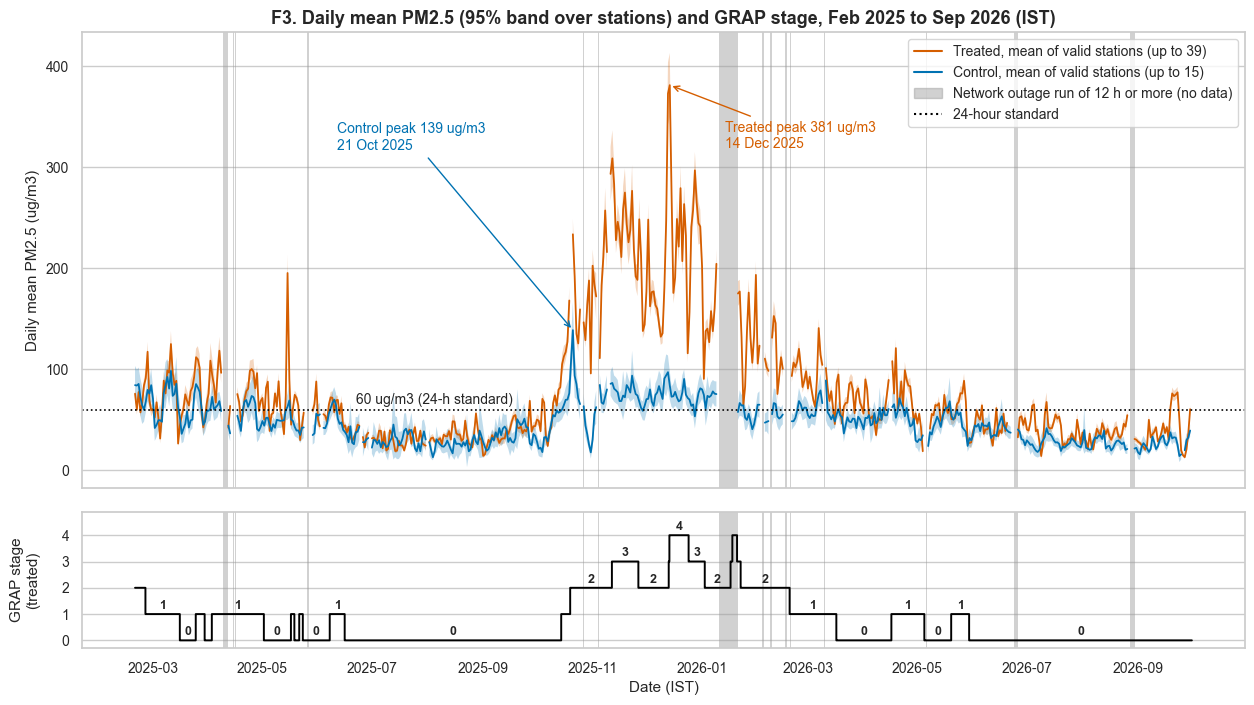

In [78]:
# Step 6.3b: F3 top panel (daily PM2.5, band, 60 ug/m3 line, peaks) and bottom strip (GRAP stage)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True, gridspec_kw={"height_ratios": [4, 1.2], "hspace": 0.08})
for g in ["treated", "control"]:
    s = series[g]
    ax.fill_between(s.index, s["ci_low"], s["ci_high"], color=COL[g], alpha=0.25, lw=0)
    ax.plot(s.index, s["pm25"], color=COL[g], lw=1.3)
for start, end in zip(long_runs["start"], long_runs["end"]):              # long outage runs (grey), on both panels
    for a in (ax, ax2):
        a.axvspan(start, end + pd.Timedelta("1h"), color=GREY, alpha=0.45, lw=0)
ax.axhline(STANDARD, color="black", ls=":", lw=1.2)
ax.text(pd.Timestamp("2025-06-22"), STANDARD + 6, "60 ug/m3 (24-h standard)", fontsize=10)
for g, (dy, dx) in {"treated": (-45, 40), "control": (130, -170)}.items():     # annotate each group's peak
    day, value = series[g]["pm25"].idxmax(), series[g]["pm25"].max()
    ax.annotate(f"{g.capitalize()} peak {value:.0f} ug/m3\n{day:%d %b %Y}", (day, value), xytext=(dx, dy), textcoords="offset points",
                fontsize=10, color=COL[g], arrowprops=dict(arrowstyle="->", color=COL[g]))
ax.set(ylabel="Daily mean PM2.5 (ug/m3)", title="F3. Daily mean PM2.5 (95% band over stations) and GRAP stage, Feb 2025 to Sep 2026 (IST)")
ax.legend(handles=[Line2D([], [], color=COL["treated"], label=f"Treated, mean of valid stations (up to {stations_per_group['treated']})"),
                   Line2D([], [], color=COL["control"], label=f"Control, mean of valid stations (up to {stations_per_group['control']})"),
                   Patch(color=GREY, alpha=0.45, label="Network outage run of 12 h or more (no data)"), Line2D([], [], color="black", ls=":", label="24-hour standard")], loc="upper right")
ax2.step(stage_hourly["hour_ist"], stage_hourly["stage"], where="post", color="black", lw=1.4)
for _, seg in long_segments.iterrows():                                      # write the stage number on long segments
    ax2.text(seg["start"] + (seg["end"] - seg["start"]) / 2, seg["stage"] + 0.2, f"{int(seg['stage'])}", ha="center", fontsize=9, fontweight="bold")
ax2.set_ylim(-0.3, 4.9); ax2.set_yticks(range(5)); ax2.set_ylabel("GRAP stage\n(treated)"); ax2.set_xlabel("Date (IST)")
ax.grid(axis="x", visible=False); ax2.grid(axis="x", visible=False)
fig.align_ylabels([ax, ax2]); save_fig(fig, "F3_pm25_and_grap_timeline"); plt.show()

In [79]:
# Step 6.3c: takeaway text: co-movement of the two groups, and the share of the winter at Stage III/IV
both = pd.concat([series["treated"]["pm25"], series["control"]["pm25"]], axis=1, keys=["treated", "control"]).dropna()
r_groups = both["treated"].corr(both["control"])
t_peak_day = series["treated"]["pm25"].idxmax()
show_takeaway(
    f"**What we learn:** the treated series peaks at **{series['treated']['pm25'].max():.0f} ug/m3** on **{t_peak_day:%d %b %Y}** and the control series at "
    f"**{series['control']['pm25'].max():.0f} ug/m3** on **{series['control']['pm25'].idxmax():%d %b %Y}**. On the **{len(both)}** days with both series, their daily means have "
    f"a correlation of **{r_groups:.2f}**. Stage III or IV (the strictest stages) were reached only between **{months_with_hi.min()}** and **{months_with_hi.max()}**, "
    f"when treated PM2.5 was highest."
)

**What we learn:** the treated series peaks at **381 ug/m3** on **14 Dec 2025** and the control series at **139 ug/m3** on **21 Oct 2025**. On the **541** days with both series, their daily means have a correlation of **0.71**. Stage III or IV (the strictest stages) were reached only between **2025-11** and **2026-01**, when treated PM2.5 was highest.

*F3. Daily mean PM2.5 (line) with its 95% band over stations for treated (orange) and control (blue) groups, and the GRAP stage at treated stations (strip below; numbers = stage). Grey bands = network outage hours. Daily values need at least 18 valid hours per station and at least half of the group's stations. Dotted line: 60 ug/m3. Feb 2025 to Sep 2026 (IST). Source: `final_dataset.parquet` via the group-day table.*

**What it shows.** The two daily pollution series on one time axis, with the policy stage underneath. Gaps in a line are days without enough data.

**What it does not show.** The stage rises **because** pollution is high, so the picture cannot show that GRAP lowered or raised PM2.5. The band measures spread between stations, not measurement error. The two groups are different cities with different weather; their gap is not an effect of GRAP.

## 6.4 Figure F4: Seasonal profile

**Question:** how does PM2.5 change from month to month, and how wide is the spread across stations and days?
**Sample:** valid station-days. **Bars:** monthly median; **whiskers:** the interquartile range (IQR: the middle 50% of station-days, from the 25th to the 75th percentile). **Under each month:** the number of stations (treated / control).

In [80]:
# Step 6.4a: monthly median, IQR and number of stations per group (prepare the numbers)
sd_month = analysis_station_day.assign(month_label=analysis_station_day["date_ist"].dt.strftime("%Y-%m"))
monthly = (sd_month.groupby(["month_label", "group"])["pm25_day"]
           .agg(median="median", q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75)).reset_index())
station_counts = sd_month.groupby(["month_label", "group"])["station_id"].nunique().rename("stations").reset_index()
monthly = monthly.merge(station_counts, on=["month_label", "group"])
month_list = sorted(monthly["month_label"].unique())
wide = monthly.pivot(index="month_label", columns="group")
display(wide[["median", "stations"]].round(0).astype(int).head(6))

median         stations        
group       control treated  control treated
month_label                                 
2025-02          69      72       15      39
2025-03          57      67       15      39
2025-04          58      73       15      39
2025-05          44      62       15      39
2025-06          39      45       15      39
2025-07          24      28       15      39

saved figure: F4_seasonal_profile


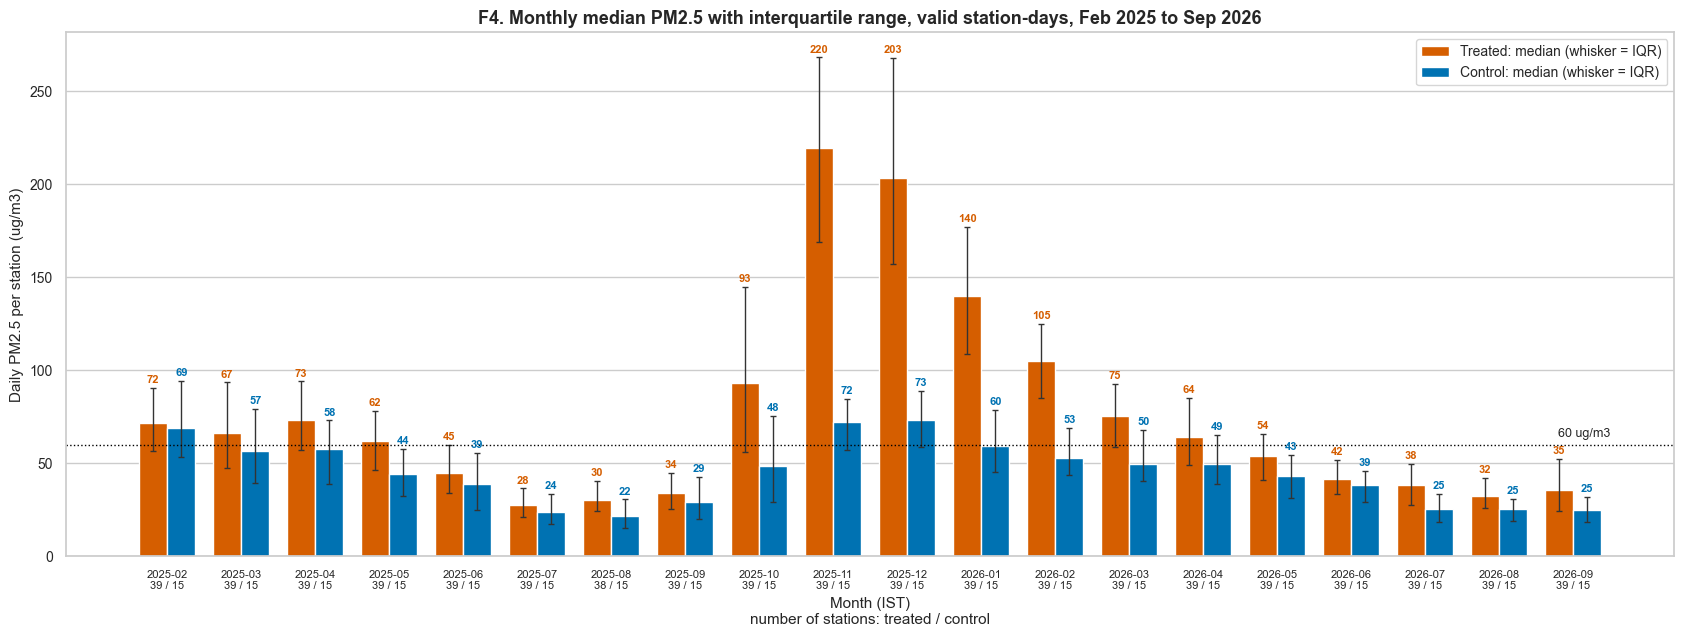

In [81]:
# Step 6.4b: F4 grouped bars with IQR whiskers; the median is written above each bar
fig, ax = plt.subplots(figsize=(17, 6.5))
x = np.arange(len(month_list)); width = 0.38
for offset, g in [(-width / 2, "treated"), (width / 2, "control")]:
    d = monthly[monthly["group"] == g].set_index("month_label").loc[month_list]
    ax.bar(x + offset, d["median"], width, color=COL[g], label=f"{g.capitalize()}: median (whisker = IQR)",
           yerr=[(d["median"] - d["q1"]).to_numpy(), (d["q3"] - d["median"]).to_numpy()], error_kw={"ecolor": "#333333", "capsize": 2, "lw": 1})
    for xi, med, top in zip(x + offset, d["median"], d["q3"]):
        ax.annotate(f"{med:.0f}", (xi, top), ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points", color=COL[g], fontweight="bold")
ax.axhline(STANDARD, color="black", ls=":", lw=1); ax.text(len(month_list) - 0.5, STANDARD + 4, "60 ug/m3", ha="right", fontsize=9)
ticks = [f"{m}\n{wide.loc[m, ('stations', 'treated')]:.0f} / {wide.loc[m, ('stations', 'control')]:.0f}" for m in month_list]
ax.set_xticks(x); ax.set_xticklabels(ticks, fontsize=8)
ax.set_xlabel("Month (IST)\nnumber of stations: treated / control"); ax.set_ylabel("Daily PM2.5 per station (ug/m3)")
ax.set_title("F4. Monthly median PM2.5 with interquartile range, valid station-days, Feb 2025 to Sep 2026"); ax.legend(loc="upper right")
ax.grid(axis="x", visible=False); plt.tight_layout(); save_fig(fig, "F4_seasonal_profile"); plt.show()

In [82]:
# Step 6.4c: takeaway text
med = monthly.pivot(index="month_label", columns="group")["median"]
iqr = (monthly.pivot(index="month_label", columns="group")["q3"] - monthly.pivot(index="month_label", columns="group")["q1"])
show_takeaway(
    f"**What we learn:** the treated median ranges from **{med['treated'].min():.0f}** (in **{med['treated'].idxmin()}**) to **{med['treated'].max():.0f} ug/m3** (in **{med['treated'].idxmax()}**); "
    f"the control median from **{med['control'].min():.0f}** to **{med['control'].max():.0f} ug/m3**. The spread between stations is widest in the treated group in "
    f"**{iqr['treated'].idxmax()}** (IQR **{iqr['treated'].max():.0f} ug/m3**); the month with the highest treated median is **{med['treated'].idxmax()}**."
)

**What we learn:** the treated median ranges from **28** (in **2025-07**) to **220 ug/m3** (in **2025-11**); the control median from **22** to **73 ug/m3**. The spread between stations is widest in the treated group in **2025-12** (IQR **111 ug/m3**); the month with the highest treated median is **2025-11**.

*F4. Monthly median of daily PM2.5 (bars) and interquartile range (whiskers) for treated (orange) and control (blue) stations; the number above each bar is the median; the number of stations contributing is under each month. Valid station-days only, Feb 2025 to Sep 2026 (IST). Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** PM2.5 is highest in the autumn and winter months and lowest in the monsoon, and the treated stations swing much more than the control stations.

**What it does not show.** Feb to Sep each appear twice but Oct to Jan only once, so a "winter" pattern is a single winter. The IQR describes variation across stations *and* days within a month, so it mixes place and time. Months with a long outage (marked in F1) have fewer days behind them.

## 6.5 Figure F5: Diurnal profile (time of day)

**Question:** how does PM2.5 change through the day, and does that pattern differ between winter and monsoon?
**Sample:** valid hours. **Method:** for each station the mean PM2.5 at each hour of the day is computed first; the line is the mean of those station means and the band is the 95% confidence interval (CI) **over stations** (neighbouring hours are not independent, so we do not use hours as the unit).

In [83]:
# Step 6.5a: station-level mean by hour of day (winter vs monsoon), then mean and 95% CI over stations
profile_source = df[df["valid_hour"] & df["season"].isin(["winter", "monsoon"])]
station_hour = profile_source.groupby(["group", "season", "station_id", "hour"])["pm25"].mean().reset_index()
profile = (station_hour.groupby(["group", "season", "hour"])["pm25"].agg(mean="mean", sd="std", n="count").reset_index())
profile["ci"] = 1.96 * profile["sd"] / np.sqrt(profile["n"])
extremes = profile.loc[profile.groupby(["group", "season"])["mean"].idxmax()][["group", "season", "hour", "mean"]].rename(columns={"hour": "peak hour", "mean": "peak"})
lows = profile.loc[profile.groupby(["group", "season"])["mean"].idxmin()][["group", "season", "hour", "mean"]].rename(columns={"hour": "low hour", "mean": "low"})
peak_low = extremes.merge(lows, on=["group", "season"]).round(1)
display(peak_low)

,group,season,peak hour,peak,low hour,low
0,control,monsoon,21,36.1,6,30.2
1,control,winter,21,83.8,15,49.9
2,treated,monsoon,21,44.6,15,34.0
3,treated,winter,21,193.1,15,106.0


saved figure: F5_diurnal_profile


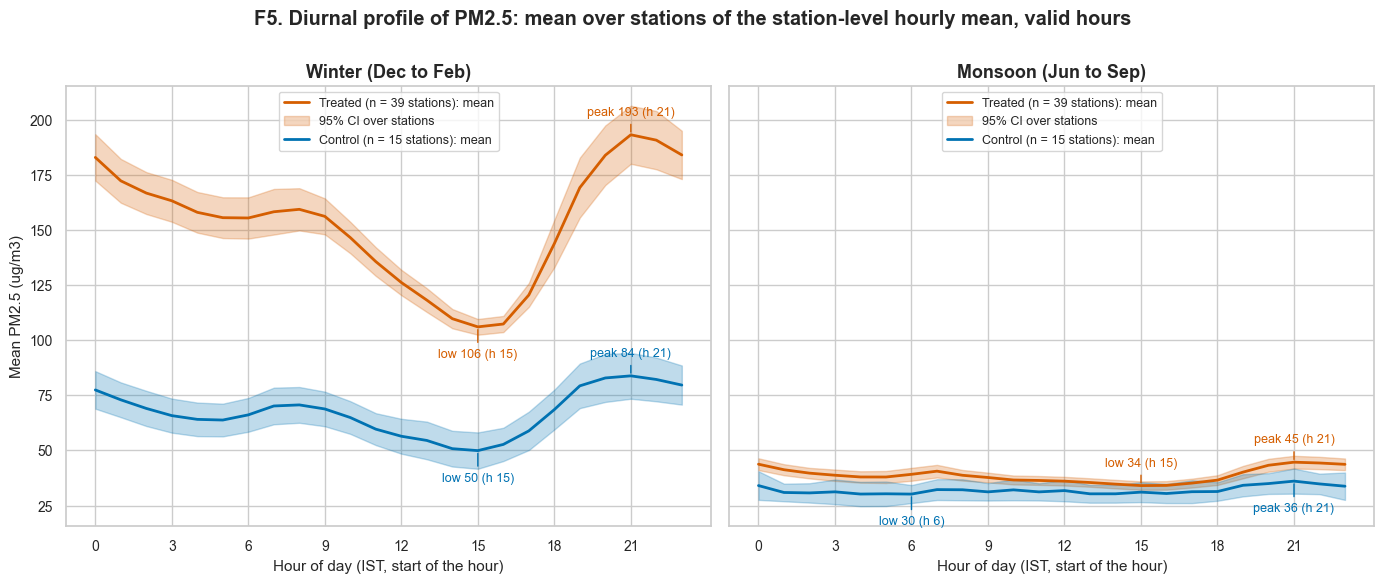

In [84]:
# Step 6.5b: F5 two panels (winter, monsoon), both groups, peak and lowest hours annotated
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), sharey=True)
for ax, season, title in zip(axes, ["winter", "monsoon"], ["Winter (Dec to Feb)", "Monsoon (Jun to Sep)"]):
    for g in ["treated", "control"]:
        d = profile[(profile["group"] == g) & (profile["season"] == season)]
        n_st = int(d["n"].max())
        ax.plot(d["hour"], d["mean"], color=COL[g], lw=2, label=f"{g.capitalize()} (n = {n_st} stations): mean")
        ax.fill_between(d["hour"], d["mean"] - d["ci"], d["mean"] + d["ci"], color=COL[g], alpha=0.25, label="95% CI over stations" if g == "treated" else None)
        for row, name in [(d.loc[d["mean"].idxmax()], "peak"), (d.loc[d["mean"].idxmin()], "low")]:
            ax.annotate(f"{name} {row['mean']:.0f} (h {int(row['hour'])})", (row["hour"], row["mean"]), xytext=(0, -22 if ((season == "monsoon" and g == "control") or (season == "winter" and name == "low")) else 14),
                        textcoords="offset points", ha="center", fontsize=9, color=COL[g], arrowprops=dict(arrowstyle="-", color=COL[g]))
    ax.set_title(title); ax.set_xlabel("Hour of day (IST, start of the hour)"); ax.set_xticks(range(0, 24, 3)); ax.legend(loc="upper center", fontsize=9)
axes[0].set_ylabel("Mean PM2.5 (ug/m3)")
fig.suptitle("F5. Diurnal profile of PM2.5: mean over stations of the station-level hourly mean, valid hours", fontweight="bold", y=1.0)
plt.tight_layout(); save_fig(fig, "F5_diurnal_profile"); plt.show()

In [85]:
# Step 6.5c: takeaway text
w = peak_low[(peak_low["season"] == "winter") & (peak_low["group"] == "treated")].iloc[0]
m = peak_low[(peak_low["season"] == "monsoon") & (peak_low["group"] == "treated")].iloc[0]
show_takeaway(
    f"**What we learn:** at treated stations the winter mean peaks at **{w['peak']:.0f} ug/m3** around **hour {int(w['peak hour'])}** and is lowest "
    f"(**{w['low']:.0f} ug/m3**) around **hour {int(w['low hour'])}**, a ratio of **{w['peak'] / w['low']:.1f}**. In the monsoon the range is only "
    f"**{m['low']:.0f}** to **{m['peak']:.0f} ug/m3** (ratio **{m['peak'] / m['low']:.1f}**)."
)

**What we learn:** at treated stations the winter mean peaks at **193 ug/m3** around **hour 21** and is lowest (**106 ug/m3**) around **hour 15**, a ratio of **1.8**. In the monsoon the range is only **34** to **45 ug/m3** (ratio **1.3**).

*F5. Mean PM2.5 by hour of day in winter (left) and monsoon (right) for treated (orange) and control (blue) stations; band = 95% confidence interval over stations; labels give the peak and lowest hour. Hours are IST (start of the hour). Valid hours only (outages excluded). Source: `final_dataset.parquet`.*

**What it shows.** The daily rhythm of PM2.5: where it peaks and where it is lowest in each season and group.

**What it does not show.** The profile is an average over many days, so it hides day-to-day differences. The interval is over stations only (it does not include year-to-year variation), and the winter profile comes from a single winter. Rhythms like this depend on traffic, the boundary layer and burning, which cannot be separated here.

## 6.6 Figure F6: Distribution of daily PM2.5

**Question:** how often does daily PM2.5 exceed the 60 ug/m3 24-hour standard, and how heavy is the upper tail?
**Sample:** valid station-days. **Method:** the *empirical cumulative distribution function (ECDF)* shows, for each value on the horizontal axis, the share of station-days at or below it. The axis is logarithmic so that both the clean and the polluted days are readable. *We use daily values (not hourly) because the 60 ug/m3 standard applies to a 24-hour mean.*

In [86]:
# Step 6.6a: ECDF values and the shares at the standard (prepare the numbers)
ecdf = {}
for g in ["treated", "control"]:
    v = np.sort(analysis_station_day.loc[analysis_station_day["group"] == g, "pm25_day"].to_numpy())
    ecdf[g] = (v, np.arange(1, len(v) + 1) / len(v))
share_above = {g: (analysis_station_day.loc[analysis_station_day["group"] == g, "pm25_day"] > STANDARD).mean() * 100 for g in ecdf}
medians = {g: float(np.median(ecdf[g][0])) for g in ecdf}

# The figure must agree with Table T05a of Phase 5
assert abs(share_above["treated"] - summary_group.loc["treated", "Days above 60 (%)"]) < 0.06
assert abs(medians["control"] - summary_group.loc["control", "Median"]) < 0.06
print({g: (round(share_above[g], 1), round(medians[g], 1), len(ecdf[g][0])) for g in ecdf})

{'treated': (np.float64(47.4), 57.1, 19379), 'control': (np.float64(28.7), 42.5, 7346)}


saved figure: F6_pm25_distribution


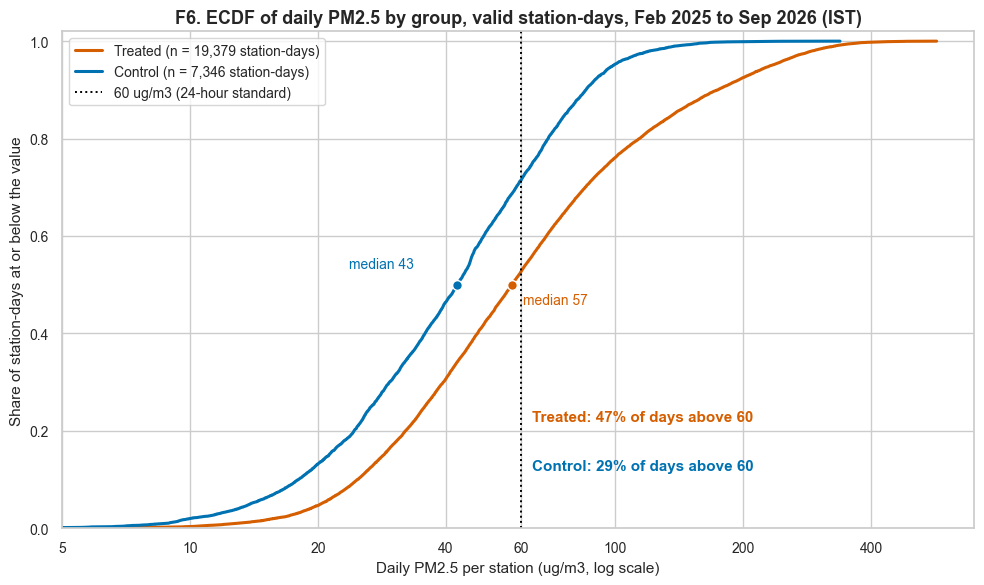

In [87]:
# Step 6.6b: F6 ECDF on a log axis with the 60 ug/m3 standard; shares and medians written on the plot
fig, ax = plt.subplots(figsize=(10, 6))
for g, y_text in [("treated", 0.22), ("control", 0.12)]:
    v, y = ecdf[g]
    ax.plot(v, y, color=COL[g], lw=2.2, label=f"{g.capitalize()} (n = {len(v):,} station-days)")
    ax.plot(medians[g], 0.5, "o", color=COL[g], ms=7, mec="white")
    ax.annotate(f"median {medians[g]:.0f}", (medians[g], 0.5), xytext=(8, -14) if g == "treated" else (-78, 12), textcoords="offset points", color=COL[g], fontsize=10)
    ax.text(STANDARD * 1.06, y_text, f"{g.capitalize()}: {share_above[g]:.0f}% of days above 60", color=COL[g], fontsize=11, fontweight="bold")
ax.axvline(STANDARD, color="black", ls=":", lw=1.4, label="60 ug/m3 (24-hour standard)")
ax.set_xscale("log"); ax.set_xlim(5, 700); ax.set_ylim(0, 1.02)
from matplotlib.ticker import ScalarFormatter
ax.set_xticks([5, 10, 20, 40, 60, 100, 200, 400]); ax.get_xaxis().set_major_formatter(ScalarFormatter()); ax.minorticks_off()
ax.set_xlabel("Daily PM2.5 per station (ug/m3, log scale)"); ax.set_ylabel("Share of station-days at or below the value")
ax.set_title("F6. ECDF of daily PM2.5 by group, valid station-days, Feb 2025 to Sep 2026 (IST)")
ax.legend(loc="upper left"); plt.tight_layout(); save_fig(fig, "F6_pm25_distribution"); plt.show()

In [88]:
# Step 6.6c: takeaway text
p95 = {g: float(np.quantile(ecdf[g][0], 0.95)) for g in ecdf}
show_takeaway(
    f"**What we learn:** **{share_above['treated']:.0f}%** of treated and **{share_above['control']:.0f}%** of control station-days are above the 60 ug/m3 standard. "
    f"The treated curve is shifted to the right and has a longer tail: its 95th percentile is **{p95['treated']:.0f} ug/m3**, against **{p95['control']:.0f} ug/m3** for the control group."
)

**What we learn:** **47%** of treated and **29%** of control station-days are above the 60 ug/m3 standard. The treated curve is shifted to the right and has a longer tail: its 95th percentile is **233 ug/m3**, against **99 ug/m3** for the control group.

*F6. Empirical cumulative distribution of daily PM2.5 (log axis) by group; dotted line = 60 ug/m3 24-hour standard; dots = medians; labels give the share of days above the standard. Valid station-days, Feb 2025 to Sep 2026 (IST). n shown in the legend. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** Read a curve from left to right: at any pollution level it gives the share of days at or below that level. The further a curve lies to the right, the more polluted the days.

**What it does not show.** The share above the standard counts station-days, not whole days of a city, and it mixes all seasons. It says nothing about how long polluted spells last. This figure uses daily means because the standard is a daily one; the plan's "share of hours" wording would compare hourly readings with a daily standard.

## 6.7 Figure F7: Fire detections through time

**Question:** when did the fires near the treated stations occur, and on which days do we have no satellite information?
**Variable:** fire detections within 100 km, all directions, averaged over the 39 treated stations. **Timing:** the dataset stores the *previous day's* detections on each date, so each value is plotted at the date on which the fires were **detected**. **Shaded:** the burning season, October and November. **Symbols:** days that are satellite outages (kept empty) and days assumed zero (cloud).

In [89]:
# Step 6.7a: daily fire detections for the treated stations, placed on the date of detection (not the date of use)
treated_rows = df[df["group"] == "treated"]
assert (treated_rows.groupby("date_ist")["fire_day_status"].nunique() == 1).all(), "status should be the same for all stations on a date"
fire_day = treated_rows.groupby("date_ist").agg(detections=("n_nh_100km_lag1", "mean"), status=("fire_day_status", "first")).reset_index()
fire_day["detection_date"] = fire_day["date_ist"] - pd.Timedelta(days=1)       # lag 1: the value on date d describes day d-1
fire_day = fire_day.dropna(subset=["detection_date"]).set_index("detection_date")

counts = fire_day["status"].value_counts().to_frame("days")
display(counts)
peak_fire_day, peak_fire = fire_day["detections"].idxmax(), fire_day["detections"].max()
print(f"Maximum: {peak_fire:.1f} detections on {peak_fire_day:%d %b %Y}")

,days
status,
observed,567
outage,14
zero_assumed,8


Maximum: 304.7 detections on 02 May 2026


saved figure: F7_fire_time_series


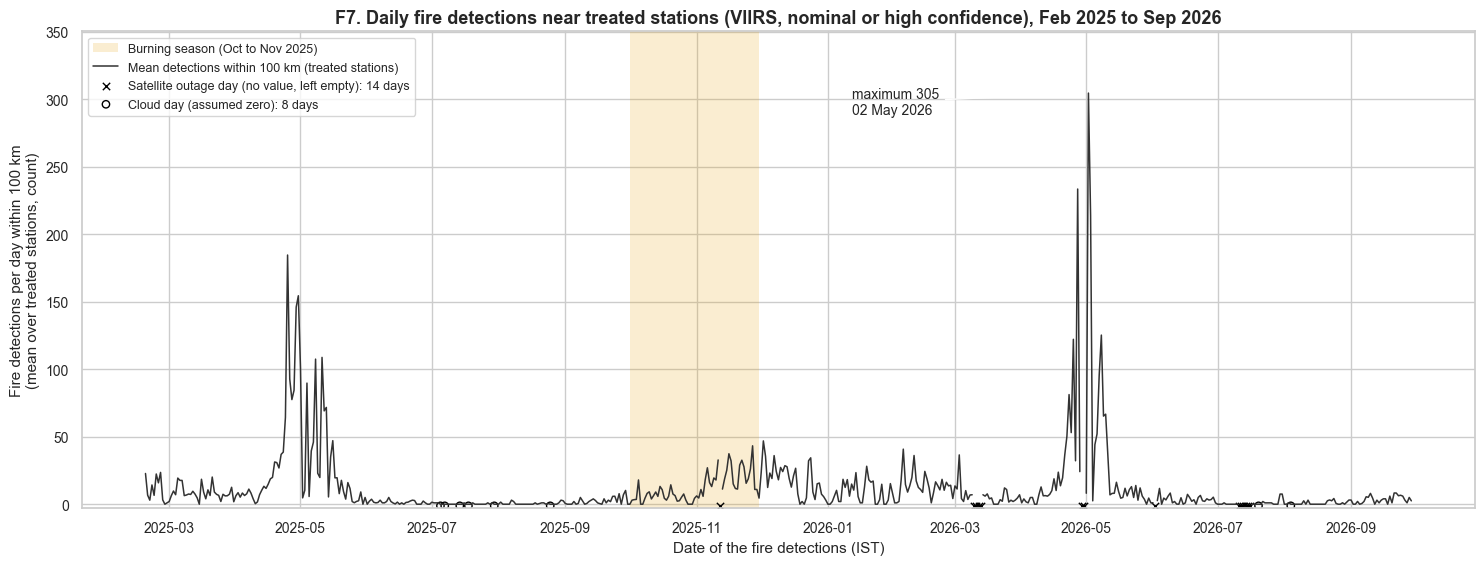

In [90]:
# Step 6.7b: F7 time series with burning-season shading and outage / assumed-zero markers
fig, ax = plt.subplots(figsize=(15, 5.8))
ax.axvspan(pd.Timestamp("2025-10-01"), pd.Timestamp("2025-11-30"), color="#E69F00", alpha=0.18, lw=0, label="Burning season (Oct to Nov 2025)")
ax.plot(fire_day.index, fire_day["detections"], color="#333333", lw=1.1, label="Mean detections within 100 km (treated stations)")
marker_style = {"outage": dict(marker="x", color="black", label="Satellite outage day (no value, left empty)"),
                "zero_assumed": dict(marker="o", facecolors="none", edgecolors="black", label="Cloud day (assumed zero)")}
for status, style in marker_style.items():
    days = fire_day[fire_day["status"] == status]
    style = {**style, "label": f"{style['label']}: {len(days)} days"}
    ax.scatter(days.index, np.full(len(days), -1.2), s=28, lw=1, **style)
ax.annotate(f"maximum {peak_fire:.0f}\n{peak_fire_day:%d %b %Y}", (peak_fire_day, peak_fire), xytext=(-170, -15), textcoords="offset points", fontsize=10, arrowprops=dict(arrowstyle="->"))
ax.set_ylim(-3, peak_fire * 1.15); ax.set_xlabel("Date of the fire detections (IST)")
ax.set_ylabel("Fire detections per day within 100 km\n(mean over treated stations, count)")
ax.set_title("F7. Daily fire detections near treated stations (VIIRS, nominal or high confidence), Feb 2025 to Sep 2026")
ax.legend(loc="upper left", fontsize=9); plt.tight_layout(); save_fig(fig, "F7_fire_time_series"); plt.show()

In [91]:
# Step 6.7c: takeaway text
fire_periods = {"Oct to Nov 2025": ("2025-10-01", "2025-11-30"), "Dec 2025 to Feb 2026": ("2025-12-01", "2026-02-28"),
              "Apr to May 2025": ("2025-04-01", "2025-05-31"), "Apr to May 2026": ("2026-04-01", "2026-05-31"), "Jun to Sep 2025": ("2025-06-01", "2025-09-30")}
period_means = {name: fire_day.loc[start:end, "detections"].mean() for name, (start, end) in fire_periods.items()}
spring = (period_means["Apr to May 2025"] + period_means["Apr to May 2026"]) / 2
higher = "higher" if spring > period_means["Oct to Nov 2025"] else "not higher"
show_takeaway(
    f"**What we learn:** the maximum is **{peak_fire:.0f}** detections per day within 100 km, on **{peak_fire_day:%d %b %Y}**. The mean is "
    f"**{period_means['Oct to Nov 2025']:.1f}** per day in Oct to Nov 2025 (the shaded season), **{period_means['Dec 2025 to Feb 2026']:.1f}** in Dec to Feb, "
    f"**{period_means['Apr to May 2025']:.1f}** and **{period_means['Apr to May 2026']:.1f}** in April to May of 2025 and 2026, and **{period_means['Jun to Sep 2025']:.1f}** in Jun to Sep 2025. "
    f"Counts within 100 km are therefore **{higher}** in spring than in the shaded autumn season. There are **{int((fire_day['status'] == 'outage').sum())}** outage days and "
    f"**{int((fire_day['status'] == 'zero_assumed').sum())}** assumed-zero cloud days."
)

**What we learn:** the maximum is **305** detections per day within 100 km, on **02 May 2026**. The mean is **12.0** per day in Oct to Nov 2025 (the shaded season), **13.6** in Dec to Feb, **33.5** and **33.2** in April to May of 2025 and 2026, and **1.1** in Jun to Sep 2025. Counts within 100 km are therefore **higher** in spring than in the shaded autumn season. There are **14** outage days and **8** assumed-zero cloud days.

*F7. Mean daily fire detections within 100 km of the treated stations (VIIRS, nominal or high confidence), plotted on the date of detection; the orange band marks Oct to Nov 2025, the autumn burning season used in the project plan; crosses = days the satellite data are missing; circles = cloud days set to zero. Feb 2025 to Sep 2026 (IST). Source: `final_dataset.parquet` (fire lag-1 columns).*

**What it shows.** Detections near the treated stations are low in the monsoon, moderate from October to February, and largest in April and May, with a very large spike in late April and early May 2026. It also marks the days on which satellite data are missing or assumed zero.

**What it does not show.** A detection is a satellite pixel, not an amount of smoke, and the satellite can miss fires under cloud or between passes. Only fires within **100 km** are counted, so fires further away, including in the neighbouring states where most autumn stubble burning happens, are not in this series (the dataset also has 200 km counts). The *upwind* count used for H1 keeps only fires on the side the wind came from, so it is smaller still. The peak fire counts do **not** coincide with the peak PM2.5 months (F4), which is something H1 has to explain, and only one autumn is in the data.

## 6.8 Figure F7b: Weather by month

**Question:** how do the main weather drivers of PM2.5 change over the year?
**Sample:** treated stations, valid station-days. **Panels:** monthly mean wind speed, temperature and boundary-layer height (the height of the lowest layer of air in which pollution mixes; low values mean poor dispersion).

In [92]:
# Step 6.8a: monthly means of three weather variables (treated stations, valid station-days)
weather_vars = {"wind_speed": "Wind speed (m/s)", "t2m_c": "Temperature (deg C)", "blh_m": "Boundary-layer height (m)"}
treated_days = analysis_station_day[analysis_station_day["group"] == "treated"].assign(month_label=lambda d: d["date_ist"].dt.strftime("%Y-%m"))
weather_month = treated_days.groupby("month_label")[list(weather_vars)].mean().round(1)
n_station_days = treated_days.groupby("month_label").size()
display(weather_month.head(6))
print("Station-days per month: from", n_station_days.min(), "to", n_station_days.max())

,wind_speed,t2m_c,blh_m
month_label,,,
2025-02,2.6,19.4,360.1
2025-03,3.0,23.0,505.5
2025-04,2.9,30.7,846.9
2025-05,2.9,31.8,784.0
2025-06,2.4,32.3,640.4
2025-07,2.3,29.9,443.4


Station-days per month: from 352 to 1151


saved figure: F7b_weather_by_month


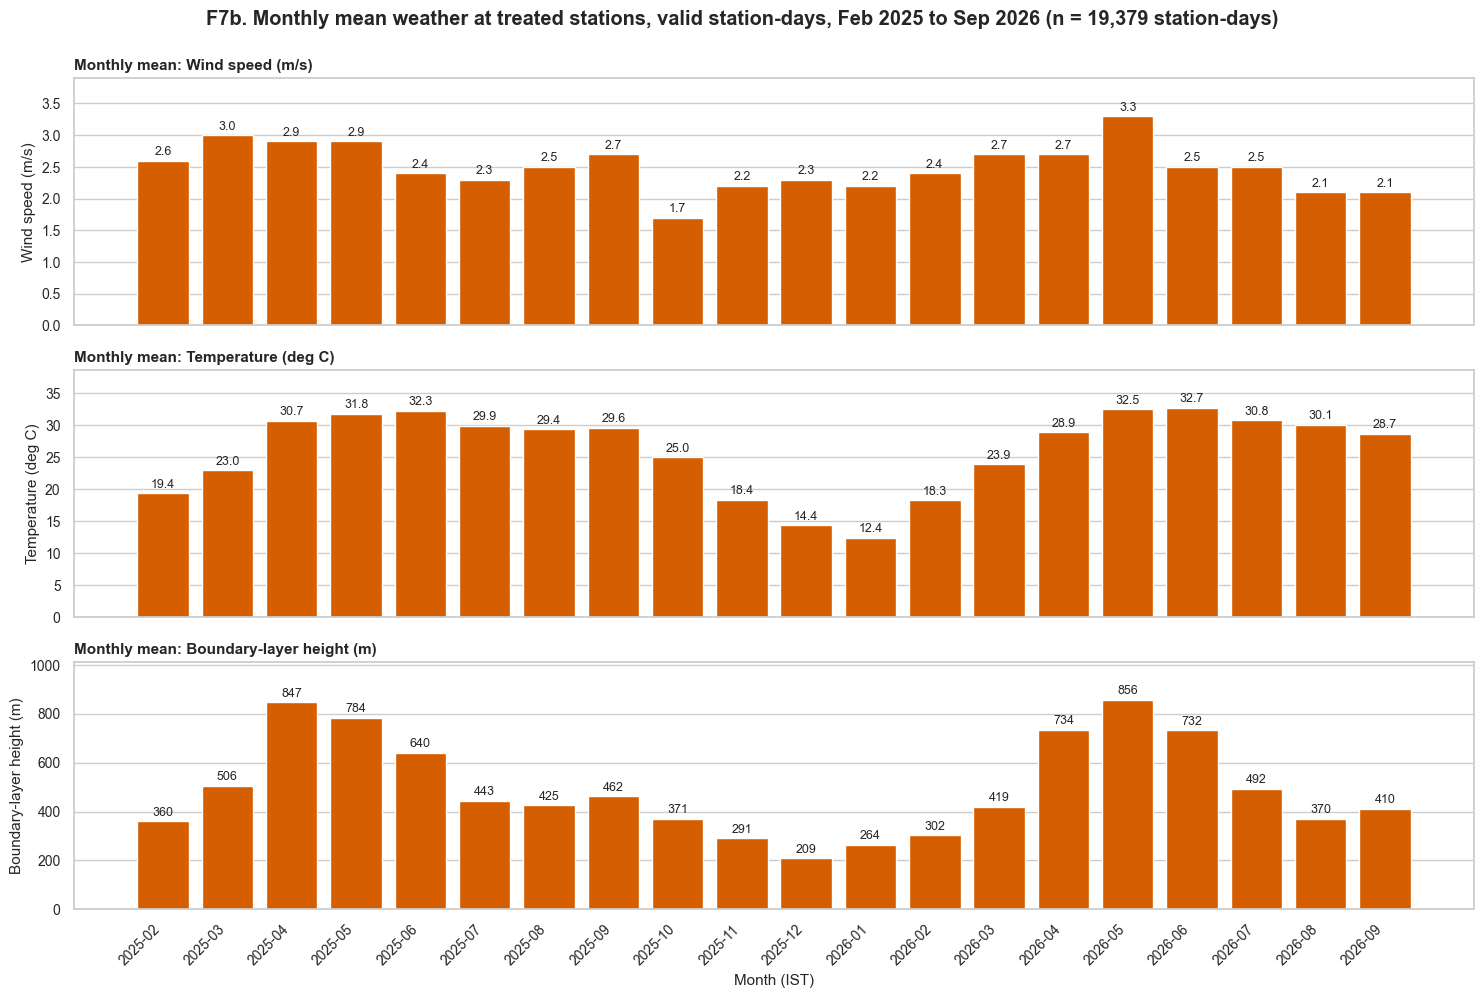

In [93]:
# Step 6.8b: F7b three bar panels on a shared month axis, values written on every bar
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
for ax, (col, label) in zip(axes, weather_vars.items()):
    bars = ax.bar(weather_month.index, weather_month[col], color=COL["treated"])
    label_bars(ax, bars, "{:,.1f}" if col != "blh_m" else "{:,.0f}")
    ax.set_ylabel(label); ax.set_title(f"Monthly mean: {label}", fontsize=11, loc="left")
    ax.set_ylim(min(0, weather_month[col].min() * 1.15), weather_month[col].max() * 1.18); ax.grid(axis="x", visible=False)
axes[-1].set_xlabel("Month (IST)"); plt.setp(axes[-1].get_xticklabels(), rotation=45, ha="right")
fig.suptitle(f"F7b. Monthly mean weather at treated stations, valid station-days, Feb 2025 to Sep 2026 (n = {len(treated_days):,} station-days)", fontweight="bold", y=0.995)
plt.tight_layout(); save_fig(fig, "F7b_weather_by_month"); plt.show()

In [94]:
# Step 6.8c: takeaway text
show_takeaway(
    f"**What we learn:** the boundary layer is shallowest in **{weather_month['blh_m'].idxmin()}** (**{weather_month['blh_m'].min():.0f} m**) and deepest in "
    f"**{weather_month['blh_m'].idxmax()}** (**{weather_month['blh_m'].max():.0f} m**). Temperature ranges from **{weather_month['t2m_c'].min():.1f}** "
    f"(**{weather_month['t2m_c'].idxmin()}**) to **{weather_month['t2m_c'].max():.1f} deg C** and wind speed from **{weather_month['wind_speed'].min():.1f}** to "
    f"**{weather_month['wind_speed'].max():.1f} m/s**."
)

**What we learn:** the boundary layer is shallowest in **2025-12** (**209 m**) and deepest in **2026-05** (**856 m**). Temperature ranges from **12.4** (**2026-01**) to **32.7 deg C** and wind speed from **1.7** to **3.3 m/s**.

*F7b. Monthly mean wind speed (m/s), temperature (deg C) and boundary-layer height (m) at treated stations; ERA5 reanalysis averaged over the 24 hours of each valid station-day. The value is written on every bar. Feb 2025 to Sep 2026 (IST). Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** The seasonal swing of three weather drivers. In the cold months the air is cooler and the boundary layer shallower, which traps pollution near the ground.

**What it does not show.** These are monthly means of ERA5 reanalysis values for the station's grid cell, not measurements at the station, and they hide day-to-day weather that matters for individual episodes. Weather and pollution move together by season, so they are included in the models as controls; the figure does not tell us how much of PM2.5 each explains.

## 6.9 Figure F7c: Hours at each GRAP stage

**Question:** how much of the time is each GRAP stage in force at treated stations?
**Sample:** hours (one count per hour, not per station), Feb 2025 to Sep 2026.

In [95]:
# Step 6.9a: hours at each stage and the share of all hours (from the Phase 5 table)
stage_total = stage_hours.loc["Total", [c for c in stage_hours.columns if c.startswith("Stage")]]
stage_share = (stage_total / stage_total.sum() * 100).round(1)
display(pd.DataFrame({"Hours": stage_total, "Share (%)": stage_share}))
assert stage_total.sum() == n_hours

,Hours,Share (%)
Stage 0,8067,57.1
Stage 1,2995,21.2
Stage 2,2103,14.9
Stage 3,651,4.6
Stage 4,320,2.3


saved figure: F7c_grap_stage_hours


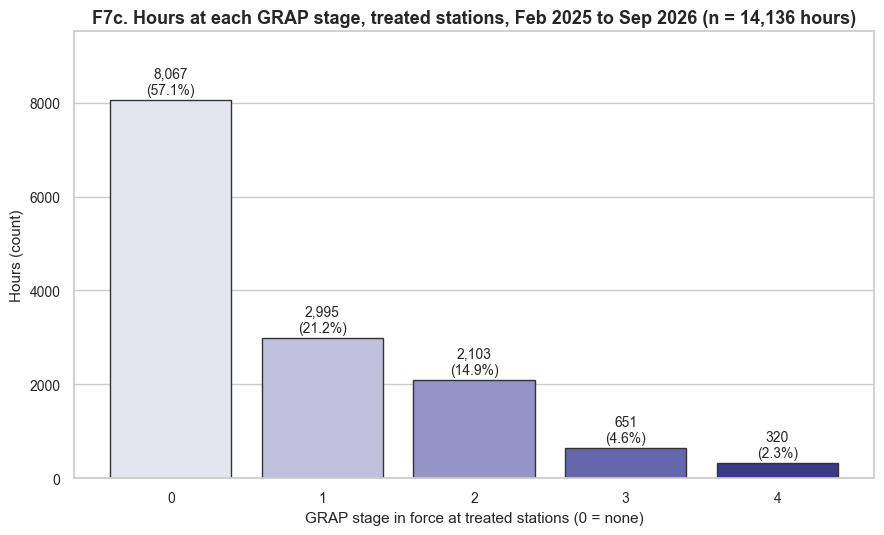

In [96]:
# Step 6.9b: F7c bar chart, count and share written on every bar
fig, ax = plt.subplots(figsize=(9, 5.5))
shades = ["#E5E5F0", "#C0C0DD", "#9494C8", "#6666AD", "#3A3A86"]                 # one hue, darker = stricter stage
bars = ax.bar([c.replace("Stage ", "") for c in stage_total.index], stage_total.values, color=shades, edgecolor="#333333")
for bar, hours, share in zip(bars, stage_total.values, stage_share.values):
    ax.annotate(f"{hours:,}\n({share:.1f}%)", (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom", fontsize=10, xytext=(0, 2), textcoords="offset points")
ax.set_ylim(0, stage_total.max() * 1.18); ax.grid(axis="x", visible=False)
ax.set_xlabel("GRAP stage in force at treated stations (0 = none)"); ax.set_ylabel("Hours (count)")
ax.set_title(f"F7c. Hours at each GRAP stage, treated stations, Feb 2025 to Sep 2026 (n = {n_hours:,} hours)")
plt.tight_layout(); save_fig(fig, "F7c_grap_stage_hours"); plt.show()

In [97]:
# Step 6.9c: takeaway text
show_takeaway(
    f"**What we learn:** Stage 0 holds **{stage_share['Stage 0']:.0f}%** of the hours. Stages III and IV together hold **{int(stage_total['Stage 3'] + stage_total['Stage 4']):,}** hours "
    f"(**{stage_share['Stage 3'] + stage_share['Stage 4']:.1f}%**), of which Stage IV is **{int(stage_total['Stage 4']):,}** hours."
)

**What we learn:** Stage 0 holds **57%** of the hours. Stages III and IV together hold **971** hours (**6.9%**), of which Stage IV is **320** hours.

*F7c. Hours at each GRAP stage at treated stations (one count per hour); darker bars = stricter stages; counts and shares written on the bars. n = 14,136 hours, Feb 2025 to Sep 2026 (IST). Source: `final_dataset.parquet`, column `grap_stage_applied`.*

**What it shows.** How rarely the strictest stages are in force: the less a stage is used, the less evidence exists about it.

**What it does not show.** Stages are **not randomly assigned**: they are raised when pollution is already high or forecast to be, so a stage and high PM2.5 go together by design. The hours also fall in a handful of episodes, not in many independent ones.

## 6.9b Figure F32: Where are the fires the model sees, relative to the stations?

**Question:** where do the stations sit relative to the 100 km fire radius, and how many upwind fire detections does each station see in winter?
**Sample:** all stations; the **mean winter (1 Oct 2025 to 28 Feb 2026) upwind fire count per station**, shown as the size of the marker. *The raw satellite detections are not in the repository (they are git-ignored), so the map shows the station-level counts, not the individual fires.*

In [98]:
# Step 6.9b-a: mean winter upwind fire count per station (previous day, within 100 km and 45 degrees of the wind direction) at the station's coordinates
winter_fire = (analysis_station_day[analysis_station_day["date_ist"].between(WINTER_START, WINTER_END)].groupby("station_id")["n_up_nh_100km_45deg_lag1"].mean().rename("mean_upwind_count"))
fire_map = stations_xy.merge(winter_fire, on="station_id", how="left")
DELHI_CENTRE = (28.61, 77.21)                                                      # central Delhi, the centre of the 25 km station search
print(fire_map.groupby("sub_area")["mean_upwind_count"].agg(["count", "mean", "max"]).round(1).to_string())

           count  mean  max
sub_area                   
Delhi         33   4.1  4.6
Ghaziabad      3   4.0  4.1
Gurugram       1   3.5  3.5
Kanpur         3   5.1  5.2
Lucknow        5   1.9  2.0
Noida          2   4.0  4.1
Patna          7   2.0  3.4


saved figure: F32_station_fire_map


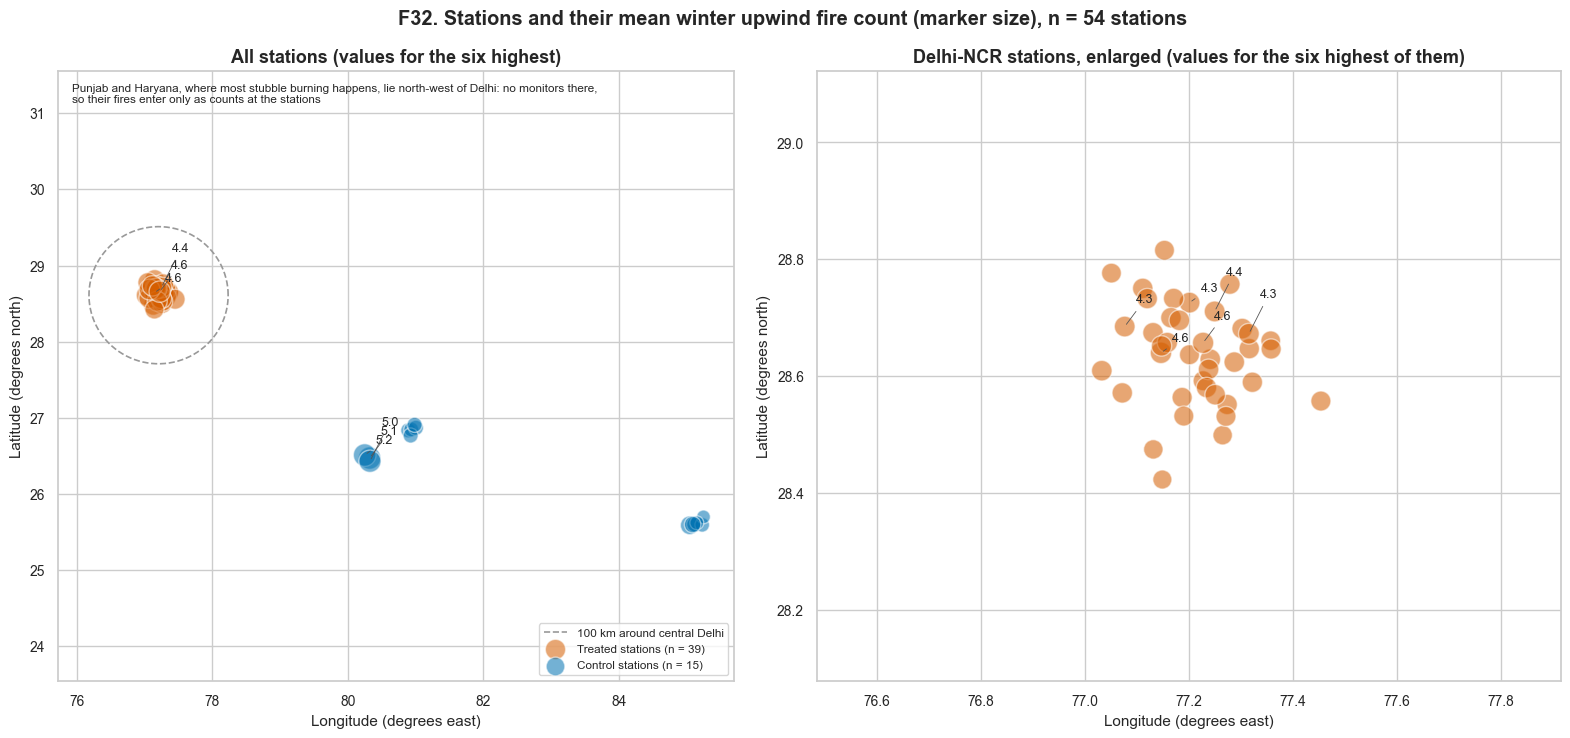

In [99]:
# Step 6.9b-b: F32 two panels: all stations (left) and the Delhi-NCR stations in detail (right); marker size = mean winter upwind fire count, colour = group, the 100 km radius around central Delhi
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={"width_ratios": [1, 1.1]}); theta = np.linspace(0, 2 * np.pi, 200)
circle = (DELHI_CENTRE[1] + 100 / (111 * np.cos(np.radians(DELHI_CENTRE[0]))) * np.cos(theta), DELHI_CENTRE[0] + 100 / 111 * np.sin(theta))
for ax, box in zip(axes, [None, (76.6, 77.8, 28.2, 29.0)]):
    ax.plot(*circle, color=GREY, ls="--", lw=1.2, label="100 km around central Delhi")
    for g in ["treated", "control"]:
        sub = fire_map[fire_map["group"] == g]
        ax.scatter(sub["longitude"], sub["latitude"], s=30 + 45 * sub["mean_upwind_count"].fillna(0), color=COL[g], alpha=0.55, edgecolor="white", label=f"{g.capitalize()} stations (n = {len(sub)})")
    ax.set_aspect(1 / np.cos(np.radians(27)), adjustable="datalim"); ax.set_xlabel("Longitude (degrees east)"); ax.set_ylabel("Latitude (degrees north)")
    if box:
        ax.set_xlim(*box[:2]); ax.set_ylim(*box[2:])
    top = fire_map.nlargest(6, "mean_upwind_count") if box is None else fire_map[fire_map["group"] == "treated"].nlargest(6, "mean_upwind_count")
    for k, (_, r) in enumerate(top.iterrows()):
        ax.annotate(f"{r['mean_upwind_count']:.1f}", (r["longitude"], r["latitude"]), xytext=(8, 8 + 9 * (k % 3)), textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="-", color="#555555", lw=0.6))
axes[0].set_title("All stations (values for the six highest)"); axes[1].set_title("Delhi-NCR stations, enlarged (values for the six highest of them)")
axes[0].annotate("Punjab and Haryana, where most stubble burning happens, lie north-west of Delhi: no monitors there,\nso their fires enter only as counts at the stations", (0.02, 0.98), xycoords="axes fraction", va="top", fontsize=8.5)
axes[0].legend(loc="lower right", fontsize=8.5)
fig.suptitle(f"F32. Stations and their mean winter upwind fire count (marker size), n = {len(fire_map)} stations", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F32_station_fire_map"); plt.show()

*F32. Locations of the stations (orange: treated, blue: control) with marker size proportional to the mean winter (1 Oct 2025 to 28 Feb 2026) upwind fire count of the previous day within 100 km and 45 degrees of the wind direction; the dashed circle is 100 km around central Delhi; the values are written for the six stations with the highest mean. The raw FIRMS detections are not in the repository. Source: `final_dataset.parquet`.*

**What it shows.** Where the monitors are, which of them see the most upwind fire detections in winter, and that all stations lie in or near the NCR, Patna, Lucknow and Kanpur, far from the main burning districts.

**What it does not show.** The fires themselves, their size or the smoke they emit, and anything about Punjab and Haryana, which have no stations in this data; the counts are a proxy for smoke, and clouds hide some fires. Marker size is the mean of a daily count, not a total.

## 6.10 What the figures tell us, in words

- **Data (F1, F2):** PM2.5 coverage is high for most stations and months, with identifiable gaps (the January outage and a few weak stations). Treated stations cluster in and around Delhi; the controls are far away.
- **Time (F3, F4, F5):** PM2.5 is strongly seasonal and far higher and more variable at treated than at control stations; the daily rhythm is stronger in winter. GRAP stages occur when pollution is already high.
- **Distribution (F6):** a large share of treated station-days exceed the 60 ug/m3 standard, with a long upper tail.
- **Drivers (F7, F7b, F7c):** fire detections within 100 km are largest in April and May and only moderate from October to February, so the autumn fire season is not a clear peak at this radius (a point carried into the H1 plan in Phase 7); the boundary layer is shallow in the cold months; and Stage III or IV is rare and short.

These are descriptions. They suggest what H1 and H2 should control for (season, weather, outages), but **none of them is a test of H1 or H2**. Phase 7 collects them into a findings table and fixes the analysis plans before any model is fitted.

---
# Phase 7: EDA findings and the frozen analysis plan
*BADIR: **A**nalysis plan.* Phases 5 and 6 described the data. This phase (1) collects what they tell us about H1 and H2 in one table, and (2) **fixes the analysis plans before any model is fitted**. Everything that decides how H1 and H2 are tested (sample, outcome, effect unit, windows, thresholds, robustness checks) is written down here and stored as constants that the model phases read. Changing any of it after seeing results requires a written deviation labelled *"added after seeing results"*.

## 7.1 What the EDA tells H1 and H2 (table T07)

**Question:** which findings of Phases 3 to 6 matter for the two hypotheses, and what do they imply for how we test them?
**Reading guide:** each row is one finding, the evidence behind it (numbers computed from the earlier tables), and its consequence for H1 (fire) and for H2 (GRAP).

In [100]:
# Step 7.1a: collect the numbers for the findings table from the variables of Phases 3 to 6 (nothing is typed by hand)
tg, cg = summary_group.loc["treated"], summary_group.loc["control"]
up_row = fire_summary.loc["Upwind detections (100 km, 45 deg)"]
tm = month_table["Mean (treated)"]
stage_pct_high = (stage_total["Stage 3"] + stage_total["Stage 4"]) / n_hours * 100
spring_fire = (period_means["Apr to May 2025"] + period_means["Apr to May 2026"]) / 2

findings = [
    ("PM2.5 is far higher and more variable at treated than at control stations",
     f"Mean {tg['Mean']:.0f} vs {cg['Mean']:.0f} ug/m3; {tg['Days above 60 (%)']:.0f}% vs {cg['Days above 60 (%)']:.0f}% of station-days above 60",
     "The outcome is skewed: model log(PM2.5) so effects are proportional", "Levels differ between groups: compare changes, not levels"),
    ("PM2.5 follows the season",
     f"Treated monthly mean: {tm.max():.0f} ug/m3 in {tm.idxmax()}, {tm.min():.0f} in {tm.idxmin()}",
     "Season confounds fire and PM2.5: use the winter sample and control for weather", "A before-and-after comparison is confounded by season: use a weather-based counterfactual"),
    ("Strict GRAP stages are rare and confined to a few months",
     f"Stage 0 in {stage_share['Stage 0']:.0f}% of hours; Stage III/IV {n_stage34:,} hours ({stage_pct_high:.1f}%), only between {months_with_hi.min()} and {months_with_hi.max()}",
     "Stage responds to pollution, so it is left out of the primary H1 model", "H2 rests on a handful of episodes: report each event, not only a pooled number"),
    ("The January 2026 outage overlaps the strongest stages",
     f"{n_inside} of {n_stage34} Stage III/IV hours ({n_inside / n_stage34 * 100:.1f}%) fall in an outage; the longest run is {long_run['hours']} hours from {long_run['start']:%d %b %Y}",
     "Outage days drop out of the sample", "Events near the outage must be shown with and without it"),
    ("The upwind fire count is small on most days",
     f"Median {up_row['Median']:.0f}, SD {up_row['SD']:.1f}, zero on {up_row['Share zero (%)']:.0f}% of winter station-days; +10 is about {10 / up_row['SD']:.1f} SD and occurs on {share_over_10:.0f}% of days",
     "Report the effect per +5 detections (about 1 SD) as the primary unit", "Fire enters the counterfactual only as a control"),
]

In [101]:
# Step 7.1b: the remaining findings (fire timing, weather, the two groups, missing days), then the findings table
findings += [
    ("Fire counts within 100 km peak in April and May, not in the autumn",
     f"Mean per day: {period_means['Oct to Nov 2025']:.1f} in Oct to Nov 2025, {period_means['Dec 2025 to Feb 2026']:.1f} in Dec to Feb, {spring_fire:.1f} in April to May",
     "The 100 km radius may miss the autumn smoke source: add 200 km and FRP sensitivity runs and say the result is about nearby fires", "No consequence beyond the fire control"),
    ("Weather explains much of PM2.5; some predictors overlap",
     f"r with PM2.5: boundary layer {with_pm['Boundary layer height']:+.2f}, temperature {with_pm['Temperature']:+.2f}, pressure {with_pm['Pressure']:+.2f}, upwind fire {with_pm['Upwind fire (lag 1)']:+.2f}; strongest predictor pair {top_pair[0].lower()} and {top_pair[1].lower()} (r = {pairs[top_pair]:+.2f})",
     "Control for weather; report variance inflation factors; do not interpret control coefficients on their own", "A weather-based counterfactual is feasible but must be checked on held-out days"),
    ("Treated and control cities move together but differ in level",
     f"Correlation of daily means {r_groups:.2f} on {len(both)} days; largest gap in {gap.idxmax()} ({gap.max():+.0f} ug/m3)",
     "Control cities give a comparison sample and a place for placebo checks", "Treated minus control is a useful sensitivity run, but the controls are not a clean counterfactual"),
    ("Missing days are linked to outages",
     f"{kept_share:.0f}% of station-days are valid; {outage_share_dropped:.0f}% of dropped days contain an outage hour against {outage_share_kept:.0f}% of kept days",
     "Primary: drop outage hours; sensitivity: 12 and 20 hour rules and short-gap interpolation", "Same, plus the with/without-outage event check"),
]
findings_table = pd.DataFrame(findings, columns=["Finding", "Evidence (computed)", "Consequence for H1", "Consequence for H2"])
save_table(findings_table.set_index("Finding"), "T07_eda_findings")
print(len(findings_table), "findings collected")

saved table : T07_eda_findings
9 findings collected


In [102]:
# Step 7.1c: show the findings table as a readable markdown table
header = "| # | Finding | Evidence | For H1 | For H2 |\n|---|---|---|---|---|\n"
body = "\n".join(f"| {i} | {r['Finding']} | {r['Evidence (computed)']} | {r['Consequence for H1']} | {r['Consequence for H2']} |"
                 for i, (_, r) in enumerate(findings_table.iterrows(), 1))
show_takeaway(header + body)

| # | Finding | Evidence | For H1 | For H2 |
|---|---|---|---|---|
| 1 | PM2.5 is far higher and more variable at treated than at control stations | Mean 80 vs 48 ug/m3; 47% vs 29% of station-days above 60 | The outcome is skewed: model log(PM2.5) so effects are proportional | Levels differ between groups: compare changes, not levels |
| 2 | PM2.5 follows the season | Treated monthly mean: 222 ug/m3 in 2025-11, 30 in 2025-07 | Season confounds fire and PM2.5: use the winter sample and control for weather | A before-and-after comparison is confounded by season: use a weather-based counterfactual |
| 3 | Strict GRAP stages are rare and confined to a few months | Stage 0 in 57% of hours; Stage III/IV 971 hours (6.9%), only between 2025-11 and 2026-01 | Stage responds to pollution, so it is left out of the primary H1 model | H2 rests on a handful of episodes: report each event, not only a pooled number |
| 4 | The January 2026 outage overlaps the strongest stages | 112 of 971 Stage III/IV hours (11.5%) fall in an outage; the longest run is 242 hours from 10 Jan 2026 | Outage days drop out of the sample | Events near the outage must be shown with and without it |
| 5 | The upwind fire count is small on most days | Median 2, SD 5.0, zero on 28% of winter station-days; +10 is about 2.0 SD and occurs on 11% of days | Report the effect per +5 detections (about 1 SD) as the primary unit | Fire enters the counterfactual only as a control |
| 6 | Fire counts within 100 km peak in April and May, not in the autumn | Mean per day: 12.0 in Oct to Nov 2025, 13.6 in Dec to Feb, 33.3 in April to May | The 100 km radius may miss the autumn smoke source: add 200 km and FRP sensitivity runs and say the result is about nearby fires | No consequence beyond the fire control |
| 7 | Weather explains much of PM2.5; some predictors overlap | r with PM2.5: boundary layer -0.48, temperature -0.35, pressure +0.33, upwind fire +0.30; strongest predictor pair temperature and pressure (r = -0.83) | Control for weather; report variance inflation factors; do not interpret control coefficients on their own | A weather-based counterfactual is feasible but must be checked on held-out days |
| 8 | Treated and control cities move together but differ in level | Correlation of daily means 0.71 on 541 days; largest gap in 2025-11 (+149 ug/m3) | Control cities give a comparison sample and a place for placebo checks | Treated minus control is a useful sensitivity run, but the controls are not a clean counterfactual |
| 9 | Missing days are linked to outages | 84% of station-days are valid; 61% of dropped days contain an outage hour against 23% of kept days | Primary: drop outage hours; sensitivity: 12 and 20 hour rules and short-gap interpolation | Same, plus the with/without-outage event check |

**What it shows.** The nine most relevant findings of the EDA, the numbers behind each, and what each means for the way H1 and H2 are tested.

**What it does not show.** The table describes the data; it is not a test of either hypothesis. Two items deserve emphasis: **(a)** the strict GRAP stages are few and overlap the outage, so H2 is weakly identified by design; **(b)** fires within 100 km are not highest in the months of highest PM2.5, so an H1 result at this radius speaks to *nearby* fires only.

## 7.2 Frozen constants

The model phases read these values instead of re-typing them. **They were fixed after the EDA (Phases 5 and 6) and before any model was fitted.** Four choices were informed by the EDA and are labelled as such in the plan below: the effect unit (5.4), the extra sensitivity runs for fire radius (7.1, row 6), the way the H1 confidence interval is chosen, and the two secondary event sets for H2 (added after counting events, because the primary rule leaves very few). The constant `MIN_EVENTS_FOR_SUPPORT` makes the Phase 1 wording "few usable events" concrete.

In [103]:
# Step 7.2: all frozen settings in one place (H1, H2 and the decision rules); later phases import nothing, they read these variables
EFFECT_UNIT = 5                                   # H1: report the effect per +5 upwind detections (about 1 SD, see 5.4)
TRAIN_END, TEST_START = pd.Timestamp("2025-12-31"), pd.Timestamp("2026-01-01")   # H1 prediction: time-blocked split
ROBUST_AGREE_SHARE = 0.75                         # both hypotheses: share of robustness checks that must have the same sign
BOOTSTRAP_DRAWS, BLOCK_DAYS = 2000, 3             # block bootstrap (blocks of days) for H2 intervals; SEED is set in Phase 0

MIN_CLEAN_DAYS, MIN_EVENT_STAGE = 7, 2            # H2 event rule: upward change to Stage II or higher, 7 clean days either side
BUFFER_HOURS = 12                                 # H2: hours around a change that are excluded (the hour of change is uncertain)
EFFECT_WINDOWS = [(1, 3), (4, 7)]                 # H2: days after activation over which the effect is averaged
FIT_WINDOW_DAYS, HOLDOUT_DAYS = 60, 10           # H2: days before activation used to fit; the last HOLDOUT_DAYS are held out to check the fit
FIT_MAX_ERROR = 0.25                              # H2: an event is usable if the held-out mean absolute error is at most 25% of PM2.5
PLACEBO_TOLERANCE = 0.15                          # H2: placebo days must have a pre-period PM2.5 within 15% of the real event's
MIN_EVENTS_FOR_SUPPORT = 3                        # H2: fewer usable events than this can never be called 'supported'
SECONDARY_EVENT_RULES = {"S1: Stage I or higher, 7 clean days": (1, 7), "S2: Stage II or higher, 5 clean days": (2, 5)}   # (minimum stage, clean days); added after counting events, before any outcome

frozen = pd.Series({"EFFECT_UNIT": EFFECT_UNIT, "TRAIN_END": f"{TRAIN_END:%Y-%m-%d}", "TEST_START": f"{TEST_START:%Y-%m-%d}",
                    "ROBUST_AGREE_SHARE": ROBUST_AGREE_SHARE, "BOOTSTRAP_DRAWS": BOOTSTRAP_DRAWS, "BLOCK_DAYS": BLOCK_DAYS,
                    "MIN_CLEAN_DAYS": MIN_CLEAN_DAYS, "MIN_EVENT_STAGE": MIN_EVENT_STAGE, "BUFFER_HOURS": BUFFER_HOURS,
                    "EFFECT_WINDOWS": str(EFFECT_WINDOWS), "FIT_WINDOW_DAYS": FIT_WINDOW_DAYS, "HOLDOUT_DAYS": HOLDOUT_DAYS,
                    "FIT_MAX_ERROR": FIT_MAX_ERROR, "PLACEBO_TOLERANCE": PLACEBO_TOLERANCE, "MIN_EVENTS_FOR_SUPPORT": MIN_EVENTS_FOR_SUPPORT, "SECONDARY_EVENT_RULES": str(list(SECONDARY_EVENT_RULES.values())),
                    "SEED": SEED}, name="value")
save_table(frozen.to_frame(), "T07b_frozen_constants")
display(frozen.to_frame())

saved table : T07b_frozen_constants


,value
EFFECT_UNIT,5
TRAIN_END,2025-12-31
TEST_START,2026-01-01
ROBUST_AGREE_SHARE,0.75
BOOTSTRAP_DRAWS,2000
BLOCK_DAYS,3
MIN_CLEAN_DAYS,7
MIN_EVENT_STAGE,2
BUFFER_HOURS,12
EFFECT_WINDOWS,"[(1, 3), (4, 7)]"


## 7.3 Frozen H1 plan: fire and PM2.5

**Hypothesis.** Higher *upwind* fire counts in the previous days are associated with higher PM2.5, controlling for wind, temperature, humidity and boundary-layer height.
**Method** (plan items K1 to K4): lag correlation, one primary regression, a prediction check, and a fixed list of robustness runs.

In [104]:
# Step 7.3a: the frozen H1 plan, written from the constants above so that text and constants cannot differ
h1_rows = [
    ("Sample (primary)", f"Treated stations, station-days with at least {MIN_VALID_HOURS} valid hours, {WINTER_START:%d %b %Y} to {WINTER_END:%d %b %Y} (the winter sample)"),
    ("Outcome", "log of the daily mean PM2.5 (ug/m3), one value per station and day"),
    ("Primary predictor", "`n_up_nh_100km_45deg_lag1`: fire detections within 100 km and within 45 degrees of where the wind came from, on the previous day"),
    ("Reported effect", f"% change in PM2.5 per **+{EFFECT_UNIT} upwind detections** (about 1 SD; chosen after the EDA); the effect per +10 is also given for comparison with the earlier pass"),
    ("Controls", "wind speed, wind direction (sine and cosine), temperature, relative humidity, boundary-layer height, rain, pressure"),
    ("Fixed effects", "station and day of week (month effects are a sensitivity run)"),
    ("Standard errors", "clustered by date (primary) and by station (reported alongside); **the decision uses the wider of the two intervals** (chosen after the EDA)"),
    ("Not in the primary model", "GRAP stage (it responds to pollution), several fire radii at once (collinearity)"),
    ("Lag correlation", "fire counts at lags 0 to 5 days against the treated daily mean PM2.5; lag 0 is a diagnostic only and is not a model input"),
    ("Prediction check", f"time-blocked: train to {TRAIN_END:%d %b %Y}, test from {TEST_START:%d %b %Y}; baselines: monthly climatology, persistence, weather only; the specification is never chosen on the test period"),
    ("Diagnostics", "residual versus fitted, residual autocorrelation, Q-Q plot, variance inflation factors, influence of single days"),
    ("Status", f"**Supported** needs the primary coefficient above 0 with the 95% interval excluding 0, the same sign in at least {ROBUST_AGREE_SHARE:.0%} of robustness checks, and a lower test error for the fire model than the weather-only model; otherwise **not supported** or **inconclusive** as defined in Phase 1"),
]
show_takeaway("| Item | Frozen choice |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in h1_rows))

| Item | Frozen choice |
|---|---|
| Sample (primary) | Treated stations, station-days with at least 18 valid hours, 01 Oct 2025 to 28 Feb 2026 (the winter sample) |
| Outcome | log of the daily mean PM2.5 (ug/m3), one value per station and day |
| Primary predictor | `n_up_nh_100km_45deg_lag1`: fire detections within 100 km and within 45 degrees of where the wind came from, on the previous day |
| Reported effect | % change in PM2.5 per **+5 upwind detections** (about 1 SD; chosen after the EDA); the effect per +10 is also given for comparison with the earlier pass |
| Controls | wind speed, wind direction (sine and cosine), temperature, relative humidity, boundary-layer height, rain, pressure |
| Fixed effects | station and day of week (month effects are a sensitivity run) |
| Standard errors | clustered by date (primary) and by station (reported alongside); **the decision uses the wider of the two intervals** (chosen after the EDA) |
| Not in the primary model | GRAP stage (it responds to pollution), several fire radii at once (collinearity) |
| Lag correlation | fire counts at lags 0 to 5 days against the treated daily mean PM2.5; lag 0 is a diagnostic only and is not a model input |
| Prediction check | time-blocked: train to 31 Dec 2025, test from 01 Jan 2026; baselines: monthly climatology, persistence, weather only; the specification is never chosen on the test period |
| Diagnostics | residual versus fitted, residual autocorrelation, Q-Q plot, variance inflation factors, influence of single days |
| Status | **Supported** needs the primary coefficient above 0 with the 95% interval excluding 0, the same sign in at least 75% of robustness checks, and a lower test error for the fire model than the weather-only model; otherwise **not supported** or **inconclusive** as defined in Phase 1 |

**What it shows.** The complete H1 plan in one table, generated from the frozen constants.

**What it does not show.** The plan does not make H1 easier or harder to support: it prevents us from choosing, after seeing results, the unit, the standard errors or the controls that look best. With one burning season the number of independent days is small, and an *inconclusive* result is a valid outcome.

## 7.4 Frozen H2 plan: GRAP and PM2.5

**Hypothesis.** PM2.5 falls after GRAP activation, relative to the trend predicted by weather and fires alone.
**Method** (plan items B1 to B3): an event table, a counterfactual for each event, placebo events, and a fixed list of robustness runs. **First, how many changes qualify?** The count uses the stage series only; no PM2.5 outcome is looked at.

In [105]:
# Step 7.4a: every stage change of the treated stations, with the time to the previous and next change (stage series only)
changed = stage_hourly.index[stage_hourly["stage"].diff().fillna(0) != 0]
changes = stage_hourly.loc[changed, ["hour_ist"]].copy()
changes["stage_before"] = stage_hourly["stage"].shift(1).loc[changed].astype(int)
changes["stage_after"] = stage_hourly.loc[changed, "stage"].astype(int)
changes["direction"] = np.where(changes["stage_after"] > changes["stage_before"], "up", "down")

data_start, data_end = df["hour_ist"].min(), df["hour_ist"].max()
previous = changes["hour_ist"].shift(1).fillna(data_start)                  # before the first change: time since the window start
following = changes["hour_ist"].shift(-1).fillna(data_end)                  # after the last change: time to the window end
changes["days_since_previous"] = ((changes["hour_ist"] - previous).dt.total_seconds() / 86400).round(1)
changes["days_to_next"] = ((following - changes["hour_ist"]).dt.total_seconds() / 86400).round(1)
changes["outage_hours_within_7_days"] = [int(outage_hours.between(t - pd.Timedelta(days=7), t + pd.Timedelta(days=7)).sum()) for t in changes["hour_ist"]]
changes["qualifies"] = ((changes["direction"] == "up") & (changes["stage_after"] >= MIN_EVENT_STAGE)
                        & (changes["days_since_previous"] >= MIN_CLEAN_DAYS) & (changes["days_to_next"] >= MIN_CLEAN_DAYS))
changes = changes.reset_index(drop=True); changes.index += 1; changes.index.name = "Change"
display(changes)
save_table(changes, "T07c_stage_changes_preview")

,hour_ist,stage_before,stage_after,direction,days_since_previous,days_to_next,outage_hours_within_7_days,qualifies
Change,,,,,,,,
1,2025-02-24 19:00:00,2,1,down,5.8,19.2,0,False
2,2025-03-15 23:00:00,1,0,down,19.2,8.9,0,False
3,2025-03-24 20:00:00,0,1,up,8.9,5.0,0,False
4,2025-03-29 19:00:00,1,0,down,5.0,4.0,2,False
5,2025-04-02 19:00:00,0,1,up,4.0,29.0,16,False
6,2025-05-01 19:00:00,1,0,down,29.0,15.1,2,False
7,2025-05-16 21:00:00,0,1,up,15.1,1.9,2,False
8,2025-05-18 19:00:00,1,0,down,1.9,2.7,4,False
9,2025-05-21 12:00:00,0,1,up,2.7,2.0,35,False


saved table : T07c_stage_changes_preview


In [106]:
# Step 7.4b: counts and takeaway text (the full event table with PM2.5 context is built in Phase 9)
n_changes, n_up = len(changes), int((changes["direction"] == "up").sum())
n_qualify = int(changes["qualifies"].sum())
n_qualify_outage = int((changes["qualifies"] & (changes["outage_hours_within_7_days"] > 0)).sum())
qualifying_dates = ", ".join(f"{t:%d %b %Y}" for t in changes.loc[changes["qualifies"], "hour_ist"])
show_takeaway(
    f"**What we learn:** the treated stations had **{n_changes}** stage changes (**{n_up}** up, **{n_changes - n_up}** down). Only **{n_qualify}** "
    f"qualif{'ies' if n_qualify == 1 else 'y'} as a primary event (an upward change to Stage {MIN_EVENT_STAGE} or higher with at least {MIN_CLEAN_DAYS} clean days on each side): "
    f"**{qualifying_dates}**. **{n_qualify_outage}** of the primary events ha{'s' if n_qualify_outage == 1 else 've'} outage hours within 7 days. "
    f"{'The status rule needs at least ' + str(MIN_EVENTS_FOR_SUPPORT) + ' usable events, so on the primary set H2 can be at best inconclusive.' if n_qualify < MIN_EVENTS_FOR_SUPPORT else 'There are enough primary events for a pooled estimate.'}"
)

**What we learn:** the treated stations had **30** stage changes (**14** up, **16** down). Only **1** qualifies as a primary event (an upward change to Stage 2 or higher with at least 7 clean days on each side): **11 Nov 2025**. **1** of the primary events has outage hours within 7 days. The status rule needs at least 3 usable events, so on the primary set H2 can be at best inconclusive.

**What it shows.** Each stage change with the stage before and after, the days since the previous change and to the next, and whether it qualifies as an *event* under the primary rule (an upward change to Stage II or higher with at least 7 clean days on both sides).

**What it does not show.** Whether PM2.5 fell afterwards: no outcome is used here. The hour of each change is uncertain for many orders, which is why a 12-hour buffer is excluded. Changes that do not qualify are not discarded: they are reported descriptively and in the "all changes" robustness run.

In [107]:
# Step 7.4c: how the number of events depends on the rule (stage series only), and the two secondary sets fixed in advance
rows = []
for clean in (7, 5, 3):
    for stage in (1, 2, 3):
        hit = changes[(changes["direction"] == "up") & (changes["stage_after"] >= stage) & (changes["days_since_previous"] >= clean) & (changes["days_to_next"] >= clean)]
        rows.append({"Minimum stage": stage, "Clean days either side": clean, "Events": len(hit), "Dates": ", ".join(f"{t:%d %b %Y}" for t in hit["hour_ist"])})
event_rule_counts = pd.DataFrame(rows)
display(event_rule_counts)
save_table(event_rule_counts.set_index("Minimum stage"), "T07e_event_rule_counts")

secondary_counts = {name: int(event_rule_counts[(event_rule_counts["Minimum stage"] == stage) & (event_rule_counts["Clean days either side"] == days)]["Events"].iloc[0])
                    for name, (stage, days) in SECONDARY_EVENT_RULES.items()}
show_takeaway("**What we learn:** the primary rule gives **" + str(n_qualify) + "** event(s). The two secondary sets fixed in advance give " +
              " and ".join(f"**{n}** ({name})" for name, n in secondary_counts.items()) + ". They are reported beside the primary event, never in its place.")

,Minimum stage,Clean days either side,Events,Dates
0,1,7,4,"07 Jun 2025, 11 Nov 2025, 16 Apr 2026, 19 May ..."
1,2,7,1,11 Nov 2025
2,3,7,1,11 Nov 2025
3,1,5,7,"24 Mar 2025, 07 Jun 2025, 14 Oct 2025, 19 Oct ..."
4,2,5,2,"19 Oct 2025, 11 Nov 2025"
5,3,5,1,11 Nov 2025
6,1,3,8,"24 Mar 2025, 02 Apr 2025, 07 Jun 2025, 14 Oct ..."
7,2,3,2,"19 Oct 2025, 11 Nov 2025"
8,3,3,1,11 Nov 2025


saved table : T07e_event_rule_counts


**What we learn:** the primary rule gives **1** event(s). The two secondary sets fixed in advance give **4** (S1: Stage I or higher, 7 clean days) and **2** (S2: Stage II or higher, 5 clean days). They are reported beside the primary event, never in its place.

**What it shows.** How many events each rule would give, and the two *secondary* event sets that are added to the plan. The primary rule keeps the project plan's definition; the secondary sets exist because one event cannot show a pattern.

**What it does not show.** The secondary sets were added **after counting events and before looking at any PM2.5 outcome**, to stop a single event from deciding H2. They include Stage I events outside the smog season (when little pollution triggered the stage), so they are not comparable with the primary event and are reported separately. The status of H2 is decided on the primary set.

In [108]:
# Step 7.4d: the frozen H2 plan, written from the constants above
h2_rows = [
    ("Event (primary)", f"an upward stage change to Stage {MIN_EVENT_STAGE} or higher with at least {MIN_CLEAN_DAYS} days without another change before and after; all changes and groups by stage are reported descriptively"),
    ("Outcome", "log of the daily mean PM2.5 of the treated group (valid group-days); the same for the control group in the placebo check"),
    ("Excluded around a change", f"{BUFFER_HOURS} hours either side of the change (the hour is uncertain); outage hours are dropped"),
    ("Counterfactual model", "log PM2.5 on wind speed, wind direction, temperature, humidity, boundary-layer height, rain, upwind fire (lag 1) and day of week, fitted before the change"),
    ("Fit window", f"the {FIT_WINDOW_DAYS} days before the change, excluding days within 7 days of another change; the last {HOLDOUT_DAYS} days are held out to check the fit and the model is then refitted on all of them"),
    ("Usable event", f"the held-out mean absolute error is at most {FIT_MAX_ERROR:.0%} of the held-out PM2.5; only usable events enter the pooled estimate"),
    ("Effect", f"actual minus predicted, in log points and in %, averaged over days {EFFECT_WINDOWS[0][0]} to {EFFECT_WINDOWS[0][1]} and days {EFFECT_WINDOWS[1][0]} to {EFFECT_WINDOWS[1][1]} after the buffer"),
    ("Interval", f"95% interval from a block bootstrap of the fit-window residuals ({BOOTSTRAP_DRAWS:,} draws, blocks of {BLOCK_DAYS} days, seed {SEED})"),
    ("Pooled estimate", "mean of the usable events' effects, and their median, each with a bootstrap over events; always shown beside the individual events"),
    ("Placebo events", f"(i) dates with no stage change within {MIN_CLEAN_DAYS} days whose pre-period PM2.5 is within {PLACEBO_TOLERANCE:.0%} of the real event's; (ii) the same dates in the control cities"),
    ("Secondary event sets", "; ".join(f"{name} ({secondary_counts[name]} events)" for name in SECONDARY_EVENT_RULES) + ": reported separately; they do not decide the status"),
    ("Cross-check", "segmented regression (level and slope change) on the daily treated series"),
    ("Status", f"**Supported** needs a pooled effect below 0 with the 95% interval excluding 0, real events in the lower tail of the placebo distribution, the same sign in at least {ROBUST_AGREE_SHARE:.0%} of robustness checks, **and at least {MIN_EVENTS_FOR_SUPPORT} usable events**; otherwise **not supported** or **inconclusive** as defined in Phase 1"),
]
show_takeaway("| Item | Frozen choice |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in h2_rows))

| Item | Frozen choice |
|---|---|
| Event (primary) | an upward stage change to Stage 2 or higher with at least 7 days without another change before and after; all changes and groups by stage are reported descriptively |
| Outcome | log of the daily mean PM2.5 of the treated group (valid group-days); the same for the control group in the placebo check |
| Excluded around a change | 12 hours either side of the change (the hour is uncertain); outage hours are dropped |
| Counterfactual model | log PM2.5 on wind speed, wind direction, temperature, humidity, boundary-layer height, rain, upwind fire (lag 1) and day of week, fitted before the change |
| Fit window | the 60 days before the change, excluding days within 7 days of another change; the last 10 days are held out to check the fit and the model is then refitted on all of them |
| Usable event | the held-out mean absolute error is at most 25% of the held-out PM2.5; only usable events enter the pooled estimate |
| Effect | actual minus predicted, in log points and in %, averaged over days 1 to 3 and days 4 to 7 after the buffer |
| Interval | 95% interval from a block bootstrap of the fit-window residuals (2,000 draws, blocks of 3 days, seed 20261115) |
| Pooled estimate | mean of the usable events' effects, and their median, each with a bootstrap over events; always shown beside the individual events |
| Placebo events | (i) dates with no stage change within 7 days whose pre-period PM2.5 is within 15% of the real event's; (ii) the same dates in the control cities |
| Secondary event sets | S1: Stage I or higher, 7 clean days (4 events); S2: Stage II or higher, 5 clean days (2 events): reported separately; they do not decide the status |
| Cross-check | segmented regression (level and slope change) on the daily treated series |
| Status | **Supported** needs a pooled effect below 0 with the 95% interval excluding 0, real events in the lower tail of the placebo distribution, the same sign in at least 75% of robustness checks, **and at least 3 usable events**; otherwise **not supported** or **inconclusive** as defined in Phase 1 |

**What it shows.** The complete H2 plan in one table, generated from the frozen constants.

**What it does not show.** The model cannot see the weather *forecast* or the pollution level that triggered the stage, so a fall after activation may be mean reversion rather than an effect of the stage: that is the reason for the placebo events. With few usable events, *inconclusive* may be mostly a statement about power, and the notebook will say so.

## 7.5 How many specifications will be tried?

Listing them now lets the report state how many were tried and how many agree, and stops us from adding checks after seeing which ones look good.

In [109]:
# Step 7.5: the full list of planned runs (primary and robustness) for each hypothesis
h1_runs = ["PRIMARY: upwind count, winter sample, station fixed effects", "interpolate gaps of up to 3 hours instead of dropping", "drop preliminary (NRT) fire rows",
           "drop days after satellite-outage fire days", "12-hour validity rule", "20-hour validity rule", "full window instead of the winter sample",
           "add month fixed effects", "add GRAP stage as a control", "leave out Delhi", "leave out Ghaziabad", "leave out Noida", "leave out Gurugram",
           "leave one station out (all stations, range reported)", "fire radiative power instead of counts", "all-direction count, 50 km", "all-direction count, 100 km",
           "all-direction count, 200 km", "all-direction 100 km count of the previous two days", "placebo: next day's fire (expected about zero)",
           "control cities only (comparison sample)"]
h2_runs = ["PRIMARY: counterfactual, events as defined, windows days 1 to 3 and 4 to 7", "exclude uncertain and inferred stage hours", "window of 3 days", "window of 5 days",
           "window of 7 days", "window of 14 days", "stations with at least 90% PM2.5 coverage", "leave out Delhi", "leave out Ghaziabad", "leave out Noida", "leave out Gurugram",
           "without fire terms", "Stage I and II events only", "Stage III and IV events only", "drop events within the January outage", "drop the largest event",
           "secondary event set S1 (Stage I or higher, 7 clean days)", "secondary event set S2 (Stage II or higher, 5 clean days)",
           "all stage changes (descriptive)", "control cities as placebo region"]
runs = pd.DataFrame({"Hypothesis": ["H1"] * len(h1_runs) + ["H2"] * len(h2_runs), "Run": h1_runs + h2_runs})
runs["Robustness check"] = ~runs["Run"].str.startswith("PRIMARY")
save_table(runs.set_index("Hypothesis"), "T07d_planned_runs")
counts = runs.groupby("Hypothesis")["Robustness check"].agg(total="size", robustness="sum")
display(counts)
show_takeaway(f"**What we learn:** we plan **{int(counts.loc['H1', 'total'])}** H1 runs and **{int(counts.loc['H2', 'total'])}** H2 runs (one primary each, the rest robustness checks). The report will state how many of the robustness checks agree in sign.")

saved table : T07d_planned_runs


,total,robustness
Hypothesis,,
H1,21,20
H2,20,19


**What we learn:** we plan **21** H1 runs and **20** H2 runs (one primary each, the rest robustness checks). The report will state how many of the robustness checks agree in sign.

**What it shows.** The complete list of planned runs. Each hypothesis has one primary specification; all others are robustness checks.

**What it does not show.** Some checks cannot be run with this dataset and are *not* planned: the weather-timing offset of plus or minus one hour (it needs the ERA5 series rebuilt outside this notebook), and a fire lag of three days (the dataset holds lags 1 and 2, so the proposal's "1 to 3 days" becomes 1 to 2). These are listed as limitations in Phase 11.

### 7.6 What happens next

Phases 8 and 9 fit the primary models and the robustness runs exactly as listed. Any run added later, or any change to a constant above, is reported as **"added after seeing results"** with the reason.

---
# Phase 8: H1, fire and PM2.5
*BADIR: **A**nalysis and **I**nsights.* **H1:** higher *upwind* fire counts in the previous days are associated with higher PM2.5, controlling for wind, temperature, humidity and boundary-layer height.

Everything here follows the plan frozen in Phase 7: the winter sample, log(PM2.5) at station-day level, the upwind count of the previous day as predictor, an effect reported per +5 detections (about 1 SD), station and day-of-week effects, and standard errors clustered by date and by station. The decision uses the wider interval. **No specification is chosen after seeing results**; runs are listed in table T07d.

*Technical note:* the regressions use `patsy` and `statsmodels.regression.linear_model` only. Other parts of `statsmodels` are blocked by the security policy of the machine this notebook was developed on, so the autocorrelation function is computed by hand.

## 8.1 Do fires lead PM2.5? Lag correlation (T03, F8)

**Question:** how does the correlation between daily PM2.5 and fire counts depend on the lag (the number of days by which fires come first)?
**Sample:** winter sample (1 Oct 2025 to 28 Feb 2026), treated group. **PM2.5:** treated daily mean (valid group-days). **Fire:** the mean over treated stations of the detections within 100 km, placed on the day the fires were *detected*; two versions: all directions, and upwind (within 45 degrees of the wind). **Lag k** means fires of *k* days before the PM2.5 day. **Lag 0** (same day) is a diagnostic only: it is **not** a model input, because the dataset only uses fires of previous days.
**Interval:** 95% interval from a moving-block bootstrap (blocks of consecutive days, so the day-to-day correlation is respected).

In [110]:
# Step 8.1a: the daily series for the lag analysis (winter sample, treated group), fire counts placed on the date of detection
winter_pm = (analysis_group_day[(analysis_group_day["group"] == "treated") & analysis_group_day["date_ist"].between(WINTER_START, WINTER_END)]
             .set_index("date_ist")["pm25"])

upwind_by_day = treated_rows.groupby("date_ist")["n_up_nh_100km_45deg_lag1"].mean()      # value on date d describes the fires of day d-1
upwind_by_day.index = upwind_by_day.index - pd.Timedelta(days=1)                          # so move it to the date of detection
fire_by_detection_date = {"All directions, 100 km": fire_day["detections"], "Upwind, 100 km, 45 deg": upwind_by_day}
print("PM2.5 days in the winter sample:", len(winter_pm), "| from", winter_pm.index.min().date(), "to", winter_pm.index.max().date())

PM2.5 days in the winter sample: 129 | from 2025-10-01 to 2026-02-28


In [111]:
# Step 8.1b: helper: correlation with a moving-block bootstrap interval (blocks of consecutive days keep the serial correlation)
def corr_with_ci(x, y, draws=BOOTSTRAP_DRAWS, block=BLOCK_DAYS):
    rng = np.random.default_rng(SEED)
    n = len(x)
    starts = rng.integers(0, n - block + 1, size=(draws, int(np.ceil(n / block))))
    idx = (starts[:, :, None] + np.arange(block)).reshape(draws, -1)[:, :n]          # indices of the resampled days
    xs, ys = x[idx], y[idx]
    xc, yc = xs - xs.mean(axis=1, keepdims=True), ys - ys.mean(axis=1, keepdims=True)
    boot = (xc * yc).sum(axis=1) / np.sqrt((xc ** 2).sum(axis=1) * (yc ** 2).sum(axis=1))
    low, high = np.percentile(boot, [2.5, 97.5])
    return np.corrcoef(x, y)[0, 1], low, high

rows = []
for name, fire_series in fire_by_detection_date.items():
    for lag in range(0, 6):
        fire_at_lag = fire_series.reindex(winter_pm.index - pd.Timedelta(days=lag)).to_numpy()      # fires of `lag` days before each PM2.5 day
        pairs_k = pd.DataFrame({"pm": winter_pm.to_numpy(), "fire": fire_at_lag}).dropna()
        r, low, high = corr_with_ci(pairs_k["fire"].to_numpy(), pairs_k["pm"].to_numpy())
        rows.append({"Fire variable": name, "Lag (days)": lag, "Correlation": r, "CI low": low, "CI high": high, "Days": len(pairs_k)})
lag_table = pd.DataFrame(rows)
display(lag_table.round(2))
save_table(lag_table.set_index("Fire variable"), "T03_lag_correlations")

,Fire variable,Lag (days),Correlation,CI low,CI high,Days
0,"All directions, 100 km",0,0.34,0.15,0.48,128
1,"All directions, 100 km",1,0.37,0.16,0.54,128
2,"All directions, 100 km",2,0.33,0.12,0.50,128
3,"All directions, 100 km",3,0.34,0.15,0.50,128
4,"All directions, 100 km",4,0.34,0.18,0.48,128
5,"All directions, 100 km",5,0.39,0.20,0.53,128
6,"Upwind, 100 km, 45 deg",0,0.32,0.12,0.46,128
7,"Upwind, 100 km, 45 deg",1,0.37,0.17,0.53,128
8,"Upwind, 100 km, 45 deg",2,0.30,0.11,0.48,128
9,"Upwind, 100 km, 45 deg",3,0.25,0.05,0.44,128


saved table : T03_lag_correlations


saved figure: F8_lag_correlation


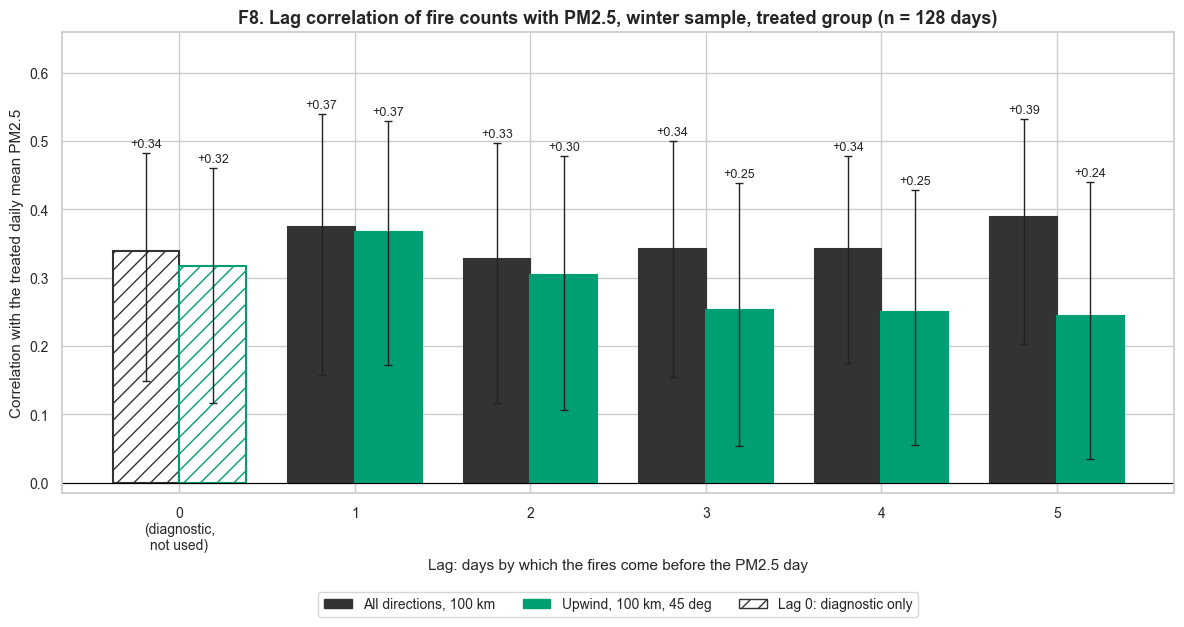

In [112]:
# Step 8.1c: F8 grouped bars by lag; lag 0 hatched and labelled as a diagnostic; correlation written above each bar, 95% interval as whiskers
from matplotlib.patches import Patch
colours = {"All directions, 100 km": "#333333", "Upwind, 100 km, 45 deg": "#009E73"}
days_text = str(int(lag_table["Days"].min())) if lag_table["Days"].nunique() == 1 else f"{int(lag_table['Days'].min())} to {int(lag_table['Days'].max())}"
fig, ax = plt.subplots(figsize=(12, 6.5))
width = 0.38
for offset, (name, colour) in zip([-width / 2, width / 2], colours.items()):
    part = lag_table[lag_table["Fire variable"] == name]
    for lag, r, low, high in zip(part["Lag (days)"], part["Correlation"], part["CI low"], part["CI high"]):
        diagnostic = lag == 0
        ax.bar(lag + offset, r, width, color="white" if diagnostic else colour, edgecolor=colour, hatch="//" if diagnostic else None, lw=1.5)
        ax.errorbar(lag + offset, r, yerr=[[r - low], [high - r]], color="#222222", capsize=3, lw=1)
        ax.annotate(f"{r:+.2f}", (lag + offset, high), ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")
ax.axhline(0, color="black", lw=0.8); ax.set_ylim(lag_table["CI low"].min() - 0.05, lag_table["CI high"].max() + 0.12)
ax.set_xticks(range(6)); ax.set_xticklabels(["0\n(diagnostic,\nnot used)"] + [str(k) for k in range(1, 6)])
ax.set_xlabel("Lag: days by which the fires come before the PM2.5 day"); ax.set_ylabel("Correlation with the treated daily mean PM2.5")
ax.set_title(f"F8. Lag correlation of fire counts with PM2.5, winter sample, treated group (n = {days_text} days)")
ax.legend(handles=[Patch(color=c, label=n) for n, c in colours.items()] + [Patch(facecolor="white", edgecolor="#333333", hatch="//", label="Lag 0: diagnostic only")], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout(); save_fig(fig, "F8_lag_correlation"); plt.show()

In [113]:
# Step 8.1d: takeaway text
allfire = lag_table[lag_table["Fire variable"] == "All directions, 100 km"].set_index("Lag (days)")
upfire = lag_table[lag_table["Fire variable"] == "Upwind, 100 km, 45 deg"].set_index("Lag (days)")
best_lag = allfire.loc[1:5, "Correlation"].idxmax()
show_takeaway(
    f"**What we learn:** for fires of all directions the correlation is **{allfire.loc[1, 'Correlation']:+.2f}** at lag 1 (95% interval {allfire.loc[1, 'CI low']:+.2f} to {allfire.loc[1, 'CI high']:+.2f}) "
    f"and **{allfire.loc[2, 'Correlation']:+.2f}** at lag 2; for upwind fires **{upfire.loc[1, 'Correlation']:+.2f}** at lag 1. But the correlation hardly depends on the lag: "
    f"it lies between **{allfire['Correlation'].min():+.2f}** and **{allfire['Correlation'].max():+.2f}** over lags 0 to 5 (highest at lag {best_lag}), and the diagnostic same-day bar "
    f"(**{allfire.loc[0, 'Correlation']:+.2f}**) is as high as lag 1. The intervals of all lags overlap, so the data cannot say which lag matters."
)

**What we learn:** for fires of all directions the correlation is **+0.37** at lag 1 (95% interval +0.16 to +0.54) and **+0.33** at lag 2; for upwind fires **+0.37** at lag 1. But the correlation hardly depends on the lag: it lies between **+0.33** and **+0.39** over lags 0 to 5 (highest at lag 5), and the diagnostic same-day bar (**+0.34**) is as high as lag 1. The intervals of all lags overlap, so the data cannot say which lag matters.

*F8. Correlation between the treated group's daily mean PM2.5 and fire counts within 100 km (all directions and upwind) at lags 0 to 5 days; whiskers = 95% moving-block bootstrap interval; the hatched bar (lag 0) is a diagnostic and is not used in any model. Winter sample, 1 Oct 2025 to 28 Feb 2026, number of days in the title. Source: `final_dataset.parquet` via the group-day table.*

### 8.2 What this means

**What it shows.** All bars are clearly positive: days with more fires around Delhi tend to be days with more PM2.5. If fires reached the city one or two days before the pollution peaks, the bars at lags 1 and 2 would stand out and the same-day bar (lag 0) would be lower. Instead the bars are similar at *every* lag, and lag 0 is as high as lag 1.

**What it does not show.** Similar-sized bars at every lag are what we would see if fires and PM2.5 both rise and fall slowly over the weeks of the winter: the correlation then reflects the **common season**, not the **timing**. So this figure cannot show that fires lead PM2.5 (the "correct lag direction" asked for in the project plan is *not* demonstrated). The intervals allow for day-to-day correlation but not for differences between winters, and one winter holds only a few months of usable days.

## 8.3 The primary regression (T04)

**Question:** after allowing for weather, do days with more upwind fires on the previous day have higher PM2.5?
**Model:** `log(PM2.5) = fire + wind speed + wind direction (sine, cosine) + temperature + humidity + boundary-layer height + rain + pressure + station effects + day-of-week effects`. *Log* means the fire coefficient describes a proportional change in PM2.5; a *station effect* is a separate baseline for every station; *clustered standard errors* allow errors to be correlated within a date (all stations share the weather and the fires) or within a station.
**Sample:** treated stations, winter sample, valid station-days with all variables present.

In [114]:
# Step 8.3a: model pieces (defined once; later cells reuse them) and the primary data frame
FIRE = "n_up_nh_100km_45deg_lag1"
CONTROLS = "wind_speed + wind_dir_sin + wind_dir_cos + t2m_c + rh_pct + blh_m + tp_mm + sp_hpa"
import patsy
from statsmodels.regression.linear_model import OLS

def cluster_ols(formula, data, cluster):
    # OLS with standard errors clustered by one column; rows with missing values are dropped by patsy
    y, X = patsy.dmatrices(formula, data, return_type="dataframe")
    groups = pd.factorize(data.loc[X.index, cluster])[0]
    return OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": groups})

def h1_frame(day_table, group="treated", winter=True):
    # Station-days of one group with the outcome log(PM2.5) and the day of week; winter sample unless winter=False
    frame = day_table[day_table["group"] == group].copy()
    if winter:
        frame = frame[frame["date_ist"].between(WINTER_START, WINTER_END)]
    frame["log_pm25"], frame["weekday"] = np.log(frame["pm25_day"]), frame["date_ist"].dt.dayofweek
    return frame
primary_frame = h1_frame(analysis_station_day)
print("Station-days in the winter treated sample:", len(primary_frame), "| with a fire value:", int(primary_frame[FIRE].notna().sum()))

Station-days in the winter treated sample: 4794 | with a fire value: 4757


In [115]:
# Step 8.3b: fit the primary model twice: standard errors clustered by date and by station
formula = f"log_pm25 ~ {FIRE} + {CONTROLS} + C(station_id) + C(weekday)"
fit_date = cluster_ols(formula, primary_frame, "date_ist")
fit_station = cluster_ols(formula, primary_frame, "station_id")
used = primary_frame.loc[fit_date.model.data.row_labels]                    # the rows that went into the fit
terms = [FIRE] + CONTROLS.split(" + ")

coef = pd.DataFrame({"Coefficient": fit_date.params[terms], "SE (date)": fit_date.bse[terms], "CI low (date)": fit_date.conf_int().loc[terms, 0],
                     "CI high (date)": fit_date.conf_int().loc[terms, 1], "SE (station)": fit_station.bse[terms], "p (date)": fit_date.pvalues[terms]})
display(coef.round(4))
save_table(coef, "T04_h1_regression")
print(f"Observations {int(fit_date.nobs):,} | stations {used['station_id'].nunique()} | dates {used['date_ist'].nunique()} | R-squared {fit_date.rsquared:.3f}")

,Coefficient,SE (date),CI low (date),CI high (date),SE (station),p (date)
n_up_nh_100km_45deg_lag1,0.0182,0.0079,0.0028,0.0336,0.0011,0.0208
wind_speed,-0.1490,0.0704,-0.2870,-0.0110,0.0091,0.0343
wind_dir_sin,0.0909,0.0768,-0.0596,0.2415,0.0106,0.2363
wind_dir_cos,-0.0401,0.0845,-0.2058,0.1256,0.0098,0.6355
t2m_c,-0.0319,0.0162,-0.0636,-0.0002,0.0028,0.0485
rh_pct,-0.0112,0.0058,-0.0226,0.0002,0.0010,0.0538
blh_m,-0.0018,0.0007,-0.0031,-0.0004,0.0001,0.0118
tp_mm,-0.0162,0.0136,-0.0429,0.0104,0.0012,0.2328
sp_hpa,0.0127,0.0161,-0.0189,0.0442,0.0021,0.4317


saved table : T04_h1_regression
Observations 4,757 | stations 39 | dates 129 | R-squared 0.465


In [116]:
# Step 8.3c: check the clustered standard error of the fire coefficient with a hand-written sandwich formula (a different route to the same number)
y_chk, X_chk = patsy.dmatrices(formula, primary_frame, return_type="dataframe")
resid, Xv = OLS(y_chk, X_chk).fit().resid.to_numpy(), X_chk.to_numpy()
dates_chk = pd.factorize(primary_frame.loc[X_chk.index, "date_ist"])[0]
bread = np.linalg.inv(Xv.T @ Xv)
meat = sum(np.outer(Xv[dates_chk == g].T @ resid[dates_chk == g], Xv[dates_chk == g].T @ resid[dates_chk == g]) for g in np.unique(dates_chk))
n_g, n_obs, n_par = len(np.unique(dates_chk)), Xv.shape[0], Xv.shape[1]
cov = (n_g / (n_g - 1)) * ((n_obs - 1) / (n_obs - n_par)) * bread @ meat @ bread
j = list(X_chk.columns).index(FIRE)
assert np.isclose(np.sqrt(cov[j, j]), fit_date.bse[FIRE], rtol=1e-6), "clustered standard error differs from the hand calculation"
print("Hand-written clustered SE equals the fitted one:", round(float(np.sqrt(cov[j, j])), 6))

Hand-written clustered SE equals the fitted one: 0.007874


In [117]:
# Step 8.3d: takeaway text
b_fire = coef.loc[FIRE]
show_takeaway(
    f"**What we learn:** the fire coefficient is **{b_fire['Coefficient']:.4f}** per detection on the log scale (standard error **{b_fire['SE (date)']:.4f}** clustered by date and "
    f"**{b_fire['SE (station)']:.4f}** by station; p = **{b_fire['p (date)']:.3f}** by date). The model uses **{int(fit_date.nobs):,}** station-days from **{used['station_id'].nunique()}** stations "
    f"on **{used['date_ist'].nunique()}** dates and explains **{fit_date.rsquared * 100:.0f}%** of the variation in log PM2.5 (the station effects alone account for part of this)."
)

**What we learn:** the fire coefficient is **0.0182** per detection on the log scale (standard error **0.0079** clustered by date and **0.0011** by station; p = **0.021** by date). The model uses **4,757** station-days from **39** stations on **129** dates and explains **46%** of the variation in log PM2.5 (the station effects alone account for part of this).

**What it shows.** One row per variable: the coefficient (change in log PM2.5 per unit), its standard error, the 95% interval and the p-value. The fire row is the H1 estimate; the other rows are controls and are **not** interpreted on their own (several weather variables move together, see the variance inflation factors in 8.6).

**What it does not show.** The station-clustered and date-clustered errors answer different worries: the first allows each station's errors to be correlated over time, the second allows all stations to be correlated on the same day. Only one winter is in the data, so even the date-clustered interval does not cover the variation between winters. The hand-calculation above confirms the clustered standard error, not the model itself.

## 8.4 The H1 effect in plain units

**Question:** how big is the association in terms a non-statistician can use? A coefficient *b* on the log scale means that PM2.5 is multiplied by exp(*b* x change in fire) for that change in fire. We report the **% change in PM2.5 per +5 upwind detections** (about 1 SD), as frozen in Phase 7. **Decision interval:** the *wider* of the date-clustered and station-clustered 95% intervals.

In [118]:
# Step 8.4: convert the fire coefficient to a % change in PM2.5 per +5 detections, with both intervals and the wider (decision) interval
b = fit_date.params[FIRE]
ci_date, ci_station = fit_date.conf_int().loc[FIRE].to_numpy(), fit_station.conf_int().loc[FIRE].to_numpy()
decision_ci = np.array([min(ci_date[0], ci_station[0]), max(ci_date[1], ci_station[1])])        # the wider of the two intervals

def pct(change, values):
    # % change in PM2.5 for a change of `change` detections, for coefficient values on the log scale
    return np.expm1(change * np.asarray(values)) * 100

fire_sd = used[FIRE].std()
rows = [("Per +" + str(EFFECT_UNIT) + " upwind detections (primary)", pct(EFFECT_UNIT, b), *pct(EFFECT_UNIT, ci_date), *pct(EFFECT_UNIT, ci_station), *pct(EFFECT_UNIT, decision_ci)),
        ("Per +10 (for comparison with the earlier pass)", pct(10, b), *pct(10, ci_date), *pct(10, ci_station), *pct(10, decision_ci)),
        (f"Per +1 SD ({fire_sd:.1f} detections)", pct(fire_sd, b), *pct(fire_sd, ci_date), *pct(fire_sd, ci_station), *pct(fire_sd, decision_ci))]
effect_table = pd.DataFrame(rows, columns=["Effect on PM2.5 (%)", "Estimate", "Date CI low", "Date CI high", "Station CI low", "Station CI high", "Decision CI low", "Decision CI high"]).set_index("Effect on PM2.5 (%)").round(1)
display(effect_table)
save_table(effect_table, "T04b_h1_effect_plain_units")
primary_effect = float(pct(EFFECT_UNIT, b)); decision_low, decision_high = (float(v) for v in pct(EFFECT_UNIT, decision_ci))

,Estimate,Date CI low,Date CI high,Station CI low,Station CI high,Decision CI low,Decision CI high
Effect on PM2.5 (%),,,,,,,
Per +5 upwind detections (primary),9.5,1.4,18.3,8.4,10.7,1.4,18.3
Per +10 (for comparison with the earlier pass),20.0,2.8,40.0,17.5,22.5,2.8,40.0
Per +1 SD (5.0 detections),9.5,1.4,18.3,8.4,10.7,1.4,18.3


saved table : T04b_h1_effect_plain_units


In [119]:
# Step 8.4b: takeaway text and the sample size line required by the plan
mean_pm_level = float(np.exp(used["log_pm25"]).mean())
show_takeaway(
    f"**What we learn:** each **+{EFFECT_UNIT}** upwind detections on the previous day is associated with a **{primary_effect:+.1f}%** change in PM2.5 "
    f"(decision interval **{decision_low:+.1f}% to {decision_high:+.1f}%**). For the average treated station-day (about {mean_pm_level:.0f} ug/m3) that is roughly "
    f"**{mean_pm_level * primary_effect / 100:+.0f} ug/m3**. The estimate rests on **{int(fit_date.nobs):,}** station-days, **{used['date_ist'].nunique()}** dates and **{used['station_id'].nunique()}** stations. "
    f"The interval **{'excludes' if decision_low > 0 or decision_high < 0 else 'includes'} zero**."
)

**What we learn:** each **+5** upwind detections on the previous day is associated with a **+9.5%** change in PM2.5 (decision interval **+1.4% to +18.3%**). For the average treated station-day (about 163 ug/m3) that is roughly **+15 ug/m3**. The estimate rests on **4,757** station-days, **129** dates and **39** stations. The interval **excludes zero**.

**What it shows.** The H1 estimate in three units and with three intervals. In plain words: *on days after more upwind fire detections, PM2.5 is higher by about this percentage, holding the weather in the model fixed.* The decision interval is the more cautious (wider) one.

**What it does not show.** "Associated with" is all we can say: the model cannot rule out other things that vary with both fires and PM2.5 (for example local activity in cold weather), and fire counts measure fire pixels, not smoke. Only fires within 100 km are counted, and one winter is in the data, so the estimate says nothing about smoke from further away or from other years.

## 8.5 Diagnostics (F10)

**Question:** do the model's assumptions look reasonable, and do a few days drive the result?
**Panels:** (a) residuals against fitted values (should show no pattern); (b) autocorrelation of the daily mean residual (how strongly one day's error predicts the next); (c) a normal Q-Q plot (points near the line mean roughly normal errors). **Tables:** variance inflation factors (VIF: how much a variable overlaps with the others; values above 10 signal strong overlap) and the influence of single dates.

In [120]:
# Step 8.5a: residuals, fitted values and the daily mean residual (for the autocorrelation)
y_fit, X_fit = patsy.dmatrices(formula, primary_frame, return_type="dataframe")
point_fit = OLS(y_fit, X_fit).fit()
diag = pd.DataFrame({"fitted": point_fit.fittedvalues, "resid": point_fit.resid, "date": primary_frame.loc[X_fit.index, "date_ist"]})
daily_resid = diag.groupby("date")["resid"].mean()                          # one value per date, in date order
daily_grid = daily_resid.reindex(pd.date_range(daily_resid.index.min(), daily_resid.index.max()))

acf_rows = []
for k in range(1, 15):                                                      # correlation between days exactly k apart (both present)
    pair = pd.DataFrame({"now": daily_grid, "later": daily_grid.shift(-k)}).dropna()
    acf_rows.append({"lag": k, "acf": pair["now"].corr(pair["later"]), "pairs": len(pair)})
acf_table = pd.DataFrame(acf_rows)
print("Residual SD:", round(diag["resid"].std(), 3), "| lag-1 autocorrelation of the daily mean residual:", round(acf_table.loc[0, "acf"], 2))

Residual SD: 0.417 | lag-1 autocorrelation of the daily mean residual: 0.62


saved figure: F10_h1_diagnostics


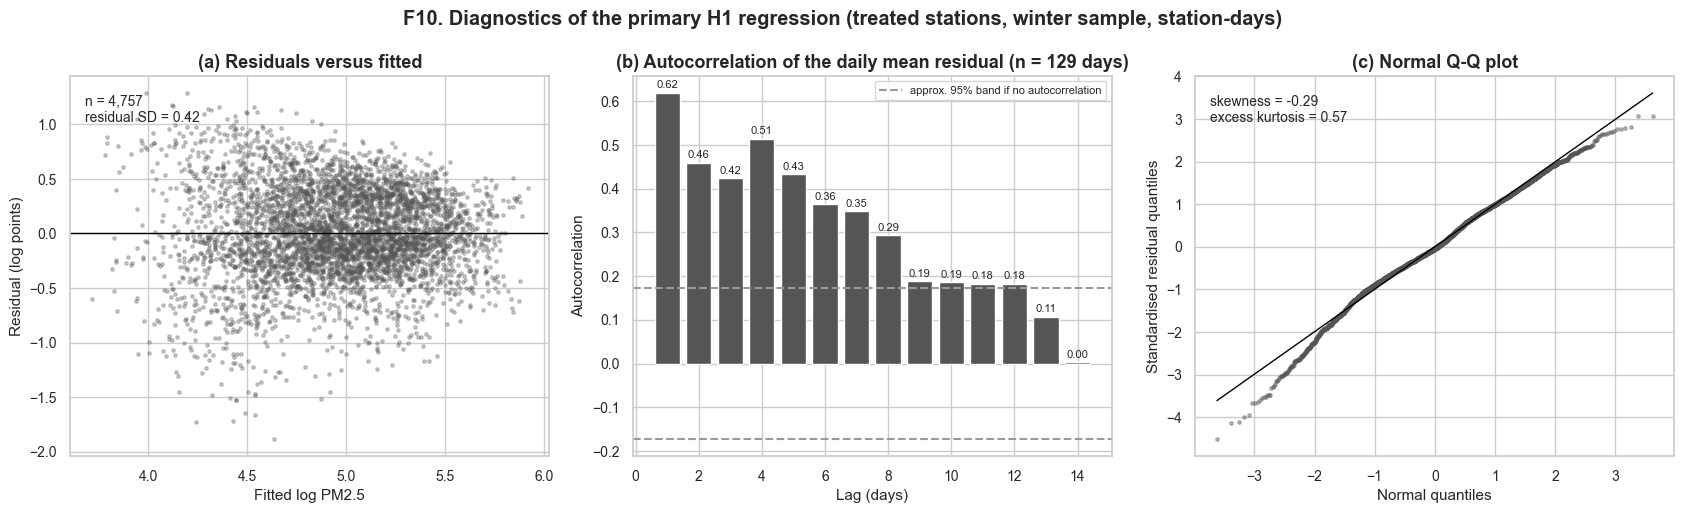

In [121]:
# Step 8.5b: F10 three diagnostic panels
from scipy import stats as sps
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
axes[0].scatter(diag["fitted"], diag["resid"], s=6, alpha=0.3, color="#555555")
axes[0].axhline(0, color="black", lw=1)
axes[0].set(xlabel="Fitted log PM2.5", ylabel="Residual (log points)", title="(a) Residuals versus fitted")
axes[0].text(0.03, 0.95, f"n = {len(diag):,}\nresidual SD = {diag['resid'].std():.2f}", transform=axes[0].transAxes, va="top", fontsize=10)
band = 1.96 / np.sqrt(daily_resid.size)
bars = axes[1].bar(acf_table["lag"], acf_table["acf"], color="#555555")
axes[1].axhline(band, color="#999999", ls="--"); axes[1].axhline(-band, color="#999999", ls="--", label="approx. 95% band if no autocorrelation")
axes[1].bar_label(bars, labels=[f"{v:.2f}" for v in acf_table["acf"]], fontsize=8, padding=2)
axes[1].set(xlabel="Lag (days)", ylabel="Autocorrelation", title=f"(b) Autocorrelation of the daily mean residual (n = {daily_resid.size} days)"); axes[1].legend(fontsize=8)
(osm, osr), (slope, intercept, r_qq) = sps.probplot(diag["resid"] / diag["resid"].std(), dist="norm")
axes[2].scatter(osm, osr, s=6, alpha=0.4, color="#555555"); axes[2].plot(osm, slope * np.array(osm) + intercept, color="black", lw=1)
axes[2].set(xlabel="Normal quantiles", ylabel="Standardised residual quantiles", title="(c) Normal Q-Q plot")
axes[2].text(0.03, 0.95, f"skewness = {sps.skew(diag['resid']):.2f}\nexcess kurtosis = {sps.kurtosis(diag['resid']):.2f}", transform=axes[2].transAxes, va="top", fontsize=10)
fig.suptitle("F10. Diagnostics of the primary H1 regression (treated stations, winter sample, station-days)", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F10_h1_diagnostics"); plt.show()

In [122]:
# Step 8.5c: variance inflation factors of the fire variable and the controls (how much each overlaps with the others)
cols = terms
vif = {}
for col in cols:
    others = [c for c in cols if c != col]
    A = np.column_stack([np.ones(len(used)), used[others].to_numpy()])
    r2 = 1 - ((used[col].to_numpy() - A @ np.linalg.lstsq(A, used[col].to_numpy(), rcond=None)[0]) ** 2).sum() / ((used[col] - used[col].mean()) ** 2).sum()
    vif[col] = 1 / (1 - r2)
vif_table = pd.Series(vif, name="VIF").sort_values(ascending=False).round(1).to_frame()
display(vif_table)
save_table(vif_table, "T04c_h1_vif")

,VIF
t2m_c,5.4
sp_hpa,3.4
blh_m,2.8
rh_pct,2.2
wind_dir_sin,2.0
wind_speed,1.9
wind_dir_cos,1.8
tp_mm,1.6
n_up_nh_100km_45deg_lag1,1.4


saved table : T04c_h1_vif


In [123]:
# Step 8.5d: influence of single dates: refit without each date and see how far the fire effect (% per +5) moves
y_arr, X_arr = y_fit.to_numpy().ravel(), X_fit.to_numpy()
col_index = list(X_fit.columns).index(FIRE)
date_of_row = primary_frame.loc[X_fit.index, "date_ist"].to_numpy()
leave_out = {}
for d in np.unique(date_of_row):
    keep = date_of_row != d
    leave_out[pd.Timestamp(d)] = pct(EFFECT_UNIT, np.linalg.lstsq(X_arr[keep], y_arr[keep], rcond=None)[0][col_index])
leave_out = pd.Series(leave_out, name="effect without this date (%)")
influence = (leave_out - primary_effect).abs().sort_values(ascending=False).head(5)
display(pd.DataFrame({"Effect without the date (%)": leave_out[influence.index].round(1), "Change from the full estimate (points)": (leave_out[influence.index] - primary_effect).round(1)}))
print(f"Dropping any single date moves the effect between {leave_out.min():+.1f}% and {leave_out.max():+.1f}% (full estimate {primary_effect:+.1f}%)")

,Effect without the date (%),Change from the full estimate (points)
2025-12-03,12.3,2.8
2026-01-24,7.1,-2.4
2025-11-12,7.9,-1.6
2026-01-23,8.2,-1.4
2026-01-27,10.5,0.9


Dropping any single date moves the effect between +7.1% and +12.3% (full estimate +9.5%)


In [124]:
# Step 8.5e: takeaway text for the diagnostics
worst = vif_table["VIF"].idxmax()
show_takeaway(
    f"**What we learn:** the lag-1 autocorrelation of the daily mean residual is **{acf_table.loc[0, 'acf']:.2f}**, which is why standard errors are clustered by date. "
    f"The largest variance inflation factor is **{vif_table['VIF'].max():.1f}** (for *{worst}*); the VIF of the fire variable is **{vif_table.loc[FIRE, 'VIF']:.1f}**. "
    f"No single date moves the fire effect outside **{leave_out.min():+.1f}% to {leave_out.max():+.1f}%**."
)

**What we learn:** the lag-1 autocorrelation of the daily mean residual is **0.62**, which is why standard errors are clustered by date. The largest variance inflation factor is **5.4** (for *t2m_c*); the VIF of the fire variable is **1.4**. No single date moves the fire effect outside **+7.1% to +12.3%**.

*F10. Diagnostics of the primary H1 regression: (a) residuals against fitted values; (b) autocorrelation of the daily mean residual at lags 1 to 14 with the approximate 95% band expected under no autocorrelation; (c) normal Q-Q plot of the standardised residuals. Treated stations, winter sample, station-days; n is given in each panel. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** Whether the residuals (the part of log PM2.5 the model does not explain) look like noise. Panel (a) should be a patternless cloud around zero, panel (b) shows how much of a day's unexplained part carries over to the next days, and panel (c) shows whether very large errors are more common than a bell curve would give. The tables show which controls overlap with each other (VIF) and how much the fire estimate depends on any single date.

**What it does not show.** Passing a diagnostic does not make the model right: autocorrelation in the residuals is the reason for the clustered standard errors, not a defect we have fixed. A high VIF for a weather control means its own coefficient is unstable; it does not invalidate the fire estimate, whose VIF is shown separately.

## 8.6 Prediction: how much do fires add beyond weather? (F11, T08)

**Question (RQ1):** if we predict daily PM2.5 for *unseen* days, how much better does a model with fires do than one with weather only?
**Design (frozen):** train on 19 Feb to 31 Dec 2025, test on 1 Jan to 30 Sep 2026; the specification is never chosen on the test period. **Four models:** (1) *climatology*: the average PM2.5 of the same calendar month in the training period (January has no training data, so the overall training mean is used); (2) *persistence*: yesterday's PM2.5 at the same station; (3) *weather only*: the H1 regression without fire; (4) *weather and fire*: the H1 regression. All four are scored on the **same** test rows. **Scores:** RMSE and MAE in ug/m3 (lower is better) and R-squared (higher is better).

In [125]:
# Step 8.6a: the prediction frame: all treated station-days (all seasons), with yesterday's PM2.5 for the persistence baseline
pred_frame = h1_frame(analysis_station_day, winter=False)
yesterday = pred_frame[["station_id", "date_ist", "pm25_day"]].copy()
yesterday["date_ist"] = yesterday["date_ist"] + pd.Timedelta(days=1)                   # a value of day d becomes "yesterday" on day d+1
pred_frame = pred_frame.merge(yesterday.rename(columns={"pm25_day": "pm25_yesterday"}), on=["station_id", "date_ist"], how="left")

needed = ["log_pm25", FIRE, "pm25_yesterday"] + CONTROLS.split(" + ")
pred_frame = pred_frame.dropna(subset=needed).copy()                                    # every model is scored on rows where all inputs exist
train = pred_frame[pred_frame["date_ist"] <= TRAIN_END]
test = pred_frame[(pred_frame["date_ist"] >= TEST_START) & pred_frame["station_id"].isin(train["station_id"].unique())].copy()
print(f"Training rows {len(train):,} ({train['date_ist'].min():%d %b %Y} to {train['date_ist'].max():%d %b %Y}) | test rows {len(test):,} ({test['date_ist'].min():%d %b %Y} to {test['date_ist'].max():%d %b %Y})")

Training rows 9,715 (21 Feb 2025 to 31 Dec 2025) | test rows 7,412 (01 Jan 2026 to 30 Sep 2026)


In [126]:
# Step 8.6b: fit the two regression models on the training period and predict the test period (back-transformed to ug/m3)
predictions = {}
month_mean = train.groupby(train["date_ist"].dt.month)["pm25_day"].mean()              # climatology by calendar month
predictions["Climatology (month)"] = test["date_ist"].dt.month.map(month_mean).fillna(train["pm25_day"].mean()).to_numpy()
predictions["Persistence (yesterday)"] = test["pm25_yesterday"].to_numpy()
for label, terms_used in [("Weather only", CONTROLS), ("Weather and fire", f"{FIRE} + {CONTROLS}")]:
    f_pred = f"log_pm25 ~ {terms_used} + C(station_id) + C(weekday)"
    y_tr, X_tr = patsy.dmatrices(f_pred, train, return_type="dataframe")
    fit_tr = OLS(y_tr, X_tr).fit()
    smear = np.exp(fit_tr.resid).mean()                                                  # correction for back-transforming a log model
    X_te = patsy.build_design_matrices([X_tr.design_info], test, return_type="dataframe")[0]
    predictions[label] = np.exp(X_te.to_numpy() @ fit_tr.params.to_numpy()) * smear
actual = test["pm25_day"].to_numpy()
print({k: round(float(np.mean(v)), 1) for k, v in predictions.items()}, "| mean actual:", round(float(actual.mean()), 1))

{'Climatology (month)': 59.6, 'Persistence (yesterday)': 66.0, 'Weather only': 81.3, 'Weather and fire': 80.8} | mean actual: 65.3


In [127]:
# Step 8.6c: scores of the four models on the same test rows, and the gain from adding fire to the weather-only model
rows = []
for label, pred in predictions.items():
    err = actual - pred
    rows.append({"Model": label, "RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)),
                 "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2)})
scores = pd.DataFrame(rows).set_index("Model")
display(scores.round(2))
save_table(scores.round(3), "T08_prediction_scores")
gain = scores.loc["Weather only", "RMSE"] - scores.loc["Weather and fire", "RMSE"]
print(f"RMSE gain from adding fire to weather: {gain:+.2f} ug/m3 ({gain / scores.loc['Weather only', 'RMSE'] * 100:+.1f}%) on {len(test):,} test station-days from {test['date_ist'].nunique()} dates")

,RMSE,MAE,R2
Model,,,
Climatology (month),32.38,22.40,0.39
Persistence (yesterday),25.34,16.85,0.62
Weather only,43.91,28.29,-0.13
Weather and fire,43.01,27.88,-0.08


saved table : T08_prediction_scores
RMSE gain from adding fire to weather: +0.91 ug/m3 (+2.1%) on 7,412 test station-days from 224 dates


In [128]:
# Step 8.6d: uncertainty of the gain: block bootstrap over test dates (blocks of consecutive days), same draws as everywhere else
test_dates = np.sort(test["date_ist"].unique())
sse = {k: pd.Series((actual - v) ** 2).groupby(test["date_ist"].to_numpy()).sum().reindex(test_dates).to_numpy() for k, v in predictions.items()}
count = pd.Series(1, index=test.index).groupby(test["date_ist"]).sum().reindex(test_dates).to_numpy()
rng = np.random.default_rng(SEED)
n_d = len(test_dates)
starts = rng.integers(0, n_d - BLOCK_DAYS + 1, size=(BOOTSTRAP_DRAWS, int(np.ceil(n_d / BLOCK_DAYS))))
idx = (starts[:, :, None] + np.arange(BLOCK_DAYS)).reshape(BOOTSTRAP_DRAWS, -1)[:, :n_d]
rmse_boot = {k: np.sqrt(v[idx].sum(axis=1) / count[idx].sum(axis=1)) for k, v in sse.items()}
gain_boot = rmse_boot["Weather only"] - rmse_boot["Weather and fire"]
gain_low, gain_high = np.percentile(gain_boot, [2.5, 97.5])
print(f"Gain {gain:+.2f} ug/m3, 95% block-bootstrap interval {gain_low:+.2f} to {gain_high:+.2f}; share of draws in which fire helps: {(gain_boot > 0).mean() * 100:.0f}%")

Gain +0.91 ug/m3, 95% block-bootstrap interval +0.37 to +1.40; share of draws in which fire helps: 100%


saved figure: F11_prediction


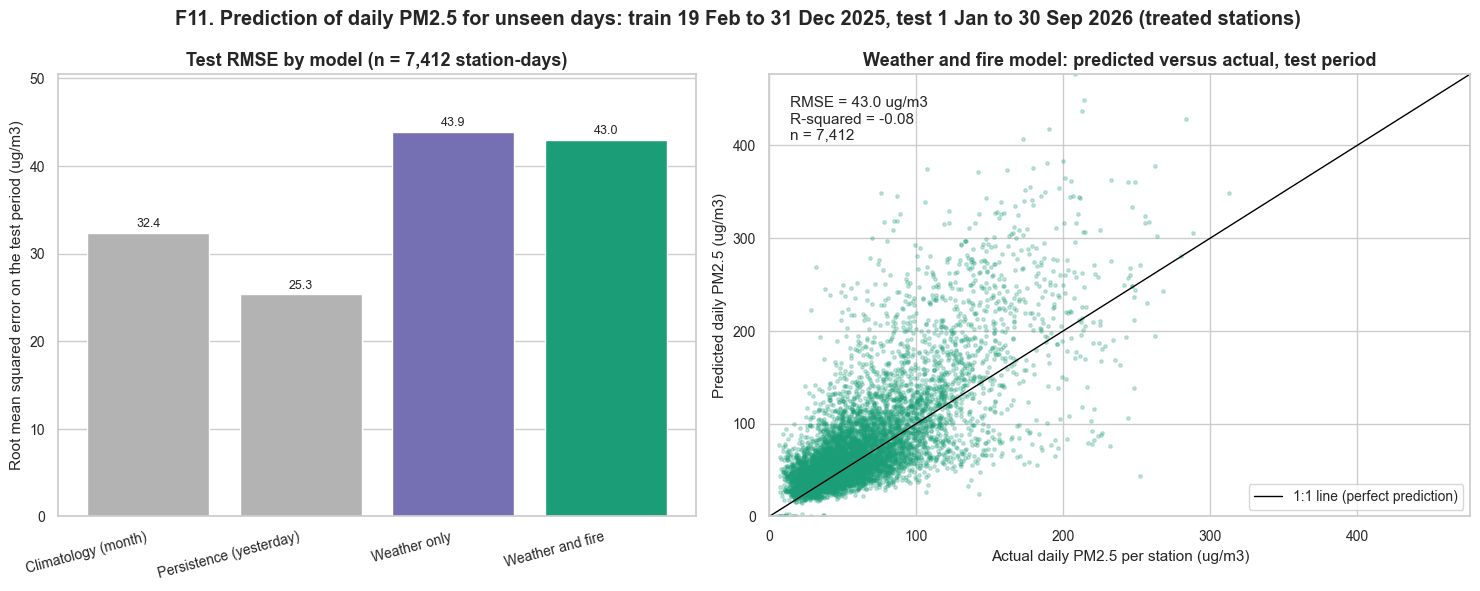

In [129]:
# Step 8.6e: F11 left: RMSE by model (value on every bar); right: predicted versus actual for the weather-and-fire model with the 1:1 line
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.1]})
bars = ax.bar(scores.index, scores["RMSE"], color=["#B3B3B3", "#B3B3B3", "#7570B3", "#1B9E77"])
label_bars(ax, bars, "{:.1f}")
ax.set_ylim(0, scores["RMSE"].max() * 1.15); ax.grid(axis="x", visible=False); plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
ax.set_ylabel("Root mean squared error on the test period (ug/m3)")
ax.set_title(f"Test RMSE by model (n = {len(test):,} station-days)")
ax2.scatter(actual, predictions["Weather and fire"], s=6, alpha=0.25, color="#1B9E77")
top = max(actual.max(), predictions["Weather and fire"].max())
ax2.plot([0, top], [0, top], color="black", lw=1, label="1:1 line (perfect prediction)")
ax2.set(xlabel="Actual daily PM2.5 per station (ug/m3)", ylabel="Predicted daily PM2.5 (ug/m3)", xlim=(0, top), ylim=(0, top), title="Weather and fire model: predicted versus actual, test period")
ax2.text(0.03, 0.95, f"RMSE = {scores.loc['Weather and fire', 'RMSE']:.1f} ug/m3\nR-squared = {scores.loc['Weather and fire', 'R2']:.2f}\nn = {len(test):,}", transform=ax2.transAxes, va="top", fontsize=11)
ax2.legend(loc="lower right"); fig.suptitle("F11. Prediction of daily PM2.5 for unseen days: train 19 Feb to 31 Dec 2025, test 1 Jan to 30 Sep 2026 (treated stations)", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F11_prediction"); plt.show()

In [130]:
# Step 8.6f: monthly RMSE of the weather-and-fire model in the test period (kept for the monitoring chart in Phase 10)
test_scored = test.assign(pred_fire=predictions["Weather and fire"], pred_weather=predictions["Weather only"])
test_scored["month_label"] = test_scored["date_ist"].dt.strftime("%Y-%m")
monthly_rmse = test_scored.groupby("month_label").apply(lambda g: pd.Series({"RMSE weather and fire": np.sqrt(np.mean((g["pm25_day"] - g["pred_fire"]) ** 2)),
                                                                           "RMSE weather only": np.sqrt(np.mean((g["pm25_day"] - g["pred_weather"]) ** 2)), "Station-days": len(g)})).round(2)
display(monthly_rmse)
save_table(monthly_rmse, "T08b_monthly_rmse")
show_takeaway(
    f"**What we learn:** on **{len(test):,}** unseen station-days the weather-only model has an RMSE of **{scores.loc['Weather only', 'RMSE']:.1f} ug/m3** and the weather-and-fire model **{scores.loc['Weather and fire', 'RMSE']:.1f}**: "
    f"adding fire changes the error by **{gain:+.2f} ug/m3** (95% interval **{gain_low:+.2f} to {gain_high:+.2f}**). The best baseline is **{scores['RMSE'].idxmin()}** (RMSE {scores['RMSE'].min():.1f}); "
    f"the R-squared of the weather-and-fire model is **{scores.loc['Weather and fire', 'R2']:.2f}**."
)

,RMSE weather and fire,RMSE weather only,Station-days
month_label,,,
2026-01,109.06,111.94,695.0
2026-02,39.59,39.18,646.0
2026-03,33.56,34.27,898.0
2026-04,42.81,44.25,952.0
2026-05,23.38,23.22,860.0
2026-06,18.58,18.95,741.0
2026-07,16.17,16.19,816.0
2026-08,13.67,13.65,838.0
2026-09,24.49,24.34,966.0


saved table : T08b_monthly_rmse


**What we learn:** on **7,412** unseen station-days the weather-only model has an RMSE of **43.9 ug/m3** and the weather-and-fire model **43.0**: adding fire changes the error by **+0.91 ug/m3** (95% interval **+0.37 to +1.40**). The best baseline is **Persistence (yesterday)** (RMSE 25.3); the R-squared of the weather-and-fire model is **-0.08**.

In [131]:
# Step 8.6g: ADDED AFTER SEEING RESULTS (diagnostic only; not used for any decision): scores without January 2026, and why January is hard
after_january = (test["date_ist"] >= pd.Timestamp("2026-02-01")).to_numpy()
rows = []
for label, pred in predictions.items():
    err = (actual - pred)[after_january]
    rows.append({"Model": label, "RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)), "R2": 1 - np.sum(err ** 2) / np.sum((actual[after_january] - actual[after_january].mean()) ** 2)})
scores_no_jan = pd.DataFrame(rows).set_index("Model")
display(scores_no_jan.round(2)); save_table(scores_no_jan.round(3), "T08c_prediction_scores_without_january")

in_jan = ~after_january
coldest_train_month = train.groupby(train["date_ist"].dt.month)["t2m_c"].mean().min()
show_takeaway(
    f"**What we learn (added after seeing results):** without January the RMSE is **{scores_no_jan.loc['Weather only', 'RMSE']:.1f}** for weather only and **{scores_no_jan.loc['Weather and fire', 'RMSE']:.1f}** for weather and fire, "
    f"against **{scores_no_jan.loc['Persistence (yesterday)', 'RMSE']:.1f}** for persistence. In January 2026 the weather-and-fire model predicted **{predictions['Weather and fire'][in_jan].mean():.0f} ug/m3** on average against "
    f"**{actual[in_jan].mean():.0f}** observed: January was colder (**{test.loc[in_jan, 't2m_c'].mean():.1f} deg C**) than any month of the training period (the coldest averaged **{coldest_train_month:.1f} deg C**), "
    f"so the regression had to extrapolate beyond the conditions it was trained on."
)

,RMSE,MAE,R2
Model,,,
Climatology (month),25.46,18.90,0.33
Persistence (yesterday),21.21,14.46,0.53
Weather only,28.83,21.09,0.14
Weather and fire,28.47,20.90,0.16


saved table : T08c_prediction_scores_without_january


**What we learn (added after seeing results):** without January the RMSE is **28.8** for weather only and **28.5** for weather and fire, against **21.2** for persistence. In January 2026 the weather-and-fire model predicted **215 ug/m3** on average against **142** observed: January was colder (**12.3 deg C**) than any month of the training period (the coldest averaged **14.4 deg C**), so the regression had to extrapolate beyond the conditions it was trained on.

*F11. Left: test RMSE of four models (value on each bar). Right: predicted versus actual daily PM2.5 for the weather-and-fire model with the 1:1 line; RMSE, R-squared and n are written on the plot. Treated stations, trained on 19 Feb to 31 Dec 2025 and tested on 1 Jan to 30 Sep 2026 (IST). Source: `final_dataset.parquet` via the station-day table.*

### 8.8 What this means (RQ1: how much do fires add beyond weather?)

**What it shows.** Adding the fire count to the weather model lowers the test error a little, and the bootstrap interval says how sure we can be about the size of that gain. **But both regression models predict unseen days worse than the simple baselines** (negative R-squared; persistence is best), and the monthly table shows that the error is concentrated in the winter months, above all January 2026.

**Why (diagnostic added after seeing results).** The training period ends in December and has no January, so the models had never seen conditions as cold as January 2026 and over-predicted. This is a limit of the frozen time-blocked split with a single winter. The extra table shows scores without January, for information only: it is not used in any decision and does not replace the frozen test.

**What it does not show.** The test period (January to September 2026) contains no autumn burning season, so it is a hard test for a fire effect that matters mostly in autumn. The models use same-day weather and previous-day fires and say nothing about forecasting days ahead. An expanding-window check is not run because the data cover under two years.

## 8.7 Robustness (T04g, F9)

**Question:** does the sign of the fire effect survive the 20 robustness runs listed in Phase 7 (T07d)?
**Common scale:** because the runs use different fire variables, every effect is expressed as the **% change in PM2.5 per +1 SD of that run's fire variable**, so that all runs share one axis. The interval is the date-clustered 95% interval (the decision interval of the primary run is the wider one, shown in 8.4).

In [132]:
# Step 8.7a: helper functions for the robustness runs (defined once here)
def add_fields(day_table):
    # Attach the daily weather, fire, noon stage and calendar fields (built in Phase 4) to a table of station-day PM2.5 values
    keys = ["station_id", "date_ist"]
    return (day_table.merge(station_info, on="station_id").merge(daily_weather, on=keys).merge(daily_fire, on=keys)
                     .merge(noon, on=keys).merge(calendar, on=keys))

def fit_h1(frame, predictor, fe="C(station_id) + C(weekday)", extra="", both=True):
    # One H1 regression; the effect is the % change in PM2.5 per +1 SD of the predictor (so that different predictors share one scale)
    formula_run = f"log_pm25 ~ {predictor} + {CONTROLS}{extra} + {fe}"
    by_date = cluster_ols(formula_run, frame, "date_ist")
    rows_used = frame.loc[by_date.model.data.row_labels]
    sd = rows_used[predictor].std()
    ci = by_date.conf_int().loc[predictor].to_numpy()
    out = {"effect": pct(sd, by_date.params[predictor]), "low": pct(sd, ci[0]), "high": pct(sd, ci[1]), "n": int(by_date.nobs), "dates": rows_used["date_ist"].nunique()}
    if both:
        out["station_low"], out["station_high"] = pct(sd, cluster_ols(formula_run, frame, "station_id").conf_int().loc[predictor].to_numpy())
    return out
primary_run = fit_h1(primary_frame, FIRE)
print("Primary run per +1 SD:", {k: round(float(v), 1) for k, v in primary_run.items() if k in ("effect", "low", "high")})

Primary run per +1 SD: {'effect': 9.5, 'low': 1.4, 'high': 18.3}


In [133]:
# Step 8.7b: data for the runs that need new frames: interpolated short gaps, and the 12 and 20 hour validity rules
hourly = df.sort_values(["station_id", "hour_ist"]).copy()
is_valid = hourly["pm25"].notna() & ~hourly["network_outage"]
run_id = (is_valid != is_valid.groupby(hourly["station_id"]).shift()).cumsum()                 # consecutive hours with the same validity
gap_len = (~is_valid).groupby(run_id).transform("sum")                                         # length of each missing run
gap_outage = hourly["network_outage"].groupby(run_id).transform("max")                         # does the run touch an outage?
short_gap = (~is_valid) & (gap_len <= 3) & (~gap_outage)                                       # only short gaps that are not outages
filled = hourly["pm25"].where(is_valid).groupby(hourly["station_id"]).transform(lambda s: s.interpolate(limit_area="inside"))
hourly_interp = hourly.assign(pm25=np.where(short_gap, filled, hourly["pm25"].where(is_valid)))
filled_hours = short_gap & filled.notna()                                                    # gaps at the very start or end of a series stay empty
print("Hours filled by interpolation:", int(filled_hours.sum()), "| as share of missing hours:", round(filled_hours.sum() / (~is_valid).sum() * 100, 1), "%")

frame_interp = h1_frame(add_fields(valid_station_day(hourly_interp.assign(network_outage=False), 18)))
frame_12, frame_20 = h1_frame(add_fields(station_day_12)), h1_frame(add_fields(station_day_20))
print("Station-days: interpolated", len(frame_interp), "| 12 h rule", len(frame_12), "| 20 h rule", len(frame_20), "| primary", len(primary_frame))

Hours filled by interpolation: 10496 | as share of missing hours: 10.4 %
Station-days: interpolated 4821 | 12 h rule 5207 | 20 h rule 4618 | primary 4794


In [134]:
# Step 8.7c: the placebo frame (fire of the NEXT day, which cannot cause today's PM2.5) and the frames of the remaining runs
future_fire = daily_fire[["station_id", "date_ist", FIRE]].copy()
future_fire["date_ist"] = future_fire["date_ist"] - pd.Timedelta(days=2)       # the value on date d+2 describes the fires of day d+1
primary_with_future = primary_frame.merge(future_fire.rename(columns={FIRE: "fire_next_day"}), on=["station_id", "date_ist"], how="left")
primary_with_future.index = primary_frame.index                                  # keep the row labels of the primary frame

full_window_frame, control_frame = h1_frame(analysis_station_day, winter=False), h1_frame(analysis_station_day, group="control")
runs_spec = {   # name in the plan (T07d): (frame, predictor, fe terms, extra terms)
    "interpolate gaps of up to 3 hours instead of dropping": (frame_interp, FIRE, "C(station_id) + C(weekday)", ""),
    "drop preliminary (NRT) fire rows": (primary_frame[~primary_frame["fire_is_nrt"].astype(bool)], FIRE, "C(station_id) + C(weekday)", ""),
    "drop days after satellite-outage fire days": (primary_frame[primary_frame["fire_day_status"] == "observed"], FIRE, "C(station_id) + C(weekday)", ""),
    "12-hour validity rule": (frame_12, FIRE, "C(station_id) + C(weekday)", ""),
    "20-hour validity rule": (frame_20, FIRE, "C(station_id) + C(weekday)", ""),
    "full window instead of the winter sample": (full_window_frame, FIRE, "C(station_id) + C(weekday)", ""),
    "add month fixed effects": (primary_frame, FIRE, "C(station_id) + C(weekday) + C(month)", ""),
    "add GRAP stage as a control": (primary_frame, FIRE, "C(station_id) + C(weekday)", " + stage_max"),
}
print(len(runs_spec), "runs defined so far")

8 runs defined so far


In [135]:
# Step 8.7c2: the remaining runs (fire variables, placebo, comparison sample, leave out one sub-area)
runs_spec.update({
    "fire radiative power instead of counts": (primary_frame, "frp_up_nh_100km_45deg_lag1", "C(station_id) + C(weekday)", ""),
    "all-direction count, 50 km": (primary_frame, "n_nh_50km_lag1", "C(station_id) + C(weekday)", ""),
    "all-direction count, 100 km": (primary_frame, "n_nh_100km_lag1", "C(station_id) + C(weekday)", ""),
    "all-direction count, 200 km": (primary_frame, "n_nh_200km_lag1", "C(station_id) + C(weekday)", ""),
    "all-direction 100 km count of the previous two days": (primary_frame, "n_nh_100km_lag2", "C(station_id) + C(weekday)", ""),
    "placebo: next day's fire (expected about zero)": (primary_with_future, "fire_next_day", "C(station_id) + C(weekday)", ""),
    "control cities only (comparison sample)": (control_frame, FIRE, "C(station_id) + C(weekday)", ""),
})
for area in ["Delhi", "Ghaziabad", "Noida", "Gurugram"]:
    runs_spec[f"leave out {area}"] = (primary_frame[primary_frame["sub_area"] != area], FIRE, "C(station_id) + C(weekday)", "")
print(len(runs_spec), "runs defined (plus the leave-one-station-out run)")

19 runs defined (plus the leave-one-station-out run)


In [136]:
# Step 8.7d: run everything in the order of the plan (T07d); leave-one-station-out is one run whose range is reported
results = {"PRIMARY: upwind count, winter sample, station fixed effects": {**primary_run, "note": ""}}
planned = [r for r in h1_runs if not r.startswith("PRIMARY")]
for name in planned:
    if name == "leave one station out (all stations, range reported)":
        effects = [fit_h1(primary_frame[primary_frame["station_id"] != s], FIRE, both=False)["effect"] for s in primary_frame["station_id"].unique()]
        results[name] = {"effect": float(np.median(effects)), "low": float(np.min(effects)), "high": float(np.max(effects)), "n": int(primary_run["n"]),
                         "dates": int(primary_run["dates"]), "note": f"range over {len(effects)} runs"}
    else:
        frame_run, predictor, fe_terms, extra_terms = runs_spec[name]
        results[name] = {**fit_h1(frame_run, predictor, fe_terms, extra_terms, both=False), "note": ""}
robust = pd.DataFrame(results).T
robust["effect"], robust["low"], robust["high"] = robust["effect"].astype(float), robust["low"].astype(float), robust["high"].astype(float)
robust["Same sign as primary"] = np.sign(robust["effect"]) == np.sign(robust.loc[robust.index[0], "effect"])
robust.index.name = "Run"
print(len(robust) - 1, "robustness runs completed")

20 robustness runs completed


In [137]:
# Step 8.7e: the robustness table T04g and the agreement count (the frozen rule counts all robustness runs)
robust_only = robust.iloc[1:]
same_rows = (robust["n"].astype(int) == int(primary_run["n"])) & np.isclose(robust["effect"], robust["effect"].iloc[0], atol=0.05) & (robust["note"] == "")
same_rows.iloc[0] = False                                                        # the primary itself is not flagged
robust.loc[same_rows, "note"] = "identical to the primary: no such rows in this sample"
agree_all = int(robust_only["Same sign as primary"].sum())
agree_share = agree_all / len(robust_only)
core = robust_only[~robust_only.index.str.startswith(("placebo", "control cities"))]; core_agree = int(core["Same sign as primary"].sum())      # the same definition as in 8.7g
agree_text = f"{agree_all} of {len(robust_only)} ({agree_share:.0%}) including the placebo and the control-city run; {core_agree} of {len(core)} excluding them"
shown = robust[["effect", "low", "high", "n", "dates", "Same sign as primary", "note"]].copy()
shown[["effect", "low", "high"]] = shown[["effect", "low", "high"]].round(1)
display(shown)
save_table(shown, "T04g_h1_robustness")
print(f"Same sign as the primary effect in {agree_text}; the frozen rule needs {ROBUST_AGREE_SHARE:.0%} of all runs")

,effect,low,high,n,dates,Same sign as primary,note
Run,,,,,,,
"PRIMARY: upwind count, winter sample, station fixed effects",9.5,1.4,18.3,4757,129,True,
interpolate gaps of up to 3 hours instead of dropping,9.6,1.5,18.5,4784,129,True,
drop preliminary (NRT) fire rows,9.5,1.4,18.3,4757,129,True,identical to the primary: no such rows in this...
drop days after satellite-outage fire days,9.5,1.4,18.3,4757,129,True,identical to the primary: no such rows in this...
12-hour validity rule,11.2,3.1,20.1,5169,135,True,
20-hour validity rule,10.1,1.7,19.2,4586,126,True,
full window instead of the winter sample,3.3,-0.2,6.9,18801,530,True,
add month fixed effects,5.5,-0.9,12.3,4757,129,True,
add GRAP stage as a control,6.2,1.4,11.3,4757,129,True,


saved table : T04g_h1_robustness
Same sign as the primary effect in 20 of 20 (100%) including the placebo and the control-city run; 18 of 18 excluding them; the frozen rule needs 75% of all runs


saved figure: F9_h1_robustness_forest


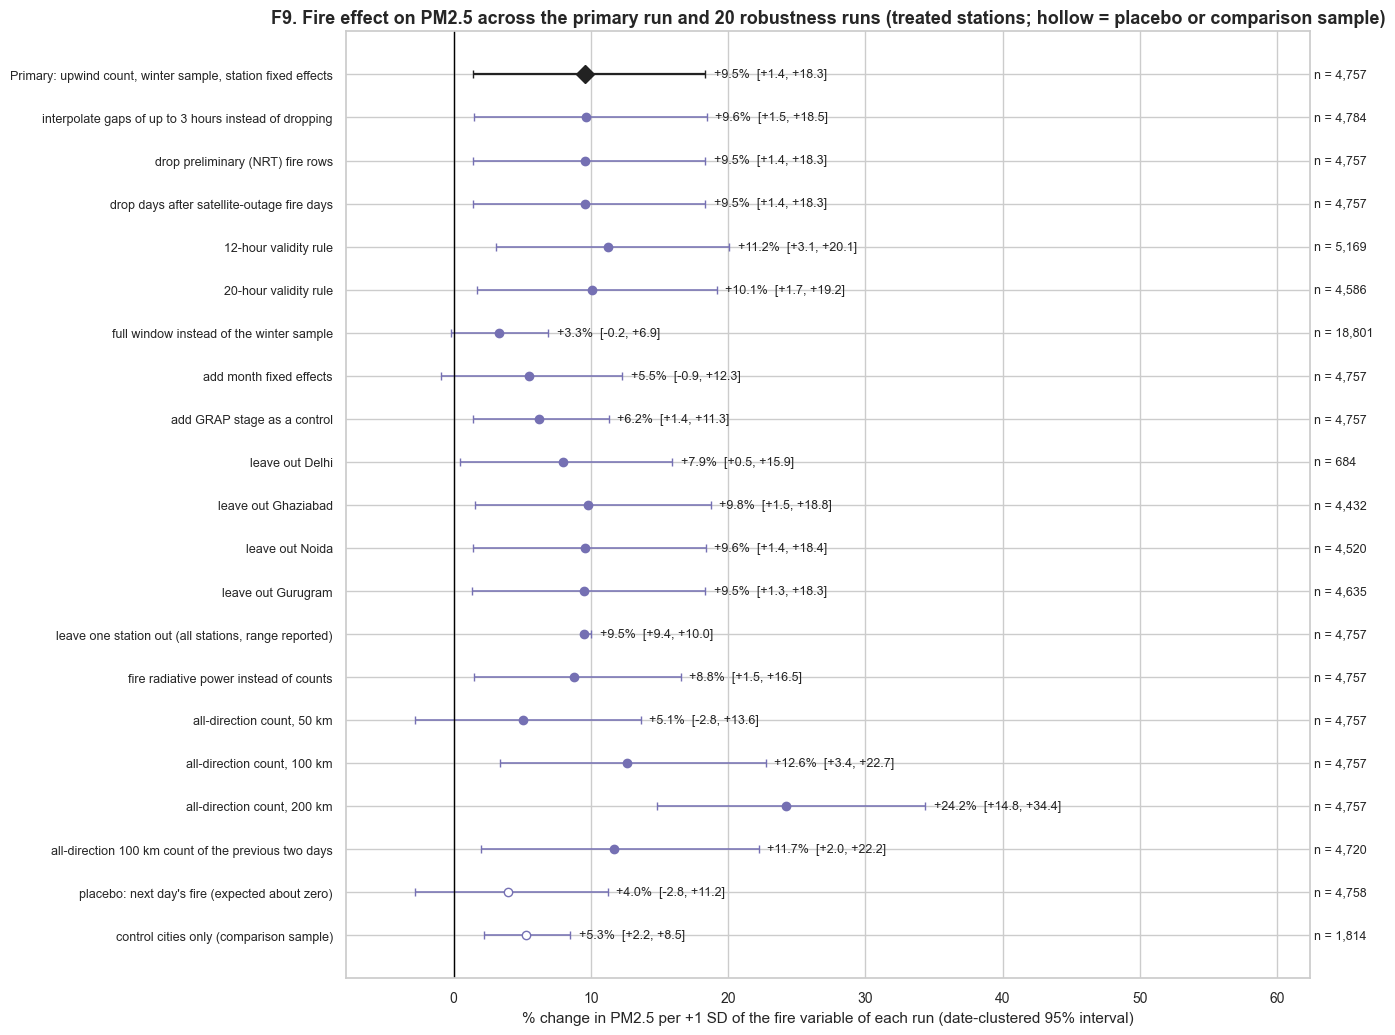

In [138]:
# Step 8.7f: F9 forest plot: estimate and interval written next to each marker, one common axis, n on the right, zero line
fig, ax = plt.subplots(figsize=(14, 10.5))
y_pos = np.arange(len(robust))[::-1]
for y, (name, row) in zip(y_pos, robust.iterrows()):
    is_primary, special = name.startswith("PRIMARY"), name.startswith(("placebo", "control cities"))
    ax.errorbar(row["effect"], y, xerr=[[row["effect"] - row["low"]], [row["high"] - row["effect"]]], fmt="D" if is_primary else "o", ms=9 if is_primary else 6,
                color="#222222" if is_primary else "#7570B3", mfc="white" if special else None, capsize=3, lw=1.6 if is_primary else 1.1)
    ax.annotate(f"{row['effect']:+.1f}%  [{row['low']:+.1f}, {row['high']:+.1f}]", (row["high"], y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
    ax.text(1.005, y, f"n = {int(row['n']):,}", transform=ax.get_yaxis_transform(), va="center", fontsize=9)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(y_pos); ax.set_yticklabels([n.replace("PRIMARY: ", "Primary: ") for n in robust.index], fontsize=9)
ax.set_xlabel("% change in PM2.5 per +1 SD of the fire variable of each run (date-clustered 95% interval)"); ax.set_xlim(robust["low"].min() - 5, robust["high"].max() + 28)
ax.set_title(f"F9. Fire effect on PM2.5 across the primary run and {len(robust_only)} robustness runs (treated stations; hollow = placebo or comparison sample)")
plt.tight_layout(); save_fig(fig, "F9_h1_robustness_forest"); plt.show()

In [139]:
# Step 8.7g: takeaway text: agreement, the placebo, and the range of the other runs
placebo = robust.loc["placebo: next day's fire (expected about zero)"]
core = robust_only[~robust_only.index.str.startswith(("placebo", "control cities"))]
show_takeaway(
    f"**What we learn:** the effect has the same sign as the primary in **{agree_text}**. The placebo (next day's fire, which cannot affect today's PM2.5) gives **{placebo['effect']:+.1f}%** "
    f"[{placebo['low']:+.1f}, {placebo['high']:+.1f}], which is **{placebo['effect'] / robust.iloc[0]['effect']:.0%}** of the primary effect per SD: a future fire cannot cause today's PM2.5, so a positive placebo points to **seasonal confounding** (fire counts and PM2.5 share a seasonal rhythm). The other runs range from **{core['effect'].min():+.1f}%** to **{core['effect'].max():+.1f}%** per SD; "
    f"**{int((core['low'] > 0).sum())}** of {len(core)} have an interval above zero."
)

**What we learn:** the effect has the same sign as the primary in **20 of 20 (100%) including the placebo and the control-city run; 18 of 18 excluding them**. The placebo (next day's fire, which cannot affect today's PM2.5) gives **+4.0%** [-2.8, +11.2], which is **41%** of the primary effect per SD: a future fire cannot cause today's PM2.5, so a positive placebo points to **seasonal confounding** (fire counts and PM2.5 share a seasonal rhythm). The other runs range from **+3.3%** to **+24.2%** per SD; **15** of 18 have an interval above zero.

*F9. Estimated change in PM2.5 per +1 SD of the fire variable in the primary run (diamond) and in each robustness run (circles), with the date-clustered 95% interval; the number and interval are written beside each marker, and n on the right. Hollow markers are the placebo (next day's fire) and the control-city comparison. The leave-one-station-out run shows the median and the range over all runs. Winter sample unless stated; treated stations unless stated. Source: `final_dataset.parquet`.*

**What it shows.** How the fire effect changes when the sample, the fire variable, the controls or the validity rule is changed. Points to the right of the zero line mean higher PM2.5 with more fire.

**What it does not show.** The runs are not independent: they reuse the same winter and mostly the same stations, so agreement across many runs is much weaker evidence than the same number of independent studies. Runs marked *identical to the primary* (dropping preliminary fire rows, keeping only observed fire days) change nothing because this winter sample contains no such rows; they stay in the table because they were planned. The **placebo** (next day's fire) is expected to be near zero, but fire counts are strongly correlated from one day to the next, so it is not a clean test; and having the same sign as the primary counts for the frozen rule exactly like any other run.

In [140]:
# Step 8.8: the three frozen criteria for H1 evaluated on the results above (the formal status table is built in Phase 10)
criteria = pd.DataFrame([
    {"Criterion (frozen in Phase 7)": f"Primary effect above 0 with the decision interval excluding 0", "Observed": f"{primary_effect:+.1f}% [{decision_low:+.1f}, {decision_high:+.1f}]", "Met": decision_low > 0},
    {"Criterion (frozen in Phase 7)": f"Same sign in at least {ROBUST_AGREE_SHARE:.0%} of robustness runs", "Observed": agree_text, "Met": agree_share >= ROBUST_AGREE_SHARE},
    {"Criterion (frozen in Phase 7)": "Fire model has a lower test error than the weather-only model", "Observed": f"RMSE gain {gain:+.2f} ug/m3 [{gain_low:+.2f}, {gain_high:+.2f}]" + (f"; both models are less accurate than {scores['RMSE'].idxmin()}" if scores.loc["Weather and fire", "RMSE"] > scores["RMSE"].min() else ""), "Met": gain > 0},
]).set_index("Criterion (frozen in Phase 7)")
display(criteria)
save_table(criteria, "T04h_h1_criteria")
show_takeaway(f"**What we learn:** **{int(criteria['Met'].sum())} of 3** frozen criteria are met by the results above. The status of H1 is assigned with the full rules in Phase 10.")

,Observed,Met
Criterion (frozen in Phase 7),,
Primary effect above 0 with the decision interval excluding 0,"+9.5% [+1.4, +18.3]",True
Same sign in at least 75% of robustness runs,20 of 20 (100%) including the placebo and the ...,True
Fire model has a lower test error than the weather-only model,"RMSE gain +0.91 ug/m3 [+0.37, +1.40]; both mod...",True


saved table : T04h_h1_criteria


**What we learn:** **3 of 3** frozen criteria are met by the results above. The status of H1 is assigned with the full rules in Phase 10.

In [141]:
# Step 8.9: summary of the H1 evidence, every number taken from the cells above
month_fe, full_w = robust.loc["add month fixed effects"], robust.loc["full window instead of the winter sample"]
r200, r50 = robust.loc["all-direction count, 200 km"], robust.loc["all-direction count, 50 km"]
ctl = robust.loc["control cities only (comparison sample)"]
def zero_text(row):
    return "includes zero" if row["low"] < 0 < row["high"] else "excludes zero"
points = [
    f"**Association (primary run).** {primary_effect:+.1f}% PM2.5 per +{EFFECT_UNIT} upwind detections on the previous day; decision interval {decision_low:+.1f}% to {decision_high:+.1f}% ({'excludes' if decision_low > 0 else 'includes'} zero).",
    f"**Timing.** The lag correlations are between {allfire['Correlation'].min():+.2f} and {allfire['Correlation'].max():+.2f} at every lag, and the same-day correlation is as high as lag 1: they show a shared seasonal pattern, not that fires come first.",
    f"**Season.** With month effects the estimate is {month_fe['effect']:+.1f}% [{month_fe['low']:+.1f}, {month_fe['high']:+.1f}] ({zero_text(month_fe)}); over the full window {full_w['effect']:+.1f}% [{full_w['low']:+.1f}, {full_w['high']:+.1f}] ({zero_text(full_w)}). Part of the association is therefore shared seasonal movement that the weather controls do not remove.",
    f"**Placebo.** Next day's fire gives {placebo['effect']:+.1f}% [{placebo['low']:+.1f}, {placebo['high']:+.1f}], about {placebo['effect'] / robust['effect'].iloc[0]:.0%} of the primary effect (fire counts are correlated across days, so it is not a clean zero).",
    f"**Distance.** Per SD, all-direction fires within 200 km are associated with {r200['effect']:+.1f}% against {r50['effect']:+.1f}% within 50 km: this suggests that fires further from the station carry more of the association than the nearest ones.",
    f"**Other cities.** In the control cities the same upwind variable gives {ctl['effect']:+.1f}% [{ctl['low']:+.1f}, {ctl['high']:+.1f}].",
    f"**Prediction.** Adding fire lowers the test error by {gain:+.2f} ug/m3, but both regression models are less accurate than {scores['RMSE'].idxmin()} (RMSE {scores['RMSE'].min():.1f} against {scores.loc['Weather and fire', 'RMSE']:.1f}).",
    f"**Frozen criteria.** {int(criteria['Met'].sum())} of 3 are met; the formal status is assigned in Phase 10.",
]
show_takeaway("**What we learn: the H1 evidence in one list**\n\n" + "\n".join(f"- {point}" for point in points))

**What we learn: the H1 evidence in one list**

- **Association (primary run).** +9.5% PM2.5 per +5 upwind detections on the previous day; decision interval +1.4% to +18.3% (excludes zero).
- **Timing.** The lag correlations are between +0.33 and +0.39 at every lag, and the same-day correlation is as high as lag 1: they show a shared seasonal pattern, not that fires come first.
- **Season.** With month effects the estimate is +5.5% [-0.9, +12.3] (includes zero); over the full window +3.3% [-0.2, +6.9] (includes zero). Part of the association is therefore shared seasonal movement that the weather controls do not remove.
- **Placebo.** Next day's fire gives +4.0% [-2.8, +11.2], about 41% of the primary effect (fire counts are correlated across days, so it is not a clean zero).
- **Distance.** Per SD, all-direction fires within 200 km are associated with +24.2% against +5.1% within 50 km: this suggests that fires further from the station carry more of the association than the nearest ones.
- **Other cities.** In the control cities the same upwind variable gives +5.3% [+2.2, +8.5].
- **Prediction.** Adding fire lowers the test error by +0.91 ug/m3, but both regression models are less accurate than Persistence (yesterday) (RMSE 25.3 against 43.0).
- **Frozen criteria.** 3 of 3 are met; the formal status is assigned in Phase 10.

## 8.9 What H1 does and does not show

**In plain units.** After accounting for weather, days following more upwind fire detections within 100 km tend to have higher PM2.5; the size is in 8.4 and the list above. *Associated with* means that the two move together once the weather in the model is held fixed. It does not say that the fires made the extra PM2.5.

**What H1 does not show.**
- **Timing.** The lag analysis does not show that fires come before the pollution; it shows a shared seasonal rhythm.
- **One winter.** The estimate rests on a single winter and one autumn; it is imprecise, shrinks when seasonal effects are added, and says nothing about other years.
- **Fires within 100 km only.** Fire counts near Delhi peak in April and May, not in the autumn (Phase 6). The larger association for the 200 km count suggests that fires further away matter more, but smoke from the main stubble-burning areas and any station there are outside this data.
- **A proxy for smoke.** Satellite pixels are not tonnes of smoke, and clouds hide fires.
- **Overlapping controls.** Temperature, pressure and boundary-layer height are related (see the VIF table), so their coefficients should not be read one by one.
- **Prediction.** The regression models did not beat simple baselines on unseen days, so the notebook does not support using them for forecasting.

*Inconclusive is a valid result.* The report will describe how far the frozen criteria are met and where the evidence is weak.

---
# Phase 8B: H1 in depth: size, shape, where it holds, and how much fires add
*BADIR: **A**nalysis and **I**nsights.* This phase goes deeper on the two H1 questions of the project:

- **Q1.** How big is the association between upwind fires and PM2.5 once weather is controlled? (8B.1 to 8B.5)
- **Q2.** How much do fires add beyond weather? (8B.6 to 8B.9)

**Every analysis in this phase is an extension ADDED AFTER SEEING RESULTS.** It cannot change the frozen status of H1 (Phase 10 applies the Phase 7 rules to the frozen runs only), every run is listed in table `T07d2`, and nothing here introduces a new decision rule. Subgroup tables state how many subgroups were examined. The first pass left these open points: the primary effect (+9.5% per +5 detections) falls to +5.5% with month effects, the lag correlations show no timing, and fire adds only about 2% to prediction while both regressions lose to persistence.

In [142]:
# Step 8B.0: the register of extension runs (table T07d2), appended to in every cell of Phases 8B and 9B
extension_runs = []

def log_extension(cell, description):
    # record one extension analysis (the register is saved at the end of 8B and again at the end of 9B)
    extension_runs.append({"Cell": cell, "Added after seeing results": True, "Description": description})

def unit_effect(frame, formula_text, term=FIRE, cluster="date_ist", unit=EFFECT_UNIT):
    # % change in PM2.5 per +unit of `term` for a regression formula, with a 95% interval clustered by `cluster`
    res = cluster_ols(formula_text, frame, cluster)
    b, (low, high) = res.params[term], res.conf_int().loc[term]
    rows_used = frame.loc[res.model.data.row_labels]
    return {"effect": float(pct(unit, b)), "low": float(pct(unit, low)), "high": float(pct(unit, high)), "n": int(res.nobs),
            "dates": int(rows_used["date_ist"].nunique())}, res
base_effect, _ = unit_effect(primary_frame, formula)
print("Check: the helper reproduces the primary effect per +5:", round(base_effect["effect"], 2), "%, interval", round(base_effect["low"], 2), "to", round(base_effect["high"], 2))
assert abs(base_effect["effect"] - primary_effect) < 1e-6, "helper does not reproduce the Phase 8 estimate"

Check: the helper reproduces the primary effect per +5: 9.53 %, interval 1.4 to 18.32


## 8B.1 Dose-response: is the association a straight line? (F18)

**Question:** is "+9.5% per +5 detections" a straight line, or is it carried by a few days with very many fires?
**Method:** replace the linear fire term by **bins** of the upwind count (0, 1 to 2, 3 to 5, 6 to 10, above 10), with the same controls and effects and the same date-clustered intervals; the reference bin is **0 detections**. A quadratic term tests whether the line bends. **Look for:** whether the effect rises step by step with the bin, and how many station-days each bin holds.

In [143]:
# Step 8B.1a: ADDED AFTER SEEING RESULTS: bins of the upwind fire count and the number of station-days in each
dose_frame = used.copy()                                                    # the station-days of the primary fit (all variables present)
dose_labels = ["0", "1-2", "3-5", "6-10", ">10"]
dose_frame["fire_bin"] = pd.cut(dose_frame[FIRE], bins=[-0.5, 0.5, 2.5, 5.5, 10.5, 1e9], labels=dose_labels)
bin_counts = dose_frame["fire_bin"].value_counts().reindex(dose_labels)
bin_means = dose_frame.groupby("fire_bin", observed=True)[FIRE].mean().reindex(dose_labels)
display(pd.DataFrame({"Station-days": bin_counts, "Mean count in the bin": bin_means.round(1)}))
log_extension("8B.1", "dose-response: effect of the upwind fire count by bin (0, 1-2, 3-5, 6-10, >10) and a quadratic term")

,Station-days,Mean count in the bin
fire_bin,,
0,1334,0.0
1-2,1121,1.5
3-5,1061,3.9
6-10,699,7.8
>10,542,15.2


In [144]:
# Step 8B.1b: effect of each bin against zero detections (% change in PM2.5), and the test of a straight line (quadratic term)
dose_formula = f"log_pm25 ~ C(fire_bin, Treatment(reference='0')) + {CONTROLS} + C(station_id) + C(weekday)"
dose_fit = cluster_ols(dose_formula, dose_frame, "date_ist")
rows = [{"Bin": "0", "Effect (%)": 0.0, "CI low": 0.0, "CI high": 0.0, "Station-days": int(bin_counts["0"])}]
for label in dose_labels[1:]:
    name = [n for n in dose_fit.params.index if n.endswith(f"[T.{label}]")][0]
    b, (lo, hi) = dose_fit.params[name], dose_fit.conf_int().loc[name]
    rows.append({"Bin": label, "Effect (%)": np.expm1(b) * 100, "CI low": np.expm1(lo) * 100, "CI high": np.expm1(hi) * 100, "Station-days": int(bin_counts[label])})
dose_table = pd.DataFrame(rows).set_index("Bin")
quad_fit = cluster_ols(f"log_pm25 ~ {FIRE} + I({FIRE} ** 2) + {CONTROLS} + C(station_id) + C(weekday)", dose_frame, "date_ist")
quad_name = [n for n in quad_fit.params.index if "** 2" in n][0]
dose_table["Straight-line prediction (%)"] = [float(pct(bin_means[b], fit_date.params[FIRE])) for b in dose_table.index]
display(dose_table.round(1))
save_table(dose_table.round(2), "T04l_dose_response")
print(f"Quadratic term: coefficient {quad_fit.params[quad_name]:.5f}, p = {quad_fit.pvalues[quad_name]:.3f} (date-clustered)")

,Effect (%),CI low,CI high,Station-days,Straight-line prediction (%)
Bin,,,,,
0,0.0,0.0,0.0,1334,0.0
1-2,17.0,-5.6,45.2,1121,2.7
3-5,15.0,-6.6,41.5,1061,7.4
6-10,23.0,-2.5,55.3,699,15.3
>10,48.8,11.6,98.3,542,31.9


saved table : T04l_dose_response
Quadratic term: coefficient -0.00064, p = 0.470 (date-clustered)


saved figure: F18_dose_response


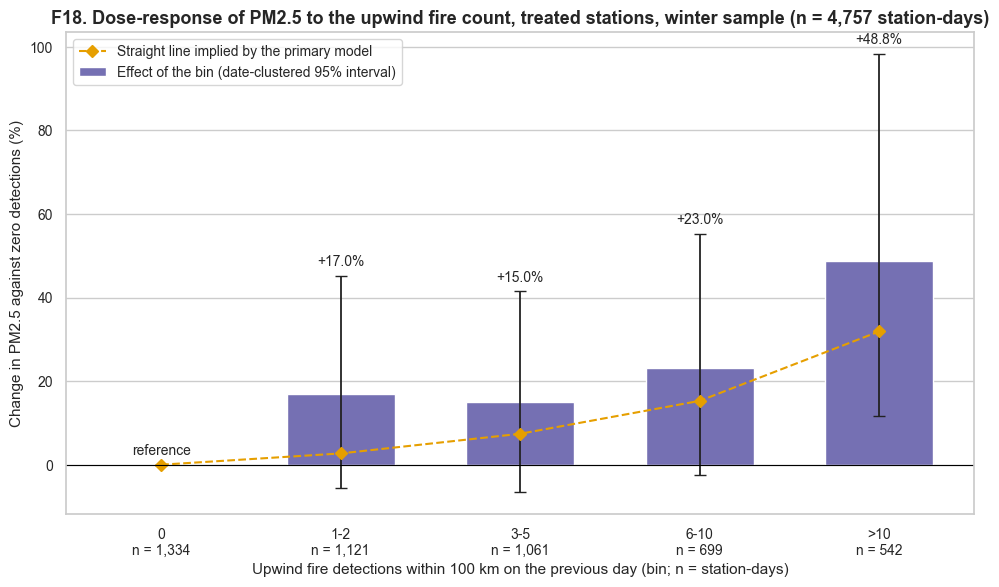

In [145]:
# Step 8B.1c: F18 effect by fire bin with intervals; the value and the number of station-days are written on every bar
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(dose_table))
bars = ax.bar(x, dose_table["Effect (%)"], color="#7570B3", width=0.6, label="Effect of the bin (date-clustered 95% interval)")
low_err = np.maximum(dose_table["Effect (%)"] - dose_table["CI low"], 0); high_err = np.maximum(dose_table["CI high"] - dose_table["Effect (%)"], 0)
ax.errorbar(x, dose_table["Effect (%)"], yerr=[low_err, high_err], fmt="none", ecolor="#222222", capsize=4, lw=1.3)
ax.plot(x, dose_table["Straight-line prediction (%)"], "D--", color="#E69F00", label="Straight line implied by the primary model")
for xi, row in zip(x, dose_table.itertuples()):
    ax.annotate(f"{row[1]:+.1f}%" if xi else "reference", (xi, max(row[3], row[1])), ha="center", va="bottom", fontsize=10, xytext=(0, 5), textcoords="offset points")
ax.set_xticks(x); ax.set_xticklabels([f"{b}\nn = {int(n):,}" for b, n in zip(dose_table.index, dose_table["Station-days"])])
ax.axhline(0, color="black", lw=0.8); ax.grid(axis="x", visible=False)
ax.set_xlabel("Upwind fire detections within 100 km on the previous day (bin; n = station-days)"); ax.set_ylabel("Change in PM2.5 against zero detections (%)")
ax.set_title(f"F18. Dose-response of PM2.5 to the upwind fire count, treated stations, winter sample (n = {len(dose_frame):,} station-days)")
ax.legend(loc="upper left"); plt.tight_layout(); save_fig(fig, "F18_dose_response"); plt.show()

In [146]:
# Step 8B.1d: takeaway text for the dose-response
increasing = bool(dose_table["Effect (%)"].iloc[1:].is_monotonic_increasing)
top_bin = dose_table.index[-1]
show_takeaway(
    f"**What we learn:** against days with no upwind fires, days with **1 to 2** detections have **{dose_table.loc['1-2', 'Effect (%)']:+.1f}%** higher PM2.5 and days with **more than 10** have "
    f"**{dose_table.loc[top_bin, 'Effect (%)']:+.1f}%** (interval {dose_table.loc[top_bin, 'CI low']:+.1f}% to {dose_table.loc[top_bin, 'CI high']:+.1f}%, **{int(dose_table.loc[top_bin, 'Station-days'])}** station-days). "
    f"The bin effects {'rise with the bin' if increasing else 'do not rise steadily with the bin'}. The quadratic term has p = **{quad_fit.pvalues[quad_name]:.2f}**, "
    f"so there is {'evidence' if quad_fit.pvalues[quad_name] < 0.05 else 'no clear evidence'} that the relation bends away from a straight line."
)

**What we learn:** against days with no upwind fires, days with **1 to 2** detections have **+17.0%** higher PM2.5 and days with **more than 10** have **+48.8%** (interval +11.6% to +98.3%, **542** station-days). The bin effects do not rise steadily with the bin. The quadratic term has p = **0.47**, so there is no clear evidence that the relation bends away from a straight line.

*F18. Change in PM2.5 for each bin of the upwind fire count against zero detections (bars, with 95% intervals clustered by date) and the straight line implied by the primary model (dashed diamonds). Treated stations, winter sample (1 Oct 2025 to 28 Feb 2026), station-days; n is written under each bin. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** The shape of the relation: if the association were a straight line the bars would follow the dashed line; if it were carried by a few extreme days only the last bin would stand out.

**What it does not show.** The bins are defined by counts at one station on one day, so the top bin holds few days and its interval is wide. A rising pattern is still an association: days with many fires differ from days with none in other ways that the weather controls only partly remove. The bins use the same one winter as everything else.

## 8B.2 Where does the association hold? (F19, T04i)

**Question:** is the fire association the same across the season, across places and across weather regimes?
**Method:** the primary model is fitted **separately in each subgroup** (effect per +5 detections, date-clustered interval), and an **interaction test** in the pooled sample asks whether the effect differs between the two subgroups of each dimension. **Five dimensions are examined (ten subgroups); a difference is claimed only when the interval of the interaction excludes zero.** Dimensions: part of the season (Oct to Nov against Dec to Feb), sub-area (Delhi against Ghaziabad, Noida and Gurugram), wind speed (below or above its median), boundary-layer height (below or above its median) and wind direction (from the north-west quadrant against other directions).

In [147]:
# Step 8B.2a: ADDED AFTER SEEING RESULTS: the five dimensions and their two subgroups (A, B)
het = used.copy()                                                           # the station-days of the primary fit
median_wind, median_blh = het["wind_speed"].median(), het["blh_m"].median()
dimensions = {
    "Season part": (het["month"].isin([10, 11]), "Oct to Nov", "Dec to Feb"),
    "Sub-area": (het["sub_area"] == "Delhi", "Delhi", "Ghaziabad, Noida, Gurugram"),
    "Wind speed": (het["wind_speed"] <= median_wind, f"At or below the median ({median_wind:.1f} m/s)", "Above the median"),
    "Boundary-layer height": (het["blh_m"] <= median_blh, f"At or below the median ({median_blh:.0f} m)", "Above the median"),
    "Wind from": (het["wind_from_deg"].between(270, 360), "North-west quadrant", "Other directions"),
}
print({name: (int(mask.sum()), int((~mask).sum())) for name, (mask, a, b) in dimensions.items()}, "station-days in subgroups A and B")
log_extension("8B.2", "heterogeneity: fire effect in 10 subgroups (5 dimensions) with interaction tests")

{'Season part': (2079, 2678), 'Sub-area': (4073, 684), 'Wind speed': (2388, 2369), 'Boundary-layer height': (2390, 2367), 'Wind from': (3617, 1140)} station-days in subgroups A and B


In [148]:
# Step 8B.2b: effect per +5 detections in each subgroup (separate fits) and the interaction test in the pooled sample
het_rows = []
for dim, (mask_a, label_a, label_b) in dimensions.items():
    het["group_b"] = (~mask_a).astype(float)                                   # 1 for subgroup B
    sub_a, _ = unit_effect(het[mask_a], formula); sub_b, _ = unit_effect(het[~mask_a], formula)
    main = "" if dim == "Sub-area" else " + group_b"                           # a group that is constant within a station is absorbed by the station effects
    inter = cluster_ols(f"log_pm25 ~ {FIRE} + {FIRE}:group_b{main} + {CONTROLS} + C(station_id) + C(weekday)", het, "date_ist")
    name = [n for n in inter.params.index if ":" in n][0]
    diff, ci = inter.params[name] * EFFECT_UNIT * 100, inter.conf_int().loc[name].to_numpy() * EFFECT_UNIT * 100
    for label, sub in [(label_a, sub_a), (label_b, sub_b)]:
        het_rows.append({"Dimension": dim, "Subgroup": label, "Station-days": sub["n"], "Effect per +5 (%)": sub["effect"], "CI low": sub["low"], "CI high": sub["high"],
                         "B minus A (points)": diff, "Diff CI low": ci[0], "Diff CI high": ci[1], "Difference detected": bool(ci[0] > 0 or ci[1] < 0)})
het_table = pd.DataFrame(het_rows)
display(het_table.round(1))
save_table(het_table.set_index("Dimension").round(2), "T04i_h1_heterogeneity")

,Dimension,Subgroup,Station-days,Effect per +5 (%),CI low,CI high,B minus A (points),Diff CI low,Diff CI high,Difference detected
0,Season part,Oct to Nov,2079,2.7,-8.0,14.6,-4.0,-16.5,8.5,False
1,Season part,Dec to Feb,2678,6.9,-0.3,14.7,-4.0,-16.5,8.5,False
2,Sub-area,Delhi,4073,9.7,1.5,18.6,-1.3,-3.6,1.0,False
3,Sub-area,"Ghaziabad, Noida, Gurugram",684,8.6,0.5,17.3,-1.3,-3.6,1.0,False
4,Wind speed,At or below the median (2.0 m/s),2388,4.7,-4.5,14.8,-5.9,-18.1,6.2,False
5,Wind speed,Above the median,2369,10.8,-0.1,22.8,-5.9,-18.1,6.2,False
6,Boundary-layer height,At or below the median (268 m),2390,5.4,-1.2,12.5,13.0,1.0,25.1,True
7,Boundary-layer height,Above the median,2367,14.7,-1.2,33.3,13.0,1.0,25.1,True
8,Wind from,North-west quadrant,3617,9.5,1.6,18.1,1.0,-16.8,18.8,False
9,Wind from,Other directions,1140,0.4,-19.2,24.6,1.0,-16.8,18.8,False


saved table : T04i_h1_heterogeneity


saved figure: F19_h1_heterogeneity


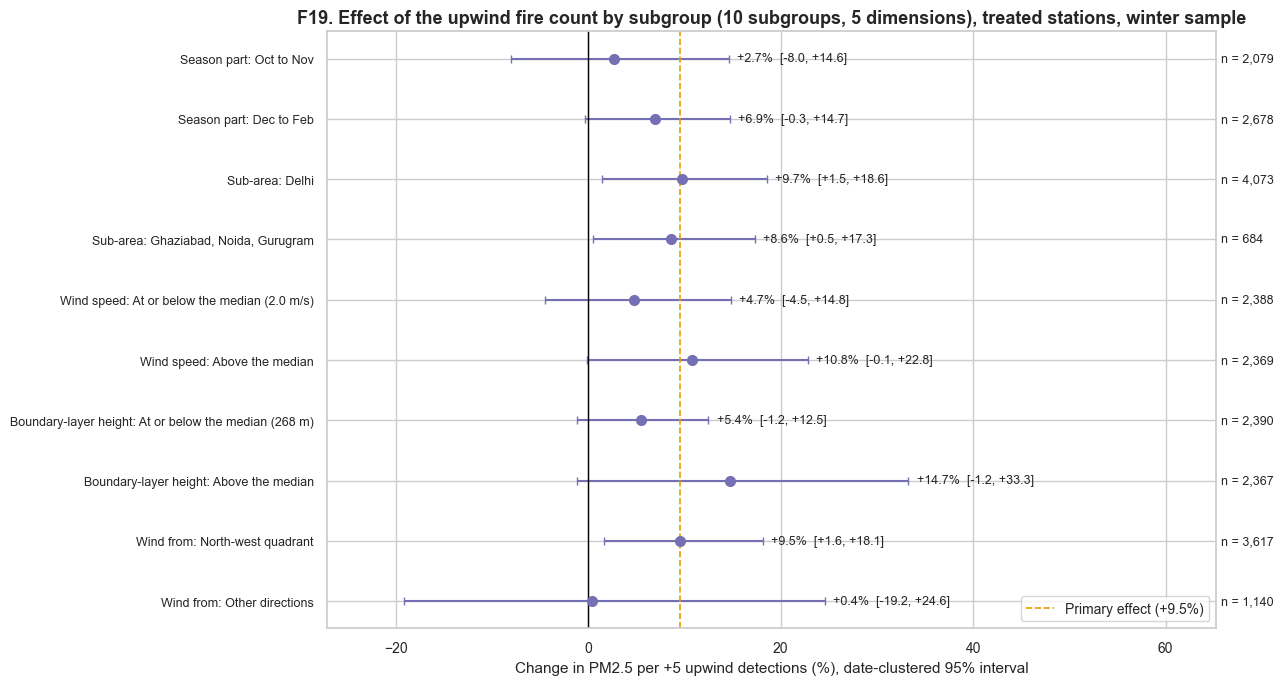

In [149]:
# Step 8B.2c: F19 forest plot of the effect per +5 in each subgroup; the effect, interval and n are written beside each marker
fig, ax = plt.subplots(figsize=(13, 7))
y_pos = np.arange(len(het_table))[::-1]
for y, row in zip(y_pos, het_table.itertuples()):
    ax.errorbar(row[4], y, xerr=[[row[4] - row[5]], [row[6] - row[4]]], fmt="o", color="#7570B3", capsize=3, ms=7)
    ax.annotate(f"{row[4]:+.1f}%  [{row[5]:+.1f}, {row[6]:+.1f}]", (row[6], y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
    ax.text(1.005, y, f"n = {row[3]:,}", transform=ax.get_yaxis_transform(), va="center", fontsize=9)
ax.axvline(0, color="black", lw=1); ax.axvline(primary_effect, color="#E69F00", ls="--", lw=1.2, label=f"Primary effect ({primary_effect:+.1f}%)")
ax.set_yticks(y_pos); ax.set_yticklabels([f"{d}: {s}" for d, s in zip(het_table["Dimension"], het_table["Subgroup"])], fontsize=9)
ax.set_xlabel("Change in PM2.5 per +5 upwind detections (%), date-clustered 95% interval"); ax.set_xlim(het_table["CI low"].min() - 8, het_table["CI high"].max() + 32)
ax.set_title("F19. Effect of the upwind fire count by subgroup (10 subgroups, 5 dimensions), treated stations, winter sample"); ax.legend(loc="lower right")
plt.tight_layout(); save_fig(fig, "F19_h1_heterogeneity"); plt.show()

In [150]:
# Step 8B.2d: takeaway text for the subgroups
detected = het_table[het_table["Difference detected"]].drop_duplicates("Dimension")
largest = het_table.loc[het_table["Effect per +5 (%)"].idxmax()]
show_takeaway(
    f"**What we learn:** the effect per +5 detections is positive in **{int((het_table['Effect per +5 (%)'] > 0).sum())}** of the **{len(het_table)}** subgroups, and its interval excludes zero in "
    f"**{int((het_table['CI low'] > 0).sum())}**. The largest is **{largest['Dimension'].lower()}: {largest['Subgroup'].lower()}** (**{largest['Effect per +5 (%)']:+.1f}%**, interval {largest['CI low']:+.1f}% to {largest['CI high']:+.1f}%). "
    f"A difference between the two subgroups of a dimension is detected in **{len(detected)}** of the 5 dimensions" + (f" ({', '.join(detected['Dimension'])})." if len(detected) else ".")
)

**What we learn:** the effect per +5 detections is positive in **10** of the **10** subgroups, and its interval excludes zero in **3**. The largest is **boundary-layer height: above the median** (**+14.7%**, interval -1.2% to +33.3%). A difference between the two subgroups of a dimension is detected in **1** of the 5 dimensions (Boundary-layer height).

*F19. Change in PM2.5 per +5 upwind detections for each of 10 subgroups (5 dimensions), with 95% intervals clustered by date; the dashed line is the primary effect. Treated stations, winter sample, station-days; n is on the right. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** Whether the association is a general feature of the winter data or is carried by one season part, one place or one weather regime. Differences are *claimed* only where the interaction interval (table T04i) excludes zero.

**What it does not show.** Ten subgroup estimates from one winter are exploratory: with this many comparisons one interval excluding zero can arise by chance, and subgroups share the same days. The intervals of small subgroups are wide. Splitting at the median is a convenient rule, not a physical threshold. A larger effect in a subgroup does not say *why* it is larger. The column "B minus A" in table T04i is the interaction coefficient from the pooled model, expressed approximately in percentage points per +5 detections; it can differ a little from the difference of the two separate estimates, because the pooled model shares the other controls.

In [151]:
# Step 8B.0b: helpers for the extension cells: design arrays, date-block bootstrap weights, weighted fit and weighted R-squared
def design_xy(formula_text, frame):
    # outcome and design matrix as plain arrays, plus the rows that were kept (patsy drops rows with missing values)
    y, X = patsy.dmatrices(formula_text, frame, return_type="dataframe")
    return y.to_numpy()[:, 0], X.to_numpy(), X.index

def date_weights(dates, draws=BOOTSTRAP_DRAWS, block=BLOCK_DAYS, seed=SEED):
    # date-block bootstrap as row weights: each draw gives a row the number of times its date was drawn (blocks of consecutive dates)
    order = np.sort(pd.unique(dates)); n = len(order)
    starts = np.random.default_rng(seed).integers(0, n - block + 1, size=(draws, int(np.ceil(n / block))))
    picked = (starts[:, :, None] + np.arange(block)).reshape(draws, -1)[:, :n]
    counts = np.stack([np.bincount(p, minlength=n) for p in picked])
    return counts[:, np.searchsorted(order, np.asarray(dates))].astype(np.float32)

def weighted_fit(X, y, w):
    s = np.sqrt(w)
    return np.linalg.lstsq(X * s[:, None], y * s, rcond=None)[0]

def weighted_r2(X, y, w):
    resid = y - X @ weighted_fit(X, y, w)
    return 1 - np.sum(w * resid ** 2) / np.sum(w * (y - np.average(y, weights=w)) ** 2)
y_chk2, X_chk2, _ = design_xy(formula, primary_frame)
print("Check: the weighted R-squared with weight 1 equals the model R-squared:", round(weighted_r2(X_chk2, y_chk2, np.ones(len(y_chk2))), 4), "=", round(fit_date.rsquared, 4))
assert np.isclose(weighted_r2(X_chk2, y_chk2, np.ones(len(y_chk2))), fit_date.rsquared)

Check: the weighted R-squared with weight 1 equals the model R-squared: 0.4646 = 0.4646


## 8B.3 Why does the association shrink with month effects? A ladder of specifications (F20)

**Question:** the primary effect falls when month effects are added in Phase 8 (the ladder below gives the numbers). Does the association survive when everything common to a month, a week or a whole day is removed?
**Method:** the same model with progressively stronger controls for time: station and weekday effects only (primary), plus **month** effects, plus **week** effects, plus **date** effects (each date has its own level, so the fire effect comes only from differences *between stations on the same day*). A second view splits each fire count into its **month mean** (the seasonal part, shared by all stations) and the **deviation** from that mean (the day-to-day part). **Look for:** whether the effect stays positive as time controls get stronger, and which part of the fire count carries it.

In [152]:
# Step 8B.3a: ADDED AFTER SEEING RESULTS: the ladder of time controls (effect per +5 detections, date-clustered intervals)
ladder_frame = used.copy()
ladder_frame["week_id"] = ((ladder_frame["date_ist"] - WINTER_START).dt.days // 7).astype(int)
ladder_specs = {"Station and weekday effects (primary)": "",
                "plus month effects": " + C(month)",
                "plus week effects": " + C(week_id)",
                "plus date effects (stations compared within each date)": " + C(date_ist)"}
rows = []
for label, extra in ladder_specs.items():
    weekday_term = "" if "date_ist" in extra else " + C(weekday)"                 # date effects already contain the day of week
    res_row, _ = unit_effect(ladder_frame, f"log_pm25 ~ {FIRE} + {CONTROLS} + C(station_id){weekday_term}{extra}")
    rows.append({"Specification": label, "Effect per +5 (%)": res_row["effect"], "CI low": res_row["low"], "CI high": res_row["high"], "Station-days": res_row["n"], "Dates": res_row["dates"]})
ladder_table = pd.DataFrame(rows).set_index("Specification")
display(ladder_table.round(1))
log_extension("8B.3", "season ladder: fire effect with month, week and date effects")

,Effect per +5 (%),CI low,CI high,Station-days,Dates
Specification,,,,,
Station and weekday effects (primary),9.5,1.4,18.3,4757,129
plus month effects,5.5,-0.9,12.3,4757,129
plus week effects,9.1,3.7,14.7,4757,129
plus date effects (stations compared within each date),1.7,-1.2,4.7,4757,129


In [153]:
# Step 8B.3b: ADDED AFTER SEEING RESULTS: split the fire count into its month mean (seasonal part) and the deviation from it (day-to-day part)
ladder_frame["fire_month_mean"] = ladder_frame.groupby("month")[FIRE].transform("mean")
ladder_frame["fire_deviation"] = ladder_frame[FIRE] - ladder_frame["fire_month_mean"]
wb_fit = cluster_ols(f"log_pm25 ~ fire_month_mean + fire_deviation + {CONTROLS} + C(station_id) + C(weekday)", ladder_frame, "date_ist")
wb_rows = []
for term, label in [("fire_month_mean", "Month mean of the fire count (seasonal part)"), ("fire_deviation", "Deviation from the month mean (day-to-day part)")]:
    b_term, (lo_term, hi_term) = wb_fit.params[term], wb_fit.conf_int().loc[term]
    wb_rows.append({"Part of the fire count": label, "Effect per +5 (%)": float(pct(EFFECT_UNIT, b_term)), "CI low": float(pct(EFFECT_UNIT, lo_term)), "CI high": float(pct(EFFECT_UNIT, hi_term))})
within_between = pd.DataFrame(wb_rows).set_index("Part of the fire count")
display(within_between.round(1))
ladder_save = pd.concat([ladder_table[["Effect per +5 (%)", "CI low", "CI high"]], within_between]).round(2)
save_table(ladder_save, "T04m_season_ladder")
log_extension("8B.3", "within-between split of the fire count (month mean and deviation)")

,Effect per +5 (%),CI low,CI high
Part of the fire count,,,
Month mean of the fire count (seasonal part),45.0,26.2,66.6
Deviation from the month mean (day-to-day part),3.4,-2.8,10.1


saved table : T04m_season_ladder


saved figure: F20_season_ladder


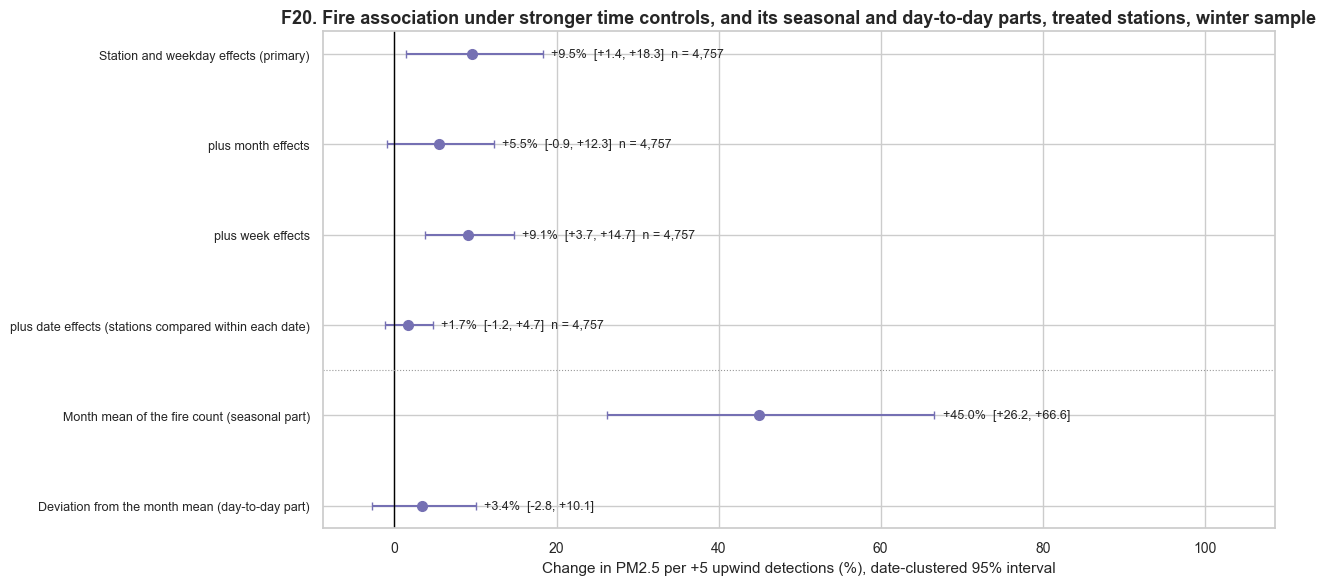

In [154]:
# Step 8B.3c: F20 forest plot of the ladder and the within-between split; effect, interval and n are written beside each marker
plot_rows = [(label, r["Effect per +5 (%)"], r["CI low"], r["CI high"], f"n = {int(r['Station-days']):,}") for label, r in ladder_table.iterrows()]
plot_rows += [(label, r["Effect per +5 (%)"], r["CI low"], r["CI high"], "") for label, r in within_between.iterrows()]
fig, ax = plt.subplots(figsize=(13, 6))
y_pos = np.arange(len(plot_rows))[::-1]
for y, (label, est, lo, hi, n_text) in zip(y_pos, plot_rows):
    ax.errorbar(est, y, xerr=[[est - lo], [hi - est]], fmt="o", color="#7570B3", capsize=3, ms=7)
    ax.annotate(f"{est:+.1f}%  [{lo:+.1f}, {hi:+.1f}]  {n_text}", (hi, y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax.axvline(0, color="black", lw=1); ax.axhline(1.5, color=GREY, lw=0.8, ls=":")
ax.set_yticks(y_pos); ax.set_yticklabels([r[0] for r in plot_rows], fontsize=9)
ax.set_xlim(min(r[2] for r in plot_rows) - 6, max(r[3] for r in plot_rows) + 42)
ax.set_xlabel("Change in PM2.5 per +5 upwind detections (%), date-clustered 95% interval")
ax.set_title("F20. Fire association under stronger time controls, and its seasonal and day-to-day parts, treated stations, winter sample")
plt.tight_layout(); save_fig(fig, "F20_season_ladder"); plt.show()

In [155]:
# Step 8B.3d: takeaway text for the ladder
first, last = ladder_table.iloc[0], ladder_table.iloc[-1]
dev, seas = within_between.loc["Deviation from the month mean (day-to-day part)"], within_between.loc["Month mean of the fire count (seasonal part)"]
show_takeaway(
    f"**What we learn:** the effect per +5 detections is **{first['Effect per +5 (%)']:+.1f}%** with station and weekday effects, **{ladder_table.iloc[1]['Effect per +5 (%)']:+.1f}%** with month effects, "
    f"**{ladder_table.iloc[2]['Effect per +5 (%)']:+.1f}%** with week effects and **{last['Effect per +5 (%)']:+.1f}%** (interval {last['CI low']:+.1f}% to {last['CI high']:+.1f}%) when only differences between stations on the same date are used. "
    f"The day-to-day part of the fire count carries **{dev['Effect per +5 (%)']:+.1f}%** (interval {dev['CI low']:+.1f}% to {dev['CI high']:+.1f}%) and the seasonal part **{seas['Effect per +5 (%)']:+.1f}%** (interval {seas['CI low']:+.1f}% to {seas['CI high']:+.1f}%). "
    f"The seasonal part {'is larger than' if seas['Effect per +5 (%)'] > dev['Effect per +5 (%)'] else 'is not larger than'} the day-to-day part, so the association {'is carried mostly by differences between months' if seas['Effect per +5 (%)'] > dev['Effect per +5 (%)'] and dev['CI low'] <= 0 else 'is also present from day to day'}."
)

**What we learn:** the effect per +5 detections is **+9.5%** with station and weekday effects, **+5.5%** with month effects, **+9.1%** with week effects and **+1.7%** (interval -1.2% to +4.7%) when only differences between stations on the same date are used. The day-to-day part of the fire count carries **+3.4%** (interval -2.8% to +10.1%) and the seasonal part **+45.0%** (interval +26.2% to +66.6%). The seasonal part is larger than the day-to-day part, so the association is carried mostly by differences between months.

*F20. Change in PM2.5 per +5 upwind detections (points, 95% intervals clustered by date) under four time controls and for the two parts of the fire count (month mean and deviation from it). Treated stations, winter sample (1 Oct 2025 to 28 Feb 2026), station-days; n is written for each model. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** How much of the association is *shared seasonal movement* (fires and PM2.5 both being higher in some months) and how much remains when that is removed. A date-effects model compares stations with each other on the same day, so any influence of weather or fires that is common to the whole region on that day is absorbed.

**What it does not show.** With date effects the estimate relies on differences in fire counts *between* stations on a day, which are smaller and partly reflect which direction each station sits relative to the smoke, so a smaller or wider estimate there is expected. These runs are chosen after seeing the first result; none changes the frozen status of H1. One winter cannot separate a seasonal fire effect from other seasonal changes.

## 8B.3b Is the primary interval robust to how the standard errors are built? (T04n)

**Question:** the frozen decision interval is the wider of the date-clustered and station-clustered intervals. Do other, equally defensible ways of building the interval give the same answer?
**Method (ADDED AFTER SEEING RESULTS; the frozen decision and status are not changed):** the primary coefficient with (i) **two-way clusters** (station and date, as in the earlier pass of the project), (ii) clusters by **ISO week**, and (iii) a **date-block bootstrap** that resamples blocks of 7 and of 14 consecutive dates (2,000 draws, fixed seed). The month-effects and date-effects runs of 8B.3 are added for comparison. **Look for:** which intervals include zero.

In [156]:
# Step 8B.3b-a: ADDED AFTER SEEING RESULTS: a date-block bootstrap for the primary fire coefficient (blocks of consecutive dates with all their station rows)
def date_block_bootstrap(formula_text, frame, term, unit=EFFECT_UNIT, draws=BOOTSTRAP_DRAWS, block_days=7, seed=SEED):
    # resample blocks of consecutive dates, refit, and take the 2.5th and 97.5th percentiles of the coefficient (as % per +unit detections)
    y, X = patsy.dmatrices(formula_text, frame, return_type="dataframe")
    j = list(X.columns).index(term); Xv, yv = X.to_numpy(), y.to_numpy().ravel()
    dts = frame.loc[X.index, "date_ist"].to_numpy(); ud = np.sort(np.unique(dts)); rows_of = [np.flatnonzero(dts == d) for d in ud]; n = len(ud)
    rng = np.random.default_rng(seed); n_blocks = int(np.ceil(n / block_days)); b = np.empty(draws)
    for k in range(draws):
        starts = rng.integers(0, n - block_days + 1, n_blocks)
        pick = np.concatenate([rows_of[i] for s in starts for i in range(s, s + block_days)])
        b[k] = np.linalg.lstsq(Xv[pick], yv[pick], rcond=None)[0][j]
    point = np.linalg.lstsq(Xv, yv, rcond=None)[0][j]; lo, hi = np.percentile(b, [2.5, 97.5])
    return {k: float(np.expm1(v * unit) * 100) for k, v in [("effect_pct", point), ("low_pct", lo), ("high_pct", hi)]}

In [157]:
# Step 8B.3b-b: ADDED AFTER SEEING RESULTS: a two-way cluster covariance (station and date)
def two_way_ci(formula_text, frame, term, unit=EFFECT_UNIT):
    # V = V_date + V_station - V_observation (the intersection of a station and a date is one station-day)
    y, X = patsy.dmatrices(formula_text, frame, return_type="dataframe"); Xv, yv = X.to_numpy(), y.to_numpy().ravel()
    beta = np.linalg.lstsq(Xv, yv, rcond=None)[0]; e = yv - Xv @ beta; bread = np.linalg.pinv(Xv.T @ Xv); N, K = Xv.shape
    def cluster_cov(groups):
        g = pd.factorize(groups)[0]; G = len(np.unique(g))
        meat = sum(np.outer(Xv[g == k].T @ e[g == k], Xv[g == k].T @ e[g == k]) for k in np.unique(g))
        return (G / (G - 1)) * ((N - 1) / (N - K)) * bread @ meat @ bread
    obs_cov = (N / (N - K)) * bread @ ((Xv * e[:, None]).T @ (Xv * e[:, None])) @ bread
    V = cluster_cov(frame.loc[X.index, "date_ist"]) + cluster_cov(frame.loc[X.index, "station_id"]) - obs_cov
    j = list(X.columns).index(term); se = float(np.sqrt(V[j, j]))
    return {k: float(np.expm1(unit * v) * 100) for k, v in [("effect_pct", beta[j]), ("low_pct", beta[j] - 1.96 * se), ("high_pct", beta[j] + 1.96 * se)]}

In [158]:
# Step 8B.3b-c: ADDED AFTER SEEING RESULTS: the primary interval under each way of building it (T04n); the month-effects and date-effects runs come from 8B.3
inference_frame = primary_frame.assign(iso_week=primary_frame["date_ist"].dt.strftime("%G-%V"))
week_fit = cluster_ols(formula, inference_frame, "iso_week"); w_lo, w_hi = week_fit.conf_int().loc[FIRE]
tw, bs7, bs14 = two_way_ci(formula, inference_frame, FIRE), date_block_bootstrap(formula, inference_frame, FIRE, block_days=7), date_block_bootstrap(formula, inference_frame, FIRE, block_days=14)
rows = [("Date clusters (frozen run)", primary_effect, *pct(EFFECT_UNIT, ci_date)), ("Station clusters (frozen run)", primary_effect, *pct(EFFECT_UNIT, ci_station)),
        ("Wider of the two (frozen decision interval)", primary_effect, decision_low, decision_high), ("Two-way clusters (station and date)", tw["effect_pct"], tw["low_pct"], tw["high_pct"]),
        ("ISO-week clusters", primary_effect, float(pct(EFFECT_UNIT, w_lo)), float(pct(EFFECT_UNIT, w_hi))), ("Date-block bootstrap, 7-day blocks", bs7["effect_pct"], bs7["low_pct"], bs7["high_pct"]),
        ("Date-block bootstrap, 14-day blocks", bs14["effect_pct"], bs14["low_pct"], bs14["high_pct"])]
rows += [(name, ladder_table.iloc[k]["Effect per +5 (%)"], ladder_table.iloc[k]["CI low"], ladder_table.iloc[k]["CI high"]) for name, k in [("Month effects (date clusters)", 1), ("Date effects (date clusters)", 3)]]
inference_table = pd.DataFrame(rows, columns=["Interval", "Effect per +5 (%)", "CI low", "CI high"]).set_index("Interval")
inference_table["Includes zero"] = (inference_table["CI low"] <= 0) & (inference_table["CI high"] >= 0)
display(inference_table.round(1)); save_table(inference_table.round(2), "T04n_primary_interval_methods")
log_extension("8B.3b", "primary fire interval under two-way, week-cluster and date-block bootstrap inference")

,Effect per +5 (%),CI low,CI high,Includes zero
Interval,,,,
Date clusters (frozen run),9.5,1.4,18.3,False
Station clusters (frozen run),9.5,8.4,10.7,False
Wider of the two (frozen decision interval),9.5,1.4,18.3,False
Two-way clusters (station and date),9.5,1.5,18.2,False
ISO-week clusters,9.5,-0.2,20.2,True
"Date-block bootstrap, 7-day blocks",9.5,-0.1,20.6,True
"Date-block bootstrap, 14-day blocks",9.5,1.2,19.5,False
Month effects (date clusters),5.5,-0.9,12.3,True
Date effects (date clusters),1.7,-1.2,4.7,True


saved table : T04n_primary_interval_methods


In [159]:
# Step 8B.3b-d: takeaway text: which intervals include zero (the frozen status is not changed)
zero_specs = inference_table.index[inference_table["Includes zero"] & ~inference_table.index.str.contains("frozen")].tolist()
show_takeaway(
    f"**What we learn:** the primary effect is **{primary_effect:+.1f}%** per +5 detections. The interval excludes zero under **{int((~inference_table['Includes zero']).sum())}** of the {len(inference_table)} ways of building it and **includes zero under {len(zero_specs)}**: "
    + ("; ".join(f"{n.lower()} ({inference_table.loc[n, 'CI low']:+.1f}% to {inference_table.loc[n, 'CI high']:+.1f}%)" for n in zero_specs) if zero_specs else "none") + ". "
    f"The frozen decision rule uses the wider of the date and station intervals ({decision_low:+.1f}% to {decision_high:+.1f}%) and is met; the status is not changed. The earlier pass of the project used two-way clusters and found its interval to include zero, but two-way clusters on this specification give **{tw['low_pct']:+.1f}% to {tw['high_pct']:+.1f}%**, so the clustering method alone does not explain the difference."
)

**What we learn:** the primary effect is **+9.5%** per +5 detections. The interval excludes zero under **5** of the 9 ways of building it and **includes zero under 4**: iso-week clusters (-0.2% to +20.2%); date-block bootstrap, 7-day blocks (-0.1% to +20.6%); month effects (date clusters) (-0.9% to +12.3%); date effects (date clusters) (-1.2% to +4.7%). The frozen decision rule uses the wider of the date and station intervals (+1.4% to +18.3%) and is met; the status is not changed. The earlier pass of the project used two-way clusters and found its interval to include zero, but two-way clusters on this specification give **+1.5% to +18.2%**, so the clustering method alone does not explain the difference.

**What it shows.** That the conclusion "the interval excludes zero" depends on how the standard errors are built: the frozen rule is met, but several defensible alternatives, in particular the ones that respect the strong correlation between neighbouring days, give intervals that reach zero.

**What it does not show.** Which interval is *right*: the frozen choice was made before the results and is not revisited. Block bootstraps with so few independent weeks are approximate, and none of these intervals covers the variation between winters.

## 8B.3c Does the Diwali and festival period drive the association? (T04o)

**Question:** fireworks and festival days raise PM2.5 at the same time as the autumn fire season. Does the fire association survive a control for the festival period?
**Method (ADDED AFTER SEEING RESULTS):** the primary model with the `festival` field of the station-day table added as a set of indicators; the effect per +5 detections is compared with the primary. **Look for:** a change in the effect, and which festival periods the data mark.

In [160]:
# Step 8B.3c-a: ADDED AFTER SEEING RESULTS: the primary model with the festival indicators (the festival field marks festival periods in the calendar table)
festival_counts = primary_frame["festival"].value_counts()
fest_effect, _ = unit_effect(primary_frame, f"log_pm25 ~ {FIRE} + {CONTROLS} + C(station_id) + C(weekday) + C(festival)")
fest_table = pd.DataFrame({"Specification": ["Primary (station and weekday effects)", "Plus festival indicators"], "Effect per +5 (%)": [primary_effect, fest_effect["effect"]],
                          "CI low": [base_effect["low"], fest_effect["low"]], "CI high": [base_effect["high"], fest_effect["high"]], "Station-days": [base_effect["n"], fest_effect["n"]]}).set_index("Specification")
display(festival_counts.to_frame("Station-days in the winter sample")); display(fest_table.round(1)); save_table(fest_table.round(2), "T04o_festival_sensitivity")
log_extension("8B.3c", "primary model with festival indicators (Diwali period) added")
show_takeaway(f"**What we learn:** with the festival periods controlled the effect per +5 detections is **{fest_effect['effect']:+.1f}%** (interval {fest_effect['low']:+.1f}% to {fest_effect['high']:+.1f}%) against **{primary_effect:+.1f}%** without; "
              f"the data mark **{int((festival_counts.index != 'none').sum()) if 'none' in festival_counts.index else len(festival_counts)}** festival categories in the winter sample.")

,Station-days in the winter sample
festival,
none,4492
New Year's Eve,111
Dussehra,103
Diwali,88


,Effect per +5 (%),CI low,CI high,Station-days
Specification,,,,
Primary (station and weekday effects),9.5,1.4,18.3,4757
Plus festival indicators,9.0,1.1,17.5,4757


saved table : T04o_festival_sensitivity


**What we learn:** with the festival periods controlled the effect per +5 detections is **+9.0%** (interval +1.1% to +17.5%) against **+9.5%** without; the data mark **3** festival categories in the winter sample.

**What it shows.** Whether the fire association is the same once the festival days are accounted for, a competing explanation for high PM2.5 in October and November.

**What it does not show.** The festival field marks a window of days, not the intensity of firework use, and festival days overlap the autumn burning season, so the two can only be separated partly. The result is exploratory and does not change the frozen status.

## 8B.4 Timing at regression level: yesterday or the day before? (T04j)

**Question:** the lag correlations in Phase 6 could not show timing. Is the association carried by the fires of yesterday, by those of the day before, or by both?
**Method:** the all-direction count within 100 km exists for two lags: the previous day (`lag1`) and the **previous two days together** (`lag2`). Their difference (`lag2 - lag1`) is the count of the day before yesterday. Both are put in one regression with the same controls and fixed effects; the effect is reported per +5 detections, and also for +5 on **both** days (the sum). The upwind variable exists only for lag 1, so it cannot be used here. **Look for:** which of the two terms is larger, and whether adding the second day changes the first.

In [161]:
# Step 8B.4a: ADDED AFTER SEEING RESULTS: separate effects of yesterday's count and the count of the day before (all-direction, 100 km)
timing_frame = used.copy()
timing_frame["fire_yesterday"] = timing_frame["n_nh_100km_lag1"]
timing_frame["fire_day_before"] = timing_frame["n_nh_100km_lag2"] - timing_frame["n_nh_100km_lag1"]
print("Share of station-days where the two-day count is at least yesterday's count:", round(float((timing_frame["fire_day_before"] >= 0).mean()) * 100, 1), "%")
timing_fit = cluster_ols(f"log_pm25 ~ fire_yesterday + fire_day_before + {CONTROLS} + C(station_id) + C(weekday)", timing_frame, "date_ist")
single_fit, _ = unit_effect(timing_frame, f"log_pm25 ~ n_nh_100km_lag1 + {CONTROLS} + C(station_id) + C(weekday)", term="n_nh_100km_lag1")
cov = timing_fit.cov_params().loc[["fire_yesterday", "fire_day_before"], ["fire_yesterday", "fire_day_before"]].to_numpy()
b_sum = timing_fit.params[["fire_yesterday", "fire_day_before"]].sum(); se_sum = float(np.sqrt(cov.sum()))
rows = []
for label, b_val, se_val in [("Yesterday's count (lag 1)", timing_fit.params["fire_yesterday"], timing_fit.bse["fire_yesterday"]),
                             ("Count of the day before yesterday (lag 2 minus lag 1)", timing_fit.params["fire_day_before"], timing_fit.bse["fire_day_before"]),
                             ("Both days together (+5 on each day)", b_sum, se_sum)]:
    rows.append({"Term": label, "Effect per +5 (%)": float(pct(EFFECT_UNIT, b_val)), "CI low": float(pct(EFFECT_UNIT, b_val - 1.96 * se_val)), "CI high": float(pct(EFFECT_UNIT, b_val + 1.96 * se_val))})
rows.append({"Term": "Reference: yesterday's count alone (one-term model)", "Effect per +5 (%)": single_fit["effect"], "CI low": single_fit["low"], "CI high": single_fit["high"]})
timing_table = pd.DataFrame(rows).set_index("Term")
display(timing_table.round(1)); save_table(timing_table.round(2), "T04j_timing_regression")
log_extension("8B.4", "timing: separate effects of yesterday's and the day before yesterday's all-direction 100 km count")

Share of station-days where the two-day count is at least yesterday's count: 99.2 %


,Effect per +5 (%),CI low,CI high
Term,,,
Yesterday's count (lag 1),5.7,1.4,10.2
Count of the day before yesterday (lag 2 minus lag 1),0.3,-3.6,4.3
Both days together (+5 on each day),6.0,1.3,10.8
Reference: yesterday's count alone (one-term model),5.5,1.5,9.7


saved table : T04j_timing_regression


In [162]:
# Step 8B.4b: takeaway text for the timing regression
y1, y2, ys = timing_table.iloc[0], timing_table.iloc[1], timing_table.iloc[2]
show_takeaway(
    f"**What we learn:** per +5 detections, yesterday's count is associated with **{y1['Effect per +5 (%)']:+.1f}%** (interval {y1['CI low']:+.1f}% to {y1['CI high']:+.1f}%) and the count of the day before yesterday with "
    f"**{y2['Effect per +5 (%)']:+.1f}%** (interval {y2['CI low']:+.1f}% to {y2['CI high']:+.1f}%); +5 on both days is associated with **{ys['Effect per +5 (%)']:+.1f}%** (interval {ys['CI low']:+.1f}% to {ys['CI high']:+.1f}%). "
    f"Yesterday's count alone gives **{single_fit['effect']:+.1f}%**. The two days {'can be told apart' if (y1['CI low'] > y2['CI high'] or y2['CI low'] > y1['CI high']) else 'cannot be told apart: their intervals overlap'}."
)

**What we learn:** per +5 detections, yesterday's count is associated with **+5.7%** (interval +1.4% to +10.2%) and the count of the day before yesterday with **+0.3%** (interval -3.6% to +4.3%); +5 on both days is associated with **+6.0%** (interval +1.3% to +10.8%). Yesterday's count alone gives **+5.5%**. The two days cannot be told apart: their intervals overlap.

**What it shows.** Whether most of the association with the all-direction count comes from the most recent day. Fire counts of consecutive days are strongly related, so the two terms compete for the same information.

**What it does not show.** The all-direction count includes fires on every side of the station, upwind or not, so this is a different (and weaker) variable than the frozen upwind count. A larger coefficient for one day does not prove that the smoke from that day arrived then: smoke can persist, and only lags of one and two days exist in the data. The result is for information and does not change the H1 status.

## 8B.4b Is there a lag profile over three days? (T04p)

**Question:** the timing regression above uses two days. Does the association run through the first day only, or through the days before it as well?
**Method (ADDED AFTER SEEING RESULTS):** the all-direction 100 km count of **day 1, day 2 and day 3 before** the PM2.5 day enter one regression together (same controls and effects); the day-3 count is the day-1 count of two days earlier at the same station. Effects per +5 detections, each lag separately and the sum. **The upwind variable exists only for day 1, so this is the all-direction variable.**

In [163]:
# Step 8B.4b-a: ADDED AFTER SEEING RESULTS: three separate daily lags of the all-direction 100 km count (day 1, day 2 and day 3 before the PM2.5 day)
day3 = daily_fire[["station_id", "date_ist", "n_nh_100km_lag1"]].rename(columns={"n_nh_100km_lag1": "fire_day3"}).assign(date_ist=lambda d: d["date_ist"] + pd.Timedelta(days=2))
lag3_frame = used.merge(day3, on=["station_id", "date_ist"], how="left").set_index(used.index)           # fire_day3 on date d is the day-1 count of date d - 2
lag3_frame["fire_day1"], lag3_frame["fire_day2"] = lag3_frame["n_nh_100km_lag1"], lag3_frame["n_nh_100km_lag2"] - lag3_frame["n_nh_100km_lag1"]
terms3 = ["fire_day1", "fire_day2", "fire_day3"]
lag3_fit = cluster_ols(f"log_pm25 ~ {' + '.join(terms3)} + {CONTROLS} + C(station_id) + C(weekday)", lag3_frame, "date_ist")
cov3 = lag3_fit.cov_params().loc[terms3, terms3].to_numpy(); b_sum3, se_sum3 = lag3_fit.params[terms3].sum(), float(np.sqrt(cov3.sum()))
rows = [{"Term": f"Day {k} before", "Effect per +5 (%)": float(pct(EFFECT_UNIT, lag3_fit.params[t])), "CI low": float(pct(EFFECT_UNIT, lag3_fit.params[t] - 1.96 * lag3_fit.bse[t])), "CI high": float(pct(EFFECT_UNIT, lag3_fit.params[t] + 1.96 * lag3_fit.bse[t]))} for k, t in enumerate(terms3, 1)]
rows.append({"Term": "All three days together (+5 on each)", "Effect per +5 (%)": float(pct(EFFECT_UNIT, b_sum3)), "CI low": float(pct(EFFECT_UNIT, b_sum3 - 1.96 * se_sum3)), "CI high": float(pct(EFFECT_UNIT, b_sum3 + 1.96 * se_sum3))})
lag3_table = pd.DataFrame(rows).set_index("Term"); lag3_table["Includes zero"] = (lag3_table["CI low"] <= 0) & (lag3_table["CI high"] >= 0)
display(lag3_table.round(1)); save_table(lag3_table.round(2), "T04p_three_day_lag_profile")
print("station-days:", int(lag3_fit.nobs), "| share with a day-3 count:", round(float(lag3_frame["fire_day3"].notna().mean()) * 100, 1), "%")
log_extension("8B.4b", "three separate daily lags (day 1, 2, 3) of the all-direction 100 km count")

,Effect per +5 (%),CI low,CI high,Includes zero
Term,,,,
Day 1 before,6.6,2.2,11.1,False
Day 2 before,-1.1,-5.4,3.5,True
Day 3 before,3.0,-1.1,7.2,True
All three days together (+5 on each),8.6,2.9,14.5,False


saved table : T04p_three_day_lag_profile
station-days: 4684 | share with a day-3 count: 99.2 %


In [164]:
# Step 8B.4b-b: takeaway text for the three-day lag profile
d1, d2, d3, tot = (lag3_table.iloc[k] for k in range(4)); n_pos = int((lag3_table.iloc[:3]["Includes zero"] == False).sum())
show_takeaway(
    f"**What we learn:** per +5 detections the all-direction count of day 1 is associated with **{d1['Effect per +5 (%)']:+.1f}%** (interval {d1['CI low']:+.1f}% to {d1['CI high']:+.1f}%), day 2 with **{d2['Effect per +5 (%)']:+.1f}%** ({d2['CI low']:+.1f}% to {d2['CI high']:+.1f}%) "
    f"and day 3 with **{d3['Effect per +5 (%)']:+.1f}%** ({d3['CI low']:+.1f}% to {d3['CI high']:+.1f}%); together **{tot['Effect per +5 (%)']:+.1f}%**. The interval excludes zero for **{n_pos}** of the three days, "
    f"so the profile {'is flat after day 1: nothing separates the later days from zero' if bool(d2['Includes zero'] and d3['Includes zero']) else 'continues beyond day 1'}."
)

**What we learn:** per +5 detections the all-direction count of day 1 is associated with **+6.6%** (interval +2.2% to +11.1%), day 2 with **-1.1%** (-5.4% to +3.5%) and day 3 with **+3.0%** (-1.1% to +7.2%); together **+8.6%**. The interval excludes zero for **1** of the three days, so the profile is flat after day 1: nothing separates the later days from zero.

**What it shows.** Whether the association with the fire count is concentrated in the most recent day or spread over three days; a daily lag profile that decays or is flat after day 1 would not support smoke arriving over several days.

**What it does not show.** The three counts are strongly related to each other, so their separate coefficients are imprecise and compete for the same information. The variable counts fires on every side of the station, not only upwind, and the lag structure of smoke transport depends on weather that these counts ignore. The result is exploratory and does not change the frozen status.

## 8B.5 What the association means in practice (T04k, F21)

**Question:** in ug/m3 and in days above the standard, what would the fitted association imply if the upwind fire count were lower?
**Method:** from the primary model, PM2.5 on every winter station-day is rescaled by exp(b x change in fires) under four scenarios: (a) observed fires, (b) fires capped at the winter median, (c) fires halved, (d) fires set to zero. The share of days above **60 ug/m3** (the Indian national 24-hour standard for PM2.5) is counted, and the **change against observed** has a 95% interval from a date-block bootstrap of the coefficient. **This is an association-based scenario, not a policy forecast.**

In [165]:
# Step 8B.5a: ADDED AFTER SEEING RESULTS: bootstrap draws of the fire coefficient (resampling blocks of dates) and the scenario table
STANDARD = 60                                                                 # national 24-hour PM2.5 standard, ug/m3
y_s, X_s, kept = design_xy(formula, primary_frame)
w_boot = date_weights(primary_frame.loc[kept, "date_ist"].to_numpy())
fire_col = list(patsy.dmatrices(formula, primary_frame, return_type="dataframe")[1].columns).index(FIRE)
b_draws = np.array([weighted_fit(X_s, y_s, w)[fire_col] for w in w_boot])
b_point = fit_date.params[FIRE]
scen_frame = primary_frame.loc[kept]
fire_obs, pm_obs = scen_frame[FIRE].to_numpy(), scen_frame["pm25_day"].to_numpy()
winter_median = float(np.median(fire_obs))
scenarios = {"(a) Observed fires": fire_obs, f"(b) Fires capped at the winter median ({winter_median:.0f})": np.minimum(fire_obs, winter_median),
             "(c) Fires halved": fire_obs / 2, "(d) Fires set to zero": np.zeros_like(fire_obs)}
rows = []
for label, fire_new in scenarios.items():
    factor = np.exp(b_point * (fire_new - fire_obs)); pm_new = pm_obs * factor
    draw_factor = np.exp(b_draws[:, None] * (fire_new - fire_obs)[None, :])
    d_mean = (w_boot * pm_obs * (draw_factor - 1)).sum(1) / w_boot.sum(1)
    d_share = (w_boot * ((pm_obs * draw_factor > STANDARD).astype(float) - (pm_obs > STANDARD))).sum(1) / w_boot.sum(1) * 100
    rows.append({"Scenario": label, "Mean PM2.5 (ug/m3)": pm_new.mean(), "Change (ug/m3)": pm_new.mean() - pm_obs.mean(), "Change CI low": np.percentile(d_mean, 2.5), "Change CI high": np.percentile(d_mean, 97.5),
                 f"Days above {STANDARD} (%)": (pm_new > STANDARD).mean() * 100, "Change (points)": ((pm_new > STANDARD).mean() - (pm_obs > STANDARD).mean()) * 100,
                 "Share CI low": np.percentile(d_share, 2.5), "Share CI high": np.percentile(d_share, 97.5)})
scenario_table = pd.DataFrame(rows).set_index("Scenario")
display(scenario_table.round(1)); save_table(scenario_table.round(2), "T04k_scenarios")
print(f"Bootstrap coefficient draws: {len(b_draws)} | point estimate {b_point:.5f} | draws' 2.5 and 97.5 percentiles {np.percentile(b_draws, 2.5):.5f} {np.percentile(b_draws, 97.5):.5f} | station-days {len(scen_frame):,}")
log_extension("8B.5", "association-based scenarios for the fire count (observed, capped at the median, halved, zero)")

,Mean PM2.5 (ug/m3),Change (ug/m3),Change CI low,Change CI high,Days above 60 (%),Change (points),Share CI low,Share CI high
Scenario,,,,,,,,
(a) Observed fires,162.5,0.0,0.0,0.0,92.5,0.0,0.0,0.0
(b) Fires capped at the winter median (2),153.2,-9.4,-19.6,-0.2,91.9,-0.6,-1.6,-0.0
(c) Fires halved,155.7,-6.9,-14.6,-0.1,92.0,-0.5,-1.1,0.0
(d) Fires set to zero,149.5,-13.1,-26.8,-0.2,91.4,-1.1,-2.8,-0.0


saved table : T04k_scenarios
Bootstrap coefficient draws: 2000 | point estimate 0.01821 | draws' 2.5 and 97.5 percentiles 0.00032 0.03814 | station-days 4,757


saved figure: F21_scenarios


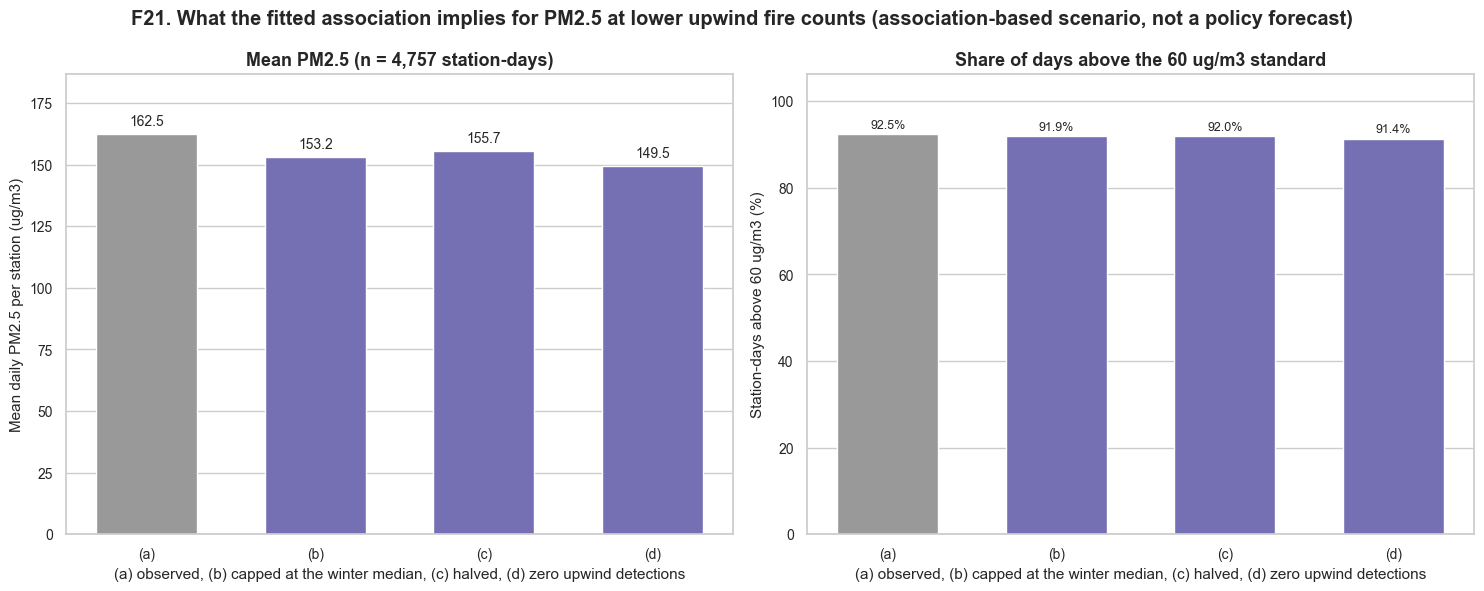

In [166]:
# Step 8B.5b: F21 mean PM2.5 and share of days above the standard under each scenario (values written on the bars)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 6))
names = [s.split(")")[0] + ")" for s in scenario_table.index]
bars = ax.bar(names, scenario_table["Mean PM2.5 (ug/m3)"], color=["#999999", "#7570B3", "#7570B3", "#7570B3"], width=0.6)
for bar, val in zip(bars, scenario_table["Mean PM2.5 (ug/m3)"]):
    ax.annotate(f"{val:.1f}", (bar.get_x() + bar.get_width() / 2, val), ha="center", va="bottom", fontsize=10, xytext=(0, 4), textcoords="offset points")
ax.set_ylim(0, scenario_table["Mean PM2.5 (ug/m3)"].max() * 1.15); ax.grid(axis="x", visible=False)
ax.set_ylabel("Mean daily PM2.5 per station (ug/m3)"); ax.set_title(f"Mean PM2.5 (n = {len(scen_frame):,} station-days)")
bars2 = ax2.bar(names, scenario_table[f"Days above {STANDARD} (%)"], color=["#999999", "#7570B3", "#7570B3", "#7570B3"], width=0.6)
label_bars(ax2, bars2, "{:.1f}%")
ax2.set_ylim(0, scenario_table[f"Days above {STANDARD} (%)"].max() * 1.15); ax2.grid(axis="x", visible=False)
ax2.set_ylabel(f"Station-days above {STANDARD} ug/m3 (%)"); ax2.set_title(f"Share of days above the {STANDARD} ug/m3 standard")
for a in (ax, ax2): a.set_xlabel("(a) observed, (b) capped at the winter median, (c) halved, (d) zero upwind detections")
fig.suptitle("F21. What the fitted association implies for PM2.5 at lower upwind fire counts (association-based scenario, not a policy forecast)", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F21_scenarios"); plt.show()

In [167]:
# Step 8B.5c: takeaway text for the scenarios
obs, zero, half = scenario_table.iloc[0], scenario_table.iloc[3], scenario_table.iloc[2]
show_takeaway(
    f"**What we learn:** the observed winter mean is **{obs['Mean PM2.5 (ug/m3)']:.1f} ug/m3** with **{obs[f'Days above {STANDARD} (%)']:.1f}%** of station-days above {STANDARD}. "
    f"If the upwind count were halved, the fitted association implies **{half['Change (ug/m3)']:+.1f} ug/m3** (interval {half['Change CI low']:+.1f} to {half['Change CI high']:+.1f}) and **{half['Change (points)']:+.1f}** points in the share above the standard "
    f"(interval {half['Share CI low']:+.1f} to {half['Share CI high']:+.1f}); with no upwind fires, **{zero['Change (ug/m3)']:+.1f} ug/m3** (interval {zero['Change CI low']:+.1f} to {zero['Change CI high']:+.1f}) and **{zero['Change (points)']:+.1f}** points."
)

**What we learn:** the observed winter mean is **162.5 ug/m3** with **92.5%** of station-days above 60. If the upwind count were halved, the fitted association implies **-6.9 ug/m3** (interval -14.6 to -0.1) and **-0.5** points in the share above the standard (interval -1.1 to +0.0); with no upwind fires, **-13.1 ug/m3** (interval -26.8 to -0.2) and **-1.1** points.

*F21. Left: mean daily PM2.5 under four fire scenarios (value on each bar). Right: share of station-days above the 60 ug/m3 standard (value on each bar). Treated stations, winter sample (1 Oct 2025 to 28 Feb 2026); the intervals for the changes are in table T04k. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** The size of the association in the units that matter for health and for the standard: how much lower PM2.5 and how many fewer days above the standard the primary model would imply at lower upwind fire counts.

**What it does not show.** This is an *association-based scenario, not a policy forecast*: it assumes the association is the same at every fire level (8B.1 tests this) and that the same weather would occur. The fire count is only a proxy for smoke, covers fires within 100 km on one side of each station, and comes from one winter. Most winter days have few upwind fires, so large changes are rarely implied. The interval covers sampling variation of the coefficient only, not the model choice (8B.3 shows how much the estimate moves with the time controls).

## 8B.6 How much do fires add beyond weather? Share of variation explained (T08d, F22)

**Question (Q2, in-sample half):** of the variation in daily PM2.5 across stations and days, how much is explained by the station and the weekday, how much more by weather, and how much more by the fire count?
**Method:** three nested regressions on the same station-days as the primary model (outcome: log PM2.5): (1) station and weekday effects only, (2) plus the eight weather controls, (3) plus the upwind fire count. The **increment** from fire is R-squared (3) minus R-squared (2); its 95% interval comes from a date-block bootstrap (same blocks and draws as everywhere else). The **partial share** is the increment divided by the variation left unexplained by (2). **This is in-sample; the out-of-sample half is the RMSE gain of Phase 8 (8.6) and the month-by-month check in 8B.7.**

In [168]:
# Step 8B.6a: ADDED AFTER SEEING RESULTS: three nested models, R-squared of each, and the fire increment with its date-block bootstrap interval
blocks = {"Station and weekday effects": "log_pm25 ~ C(station_id) + C(weekday)",
          "plus weather": f"log_pm25 ~ {CONTROLS} + C(station_id) + C(weekday)",
          "plus upwind fire count": f"log_pm25 ~ {FIRE} + {CONTROLS} + C(station_id) + C(weekday)"}
design_blocks = {name: design_xy(f_text, used)[:2] for name, f_text in blocks.items()}
y_vd = design_blocks["Station and weekday effects"][0]
w_vd = date_weights(used["date_ist"].to_numpy())
r2_point = {name: weighted_r2(X, y, np.ones(len(y))) for name, (y, X) in design_blocks.items()}
r2_draws = {name: np.array([weighted_r2(X, y, w) for w in w_vd]) for name, (y, X) in design_blocks.items()}
names_vd = list(blocks)
rows = []
for k, name in enumerate(names_vd):
    inc = r2_point[name] - (r2_point[names_vd[k - 1]] if k else 0); inc_draws = r2_draws[name] - (r2_draws[names_vd[k - 1]] if k else 0)
    rows.append({"Model": name, "R-squared": r2_point[name], "Added by this step": inc, "Step CI low": np.percentile(inc_draws, 2.5), "Step CI high": np.percentile(inc_draws, 97.5)})
variance_table = pd.DataFrame(rows).set_index("Model")
fire_inc = r2_point[names_vd[2]] - r2_point[names_vd[1]]
partial_draws = (r2_draws[names_vd[2]] - r2_draws[names_vd[1]]) / (1 - r2_draws[names_vd[1]])
partial_share, partial_low, partial_high = fire_inc / (1 - r2_point[names_vd[1]]), *np.percentile(partial_draws, [2.5, 97.5])
display((variance_table * 1).round(4)); save_table(variance_table.round(4), "T08d_variance_decomposition")
print(f"Fire increment {fire_inc * 100:.2f} points of R-squared; partial share of the variation left after weather {partial_share * 100:.2f}% [{partial_low * 100:.2f}, {partial_high * 100:.2f}] | rows {len(y_vd):,}")
log_extension("8B.6", "variance decomposition: R-squared of station and weekday effects, plus weather, plus fire, with block-bootstrap interval for the fire increment")

,R-squared,Added by this step,Step CI low,Step CI high
Model,,,,
Station and weekday effects,0.1019,0.1019,0.0882,0.2179
plus weather,0.4467,0.3448,0.2012,0.5531
plus upwind fire count,0.4646,0.0179,0.0001,0.0721


saved table : T08d_variance_decomposition
Fire increment 1.79 points of R-squared; partial share of the variation left after weather 3.23% [0.03, 12.91] | rows 4,757


saved figure: F22_variance_decomposition


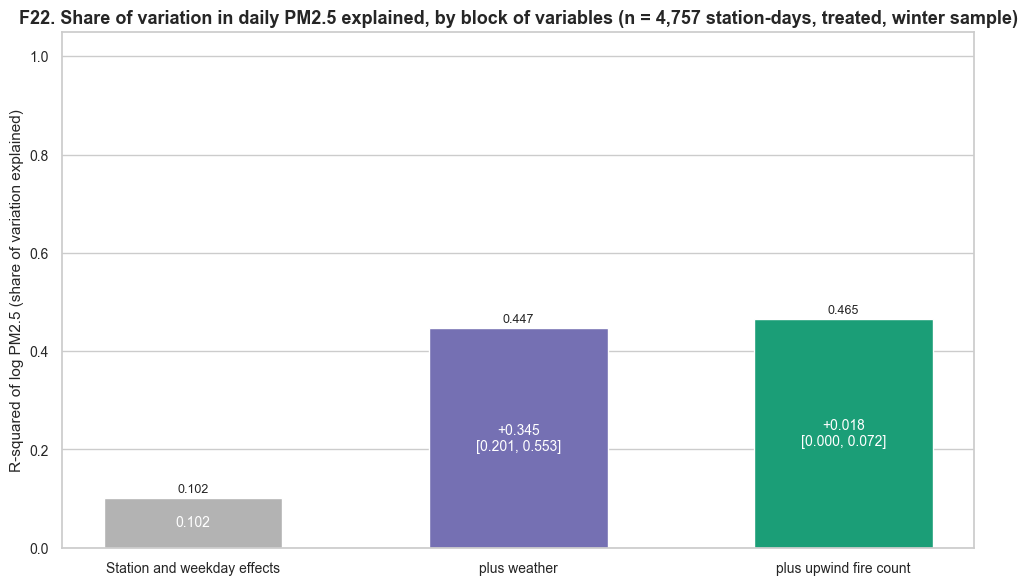

In [169]:
# Step 8B.6b: F22 R-squared by block (value on each bar) with the added share of each step written inside
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(range(3), variance_table["R-squared"], color=["#B3B3B3", "#7570B3", "#1B9E77"], width=0.55)
label_bars(ax, bars, "{:.3f}")
for xi, row in enumerate(variance_table.itertuples()):
    ax.text(xi, row[1] / 2, f"+{row[2]:.3f}\n[{row[3]:.3f}, {row[4]:.3f}]" if xi else f"{row[1]:.3f}", ha="center", va="center", color="white", fontsize=10)
ax.set_xticks(range(3)); ax.set_xticklabels([f"{n}" for n in variance_table.index]); ax.set_ylim(0, 1.05); ax.grid(axis="x", visible=False)
ax.set_ylabel("R-squared of log PM2.5 (share of variation explained)")
ax.set_title(f"F22. Share of variation in daily PM2.5 explained, by block of variables (n = {len(y_vd):,} station-days, treated, winter sample)")
plt.tight_layout(); save_fig(fig, "F22_variance_decomposition"); plt.show()

In [170]:
# Step 8B.6c: takeaway text for the variance decomposition; the numbers are kept for the KPI table in Phase 10
fire_share_beyond_weather = {"increment": fire_inc, "low": variance_table.iloc[2]["Step CI low"], "high": variance_table.iloc[2]["Step CI high"],
                             "partial": partial_share, "partial_low": partial_low, "partial_high": partial_high}
show_takeaway(
    f"**What we learn:** station and weekday effects explain **{variance_table.iloc[0]['R-squared'] * 100:.1f}%** of the variation in log PM2.5, weather adds **{variance_table.iloc[1]['Added by this step'] * 100:.1f}** points "
    f"(total **{variance_table.iloc[1]['R-squared'] * 100:.1f}%**), and the upwind fire count adds **{fire_inc * 100:.2f}** points (interval **{fire_share_beyond_weather['low'] * 100:.2f} to {fire_share_beyond_weather['high'] * 100:.2f}**), "
    f"which is **{partial_share * 100:.1f}%** of what weather and stations leave unexplained (interval {partial_low * 100:.1f}% to {partial_high * 100:.1f}%). "
    f"On unseen days (Phase 8) adding fire changed the RMSE by **{gain:+.2f} ug/m3** ({gain / scores.loc['Weather only', 'RMSE'] * 100:+.1f}%)."
)

**What we learn:** station and weekday effects explain **10.2%** of the variation in log PM2.5, weather adds **34.5** points (total **44.7%**), and the upwind fire count adds **1.79** points (interval **0.01 to 7.21**), which is **3.2%** of what weather and stations leave unexplained (interval 0.0% to 12.9%). On unseen days (Phase 8) adding fire changed the RMSE by **+0.91 ug/m3** (+2.1%).

*F22. R-squared of log PM2.5 for three nested models: station and weekday effects, plus the eight weather controls, plus the upwind fire count. The number on each bar is the R-squared; inside the bars, the amount added by the step and its 95% date-block bootstrap interval. Treated stations, winter sample, station-days. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** In this winter sample most of the variation in daily PM2.5 is accounted for by station levels and weather, and the fire count adds a small further share. This is the in-sample answer to "how much do fires add beyond weather".

**What it does not show.** R-squared is not a measure of causal importance, and the order of entry matters: fires are partly explained by the weather that moves smoke, so the increment after weather is the part of fire information that weather does not already carry. The sample is one winter, where the station effects (which stations are dirtier) take a large part of the variation. The out-of-sample comparison in 8B.7 and 8B.8 is the safer measure of practical value.

## 8B.7 Does fire add information in the months it matters? Leave-one-month-out check (T08e, F23)

**Question (Q2, out-of-sample half):** in each calendar month, does the fire count improve the prediction of PM2.5 for days the model has not been fitted on?
**Method:** all treated station-days of all seasons; for each month, train on **all other months** and test on the left-out month; four models: weather only, weather plus fire, and each of these plus **yesterday's PM2.5** (the strongest simple baseline). The **gain from fire** is the RMSE of the model without fire minus that of the model with fire (positive = fire helps), with a date-block bootstrap interval within the month. **This is an *explanation* design (it uses future months in training) and not a forecast**; the frozen forecast-style split is in Phase 8.

In [171]:
# Step 8B.7a: helpers: fit a model on one frame and predict another (back-transformed with the smearing factor), and the RMSE gain with its bootstrap interval
def fit_predict(train_df, test_df, terms):
    # log PM2.5 regression with station and weekday effects; prediction in ug/m3
    y_tr, X_tr = patsy.dmatrices(f"log_pm25 ~ {terms} + C(station_id) + C(weekday)", train_df, return_type="dataframe")
    fit_tr = OLS(y_tr, X_tr).fit()
    X_te = patsy.build_design_matrices([X_tr.design_info], test_df, return_type="dataframe")[0]
    return np.exp(X_te.to_numpy() @ fit_tr.params.to_numpy()) * np.exp(fit_tr.resid).mean()

def rmse_gain(dates, observed, pred_base, pred_new):
    # RMSE(base) minus RMSE(new) in ug/m3 (positive = the new model is better) with a 95% date-block bootstrap interval
    e_b, e_n = (observed - pred_base) ** 2, (observed - pred_new) ** 2
    gain_pt = np.sqrt(e_b.mean()) - np.sqrt(e_n.mean())
    if pd.Series(dates).nunique() < BLOCK_DAYS:
        return gain_pt, np.nan, np.nan
    w = date_weights(dates).astype(np.float64)
    boot = np.sqrt(w @ e_b / w.sum(1)) - np.sqrt(w @ e_n / w.sum(1))
    return (gain_pt, *np.percentile(boot, [2.5, 97.5]))
cv_frame = pred_frame.assign(log_yday=np.log(pred_frame["pm25_yesterday"]), month_label=pred_frame["date_ist"].dt.strftime("%Y-%m"))
W_TERMS, WF_TERMS = CONTROLS, f"{FIRE} + {CONTROLS}"
WY_TERMS, WFY_TERMS = f"{CONTROLS} + log_yday", f"{FIRE} + {CONTROLS} + log_yday"
print(len(cv_frame), "station-days in", cv_frame["month_label"].nunique(), "months")

17127 station-days in 20 months


In [172]:
# Step 8B.7b: ADDED AFTER SEEING RESULTS: leave one month out, four models per month, RMSE gain from fire with intervals
rows = []
for month in sorted(cv_frame["month_label"].unique()):
    tr_m, te_m = cv_frame[cv_frame["month_label"] != month], cv_frame[cv_frame["month_label"] == month]
    te_m = te_m[te_m["station_id"].isin(tr_m["station_id"].unique())]
    obs_m = te_m["pm25_day"].to_numpy()
    p = {name: fit_predict(tr_m, te_m, terms) for name, terms in [("W", W_TERMS), ("WF", WF_TERMS), ("WY", WY_TERMS), ("WFY", WFY_TERMS)]}
    g1 = rmse_gain(te_m["date_ist"].to_numpy(), obs_m, p["W"], p["WF"]); g2 = rmse_gain(te_m["date_ist"].to_numpy(), obs_m, p["WY"], p["WFY"])
    rows.append({"Month": month, "Station-days": len(te_m), "RMSE weather": np.sqrt(np.mean((obs_m - p["W"]) ** 2)), "RMSE weather+fire": np.sqrt(np.mean((obs_m - p["WF"]) ** 2)),
                 "Fire gain": g1[0], "Gain CI low": g1[1], "Gain CI high": g1[2],
                 "RMSE weather+yesterday": np.sqrt(np.mean((obs_m - p["WY"]) ** 2)), "RMSE weather+yesterday+fire": np.sqrt(np.mean((obs_m - p["WFY"]) ** 2)),
                 "Fire gain given yesterday": g2[0], "Gain (yesterday) CI low": g2[1], "Gain (yesterday) CI high": g2[2]})
cv_table = pd.DataFrame(rows).set_index("Month")
cv_table["Oct to Feb"] = [m[-2:] in ("10", "11", "12", "01", "02") for m in cv_table.index]
display(cv_table.round(2)); save_table(cv_table.round(3), "T08e_leave_one_month_out")
log_extension("8B.7", "leave-one-month-out check of the fire gain with and without yesterday's PM2.5")

,Station-days,RMSE weather,RMSE weather+fire,Fire gain,Gain CI low,Gain CI high,RMSE weather+yesterday,RMSE weather+yesterday+fire,Fire gain given yesterday,Gain (yesterday) CI low,Gain (yesterday) CI high,Oct to Feb
Month,,,,,,,,,,,,
2025-02,263,50.53,50.63,-0.10,-0.59,0.15,20.73,20.70,0.03,0.01,0.05,True
2025-03,1066,62.47,61.67,0.80,0.23,1.22,22.74,22.83,-0.09,-0.17,-0.02,False
2025-04,708,37.49,37.46,0.03,-3.61,1.92,23.42,23.34,0.08,-0.11,0.37,False
2025-05,897,35.98,37.07,-1.09,-2.99,-0.25,34.01,34.17,-0.16,-0.37,-0.02,False
2025-06,827,20.44,20.43,0.00,-0.65,0.76,13.02,13.04,-0.02,-0.08,0.05,False
2025-07,1001,15.69,15.72,-0.03,-0.08,0.02,11.83,11.83,0.00,-0.00,0.01,False
2025-08,970,14.78,14.77,0.01,-0.04,0.07,13.67,13.67,-0.00,-0.01,0.00,False
2025-09,985,15.85,15.85,-0.00,-0.03,0.04,10.58,10.59,-0.00,-0.01,0.00,False
2025-10,993,52.25,52.51,-0.26,-0.54,-0.04,29.30,29.30,0.00,-0.03,0.06,True


saved table : T08e_leave_one_month_out


saved figure: F23_leave_one_month_out


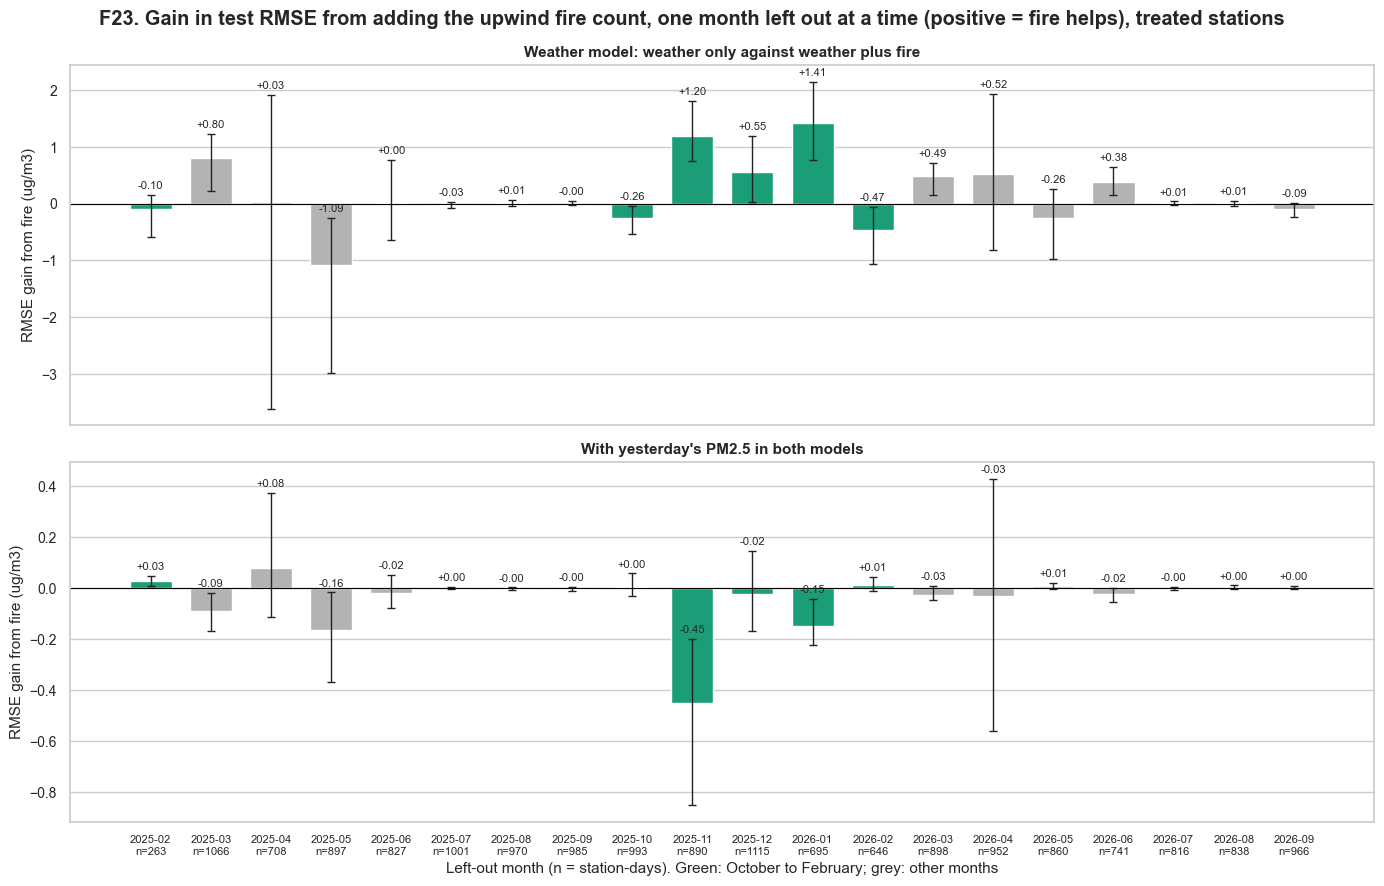

In [173]:
# Step 8B.7c: F23 RMSE gain from adding fire in each left-out month (value on each bar, interval as whisker); Oct to Feb highlighted
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
x = np.arange(len(cv_table))
for axis, col, lo, hi, title in [(ax, "Fire gain", "Gain CI low", "Gain CI high", "Weather model: weather only against weather plus fire"),
                                 (ax2, "Fire gain given yesterday", "Gain (yesterday) CI low", "Gain (yesterday) CI high", "With yesterday's PM2.5 in both models")]:
    colours = ["#1B9E77" if flag else "#B3B3B3" for flag in cv_table["Oct to Feb"]]
    axis.bar(x, cv_table[col], color=colours, width=0.7)
    axis.errorbar(x, cv_table[col], yerr=[np.nan_to_num(cv_table[col] - cv_table[lo]), np.nan_to_num(cv_table[hi] - cv_table[col])], fmt="none", ecolor="#222222", capsize=3, lw=1)
    for xi, val, hi_val in zip(x, cv_table[col], cv_table[hi].fillna(cv_table[col])):
        axis.annotate(f"{val:+.2f}", (xi, max(val, hi_val)), ha="center", va="bottom", fontsize=8, xytext=(0, 3), textcoords="offset points")
    axis.axhline(0, color="black", lw=0.8); axis.set_ylabel("RMSE gain from fire (ug/m3)"); axis.set_title(title, fontsize=11); axis.grid(axis="x", visible=False)
ax2.set_xticks(x); ax2.set_xticklabels([f"{m}\nn={n}" for m, n in zip(cv_table.index, cv_table["Station-days"])], fontsize=8)
ax2.set_xlabel("Left-out month (n = station-days). Green: October to February; grey: other months")
fig.suptitle("F23. Gain in test RMSE from adding the upwind fire count, one month left out at a time (positive = fire helps), treated stations", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F23_leave_one_month_out"); plt.show()

In [174]:
# Step 8B.7d: takeaway text: pooled over months (station-days weighted) and for October to February
def pooled_gain(subset, col_w, col_wf):
    return np.sqrt(np.average(subset[col_w] ** 2, weights=subset["Station-days"])) - np.sqrt(np.average(subset[col_wf] ** 2, weights=subset["Station-days"]))
cold = cv_table[cv_table["Oct to Feb"]]
helped = int((cv_table["Fire gain"] > 0).sum())
show_takeaway(
    f"**What we learn:** adding the fire count lowers the error in **{helped}** of **{len(cv_table)}** left-out months. Pooled over all months the RMSE gain is **{pooled_gain(cv_table, 'RMSE weather', 'RMSE weather+fire'):+.2f} ug/m3**; "
    f"in October to February it is **{pooled_gain(cold, 'RMSE weather', 'RMSE weather+fire'):+.2f} ug/m3**. Once yesterday's PM2.5 is in both models the pooled gain from fire is "
    f"**{pooled_gain(cv_table, 'RMSE weather+yesterday', 'RMSE weather+yesterday+fire'):+.2f}** and in October to February **{pooled_gain(cold, 'RMSE weather+yesterday', 'RMSE weather+yesterday+fire'):+.2f} ug/m3**. "
    f"The month with the largest gain is **{cv_table['Fire gain'].idxmax()}** (**{cv_table['Fire gain'].max():+.1f} ug/m3**)."
)

**What we learn:** adding the fire count lowers the error in **12** of **20** left-out months. Pooled over all months the RMSE gain is **+0.32 ug/m3**; in October to February it is **+0.60 ug/m3**. Once yesterday's PM2.5 is in both models the pooled gain from fire is **-0.07** and in October to February **-0.13 ug/m3**. The month with the largest gain is **2026-01** (**+1.4 ug/m3**).

*F23. For each month left out of the fitting, the change in RMSE (ug/m3) from adding the upwind fire count to a weather model (top) and to a weather-plus-yesterday model (bottom); positive means fire helps. The value is written above each bar, whiskers are 95% date-block bootstrap intervals, and n is the number of station-days in the month. Treated stations, all seasons. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** Whether fire information helps in the months when stubble burning is expected (autumn) and in winter, and whether any gain survives once yesterday's PM2.5 is known.

**What it does not show.** Each month is predicted from a model fitted with the months on both sides of it, so this is an explanation design, not a forecast. Months at the edges of the data (February 2025, September 2026) are short. The autumn burning months (October and November) appear once, so one season carries any autumn conclusion. A positive gain in one month can be noise: look at the interval, not the bar alone.

## 8B.8 A fairer prediction comparison under the frozen split (T08f)

**Question:** in Phase 8 both regressions lost to simple persistence on the frozen test period. If yesterday's PM2.5 is allowed *into* the regression, does the model beat persistence, and does fire still add anything on top?
**Method:** the frozen split of Phase 8 (train to 31 Dec 2025, test 1 Jan to 30 Sep 2026), the same test rows, two added models: **persistence plus weather** (weather and log of yesterday's PM2.5) and **persistence plus weather plus fire**. The monthly error table of Phase 8 is repeated with these models. This is an extension; it does not replace the frozen comparison (weather only against weather plus fire).

In [175]:
# Step 8B.8a: ADDED AFTER SEEING RESULTS: two more models on the frozen split; the check below reproduces the Phase 8 interval with the new helper
frozen_test = test.assign(log_yday=np.log(test["pm25_yesterday"]))
frozen_train = train.assign(log_yday=np.log(train["pm25_yesterday"]))
predictions_b = dict(predictions)
predictions_b["Persistence + weather"] = fit_predict(frozen_train, frozen_test, WY_TERMS)
predictions_b["Persistence + weather + fire"] = fit_predict(frozen_train, frozen_test, WFY_TERMS)
check = rmse_gain(test["date_ist"].to_numpy(), actual, predictions["Weather only"], predictions["Weather and fire"])
assert np.allclose(check, [gain, gain_low, gain_high], rtol=1e-6), "the new helper does not reproduce the Phase 8 gain and interval"
print("Check: the helper reproduces the Phase 8 gain and interval:", [round(float(v), 3) for v in check])
rows = []
for label, pred in predictions_b.items():
    err = actual - pred
    rows.append({"Model": label, "RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)), "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2)})
scores_b = pd.DataFrame(rows).set_index("Model")
display(scores_b.round(2)); save_table(scores_b.round(3), "T08f_prediction_scores_extended")
log_extension("8B.8", "persistence plus weather, and persistence plus weather plus fire, under the frozen train and test periods")

Check: the helper reproduces the Phase 8 gain and interval: [0.905, 0.368, 1.396]


,RMSE,MAE,R2
Model,,,
Climatology (month),32.38,22.40,0.39
Persistence (yesterday),25.34,16.85,0.62
Weather only,43.91,28.29,-0.13
Weather and fire,43.01,27.88,-0.08
Persistence + weather,23.40,15.39,0.68
Persistence + weather + fire,23.49,15.42,0.68


saved table : T08f_prediction_scores_extended


In [176]:
# Step 8B.8b: three comparisons with date-block bootstrap intervals: does the regression beat persistence, and does fire add anything on top?
comparisons = [("Persistence + weather against persistence alone", "Persistence (yesterday)", "Persistence + weather"),
               ("Fire added to persistence + weather", "Persistence + weather", "Persistence + weather + fire"),
               ("Fire added to weather only (frozen comparison)", "Weather only", "Weather and fire")]
rows = []
for label, base, new in comparisons:
    g, lo, hi = rmse_gain(test["date_ist"].to_numpy(), actual, predictions_b[base], predictions_b[new])
    rows.append({"Comparison": label, "RMSE gain (ug/m3)": g, "CI low": lo, "CI high": hi, "Improves": bool(lo > 0)})
comparison_table = pd.DataFrame(rows).set_index("Comparison")
display(comparison_table.round(2)); save_table(comparison_table.round(3), "T08f2_prediction_comparisons")

,RMSE gain (ug/m3),CI low,CI high,Improves
Comparison,,,,
Persistence + weather against persistence alone,1.95,-0.51,4.17,False
Fire added to persistence + weather,-0.09,-0.16,-0.01,False
Fire added to weather only (frozen comparison),0.91,0.37,1.40,True


saved table : T08f2_prediction_comparisons


In [177]:
# Step 8B.8c: monthly RMSE of all models in the test period (the table of Phase 8 with the two added models)
test_b = test.assign(**{f"pred {k}": v for k, v in predictions_b.items()})
monthly_b = pd.DataFrame({k: test_b.groupby(test_b["date_ist"].dt.strftime("%Y-%m")).apply(lambda g, k=k: np.sqrt(np.mean((g["pm25_day"] - g[f"pred {k}"]) ** 2)))
                          for k in ["Persistence (yesterday)", "Weather only", "Weather and fire", "Persistence + weather", "Persistence + weather + fire"]})
monthly_b["Mean temperature (deg C)"] = test_b.groupby(test_b["date_ist"].dt.strftime("%Y-%m"))["t2m_c"].mean()
display(monthly_b.round(1)); save_table(monthly_b.round(2), "T08f3_monthly_rmse_extended")
pw, pwf, pers = scores_b.loc["Persistence + weather"], scores_b.loc["Persistence + weather + fire"], scores_b.loc["Persistence (yesterday)"]
show_takeaway(
    f"**What we learn:** letting yesterday's PM2.5 into the regression gives an RMSE of **{pw['RMSE']:.1f} ug/m3** against **{pers['RMSE']:.1f}** for persistence alone "
    f"(gain **{comparison_table.iloc[0]['RMSE gain (ug/m3)']:+.2f}**, interval {comparison_table.iloc[0]['CI low']:+.2f} to {comparison_table.iloc[0]['CI high']:+.2f}). Adding fire on top changes it by "
    f"**{comparison_table.iloc[1]['RMSE gain (ug/m3)']:+.2f} ug/m3** (interval {comparison_table.iloc[1]['CI low']:+.2f} to {comparison_table.iloc[1]['CI high']:+.2f}). "
    f"The weather-only models fail most in **{monthly_b['Weather only'].idxmax()}** (RMSE {monthly_b['Weather only'].max():.1f}, mean temperature {monthly_b.loc[monthly_b['Weather only'].idxmax(), 'Mean temperature (deg C)']:.1f} deg C)."
)

,Persistence (yesterday),Weather only,Weather and fire,Persistence + weather,Persistence + weather + fire,Mean temperature (deg C)
date_ist,,,,,,
2026-01,50.0,111.9,109.1,50.6,50.9,12.3
2026-02,33.3,39.2,39.6,27.6,27.6,18.6
2026-03,25.9,34.3,33.6,21.4,21.5,23.7
2026-04,26.1,44.3,42.8,25.2,25.4,28.8
2026-05,18.6,23.2,23.4,15.9,15.9,32.9
2026-06,16.7,19.0,18.6,14.2,14.3,32.6
2026-07,16.3,16.2,16.2,12.9,12.9,30.3
2026-08,10.0,13.7,13.7,9.0,9.0,30.1
2026-09,16.0,24.3,24.5,14.4,14.4,28.7


saved table : T08f3_monthly_rmse_extended


**What we learn:** letting yesterday's PM2.5 into the regression gives an RMSE of **23.4 ug/m3** against **25.3** for persistence alone (gain **+1.95**, interval -0.51 to +4.17). Adding fire on top changes it by **-0.09 ug/m3** (interval -0.16 to -0.01). The weather-only models fail most in **2026-01** (RMSE 111.9, mean temperature 12.3 deg C).

**What it shows.** What a fair predictive comparison looks like: a model that is allowed to use yesterday's PM2.5 and today's weather, and then the *additional* value of fire. It also shows in numbers where the frozen weather models failed (the coldest month of the test period).

**What it does not show.** The frozen comparison of H1 (weather only against weather plus fire, criterion 3) is unchanged: it stays in Phase 8 and decides the criterion. Using yesterday's PM2.5 is not available when forecasting several days ahead, and the test period has no autumn burning season, so a small or absent fire gain here cannot say that fires do not matter in autumn.

## 8B.8b Does fire add anything on winter days? A fire x winter interaction and a winter-only run (T08h)

**Question:** the frozen prediction run trains and tests on **all seasons**, while H1 is a **winter** hypothesis. Does the answer to "does fire help prediction" change if the model is allowed a different fire effect in winter, or is trained on winter days only?
**Method (ADDED AFTER SEEING RESULTS; the frozen run is kept and is shown in the first row):** the same frozen split (train to 31 Dec 2025, test from 1 Jan 2026), (i) a model with a **winter indicator and a fire x winter interaction** (winter = 1 Oct to 28 Feb) against the same model without fire, and (ii) **winter-only training and testing** (October to December 2025 for training; January and February 2026 for testing). The RMSE gain from adding fire and its date-block bootstrap interval are reported for each run.

In [178]:
# Step 8B.8b-a: ADDED AFTER SEEING RESULTS: fire x winter interaction (all seasons) and winter-only training, with the frozen run for comparison
in_winter = lambda f: f["date_ist"].between(WINTER_START, WINTER_END).astype(float)
inter_train, inter_test = frozen_train.assign(winter=in_winter(frozen_train)), frozen_test.assign(winter=in_winter(frozen_test))
p_w, p_f = fit_predict(inter_train, inter_test, f"winter + {CONTROLS}"), fit_predict(inter_train, inter_test, f"winter + {FIRE} + {FIRE}:winter + {CONTROLS}")
obs_i = inter_test["pm25_day"].to_numpy(); g_inter = rmse_gain(inter_test["date_ist"].to_numpy(), obs_i, p_w, p_f)
tr_w, te_w = inter_train[inter_train["winter"] == 1], inter_test[inter_test["winter"] == 1]; te_w = te_w[te_w["station_id"].isin(tr_w["station_id"].unique())]
q_w, q_f = fit_predict(tr_w, te_w, CONTROLS), fit_predict(tr_w, te_w, f"{FIRE} + {CONTROLS}"); obs_w = te_w["pm25_day"].to_numpy(); g_win = rmse_gain(te_w["date_ist"].to_numpy(), obs_w, q_w, q_f)
rmse = lambda o, p: float(np.sqrt(np.mean((o - p) ** 2)))
rows = [("Frozen run: all seasons, no interaction (Phase 8)", len(test), scores.loc["Weather only", "RMSE"], scores.loc["Weather and fire", "RMSE"], gain, gain_low, gain_high),
        ("Fire x winter interaction, all seasons", len(inter_test), rmse(obs_i, p_w), rmse(obs_i, p_f), *g_inter), ("Winter-only training and testing (Oct to Dec 2025 to Jan to Feb 2026)", len(te_w), rmse(obs_w, q_w), rmse(obs_w, q_f), *g_win)]
season_table = pd.DataFrame(rows, columns=["Run", "Test station-days", "RMSE without fire", "RMSE with fire", "Gain from fire (ug/m3)", "CI low", "CI high"]).set_index("Run")
display(season_table.round(2)); save_table(season_table.round(3), "T08h_fire_prediction_by_season")
log_extension("8B.8b", "fire gain for a fire x winter interaction and for winter-only training and testing")

,Test station-days,RMSE without fire,RMSE with fire,Gain from fire (ug/m3),CI low,CI high
Run,,,,,,
"Frozen run: all seasons, no interaction (Phase 8)",7412,43.91,43.01,0.91,0.37,1.40
"Fire x winter interaction, all seasons",7412,39.75,38.43,1.32,-0.70,3.15
Winter-only training and testing (Oct to Dec 2025 to Jan to Feb 2026),1341,104.52,99.09,5.43,0.84,10.10


saved table : T08h_fire_prediction_by_season


In [179]:
# Step 8B.8b-b: takeaway text for the interaction and winter-only runs
fz, it, wo = (season_table.iloc[k] for k in range(3))
show_takeaway(
    f"**What we learn:** the frozen all-season run gives a gain from fire of **{fz['Gain from fire (ug/m3)']:+.2f} ug/m3** (interval {fz['CI low']:+.2f} to {fz['CI high']:+.2f}). With a fire x winter interaction the gain is **{it['Gain from fire (ug/m3)']:+.2f}** ({it['CI low']:+.2f} to {it['CI high']:+.2f}), "
    f"and with winter-only training and testing **{wo['Gain from fire (ug/m3)']:+.2f}** ({wo['CI low']:+.2f} to {wo['CI high']:+.2f}) on **{int(wo['Test station-days']):,}** test station-days. "
    f"The gain {'keeps its sign' if np.sign(fz['Gain from fire (ug/m3)']) == np.sign(it['Gain from fire (ug/m3)']) == np.sign(wo['Gain from fire (ug/m3)']) else 'changes sign'} across the three runs, and the interaction interval {'includes' if it['CI low'] <= 0 <= it['CI high'] else 'excludes'} zero; the frozen criterion 3 is evaluated on the frozen run only."
)

**What we learn:** the frozen all-season run gives a gain from fire of **+0.91 ug/m3** (interval +0.37 to +1.40). With a fire x winter interaction the gain is **+1.32** (-0.70 to +3.15), and with winter-only training and testing **+5.43** (+0.84 to +10.10) on **1,341** test station-days. The gain keeps its sign across the three runs, and the interaction interval includes zero; the frozen criterion 3 is evaluated on the frozen run only.

**What it shows.** Whether the small out-of-sample gain from fire found in the frozen run changes when the model is given a separate fire effect for winter, or is trained on winter days only.

**What it does not show.** The winter-only run trains on three months (October to December) and tests on two (January and February), so it is small and January is the cold month the models extrapolate to; the intervals are wide. The frozen run and the frozen criterion are not changed.

## 8B.8c The persistence-plus-weather model as a simple advisory model (T08i)

**Question:** recommendation 5 and the app use a **next-day advisory** based on yesterday's PM2.5 and the weather. What are the coefficients and the test error of that simple model?
**Method (ADDED AFTER SEEING RESULTS):** the frozen split; a regression of log PM2.5 on log of yesterday's PM2.5 and the eight weather controls **without station effects** (so that it can be applied to any location from a few numbers), back-transformed with the smearing factor; test RMSE and MAE in ug/m3. The coefficients are saved so that `app/streamlit_app.py` can use them without refitting.

In [180]:
# Step 8B.8c-a: ADDED AFTER SEEING RESULTS: the simple persistence-plus-weather advisory model (no station effects): coefficients, smearing factor and test error
advisory_terms = ["log_yday"] + CONTROLS.split(" + ")
y_a, X_a = patsy.dmatrices("log_pm25 ~ " + " + ".join(advisory_terms), frozen_train, return_type="dataframe"); fit_a = OLS(y_a, X_a).fit()
smear_a = float(np.exp(fit_a.resid).mean()); X_ta = patsy.build_design_matrices([X_a.design_info], frozen_test, return_type="dataframe")[0]
pred_a = np.exp(X_ta.to_numpy() @ fit_a.params.to_numpy()) * smear_a; adv_rmse, adv_mae = rmse(actual, pred_a), float(np.mean(np.abs(actual - pred_a)))
adv_table = fit_a.params.rename("Coefficient").to_frame(); adv_table.loc["smearing factor"] = smear_a; adv_table.loc["test RMSE (ug/m3)"] = adv_rmse; adv_table.loc["test MAE (ug/m3)"] = adv_mae
adv_table.loc["test R-squared"] = 1 - np.sum((actual - pred_a) ** 2) / np.sum((actual - actual.mean()) ** 2); adv_table.loc["training rows"] = len(frozen_train)
display(adv_table.round(4)); save_table(adv_table.round(6), "T08i_advisory_model")
log_extension("8B.8c", "persistence-plus-weather advisory model without station effects (coefficients saved for the app)")
show_takeaway(f"**What we learn:** the simple advisory model has a test RMSE of **{adv_rmse:.1f} ug/m3** (MAE {adv_mae:.1f}); the persistence-plus-weather regression with station effects of 8B.8 has **{scores_b.loc['Persistence + weather', 'RMSE']:.1f}** and persistence alone **{scores_b.loc['Persistence (yesterday)', 'RMSE']:.1f}**. The model is used only for the advisory pilot and the app.")

,Coefficient
Intercept,-0.5422
log_yday,0.7182
wind_speed,-0.1492
wind_dir_sin,0.0378
wind_dir_cos,0.0249
t2m_c,-0.0226
rh_pct,-0.0055
blh_m,0.0001
tp_mm,-0.0098
sp_hpa,0.0031


saved table : T08i_advisory_model


**What we learn:** the simple advisory model has a test RMSE of **22.9 ug/m3** (MAE 15.1); the persistence-plus-weather regression with station effects of 8B.8 has **23.4** and persistence alone **25.3**. The model is used only for the advisory pilot and the app.

**What it shows.** The numbers a simple next-day advisory would use and how large its error is on unseen days, so that the error band can be shown with every advice.

**What it does not show.** That the advisory is validated: the test period is one year with one winter, the cold January is badly predicted, and the model uses the *observed* weather of the target day (an operational advisory would use a forecast, which adds error).

## 8B.9 Boosted-model comparison: does a flexible model change the answer? (T08g, F24)

**Question:** the proposal mentions gradient boosting. Does a flexible tree model, with the same inputs and the same frozen split, predict better than the linear models, does the fire count matter to it, and which group of variables does it rely on?
**Method:** `HistGradientBoostingRegressor` on log PM2.5 with the same inputs as the linear model (fire count, eight weather controls, day of week, station), the same frozen train and test periods, and settings chosen **only by blocked cross-validation inside the training period** (four contiguous blocks of dates, each held out in turn); the test period is touched once. Importance is **permutation importance by group** on the test period (increase in RMSE when a group is shuffled), with mean absolute SHAP values if the `shap` package loads (computed on a twin model with the same settings that treats station and weekday as numbers, because the SHAP package did not reproduce the predictions of the model with categorical splits: a check of the sum of SHAP values against the prediction guards this). **Limits stated in advance:** trees cannot predict beyond the range they were trained on, so the cold January stays hard; importance shows what the model *uses*, not an effect size. **The boosted model is part of the main analysis because the proposal names it; it feeds no frozen decision rule.** All 16 combinations of the tuning grid are shown (table T08g4) with the blocked log-scale error of each.

In [181]:
# Step 8B.9a: ADDED AFTER SEEING RESULTS: inputs and the blocked tuning inside the training period (log-scale RMSE; four held-out blocks of dates)
import itertools
from sklearn.ensemble import HistGradientBoostingRegressor
WEATHER = CONTROLS.split(" + ")
codes = {s: i for i, s in enumerate(sorted(train["station_id"].unique()))}
def feature_matrix(frame, columns):
    return frame.assign(station_code=frame["station_id"].map(codes))[columns].to_numpy(float)
def make_model(columns, params):
    return HistGradientBoostingRegressor(categorical_features=np.array([c in ("weekday", "station_code") for c in columns]), random_state=SEED, **params)
FEATURES_WF = [FIRE] + WEATHER + ["weekday", "station_code"]
fold_dates = np.array_split(np.sort(train["date_ist"].unique()), 4)
grid = [dict(max_depth=d, learning_rate=lr, max_iter=it, min_samples_leaf=leaf) for d, lr, it, leaf in itertools.product([3, 6], [0.05, 0.1], [100, 300], [20, 60])]
X_tr_all, y_tr_all = feature_matrix(train, FEATURES_WF), train["log_pm25"].to_numpy()
fold_of = np.searchsorted(np.array([ds[0] for ds in fold_dates]), train["date_ist"].to_numpy(), side="right") - 1      # block 0 to 3 of each training date
def blocked_oof(params, columns):
    oof = np.zeros(len(train)); X_all = feature_matrix(train, columns)
    for k in range(4):
        oof[fold_of == k] = make_model(columns, params).fit(X_all[fold_of != k], y_tr_all[fold_of != k]).predict(X_all[fold_of == k])
    return oof
tuning = [{**p, "log RMSE": np.sqrt(np.mean((y_tr_all - blocked_oof(p, FEATURES_WF)) ** 2))} for p in grid]
tuning_table = pd.DataFrame(tuning).sort_values("log RMSE").reset_index(drop=True)
best_params = {k: (int(v) if k != "learning_rate" else float(v)) for k, v in tuning_table.iloc[0].drop("log RMSE").items()}
display(tuning_table.round(4)); save_table(tuning_table.round(5), "T08g4_boosted_tuning"); print("Chosen settings:", best_params, "| combinations tried:", len(grid), "| training rows", len(train))
log_extension("8B.9", "boosted model (HistGradientBoostingRegressor), settings tuned by blocked cross-validation inside the training period")

,max_depth,learning_rate,max_iter,min_samples_leaf,log RMSE
0,3,0.10,100,60,0.7459
1,3,0.10,100,20,0.7530
2,3,0.05,300,60,0.7544
3,6,0.05,100,60,0.7559
4,3,0.05,100,60,0.7589
5,6,0.10,100,60,0.7591
6,3,0.10,300,60,0.7615
7,6,0.05,100,20,0.7620
8,3,0.05,100,20,0.7631
9,6,0.05,300,60,0.7633


saved table : T08g4_boosted_tuning
Chosen settings: {'max_depth': 3, 'learning_rate': 0.1, 'max_iter': 100, 'min_samples_leaf': 60} | combinations tried: 16 | training rows 9715


In [182]:
# Step 8B.9b: fit on the whole training period with the chosen settings and predict the test period (smearing factor from the training residuals, as for the linear models)
FEATURES_W = [c for c in FEATURES_WF if c != FIRE]
boost_models, predictions_c = {}, dict(predictions_b)
for name, cols in [("Boosted: weather only", FEATURES_W), ("Boosted: weather and fire", FEATURES_WF)]:
    mdl = make_model(cols, best_params).fit(feature_matrix(train, cols), y_tr_all)
    smear_m = np.exp(y_tr_all - mdl.predict(feature_matrix(train, cols))).mean()
    boost_models[name] = (cols, mdl, smear_m)
    predictions_c[name] = np.exp(mdl.predict(feature_matrix(test, cols))) * smear_m
smear_boost = boost_models["Boosted: weather and fire"][2]
rows = []
for label, pred in predictions_c.items():
    err = actual - pred
    rows.append({"Model": label, "RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)), "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2)})
scores_c = pd.DataFrame(rows).set_index("Model")
display(scores_c.round(2))
boost_gain = rmse_gain(test["date_ist"].to_numpy(), actual, predictions_c["Boosted: weather only"], predictions_c["Boosted: weather and fire"])
print(f"Fire gain in the boosted model: {boost_gain[0]:+.2f} ug/m3, interval {boost_gain[1]:+.2f} to {boost_gain[2]:+.2f}; smearing factor {smear_boost:.3f}")

,RMSE,MAE,R2
Model,,,
Climatology (month),32.38,22.40,0.39
Persistence (yesterday),25.34,16.85,0.62
Weather only,43.91,28.29,-0.13
Weather and fire,43.01,27.88,-0.08
Persistence + weather,23.40,15.39,0.68
Persistence + weather + fire,23.49,15.42,0.68
Boosted: weather only,38.33,24.77,0.14
Boosted: weather and fire,36.68,24.00,0.21


Fire gain in the boosted model: +1.66 ug/m3, interval -0.15 to +3.38; smearing factor 1.046


In [183]:
# Step 8B.9c: permutation importance by group of variables on the test period (increase in RMSE when the group is shuffled; 20 repeats), and SHAP if available
groups = {"Weather (8 variables)": WEATHER, "Fire count": [FIRE], "Station": ["station_code"], "Day of week": ["weekday"]}
X_te_wf = feature_matrix(test, FEATURES_WF); model_wf = boost_models["Boosted: weather and fire"][1]               # same smearing factor as in 8B.9b: smear_boost
base_rmse = np.sqrt(np.mean((actual - np.exp(model_wf.predict(X_te_wf)) * smear_boost) ** 2))
rng_perm, rows = np.random.default_rng(SEED), []
for name, cols in groups.items():
    idx_cols = [FEATURES_WF.index(c) for c in cols]; increases = []
    for _ in range(20):
        X_perm = X_te_wf.copy(); X_perm[:, idx_cols] = X_perm[rng_perm.permutation(len(X_perm))][:, idx_cols]
        increases.append(np.sqrt(np.mean((actual - np.exp(model_wf.predict(X_perm)) * smear_boost) ** 2)) - base_rmse)
    rows.append({"Group": name, "RMSE increase when shuffled (ug/m3)": np.mean(increases), "SD over 20 shuffles": np.std(increases)})
importance = pd.DataFrame(rows).set_index("Group")
try:
    import shap
    twin = HistGradientBoostingRegressor(random_state=SEED, **best_params).fit(X_tr_all, y_tr_all)           # same settings, station and weekday as numbers (SHAP mishandles categorical splits)
    explainer = shap.TreeExplainer(twin); shap_values = explainer.shap_values(X_te_wf)
    gap = np.abs(shap_values.sum(1) + np.ravel(explainer.expected_value)[0] - twin.predict(X_te_wf)).max()
    assert gap < 1e-6, f"SHAP values do not add up to the prediction (gap {gap:.3f})"                      # local-accuracy check
    importance["Mean absolute SHAP (log points)"] = [np.abs(shap_values[:, [FEATURES_WF.index(c) for c in cols]].sum(1)).mean() for cols in groups.values()]
    print(f"SHAP from a twin model with station and weekday as numbers: sum of SHAP values equals the prediction (largest gap {gap:.1e}); twin log RMSE {np.sqrt(np.mean((test['log_pm25'].to_numpy() - twin.predict(X_te_wf)) ** 2)):.3f} against {np.sqrt(np.mean((test['log_pm25'].to_numpy() - model_wf.predict(X_te_wf)) ** 2)):.3f} for the model above")
except Exception as error:
    print("SHAP not used:", type(error).__name__, str(error)[:120])
display(importance.round(3)); save_table(importance.round(4), "T08g_boosted_importance")
save_table(scores_c.round(3), "T08g2_boosted_scores")

SHAP from a twin model with station and weekday as numbers: sum of SHAP values equals the prediction (largest gap 7.1e-15); twin log RMSE 0.424 against 0.424 for the model above


,RMSE increase when shuffled (ug/m3),SD over 20 shuffles,Mean absolute SHAP (log points)
Group,,,
Weather (8 variables),28.763,0.436,0.460
Fire count,-0.595,0.074,0.012
Station,3.384,0.299,0.081
Day of week,-0.298,0.060,0.012


saved table : T08g_boosted_importance
saved table : T08g2_boosted_scores


saved figure: F24_boosted_model


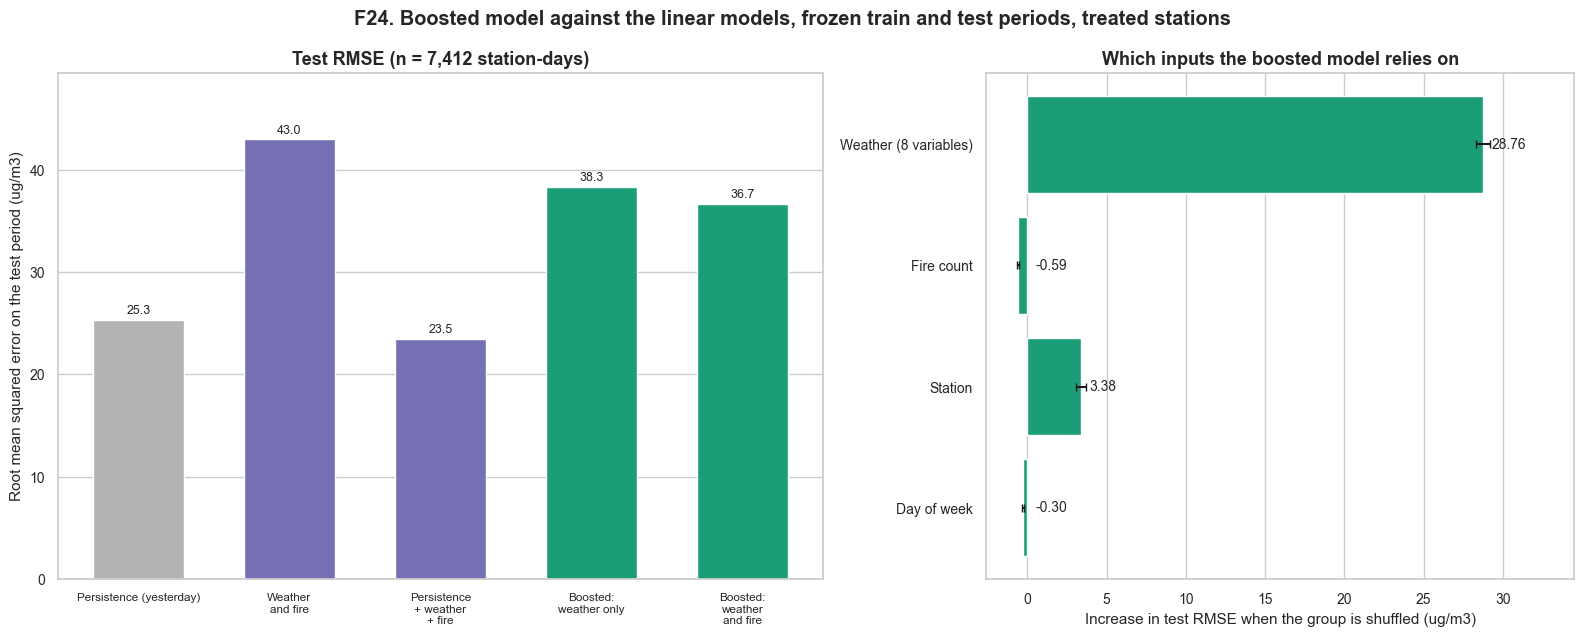

In [184]:
# Step 8B.9d: F24 left: test RMSE of the linear and boosted models (value on each bar); right: permutation importance by group (value on each bar)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
order = ["Persistence (yesterday)", "Weather and fire", "Persistence + weather + fire", "Boosted: weather only", "Boosted: weather and fire"]
bars = ax.bar(range(len(order)), scores_c.loc[order, "RMSE"], color=["#B3B3B3", "#7570B3", "#7570B3", "#1B9E77", "#1B9E77"], width=0.6)
label_bars(ax, bars, "{:.1f}")
ax.set_xticks(range(len(order))); ax.set_xticklabels([o.replace(": ", ":\n").replace(" + ", "\n+ ").replace(" and ", "\nand ") for o in order], fontsize=8.5)
ax.set_ylim(0, scores_c.loc[order, "RMSE"].max() * 1.15); ax.grid(axis="x", visible=False); ax.set_ylabel("Root mean squared error on the test period (ug/m3)")
ax.set_title(f"Test RMSE (n = {len(test):,} station-days)")
bars2 = ax2.barh(importance.index[::-1], importance["RMSE increase when shuffled (ug/m3)"][::-1], xerr=importance["SD over 20 shuffles"][::-1], color="#1B9E77", capsize=3)
for bar, val in zip(bars2, importance["RMSE increase when shuffled (ug/m3)"][::-1]):
    ax2.annotate(f"{val:.2f}", (max(val, 0), bar.get_y() + bar.get_height() / 2), xytext=(6, 0), textcoords="offset points", va="center", fontsize=10)
ax2.set_xlim(importance.iloc[:, 0].min() - 2, importance.iloc[:, 0].max() * 1.2); ax2.set_xlabel("Increase in test RMSE when the group is shuffled (ug/m3)"); ax2.set_title("Which inputs the boosted model relies on"); ax2.grid(axis="y", visible=False)
fig.suptitle("F24. Boosted model against the linear models, frozen train and test periods, treated stations", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F24_boosted_model"); plt.show()

In [185]:
# Step 8B.9e: takeaway text for the boosted-model comparison
best_linear = scores_c.loc[["Weather only", "Weather and fire", "Persistence + weather", "Persistence + weather + fire"], "RMSE"].idxmin()
show_takeaway(
    f"**What we learn:** the boosted weather-and-fire model has a test RMSE of **{scores_c.loc['Boosted: weather and fire', 'RMSE']:.1f} ug/m3**, against **{scores_c.loc[best_linear, 'RMSE']:.1f}** for the best linear model ({best_linear.lower()}) "
    f"and **{scores_c.loc['Persistence (yesterday)', 'RMSE']:.1f}** for persistence. Adding fire changes its error by **{boost_gain[0]:+.2f} ug/m3** (interval {boost_gain[1]:+.2f} to {boost_gain[2]:+.2f}). "
    f"Shuffling the weather variables raises the error by **{importance.iloc[0, 0]:.1f} ug/m3**, the station by **{importance.loc['Station'].iloc[0]:.1f}**, and the fire count by **{importance.loc['Fire count'].iloc[0]:.2f}**" + (" (a negative value means that shuffling the group lowered the error, so the model's use of it did not carry over to the test period)." if importance.loc['Fire count'].iloc[0] < 0 else ".")
)

**What we learn:** the boosted weather-and-fire model has a test RMSE of **36.7 ug/m3**, against **23.4** for the best linear model (persistence + weather) and **25.3** for persistence. Adding fire changes its error by **+1.66 ug/m3** (interval -0.15 to +3.38). Shuffling the weather variables raises the error by **28.8 ug/m3**, the station by **3.4**, and the fire count by **-0.59** (a negative value means that shuffling the group lowered the error, so the model's use of it did not carry over to the test period).

*F24. Left: test RMSE (value on each bar) of persistence, two linear models and the two boosted models. Right: increase in test RMSE when a group of inputs is shuffled in the boosted weather-and-fire model (value on each bar, whiskers are the standard deviation of 20 shuffles). Treated stations; trained 19 Feb to 31 Dec 2025, tested 1 Jan to 30 Sep 2026. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** Whether a more flexible model changes the picture drawn by the regression: how well it predicts unseen days and how much it depends on the fire count compared with weather and station.

**What it does not show.** Trees cannot extrapolate beyond the training range, so the cold January stays hard for them too. Importance measures how much the *prediction* changes when a group is shuffled; it is not an effect size and says nothing about cause. The settings were chosen on blocked folds of the training period only, but with one winter of training data the folds are not independent seasons. The result neither changes H1 nor adds a decision rule.

In [186]:
# Step 8B.9f: ADDED AFTER SEEING RESULTS: permutation importance of each single input (20 shuffles each); it answers the proposal's question on boundary-layer height and wind speed
rng_single, rows = np.random.default_rng(SEED + 1), []
for col in FEATURES_WF:
    j, inc = FEATURES_WF.index(col), []
    for _ in range(20):
        X_perm = X_te_wf.copy(); X_perm[:, j] = X_perm[rng_single.permutation(len(X_perm)), j]
        inc.append(np.sqrt(np.mean((actual - np.exp(model_wf.predict(X_perm)) * smear_boost) ** 2)) - base_rmse)
    rows.append({"Input": col, "RMSE increase when shuffled (ug/m3)": np.mean(inc), "SD over 20 shuffles": np.std(inc)})
single_importance = pd.DataFrame(rows).set_index("Input").sort_values("RMSE increase when shuffled (ug/m3)", ascending=False)
single_importance["Rank"] = np.arange(1, len(single_importance) + 1)
display(single_importance.round(3)); save_table(single_importance.round(4), "T08g3_boosted_variable_importance")
log_extension("8B.9", "permutation importance of each single input of the boosted model (boundary-layer height, wind speed and the others)")
top3 = ", ".join(f"{n.replace(FIRE, 'upwind fire count')} ({v:.1f})" for n, v in single_importance["RMSE increase when shuffled (ug/m3)"].head(3).items())
show_takeaway(f"**What we learn:** the three inputs whose shuffling raises the test error most are **{top3}** ug/m3. Boundary-layer height ranks **{int(single_importance.loc['blh_m', 'Rank'])}** and wind speed **{int(single_importance.loc['wind_speed', 'Rank'])}** of {len(single_importance)} inputs. "
              f"The single-input importances of **{', '.join(n.replace(FIRE, 'the fire count') for n in single_importance.index[single_importance.iloc[:, 0] < 0])}** are negative (shuffling them lowered the test error), so they must not be over-interpreted: correlated inputs and one test period make single-input ranks unstable.")

,RMSE increase when shuffled (ug/m3),SD over 20 shuffles,Rank
Input,,,
sp_hpa,4.318,0.318,1
station_code,3.337,0.242,2
rh_pct,2.998,0.185,3
wind_speed,0.763,0.236,4
wind_dir_sin,0.262,0.098,5
wind_dir_cos,0.106,0.041,6
weekday,-0.268,0.071,7
n_up_nh_100km_45deg_lag1,-0.565,0.064,8
blh_m,-0.728,0.277,9


saved table : T08g3_boosted_variable_importance


**What we learn:** the three inputs whose shuffling raises the test error most are **sp_hpa (4.3), station_code (3.3), rh_pct (3.0)** ug/m3. Boundary-layer height ranks **9** and wind speed **4** of 11 inputs. The single-input importances of **weekday, the fire count, blh_m, tp_mm, t2m_c** are negative (shuffling them lowered the test error), so they must not be over-interpreted: correlated inputs and one test period make single-input ranks unstable.

**What it shows.** Which single inputs the boosted model relies on, in particular the two named in the proposal (boundary-layer height and wind speed). **What it does not show.** Temperature, pressure and boundary-layer height move together, so shuffling one of them can be partly offset by the others and the ranks of correlated inputs are not stable; the ranking describes this model on one test period, not the physics.

## 8B.10 Answers to Q1 and Q2 in plain words

The two cells below put the frozen-run answer of Phase 8 next to what the extensions of 8B added. **The frozen criteria and the H1 status are unchanged; Phase 10 applies the frozen rules to the frozen runs.** Every extension is listed in table `T07d2`.

In [187]:
# Step 8B.10a: Q1: how big is the association? (every number comes from a variable computed above)
bin_top = dose_table.iloc[-1]; month_row = ladder_table.iloc[1]; date_row = ladder_table.iloc[-1]; dev_row = within_between.iloc[1]
show_takeaway(
    f"**Q1. How big is the association between upwind fires and PM2.5 once weather is controlled?**\n\n"
    f"- **Frozen run (Phase 8):** each +{EFFECT_UNIT} upwind detections on the previous day is associated with **{primary_effect:+.1f}%** higher PM2.5 (decision interval {decision_low:+.1f}% to {decision_high:+.1f}%), about **{mean_pm_level * primary_effect / 100:+.0f} ug/m3** at the winter mean.\n"
    f"- **Shape (8B.1):** days with more than 10 detections have **{bin_top['Effect (%)']:+.1f}%** against days with none (n = {int(bin_top['Station-days'])}); the quadratic term has p = {quad_fit.pvalues[quad_name]:.2f}.\n"
    f"- **Where (8B.2):** positive in **{int((het_table['Effect per +5 (%)'] > 0).sum())}** of **{len(het_table)}** subgroups; differences between the two subgroups of a dimension are detected in **{len(detected)}** of 5.\n"
    f"- **Season (8B.3):** **{month_row['Effect per +5 (%)']:+.1f}%** with month effects and **{date_row['Effect per +5 (%)']:+.1f}%** with date effects; the day-to-day part of the fire count carries **{dev_row['Effect per +5 (%)']:+.1f}%**.\n"
    f"- **Timing (8B.4):** yesterday **{timing_table.iloc[0]['Effect per +5 (%)']:+.1f}%**, the day before **{timing_table.iloc[1]['Effect per +5 (%)']:+.1f}%** (all-direction count).\n"
    f"- **In practice (8B.5):** halving the upwind count is associated with **{scenario_table.iloc[2]['Change (ug/m3)']:+.1f} ug/m3** and **{scenario_table.iloc[2]['Change (points)']:+.1f}** points in the share of days above {STANDARD} ug/m3 (association-based scenario, not a forecast)."
)

**Q1. How big is the association between upwind fires and PM2.5 once weather is controlled?**

- **Frozen run (Phase 8):** each +5 upwind detections on the previous day is associated with **+9.5%** higher PM2.5 (decision interval +1.4% to +18.3%), about **+15 ug/m3** at the winter mean.
- **Shape (8B.1):** days with more than 10 detections have **+48.8%** against days with none (n = 542); the quadratic term has p = 0.47.
- **Where (8B.2):** positive in **10** of **10** subgroups; differences between the two subgroups of a dimension are detected in **1** of 5.
- **Season (8B.3):** **+5.5%** with month effects and **+1.7%** with date effects; the day-to-day part of the fire count carries **+3.4%**.
- **Timing (8B.4):** yesterday **+5.7%**, the day before **+0.3%** (all-direction count).
- **In practice (8B.5):** halving the upwind count is associated with **-6.9 ug/m3** and **-0.5** points in the share of days above 60 ug/m3 (association-based scenario, not a forecast).

In [188]:
# Step 8B.10b: Q2: how much do fires add beyond weather?
fire_cold = cv_table[cv_table["Oct to Feb"]]
show_takeaway(
    f"**Q2. How much do fires add beyond weather?**\n\n"
    f"- **Frozen run (Phase 8):** on unseen days adding fire changes the RMSE by **{gain:+.2f} ug/m3** ({gain / scores.loc['Weather only', 'RMSE'] * 100:+.1f}%, interval {gain_low:+.2f} to {gain_high:+.2f}); both regressions are worse than persistence.\n"
    f"- **Share of variation (8B.6):** weather and stations explain **{variance_table.iloc[1]['R-squared'] * 100:.1f}%** of log PM2.5; fire adds **{fire_inc * 100:.2f}** points (interval {fire_share_beyond_weather['low'] * 100:.2f} to {fire_share_beyond_weather['high'] * 100:.2f}).\n"
    f"- **By month (8B.7):** fire lowers the error in **{int((cv_table['Fire gain'] > 0).sum())}** of **{len(cv_table)}** left-out months; pooled over October to February **{pooled_gain(fire_cold, 'RMSE weather', 'RMSE weather+fire'):+.2f} ug/m3**.\n"
    f"- **Fairer baselines (8B.8):** persistence plus weather {'beats' if comparison_table.iloc[0]['CI low'] > 0 else 'does not clearly beat'} persistence alone; fire on top adds **{comparison_table.iloc[1]['RMSE gain (ug/m3)']:+.2f} ug/m3** (interval {comparison_table.iloc[1]['CI low']:+.2f} to {comparison_table.iloc[1]['CI high']:+.2f}).\n"
    f"- **Boosted model (8B.9):** fire adds **{boost_gain[0]:+.2f} ug/m3** (interval {boost_gain[1]:+.2f} to {boost_gain[2]:+.2f})."
)
save_table(pd.DataFrame(extension_runs).set_index("Cell"), "T07d2_extension_runs")
print(len(extension_runs), "extension runs logged so far (saved as T07d2)")

**Q2. How much do fires add beyond weather?**

- **Frozen run (Phase 8):** on unseen days adding fire changes the RMSE by **+0.91 ug/m3** (+2.1%, interval +0.37 to +1.40); both regressions are worse than persistence.
- **Share of variation (8B.6):** weather and stations explain **44.7%** of log PM2.5; fire adds **1.79** points (interval 0.01 to 7.21).
- **By month (8B.7):** fire lowers the error in **12** of **20** left-out months; pooled over October to February **+0.60 ug/m3**.
- **Fairer baselines (8B.8):** persistence plus weather does not clearly beat persistence alone; fire on top adds **-0.09 ug/m3** (interval -0.16 to -0.01).
- **Boosted model (8B.9):** fire adds **+1.66 ug/m3** (interval -0.15 to +3.38).

saved table : T07d2_extension_runs
16 extension runs logged so far (saved as T07d2)


**What the extensions do not show.** None of them turns an association into a cause: the fire count is a proxy for smoke from nearby pixels, the data hold one winter and one autumn, and the extensions were chosen after the first results. They cannot change the frozen status of H1. They feed Phase 10 as a *supporting evidence* block (shape, subgroups, season ladder, practical size) and supply the KPI "share of variation explained by fire beyond weather" (8B.6) for the completed KPI table.

## 8C. H3: does poor ventilation raise PM2.5? (extension; T04q, T04q2, T04q3, T08j, F34)

**Question:** do days with a low boundary layer and weak wind have higher PM2.5, and does a single ventilation index help to predict unseen days?
**ADDED AFTER SEEING RESULTS.** H3 is not in the Stage 1 proposal. It was chosen after the first results because boundary-layer height and wind speed already carry clear negative coefficients in the primary H1 model. It is listed in `T07d2` and cannot change the frozen status of H1 or H2.
**Method (written before the runs):** the *ventilation index* V is the z-score of log boundary-layer height plus log wind speed (daily station means from ERA5), so +1 means one standard deviation more ventilation. Outcome: log daily PM2.5 on V with station and weekday effects, all stations, full window, standard errors clustered by date; the effect is reported as the % change in PM2.5 per +1 SD of V. Six sensitivity runs: winter sample, treated only, control only, temperature added, month effects added, fire count added.
**Rule:** SUPPORTED if the effect is below 0 with the 95% interval excluding 0 and the same sign in at least 75% of the sensitivity runs; NOT SUPPORTED if the interval excludes 0 on the positive side; otherwise INCONCLUSIVE. **Also reported:** PM2.5 by ventilation quintile, the fit of V against each variable alone, and an out-of-sample check on the frozen time split.

In [189]:
# Step 8C.1a: ADDED AFTER SEEING RESULTS: the ventilation index V (z-score of log boundary-layer height plus log wind speed) on the station-day table, all stations
vent = analysis_station_day.dropna(subset=["blh_m", "wind_speed", "pm25_day"]).copy()
vent = vent[(vent["blh_m"] > 0) & (vent["wind_speed"] > 0) & (vent["pm25_day"] > 0)]
vent["log_pm25"], vent["weekday"], vent["month_c"] = np.log(vent["pm25_day"]), vent["date_ist"].dt.dayofweek, vent["date_ist"].dt.month
log_blh, log_ws = np.log(vent["blh_m"]), np.log(vent["wind_speed"])
raw_v = log_blh + log_ws
vent["V"] = (raw_v - raw_v.mean()) / raw_v.std()                  # +1 = one SD more ventilation (higher boundary layer and stronger wind)
vent["blh_z"], vent["ws_z"] = (log_blh - log_blh.mean()) / log_blh.std(), (log_ws - log_ws.mean()) / log_ws.std()
vent_winter = vent[vent["date_ist"].between(WINTER_START, WINTER_END)].copy()
print("Station-days:", f"{len(vent):,}", "| winter sample:", f"{len(vent_winter):,}", "| stations:", vent["station_id"].nunique())

Station-days: 26,725 | winter sample: 6,623 | stations: 54


In [190]:
# Step 8C.1b: ADDED AFTER SEEING RESULTS: the primary run and six sensitivity runs of H3 (effect of +1 SD of V on PM2.5, standard errors clustered by date)
def vent_effect(label, frame, extra=""):
    res = cluster_ols(f"log_pm25 ~ V{extra} + C(station_id) + C(weekday)", frame, "date_ist")
    b, (lo, hi) = res.params["V"], res.conf_int().loc["V"]
    return {"Run": label, "Effect (%)": 100 * (np.exp(b) - 1), "CI low": 100 * (np.exp(lo) - 1), "CI high": 100 * (np.exp(hi) - 1), "p": res.pvalues["V"], "Station-days": int(res.nobs)}
vent_runs = pd.DataFrame([
    vent_effect("PRIMARY: all stations, full window", vent), vent_effect("Winter sample (Oct to Feb)", vent_winter),
    vent_effect("Treated stations only", vent[vent["group"] == "treated"]), vent_effect("Control stations only", vent[vent["group"] == "control"]),
    vent_effect("Temperature added", vent, " + t2m_c"), vent_effect("Month effects added", vent, " + C(month_c)"),
    vent_effect("Fire count added (winter sample)", vent_winter.dropna(subset=[FIRE]), f" + {FIRE}")]).set_index("Run")
vent_runs["Same sign as primary"] = np.sign(vent_runs["Effect (%)"]) == np.sign(vent_runs.iloc[0]["Effect (%)"])
display(vent_runs.round(3)); save_table(vent_runs, "T04q_h3_ventilation_runs")
log_extension("8C.1", "H3: ventilation index (boundary-layer height and wind speed) and PM2.5: primary run and six sensitivity runs")

,Effect (%),CI low,CI high,p,Station-days,Same sign as primary
Run,,,,,,
"PRIMARY: all stations, full window",-19.089,-22.753,-15.252,0.0,26725,True
Winter sample (Oct to Feb),-26.253,-32.141,-19.855,0.0,6623,True
Treated stations only,-22.787,-27.016,-18.314,0.0,19379,True
Control stations only,-9.117,-12.238,-5.885,0.0,7346,True
Temperature added,-1.930,-6.281,2.623,0.4,26725,True
Month effects added,-12.024,-14.421,-9.559,0.0,26725,True
Fire count added (winter sample),-26.891,-32.300,-21.050,0.0,6571,True


saved table : T04q_h3_ventilation_runs


In [191]:
# Step 8C.2: ADDED AFTER SEEING RESULTS: the status by the rule written above (below 0, interval excluding 0, same sign in at least 75% of the sensitivity runs)
prim_v, sens_v = vent_runs.iloc[0], vent_runs.iloc[1:]
share_same = sens_v["Same sign as primary"].mean()
h3_status = "SUPPORTED" if (prim_v["CI high"] < 0 and share_same >= 0.75) else "NOT SUPPORTED" if prim_v["CI low"] > 0 else "INCONCLUSIVE"
temp_v, month_v = vent_runs.loc["Temperature added"], vent_runs.loc["Month effects added"]
show_takeaway(f"**H3 status by its own rule: {h3_status}.** Each +1 SD of ventilation is associated with **{prim_v['Effect (%)']:+.1f}%** PM2.5 (interval {prim_v['CI low']:+.1f}% to {prim_v['CI high']:+.1f}%); "
              f"{int(sens_v['Same sign as primary'].sum())} of {len(sens_v)} sensitivity runs have the same sign. With temperature added the effect is **{temp_v['Effect (%)']:+.1f}%** "
              f"(interval {temp_v['CI low']:+.1f}% to {temp_v['CI high']:+.1f}%) and with month effects **{month_v['Effect (%)']:+.1f}%**: cold-season weather and poor ventilation come together, so the data cannot fully separate them.")

**H3 status by its own rule: SUPPORTED.** Each +1 SD of ventilation is associated with **-19.1%** PM2.5 (interval -22.8% to -15.3%); 6 of 6 sensitivity runs have the same sign. With temperature added the effect is **-1.9%** (interval -6.3% to +2.6%) and with month effects **-12.0%**: cold-season weather and poor ventilation come together, so the data cannot fully separate them.

In [192]:
# Step 8C.3a: ADDED AFTER SEEING RESULTS: PM2.5 by ventilation quintile in the winter sample (T04q2) and the fit of V against each variable alone (T04q3)
vent_winter["quintile"] = pd.qcut(vent_winter["V"], 5, labels=["1 (worst)", "2", "3", "4", "5 (best)"])
quint = (vent_winter.groupby(["quintile", "group"], observed=True)["pm25_day"].agg(["mean", "count"]).reset_index()
         .rename(columns={"mean": "Mean PM2.5 (ug/m3)", "count": "Station-days"}))
h3_fit_rows = []
for label, rhs in [("Wind speed only", "ws_z"), ("Boundary-layer height only", "blh_z"), ("Ventilation index V", "V"), ("Wind and height separately", "ws_z + blh_z")]:
    y_v, X_v = patsy.dmatrices(f"log_pm25 ~ {rhs} + C(station_id) + C(weekday)", vent, return_type="dataframe")
    h3_fit_rows.append({"Model": label, "Adjusted R-squared": OLS(y_v, X_v).fit().rsquared_adj})
vent_fit = pd.DataFrame(h3_fit_rows).set_index("Model")
display(quint.round(1)); display(vent_fit.round(3))
save_table(quint.set_index(["quintile", "group"]), "T04q2_h3_quintiles"); save_table(vent_fit, "T04q3_h3_fit")

,quintile,group,Mean PM2.5 (ug/m3),Station-days
0,1 (worst),control,69.8,273
1,1 (worst),treated,218.6,1068
2,2,control,72.1,299
3,2,treated,164.1,1011
4,3,control,70.8,366
5,3,treated,145.2,967
6,4,control,66.8,367
7,4,treated,153.9,959
8,5 (best),control,54.2,524
9,5 (best),treated,122.1,789


,Adjusted R-squared
Model,
Wind speed only,0.146
Boundary-layer height only,0.197
Ventilation index V,0.191
Wind and height separately,0.199


saved table : T04q2_h3_quintiles
saved table : T04q3_h3_fit


saved figure: F34_h3_ventilation


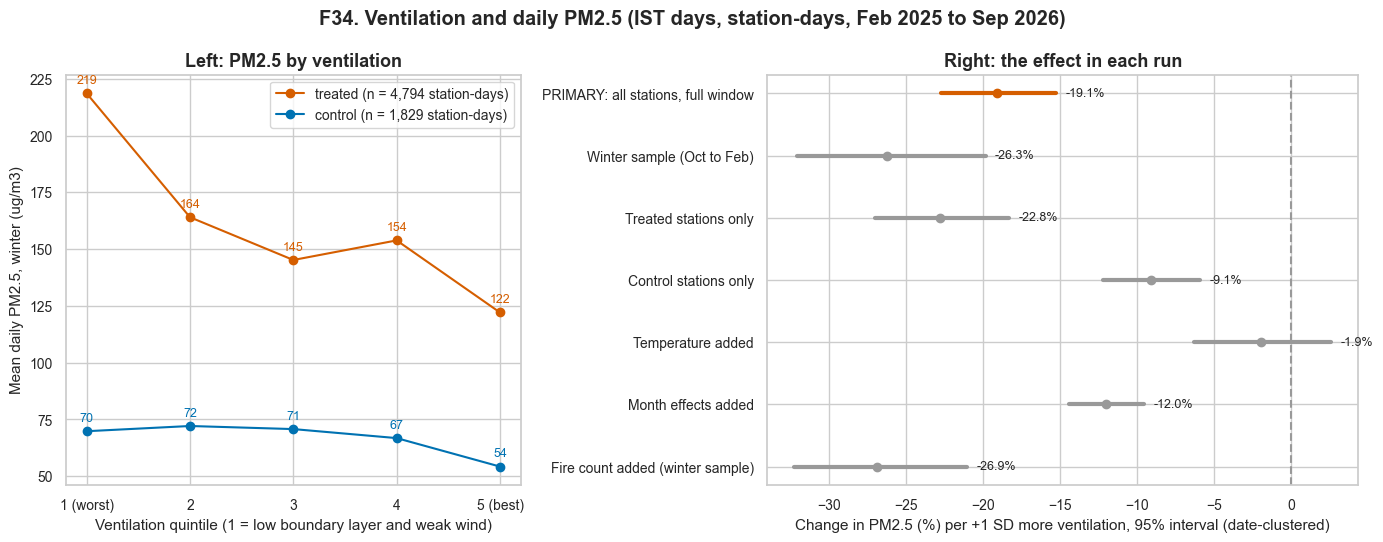

In [193]:
# Step 8C.3b: F34 left: mean PM2.5 by ventilation quintile (value on each point); right: the effect of +1 SD ventilation in every run with its 95% interval
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})
for g in ["treated", "control"]:
    s_q = quint[quint["group"] == g]
    axs[0].plot(s_q["quintile"].astype(str), s_q["Mean PM2.5 (ug/m3)"], "-o", color=COL[g], label=f"{g} (n = {int(s_q['Station-days'].sum()):,} station-days)")
    for xq, vq in zip(s_q["quintile"].astype(str), s_q["Mean PM2.5 (ug/m3)"]):
        axs[0].annotate(f"{vq:.0f}", (xq, vq), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9, color=COL[g])
axs[0].set(xlabel="Ventilation quintile (1 = low boundary layer and weak wind)", ylabel="Mean daily PM2.5, winter (ug/m3)", title="Left: PM2.5 by ventilation"); axs[0].legend()
for k, (name, row) in enumerate(vent_runs.iloc[::-1].iterrows()):
    c_run = COL["treated"] if name.startswith("PRIMARY") else GREY
    axs[1].plot([row["CI low"], row["CI high"]], [k, k], color=c_run, lw=3); axs[1].plot(row["Effect (%)"], k, "o", color=c_run)
    axs[1].text(row["CI high"] + 0.6, k, f"{row['Effect (%)']:+.1f}%", va="center", fontsize=9)
axs[1].axvline(0, color=GREY, ls="--"); axs[1].set_yticks(range(len(vent_runs))); axs[1].set_yticklabels(vent_runs.index[::-1])
axs[1].set(xlabel="Change in PM2.5 (%) per +1 SD more ventilation, 95% interval (date-clustered)", title="Right: the effect in each run")
fig.suptitle("F34. Ventilation and daily PM2.5 (IST days, station-days, Feb 2025 to Sep 2026)", fontweight="bold"); plt.tight_layout(); save_fig(fig, "F34_h3_ventilation"); plt.show()

*F34. Left: mean daily PM2.5 in the winter sample (1 Oct 2025 to 28 Feb 2026) by quintile of the ventilation index V, for treated (orange) and control (blue) stations; the value is written on each point. Right: the % change in PM2.5 per +1 SD more ventilation in the primary run (orange) and the six sensitivity runs (grey), with 95% intervals clustered by date; the dashed line marks zero. Station-days; V is the z-score of log boundary-layer height plus log wind speed. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** PM2.5 is highest on the days with the worst ventilation, and the association keeps its sign in every run. Where an interval touches zero, the run is the one that already includes a second seasonal variable.

**What it does not show.** That boundary-layer height or wind alone explain PM2.5: temperature, boundary-layer height and the season move together, so the effect shrinks when temperature is added. The quintile panel is a winter picture and compares stations with very different PM2.5 levels. An association, not a cause.

In [194]:
# Step 8C.4a: ADDED AFTER SEEING RESULTS: out-of-sample check on the frozen split (train to 31 Dec 2025, test from 1 Jan 2026): does V help on unseen days?
h3_need = ["wind_dir_sin", "rh_pct", "tp_mm", "sp_hpa", "t2m_c"]
train_v, test_v = vent[vent["date_ist"] <= TRAIN_END].dropna(subset=h3_need), vent[vent["date_ist"] >= TEST_START].dropna(subset=h3_need)
test_v = test_v[test_v["station_id"].isin(train_v["station_id"].unique())]
actual_v, rows_oos = test_v["pm25_day"].to_numpy(), []
for label, terms in [("Stations and weekday only", "1"), ("+ ventilation V", "V"), ("+ eight weather controls (frozen H1 set)", CONTROLS), ("+ eight weather controls and V", f"{CONTROLS} + V")]:
    pred_v = fit_predict(train_v, test_v, terms)
    rows_oos.append({"Model": label, "Test RMSE (ug/m3)": np.sqrt(np.mean((actual_v - pred_v) ** 2)), "Test MAE (ug/m3)": np.mean(np.abs(actual_v - pred_v)),
                     "Test fit (R2)": 1 - np.sum((actual_v - pred_v) ** 2) / np.sum((actual_v - actual_v.mean()) ** 2)})
oos_table = pd.DataFrame(rows_oos).set_index("Model")
display(oos_table.round(3)); print("Train station-days:", f"{len(train_v):,}", "| test station-days:", f"{len(test_v):,}")
save_table(oos_table, "T08j_h3_out_of_sample")
log_extension("8C.4", "H3: out-of-sample check of the ventilation index on the frozen time split (four models)")

,Test RMSE (ug/m3),Test MAE (ug/m3),Test fit (R2)
Model,,,
Stations and weekday only,43.084,35.581,-0.247
+ ventilation V,40.406,31.444,-0.097
+ eight weather controls (frozen H1 set),34.119,23.642,0.218
+ eight weather controls and V,32.998,22.448,0.268


Train station-days: 14,834 | test station-days: 11,891
saved table : T08j_h3_out_of_sample


In [195]:
# Step 8C.4b: takeaway text for the out-of-sample check (numbers from the table above)
show_takeaway(f"**What we learn:** on unseen days (1 Jan to 30 Sep 2026) adding V to station and weekday effects changes the test RMSE from **{oos_table.iloc[0]['Test RMSE (ug/m3)']:.1f}** to "
              f"**{oos_table.iloc[1]['Test RMSE (ug/m3)']:.1f}** ug/m3, and on top of the eight weather controls from **{oos_table.iloc[2]['Test RMSE (ug/m3)']:.1f}** to "
              f"**{oos_table.iloc[3]['Test RMSE (ug/m3)']:.1f}** ug/m3, so the index carries information that the other weather terms do not. In the quintile table, treated winter PM2.5 falls from "
              f"**{quint[(quint['group'] == 'treated')].iloc[0]['Mean PM2.5 (ug/m3)']:.0f}** ug/m3 in the worst quintile to **{quint[(quint['group'] == 'treated')].iloc[-1]['Mean PM2.5 (ug/m3)']:.0f}** ug/m3 in the best treated quintile.")

**What we learn:** on unseen days (1 Jan to 30 Sep 2026) adding V to station and weekday effects changes the test RMSE from **43.1** to **40.4** ug/m3, and on top of the eight weather controls from **34.1** to **33.0** ug/m3, so the index carries information that the other weather terms do not. In the quintile table, treated winter PM2.5 falls from **219** ug/m3 in the worst quintile to **122** ug/m3 in the best treated quintile.

**What it shows.** Poor ventilation (a low boundary layer with weak wind) goes with higher PM2.5, the association survives every sensitivity run in sign, and the index improves the prediction of days the model has not seen. It supports the cold-spell and stagnation warning of the recommendations.

**What it does not show.** A separate effect of wind or boundary-layer height once the cold season is controlled: with temperature added the interval includes zero. It does not change the frozen status of H1 or H2, it was chosen after seeing results, and it is an association from one winter and one spring-to-monsoon stretch. The test period holds few smog days, so the test fit stays modest.

---
# Phase 9: H2, GRAP and PM2.5
*BADIR: **A**nalysis and **I**nsights.* **H2:** PM2.5 falls after GRAP activation, relative to the trend predicted by weather and fires alone.

The plan is frozen in Phase 7 (table T07b and the H2 table). In short: an **event** is an upward stage change to Stage II or higher with at least 7 clean days on each side; for each event a **counterfactual** (what PM2.5 would have been without the stage) is built from weather, upwind fire and day of week on the 60 days before; the **effect** is *actual minus predicted* over days 1 to 3 and days 4 to 7 after a 12-hour buffer; **placebo events** show how large such differences are when no stage was invoked.

**Two clarifications made before any H2 outcome was computed** (they make frozen rules operational, they do not change them):
1. *Which window decides the status?* The decision rule says "post-activation actual minus predicted". It is applied to the **days 1 to 3** window (the short-run response H2 describes), and the **days 4 to 7** window must point the same way.
2. *What is a "lower tail"?* The real events must lie in the **lowest 10%** of their placebo distribution.

**What we know already (Phase 7):** only **one** event qualifies under the primary rule, so on the primary set H2 can be **at best inconclusive**. The secondary event sets are reported beside it, never in its place.

In [196]:
# Step 9.0: the one new constant (clarification 2 above), written before any H2 outcome is computed
LOWER_TAIL = 0.10                                  # real events must lie in the lowest 10% of their placebo distribution
print("Frozen H2 settings in use: buffer", BUFFER_HOURS, "h | fit window", FIT_WINDOW_DAYS, "days | hold-out", HOLDOUT_DAYS, "days | windows", EFFECT_WINDOWS,
      "| usable if hold-out error <=", f"{FIT_MAX_ERROR:.0%}", "| lower tail", f"{LOWER_TAIL:.0%}")

Frozen H2 settings in use: buffer 12 h | fit window 60 days | hold-out 10 days | windows [(1, 3), (4, 7)] | usable if hold-out error <= 25% | lower tail 10%


## 9.1 The event table (T5)

**Question:** which stage changes are there, which qualify as events, and does the list agree with the CAQM orders?
**Sample:** all 30 stage changes of the treated stations (from the stage series), joined to the order file `data/processed/grap_orders.csv` (date, time source). **Look for:** the reason each change is or is not an event, outage hours near it, and how many orders do not change the stage.

In [197]:
# Step 9.1a: reconcile the stage changes with the orders: each change should match an order of the same date and direction
orders = pd.read_csv(os.path.join(ROOT, "data", "processed", "grap_orders.csv"), parse_dates=["order_date"])
orders = orders[orders["action"].isin(["invoke", "revoke"])].copy()
orders = orders[orders["order_date"].between(df["date_ist"].min(), df["date_ist"].max())]
orders["stage_after"] = np.where(orders["action"] == "invoke", orders["stage"], orders["stage"] - 1).astype(int)       # revoking Stage k leaves Stage k-1

change_key = set(zip(changes["hour_ist"].dt.normalize(), changes["stage_after"]))
order_key = set(zip(orders["order_date"], orders["stage_after"]))
orders_without_change = orders[[(d, s) not in change_key for d, s in zip(orders["order_date"], orders["stage_after"])]]
changes_without_order = [k for k in change_key if k not in order_key]
print(f"Orders in the window: {len(orders)} | stage changes: {len(changes)} | changes without a matching order: {len(changes_without_order)}")
display(orders_without_change[["order_date", "action", "stage", "stage_after", "time_source", "note"]])

Orders in the window: 31 | stage changes: 30 | changes without a matching order: 0


,order_date,action,stage,stage_after,time_source,note
5,2025-03-07,invoke,1.0,1,pib_posted,NaN


In [198]:
# Step 9.1b: build the event table T5: one row per stage change with its context (stage series, orders, PM2.5 around it, outage hours)
t_series = changes.copy()
order_info = orders.groupby(["order_date", "stage_after"]).agg(order_action=("action", "first"), time_source=("time_source", "first")).reset_index()
t_series["date"] = t_series["hour_ist"].dt.normalize()
event_table = t_series.merge(order_info, left_on=["date", "stage_after"], right_on=["order_date", "stage_after"], how="left").drop(columns=["order_date", "date"])
event_table.index = changes.index

hour_flags = df[df["group"] == "treated"].groupby("hour_ist")[["grap_uncertain", "grap_inferred"]].max()
event_table["stage_hour_uncertain"] = hour_flags.reindex(event_table["hour_ist"])["grap_uncertain"].to_numpy()
event_table["another_change_within_7d"] = (event_table["days_since_previous"] < MIN_CLEAN_DAYS) | (event_table["days_to_next"] < MIN_CLEAN_DAYS)
event_table["reason"] = np.select(
    [event_table["direction"] == "down", event_table["stage_after"] < MIN_EVENT_STAGE, event_table["another_change_within_7d"]],
    ["revocation, not an activation", f"below Stage {MIN_EVENT_STAGE}", f"another change within {MIN_CLEAN_DAYS} days"], default="qualifies")
print(event_table["reason"].value_counts().to_dict())

{'revocation, not an activation': 16, 'below Stage 2': 8, 'another change within 7 days': 5, 'qualifies': 1}


In [199]:
# Step 9.1c: add the PM2.5 context (7 days before the buffer) from the treated daily series built in the next phase's helper; shown as T5
def pre_context(t0):
    # Mean PM2.5 and the daily trend (% per day) over the 7 full days before the 12-hour buffer of a change
    last_pre = (t0 - pd.Timedelta(hours=BUFFER_HOURS)).floor("D") - pd.Timedelta(days=1)
    days = daily_pm_treated.reindex(pd.date_range(last_pre - pd.Timedelta(days=6), last_pre)).dropna()
    trend = np.expm1(np.polyfit(np.arange(len(days)), np.log(days.to_numpy()), 1)[0]) * 100 if len(days) >= 4 else np.nan
    return days.mean() if len(days) else np.nan, trend

daily_pm_treated = analysis_group_day[analysis_group_day["group"] == "treated"].set_index("date_ist")["pm25"]
context = [pre_context(t) for t in event_table["hour_ist"]]
event_table["pm25_7d_before"] = [round(c[0], 1) for c in context]
event_table["pm25_trend_pct_per_day"] = [round(c[1], 1) for c in context]
event_table["primary_event"] = event_table["qualifies"]
event_table.index.name = "Change"
shown_cols = ["hour_ist", "stage_before", "stage_after", "direction", "time_source", "stage_hour_uncertain", "pm25_7d_before", "pm25_trend_pct_per_day",
              "outage_hours_within_7_days", "another_change_within_7d", "reason"]
display(event_table[shown_cols])
save_table(event_table, "T05_event_table")

,hour_ist,stage_before,stage_after,direction,time_source,stage_hour_uncertain,pm25_7d_before,pm25_trend_pct_per_day,outage_hours_within_7_days,another_change_within_7d,reason
Change,,,,,,,,,,,
1,2025-02-24 19:00:00,2,1,down,pib_posted,True,67.5,-2.9,0,True,"revocation, not an activation"
2,2025-03-15 23:00:00,1,0,down,pib_posted,True,95.1,0.5,0,False,"revocation, not an activation"
3,2025-03-24 20:00:00,0,1,up,pib_posted,True,69.2,5.8,0,True,below Stage 2
4,2025-03-29 19:00:00,1,0,down,pib_posted,True,90.9,-0.9,2,True,"revocation, not an activation"
5,2025-04-02 19:00:00,0,1,up,pib_posted,True,72.3,-7.2,16,True,below Stage 2
6,2025-05-01 19:00:00,1,0,down,pib_posted,True,85.9,-7.5,2,False,"revocation, not an activation"
7,2025-05-16 21:00:00,0,1,up,pib_posted,True,80.8,9.5,2,True,below Stage 2
8,2025-05-18 19:00:00,1,0,down,pib_posted,True,78.5,7.7,4,True,"revocation, not an activation"
9,2025-05-21 12:00:00,0,1,up,assumed,True,87.5,-8.2,35,True,below Stage 2


saved table : T05_event_table


In [200]:
# Step 9.1d: takeaway text
n_uncertain = int(event_table["stage_hour_uncertain"].fillna(False).sum())
sources = event_table["time_source"].value_counts().to_dict()
show_takeaway(
    f"**What we learn:** the **{len(changes)}** stage changes agree with the orders: **{len(changes_without_order)}** changes have no matching order and **{len(orders_without_change)}** order(s) leave the stage unchanged "
    f"(an invocation of a stage that already applied, because the stage was carried through a missing-order gap). The reasons a change is not a primary event: {event_table['reason'].value_counts().to_dict()}. "
    f"The hour of the change is uncertain for **{n_uncertain}** of them; the order time comes from {sources}."
)

**What we learn:** the **30** stage changes agree with the orders: **0** changes have no matching order and **1** order(s) leave the stage unchanged (an invocation of a stage that already applied, because the stage was carried through a missing-order gap). The reasons a change is not a primary event: {'revocation, not an activation': 16, 'below Stage 2': 8, 'another change within 7 days': 5, 'qualifies': 1}. The hour of the change is uncertain for **27** of them; the order time comes from {'pib_posted': 16, 'assumed': 11, 'meeting': 3}.

**What it shows.** One row per stage change: when, from which stage to which, where the time comes from (the time stated in the order, the time the press release was posted, an assumed time or a meeting time), the PM2.5 level and trend in the week before, outage hours within a week, whether another change is close, and why it is or is not an event.

**What it does not show.** The hour of a change is uncertain for many orders, which is why a 12-hour buffer is cut out around it. The pre-change trend is a short-run description of the week before, not a forecast. The table says nothing about what happened after the change; that is the job of the counterfactual below.

## 9.2 Events on the timeline (F3b)

**Question:** where do the stage changes fall in the PM2.5 record, and how are they spread over the months?
**Classes:** *primary event* (the frozen rule), *secondary-set event* (one of the two secondary sets fixed in Phase 7), *other activation* (an upward change that does not qualify) and *revocation* (a downward change).

In [201]:
# Step 9.2a: classify every stage change and count them by month
def pick_events(min_stage, clean):
    # numbers of the upward changes to at least min_stage with at least `clean` days without another change on each side
    hit = changes[(changes["direction"] == "up") & (changes["stage_after"] >= min_stage) & (changes["days_since_previous"] >= clean) & (changes["days_to_next"] >= clean)]
    return list(hit.index)

primary_events = pick_events(MIN_EVENT_STAGE, MIN_CLEAN_DAYS)
secondary_events = {name: pick_events(*rule) for name, rule in SECONDARY_EVENT_RULES.items()}
secondary_union = sorted(set().union(*secondary_events.values()) - set(primary_events))
change_class = pd.Series("Other activation", index=changes.index)
change_class[changes["direction"] == "down"] = "Revocation"
change_class[secondary_union] = "Secondary-set event"
change_class[primary_events] = "Primary event"
by_month = pd.crosstab(changes["hour_ist"].dt.strftime("%Y-%m"), change_class).reindex(columns=["Primary event", "Secondary-set event", "Other activation", "Revocation"], fill_value=0)
display(change_class.value_counts().to_frame("Changes"))
print("Primary:", primary_events, "| secondary sets:", {k: v for k, v in secondary_events.items()})

,Changes
Revocation,16
Other activation,9
Secondary-set event,4
Primary event,1


Primary: [15] | secondary sets: {'S1: Stage I or higher, 7 clean days': [11, 15, 27, 29], 'S2: Stage II or higher, 5 clean days': [14, 15]}


saved figure: F3b_stage_changes_timeline


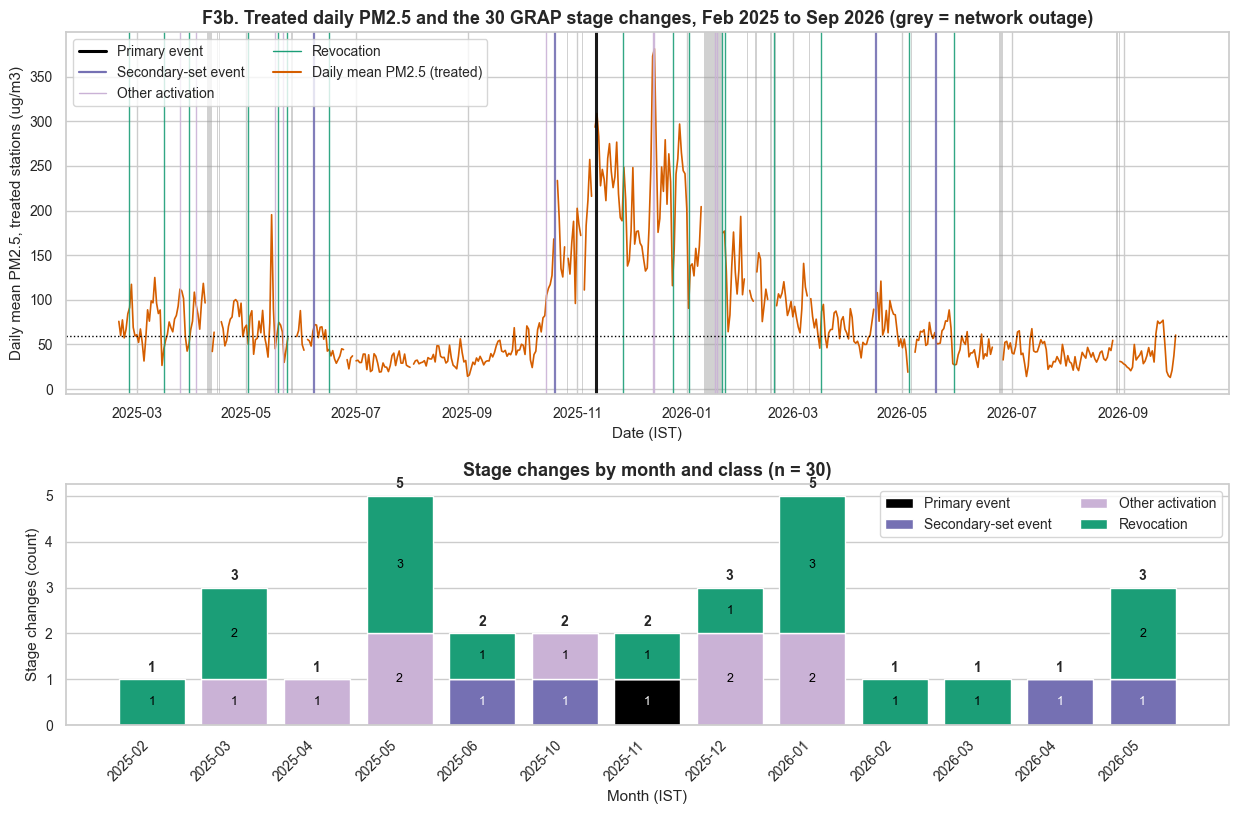

In [202]:
# Step 9.2b: F3b top: daily treated PM2.5 with the stage changes marked; bottom: changes by month and class, counts written on the bars
from matplotlib.lines import Line2D
class_style = {"Primary event": ("#000000", 2.2), "Secondary-set event": ("#7570B3", 1.6), "Other activation": ("#CAB2D6", 1.0), "Revocation": ("#1B9E77", 1.0)}
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(15, 9), gridspec_kw={"height_ratios": [3, 2], "hspace": 0.3})
ax.plot(date_grid, daily_pm_treated.reindex(date_grid), color=COL["treated"], lw=1.2)
for start, end in zip(long_runs["start"], long_runs["end"]):
    ax.axvspan(start, end + pd.Timedelta("1h"), color=GREY, alpha=0.45, lw=0)
for number, row in changes.iterrows():
    colour, width = class_style[change_class[number]]
    ax.axvline(row["hour_ist"], color=colour, lw=width, alpha=0.9)
ax.axhline(STANDARD, color="black", ls=":", lw=1)
ax.set(ylabel="Daily mean PM2.5, treated stations (ug/m3)", xlabel="Date (IST)", title="F3b. Treated daily PM2.5 and the 30 GRAP stage changes, Feb 2025 to Sep 2026 (grey = network outage)")
ax.legend(handles=[Line2D([], [], color=c, lw=w, label=k) for k, (c, w) in class_style.items()] + [Line2D([], [], color=COL["treated"], label="Daily mean PM2.5 (treated)")], loc="upper left", ncol=2)
bottom = np.zeros(len(by_month))
for name, (colour, _) in class_style.items():
    ax2.bar(by_month.index, by_month[name], bottom=bottom, color=colour, label=name, edgecolor="white")
    for x, (v, b0) in enumerate(zip(by_month[name], bottom)):
        if v: ax2.text(x, b0 + v / 2, str(int(v)), ha="center", va="center", fontsize=9, color="white" if name in ("Primary event", "Secondary-set event") else "black")
    bottom += by_month[name].to_numpy()
for x, total in enumerate(bottom):
    ax2.text(x, total + 0.1, f"{int(total)}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax2.set(ylabel="Stage changes (count)", xlabel="Month (IST)", title=f"Stage changes by month and class (n = {len(changes)})"); ax2.legend(loc="upper right", ncol=2)
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right"); ax2.grid(axis="x", visible=False)
save_fig(fig, "F3b_stage_changes_timeline"); plt.show()

In [203]:
# Step 9.2c: takeaway text
months_with_primary = by_month[by_month["Primary event"] > 0].index.tolist()
busiest = by_month.sum(axis=1).idxmax()
show_takeaway(
    f"**What we learn:** of the **{len(changes)}** stage changes, **{int((change_class == 'Primary event').sum())}** is a primary event (**{', '.join(months_with_primary)}**), "
    f"**{int((change_class == 'Secondary-set event').sum())}** more belong to a secondary set, **{int((change_class == 'Other activation').sum())}** are other activations and "
    f"**{int((change_class == 'Revocation').sum())}** are revocations. The busiest month is **{busiest}** (**{int(by_month.sum(axis=1).max())}** changes)."
)

**What we learn:** of the **30** stage changes, **1** is a primary event (**2025-11**), **4** more belong to a secondary set, **9** are other activations and **16** are revocations. The busiest month is **2025-05** (**5** changes).

*F3b. Top: daily mean PM2.5 of the treated stations (orange) with every GRAP stage change as a vertical line, coloured by class; grey bands are network outages of at least 12 hours. Bottom: number of stage changes per month by class, counts written on the bars. n = 30 changes, Feb 2025 to Sep 2026 (IST). Source: `final_dataset.parquet`, `grap_orders.csv`.*

### 9.3 How many events can we use, and why not the rest?

**What it shows.** Most changes are revocations or Stage I invocations in the spring and summer, when pollution is already moderate. The strict Stage III and IV changes cluster in November to January, often only days apart, so most of them have another change within a week and fail the "7 clean days" rule. Only one activation to Stage II or higher is isolated enough to be a primary event.

**What it does not show.** The events are not a random sample of days: a stage is invoked **because** pollution is high or rising, which is why we need placebo events. That we are left with very few events is a feature of the policy record (stages are changed in quick succession in smog episodes), not of our choice of rule; the secondary sets show how much the picture changes if the rule is loosened.

## 9.4 The counterfactual for each event (T6a)

**Question:** what would PM2.5 have been after the activation *if the stage had not been invoked*, judged from weather and fire alone?
**Method (frozen in Phase 7):** a regression of log PM2.5 on wind speed, wind direction, temperature, humidity, boundary-layer height, rain, pressure, upwind fire (previous day) and day of week, fitted on the **60 days before the change** (days within 7 days of another change and outage days are left out); the **last 10 days are held out** to check the fit, and the event is *usable* only if the hold-out error is at most 25% of PM2.5. The **effect** is *actual minus predicted* after a 12-hour buffer, in log points (and as a %), for days 1 to 3 and days 4 to 7. The **95% interval** is a block bootstrap (2,000 draws, blocks of 3 days).

In [204]:
# Step 9.4a: daily series of a set of stations: valid group-day PM2.5 (log) and mean daily drivers (all stations of the set, whether or not PM2.5 was valid)
def build_series(stations):
    st = analysis_station_day[analysis_station_day["station_id"].isin(stations)]
    gd = group_day(st, pd.Series({st["group"].iloc[0]: len(stations)})).set_index("date_ist")["pm25"]     # needs at least half of the stations
    drv = daily_weather[daily_weather["station_id"].isin(stations)].merge(daily_fire[["station_id", "date_ist", FIRE]], on=["station_id", "date_ist"])
    out = drv.groupby("date_ist")[["u10", "v10", "wind_speed", "t2m_c", "rh_pct", "blh_m", "sp_hpa", "tp_mm", FIRE]].mean()
    out["wind_dir_sin"] = np.sin(np.radians((180 + np.degrees(np.arctan2(out["u10"], out["v10"]))) % 360))
    out["wind_dir_cos"] = np.cos(np.radians((180 + np.degrees(np.arctan2(out["u10"], out["v10"]))) % 360))
    out["flagged"] = drv.groupby("date_ist")[["grap_uncertain", "grap_inferred"]].max().any(axis=1)          # stage uncertain or inferred that day
    out["pm25"] = gd.reindex(out.index)
    out["log_pm25"], out["weekday"] = np.log(out["pm25"]), out.index.dayofweek
    return out

treated_ids = sorted(df.loc[df["group"] == "treated", "station_id"].unique())
control_ids = sorted(df.loc[df["group"] == "control", "station_id"].unique())
series_treated, series_control = build_series(treated_ids), build_series(control_ids)
print("Treated series:", series_treated["pm25"].notna().sum(), "valid days | control series:", series_control["pm25"].notna().sum(), "valid days")

Treated series: 542 valid days | control series: 544 valid days


In [205]:
# Step 9.4b: small helpers for the counterfactual (design matrix, event days, block resampling)
DRIVERS = ["wind_speed", "wind_dir_sin", "wind_dir_cos", "t2m_c", "rh_pct", "blh_m", "tp_mm", "sp_hpa"]

def design_matrix(rows, use_fire=True):
    # constant, the drivers (with the upwind fire count unless use_fire is False) and day-of-week effects
    cols = ([FIRE] if use_fire else []) + DRIVERS
    dow = pd.get_dummies(pd.Categorical(rows["weekday"], categories=range(7)), drop_first=True).to_numpy(float)
    return np.column_stack([np.ones(len(rows)), rows[cols].to_numpy(float), dow])

def event_days(t0):
    # last full day before the buffer and first full day after it (the buffer is BUFFER_HOURS either side of the change)
    return ((t0 - pd.Timedelta(hours=BUFFER_HOURS)).floor("D") - pd.Timedelta(days=1)), (t0 + pd.Timedelta(hours=BUFFER_HOURS)).ceil("D")

def block_resample(resid, length, rng):
    # a moving-block resample (blocks of BLOCK_DAYS consecutive observations) of `length` residuals
    starts = rng.integers(0, max(len(resid) - BLOCK_DAYS + 1, 1), size=int(np.ceil(length / BLOCK_DAYS)))
    return resid[((starts[:, None] + np.arange(BLOCK_DAYS)).ravel()[:length]) % len(resid)]

def holdout_error(rows, use_fire=True):
    # fit on all but the last HOLDOUT_DAYS days and return the mean absolute error on those days as a share of their mean PM2.5
    fit_rows, hold = rows.iloc[:-HOLDOUT_DAYS], rows.iloc[-HOLDOUT_DAYS:]
    X = design_matrix(fit_rows, use_fire)
    beta = np.linalg.lstsq(X, fit_rows["log_pm25"].to_numpy(), rcond=None)[0]
    smear = np.exp(fit_rows["log_pm25"].to_numpy() - X @ beta).mean()
    return np.mean(np.abs(hold["pm25"].to_numpy() - np.exp(design_matrix(hold, use_fire) @ beta) * smear)) / hold["pm25"].mean()

In [206]:
# Step 9.4c: fit the counterfactual model for one change (the 60 days before the buffer, minus days near other changes and unusable days)
def fit_counterfactual(series, t0, other_changes, use_fire=True, drop_flagged=False):
    last_pre, first_post = event_days(t0)
    days = pd.date_range(last_pre - pd.Timedelta(days=FIT_WINDOW_DAYS - 1), last_pre)
    near = [d for d in days if any(abs((d - c.normalize()).days) <= MIN_CLEAN_DAYS for c in other_changes)]       # days close to another change
    cols = ["log_pm25", "weekday"] + ([FIRE] if use_fire else []) + DRIVERS
    rows = series.reindex(days).drop(near).dropna(subset=cols)
    if drop_flagged:
        rows = rows[~rows["flagged"].astype(bool)]
    fit = {"last_pre": last_pre, "first_post": first_post, "n_fit": len(rows), "cols": cols[2:], "use_fire": use_fire, "usable": False}
    if len(rows) < HOLDOUT_DAYS + 15:
        return {**fit, "reason": "too few fit days"}
    X, y = design_matrix(rows, use_fire), rows["log_pm25"].to_numpy()
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    error = holdout_error(rows, use_fire)
    return {**fit, "X": X, "y": y, "beta": beta, "resid": y - X @ beta, "smear": np.exp(y - X @ beta).mean(), "holdout_error": error,
            "usable": error <= FIT_MAX_ERROR, "reason": "" if error <= FIT_MAX_ERROR else f"hold-out error {error:.0%} above {FIT_MAX_ERROR:.0%}"}

In [207]:
# Step 9.4d: the effect over a window of post-activation days: actual minus predicted, with a block-bootstrap interval for the effect
def window_days(first_post, a, b):
    return pd.date_range(first_post + pd.Timedelta(days=a - 1), first_post + pd.Timedelta(days=b - 1))

def effect_from_fit(fit, series, windows=EFFECT_WINDOWS, draws=0):
    rng = np.random.default_rng(SEED)
    X, beta, resid, use_fire = fit["X"], fit["beta"], fit["resid"], fit["use_fire"]
    betas = np.array([np.linalg.lstsq(X, X @ beta + block_resample(resid, len(resid), rng), rcond=None)[0] for _ in range(draws)]) if draws else None
    results = []
    for a, b in windows:
        post = series.reindex(window_days(fit["first_post"], a, b)).dropna(subset=["log_pm25"] + fit["cols"])
        if post.empty:
            results.append({"window": f"days {a} to {b}", "days": 0, "effect_pct": np.nan}); continue
        Xp = design_matrix(post, use_fire)
        effect = float(np.mean(post["log_pm25"].to_numpy() - Xp @ beta))
        res = {"window": f"days {a} to {b}", "days": len(post), "effect_log": effect, "effect_pct": np.expm1(effect) * 100,
               "effect_ugm3": float(np.mean(post["pm25"].to_numpy() - np.exp(Xp @ beta) * fit["smear"]))}
        if draws:                                          # null distribution of the effect (no true effect): estimation error + noise of the post days
            null = ((Xp @ beta)[:, None] - Xp @ betas.T).mean(axis=0) + np.array([block_resample(resid, len(post), rng).mean() for _ in range(draws)])
            res["ci_low_pct"], res["ci_high_pct"] = np.expm1(effect - np.percentile(null, [97.5, 2.5])) * 100
            res["null_log"] = null                              # the simulated no-effect distribution (used for the power calculation)
        results.append(res)
    return results

In [208]:
# Step 9.4e: run the counterfactual for every event in the primary and secondary sets (2,000 bootstrap draws each)
all_events = sorted(set(primary_events) | set(secondary_union))
event_fits, event_effects = {}, {}
for number in all_events:
    t0 = changes.loc[number, "hour_ist"]
    others = [t for n, t in changes["hour_ist"].items() if n != number]
    event_fits[number] = fit_counterfactual(series_treated, t0, others)
    if "X" in event_fits[number]:
        event_effects[number] = effect_from_fit(event_fits[number], series_treated, draws=BOOTSTRAP_DRAWS)
rows = []
for number in all_events:
    f_, e_ = event_fits[number], event_effects.get(number, [{}, {}])
    sets = ("P " if number in primary_events else "") + " ".join(n.split(":")[0] for n, members in secondary_events.items() if number in members)
    rows.append({"Change": number, "Date": f"{changes.loc[number, 'hour_ist']:%d %b %Y}", "Stage": f"{changes.loc[number, 'stage_before']}->{changes.loc[number, 'stage_after']}", "Sets": sets.strip(),
                 "Fit days": f_["n_fit"], "Hold-out error": f_.get("holdout_error", np.nan), "Usable": f_["usable"],
                 "Days 1-3 (%)": e_[0].get("effect_pct", np.nan), "CI 1-3 low": e_[0].get("ci_low_pct", np.nan), "CI 1-3 high": e_[0].get("ci_high_pct", np.nan),
                 "Days 4-7 (%)": e_[1].get("effect_pct", np.nan), "CI 4-7 low": e_[1].get("ci_low_pct", np.nan), "CI 4-7 high": e_[1].get("ci_high_pct", np.nan)})
event_results = pd.DataFrame(rows).set_index("Change")
display(event_results.round(2))
save_table(event_results.round(3), "T06a_h2_events")

,Date,Stage,Sets,Fit days,Hold-out error,Usable,Days 1-3 (%),CI 1-3 low,CI 1-3 high,Days 4-7 (%),CI 4-7 low,CI 4-7 high
Change,,,,,,,,,,,,
11,07 Jun 2025,0->1,S1,15,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN
14,19 Oct 2025,1->2,S2,48,0.29,False,272.74,137.18,475.41,87.76,6.33,232.57
15,11 Nov 2025,2->3,P S1 S2,38,0.90,False,-21.67,-39.82,1.31,-20.68,-45.65,14.35
27,16 Apr 2026,0->1,S1,34,0.48,False,14.94,-20.83,59.59,-18.12,-57.27,48.77
29,19 May 2026,0->1,S1,26,9278655.73,False,-33.10,-47.93,-15.04,3.32,-17.04,29.97


saved table : T06a_h2_events


In [209]:
# Step 9.4f: how many events pass the frozen fit rule, and the pooled estimates (decision basis: usable events only; descriptive: all events)
usable_events = [n for n in all_events if event_fits[n]["usable"]]
rng = np.random.default_rng(SEED)
pool_rows = []
for set_name, members in {"Primary set": primary_events, **secondary_events}.items():
    for basis, only_usable in [("usable events only (decision basis)", True), ("all events, regardless of fit (descriptive)", False)]:
        picks = [n for n in members if n in event_effects and (event_fits[n]["usable"] or not only_usable)]
        vals = np.array([event_effects[n][0]["effect_log"] for n in picks])
        boot = [rng.choice(vals, len(vals)).mean() for _ in range(BOOTSTRAP_DRAWS)] if len(vals) >= 2 else [np.nan, np.nan]
        pool_rows.append({"Set": set_name.split(":")[0], "Basis": basis, "Events": len(picks), "Mean effect days 1-3 (%)": np.expm1(vals.mean()) * 100 if len(vals) else np.nan,
                          "Median (%)": np.expm1(np.median(vals)) * 100 if len(vals) else np.nan,
                          "CI low (%)": np.expm1(np.nanpercentile(boot, 2.5)) * 100, "CI high (%)": np.expm1(np.nanpercentile(boot, 97.5)) * 100})
pooled_table = pd.DataFrame(pool_rows)
display(pooled_table.round(1))
save_table(pooled_table.set_index("Set").round(2), "T06b_h2_pooled")

,Set,Basis,Events,Mean effect days 1-3 (%),Median (%),CI low (%),CI high (%)
0,Primary set,usable events only (decision basis),0,NaN,NaN,NaN,NaN
1,Primary set,"all events, regardless of fit (descriptive)",1,-21.7,-21.7,NaN,NaN
2,S1,usable events only (decision basis),0,NaN,NaN,NaN,NaN
3,S1,"all events, regardless of fit (descriptive)",3,-15.6,-21.7,-33.1,14.9
4,S2,usable events only (decision basis),0,NaN,NaN,NaN,NaN
5,S2,"all events, regardless of fit (descriptive)",2,70.9,70.9,-21.7,272.7


saved table : T06b_h2_pooled


In [210]:
# Step 9.4g: takeaway text for T06a and T06b
primary_number = primary_events[0]
pr, pe = event_results.loc[primary_number], event_effects[primary_number]
show_takeaway(
    f"**What we learn:** **{len(usable_events)}** of the **{len(all_events)}** events pass the frozen fit rule (hold-out error at most {FIT_MAX_ERROR:.0%}). The primary event "
    f"(**{pr['Date']}**, Stage {pr['Stage']}) has a hold-out error of **{pr['Hold-out error']:.0%}**, so its counterfactual is **not usable** under the rule. For information, its estimated effect is "
    f"**{pe[0]['effect_pct']:+.1f}%** over days 1 to 3 (95% interval {pe[0]['ci_low_pct']:+.1f}% to {pe[0]['ci_high_pct']:+.1f}%) and **{pe[1]['effect_pct']:+.1f}%** over days 4 to 7 "
    f"({pe[1]['ci_low_pct']:+.1f}% to {pe[1]['ci_high_pct']:+.1f}%). With no usable event, the decision basis of every set is empty."
)

**What we learn:** **0** of the **5** events pass the frozen fit rule (hold-out error at most 25%). The primary event (**11 Nov 2025**, Stage 2->3) has a hold-out error of **90%**, so its counterfactual is **not usable** under the rule. For information, its estimated effect is **-21.7%** over days 1 to 3 (95% interval -39.8% to +1.3%) and **-20.7%** over days 4 to 7 (-45.6% to +14.3%). With no usable event, the decision basis of every set is empty.

**What it shows.** For every event: how well the weather-and-fire model reproduced the last 10 days before the change (hold-out error), whether that passes the frozen rule, and the effect: actual minus predicted PM2.5 over days 1 to 3 and 4 to 7 after the buffer, with a 95% block-bootstrap interval. The pooled table shows the decision basis (usable events only) and, for information, all events.

**What it does not show.** A number in an unusable row is **not an estimate of the effect of GRAP**: it is the gap between actual PM2.5 and a model that failed to reproduce PM2.5 just before the event. The model is fitted on about 60 days and holds 16 parameters, and the days before an activation are the steep run-up of a smog episode, exactly the conditions that are hardest to predict from earlier, calmer days. This is a genuine limit of the method with one winter of data, not a reason to relax the rule after seeing the result. One fit (19 May 2026) shows an enormous hold-out error because it rests on only 26 days and 16 parameters, and its held-out days lie outside the range the model was fitted on, so the back-transformation from the log scale overflows; its numbers carry no information.

## 9.5 Actual versus counterfactual around each event (F12)

**Question:** how do actual daily PM2.5 and the counterfactual compare in the week before and after each event?
**Reading the panels:** solid line = actual daily PM2.5 (treated stations); dashed line = counterfactual; band = 95% range of the counterfactual including day-to-day noise (block bootstrap); vertical line = the change; orange shading = the 12-hour buffer (left out); grey = days without data. A panel is marked **NOT USABLE** when the fit failed the frozen hold-out rule.

In [211]:
# Step 9.5a: counterfactual path and band for the days around each event (7 full days before the buffer and 7 after)
def counterfactual_band(fit, series, days, draws=1000):
    rng = np.random.default_rng(SEED)
    rows = series.reindex(days).dropna(subset=fit["cols"])
    Xd = design_matrix(rows, fit["use_fire"])
    resid = fit["resid"]
    betas = np.array([np.linalg.lstsq(fit["X"], fit["X"] @ fit["beta"] + block_resample(resid, len(resid), rng), rcond=None)[0] for _ in range(draws)])
    sims = np.exp(Xd @ betas.T + resid[rng.integers(0, len(resid), size=(len(rows), draws))]) * fit["smear"]
    return pd.DataFrame({"counterfactual": np.exp(Xd @ fit["beta"]) * fit["smear"], "low": np.percentile(sims, 2.5, axis=1), "high": np.percentile(sims, 97.5, axis=1)}, index=rows.index)

plot_events = [n for n in all_events if n in event_effects]                      # events with a fitted counterfactual
event_paths = {}
for number in plot_events:
    fit = event_fits[number]
    days = pd.date_range(fit["last_pre"] - pd.Timedelta(days=6), fit["first_post"] + pd.Timedelta(days=6))
    event_paths[number] = (days, counterfactual_band(fit, series_treated, days)) if "X" in fit else (days, None)
print({n: (None if p[1] is None else len(p[1])) for n, p in event_paths.items()})

{14: 15, 15: 15, 27: 15, 29: 16}


saved figure: F12_event_counterfactuals


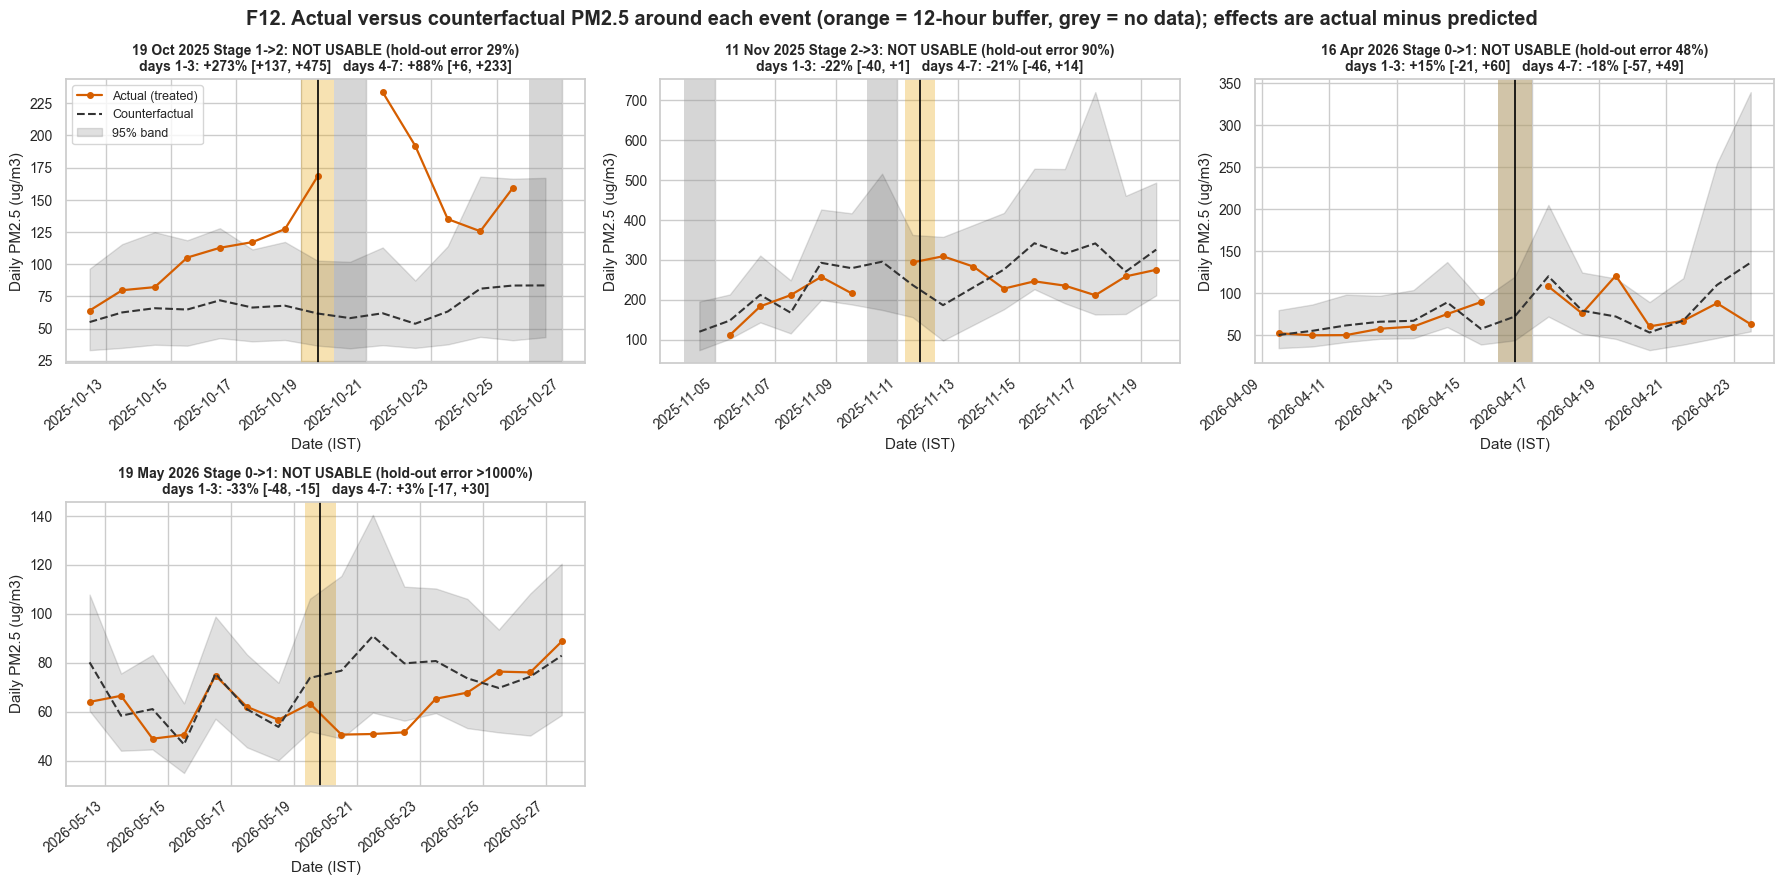

In [212]:
# Step 9.5b: F12 panels (3 per row): actual (solid), counterfactual (dashed) with band, the change (line), the buffer (orange) and missing days (grey)
fig, axes = plt.subplots(2, 3, figsize=(18, 9)); axes = axes.ravel()
for ax, number in zip(axes, plot_events):
    days, path = event_paths[number]; fit, res = event_fits[number], event_effects[number]
    t0 = changes.loc[number, "hour_ist"]
    actual_series = series_treated["pm25"].reindex(days)
    ax.axvspan(t0 - pd.Timedelta(hours=BUFFER_HOURS), t0 + pd.Timedelta(hours=BUFFER_HOURS), color="#E69F00", alpha=0.3, lw=0)
    for day in actual_series[actual_series.isna()].index:
        ax.axvspan(day, day + pd.Timedelta(days=1), color=GREY, alpha=0.4, lw=0)
    ax.plot(actual_series.index + pd.Timedelta(hours=12), actual_series.to_numpy(), "-o", color=COL["treated"], ms=4, lw=1.6, label="Actual (treated)")
    if path is not None:
        ax.plot(path.index + pd.Timedelta(hours=12), path["counterfactual"], "--", color="#333333", lw=1.5, label="Counterfactual")
        ax.fill_between(path.index + pd.Timedelta(hours=12), path["low"], path["high"], color="#333333", alpha=0.15, label="95% band")
    ax.axvline(t0, color="black", lw=1.2)
    flag = "usable" if fit["usable"] else "NOT USABLE (hold-out error " + (f"{fit['holdout_error']:.0%}" if fit['holdout_error'] < 10 else ">1000%") + ")"
    ax.set_title(f"{t0:%d %b %Y} Stage {changes.loc[number, 'stage_before']}->{changes.loc[number, 'stage_after']}: {flag}\ndays 1-3: {res[0]['effect_pct']:+.0f}% [{res[0]['ci_low_pct']:+.0f}, {res[0]['ci_high_pct']:+.0f}]   days 4-7: {res[1]['effect_pct']:+.0f}% [{res[1]['ci_low_pct']:+.0f}, {res[1]['ci_high_pct']:+.0f}]", fontsize=10)
    ax.set_ylabel("Daily PM2.5 (ug/m3)"); ax.set_xlabel("Date (IST)"); plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
for ax in axes[len(plot_events):]:
    ax.axis("off")                                                                   # unused panels
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("F12. Actual versus counterfactual PM2.5 around each event (orange = 12-hour buffer, grey = no data); effects are actual minus predicted", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F12_event_counterfactuals"); plt.show()

In [213]:
# Step 9.5c: takeaway text for F12
unusable_n = sum(not event_fits[n]["usable"] for n in plot_events)
show_takeaway(
    f"**What we learn:** in **{unusable_n}** of the **{len(plot_events)}** fitted events the counterfactual failed the hold-out rule. In the primary event's panel the actual PM2.5 "
    f"stays within the counterfactual band after the change, and the band is wide (it reaches **{event_paths[primary_number][1]['high'].max():.0f} ug/m3**) because the model is fitted on few days with many parameters."
)

**What we learn:** in **4** of the **4** fitted events the counterfactual failed the hold-out rule. In the primary event's panel the actual PM2.5 stays within the counterfactual band after the change, and the band is wide (it reaches **721 ug/m3**) because the model is fitted on few days with many parameters.

*F12. Actual daily PM2.5 of the treated stations (orange, solid) and the counterfactual (dashed) with its 95% band, for each event with a fitted model; the line marks the change, orange shading the 12-hour buffer, grey days without data. Effects in the panel titles are actual minus predicted over days 1 to 3 and 4 to 7 after the buffer, with the 95% block-bootstrap interval. Treated stations, IST. Source: `final_dataset.parquet`.*

**What it shows.** After each change the actual line either stays inside the band (no distinguishable difference from the counterfactual) or leaves it; the panel titles give the numbers. The event of 11 Nov 2025 has a negative estimate whose interval reaches zero, but its model is marked not usable.

**What it does not show.** Whether the stage *caused* any difference: the counterfactual cannot see the forecast of a pollution episode, which is what triggers a stage. The bands also show how uncertain the counterfactual is when it is built from a few weeks of data.

## 9.6 The effect of each event (F13, T6a)

**Question:** how large is the estimated effect for each event, and how uncertain is it?
**Reading the plot:** each event has two rows (days 1 to 3 and days 4 to 7 after the buffer); a **hollow** marker means the event failed the fit rule. The lower rows are pooled estimates over events (descriptive; the decision basis is empty). Values above the axis limit are drawn at the edge and written out in full.

In [214]:
# Step 9.6a: rows of the forest plot: events (two windows each) and descriptive pooled estimates of the secondary sets
forest = []
for number in plot_events:
    for k, label in enumerate(["days 1-3", "days 4-7"]):
        e = event_effects[number][k]
        forest.append({"row": f"{changes.loc[number, 'hour_ist']:%d %b %Y} Stage {changes.loc[number, 'stage_before']}->{changes.loc[number, 'stage_after']}, {label}",
                       "effect": e["effect_pct"], "low": e["ci_low_pct"], "high": e["ci_high_pct"], "n": e["days"], "usable": event_fits[number]["usable"]})
for _, r in pooled_table[pooled_table["Basis"].str.startswith("all")].iterrows():
    if r["Set"] != "Primary set":
        forest.append({"row": f"Pooled {r['Set']}, days 1-3 (descriptive, {int(r['Events'])} events)", "effect": r["Mean effect days 1-3 (%)"], "low": r["CI low (%)"], "high": r["CI high (%)"], "n": int(r["Events"]), "usable": False})
forest_df = pd.DataFrame(forest)
display(forest_df.round(1))

,row,effect,low,high,n,usable
0,"19 Oct 2025 Stage 1->2, days 1-3",272.7,137.2,475.4,2,False
1,"19 Oct 2025 Stage 1->2, days 4-7",87.8,6.3,232.6,3,False
2,"11 Nov 2025 Stage 2->3, days 1-3",-21.7,-39.8,1.3,2,False
3,"11 Nov 2025 Stage 2->3, days 4-7",-20.7,-45.6,14.3,4,False
4,"16 Apr 2026 Stage 0->1, days 1-3",14.9,-20.8,59.6,3,False
5,"16 Apr 2026 Stage 0->1, days 4-7",-18.1,-57.3,48.8,4,False
6,"19 May 2026 Stage 0->1, days 1-3",-33.1,-47.9,-15.0,3,False
7,"19 May 2026 Stage 0->1, days 4-7",3.3,-17.0,30.0,4,False
8,"Pooled S1, days 1-3 (descriptive, 3 events)",-15.6,-33.1,14.9,3,False
9,"Pooled S2, days 1-3 (descriptive, 2 events)",70.9,-21.7,272.7,2,False


saved figure: F13_event_effects


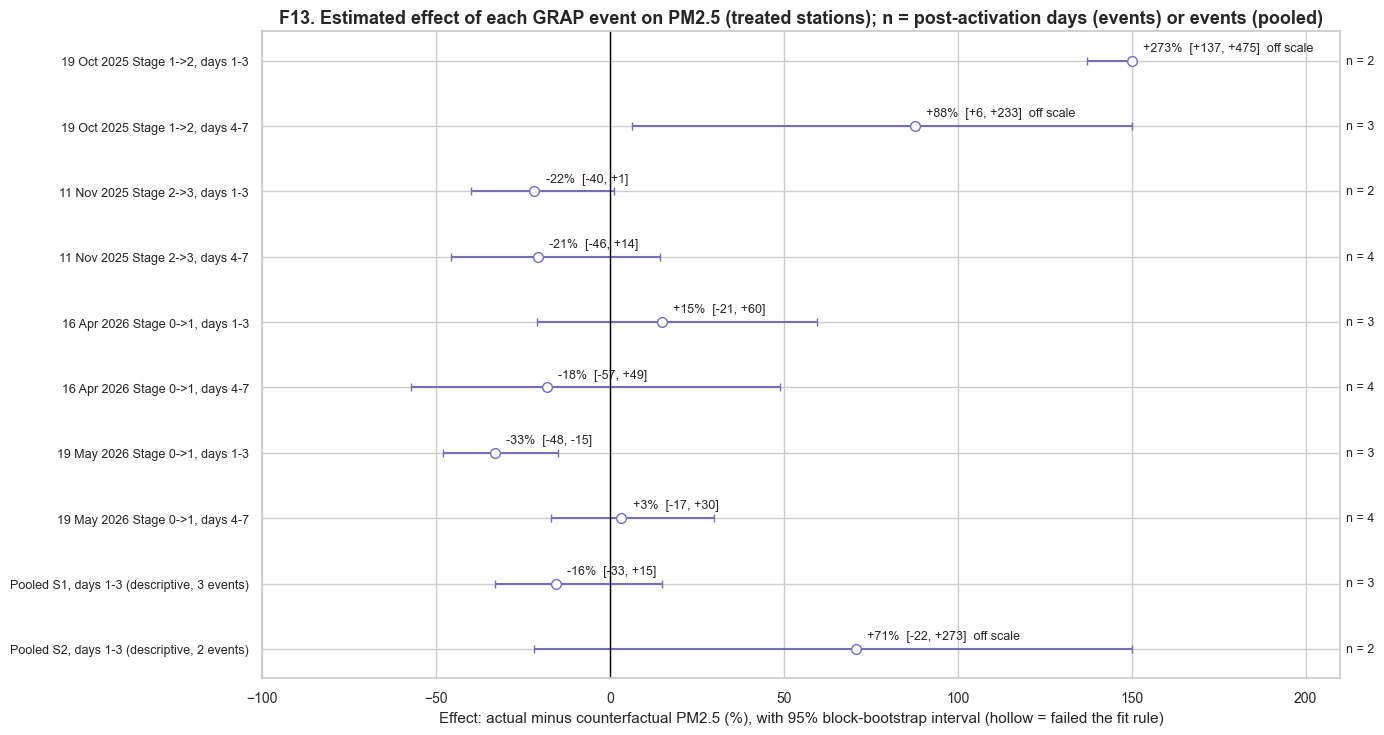

In [215]:
# Step 9.6b: F13 forest plot, estimate and interval written next to each marker, n (days or events) on the right, values beyond the axis written out
XMIN, XMAX = -100, 150
fig, ax = plt.subplots(figsize=(14, 7.5))
y_pos = np.arange(len(forest_df))[::-1]
for y, row in zip(y_pos, forest_df.itertuples()):
    low, high, eff = (np.nan_to_num(v, nan=row.effect) for v in (row.low, row.high, row.effect))
    ax.errorbar(np.clip(eff, XMIN, XMAX), y, xerr=[[np.clip(eff, XMIN, XMAX) - np.clip(low, XMIN, XMAX)], [np.clip(high, XMIN, XMAX) - np.clip(eff, XMIN, XMAX)]],
                fmt="o", color="#7570B3", mfc="#7570B3" if row.usable else "white", capsize=3, ms=7)
    text = f"{row.effect:+.0f}%" + (f"  [{row.low:+.0f}, {row.high:+.0f}]" if not np.isnan(row.low) else "  (no interval)") + ("  off scale" if eff > XMAX or high > XMAX else "")
    ax.annotate(text, (min(max(eff, XMIN), XMAX), y), xytext=(8, 7), textcoords="offset points", fontsize=9)
    ax.text(1.005, y, f"n = {int(row.n)}", transform=ax.get_yaxis_transform(), va="center", fontsize=9)
ax.axvline(0, color="black", lw=1); ax.set_xlim(XMIN, XMAX + 60)
ax.set_yticks(y_pos); ax.set_yticklabels(forest_df["row"], fontsize=9)
ax.set_xlabel("Effect: actual minus counterfactual PM2.5 (%), with 95% block-bootstrap interval (hollow = failed the fit rule)")
ax.set_title("F13. Estimated effect of each GRAP event on PM2.5 (treated stations); n = post-activation days (events) or events (pooled)")
plt.tight_layout(); save_fig(fig, "F13_event_effects"); plt.show()

*F13. Actual minus counterfactual PM2.5 (%) for each event over days 1 to 3 and days 4 to 7, with 95% block-bootstrap intervals; hollow markers failed the fit rule; pooled rows are descriptive. n = number of post-activation days (events) or of events (pooled). Treated stations, IST. Source: `final_dataset.parquet`.*

**What it shows.** Whether the estimates agree in sign across events, how wide the intervals are, and which events (hollow markers) cannot be used. The estimates differ greatly between events, and the intervals are wide.

**What it does not show.** No event passes the fit rule, so the plot does not show an estimate that can be used for the decision. Pooling events with different stages, seasons and pollution levels (a Stage I in April against Stage III in November) averages unlike things; the pooled rows only show how mixed the individual estimates are.

## 9.7 Placebo events: is a fall after a stage unusual? (F14, T6c)

**Question:** activation follows high pollution, and pollution tends to fall afterwards anyway (*regression to the mean*). How does the real event compare with days when **no stage was invoked** but pollution had been similarly high?
**Placebo events (frozen):** (i) dates with no stage change within 7 days whose PM2.5 in the week before is within 15% of the real event's, run through exactly the same method; (ii) the **same dates in the control cities**, where GRAP does not apply. **Lower tail:** the real event counts as unusual if it lies in the lowest 10% of its placebo distribution.

In [216]:
# Step 9.7a: run the same method on placebo dates (no change within 7 days, similar PM2.5 level before), for each fitted event
def placebo_effects(event_number, tolerance=PLACEBO_TOLERANCE):
    t_event, level = changes.loc[event_number, "hour_ist"], event_table.loc[event_number, "pm25_7d_before"]
    real_changes, out = list(changes["hour_ist"]), []
    for day in pd.date_range(series_treated.index.min() + pd.Timedelta(days=45), series_treated.index.max() - pd.Timedelta(days=8)):
        t0 = day + pd.Timedelta(hours=t_event.hour)
        if min(abs((t0 - c).total_seconds()) for c in real_changes) < MIN_CLEAN_DAYS * 86400:
            continue                                                         # a real stage change is too close
        pre = pre_context(t0)[0]
        if not abs(pre - level) <= tolerance * level:
            continue                                                         # the PM2.5 level before is not similar enough
        fit = fit_counterfactual(series_treated, t0, real_changes)
        if "X" in fit:
            eff = effect_from_fit(fit, series_treated)
            out.append({"date": day, "effect_1_3": eff[0].get("effect_pct", np.nan), "effect_4_7": eff[1].get("effect_pct", np.nan), "usable": fit["usable"], "pre_level": pre})
    return pd.DataFrame(out)

placebos = {number: placebo_effects(number) for number in plot_events}
print({n: (len(p), int(p["usable"].sum()) if len(p) else 0) for n, p in placebos.items()}, "(placebo dates, of which usable fits)")

{14: (2, 0), 15: (2, 0), 27: (7, 0), 29: (6, 1)} (placebo dates, of which usable fits)


In [217]:
# Step 9.7b: the same method in the control cities on the real event dates, and the share of placebo effects below each real event (T6c)
control_effect = {}
for number in plot_events:
    t0 = changes.loc[number, "hour_ist"]
    fit_c = fit_counterfactual(series_control, t0, [t for n, t in changes["hour_ist"].items() if n != number])
    control_effect[number] = (effect_from_fit(fit_c, series_control)[0].get("effect_pct", np.nan), fit_c["usable"]) if "X" in fit_c else (np.nan, False)
rows = []
for number in plot_events:
    p, real = placebos[number], event_effects[number][0]["effect_pct"]
    usable_p = p[p["usable"]] if len(p) else p
    rows.append({"Event": f"{changes.loc[number, 'hour_ist']:%d %b %Y}", "Real effect days 1-3 (%)": real, "Placebo dates": len(p), "Share of placebos below the real event (all)": (p["effect_1_3"] < real).mean() if len(p) else np.nan,
                 "Placebo dates with usable fit": len(usable_p), "Share below (usable only)": (usable_p["effect_1_3"] < real).mean() if len(usable_p) else np.nan,
                 "Median placebo effect (%)": p["effect_1_3"].median() if len(p) else np.nan, "Control cities, same date (%)": control_effect[number][0], "Control fit usable": control_effect[number][1]})
placebo_table = pd.DataFrame(rows).set_index("Event")
display(placebo_table.round(2))
save_table(placebo_table.round(3), "T06c_h2_placebo")

,Real effect days 1-3 (%),Placebo dates,Share of placebos below the real event (all),Placebo dates with usable fit,Share below (usable only),Median placebo effect (%),"Control cities, same date (%)",Control fit usable
Event,,,,,,,,
19 Oct 2025,272.74,2,1.00,0,NaN,-41.51,262.40,True
11 Nov 2025,-21.67,2,0.00,0,NaN,183.19,-14.95,False
16 Apr 2026,14.94,7,0.71,0,NaN,-17.19,14.36,True
19 May 2026,-33.10,6,0.00,1,0.0,-19.31,2.73,False


saved table : T06c_h2_placebo


saved figure: F14_placebo_distribution


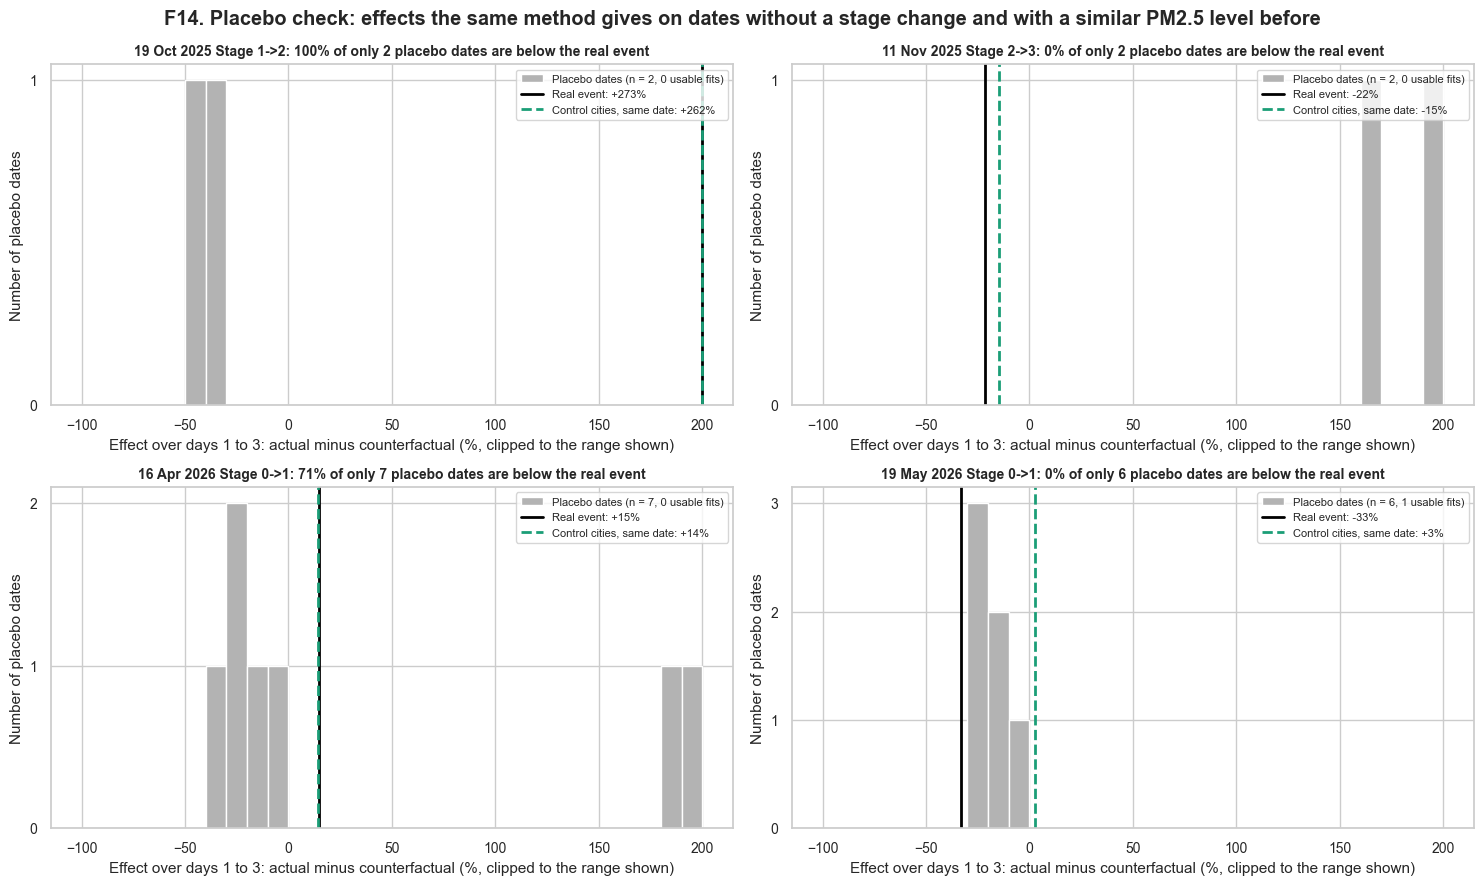

In [218]:
# Step 9.7c: F14 one panel per event: histogram of placebo effects (days 1-3), the real event (black line) and the control cities (green dashed)
fig, axes = plt.subplots(2, 2, figsize=(15, 9)); axes = axes.ravel()
for ax, number in zip(axes, plot_events):
    p, real = placebos[number], event_effects[number][0]["effect_pct"]
    if len(p):
        values = p["effect_1_3"].clip(-100, 200)
        ax.hist(values, bins=np.arange(-100, 205, 10), color="#B3B3B3", edgecolor="white", label=f"Placebo dates (n = {len(p)}, {int(p['usable'].sum())} usable fits)")
    ax.axvline(min(real, 200), color="black", lw=2, label=f"Real event: {real:+.0f}%")
    if not np.isnan(control_effect[number][0]):
        ax.axvline(np.clip(control_effect[number][0], -100, 200), color="#1B9E77", ls="--", lw=2, label=f"Control cities, same date: {control_effect[number][0]:+.0f}%")
    share = placebo_table.iloc[plot_events.index(number)]["Share of placebos below the real event (all)"]
    ax.set_title(f"{changes.loc[number, 'hour_ist']:%d %b %Y} Stage {changes.loc[number, 'stage_before']}->{changes.loc[number, 'stage_after']}: {share:.0%} of only {len(p)} placebo dates are below the real event" if not np.isnan(share) else "no placebo dates", fontsize=10)
    ax.set_xlabel("Effect over days 1 to 3: actual minus counterfactual (%, clipped to the range shown)"); ax.set_ylabel("Number of placebo dates"); ax.legend(fontsize=8, loc="upper right"); ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))     # whole numbers of dates
fig.suptitle("F14. Placebo check: effects the same method gives on dates without a stage change and with a similar PM2.5 level before", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F14_placebo_distribution"); plt.show()

In [219]:
# Step 9.7d: ADDED AFTER SEEING RESULTS (information only): how many placebo dates exist if the PM2.5-level tolerance is widened?
tolerance_rows = []
for tolerance in [PLACEBO_TOLERANCE, 0.30, 0.50]:
    for number in plot_events:
        p = placebos[number] if tolerance == PLACEBO_TOLERANCE else placebo_effects(number, tolerance)
        real = event_effects[number][0]["effect_pct"]
        tolerance_rows.append({"Tolerance": f"{tolerance:.0%}" + (" (frozen)" if tolerance == PLACEBO_TOLERANCE else " (added)"), "Event": f"{changes.loc[number, 'hour_ist']:%d %b %Y}",
                               "Placebo dates": len(p), "Usable fits": int(p["usable"].sum()) if len(p) else 0, "Share below the real event": (p["effect_1_3"] < real).mean() if len(p) else np.nan})
tolerance_table = pd.DataFrame(tolerance_rows)
display(tolerance_table.pivot(index="Event", columns="Tolerance", values="Placebo dates"))
save_table(tolerance_table.set_index("Tolerance").round(3), "T06c2_placebo_tolerance")

Tolerance,15% (frozen),30% (added),50% (added)
Event,,,
11 Nov 2025,2,10,11
16 Apr 2026,7,44,136
19 May 2026,6,45,142
19 Oct 2025,2,12,26


saved table : T06c2_placebo_tolerance


In [220]:
# Step 9.7e: takeaway text for the placebo check
primary_placebo = placebo_table.loc[f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}"]
t_ctl = [(event_effects[n][0]["effect_pct"], control_effect[n][0]) for n in plot_events if not np.isnan(control_effect[n][0])]
show_takeaway(
    f"**What we learn:** the frozen placebo rule leaves only **{int(primary_placebo['Placebo dates'])}** comparable placebo dates for the primary event, with **{int(primary_placebo['Placebo dates with usable fit'])}** usable fits, "
    f"so the placebo distribution is far too small to say whether the real event is unusual. In the control cities, where GRAP does not apply, the same method on the same date gives "
    + "; ".join(f"**{c:+.0f}%** against **{t:+.0f}%** at the treated stations" for t, c in t_ctl) + ". The two groups often show similar departures from their counterfactuals."
)

**What we learn:** the frozen placebo rule leaves only **2** comparable placebo dates for the primary event, with **0** usable fits, so the placebo distribution is far too small to say whether the real event is unusual. In the control cities, where GRAP does not apply, the same method on the same date gives **+262%** against **+273%** at the treated stations; **-15%** against **-22%** at the treated stations; **+14%** against **+15%** at the treated stations; **+3%** against **-33%** at the treated stations. The two groups often show similar departures from their counterfactuals.

*F14. Placebo check: effect over days 1 to 3 (actual minus counterfactual, %) on dates with no stage change within 7 days and a PM2.5 level before them within 15% of the real event's (grey bars; values clipped to the range shown), the real event (black line) and the same dates in the control cities (green dashed). n of placebo dates is in each legend. Treated stations unless stated, IST. Source: `final_dataset.parquet`.*

### 9.8 What the placebo check means

**What it shows.** The point of the check is *regression to the mean*: a stage is invoked when pollution is high, and pollution tends to fall afterwards, so a fall after a stage is only informative if it is larger than the falls seen after similar days without a stage. The control cities give a second yardstick: they had no stage, so a similar departure there says the departure comes from conditions the model does not capture (a regional change in weather or emissions), not from GRAP.

**What it does not show.** With the frozen rule there are **too few placebo dates** (a handful at most) to say where the real events lie in the distribution: a statement like "0% of placebos are below the real event" rests on two or seven dates. The table of added tolerances shows that widening the rule gives more dates but also makes them less comparable. The control cities have their own weather and fires and are not a copy of Delhi without GRAP. Hence the placebo check cannot confirm or reject an effect of the stage here.

## 9.9 Cross-check: segmented regression (T6d)

**Question:** does a different method, a straight-line trend with a possible *level change* and *slope change* at activation, agree with the counterfactual?
**Method:** log PM2.5 of the treated group on the same weather and fire controls plus a time trend, an after-activation indicator (level change) and its interaction with time (slope change), over the 30 days before and the 14 days after the change, leaving the 12-hour buffer out. Standard errors are heteroskedasticity-robust. Day-of-week effects are left out because the window is short.

In [221]:
# Step 9.9: segmented regression around each event: level change and slope change at activation (with robust standard errors)
def segmented_fit(number):
    last_pre, first_post = event_days(changes.loc[number, "hour_ist"])
    rows = series_treated.reindex(pd.date_range(last_pre - pd.Timedelta(days=29), first_post + pd.Timedelta(days=13))).dropna(subset=["log_pm25", FIRE] + DRIVERS)
    rows = rows[(rows.index <= last_pre) | (rows.index >= first_post)]                    # the buffer is left out
    time, post = (rows.index - first_post).days.to_numpy(float), (rows.index >= first_post).astype(float)
    X = np.column_stack([np.ones(len(rows)), rows[[FIRE] + DRIVERS].to_numpy(float), time, post, post * time])
    y = rows["log_pm25"].to_numpy(); beta = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ beta
    bread = np.linalg.pinv(X.T @ X); se = np.sqrt(np.diag(bread @ ((X.T * e ** 2) @ X) @ bread * len(y) / (len(y) - X.shape[1])))
    level, slope = beta[-2], beta[-1]
    return {"Days used": len(rows), "Level change (%)": np.expm1(level) * 100, "Level CI low": np.expm1(level - 1.96 * se[-2]) * 100, "Level CI high": np.expm1(level + 1.96 * se[-2]) * 100,
            "Slope change (% per day)": np.expm1(slope) * 100, "Slope CI low": np.expm1(slope - 1.96 * se[-1]) * 100, "Slope CI high": np.expm1(slope + 1.96 * se[-1]) * 100}

segmented = pd.DataFrame({f"{changes.loc[n, 'hour_ist']:%d %b %Y}": segmented_fit(n) for n in plot_events}).T
display(segmented.round(1))
save_table(segmented.round(2), "T06d_h2_segmented")

,Days used,Level change (%),Level CI low,Level CI high,Slope change (% per day),Slope CI low,Slope CI high
19 Oct 2025,42.0,38.0,-2.3,95.0,1.8,-4.0,8.1
11 Nov 2025,39.0,-4.5,-35.0,40.4,-3.3,-6.7,0.3
16 Apr 2026,43.0,22.5,-7.4,61.9,-2.0,-5.2,1.3
19 May 2026,38.0,-12.7,-41.2,29.5,4.4,0.2,8.8


saved table : T06d_h2_segmented


In [222]:
# Step 9.9b: takeaway text for the segmented regression
seg_primary = segmented.loc[f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}"]
same_sign = (np.sign(segmented["Level change (%)"]) == np.sign(pd.Series({f"{changes.loc[n, 'hour_ist']:%d %b %Y}": event_effects[n][0]["effect_pct"] for n in plot_events}))).sum()
show_takeaway(
    f"**What we learn:** for the primary event the segmented regression gives a level change of **{seg_primary['Level change (%)']:+.1f}%** (95% interval {seg_primary['Level CI low']:+.1f}% to {seg_primary['Level CI high']:+.1f}%) "
    f"and a slope change of **{seg_primary['Slope change (% per day)']:+.1f}% per day** ({seg_primary['Slope CI low']:+.1f}% to {seg_primary['Slope CI high']:+.1f}%), from **{int(seg_primary['Days used'])}** days. "
    f"Its level change has the same sign as the counterfactual effect in **{same_sign}** of **{len(plot_events)}** events."
)

**What we learn:** for the primary event the segmented regression gives a level change of **-4.5%** (95% interval -35.0% to +40.4%) and a slope change of **-3.3% per day** (-6.7% to +0.3%), from **39** days. Its level change has the same sign as the counterfactual effect in **4** of **4** events.

**What it shows.** A second, simpler method applied to the same window. If the two methods disagree in sign or size, the estimate is fragile; if they agree, they are at least consistent.

**What it does not show.** The segmented regression has the same weakness as the counterfactual: it cannot see what triggered the stage, and with a few weeks of data and a dozen parameters its intervals are wide. A negative level change right after a rising run-up can be regression to the mean as much as an effect. Its role is a cross-check, not a second test.

## 9.10 Robustness (T6e, F15)

**Question:** how much do the primary event's estimate and sign change under the planned alternatives (T07d)?
**Effect shown:** actual minus counterfactual over days 1 to 3 (the window that decides the status), in %. Runs that change the series (leaving out a sub-area, high-coverage stations) rebuild the treated series; runs on event sets pool the fitted events; "all stage changes" is descriptive and is not counted in the sign agreement.

In [223]:
# Step 9.10a: the primary event under each alternative that changes the series, the flags, the window or the model
def run_event(series, number=primary_number, use_fire=True, drop_flagged=False, windows=EFFECT_WINDOWS):
    others = [t for n, t in changes["hour_ist"].items() if n != number]
    fit = fit_counterfactual(series, changes.loc[number, "hour_ist"], others, use_fire, drop_flagged)
    return fit, (effect_from_fit(fit, series, windows, draws=BOOTSTRAP_DRAWS) if "X" in fit else None)

coverage = df.groupby("station_id")["has_pm25"].mean()
high_coverage = [s for s in treated_ids if coverage[s] >= 0.90]
area_of_station = df.drop_duplicates("station_id").set_index("station_id")["sub_area"]
runs_h2 = {
    "PRIMARY: counterfactual, events as defined, windows days 1 to 3 and 4 to 7": dict(series=series_treated),
    "exclude uncertain and inferred stage hours": dict(series=series_treated, drop_flagged=True),
    "window of 3 days": dict(series=series_treated, windows=[(1, 3)]), "window of 5 days": dict(series=series_treated, windows=[(1, 5)]),
    "window of 7 days": dict(series=series_treated, windows=[(1, 7)]), "window of 14 days": dict(series=series_treated, windows=[(1, 14)]),
    "stations with at least 90% PM2.5 coverage": dict(series=build_series(high_coverage)),
    "without fire terms": dict(series=series_treated, use_fire=False),
}
for area in ["Delhi", "Ghaziabad", "Noida", "Gurugram"]:
    runs_h2[f"leave out {area}"] = dict(series=build_series([s for s in treated_ids if area_of_station[s] != area]))
results_h2 = {name: run_event(**spec) for name, spec in runs_h2.items()}
print(len(results_h2), "single-event runs done;", sum(r[1] is not None for r in results_h2.values()), "produced an estimate;", f"{len(high_coverage)} stations have at least 90% coverage")

12 single-event runs done; 11 produced an estimate; 10 stations have at least 90% coverage


In [224]:
# Step 9.10b: runs that pool events (event sets) or describe all changes, and the control-city placebo region
def pooled_effect(numbers):
    vals = np.array([event_effects[n][0]["effect_log"] for n in numbers if n in event_effects])
    rng_p = np.random.default_rng(SEED)
    boot = [rng_p.choice(vals, len(vals)).mean() for _ in range(BOOTSTRAP_DRAWS)] if len(vals) >= 2 else [np.nan, np.nan]
    return np.expm1(vals.mean()) * 100 if len(vals) else np.nan, np.expm1(np.nanpercentile(boot, 2.5)) * 100, np.expm1(np.nanpercentile(boot, 97.5)) * 100, len(vals)

s1, s2 = list(secondary_events.values())[0], list(secondary_events.values())[1]
fitted_s1 = [n for n in s1 if n in event_effects]
largest = max(fitted_s1, key=lambda n: abs(event_effects[n][0]["effect_pct"]))
pooled_runs = {
    "Stage I and II events only": [n for n in fitted_s1 if changes.loc[n, "stage_after"] <= 2], "Stage III and IV events only": [n for n in fitted_s1 if changes.loc[n, "stage_after"] >= 3],
    "drop events within the January outage": [n for n in fitted_s1 if not (pd.Timestamp("2026-01-10") <= changes.loc[n, "hour_ist"] <= pd.Timestamp("2026-01-21"))],
    "drop the largest event": [n for n in fitted_s1 if n != largest], "secondary event set S1 (Stage I or higher, 7 clean days)": s1, "secondary event set S2 (Stage II or higher, 5 clean days)": s2}
activations = changes[changes["direction"] == "up"].index
all_up = []
for n in activations:
    f_ = fit_counterfactual(series_treated, changes.loc[n, "hour_ist"], [t for m, t in changes["hour_ist"].items() if m != n])
    if "X" in f_:
        all_up.append(effect_from_fit(f_, series_treated)[0].get("effect_pct", np.nan))
print({k: len(v) for k, v in pooled_runs.items()}, "| activations with a fitted counterfactual:", len(all_up))

{'Stage I and II events only': 2, 'Stage III and IV events only': 1, 'drop events within the January outage': 3, 'drop the largest event': 2, 'secondary event set S1 (Stage I or higher, 7 clean days)': 4, 'secondary event set S2 (Stage II or higher, 5 clean days)': 2} | activations with a fitted counterfactual: 5


In [225]:
# Step 9.10c: the robustness table (T6e): effect over days 1-3, interval, basis, fit status, same sign as the primary
rows = []
for name, (fit, res) in results_h2.items():
    first = res[0] if res else {}
    rows.append({"Run": name, "Effect (%)": first.get("effect_pct", np.nan), "CI low": first.get("ci_low_pct", np.nan), "CI high": first.get("ci_high_pct", np.nan),
                 "Basis": f"{first.get('days', 0)} days", "Fit usable": fit["usable"], "Descriptive": False})
for name, numbers in pooled_runs.items():
    eff, lo, hi, k = pooled_effect(numbers)
    rows.append({"Run": name, "Effect (%)": eff, "CI low": lo, "CI high": hi, "Basis": f"{k} event(s)", "Fit usable": False, "Descriptive": False})
rows.append({"Run": "all stage changes (descriptive)", "Effect (%)": float(np.nanmedian(all_up)), "CI low": float(np.nanpercentile(all_up, 25)), "CI high": float(np.nanpercentile(all_up, 75)), "Basis": f"median and quartiles of {len(all_up)} activations", "Fit usable": False, "Descriptive": True})
rows.append({"Run": "control cities as placebo region", "Effect (%)": control_effect[primary_number][0], "CI low": np.nan, "CI high": np.nan, "Basis": "same date, control series", "Fit usable": control_effect[primary_number][1], "Descriptive": False})
robust_h2 = pd.DataFrame(rows).set_index("Run")
primary_sign = np.sign(robust_h2["Effect (%)"].iloc[0])
robust_h2["Same sign as primary"] = np.sign(robust_h2["Effect (%)"]) == primary_sign
counted = robust_h2.iloc[1:][~robust_h2.iloc[1:]["Descriptive"] & robust_h2.iloc[1:]["Effect (%)"].notna()]
agree_h2, agree_share_h2 = int(counted["Same sign as primary"].sum()), counted["Same sign as primary"].mean()
display(robust_h2.round(1))
save_table(robust_h2.round(2), "T06e_h2_robustness")
print(f"Same sign as the primary effect in {agree_h2} of {len(counted)} counted runs ({agree_share_h2:.0%}); the frozen rule needs {ROBUST_AGREE_SHARE:.0%}; {int(robust_h2['Fit usable'].sum())} runs have a usable fit")

,Effect (%),CI low,CI high,Basis,Fit usable,Descriptive,Same sign as primary
Run,,,,,,,
"PRIMARY: counterfactual, events as defined, windows days 1 to 3 and 4 to 7",-21.7,-39.8,1.3,2 days,False,False,True
exclude uncertain and inferred stage hours,NaN,NaN,NaN,0 days,False,False,False
window of 3 days,-21.7,-39.8,1.3,2 days,False,False,True
window of 5 days,-26.5,-45.6,-1.5,4 days,False,False,True
window of 7 days,-21.0,-40.5,3.8,6 days,False,False,True
window of 14 days,-33.1,-46.7,-16.0,13 days,False,False,True
stations with at least 90% PM2.5 coverage,-19.1,-38.6,5.3,2 days,False,False,True
without fire terms,-18.7,-35.7,-0.8,3 days,False,False,True
leave out Delhi,-7.8,-27.9,20.2,2 days,False,False,True


saved table : T06e_h2_robustness
Same sign as the primary effect in 16 of 17 counted runs (94%); the frozen rule needs 75%; 0 runs have a usable fit


saved figure: F15_h2_robustness_forest


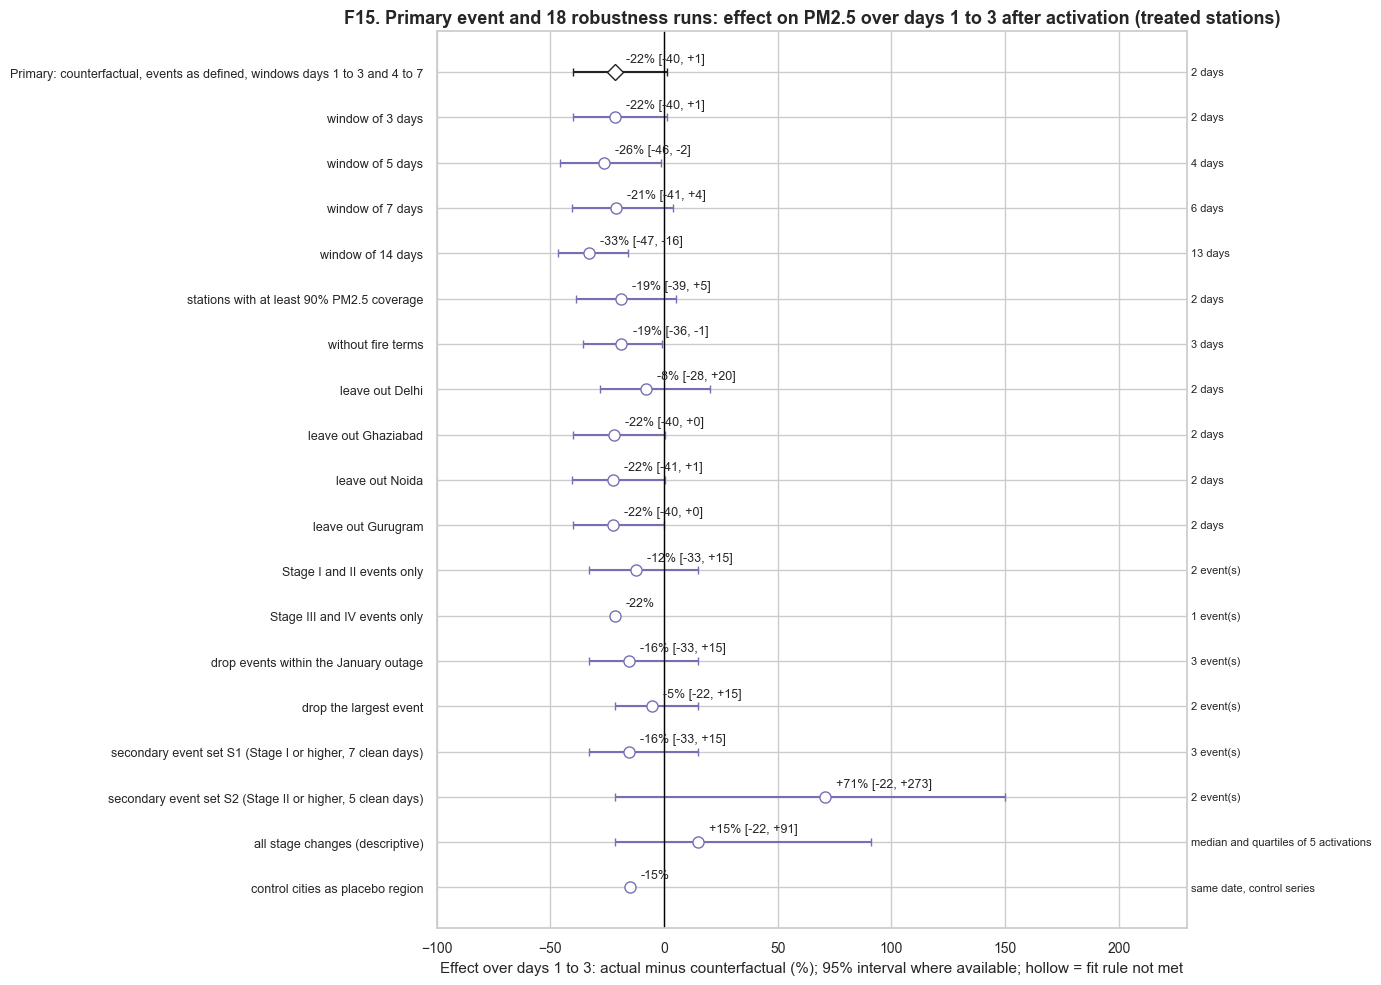

In [226]:
# Step 9.10d: F15 forest plot of the effect over days 1-3 under every run (common axis, values written, hollow = fit not usable)
plot_rows = robust_h2[robust_h2["Effect (%)"].notna()]
fig, ax = plt.subplots(figsize=(14, 10))
y_pos = np.arange(len(plot_rows))[::-1]
for y, (name, row) in zip(y_pos, plot_rows.iterrows()):
    low, high = (row["CI low"], row["CI high"]) if not np.isnan(row["CI low"]) else (row["Effect (%)"], row["Effect (%)"])
    ax.errorbar(np.clip(row["Effect (%)"], -100, 150), y, xerr=[[np.clip(row["Effect (%)"], -100, 150) - np.clip(low, -100, 150)], [np.clip(high, -100, 150) - np.clip(row["Effect (%)"], -100, 150)]],
                fmt="D" if name.startswith("PRIMARY") else "o", color="#222222" if name.startswith("PRIMARY") else "#7570B3", mfc="#222222" if name.startswith("PRIMARY") and row["Fit usable"] else ("white"), capsize=3, ms=8)
    text = f"{row['Effect (%)']:+.0f}%" + (f" [{row['CI low']:+.0f}, {row['CI high']:+.0f}]" if not np.isnan(row["CI low"]) else "") + ("  off scale" if row["Effect (%)"] > 150 else "")
    ax.annotate(text, (np.clip(row["Effect (%)"], -100, 150), y), xytext=(8, 7), textcoords="offset points", fontsize=9)
    ax.text(1.005, y, row["Basis"], transform=ax.get_yaxis_transform(), va="center", fontsize=8)
ax.axvline(0, color="black", lw=1); ax.set_xlim(-100, 230)
ax.set_yticks(y_pos); ax.set_yticklabels([n.replace("PRIMARY: ", "Primary: ") for n in plot_rows.index], fontsize=9)
ax.set_xlabel("Effect over days 1 to 3: actual minus counterfactual (%); 95% interval where available; hollow = fit rule not met")
ax.set_title(f"F15. Primary event and {len(plot_rows) - 1} robustness runs: effect on PM2.5 over days 1 to 3 after activation (treated stations)")
plt.tight_layout(); save_fig(fig, "F15_h2_robustness_forest"); plt.show()

In [227]:
# Step 9.10e: takeaway text for the robustness runs
n_no_data = int((robust_h2["Basis"] == "0 days").sum())
show_takeaway(
    f"**What we learn:** **{agree_h2} of {len(counted)}** counted runs (**{agree_share_h2:.0%}**) have the same sign as the primary estimate, so that frozen criterion is met in form. But **{int(robust_h2['Fit usable'].sum())}** runs have a usable fit, "
    f"and the runs share the same few weeks of data, so the agreement says little. {'One run (leaving out uncertain and inferred stage hours) leaves no days to estimate from. ' if n_no_data else ''}"
    f"The estimates range from **{counted['Effect (%)'].min():+.0f}%** to **{counted['Effect (%)'].max():+.0f}%**, and only the secondary set S2 (which contains the day before Diwali) has the opposite sign."
)

**What we learn:** **16 of 17** counted runs (**94%**) have the same sign as the primary estimate, so that frozen criterion is met in form. But **0** runs have a usable fit, and the runs share the same few weeks of data, so the agreement says little. One run (leaving out uncertain and inferred stage hours) leaves no days to estimate from. The estimates range from **-33%** to **+71%**, and only the secondary set S2 (which contains the day before Diwali) has the opposite sign.

*F15. Effect over days 1 to 3 after activation (actual minus counterfactual, %) for the primary event under each planned alternative; intervals are 95% block-bootstrap intervals where available; the basis (days or events) is on the right; hollow markers failed the fit rule. Treated stations, IST. Source: `final_dataset.parquet`.*

**What it shows.** The sign of the primary estimate (a fall relative to the counterfactual) is stable across most alternatives, with a size between a few and about thirty per cent. The interval usually reaches or includes zero.

**What it does not show.** All runs use the same few weeks and the same model structure, and **none passes the fit rule**, so their agreement is not independent confirmation. The positive S2 result comes from the event on 19 Oct 2025, the day before Diwali, which no weather-and-fire model can capture. The control-city run being negative on the same date is a warning that the departure is not specific to GRAP.

## 9.11 Power: how large a fall could this method detect? (F17)

**Question:** if GRAP truly lowered PM2.5 by a given percentage, how often would this method detect it with one event?
**Method:** the bootstrap in 9.4 simulates the *no-effect* distribution of the estimate for each event (estimation error plus day-to-day noise). A fall is *detected* when the estimate lies below the 5th percentile of that distribution. Power is the share of simulations in which a true fall of the given size would be detected. This ignores the extra uncertainty from a model that failed the hold-out check, so it is **optimistic**.

In [228]:
# Step 9.11a: power curves from the simulated no-effect distributions (one curve per fitted event), and the smallest fall detected with 80% power
falls = np.arange(0, 0.81, 0.05)
power_rows, power = [], {}
for number in plot_events:
    null = event_effects[number][0]["null_log"]
    critical = np.percentile(null, 5)                                   # a fall is "detected" when the estimate is below this value
    power[number] = np.array([np.mean(np.log(1 - fall) + null < critical) for fall in falls])
    reach = falls[np.argmax(power[number] >= 0.8)] if (power[number] >= 0.8).any() else np.nan
    power_rows.append({"Event": f"{changes.loc[number, 'hour_ist']:%d %b %Y}", "Power at a 10% fall": power[number][2], "Power at a 20% fall": power[number][4],
                       "Power at a 30% fall": power[number][6], "Smallest fall detected with 80% power": reach})
power_table = pd.DataFrame(power_rows).set_index("Event")
primary_label = f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}"                      # label of the primary event in the tables
display((power_table * 1).round(2))
save_table(power_table.round(3), "T06f_h2_power")

,Power at a 10% fall,Power at a 20% fall,Power at a 30% fall,Smallest fall detected with 80% power
Event,,,,
19 Oct 2025,0.13,0.27,0.50,0.45
11 Nov 2025,0.21,0.53,0.84,0.30
16 Apr 2026,0.16,0.38,0.68,0.40
19 May 2026,0.23,0.54,0.89,0.30


saved table : T06f_h2_power


saved figure: F17_h2_power


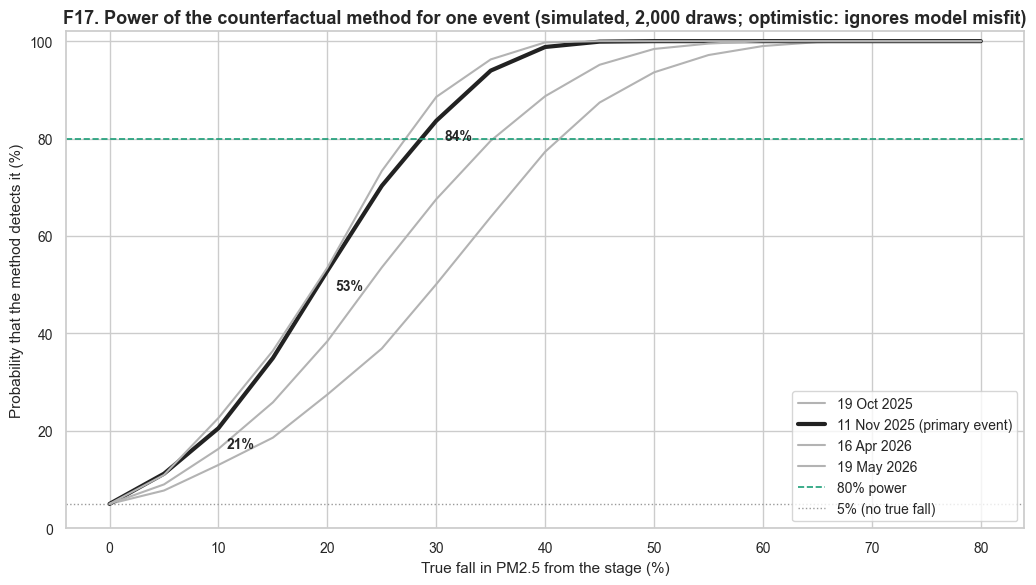

In [229]:
# Step 9.11b: F17 power curves, the 80% line and the primary event's curve highlighted; values written at the 10, 20 and 30% falls
fig, ax = plt.subplots(figsize=(10.5, 6))
for number in plot_events:
    is_primary = number == primary_number
    ax.plot(falls * 100, power[number] * 100, color="#222222" if is_primary else "#B3B3B3", lw=3 if is_primary else 1.5, label=f"{changes.loc[number, 'hour_ist']:%d %b %Y}" + (" (primary event)" if is_primary else ""))
for fall in (0.1, 0.2, 0.3):
    value = power[primary_number][int(round(fall / 0.05))] * 100
    ax.annotate(f"{value:.0f}%", (fall * 100, value), xytext=(6, -14), textcoords="offset points", fontsize=10, fontweight="bold")
ax.axhline(80, color="#1B9E77", ls="--", lw=1.2, label="80% power")
ax.axhline(5, color="#999999", ls=":", lw=1, label="5% (no true fall)")
ax.set(xlabel="True fall in PM2.5 from the stage (%)", ylabel="Probability that the method detects it (%)", ylim=(0, 102),
       title=f"F17. Power of the counterfactual method for one event (simulated, {BOOTSTRAP_DRAWS:,} draws; optimistic: ignores model misfit)")
ax.legend(loc="lower right"); plt.tight_layout(); save_fig(fig, "F17_h2_power"); plt.show()

In [230]:
# Step 9.11c: takeaway text for the power analysis
mde = power_table["Smallest fall detected with 80% power"]
show_takeaway(
    f"**What we learn:** for the primary event the method would detect a true fall of **20%** with probability **{power[primary_number][4] * 100:.0f}%** and a fall of **30%** with **{power[primary_number][6] * 100:.0f}%**; "
    f"the smallest fall detected with 80% power is **{mde.loc[primary_label] * 100:.0f}%**. Across the fitted events this ranges from **{mde.min() * 100:.0f}%** to **{mde.max() * 100:.0f}%**. "
    f"Because the model also failed the hold-out check, the true power is lower than these figures."
)

**What we learn:** for the primary event the method would detect a true fall of **20%** with probability **53%** and a fall of **30%** with **84%**; the smallest fall detected with 80% power is **30%**. Across the fitted events this ranges from **30%** to **45%**. Because the model also failed the hold-out check, the true power is lower than these figures.

*F17. Probability that the counterfactual method detects a true fall of the given size, for one event, from the simulated no-effect distribution of each fitted event (primary event in black). Dashed green = 80% power; dotted grey = 5% when there is no true fall. Simulated with 2,000 block-bootstrap draws; optimistic because it ignores model misfit. Source: `final_dataset.parquet`.*

**What it shows.** How big a real effect of GRAP would have to be for one event to reveal it. Policy effects of the order of a few per cent to ten per cent would be missed most of the time.

**What it does not show.** An effect at or below the detectable size is not ruled out: *inconclusive* may mean mostly that this design has little power. The curve is for the method on one event; more events (several winters) or a design with a comparison region would raise it.

In [231]:
# Step 9.12: the frozen H2 criteria evaluated on the results above (the formal status table is built in Phase 10)
share_primary = placebo_table.loc[f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}", "Share of placebos below the real event (all)"]
n_placebo_primary = int(placebo_table.loc[f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}", "Placebo dates"])
criteria_h2 = pd.DataFrame([
    {"Criterion (frozen)": "Pooled effect below 0 with the 95% interval excluding 0 (usable events, days 1 to 3)", "Observed": "no usable event: nothing to pool", "Met": False, "Informative": False},
    {"Criterion (frozen)": f"Real events in the lowest {LOWER_TAIL:.0%} of their placebo distribution", "Observed": f"{share_primary:.0%} of {n_placebo_primary} placebo dates are below the primary event", "Met": bool(share_primary <= LOWER_TAIL), "Informative": False},
    {"Criterion (frozen)": f"Same sign in at least {ROBUST_AGREE_SHARE:.0%} of robustness runs", "Observed": f"{agree_h2} of {len(counted)} ({agree_share_h2:.0%}); no run has a usable fit", "Met": bool(agree_share_h2 >= ROBUST_AGREE_SHARE), "Informative": False},
    {"Criterion (frozen)": f"At least {MIN_EVENTS_FOR_SUPPORT} usable events", "Observed": f"{len(usable_events)} usable of {len(all_events)} events", "Met": len(usable_events) >= MIN_EVENTS_FOR_SUPPORT, "Informative": True},
]).set_index("Criterion (frozen)")
display(criteria_h2)
save_table(criteria_h2, "T06h_h2_criteria")
ci_lo, ci_hi = event_effects[primary_number][0]["ci_low_pct"], event_effects[primary_number][0]["ci_high_pct"]
points = [
    f"**Events.** {len(changes)} stage changes; **{len(primary_events)}** primary event and **{len(secondary_union)}** further events in the secondary sets.",
    f"**Fit.** **{len(usable_events)}** of {len(plot_events)} fitted events pass the hold-out rule; the primary event's hold-out error is {event_fits[primary_number]['holdout_error']:.0%}. Its counterfactual cannot be relied on.",
    f"**Estimate (for information, not usable).** {event_effects[primary_number][0]['effect_pct']:+.1f}% [{ci_lo:+.1f}, {ci_hi:+.1f}] over days 1 to 3; the segmented regression gives a level change of {seg_primary['Level change (%)']:+.1f}% [{seg_primary['Level CI low']:+.1f}, {seg_primary['Level CI high']:+.1f}].",
    f"**Reverse causation.** In the week before the primary event PM2.5 was already rising by about {event_table.loc[primary_number, 'pm25_trend_pct_per_day']:+.0f}% per day; the stage was invoked on a steep rise.",
    f"**Control cities.** The same method on the same date gives {control_effect[primary_number][0]:+.1f}% there, where GRAP does not apply.",
    f"**Placebo.** Only {n_placebo_primary} comparable placebo dates exist under the frozen rule, too few to place the real event in a distribution.",
    f"**Power.** One event can only detect a fall of about {mde.loc[primary_label] * 100:.0f}% or more with 80% power (an optimistic figure).",
]
show_takeaway("**What we learn: the H2 evidence in one list**\n\n" + "\n".join(f"- {p}" for p in points) + f"\n\n**Criteria.** On the frozen rules H2 **cannot be called supported** (it needs at least {MIN_EVENTS_FOR_SUPPORT} usable events and has {len(usable_events)}); the formal status is assigned in Phase 10.")

,Observed,Met,Informative
Criterion (frozen),,,
"Pooled effect below 0 with the 95% interval excluding 0 (usable events, days 1 to 3)",no usable event: nothing to pool,False,False
Real events in the lowest 10% of their placebo distribution,0% of 2 placebo dates are below the primary event,True,False
Same sign in at least 75% of robustness runs,16 of 17 (94%); no run has a usable fit,True,False
At least 3 usable events,0 usable of 5 events,False,True


saved table : T06h_h2_criteria


**What we learn: the H2 evidence in one list**

- **Events.** 30 stage changes; **1** primary event and **4** further events in the secondary sets.
- **Fit.** **0** of 4 fitted events pass the hold-out rule; the primary event's hold-out error is 90%. Its counterfactual cannot be relied on.
- **Estimate (for information, not usable).** -21.7% [-39.8, +1.3] over days 1 to 3; the segmented regression gives a level change of -4.5% [-35.0, +40.4].
- **Reverse causation.** In the week before the primary event PM2.5 was already rising by about +18% per day; the stage was invoked on a steep rise.
- **Control cities.** The same method on the same date gives -14.9% there, where GRAP does not apply.
- **Placebo.** Only 2 comparable placebo dates exist under the frozen rule, too few to place the real event in a distribution.
- **Power.** One event can only detect a fall of about 30% or more with 80% power (an optimistic figure).

**Criteria.** On the frozen rules H2 **cannot be called supported** (it needs at least 3 usable events and has 0); the formal status is assigned in Phase 10.

## 9.12 Interpretation of H2

**In plain words.** After the one clean activation (11 Nov 2025, Stage II to III) PM2.5 was lower than the weather-and-fire model predicted (the estimate and its interval are in 9.4 and table T06a), but the estimate is not reliable: the model could not reproduce PM2.5 in the days just before the event, the interval reaches zero, the control cities show a similar departure on the same date, and the placebo check has too few comparable dates. Under the frozen rules this is **an inconclusive result about H2, not evidence that GRAP works or that it does not**.

**Never read this as "GRAP reduced PM2.5 by X%".** A stage is invoked when pollution is already high or forecast to rise, and pollution tends to fall back afterwards anyway; the counterfactual cannot see the forecast that triggered the stage. The placebo and control-city checks are there to guard against exactly this, and with so few events and comparable dates they cannot do so.

**What this result is mostly about.** *Power* and *design*, not the policy: one winter gives very few clean events, strict stages are often changed within days of each other, and the counterfactual is fitted on a few weeks with many parameters. The power analysis (9.11, and 9B.8 with empirical noise, table T06n) shows that only a large effect could be detected with one event; the bootstrap figure of 9.11 is optimistic because it ignores the misfit of the model.

**What would make H2 testable.** More winters of data; keeping stations reporting through outages; the exact hour of each GRAP order; and a design with a comparison region that has a similar emissions and weather pattern (for example staggered or paired-city timing). These feed the recommendations in Phase 11.

---
# Phase 9B: H2 in depth: why the counterfactual failed, a difference-in-differences check, and mean reversion
*BADIR: **A**nalysis and **I**nsights.* This phase goes deeper on the two H2 questions of the project:

- **Q3.** After a GRAP stage is activated, is PM2.5 lower than the weather-and-fire model predicts? (9B.1 to 9B.4)
- **Q4.** Is the fall just mean reversion, since stages are invoked when PM2.5 is already high? (9B.5 to 9B.8)

**Every analysis in this phase is an extension ADDED AFTER SEEING RESULTS.** It cannot change the frozen status of H2 (Phase 10 applies the Phase 7 rules to the frozen runs only), and each run is added to the register `T07d2` started in 8B.0. The first pass left these open points: only one event qualifies under the primary rule, its counterfactual failed the hold-out rule (error 90%, the days before it are a steep run-up), only two comparable placebo dates exist, and the control cities show departures of similar size on the same dates.

**Rule for alternative counterfactuals (declared before any alternative effect is computed).** An alternative may replace the frozen model for an event only if it passes the **same hold-out rule** (hold-out error at most 25% of PM2.5). The alternative that is carried forward is chosen on **pre-event accuracy alone**, the median hold-out error over all fitted events and placebo dates, **never on the effect it gives**. The frozen result and the alternative result are always shown side by side.

## 9B.1 Why did the counterfactual fail? (T06g, F25)

**Question:** the frozen counterfactual failed the hold-out rule for every fitted event. What exactly went wrong?
**Method:** for each fitted event, count the days and parameters of the fit, measure how badly the explanatory variables overlap (the condition number of the standardised design: above about 30 means that the coefficients are unstable), and split the hold-out error by day: how much comes from the **last three hold-out days**, the ones just before the activation. The figure shows, for each event, the actual PM2.5, the fitted values in the fit period and the prediction for the 10 held-out days from a model fitted on the earlier days only.

In [232]:
# Step 9B.1a: ADDED AFTER SEEING RESULTS: the fit rows of each fitted event and the hold-out predictions (reproducing the frozen hold-out error as a check)
def fit_rows_for(series, t0, other_changes, columns):
    # the same day selection as the frozen counterfactual: the 60 days before the buffer minus days near other changes, with all inputs present
    last_pre, _ = event_days(t0)
    days = pd.date_range(last_pre - pd.Timedelta(days=FIT_WINDOW_DAYS - 1), last_pre)
    near = [d for d in days if any(abs((d - c.normalize()).days) <= MIN_CLEAN_DAYS for c in other_changes)]
    return series.reindex(days).drop(near).dropna(subset=["log_pm25", "weekday"] + columns)

In [233]:
# Step 9B.1a2: ADDED AFTER SEEING RESULTS: fit and hold-out of each fitted event, reproducing the frozen hold-out error as a check
frozen_columns = [FIRE] + DRIVERS
diagnosis_rows, hold_detail = [], {}
for number in plot_events:
    t0 = changes.loc[number, "hour_ist"]; others = [t for n, t in changes["hour_ist"].items() if n != number]
    rows_n = fit_rows_for(series_treated, t0, others, frozen_columns)
    fit_part, hold = rows_n.iloc[:-HOLDOUT_DAYS], rows_n.iloc[-HOLDOUT_DAYS:]
    X_fit = design_matrix(fit_part); beta_h = np.linalg.lstsq(X_fit, fit_part["log_pm25"].to_numpy(), rcond=None)[0]
    pred_hold = np.exp(design_matrix(hold) @ beta_h) * np.exp(fit_part["log_pm25"].to_numpy() - X_fit @ beta_h).mean()
    abs_err = np.abs(hold["pm25"].to_numpy() - pred_hold)
    assert np.isclose(abs_err.mean() / hold["pm25"].mean(), event_fits[number]["holdout_error"]), "hold-out error differs from the frozen fit"
    standardised = (X_fit[:, 1:] - X_fit[:, 1:].mean(0)) / np.where(X_fit[:, 1:].std(0) == 0, 1, X_fit[:, 1:].std(0))
    hold_detail[number] = (rows_n, hold.assign(pred=pred_hold), np.exp(design_matrix(rows_n) @ event_fits[number]["beta"]) * event_fits[number]["smear"])
    diagnosis_rows.append({"Event": f"{t0:%d %b %Y}", "Fit days": len(rows_n), "Parameters": X_fit.shape[1], "Days per parameter": len(rows_n) / X_fit.shape[1], "Condition number": np.linalg.cond(standardised),
                           "Hold-out error": event_fits[number]["holdout_error"], "Share of error in last 3 hold-out days": abs_err[-3:].sum() / abs_err.sum(),
                           "Mean PM2.5 in hold-out (ug/m3)": hold["pm25"].mean(), "Mean prediction in hold-out (ug/m3)": pred_hold.mean()})
diagnosis = pd.DataFrame(diagnosis_rows).set_index("Event")
display(diagnosis.round(2)); save_table(diagnosis.round(3), "T06g_counterfactual_diagnosis")
log_extension("9B.1", "diagnosis of the frozen counterfactual: days per parameter, condition number, hold-out error by day")

,Fit days,Parameters,Days per parameter,Condition number,Hold-out error,Share of error in last 3 hold-out days,Mean PM2.5 in hold-out (ug/m3),Mean prediction in hold-out (ug/m3)
Event,,,,,,,,
19 Oct 2025,48,16,3.00,12.34,0.29,0.47,50.27,4.464000e+01
11 Nov 2025,38,16,2.38,13.79,0.90,0.70,182.17,3.023100e+02
16 Apr 2026,34,16,2.12,6.40,0.48,0.29,57.11,5.748000e+01
19 May 2026,26,16,1.62,250.41,9278655.73,0.99,69.59,6.456617e+08


saved table : T06g_counterfactual_diagnosis


saved figure: F25_counterfactual_diagnosis


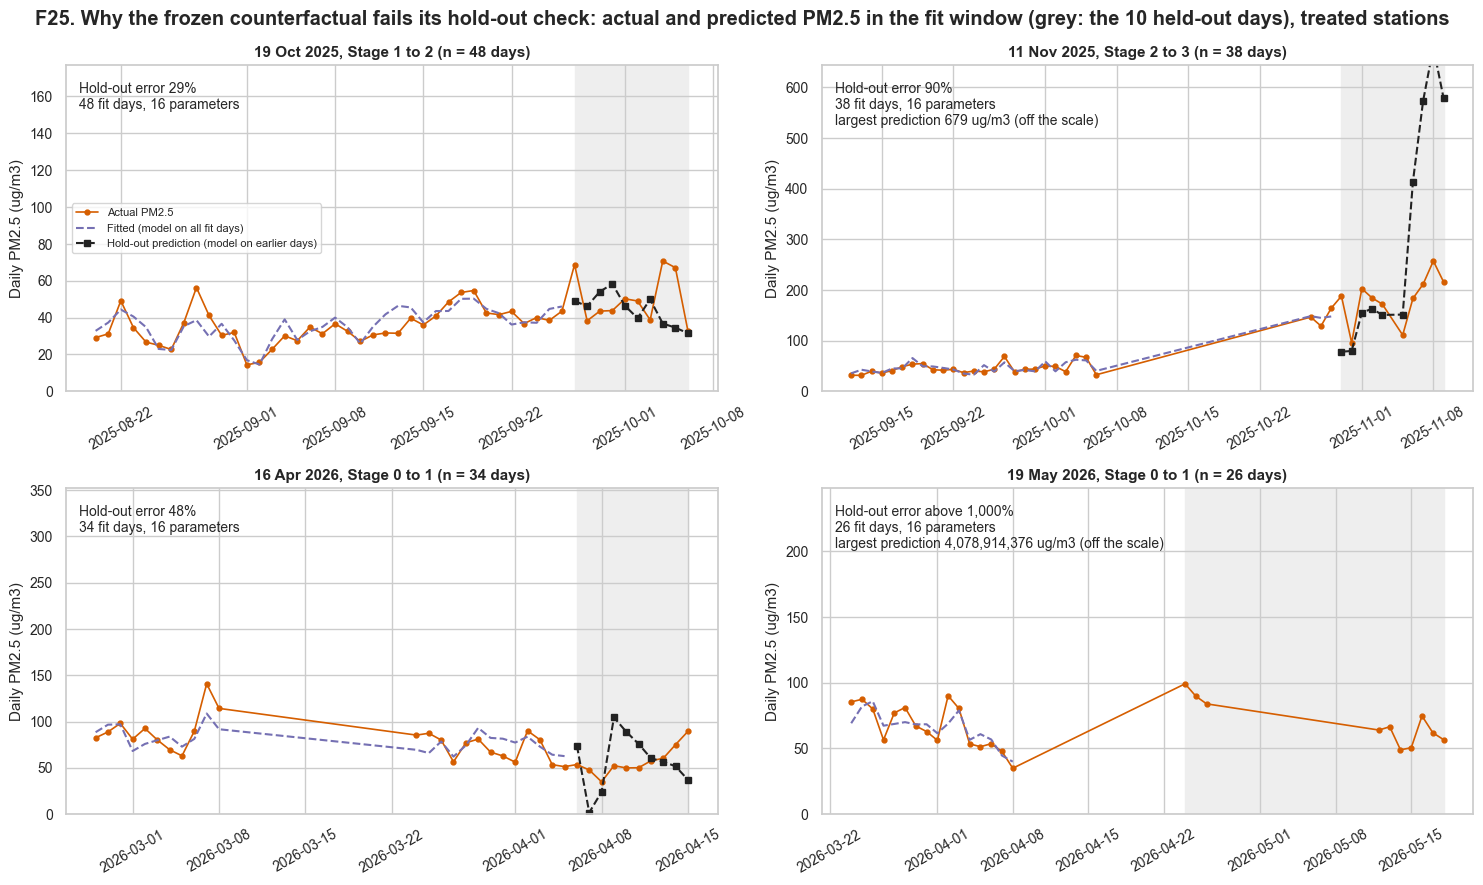

In [234]:
# Step 9B.1b: F25 actual PM2.5, fitted values in the fit period and the hold-out prediction; the hold-out error is written in each panel
fig, axes = plt.subplots(2, 2, figsize=(15, 9)); axes = axes.ravel()
for ax, number in zip(axes, plot_events):
    rows_n, hold, fitted = hold_detail[number]
    ax.plot(rows_n.index, rows_n["pm25"], "o-", color="#D55E00", ms=3.5, lw=1.2, label="Actual PM2.5")
    ax.plot(rows_n.index[:-HOLDOUT_DAYS], fitted[:-HOLDOUT_DAYS], "--", color="#7570B3", lw=1.5, label="Fitted (model on all fit days)")
    ax.plot(hold.index, hold["pred"], "s--", color="#222222", ms=4, lw=1.5, label="Hold-out prediction (model on earlier days)")
    ax.axvspan(hold.index.min(), hold.index.max(), color="#EEEEEE", zorder=0)
    err_n = diagnosis.iloc[plot_events.index(number)]["Hold-out error"]
    ax.set_ylim(0, rows_n["pm25"].max() * 2.5)                                  # a prediction far above the data is cut and written
    ax.text(0.02, 0.95, f"Hold-out error {'above 1,000%' if err_n > 10 else f'{err_n:.0%}'}\n{len(rows_n)} fit days, {diagnosis.iloc[plot_events.index(number)]['Parameters']:.0f} parameters" + (f"\nlargest prediction {hold['pred'].max():,.0f} ug/m3 (off the scale)" if hold["pred"].max() > rows_n["pm25"].max() * 2.5 else ""), transform=ax.transAxes, va="top", fontsize=10)
    ax.set_title(f"{changes.loc[number, 'hour_ist']:%d %b %Y}, Stage {changes.loc[number, 'stage_before']} to {changes.loc[number, 'stage_after']} (n = {len(rows_n)} days)", fontsize=11)
    ax.set_ylabel("Daily PM2.5 (ug/m3)"); ax.tick_params(axis="x", rotation=30)
axes[0].legend(loc="center left", fontsize=8)
fig.suptitle("F25. Why the frozen counterfactual fails its hold-out check: actual and predicted PM2.5 in the fit window (grey: the 10 held-out days), treated stations", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F25_counterfactual_diagnosis"); plt.show()

In [235]:
# Step 9B.1c: takeaway text for the diagnosis
prim = diagnosis.loc[f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}"]
show_takeaway(
    f"**What we learn:** the frozen model has **{diagnosis['Parameters'].iloc[0]:.0f}** parameters and is fitted on **{diagnosis['Fit days'].min():.0f} to {diagnosis['Fit days'].max():.0f}** days, between **{diagnosis['Days per parameter'].min():.1f}** and **{diagnosis['Days per parameter'].max():.1f}** days per parameter; "
    f"the condition number of its design is between **{diagnosis['Condition number'].min():.0f}** and **{diagnosis['Condition number'].max():.0f}**. For the primary event the hold-out error is **{prim['Hold-out error']:.0%}**: "
    f"the model predicted a mean of **{prim['Mean prediction in hold-out (ug/m3)']:.0f} ug/m3** over the 10 held-out days against **{prim['Mean PM2.5 in hold-out (ug/m3)']:.0f}** observed, and **{prim['Share of error in last 3 hold-out days'] * 100:.0f}%** of the error falls on the last 3 days."
)

**What we learn:** the frozen model has **16** parameters and is fitted on **26 to 48** days, between **1.6** and **3.0** days per parameter; the condition number of its design is between **6** and **250**. For the primary event the hold-out error is **90%**: the model predicted a mean of **302 ug/m3** over the 10 held-out days against **182** observed, and **70%** of the error falls on the last 3 days.

*F25. For each fitted event, actual daily PM2.5 of the treated stations (orange), the model fitted on all fit days (purple dashed, fit period only) and the prediction of the 10 held-out days (grey band, black squares) from a model fitted on the days before them; the hold-out error, the number of fit days and the parameters are written in each panel. Source: `final_dataset.parquet` via the daily treated series of Phase 9.*

**What it shows.** The frozen model fits many parameters on a few weeks of data, and the days just before a stage is invoked are a run-up that earlier days of the window do not contain, so the model cannot predict them. This is a property of the design (a short window, a rising episode), not a coding fault.

**What it does not show.** It does not show that GRAP had no effect, or that it had one: it shows only that this counterfactual is not reliable for these events, as the frozen rule intends. The diagnosis is descriptive and does not change the frozen result.

## 9B.2 Alternative counterfactuals (T06i, F26)

**Question:** is there a better pre-event model, one that passes the same hold-out rule?
**Alternatives, declared before any alternative effect is computed:** (a) **parsimonious weather**: wind speed, boundary-layer height, temperature and the upwind fire count, with no wind direction, rain, pressure, humidity or weekday terms; (b) the **frozen model with ridge shrinkage**, the penalty chosen by leave-one-out inside the fit rows; (c) a **control-city counterfactual**: treated log PM2.5 regressed on the control cities' log PM2.5 of the *same day* (regional shocks such as Diwali cancel because GRAP does not apply there); (d) the control cities **plus** the parsimonious weather terms. The same days, the same 10-day hold-out and the same 25% rule apply to all; **the method carried forward is the one with the lowest median hold-out error over events and placebo dates, never the one with the most attractive effect.**

In [236]:
# Step 9B.2a: the methods (design matrices, ridge penalty by leave-one-out) and the fit with the frozen day selection and hold-out rule
PARS = ["wind_speed", "blh_m", "t2m_c"]
RIDGE_GRID = [0.1, 1, 10, 100, 1000]
def with_constant(columns):
    return lambda rows: np.column_stack([np.ones(len(rows)), rows[columns].to_numpy(float)])
METHODS = {"Frozen": dict(cols=frozen_columns, design=lambda r: design_matrix(r, True), ridge=False),
           "(a) Parsimonious weather": dict(cols=[FIRE] + PARS, design=with_constant([FIRE] + PARS), ridge=False),
           "(b) Frozen with ridge": dict(cols=frozen_columns, design=lambda r: design_matrix(r, True), ridge=True),
           "(c) Control cities": dict(cols=["ctrl_log"], design=with_constant(["ctrl_log"]), ridge=False),
           "(d) Control cities + weather": dict(cols=["ctrl_log", FIRE] + PARS, design=with_constant(["ctrl_log", FIRE] + PARS), ridge=False)}
series_alt = series_treated.assign(ctrl_log=series_control["log_pm25"])
def solve(X, y, ridge):
    # least squares, or ridge on standardised columns with the penalty chosen by leave-one-out (hat-matrix shortcut); returns coefficients on the original scale
    if not ridge:
        return np.linalg.lstsq(X, y, rcond=None)[0]
    mu, sd = X[:, 1:].mean(0), np.where(X[:, 1:].std(0) == 0, 1, X[:, 1:].std(0))
    Z = np.column_stack([np.ones(len(X)), (X[:, 1:] - mu) / sd]); D = np.diag([0.0] + [1.0] * (Z.shape[1] - 1))
    best = min(((np.mean(((y - Z @ (A @ Z.T @ y)) / (1 - np.einsum("ij,jk,ik->i", Z, A, Z))) ** 2), lam, A @ Z.T @ y) for lam in RIDGE_GRID for A in [np.linalg.inv(Z.T @ Z + lam * D)]), key=lambda t: t[0])
    slope = best[2][1:] / sd
    return np.concatenate([[best[2][0] - np.sum(slope * mu)], slope])

In [237]:
# Step 9B.2b: fit one method for one change: hold-out error from a model on the earlier days, then the final fit on all fit days
def method_fit(series, t0, others, name):
    spec = METHODS[name]; last_pre, first_post = event_days(t0)
    rows_m = fit_rows_for(series, t0, others, spec["cols"])
    out = {"name": name, "spec": spec, "last_pre": last_pre, "first_post": first_post, "n_fit": len(rows_m), "usable": False}
    if len(rows_m) < HOLDOUT_DAYS + 15:
        return out
    part, hold = rows_m.iloc[:-HOLDOUT_DAYS], rows_m.iloc[-HOLDOUT_DAYS:]
    X_p, y_p = spec["design"](part), part["log_pm25"].to_numpy(); beta_p = solve(X_p, y_p, spec["ridge"])
    error = np.mean(np.abs(hold["pm25"].to_numpy() - np.exp(spec["design"](hold) @ beta_p) * np.exp(y_p - X_p @ beta_p).mean())) / hold["pm25"].mean()
    X_f, y_f = spec["design"](rows_m), rows_m["log_pm25"].to_numpy(); beta_f = solve(X_f, y_f, spec["ridge"]); resid_f = y_f - X_f @ beta_f
    return {**out, "X": X_f, "y": y_f, "beta": beta_f, "resid": resid_f, "smear": np.exp(resid_f).mean(), "holdout_error": error, "usable": error <= FIT_MAX_ERROR}

In [238]:
# Step 9B.2b2: the effect of a fitted method (actual minus predicted over the post days) with its bootstrap interval, and the check against the frozen primary event
def method_effect(fit, series, windows=EFFECT_WINDOWS, draws=0):
    # effect = actual minus predicted over the post days; with draws, a residual block bootstrap gives the no-effect distribution and the interval
    spec, rng, results = fit["spec"], np.random.default_rng(SEED), []
    betas = np.array([solve(fit["X"], fit["X"] @ fit["beta"] + block_resample(fit["resid"], len(fit["resid"]), rng), spec["ridge"]) for _ in range(draws)]) if draws else None
    for a, b in windows:
        post = series.reindex(window_days(fit["first_post"], a, b)).dropna(subset=["log_pm25"] + spec["cols"])
        if post.empty:
            results.append({"window": f"days {a} to {b}", "days": 0, "effect_pct": np.nan}); continue
        Xp = spec["design"](post); effect = float(np.mean(post["log_pm25"].to_numpy() - Xp @ fit["beta"]))
        res = {"window": f"days {a} to {b}", "days": len(post), "effect_log": effect, "effect_pct": np.expm1(effect) * 100}
        if draws:
            null = ((Xp @ fit["beta"])[:, None] - Xp @ betas.T).mean(axis=0) + np.array([block_resample(fit["resid"], len(post), rng).mean() for _ in range(draws)])
            res["ci_low_pct"], res["ci_high_pct"] = np.expm1(effect - np.percentile(null, [97.5, 2.5])) * 100; res["null_log"] = null
        results.append(res)
    return results
chk_fit = method_fit(series_alt, changes.loc[primary_number, "hour_ist"], [t for n, t in changes["hour_ist"].items() if n != primary_number], "Frozen")
chk_effect = method_effect(chk_fit, series_alt)[0]["effect_pct"]
assert np.isclose(chk_fit["holdout_error"], event_fits[primary_number]["holdout_error"]) and np.isclose(chk_effect, event_effects[primary_number][0]["effect_pct"]), "the generic method does not reproduce the frozen result"
print("Check: the generic code reproduces the frozen primary event: hold-out error", round(chk_fit["holdout_error"], 3), "| effect days 1-3", round(chk_effect, 2), "%")

Check: the generic code reproduces the frozen primary event: hold-out error 0.897 | effect days 1-3 -21.67 %


In [239]:
# Step 9B.2c: ADDED AFTER SEEING RESULTS: hold-out error of every method for every fitted event and for the frozen placebo dates (accuracy only; effects are not looked at here)
dates_to_test = [(f"{changes.loc[n, 'hour_ist']:%d %b %Y}", changes.loc[n, "hour_ist"], [t for k, t in changes["hour_ist"].items() if k != n], "event") for n in plot_events]
seen_dates = set()
for n in plot_events:
    for day in placebos[n]["date"]:
        if pd.Timestamp(day) in seen_dates:
            continue                                                         # the same placebo date can serve several events
        seen_dates.add(pd.Timestamp(day))
        dates_to_test.append((f"placebo {pd.Timestamp(day):%d %b %Y}", pd.Timestamp(day) + pd.Timedelta(hours=changes.loc[n, "hour_ist"].hour), list(changes["hour_ist"]), "placebo"))
errors = pd.DataFrame({name: [method_fit(series_alt, t0, others, name).get("holdout_error", np.nan) for _, t0, others, _ in dates_to_test] for name in METHODS},
                      index=pd.MultiIndex.from_tuples([(kind, label) for label, _, _, kind in dates_to_test], names=["Kind", "Date"]))
selection = pd.DataFrame({"Median hold-out error (events + placebo dates)": errors.median(), "Share of dates passing the 25% rule": (errors <= FIT_MAX_ERROR).mean(),
                          "Events passing": (errors.loc["event"] <= FIT_MAX_ERROR).sum(), "Dates with a fit": errors.notna().sum()})
best_method = selection["Median hold-out error (events + placebo dates)"].idxmin()
best_weather_method = selection.drop(index=[m for m in METHODS if "Control" in m])["Median hold-out error (events + placebo dates)"].idxmin()
display(errors.round(2)); display(selection.round(2)); save_table(errors.round(3), "T06i_holdout_by_method"); save_table(selection.round(3), "T06i2_method_selection")
print("Carried forward (lowest median hold-out error):", best_method, "| best method that does not use the control cities:", best_weather_method)
log_extension("9B.2", "four alternative counterfactuals compared on hold-out accuracy for events and placebo dates (method chosen on accuracy only)")

Frozen  ...  (d) Control cities + weather
Kind    Date                             ...                              
event   19 Oct 2025                0.29  ...                          0.29
        11 Nov 2025                0.90  ...                          0.41
        16 Apr 2026                0.48  ...                          0.54
        19 May 2026          9278655.73  ...                          1.93
placebo placebo 23 Apr 2026        1.09  ...                          0.43
        placebo 26 Apr 2026        0.50  ...                          0.57
        placebo 26 Oct 2025        0.38  ...                          0.29
        placebo 27 Oct 2025        0.41  ...                          0.29
        placebo 02 Apr 2026        0.64  ...                          0.16
        placebo 03 Apr 2026        0.70  ...                          0.26
        placebo 05 Apr 2026        0.89  ...                          0.18
        placebo 06 Apr 2026        0.77  ...                          0.22
        placebo 07 Apr 2026        0.34  ...                          0.23
        placebo 08 Apr 2026        0.38  ...                          0.31
        placebo 09 Apr 2026        0.48  ...                          0.43
        placebo 06 Oct 2025        0.23  ...                          0.25
        placebo 22 Sep 2026        0.32  ...                          0.31

[17 rows x 5 columns]

,Median hold-out error (events + placebo dates),Share of dates passing the 25% rule,Events passing,Dates with a fit
Frozen,0.48,0.06,0,17
(a) Parsimonious weather,0.30,0.18,0,17
(b) Frozen with ridge,0.31,0.12,1,17
(c) Control cities,0.30,0.24,1,17
(d) Control cities + weather,0.29,0.24,0,17


saved table : T06i_holdout_by_method
saved table : T06i2_method_selection
Carried forward (lowest median hold-out error): (d) Control cities + weather | best method that does not use the control cities: (a) Parsimonious weather


saved figure: F26_alternative_counterfactuals


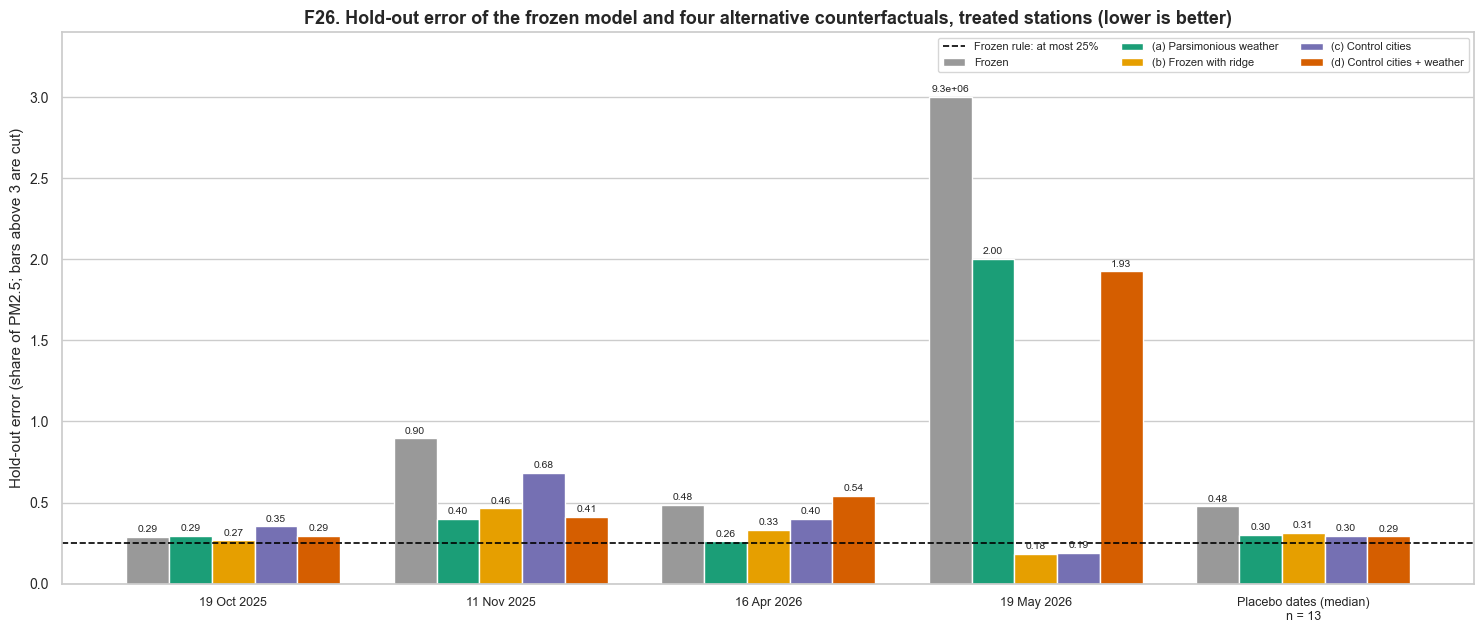

In [240]:
# Step 9B.2d: F26 hold-out error by method: the four fitted events and the median over the placebo dates (value on each bar), the 25% rule marked
group_labels = [f"{changes.loc[n, 'hour_ist']:%d %b %Y}" for n in plot_events] + ["Placebo dates (median)"]
plot_vals = pd.DataFrame({m: list(errors.loc["event", m].to_numpy()) + [errors.loc["placebo", m].median()] for m in METHODS}, index=group_labels)
fig, ax = plt.subplots(figsize=(15, 6.5)); width = 0.16; x = np.arange(len(group_labels)); palette = ["#999999", "#1B9E77", "#E69F00", "#7570B3", "#D55E00"]
for k, (m, colour) in enumerate(zip(METHODS, palette)):
    bars = ax.bar(x + (k - 2) * width, plot_vals[m].clip(upper=3), width, color=colour, label=m)
    for bar, val in zip(bars, plot_vals[m]):
        ax.annotate(f"{val:.2f}" if val < 3 else f"{val:.1e}", (bar.get_x() + bar.get_width() / 2, min(val, 3)), ha="center", va="bottom", fontsize=7.5, xytext=(0, 2), textcoords="offset points")
ax.axhline(FIT_MAX_ERROR, color="black", ls="--", lw=1.2, label="Frozen rule: at most 25%")
ax.set_xticks(x); ax.set_xticklabels(group_labels[:-1] + [f"Placebo dates (median)\nn = {len(errors.loc['placebo'])}"], fontsize=9)
ax.set_ylabel("Hold-out error (share of PM2.5; bars above 3 are cut)"); ax.set_ylim(0, 3.4); ax.grid(axis="x", visible=False); ax.legend(ncol=3, fontsize=8, loc="upper right")
ax.set_title("F26. Hold-out error of the frozen model and four alternative counterfactuals, treated stations (lower is better)")
plt.tight_layout(); save_fig(fig, "F26_alternative_counterfactuals"); plt.show()

In [241]:
# Step 9B.2e: which events become usable under each method, and what the usable ones show (effect days 1-3 with interval; frozen result alongside)
usable_rows = []
for name in METHODS:
    for n in plot_events:
        fit_n = method_fit(series_alt, changes.loc[n, "hour_ist"], [t for k, t in changes["hour_ist"].items() if k != n], name)
        eff = method_effect(fit_n, series_alt, draws=BOOTSTRAP_DRAWS)[0] if "X" in fit_n else {}
        usable_rows.append({"Method": name, "Event": f"{changes.loc[n, 'hour_ist']:%d %b %Y}", "Hold-out error": fit_n.get("holdout_error", np.nan), "Usable": fit_n["usable"],
                            "Effect days 1-3 (%)": eff.get("effect_pct", np.nan), "CI low": eff.get("ci_low_pct", np.nan), "CI high": eff.get("ci_high_pct", np.nan), "Post days": eff.get("days", 0)})
method_effects = pd.DataFrame(usable_rows)
display(method_effects.round(2)); save_table(method_effects.set_index("Method").round(3), "T06i3_effects_by_method")
n_usable_by_method = method_effects.groupby("Method")["Usable"].sum().reindex(list(METHODS))
usable_alt = method_effects[method_effects["Usable"] & (method_effects["Method"] != "Frozen")]
show_takeaway(
    f"**What we learn:** events passing the 25% hold-out rule: " + ", ".join(f"{m}: **{int(n_usable_by_method[m])}** of {len(plot_events)}" for m in METHODS) + ". "
    f"The method with the lowest median hold-out error over {int(selection.loc[best_method, 'Dates with a fit'])} dates is **{best_method.lower()}** (median **{selection.loc[best_method, 'Median hold-out error (events + placebo dates)']:.2f}**; the four alternatives lie between **{selection.iloc[1:, 0].min():.2f}** and **{selection.iloc[1:, 0].max():.2f}**, so the choice among them is {'not clear-cut' if selection.iloc[1:, 0].max() - selection.iloc[1:, 0].min() < 0.05 else 'clear'}). "
    + ("Usable alternative results (days 1 to 3): " + "; ".join(f"{r['Method']}, {r['Event']}: {r['Effect days 1-3 (%)']:+.1f}% [{r['CI low']:+.1f}, {r['CI high']:+.1f}]" for _, r in usable_alt.iterrows()) + "." if len(usable_alt) else "No alternative gives a usable counterfactual for any fitted event.")
)

,Method,Event,Hold-out error,Usable,Effect days 1-3 (%),CI low,CI high,Post days
0,Frozen,19 Oct 2025,0.29,False,272.74,137.18,475.41,2
1,Frozen,11 Nov 2025,0.90,False,-21.67,-39.82,1.31,2
2,Frozen,16 Apr 2026,0.48,False,14.94,-20.83,59.59,3
3,Frozen,19 May 2026,9278655.73,False,-33.10,-47.93,-15.04,3
4,(a) Parsimonious weather,19 Oct 2025,0.29,False,389.71,207.41,663.98,2
5,(a) Parsimonious weather,11 Nov 2025,0.40,False,-14.81,-43.89,28.30,2
6,(a) Parsimonious weather,16 Apr 2026,0.26,False,12.04,-28.41,63.56,3
7,(a) Parsimonious weather,19 May 2026,2.00,False,-9.00,-37.89,32.19,3
8,(b) Frozen with ridge,19 Oct 2025,0.27,False,309.90,160.88,473.45,2
9,(b) Frozen with ridge,11 Nov 2025,0.46,False,-22.57,-43.36,5.58,2


saved table : T06i3_effects_by_method


**What we learn:** events passing the 25% hold-out rule: Frozen: **0** of 4, (a) Parsimonious weather: **0** of 4, (b) Frozen with ridge: **1** of 4, (c) Control cities: **1** of 4, (d) Control cities + weather: **0** of 4. The method with the lowest median hold-out error over 17 dates is **(d) control cities + weather** (median **0.29**; the four alternatives lie between **0.29** and **0.31**, so the choice among them is not clear-cut). Usable alternative results (days 1 to 3): (b) Frozen with ridge, 19 May 2026: -21.2% [-43.3, +4.9]; (c) Control cities, 19 May 2026: -18.0% [-39.8, +17.3].

*F26. Hold-out error (share of mean PM2.5 over the 10 held-out days) of the frozen model and four alternatives for each fitted event and the median over the frozen placebo dates; bars above 3 are cut and the value is written. The dashed line is the frozen 25% rule. Treated stations; the alternatives use the same days and the same hold-out as the frozen model. Source: `final_dataset.parquet` via the daily treated and control series.*

**What it shows.** Whether a simpler model, a shrunk model or a model that borrows the control cities predicts the held-out days of a pre-activation run-up better, and which events that makes usable. The control-city model can absorb a regional episode that the weather variables cannot.

**What it does not show.** Passing the hold-out rule is necessary, not sufficient: a control-city counterfactual assumes the control cities would have moved in step with the treated stations in the absence of GRAP, and the two regions differ in weather and local rules. A usable alternative does not change the frozen status. Choosing the method on accuracy alone avoids picking the one that gives the largest fall; the effects are shown for every method so that this can be checked.

## 9B.3 Difference-in-differences event study with the control cities (T06j, F27)

**Question:** is PM2.5 at the treated stations lower than at the control cities (where GRAP does not apply) after an activation, compared with the days before?
**Method:** the daily difference between treated and control log PM2.5 (days where both are valid). For each event, **event-time coefficients** for days -10 to +14: the difference on that day minus its average over the **baseline days -7 to -1** (day -1 is the last full day before the 12-hour buffer, day 0 the first full day after it). Coefficients are shown as % differences. **Intervals** come from **placebo dates**: the same coefficient paths computed at all dates with no stage change within 7 days; the band is the pointwise 2.5th to 97.5th percentile of the placebo paths (for the pooled path, of the averages of as many random placebo dates as there are events). **Pre-trend check:** the mean squared coefficient of days -10 to -2 (zero if the two regions moved in parallel) compared with the placebo distribution. **Assumption:** parallel trends: without GRAP the treated and control cities would have moved together. They differ in weather and local rules, so this is a check, not a proof.

In [242]:
# Step 9B.3a: ADDED AFTER SEEING RESULTS: the daily treated-minus-control difference and the event-time coefficients of every event and every placebo date
diff_series = (series_treated["log_pm25"] - series_control["log_pm25"]).dropna()        # days where both regions have a valid value
KS = np.arange(-10, 15)
def did_path(t0):
    # coefficient of each event day k (-10 to 14): the difference on that day minus its average over the baseline days -7 to -1 (log points)
    last_pre, first_post = event_days(t0)
    dates = [last_pre + pd.Timedelta(days=int(k) + 1) if k < 0 else first_post + pd.Timedelta(days=int(k)) for k in KS]
    base = diff_series.reindex([last_pre - pd.Timedelta(days=i) for i in range(7)]).dropna()
    return None if len(base) < 4 else pd.Series(diff_series.reindex(dates).to_numpy() - base.mean(), index=KS)
real_paths = {n: did_path(changes.loc[n, "hour_ist"]) for n in all_events}
real_paths = {n: p for n, p in real_paths.items() if p is not None}
all_change_times = list(changes["hour_ist"])
placebo_paths = {}
for day in pd.date_range(series_treated.index.min() + pd.Timedelta(days=10), series_treated.index.max() - pd.Timedelta(days=16)):
    t0 = day + pd.Timedelta(hours=12)
    if min(abs((t0 - c).total_seconds()) for c in all_change_times) >= MIN_CLEAN_DAYS * 86400:
        path = did_path(t0)
        if path is not None and path.loc[1:7].notna().sum() >= 4:
            placebo_paths[day] = path
placebo_df = pd.DataFrame(placebo_paths)
print(len(real_paths), "events with a baseline |", placebo_df.shape[1], "placebo dates (no stage change within", MIN_CLEAN_DAYS, "days)")
log_extension("9B.3", "difference-in-differences event study with the control cities, placebo-date bands and a pre-trend check")

5 events with a baseline | 283 placebo dates (no stage change within 7 days)


In [243]:
# Step 9B.3b: window averages, pre-trend statistic and where the real path lies among the placebo paths (T06j); the pooled row averages the events
rng_did = np.random.default_rng(SEED)
def window_stats(path, a, b):
    return np.nanmean(path.loc[a:b].to_numpy())
pre_stat = lambda path: np.nanmean(path.loc[-10:-2].to_numpy() ** 2)
pooled_real = pd.concat(real_paths.values(), axis=1).mean(axis=1)
pool_draws = [placebo_df.iloc[:, rng_did.choice(placebo_df.shape[1], len(real_paths))].mean(axis=1) for _ in range(BOOTSTRAP_DRAWS)]
pooled_placebo = pd.concat(pool_draws, axis=1)
rows = []
for label, path, null in [(f"{changes.loc[n, 'hour_ist']:%d %b %Y} (Stage {changes.loc[n, 'stage_before']} to {changes.loc[n, 'stage_after']})", p, placebo_df) for n, p in real_paths.items()] + [(f"Pooled ({len(real_paths)} events)", pooled_real, pooled_placebo)]:
    row = {"Event": label, "Pre-trend statistic": pre_stat(path), "Share of placebos with a larger pre-trend": float((null.apply(pre_stat) >= pre_stat(path)).mean())}
    for a, b in [(1, 3), (4, 7)]:
        real_w, null_w = window_stats(path, a, b), null.apply(lambda p_: window_stats(p_, a, b))
        row.update({f"Days {a}-{b} (%)": np.expm1(real_w) * 100, f"Placebo 2.5% (days {a}-{b})": np.expm1(null_w.quantile(0.025)) * 100, f"Placebo 97.5% (days {a}-{b})": np.expm1(null_w.quantile(0.975)) * 100,
                    f"Share of placebos below (days {a}-{b})": float((null_w < real_w).mean())})
    rows.append(row)
did_table = pd.DataFrame(rows).set_index("Event")
display(did_table.round(2)); save_table(did_table.round(3), "T06j_did_event_study")

,Pre-trend statistic,Share of placebos with a larger pre-trend,Days 1-3 (%),Placebo 2.5% (days 1-3),Placebo 97.5% (days 1-3),Share of placebos below (days 1-3),Days 4-7 (%),Placebo 2.5% (days 4-7),Placebo 97.5% (days 4-7),Share of placebos below (days 4-7)
Event,,,,,,,,,,
07 Jun 2025 (Stage 0 to 1),0.10,0.31,-12.61,-47.15,94.72,0.34,11.48,-38.18,83.82,0.70
19 Oct 2025 (Stage 1 to 2),0.06,0.67,14.98,-47.15,94.72,0.74,40.30,-38.18,83.82,0.91
11 Nov 2025 (Stage 2 to 3),0.20,0.05,23.36,-47.15,94.72,0.80,28.82,-38.18,83.82,0.85
16 Apr 2026 (Stage 0 to 1),0.04,0.75,29.56,-47.15,94.72,0.83,14.12,-38.18,83.82,0.74
19 May 2026 (Stage 0 to 1),0.03,0.83,-1.16,-47.15,94.72,0.54,57.23,-38.18,83.82,0.94
Pooled (5 events),0.02,0.58,9.68,-25.63,33.82,0.76,29.10,-23.20,28.65,0.98


saved table : T06j_did_event_study


saved figure: F27_did_event_study


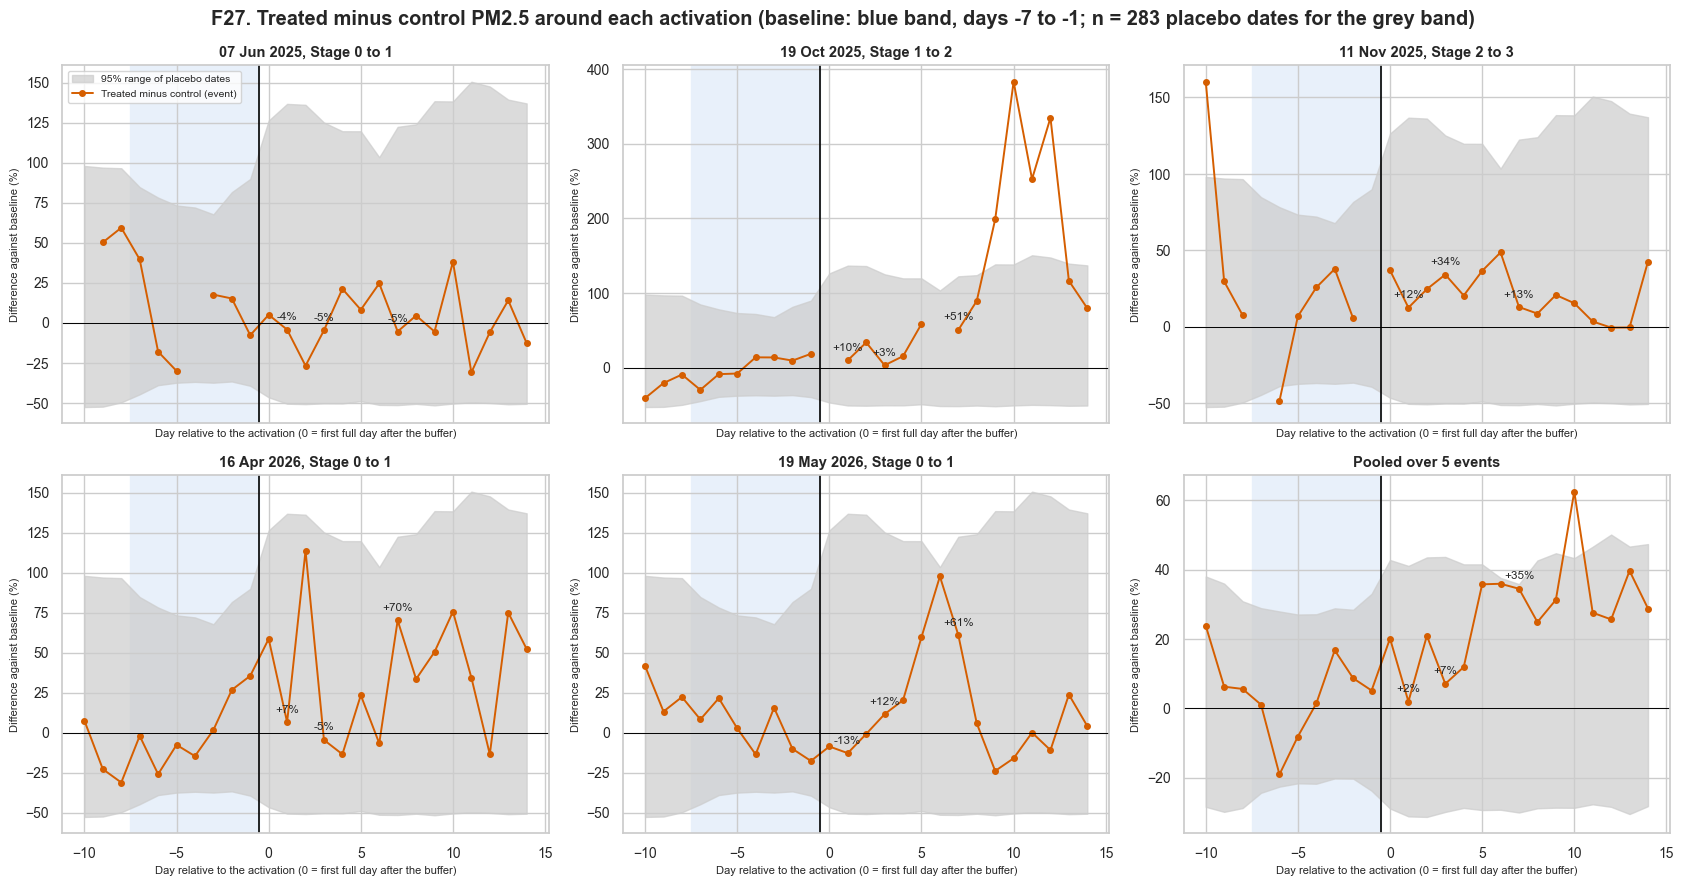

In [244]:
# Step 9B.3c: F27 event-time coefficients (% difference against the baseline) with the placebo band, the activation and buffer marked, values written at days 1, 3 and 7
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True); axes = axes.ravel()
panels = [(f"{changes.loc[n, 'hour_ist']:%d %b %Y}, Stage {changes.loc[n, 'stage_before']} to {changes.loc[n, 'stage_after']}", p, placebo_df.quantile([0.025, 0.975], axis=1)) for n, p in real_paths.items()]
panels.append((f"Pooled over {len(real_paths)} events", pooled_real, pooled_placebo.quantile([0.025, 0.975], axis=1)))
for ax, (title, path, band) in zip(axes, panels):
    ax.fill_between(KS, np.expm1(band.loc[0.025]) * 100, np.expm1(band.loc[0.975]) * 100, color="#CCCCCC", alpha=0.7, label="95% range of placebo dates")
    ax.plot(KS, np.expm1(path) * 100, "o-", color="#D55E00", ms=4, lw=1.4, label="Treated minus control (event)")
    ax.axvspan(-7.5, -0.5, color="#E8F0FA", zorder=0); ax.axvline(-0.5, color="black", lw=1.2); ax.axhline(0, color="black", lw=0.7)
    for k in (1, 3, 7):
        ax.annotate(f"{np.expm1(path.loc[k]) * 100:+.0f}%", (k, np.expm1(path.loc[k]) * 100), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8.5)
    ax.set_title(title, fontsize=10.5); ax.set_xlabel("Day relative to the activation (0 = first full day after the buffer)", fontsize=8); ax.set_ylabel("Difference against baseline (%)", fontsize=8)
axes[0].legend(fontsize=7.5, loc="upper left")
for ax in axes[len(panels):]:
    ax.axis("off")
fig.suptitle(f"F27. Treated minus control PM2.5 around each activation (baseline: blue band, days -7 to -1; n = {placebo_df.shape[1]} placebo dates for the grey band)", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F27_did_event_study"); plt.show()

In [245]:
# Step 9B.3d: takeaway text for the event study
pooled_row = did_table.iloc[-1]; n_below = int((did_table.iloc[:-1]["Days 1-3 (%)"] < 0).sum())
show_takeaway(
    f"**What we learn:** the treated stations fall **below** the control cities (against the baseline week) in the first three days after **{n_below}** of **{len(real_paths)}** events. Averaged over the events the difference is "
    f"**{pooled_row['Days 1-3 (%)']:+.1f}%** over days 1 to 3 (placebo range {pooled_row['Placebo 2.5% (days 1-3)']:+.1f}% to {pooled_row['Placebo 97.5% (days 1-3)']:+.1f}%; **{pooled_row['Share of placebos below (days 1-3)'] * 100:.0f}%** of placebo averages are lower) "
    f"and **{pooled_row['Days 4-7 (%)']:+.1f}%** over days 4 to 7. The pre-trend check "
    + ("flags " + ", ".join(did_table.index[did_table['Share of placebos with a larger pre-trend'] < 0.05]) + " (the two regions were not moving in parallel before it)." if (did_table['Share of placebos with a larger pre-trend'] < 0.05).any() else f"does not flag any event (the smallest share of placebos with a larger pre-trend is {did_table['Share of placebos with a larger pre-trend'].min():.3f}, against a threshold of 0.05).")
)

**What we learn:** the treated stations fall **below** the control cities (against the baseline week) in the first three days after **2** of **5** events. Averaged over the events the difference is **+9.7%** over days 1 to 3 (placebo range -25.6% to +33.8%; **76%** of placebo averages are lower) and **+29.1%** over days 4 to 7. The pre-trend check does not flag any event (the smallest share of placebos with a larger pre-trend is 0.053, against a threshold of 0.05).

*F27. For each event and for the average of the events, the difference between treated and control log PM2.5 on each day from -10 to +14 against its average over the baseline days -7 to -1 (blue band), shown as a % difference. The vertical line marks the activation (the 12-hour buffer sits between day -1 and day 0); the grey band is the pointwise 95% range of the same path computed at placebo dates with no stage change within 7 days (n in the title). Values are written at days 1, 3 and 7. Source: `final_dataset.parquet`, daily treated and control series.*

**What it shows.** Whether the treated stations move away from the control cities after an activation by more than they do on ordinary dates. Because the control cities share regional weather and episodes (such as Diwali), this removes shocks that hit both regions, which the weather-only counterfactual could not.

**What it does not show.** With only a handful of events and some of them within days of another stage change, no pooled claim goes beyond what the individual events show. The placebo band measures how much the difference wanders on ordinary dates; it does not remove the assumption of parallel trends, and the control cities differ in weather, local sources and local rules. A path outside the band would point to a difference after the activation, not to its cause. This is an extension and does not change the frozen H2 status.

## 9B.4 Pooled event-time profile of all upward activations (T06k, F28; optional)

**Question:** across **all upward stage changes** (14 of them, including Stage I in the spring and summer), does PM2.5 fall below the counterfactual after an activation in general?
**Method:** the method carried forward from 9B.2 (lowest median hold-out error); **if it passes the hold-out rule for fewer than 3 of the 14 upward changes, the method that passes for the most upward changes is used instead (accuracy only, declared here before any effect is computed).** For every upward change where that method passes the hold-out rule, the path of **actual minus predicted** log PM2.5 for days -7 to +14 (the days before the buffer are in the fit, so they scatter around zero by construction). Events within 7 days of each other form one **episode** and are averaged first; the average and a bootstrap band are over **episodes**, shown separately for **Stage I** and for **Stage II or higher**. The number of episodes with data is written for each day.

In [246]:
# Step 9B.4a0: ADDED AFTER SEEING RESULTS: how many of the 14 upward changes pass the hold-out rule under each method (accuracy only); the method for the profile
up_changes = list(changes.index[changes["direction"] == "up"])
up_usable = pd.DataFrame({name: [method_fit(series_alt, changes.loc[n, "hour_ist"], [t for k, t in changes["hour_ist"].items() if k != n], name)["usable"] for n in up_changes] for name in METHODS}, index=up_changes)
profile_method = best_method if up_usable[best_method].sum() >= 3 else up_usable.sum().idxmax()
display(up_usable.sum().rename("Upward changes passing the hold-out rule").to_frame().T); print("Method used for the profile:", profile_method, "(carried forward from 9B.2:", best_method + ")")

,Frozen,(a) Parsimonious weather,(b) Frozen with ridge,(c) Control cities,(d) Control cities + weather
Upward changes passing the hold-out rule,0,0,1,1,0


Method used for the profile: (b) Frozen with ridge (carried forward from 9B.2: (d) Control cities + weather)


In [247]:
# Step 9B.4a: ADDED AFTER SEEING RESULTS: path of actual minus predicted for every upward change where the profile method is usable
episode = (changes.loc[up_changes, "hour_ist"].diff().dt.total_seconds().fillna(1e12) >= MIN_CLEAN_DAYS * 86400).cumsum()
paths_up, fit_status = {}, []
for n in up_changes:
    t0 = changes.loc[n, "hour_ist"]; fit_n = method_fit(series_alt, t0, [t for k, t in changes["hour_ist"].items() if k != n], profile_method)
    fit_status.append({"Change": n, "Date": f"{t0:%d %b %Y}", "Stage after": changes.loc[n, "stage_after"], "Episode": int(episode[n]), "Hold-out error": fit_n.get("holdout_error", np.nan), "Usable": fit_n["usable"]})
    if fit_n["usable"]:
        ks = np.arange(-7, 15)
        dates = [fit_n["last_pre"] + pd.Timedelta(days=int(k) + 1) if k < 0 else fit_n["first_post"] + pd.Timedelta(days=int(k)) for k in ks]
        rows_k = series_alt.reindex(dates).dropna(subset=["log_pm25"] + fit_n["spec"]["cols"])
        paths_up[n] = pd.Series(rows_k["log_pm25"].to_numpy() - fit_n["spec"]["design"](rows_k) @ fit_n["beta"], index=[ks[dates.index(d)] for d in rows_k.index]).reindex(ks)
fit_status = pd.DataFrame(fit_status).set_index("Change")
display(fit_status.round(2)); print(f"Method {profile_method}: usable for {len(paths_up)} of {len(up_changes)} upward changes, in {fit_status[fit_status['Usable']]['Episode'].nunique()} episodes")
log_extension("9B.4", "pooled event-time profile of actual minus predicted for all upward activations with a usable counterfactual (clustered by episode)")

,Date,Stage after,Episode,Hold-out error,Usable
Change,,,,,
3,24 Mar 2025,1,1,NaN,False
5,02 Apr 2025,1,2,NaN,False
7,16 May 2025,1,3,NaN,False
9,21 May 2025,1,3,NaN,False
11,07 Jun 2025,1,4,NaN,False
13,14 Oct 2025,1,5,0.32,False
14,19 Oct 2025,2,5,0.27,False
15,11 Nov 2025,3,6,0.46,False
17,13 Dec 2025,3,7,NaN,False


Method (b) Frozen with ridge: usable for 1 of 14 upward changes, in 1 episodes


In [248]:
# Step 9B.4b: average by episode, then across episodes, for Stage I and for Stage II or higher; bootstrap over episodes; n per day (T06k)
def episode_profile(members):
    per_episode = pd.DataFrame({e: pd.concat([paths_up[n] for n in members if episode[n] == e], axis=1).mean(axis=1) for e in sorted({episode[n] for n in members})})
    boot = pd.concat([per_episode.iloc[:, np.random.default_rng(SEED + i).integers(0, per_episode.shape[1], per_episode.shape[1])].mean(axis=1) for i in range(BOOTSTRAP_DRAWS)], axis=1) if per_episode.shape[1] >= 3 else None
    return pd.DataFrame({"mean": per_episode.mean(axis=1), "n": per_episode.notna().sum(axis=1), "low": boot.quantile(0.025, axis=1) if boot is not None else np.nan,
                         "high": boot.quantile(0.975, axis=1) if boot is not None else np.nan})
groups_up = {"Stage I": [n for n in paths_up if changes.loc[n, "stage_after"] == 1], "Stage II or higher": [n for n in paths_up if changes.loc[n, "stage_after"] >= 2]}
profiles = {name: episode_profile(members) for name, members in groups_up.items() if members}
profile_rows = []
for name, prof in profiles.items():
    for k, r in prof.iterrows():
        profile_rows.append({"Group": name, "Day": k, "Mean actual minus predicted (%)": np.expm1(r["mean"]) * 100, "Band low (%)": np.expm1(r["low"]) * 100, "Band high (%)": np.expm1(r["high"]) * 100, "Episodes": int(r["n"])})
profile_table = pd.DataFrame(profile_rows, columns=["Group", "Day", "Mean actual minus predicted (%)", "Band low (%)", "Band high (%)", "Episodes"])
display(profile_table[profile_table["Day"].isin([-3, 1, 2, 3, 5, 7, 14])].round(1)); save_table(profile_table.set_index("Group").round(2), "T06k_pooled_profile")

,Group,Day,Mean actual minus predicted (%),Band low (%),Band high (%),Episodes
4,Stage I,-3,8.2,NaN,NaN,1
8,Stage I,1,-26.4,NaN,NaN,1
9,Stage I,2,-7.3,NaN,NaN,1
10,Stage I,3,-2.0,NaN,NaN,1
12,Stage I,5,10.1,NaN,NaN,1
14,Stage I,7,4.5,NaN,NaN,1
21,Stage I,14,-16.7,NaN,NaN,1


saved table : T06k_pooled_profile


saved figure: F28_pooled_profile


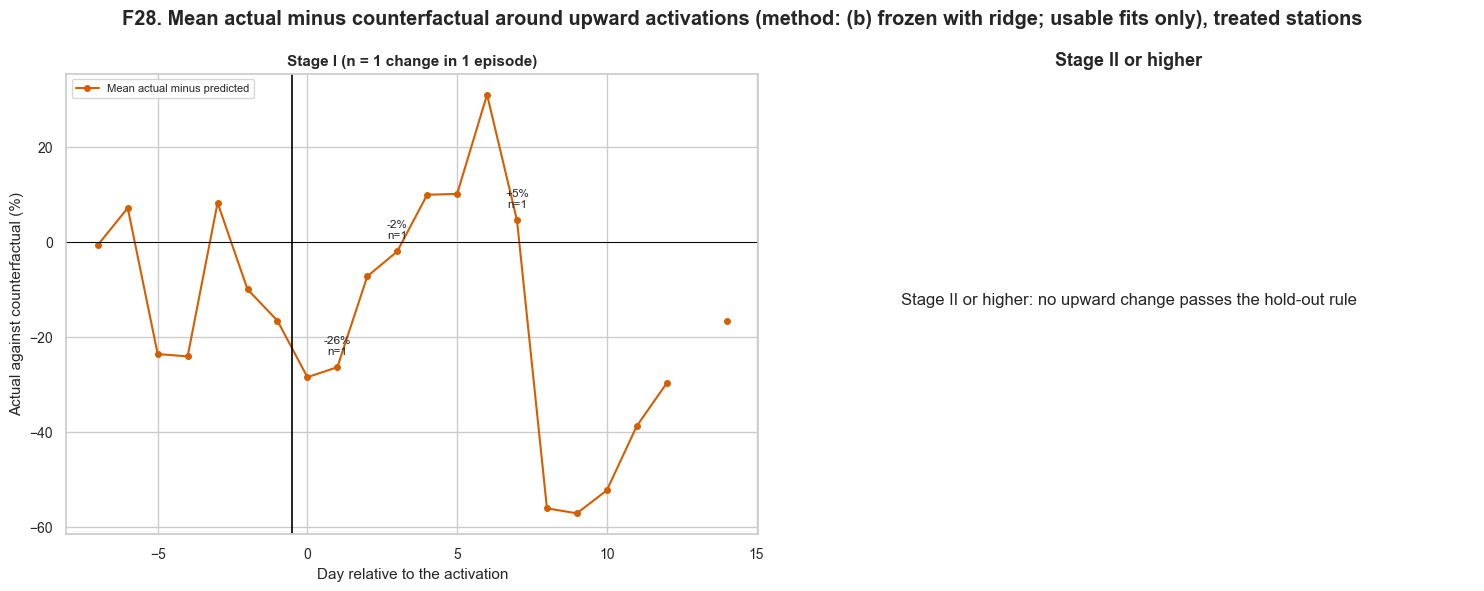

In [249]:
# Step 9B.4c: F28 pooled profile by stage size with the band over episodes (where there are at least 3 episodes) and the number of episodes written under each day
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, name in zip(axes, ["Stage I", "Stage II or higher"]):
    if name not in profiles:
        ax.text(0.5, 0.5, f"{name}: no upward change passes the hold-out rule", ha="center", transform=ax.transAxes); ax.set_title(name); ax.axis("off"); continue
    prof = profiles[name]
    if prof["low"].notna().any():
        ax.fill_between(prof.index, np.expm1(prof["low"]) * 100, np.expm1(prof["high"]) * 100, color="#CCCCCC", alpha=0.7, label="95% bootstrap band over episodes")
    ax.plot(prof.index, np.expm1(prof["mean"]) * 100, "o-", color="#D55E00", lw=1.5, ms=4, label="Mean actual minus predicted")
    ax.axvline(-0.5, color="black", lw=1.2); ax.axhline(0, color="black", lw=0.7)
    for k in (1, 3, 7):
        ax.annotate(f"{np.expm1(prof.loc[k, 'mean']) * 100:+.0f}%\nn={int(prof.loc[k, 'n'])}", (k, np.expm1(prof.loc[k, "mean"]) * 100), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5)
    n_ch, n_ep = len(groups_up[name]), len({episode[n] for n in groups_up[name]})
    ax.set_title(f"{name} (n = {n_ch} change{'s' if n_ch != 1 else ''} in {n_ep} episode{'s' if n_ep != 1 else ''})", fontsize=11); ax.set_xlabel("Day relative to the activation"); ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("Actual against counterfactual (%)")
fig.suptitle(f"F28. Mean actual minus counterfactual around upward activations (method: {profile_method.lower()}; usable fits only), treated stations", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F28_pooled_profile"); plt.show()

In [250]:
# Step 9B.4d: takeaway text for the pooled profile
def day_value(name, k):
    return f"{np.expm1(profiles[name].loc[k, 'mean']) * 100:+.1f}%" if name in profiles else "not available (no usable fit)"
n_episodes_used = fit_status[fit_status["Usable"]]["Episode"].nunique()
show_takeaway(
    f"**What we learn:** the method used ({profile_method.lower()}) passes the hold-out rule for **{len(paths_up)}** of **{len(up_changes)}** upward changes (**{n_episodes_used}** episode{'s' if n_episodes_used != 1 else ''}{', so this is a single case and not an average' if n_episodes_used < 3 else ''}). "
    f"For Stage I activations the average of actual minus predicted is **{day_value('Stage I', 1)}** on day 1, **{day_value('Stage I', 3)}** on day 3 and **{day_value('Stage I', 7)}** on day 7; "
    f"for Stage II or higher **{day_value('Stage II or higher', 1)}** on day 1, **{day_value('Stage II or higher', 3)}** on day 3 and **{day_value('Stage II or higher', 7)}** on day 7."
)

**What we learn:** the method used ((b) frozen with ridge) passes the hold-out rule for **1** of **14** upward changes (**1** episode, so this is a single case and not an average). For Stage I activations the average of actual minus predicted is **-26.4%** on day 1, **-2.0%** on day 3 and **+4.5%** on day 7; for Stage II or higher **not available (no usable fit)** on day 1, **not available (no usable fit)** on day 3 and **not available (no usable fit)** on day 7.

*F28. Mean of actual minus counterfactual PM2.5 (%) for days -7 to +14 around upward stage changes where the chosen counterfactual passes the hold-out rule, averaged within episodes and then across episodes, for Stage I (left) and Stage II or higher (right); grey band: 95% bootstrap over episodes (shown when there are at least 3 episodes); the number of episodes is written at days 1, 3 and 7. Treated stations. Source: `final_dataset.parquet`.*

**What it shows.** Whether, across the many Stage I activations of the spring and summer and the few higher-stage ones, PM2.5 tends to fall below its counterfactual after an activation.

**What it does not show.** Many of these activations happen at low PM2.5 (Stage I in spring), far from the smog episodes the hypothesis is about, and episodes are few. The days before the buffer are in the fitting period, so they must sit near zero and carry no information. The result is for information and does not change the frozen status of H2.

## 9B.5 Mean-reversion benchmark with a large sample, no model needed (T06l, F29)

**Question (Q4):** stages are invoked when PM2.5 is already high and rising, and PM2.5 tends to fall afterwards anyway. How large are the falls on **comparable days when no stage was invoked**?
**Method:** *spike days* are dates with **no stage change within 3 days** (the frozen placebo rule requires 7 and leaves only two dates; **relaxed to 3 and said so here**) whose previous seven days look like the primary event's: **strict set**: mean within 15% of the primary event's and a rising trend between half and one and a half times as steep; **broad set**: mean within 30% and any rising trend. For every spike day the **raw change** is the mean PM2.5 over days 1 to 3 after the buffer against the mean over the 3 days before it, with no model at all. The real events and the same dates in the control cities are marked, and, for each real event, the share of **comparable** days (level within 30% of the event's and the same direction of trend, no stage within 3 days) with a *lower* change is written. Neighbouring spike days overlap, so the number of independent episodes is smaller than the number of days.

In [251]:
# Step 9B.5a: ADDED AFTER SEEING RESULTS: for every date without a stage change within 3 days: the pre-period context and the raw change, in the treated and control series
def context_generic(pm_series, last_pre, first_post):
    # level, trend, deviation from the 60-day mean and the raw change (log of mean of days 1-3 after over mean of the 3 days before) for one date
    last7 = pm_series.reindex(pd.date_range(last_pre - pd.Timedelta(days=6), last_pre)).dropna(); last60 = pm_series.reindex(pd.date_range(last_pre - pd.Timedelta(days=59), last_pre)).dropna()
    before3 = pm_series.reindex(pd.date_range(last_pre - pd.Timedelta(days=2), last_pre)).dropna(); after3 = pm_series.reindex(pd.date_range(first_post, first_post + pd.Timedelta(days=2))).dropna()
    if len(last7) < 4 or len(last60) < 30 or len(before3) < 2 or len(after3) < 2:
        return None
    return {"level": last7.mean(), "trend": np.expm1(np.polyfit(np.arange(len(last7)), np.log(last7.to_numpy()), 1)[0]) * 100,
            "dev": np.log(last7.mean()) - np.log(last60.mean()), "raw": np.log(after3.mean() / before3.mean())}

In [252]:
# Step 9B.5a2: ADDED AFTER SEEING RESULTS: the context of every date without a stage change within 3 days, and of the real events
def context_row(t0):
    last_pre, first_post = event_days(t0); out = {}
    for tag, ser in [("", series_treated["pm25"]), ("c_", series_control["pm25"])]:
        ctx_ = context_generic(ser, last_pre, first_post)
        out.update({tag + k: (v if ctx_ else np.nan) for k, v in (ctx_ or dict(level=0, trend=0, dev=0, raw=0)).items()})
    return out
ctx = {}
for day in pd.date_range(series_treated.index.min() + pd.Timedelta(days=45), series_treated.index.max() - pd.Timedelta(days=8)):
    t0 = day + pd.Timedelta(hours=12)
    if min(abs((t0 - c).total_seconds()) for c in all_change_times) >= 3 * 86400:
        ctx[day] = context_row(t0)
ctx = pd.DataFrame(ctx).T.astype(float); ctx = ctx.dropna(subset=["level", "raw"])
real_ctx = pd.DataFrame({n: context_row(changes.loc[n, "hour_ist"]) for n in all_events}).T.astype(float)
p_level, p_trend = event_table.loc[primary_number, "pm25_7d_before"], event_table.loc[primary_number, "pm25_trend_pct_per_day"]
strict = (ctx["level"].sub(p_level).abs() <= 0.15 * p_level) & ctx["trend"].between(0.5 * p_trend, 1.5 * p_trend)
broad = (ctx["level"].sub(p_level).abs() <= 0.30 * p_level) & (ctx["trend"] > 0)
print(f"Dates without a stage change within 3 days and with a context: {len(ctx)} | strict spike days: {int(strict.sum())} | broad spike days: {int(broad.sum())} | primary event level {p_level:.1f}, trend {p_trend:+.1f}% per day")
log_extension("9B.5", "spike-day benchmark: raw change after comparable days without a stage change (strict set and broad set), no counterfactual model")

Dates without a stage change within 3 days and with a context: 377 | strict spike days: 1 | broad spike days: 21 | primary event level 195.8, trend +18.2% per day


In [253]:
# Step 9B.5b: the real events against the spike days (T06l): raw change, the same dates in the control cities, and the share of spike days with a lower change
def n_episodes(dates):
    d = pd.Series(sorted(dates)); return int((d.diff().dt.days.fillna(99) > 3).sum())          # groups of dates separated by more than 3 days
def comparable_mask(r):
    # days whose pre-period level is within 30% of the event's and whose trend points the same way
    return (ctx["level"].sub(r["level"]).abs() <= 0.30 * r["level"]) & ((ctx["trend"] > 0) if r["trend"] > 0 else (ctx["trend"] <= 0))
rows, comparable_days = [], {}
for n in real_ctx.index:
    r = real_ctx.loc[n]
    if np.isnan(r["raw"]):
        continue
    comparable = comparable_mask(r); comparable_days[f"{changes.loc[n, 'hour_ist']:%d %b %Y}"] = comparable
    rows.append({"Event": f"{changes.loc[n, 'hour_ist']:%d %b %Y}", "Pre-level (ug/m3)": r["level"], "Pre-trend (% per day)": r["trend"], "Raw change treated (%)": np.expm1(r["raw"]) * 100, "Raw change control, same date (%)": np.expm1(r["c_raw"]) * 100,
                 "Comparable days (n)": int(comparable.sum()), "Episodes": n_episodes(ctx.index[comparable]), "Median change on comparable days (%)": np.expm1(ctx.loc[comparable, "raw"].median()) * 100,
                 "Comparable days with a lower change": float((ctx.loc[comparable, "raw"] < r["raw"]).mean())})
spike_table = pd.DataFrame(rows).set_index("Event")
spike_summary = pd.Series({"Strict n": int(strict.sum()), "Strict median change (%)": np.expm1(ctx.loc[strict, "raw"].median()) * 100, "Broad n": int(broad.sum()), "Broad episodes": n_episodes(ctx.index[broad]),
                           "Broad median change (%)": np.expm1(ctx.loc[broad, "raw"].median()) * 100, "Broad share of days with a fall": float((ctx.loc[broad, "raw"] < 0).mean())})
display(spike_table.round(2)); display(spike_summary.round(1)); save_table(spike_table.round(3), "T06l_spike_days")

,Pre-level (ug/m3),Pre-trend (% per day),Raw change treated (%),"Raw change control, same date (%)",Comparable days (n),Episodes,Median change on comparable days (%),Comparable days with a lower change
Event,,,,,,,,
07 Jun 2025,56.50,-6.96,27.77,51.97,58,18,17.66,0.64
19 Oct 2025,98.34,11.89,78.76,66.88,32,13,-19.82,1.00
11 Nov 2025,195.79,18.18,6.61,3.31,21,6,-9.76,0.76
16 Apr 2026,62.13,9.78,35.57,6.15,60,21,-11.19,0.95
19 May 2026,60.45,-0.29,-13.28,-10.79,58,18,15.14,0.21


Strict n                            1.0
Strict median change (%)          -34.9
Broad n                            21.0
Broad episodes                      6.0
Broad median change (%)            -9.8
Broad share of days with a fall     0.8
dtype: float64

saved table : T06l_spike_days


saved figure: F29_spike_day_benchmark


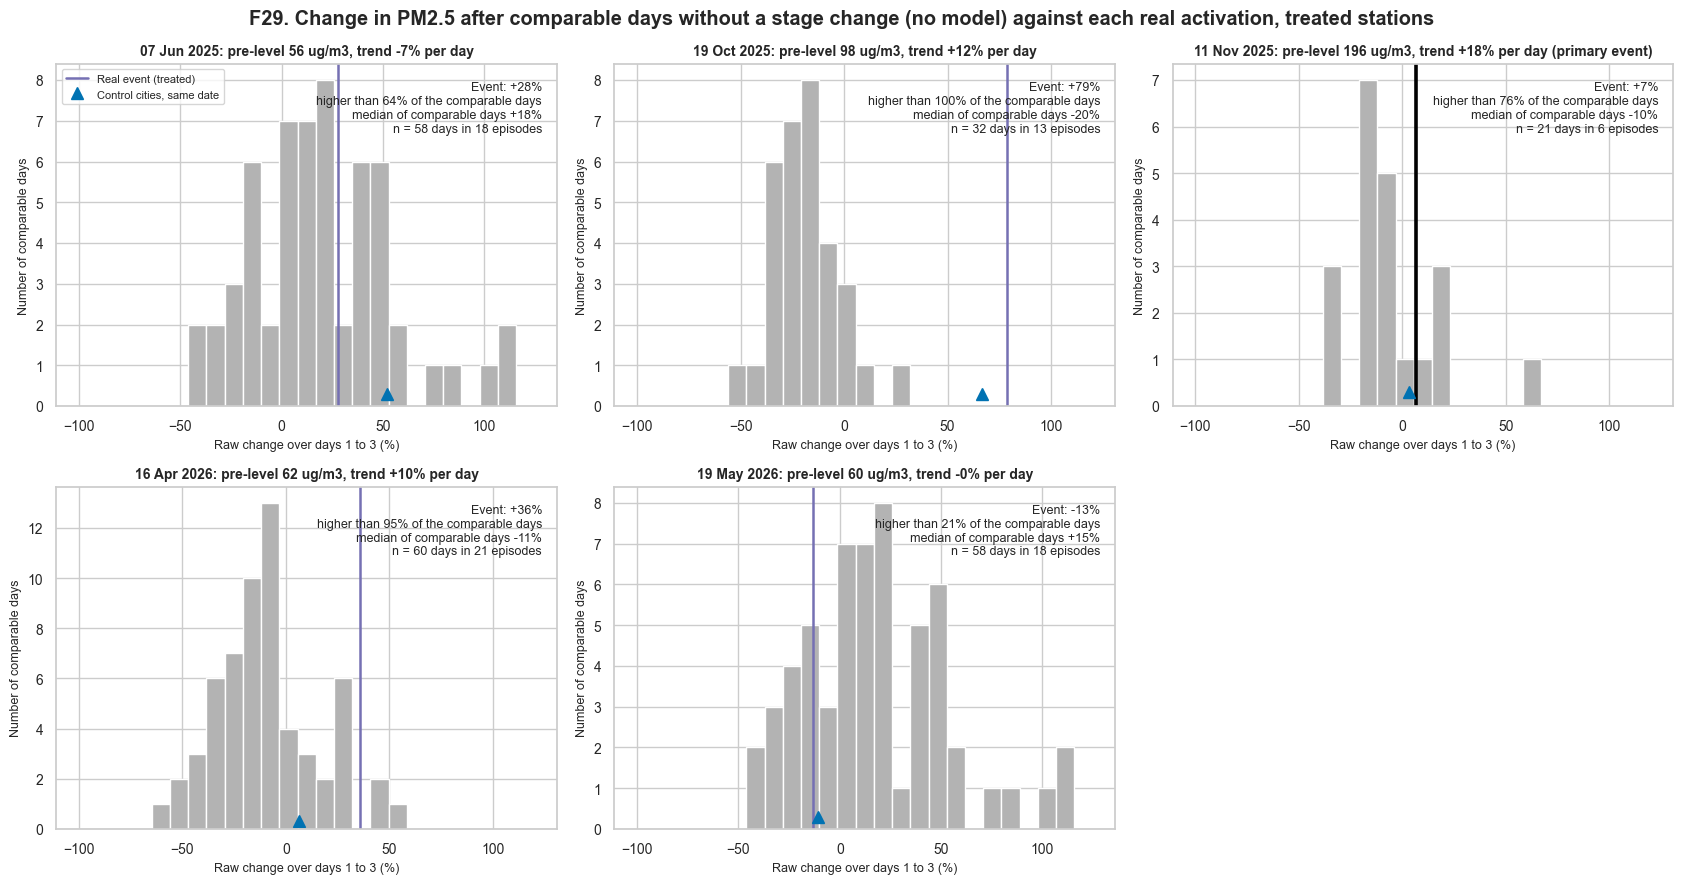

In [254]:
# Step 9B.5c: F29 one panel per real event: raw change after its comparable days (histogram), the event (line) and the control cities on the same date (triangle)
fig, axes = plt.subplots(2, 3, figsize=(17, 9)); axes = axes.ravel()
for ax, (event, r) in zip(axes, spike_table.iterrows()):
    is_primary = event == f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}"
    vals = np.expm1(ctx.loc[comparable_days[event], "raw"]) * 100
    ax.hist(vals, bins=np.linspace(-100, max(120, vals.max() + 10), 26), color="#B3B3B3")
    ax.axvline(r["Raw change treated (%)"], color="#000000" if is_primary else "#7570B3", lw=2.6 if is_primary else 1.8, label="Real event (treated)")
    ax.plot(r["Raw change control, same date (%)"], 0.3, "^", color="#0072B2", ms=9, label="Control cities, same date")
    ax.text(0.97, 0.95, f"Event: {r['Raw change treated (%)']:+.0f}%\nhigher than {r['Comparable days with a lower change'] * 100:.0f}% of the comparable days\nmedian of comparable days {r['Median change on comparable days (%)']:+.0f}%\nn = {int(r['Comparable days (n)'])} days in {int(r['Episodes'])} episodes",
            transform=ax.transAxes, ha="right", va="top", fontsize=9)
    ax.set_title(f"{event}: pre-level {r['Pre-level (ug/m3)']:.0f} ug/m3, trend {r['Pre-trend (% per day)']:+.0f}% per day" + (" (primary event)" if is_primary else ""), fontsize=10); ax.set_xlabel("Raw change over days 1 to 3 (%)", fontsize=9); ax.set_ylabel("Number of comparable days", fontsize=9)
axes[0].legend(loc="upper left", fontsize=8)
for ax in axes[len(spike_table):]:
    ax.axis("off")
fig.suptitle("F29. Change in PM2.5 after comparable days without a stage change (no model) against each real activation, treated stations", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F29_spike_day_benchmark"); plt.show()

In [255]:
# Step 9B.5d: takeaway text for the spike-day benchmark
pe = spike_table.loc[f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}"]
show_takeaway(
    f"**What we learn:** on **{int(broad.sum())}** broad spike days without a stage change (in **{int(spike_summary['Broad episodes'])}** separate episodes) the median change over days 1 to 3 is **{spike_summary['Broad median change (%)']:+.1f}%**, and PM2.5 falls on **{spike_summary['Broad share of days with a fall'] * 100:.0f}%** of them; "
    f"on the **{int(strict.sum())}** strict ones the median is **{spike_summary['Strict median change (%)']:+.1f}%**. The primary event (11 Nov 2025) changed by **{pe['Raw change treated (%)']:+.1f}%**: its change was higher than that of **{pe['Comparable days with a lower change'] * 100:.0f}%** of its **{int(pe['Comparable days (n)'])}** comparable days "
    f"(it fell less, or rose more, than most of them), and the control cities changed by **{pe['Raw change control, same date (%)']:+.1f}%** on the same date."
)

**What we learn:** on **21** broad spike days without a stage change (in **6** separate episodes) the median change over days 1 to 3 is **-9.8%**, and PM2.5 falls on **76%** of them; on the **1** strict ones the median is **-34.9%**. The primary event (11 Nov 2025) changed by **+6.6%**: its change was higher than that of **76%** of its **21** comparable days (it fell less, or rose more, than most of them), and the control cities changed by **+3.3%** on the same date.

*F29. For each real activation, histogram of the raw change in PM2.5 (mean of days 1 to 3 after the 12-hour buffer against the 3 days before it) after comparable days with no stage change within 3 days (level within 30% of the event's and the same direction of trend); the black or purple line is the real event, the blue triangle the control cities on the same date; the share of comparable days with a lower change, the median, the number of days and the number of episodes are written in each panel. Treated stations. Source: `final_dataset.parquet`.*

**What it shows.** What happens after comparable high, rising days **without any stage**: a typical fall (mean reversion) with a wide spread. The real events can be compared with this spread directly, without a counterfactual model that failed its hold-out check.

**What it does not show.** The spike days are overlapping days from a few smog episodes, so they are not independent; the number of independent episodes is much smaller than the number of days. A stage is invoked because of conditions that the spike definition (level and trend) only partly captures. A real event inside the spread of spike days is not evidence against an effect of GRAP: it means that this design cannot tell it from the ordinary spread. The 3-day relaxation of the frozen rule is an extension.

## 9B.6 How much fall does mean reversion alone predict? (T06m)

**Question (Q4):** given how high and how steeply rising PM2.5 was before each event, how large a fall would mean reversion alone give, and is the real fall larger than that?
**Method:** on all days without a stage change within 3 days, regress the **raw change** over days 1 to 3 (log of the mean after over the mean before) on the **deviation of the last 7 days from the 60-day mean** (log) and the **pre-trend** (% per day), for the treated and the control series separately, once for **winter days** (1 Oct 2025 to 28 Feb 2026, as planned) and once for **all days** (the events are mostly outside the winter). For each real event the **expected** change is the prediction at its own deviation and trend; the **excess fall** is actual minus expected, with a 95% interval from a date-block bootstrap of the regression plus a resampled residual (so that day-to-day noise is included).

In [256]:
# Step 9B.6a: ADDED AFTER SEEING RESULTS: the mean-reversion regression and the excess change of every real event, with block-bootstrap intervals
def design_mr(frame, tag):
    return np.column_stack([np.ones(len(frame)), frame[tag + "dev"].to_numpy(), frame[tag + "trend"].to_numpy() / 100])
rows = []
for sample, mask in [("winter days", (ctx.index >= WINTER_START) & (ctx.index <= WINTER_END)), ("all days", np.ones(len(ctx), dtype=bool))]:
    for tag, region in [("", "Treated"), ("c_", "Control")]:
        fr = ctx[mask].dropna(subset=[tag + "dev", tag + "trend", tag + "raw"]); X_r, y_r = design_mr(fr, tag), fr[tag + "raw"].to_numpy()
        beta_r = np.linalg.lstsq(X_r, y_r, rcond=None)[0]; resid_r = y_r - X_r @ beta_r; w_r = date_weights(fr.index.to_numpy())
        betas_r = np.array([weighted_fit(X_r, y_r, w) for w in w_r]); rng_r = np.random.default_rng(SEED)
        for n in real_ctx.index:
            ev = real_ctx.loc[[n]]
            if ev[[tag + "dev", tag + "trend", tag + "raw"]].isna().any(axis=1).iloc[0]:
                continue
            x_ev = design_mr(ev, tag)[0]; expected, actual = x_ev @ beta_r, ev[tag + "raw"].iloc[0]
            null = expected - betas_r @ x_ev + rng_r.choice(resid_r, len(betas_r))
            rows.append({"Sample": sample, "Region": region, "Event": f"{changes.loc[n, 'hour_ist']:%d %b %Y}", "Actual change (%)": np.expm1(actual) * 100, "Expected from mean reversion (%)": np.expm1(expected) * 100,
                         "Excess (%)": np.expm1(actual - expected) * 100, "CI low": np.expm1(actual - expected - np.percentile(null, 97.5)) * 100, "CI high": np.expm1(actual - expected - np.percentile(null, 2.5)) * 100,
                         "Regression R2": 1 - resid_r.var() / y_r.var(), "Regression days": len(fr), "Slope on deviation": beta_r[1]})
reversion = pd.DataFrame(rows)
display(reversion.round(2)); save_table(reversion.set_index("Sample").round(3), "T06m_mean_reversion")
log_extension("9B.6", "mean-reversion regression of the 3-day change on deviation and trend (treated and control; winter and all days), excess fall of each real event")

,Sample,Region,Event,Actual change (%),Expected from mean reversion (%),Excess (%),CI low,CI high,Regression R2,Regression days,Slope on deviation
0,winter days,Treated,07 Jun 2025,27.77,13.42,12.65,-34.35,62.53,0.35,82,0.05
1,winter days,Treated,19 Oct 2025,78.76,-21.33,127.22,28.51,221.81,0.35,82,0.05
2,winter days,Treated,11 Nov 2025,6.61,-31.47,55.58,-11.51,123.64,0.35,82,0.05
3,winter days,Treated,16 Apr 2026,35.57,-21.25,72.16,-0.54,149.11,0.35,82,0.05
4,winter days,Treated,19 May 2026,-13.28,-1.35,-12.09,-49.64,25.86,0.35,82,0.05
5,winter days,Control,07 Jun 2025,51.97,11.86,35.86,-21.49,133.40,0.36,82,-0.70
6,winter days,Control,19 Oct 2025,66.88,-27.26,129.42,32.63,316.92,0.36,82,-0.70
7,winter days,Control,11 Nov 2025,3.31,-17.29,24.90,-28.16,121.02,0.36,82,-0.70
8,winter days,Control,16 Apr 2026,6.15,5.72,0.41,-42.30,79.05,0.36,82,-0.70
9,winter days,Control,19 May 2026,-10.79,-0.83,-10.05,-47.39,56.60,0.36,82,-0.70


saved table : T06m_mean_reversion


In [257]:
# Step 9B.6b: takeaway text for the mean-reversion regression (primary event, treated stations)
label_p = f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}"
r_w = reversion[(reversion["Sample"] == "winter days") & (reversion["Region"] == "Treated") & (reversion["Event"] == label_p)].iloc[0]
r_a = reversion[(reversion["Sample"] == "all days") & (reversion["Region"] == "Treated") & (reversion["Event"] == label_p)].iloc[0]
r_c = reversion[(reversion["Sample"] == "winter days") & (reversion["Region"] == "Control") & (reversion["Event"] == label_p)]
show_takeaway(
    f"**What we learn:** for the primary event the winter regression ({int(r_w['Regression days'])} days, R-squared {r_w['Regression R2']:.2f}) expects a change of **{r_w['Expected from mean reversion (%)']:+.1f}%** from the height and the steepness of the run-up alone; the actual change was "
    f"**{r_w['Actual change (%)']:+.1f}%**, an excess of **{r_w['Excess (%)']:+.1f}%** (95% interval {r_w['CI low']:+.1f}% to {r_w['CI high']:+.1f}%). With all days in the regression the expected change is **{r_a['Expected from mean reversion (%)']:+.1f}%** and the excess **{r_a['Excess (%)']:+.1f}%** "
    f"(interval {r_a['CI low']:+.1f}% to {r_a['CI high']:+.1f}%)." + (f" In the control cities on the same date the excess is {r_c.iloc[0]['Excess (%)']:+.1f}% (interval {r_c.iloc[0]['CI low']:+.1f}% to {r_c.iloc[0]['CI high']:+.1f}%)." if len(r_c) else "")
)

**What we learn:** for the primary event the winter regression (82 days, R-squared 0.35) expects a change of **-31.5%** from the height and the steepness of the run-up alone; the actual change was **+6.6%**, an excess of **+55.6%** (95% interval -11.5% to +123.6%). With all days in the regression the expected change is **-25.9%** and the excess **+43.8%** (interval -15.5% to +142.9%). In the control cities on the same date the excess is +24.9% (interval -28.2% to +121.0%).

**What it shows.** How much of an observed fall is what mean reversion alone would give, given where PM2.5 stood and how fast it was rising; the excess is the part left for GRAP, weather not captured and chance.

**What it does not show.** The regression uses only the level and the trend of PM2.5, not the weather of the following days, so a clearing of the weather is counted as excess. The intervals include day-to-day noise but not the choice of specification. Winter days are few (one winter), and most real events lie outside the winter, so the all-days regression is the better match for them. The excess is not an effect of GRAP.

## 9B.7 Control-city placebo over all spike dates (T06m2)

**Question:** how large are the "effects" of the weather-based counterfactual method on dates when no GRAP applies at all?
**Method:** the best method **that does not use the control cities** (lowest median hold-out error in 9B.2, chosen on accuracy alone) is run on the **control-city** series at every date with no stage change within 3 days at the treated stations where the control cities' own PM2.5 was rising (a spike-like run-up; GRAP does not apply in the control cities). Its "effect" over days 1 to 3 is a draw from the distribution the method produces when the true effect is zero. The real events' effects at the **treated** stations under the same method are placed in it.

In [258]:
# Step 9B.7a: ADDED AFTER SEEING RESULTS: the chosen weather-only method on the control series at all rising dates, and on the treated series at the real events
rows = []
for day in ctx.index[ctx["c_trend"] > 0]:
    t0 = day + pd.Timedelta(hours=12); fit_c = method_fit(series_control, t0, all_change_times, best_weather_method)
    if "X" in fit_c:
        eff = method_effect(fit_c, series_control)[0]
        rows.append({"Date": day, "Effect days 1-3 (%)": eff.get("effect_pct", np.nan), "Usable": fit_c["usable"], "Hold-out error": fit_c["holdout_error"]})
control_null = pd.DataFrame(rows).dropna(subset=["Effect days 1-3 (%)"])
real_rows = []
for n in plot_events:
    fit_t = method_fit(series_alt, changes.loc[n, "hour_ist"], [t for k, t in changes["hour_ist"].items() if k != n], best_weather_method)
    eff = method_effect(fit_t, series_alt)[0] if "X" in fit_t else {}
    real_rows.append({"Event": f"{changes.loc[n, 'hour_ist']:%d %b %Y}", "Treated effect days 1-3 (%)": eff.get("effect_pct", np.nan), "Usable": fit_t["usable"],
                      "Share of control spike-date effects below": float((control_null["Effect days 1-3 (%)"] < eff["effect_pct"]).mean()) if eff else np.nan,
                      "Share below (usable control fits only)": float((control_null.loc[control_null["Usable"], "Effect days 1-3 (%)"] < eff["effect_pct"]).mean()) if eff and control_null["Usable"].any() else np.nan})
control_placebo = pd.DataFrame(real_rows).set_index("Event")
display(control_placebo.round(2)); save_table(control_placebo.round(3), "T06m2_control_placebo")
print(f"Method {best_weather_method}: {len(control_null)} control dates with a fit, {int(control_null['Usable'].sum())} usable | median effect {control_null['Effect days 1-3 (%)'].median():+.1f}%, 5th to 95th percentile {control_null['Effect days 1-3 (%)'].quantile(0.05):+.1f}% to {control_null['Effect days 1-3 (%)'].quantile(0.95):+.1f}%")
log_extension("9B.7", "chosen weather-only counterfactual run on the control cities at all rising dates without a stage change (null distribution of the method's effects)")

,Treated effect days 1-3 (%),Usable,Share of control spike-date effects below,Share below (usable control fits only)
Event,,,,
19 Oct 2025,389.71,False,1.00,1.00
11 Nov 2025,-14.81,False,0.19,0.15
16 Apr 2026,12.04,False,0.59,0.55
19 May 2026,-9.00,False,0.26,0.24


saved table : T06m2_control_placebo
Method (a) Parsimonious weather: 107 control dates with a fit, 91 usable | median effect +0.0%, 5th to 95th percentile -35.1% to +123.4%


In [259]:
# Step 9B.7b: takeaway text for the control-city placebo
pcp = control_placebo.loc[f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}"]
show_takeaway(
    f"**What we learn:** run on **{len(control_null)}** rising dates in the control cities, where GRAP does not apply, the method gives a median effect of **{control_null['Effect days 1-3 (%)'].median():+.1f}%** over days 1 to 3, with a 5th to 95th percentile range of "
    f"**{control_null['Effect days 1-3 (%)'].quantile(0.05):+.1f}% to {control_null['Effect days 1-3 (%)'].quantile(0.95):+.1f}%**, and **{int(control_null['Usable'].sum())}** of the fits pass the hold-out rule. The primary event's treated-station effect under the same method is "
f"**{pcp['Treated effect days 1-3 (%)']:+.1f}%**; **{pcp['Share of control spike-date effects below'] * 100:.0f}%** of the control-city effects are lower than it."
)

**What we learn:** run on **107** rising dates in the control cities, where GRAP does not apply, the method gives a median effect of **+0.0%** over days 1 to 3, with a 5th to 95th percentile range of **-35.1% to +123.4%**, and **91** of the fits pass the hold-out rule. The primary event's treated-station effect under the same method is **-14.8%**; **19%** of the control-city effects are lower than it.

**What it shows.** The spread of "effects" that the method produces when nothing was done, using far more dates than the frozen placebo rule allows (two). If the real events lie inside that spread, the method cannot tell them from noise.

**What it does not show.** The control cities have different weather and sources, so their null distribution is only an approximation of what the treated stations would show without GRAP. Spike dates overlap, so the dates are not independent draws. Most fits do not pass the hold-out rule, so the null distribution is also broad because the method is poor, which is precisely the point: it cannot reveal a modest effect.

## 9B.8 Power with matched noise, and how much data would be enough (T06n, F30)

**Question:** how large a fall could be detected, and how many events (winters) would it take to detect a modest fall?
**Method:** replace the bootstrap noise of Phase 9 by **empirical noise**: (i) the **raw changes after rising days** (the days of 9B.5 with a rising trend and no stage within 3 days, log scale; more days than the spike sets, so that the noise is estimated from many dates), and (ii) the **control-city placebo effects** (9B.7, log scale; all rising control dates). With *k* events the detection rule is the frozen one: the average of the *k* event effects must lie below the **5th percentile** of the average of *k* draws from the noise. Power for a true fall *f* is the share of simulated averages, each shifted by log(1 - *f*), that are detected. Events are treated as independent draws (as they would be in different winters). The **minimum detectable fall** is the smallest *f* with at least 80% power; the **number of events needed** is the smallest *k* with 80% power at a 15% fall.

In [260]:
# Step 9B.8a: ADDED AFTER SEEING RESULTS: power by number of events and size of the true fall, for each empirical noise source (T06n)
noise = {"Raw changes after rising days": ctx.loc[ctx["trend"] > 0, "raw"].to_numpy(), "Control-city placebo effects": np.log1p(control_null["Effect days 1-3 (%)"].to_numpy() / 100)}
FALLS, KMAX, DRAWS_P = np.arange(0.01, 0.81, 0.01), 40, 20000
def power_curve(null, k, rng):
    sims = rng.choice(null, size=(DRAWS_P, k)).mean(axis=1); critical = np.percentile(sims, 5)
    return np.array([np.mean(np.log(1 - f) + sims < critical) for f in FALLS])
power_grid = {name: {k: power_curve(null, k, np.random.default_rng(SEED + k)) for k in range(1, KMAX + 1)} for name, null in noise.items()}
rows = []
for name in noise:
    for k in (1, 2, 4, 8):
        pw = power_grid[name][k]
        rows.append({"Noise source": name, "Events": k, "Power at a 10% fall": pw[9], "Power at a 20% fall": pw[19], "Power at a 30% fall": pw[29], "Power at a 40% fall": pw[39],
                     "Minimum detectable fall (80% power)": FALLS[np.argmax(pw >= 0.8)] if (pw >= 0.8).any() else np.nan})
power_table_b = pd.DataFrame(rows)
needed = {name: next((k for k in range(1, KMAX + 1) if power_grid[name][k][14] >= 0.8), np.nan) for name in noise}
display(power_table_b.round(2)); print("Events needed for 80% power at a 15% fall:", needed, "| noise sizes:", {n: len(v) for n, v in noise.items()})
save_table(power_table_b.set_index("Noise source").round(3), "T06n_power_matched_noise")
log_extension("9B.8", "power curves from empirical noise (spike-day raw changes and control-city placebo effects) for 1 to 40 events")

,Noise source,Events,Power at a 10% fall,Power at a 20% fall,Power at a 30% fall,Power at a 40% fall,Minimum detectable fall (80% power)
0,Raw changes after rising days,1,0.09,0.22,0.37,0.65,0.48
1,Raw changes after rising days,2,0.11,0.28,0.56,0.84,0.39
2,Raw changes after rising days,4,0.18,0.49,0.84,0.99,0.29
3,Raw changes after rising days,8,0.29,0.77,0.99,1.00,0.21
4,Control-city placebo effects,1,0.06,0.12,0.25,0.57,0.52
5,Control-city placebo effects,2,0.06,0.08,0.13,0.33,0.56
6,Control-city placebo effects,4,0.07,0.11,0.22,0.55,0.48
7,Control-city placebo effects,8,0.08,0.17,0.42,0.83,0.40


Events needed for 80% power at a 15% fall: {'Raw changes after rising days': 17, 'Control-city placebo effects': nan} | noise sizes: {'Raw changes after rising days': 196, 'Control-city placebo effects': 107}
saved table : T06n_power_matched_noise


saved figure: F30_power_matched_noise


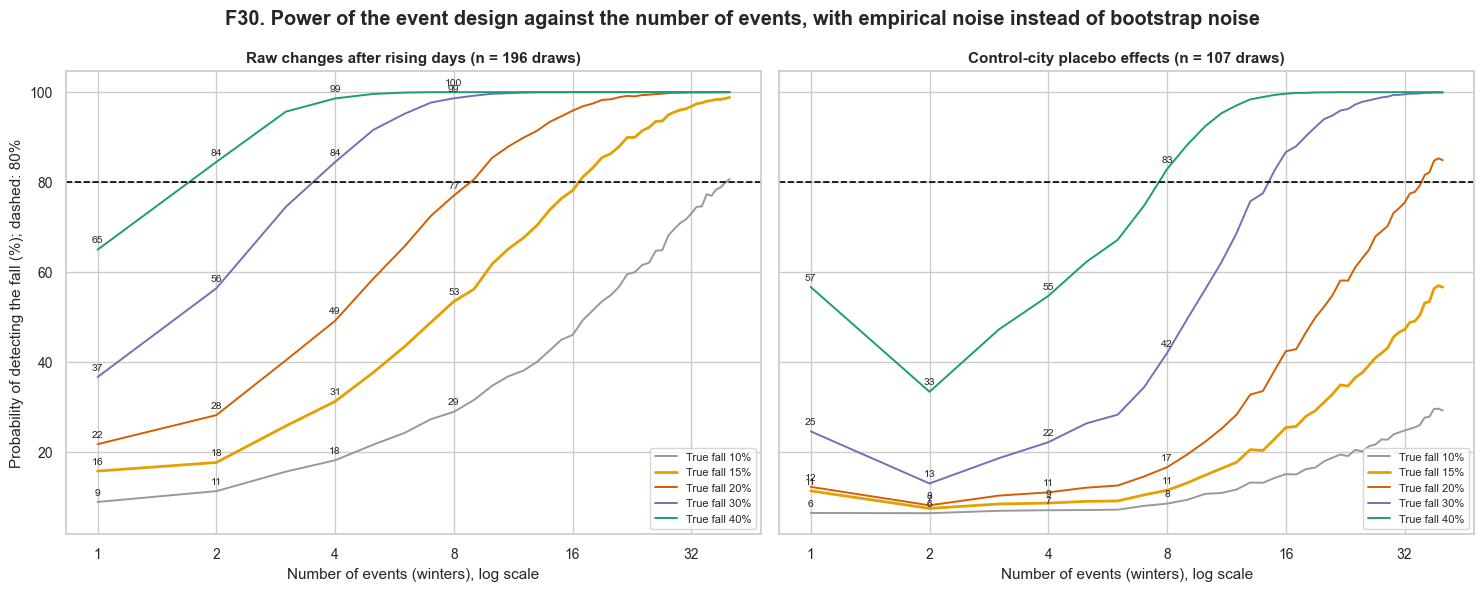

In [261]:
# Step 9B.8b: F30 power against the number of events for falls of 10, 15, 20, 30 and 40%; one panel per noise source; values written at 1, 2, 4 and 8 events
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, name in zip(axes, noise):
    for fall, colour in zip((0.10, 0.15, 0.20, 0.30, 0.40), ["#999999", "#E69F00", "#D55E00", "#7570B3", "#1B9E77"]):
        idx = int(round(fall * 100)) - 1; curve = [power_grid[name][k][idx] * 100 for k in range(1, KMAX + 1)]
        ax.plot(range(1, KMAX + 1), curve, color=colour, lw=2 if fall == 0.15 else 1.4, label=f"True fall {fall:.0%}")
        for k in (1, 2, 4, 8):
            ax.annotate(f"{curve[k - 1]:.0f}", (k, curve[k - 1]), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=7.5)
    ax.axhline(80, color="black", ls="--", lw=1.2); ax.set_xscale("log"); ax.set_xticks([1, 2, 4, 8, 16, 32]); ax.set_xticklabels([1, 2, 4, 8, 16, 32])
    ax.set_title(f"{name} (n = {len(noise[name])} draws)", fontsize=11); ax.set_xlabel("Number of events (winters), log scale"); ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("Probability of detecting the fall (%); dashed: 80%"); fig.suptitle("F30. Power of the event design against the number of events, with empirical noise instead of bootstrap noise", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F30_power_matched_noise"); plt.show()

In [262]:
# Step 9B.8c: takeaway text for the power analysis
first_name, second_name = list(noise)
rng_note = [np.random.default_rng(SEED + k).choice(noise[second_name], size=(DRAWS_P, k)).mean(axis=1) for k in (1, 2)]
tail_gap = [np.median(sims) - np.percentile(sims, 5) for sims in rng_note]                       # distance of the 5th percentile below the median, one and two events
power_dip = power_grid[second_name][2][39] < power_grid[second_name][1][39]
show_pct = lambda v: "more than 80%" if np.isnan(v) else f"{v * 100:.0f}%"
show_n = lambda v: f"more than {KMAX}" if np.isnan(v) else f"{int(v)}"
mde1 = power_table_b[(power_table_b["Events"] == 1)].set_index("Noise source")["Minimum detectable fall (80% power)"]
mde8 = power_table_b[(power_table_b["Events"] == 8)].set_index("Noise source")["Minimum detectable fall (80% power)"]
show_takeaway(
    f"**What we learn:** with the noise of {first_name.lower()} one event can detect a true fall of at least **{show_pct(mde1[first_name])}** with 80% power and eight events a fall of **{show_pct(mde8[first_name])}**; with the noise of {second_name.lower()} the figures are "
    f"**{show_pct(mde1[second_name])}** and **{show_pct(mde8[second_name])}**. To detect a **15%** fall with 80% power about **{show_n(needed[first_name])}** events (winters) are needed under the first noise and **{show_n(needed[second_name])}** under the second. "
    f"The bootstrap power of 9.11 gives **{mde.loc[primary_label] * 100:.0f}%** for the primary event; it is optimistic because it ignores the misfit of the model (the primary event failed the hold-out rule), so the empirical figure is the one to quote."
    + (f" With the second noise the power can fall from one event to two: the 5th percentile of the average of two draws lies **{tail_gap[1]:.2f}** log points below its median against **{tail_gap[0]:.2f}** for one draw, because only **{len(noise[second_name])}** uneven draws are available; read that panel as a rough guide." if power_dip else "")
)

**What we learn:** with the noise of raw changes after rising days one event can detect a true fall of at least **48%** with 80% power and eight events a fall of **21%**; with the noise of control-city placebo effects the figures are **52%** and **40%**. To detect a **15%** fall with 80% power about **17** events (winters) are needed under the first noise and **more than 40** under the second. The bootstrap power of 9.11 gives **30%** for the primary event; it is optimistic because it ignores the misfit of the model (the primary event failed the hold-out rule), so the empirical figure is the one to quote. With the second noise the power can fall from one event to two: the 5th percentile of the average of two draws lies **0.60** log points below its median against **0.46** for one draw, because only **107** uneven draws are available; read that panel as a rough guide.

*F30. Probability of detecting a true fall of 10, 15, 20, 30 and 40% against the number of events (log scale), using as noise the raw changes after rising days (left) or the control-city placebo effects (right); the dashed line is 80% power; power in per cent is written at 1, 2, 4 and 8 events. 20,000 simulations per point. Treated stations. Source: `final_dataset.parquet`.*

**What it shows.** That the design with one winter has little power for the size of effect that policies of this kind are expected to have, and how fast power grows with more events. This is the number to quote for what data would make H2 testable (Phase 11).

**What it does not show.** The noise sources are approximations (overlapping days, control cities different from the treated stations), events in the same winter are not independent, and the design assumes the same effect for every event. A different design (a comparison region with a longer record) could need fewer events.

## 9B.9 Answers to Q3 and Q4 in plain words

The two cells below put the frozen-run answer of Phase 9 next to what the extensions of 9B added. **The frozen criteria and the H2 status are unchanged**: on the frozen rules H2 cannot be called supported, and Phase 10 applies those rules to the frozen runs only. Every extension is listed in table `T07d2`. **No sentence here says that GRAP reduced PM2.5 by a given percentage.**

In [263]:
# Step 9B.9a: Q3: is PM2.5 lower after activation than the counterfactual predicts? (every number comes from a variable computed above)
prim_frozen = event_effects[primary_number][0]
did_prim = did_table.loc[[i for i in did_table.index if i.startswith(f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}")][0]]
show_takeaway(
    f"**Q3. After a GRAP stage is activated, is PM2.5 lower than the weather-and-fire model predicts?**\n\n"
    f"- **Frozen run (Phase 9):** for the primary event (11 Nov 2025) the model gives **{prim_frozen['effect_pct']:+.1f}%** over days 1 to 3 (interval {prim_frozen['ci_low_pct']:+.1f}% to {prim_frozen['ci_high_pct']:+.1f}%), but the counterfactual fails the hold-out rule (error **{event_fits[primary_number]['holdout_error']:.0%}**) and **{len(usable_events)}** of the fitted events are usable, so H2 cannot be called supported.\n"
    f"- **Why (9B.1):** **{diagnosis['Parameters'].iloc[0]:.0f}** parameters on **{diagnosis['Fit days'].min():.0f} to {diagnosis['Fit days'].max():.0f}** days, a run-up the model has not seen.\n"
    f"- **Alternatives (9B.2):** events passing the hold-out rule: " + ", ".join(f"{m.lower()} **{int(n_usable_by_method[m])}**" for m in METHODS) + f"; carried forward on accuracy alone: **{best_method.lower()}**.\n"
    f"- **Difference-in-differences (9B.3):** treated minus control over days 1 to 3 averages **{did_table.iloc[-1]['Days 1-3 (%)']:+.1f}%** over the events (primary event **{did_prim['Days 1-3 (%)']:+.1f}%**, placebo range for the pooled value {did_table.iloc[-1]['Placebo 2.5% (days 1-3)']:+.1f}% to {did_table.iloc[-1]['Placebo 97.5% (days 1-3)']:+.1f}%).\n"
    f"- **All upward activations (9B.4):** usable for **{len(paths_up)}** of **{len(up_changes)}** changes with {profile_method.lower()}."
)

**Q3. After a GRAP stage is activated, is PM2.5 lower than the weather-and-fire model predicts?**

- **Frozen run (Phase 9):** for the primary event (11 Nov 2025) the model gives **-21.7%** over days 1 to 3 (interval -39.8% to +1.3%), but the counterfactual fails the hold-out rule (error **90%**) and **0** of the fitted events are usable, so H2 cannot be called supported.
- **Why (9B.1):** **16** parameters on **26 to 48** days, a run-up the model has not seen.
- **Alternatives (9B.2):** events passing the hold-out rule: frozen **0**, (a) parsimonious weather **0**, (b) frozen with ridge **1**, (c) control cities **1**, (d) control cities + weather **0**; carried forward on accuracy alone: **(d) control cities + weather**.
- **Difference-in-differences (9B.3):** treated minus control over days 1 to 3 averages **+9.7%** over the events (primary event **+23.4%**, placebo range for the pooled value -25.6% to +33.8%).
- **All upward activations (9B.4):** usable for **1** of **14** changes with (b) frozen with ridge.

In [264]:
# Step 9B.9b: Q4: is the fall just mean reversion?
show_takeaway(
    f"**Q4. Is the fall just mean reversion?**\n\n"
    f"- **Spike days (9B.5):** after comparable days with no stage, PM2.5 fell on **{spike_summary['Broad share of days with a fall'] * 100:.0f}%** of **{int(broad.sum())}** broad spike days, median **{spike_summary['Broad median change (%)']:+.1f}%**; the primary event changed by **{pe['Raw change treated (%)']:+.1f}%**, a higher change than **{pe['Comparable days with a lower change'] * 100:.0f}%** of them (it fell less, or rose more, than most comparable days; control cities on the same date: **{pe['Raw change control, same date (%)']:+.1f}%**).\n"
    f"- **Mean-reversion regression (9B.6):** expected change for the primary event **{r_w['Expected from mean reversion (%)']:+.1f}%** (winter days) and **{r_a['Expected from mean reversion (%)']:+.1f}%** (all days); excess **{r_w['Excess (%)']:+.1f}%** [{r_w['CI low']:+.1f}, {r_w['CI high']:+.1f}] and **{r_a['Excess (%)']:+.1f}%** [{r_a['CI low']:+.1f}, {r_a['CI high']:+.1f}].\n"
    f"- **Control-city placebo (9B.7):** the method's effects on rising control dates range from **{control_null['Effect days 1-3 (%)'].quantile(0.05):+.1f}%** to **{control_null['Effect days 1-3 (%)'].quantile(0.95):+.1f}%** (5th to 95th percentile).\n"
    f"- **Power (9B.8):** one event detects a fall of at least **{show_pct(mde1[first_name])}** (first noise) or **{show_pct(mde1[second_name])}** (second noise); for a 15% fall about **{show_n(needed[first_name])}** and **{show_n(needed[second_name])}** events would be needed."
)
save_table(pd.DataFrame(extension_runs).set_index("Cell"), "T07d2_extension_runs")
print(len(extension_runs), "extension runs logged (Phases 8B and 9B), saved as T07d2")

**Q4. Is the fall just mean reversion?**

- **Spike days (9B.5):** after comparable days with no stage, PM2.5 fell on **76%** of **21** broad spike days, median **-9.8%**; the primary event changed by **+6.6%**, a higher change than **76%** of them (it fell less, or rose more, than most comparable days; control cities on the same date: **+3.3%**).
- **Mean-reversion regression (9B.6):** expected change for the primary event **-31.5%** (winter days) and **-25.9%** (all days); excess **+55.6%** [-11.5, +123.6] and **+43.8%** [-15.5, +142.9].
- **Control-city placebo (9B.7):** the method's effects on rising control dates range from **-35.1%** to **+123.4%** (5th to 95th percentile).
- **Power (9B.8):** one event detects a fall of at least **48%** (first noise) or **52%** (second noise); for a 15% fall about **17** and **more than 40** events would be needed.

saved table : T07d2_extension_runs
26 extension runs logged (Phases 8B and 9B), saved as T07d2


**What the extensions do not show.** None of them isolates an effect of GRAP: the events are few, they follow high or rising pollution, the control cities differ from the treated stations, and every extension was chosen after the first results. They cannot change the frozen status of H2 (inconclusive). They feed Phase 10 as a *supporting evidence* block (why the counterfactual failed, the alternatives, the difference-in-differences, the spike-day benchmark) and supply the KPI "3-day response after a stage change" for the completed KPI table, with its events and its interval. They also supply the power numbers for Phase 11: what data (how many events and what kind of comparison) would make H2 testable.

---
# Phase 10: Synthesis: robustness overview, hypothesis status, monitoring
*BADIR: **I**nsights and **R**ecommendations (the evidence is pulled together here; the recommendations are in Phase 11).* **No new model is fitted in 10.1 to 10.3.** The status of each hypothesis is assigned by applying the rules **frozen in Phase 7** to the saved results of Phases 8 and 9. The results of Phases 8B and 9B were added after seeing results; they are listed in a separate block of the status table as supporting or weakening evidence and **cannot change a status**. The phase ends with a monitoring check of the prediction model (10.4), the completed KPI table (10.5) and the final count of the runs tried (10.6).

## 10.1 Robustness overview (F15b)

**Question:** how many of the planned robustness runs agree with the primary result, and how strong is the agreement?
**Method:** the counted robustness runs of Phase 8 (H1, table T04g) and Phase 9 (H2, table T06e), split by what they show: for H1 whether the interval lies above zero; for H2 whether the counterfactual passed the hold-out rule. No new models.

In [265]:
# Step 10.1a: split the counted robustness runs of H1 and H2 into categories (all numbers from the tables of Phases 8 and 9)
h1_ci_above = robust_only["Same sign as primary"] & (robust_only["low"] > 0)
h1_cats = {"Same sign, interval above zero": int(h1_ci_above.sum()), "Same sign, interval includes zero": int((robust_only["Same sign as primary"] & ~h1_ci_above).sum()),
           "Opposite sign": int((~robust_only["Same sign as primary"]).sum())}
h2_usable_same = counted["Same sign as primary"] & counted["Fit usable"].astype(bool)
h2_cats = {"Same sign, usable fit": int(h2_usable_same.sum()), "Same sign, fit not usable": int((counted["Same sign as primary"] & ~h2_usable_same).sum()),
           "Opposite sign": int((~counted["Same sign as primary"]).sum())}
overview = pd.DataFrame({"H1 (fire and PM2.5)": h1_cats, "H2 (GRAP and PM2.5)": h2_cats}).T
overview["Runs counted"] = [len(robust_only), len(counted)]
display(overview); save_table(overview, "T10a_robustness_overview")
print(f"H1: {agree_text}; H2: {agree_h2} of {len(counted)}; frozen rule: at least {ROBUST_AGREE_SHARE:.0%}")

,"Same sign, interval above zero","Same sign, interval includes zero",Opposite sign,"Same sign, usable fit","Same sign, fit not usable",Runs counted
H1 (fire and PM2.5),16.0,4.0,0.0,NaN,NaN,20
H2 (GRAP and PM2.5),NaN,NaN,1.0,0.0,16.0,17


saved table : T10a_robustness_overview
H1: 20 of 20 (100%) including the placebo and the control-city run; 18 of 18 excluding them; H2: 16 of 17; frozen rule: at least 75%


saved figure: F15b_robustness_overview


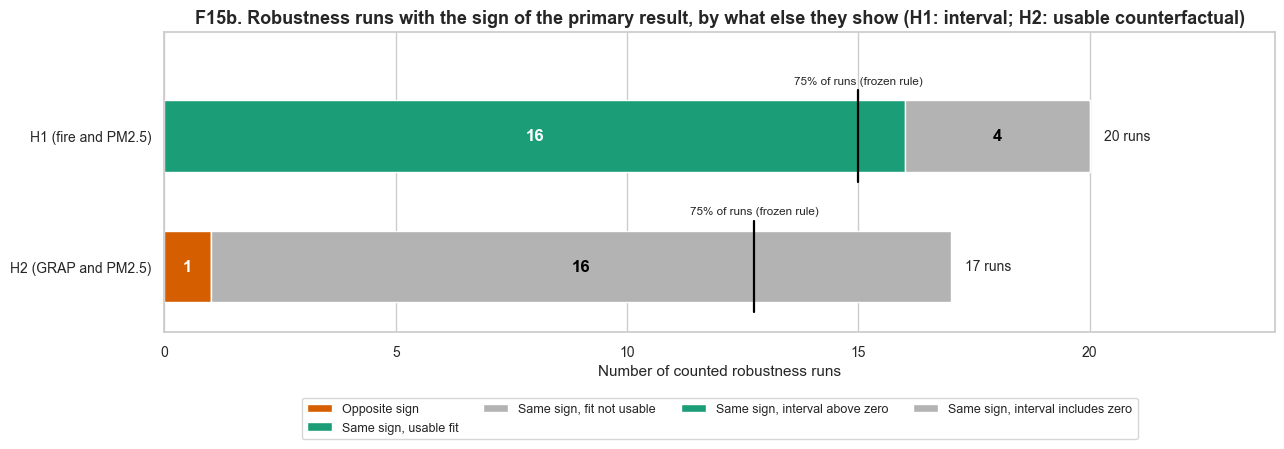

In [266]:
# Step 10.1b: F15b stacked bars of the counted runs, count written in each segment, total on the right; the frozen 75% line is drawn
fig, ax = plt.subplots(figsize=(13, 4.8))
colours = {"Same sign, interval above zero": "#1B9E77", "Same sign, usable fit": "#1B9E77", "Same sign, interval includes zero": "#B3B3B3", "Same sign, fit not usable": "#B3B3B3", "Opposite sign": "#D55E00"}
for y, (name, row) in enumerate(overview.iloc[::-1].iterrows()):
    left = 0
    for cat in [c for c in overview.columns if c != "Runs counted" and not pd.isna(row[c])]:
        ax.barh(y, row[cat], left=left, color=colours[cat], edgecolor="white", height=0.55, label=cat if cat not in ax.get_legend_handles_labels()[1] else None)
        if row[cat] > 0:
            ax.text(left + row[cat] / 2, y, f"{int(row[cat])}", ha="center", va="center", fontsize=12, color="white" if colours[cat] != "#B3B3B3" else "black", fontweight="bold")
        left += row[cat]
    ax.text(left + 0.3, y, f"{int(row['Runs counted'])} runs", va="center", fontsize=10)
    ax.plot([ROBUST_AGREE_SHARE * row["Runs counted"]] * 2, [y - 0.35, y + 0.35], color="black", lw=1.6)
    ax.text(ROBUST_AGREE_SHARE * row["Runs counted"], y + 0.4, f"{ROBUST_AGREE_SHARE:.0%} of runs (frozen rule)", ha="center", fontsize=8.5)
ax.set_ylim(-0.5, 1.8); ax.set_yticks(range(2)); ax.set_yticklabels(overview.index[::-1]); ax.set_xlabel("Number of counted robustness runs"); ax.set_xlim(0, max(overview["Runs counted"]) + 4); ax.grid(axis="y", visible=False)
ax.set_title("F15b. Robustness runs with the sign of the primary result, by what else they show (H1: interval; H2: usable counterfactual)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=9); plt.tight_layout(); save_fig(fig, "F15b_robustness_overview"); plt.show()

In [267]:
# Step 10.1c: takeaway text for the overview
h1_core = robust_only[~robust_only.index.str.startswith(("placebo", "control cities"))]; placebo_run = robust.loc["placebo: next day's fire (expected about zero)"]
show_takeaway(
    f"**What we learn:** for H1, the sign of the primary is shared by {agree_text}; **{h1_cats['Same sign, interval above zero']}** of the counted runs also have an interval above zero. "
    f"The placebo (next day's fire, which cannot cause today's PM2.5) gives **{placebo_run['effect']:+.1f}%** per SD, **{placebo_run['effect'] / robust.iloc[0]['effect']:.0%}** of the primary effect: a sign of seasonal confounding. "
    f"For H2, **{agree_h2} of {len(counted)}** counted runs have the sign of the primary, but **{h2_cats['Same sign, usable fit']}** of them have a counterfactual that passes the hold-out rule. "
    f"The frozen rule asks only for the sign (at least {ROBUST_AGREE_SHARE:.0%}), so both hypotheses meet it in form; for H2 the agreement carries almost no information."
)

**What we learn:** for H1, the sign of the primary is shared by 20 of 20 (100%) including the placebo and the control-city run; 18 of 18 excluding them; **16** of the counted runs also have an interval above zero. The placebo (next day's fire, which cannot cause today's PM2.5) gives **+4.0%** per SD, **41%** of the primary effect: a sign of seasonal confounding. For H2, **16 of 17** counted runs have the sign of the primary, but **0** of them have a counterfactual that passes the hold-out rule. The frozen rule asks only for the sign (at least 75%), so both hypotheses meet it in form; for H2 the agreement carries almost no information.

*F15b. Counted robustness runs of H1 (top, 20 runs of Phase 8) and H2 (bottom, runs of Phase 9) that have the sign of the primary result, split by whether the interval lies above zero (H1) or the counterfactual passes the hold-out rule (H2); opposite-sign runs in orange. The number of runs is written in each segment and on the right; the black line marks the frozen 75% of runs. Sources: tables T04g and T06e.*

**What it shows.** Agreement in sign across the planned runs. The runs reuse the same winter (H1) and the same few weeks around the same events (H2), so they are not independent checks.

**What it does not show.** That the effect is real: for H2 the runs that agree in sign nearly all rest on counterfactuals that fail the hold-out rule, so the agreement says almost nothing; for H1 the placebo and the control-city comparison are part of the runs and are discussed in Phase 8.

## 10.2 Hypothesis status (T7) and supporting evidence

**Question:** what status do the frozen rules give each hypothesis?
**Method:** the criteria tables of Phases 8 (H1, T04h) and 9 (H2, T06h) are stacked, one row per criterion with the rule, the observed value, whether it is met and the table it comes from. **Status rule (Phase 1, frozen):** *supported* when every criterion is met (for H2 including at least 3 usable events); *not supported* when the interval excludes 0 on the wrong side; *inconclusive* otherwise. The status text is generated from the table. A second block lists the **extension results of Phases 8B and 9B as supporting or weakening evidence, exploratory and not part of the decision**.

In [268]:
# Step 10.2a: the status table T7: one row per frozen criterion for H1 and H2; the status is computed from the table
h1_part = criteria.reset_index().rename(columns={"Criterion (frozen in Phase 7)": "Criterion"}).assign(Hypothesis="H1", Informative=True, Source=["T04b, T04h", "T04g", "T08"])
h2_part = criteria_h2.reset_index().rename(columns={"Criterion (frozen)": "Criterion"}).assign(Hypothesis="H2", Source=["T06b", "T06c", "T06e", "T06a"])
status_table = pd.concat([h1_part, h2_part], ignore_index=True)[["Hypothesis", "Criterion", "Observed", "Met", "Informative", "Source"]]
rmse_fire = scores.loc["Weather and fire", "RMSE"]                                    # criterion 3, informative only: the fire model against the stronger baselines (the status uses the frozen rows only)
extra = [("H1 (informative only)", f"Fire model has a lower test error than {name.lower()}", f"RMSE {rmse_fire:.1f} against {value:.1f} ug/m3", bool(rmse_fire < value), False, "T08f") for name, value in [("Persistence plus weather", scores_b.loc["Persistence + weather", "RMSE"]), ("Climatology", scores.loc["Climatology (month)", "RMSE"])]]
status_table = pd.concat([status_table, pd.DataFrame(extra, columns=status_table.columns)], ignore_index=True)
def assign_status(hypothesis, wrong_side):
    rows_h = status_table[status_table["Hypothesis"] == hypothesis]
    return "SUPPORTED" if rows_h["Met"].all() else ("NOT SUPPORTED" if wrong_side else "INCONCLUSIVE")
h1_wrong_side = bool(decision_high < 0)                                                      # H1: the decision interval lies entirely below zero
h2_wrong_side = bool(len(usable_events) >= 1 and pooled_table.loc[0, "CI low (%)"] > 0)       # H2: a pooled interval of usable events entirely above zero
status = {"H1": assign_status("H1", h1_wrong_side), "H2": assign_status("H2", h2_wrong_side)}
h1_label = "WEAKLY SUPPORTED (frozen rule met)" if status["H1"] == "SUPPORTED" else status["H1"]           # the label shown to the reader; the frozen label stays in the status table
display(status_table.set_index(["Hypothesis", "Criterion"])); save_table(status_table.set_index("Hypothesis"), "T10_hypothesis_status")
print("Status by the frozen rules:", status, "| criteria met: H1", int(status_table[status_table["Hypothesis"] == "H1"]["Met"].sum()), "of 3; H2", int(status_table[status_table["Hypothesis"] == "H2"]["Met"].sum()), "of 4")

Observed  ...      Source
Hypothesis            Criterion                                                                                              ...            
H1                    Primary effect above 0 with the decision interv...                                +9.5% [+1.4, +18.3]  ...  T04b, T04h
                      Same sign in at least 75% of robustness runs        20 of 20 (100%) including the placebo and the ...  ...        T04g
                      Fire model has a lower test error than the weat...  RMSE gain +0.91 ug/m3 [+0.37, +1.40]; both mod...  ...         T08
H2                    Pooled effect below 0 with the 95% interval exc...                   no usable event: nothing to pool  ...        T06b
                      Real events in the lowest 10% of their placebo ...  0% of 2 placebo dates are below the primary event  ...        T06c
                      Same sign in at least 75% of robustness runs                  16 of 17 (94%); no run has a usable fit  ...        T06e
                      At least 3 usable events                                                         0 usable of 5 events  ...        T06a
H1 (informative only) Fire model has a lower test error than persiste...                       RMSE 43.0 against 23.4 ug/m3  ...        T08f
                      Fire model has a lower test error than climatology                       RMSE 43.0 against 32.4 ug/m3  ...        T08f

[9 rows x 4 columns]

saved table : T10_hypothesis_status
Status by the frozen rules: {'H1': 'SUPPORTED', 'H2': 'INCONCLUSIVE'} | criteria met: H1 3 of 3; H2 2 of 4


In [269]:
# Step 10.2a2: the reported label of H1 under the status table, with the specifications from table T04n that give the reason
zero_t = inference_table.index[inference_table["Includes zero"] & ~inference_table.index.str.contains("frozen")].tolist(); lag_flat_t = bool(lag3_table.iloc[1]["Includes zero"] and lag3_table.iloc[2]["Includes zero"])
show_takeaway(f"Frozen label: {status['H1']}. Reported label: {h1_label}" + (f", because the interval includes zero under {', '.join(n.lower() for n in zero_t)}, and the lag profile is {'flat' if lag_flat_t else 'not flat'}." if zero_t and h1_label != status["H1"] else "."))

Frozen label: SUPPORTED. Reported label: WEAKLY SUPPORTED (frozen rule met), because the interval includes zero under iso-week clusters, date-block bootstrap, 7-day blocks, month effects (date clusters), date effects (date clusters), and the lag profile is flat.

In [270]:
# Step 10.2b: supporting evidence from Phases 8B and 9B for H1: one line per extension result; the verdict uses the sign and the interval only (no new threshold)
def verdict(supports, weakens, mixed=False):
    return "mixed" if mixed else ("supports" if supports else ("weakens" if weakens else "neutral"))
top_bin, date_row, dev_row, seas_row = dose_table.iloc[-1], ladder_table.iloc[-1], within_between.iloc[1], within_between.iloc[0]
y1, y2 = timing_table.iloc[0], timing_table.iloc[1]
gain_sig_pos, gain_sig_neg = int((cv_table["Gain CI low"] > 0).sum()), int((cv_table["Gain CI high"] < 0).sum())
fair = comparison_table.iloc[1]
h1_support = [
    ("8B.1 dose-response", f"effect for more than 10 detections {top_bin['Effect (%)']:+.1f}% [{top_bin['CI low']:+.1f}, {top_bin['CI high']:+.1f}]; straight-line test p = {quad_fit.pvalues[quad_name]:.2f}", "1", verdict(top_bin["CI low"] > 0, top_bin["CI high"] < 0)),
    ("8B.2 subgroups", f"positive in {int((het_table['Effect per +5 (%)'] > 0).sum())} of {len(het_table)} subgroups; interval above zero in {int((het_table['CI low'] > 0).sum())}", "1", verdict((het_table["Effect per +5 (%)"] > 0).all(), (het_table["Effect per +5 (%)"] < 0).any())),
    ("8B.3 season ladder", f"{ladder_table.iloc[1]['Effect per +5 (%)']:+.1f}% with month effects; {date_row['Effect per +5 (%)']:+.1f}% [{date_row['CI low']:+.1f}, {date_row['CI high']:+.1f}] with date effects", "1", verdict(date_row["CI low"] > 0, date_row["CI low"] <= 0)),
    ("8B.3 within and between", f"seasonal part {seas_row['Effect per +5 (%)']:+.1f}% [{seas_row['CI low']:+.1f}, {seas_row['CI high']:+.1f}]; day-to-day part {dev_row['Effect per +5 (%)']:+.1f}% [{dev_row['CI low']:+.1f}, {dev_row['CI high']:+.1f}]", "1", verdict(dev_row["CI low"] > 0, dev_row["CI low"] <= 0 and seas_row["CI low"] > 0)),
    ("8B.4 timing", f"yesterday {y1['Effect per +5 (%)']:+.1f}% [{y1['CI low']:+.1f}, {y1['CI high']:+.1f}]; day before {y2['Effect per +5 (%)']:+.1f}% [{y2['CI low']:+.1f}, {y2['CI high']:+.1f}]", "1", verdict(y1["CI low"] > 0 and y2["CI low"] <= 0, y1["CI low"] <= 0)),
    ("8B.6 variance share", f"fire adds {fire_share_beyond_weather['increment'] * 100:.2f} points of R-squared [{fire_share_beyond_weather['low'] * 100:.2f}, {fire_share_beyond_weather['high'] * 100:.2f}] beyond weather and stations", "3", verdict(fire_share_beyond_weather["low"] > 0, fire_share_beyond_weather["low"] <= 0)),
    ("8B.7 blocked cross-validation", f"fire lowers the error with an interval above zero in {gain_sig_pos} months and raises it with an interval below zero in {gain_sig_neg} of {len(cv_table)}", "3", verdict(gain_sig_pos > 0 and gain_sig_neg == 0, gain_sig_neg > 0 and gain_sig_pos == 0, mixed=gain_sig_pos > 0 and gain_sig_neg > 0)),
    ("8B.8 fairer baselines", f"fire on top of persistence plus weather: {fair['RMSE gain (ug/m3)']:+.2f} ug/m3 [{fair['CI low']:+.2f}, {fair['CI high']:+.2f}]", "3", verdict(fair["CI low"] > 0, fair["CI high"] < 0)),
    ("8B.8b winter-only prediction", f"fire gain with winter-only training and testing {season_table.iloc[2]['Gain from fire (ug/m3)']:+.2f} ug/m3 [{season_table.iloc[2]['CI low']:+.2f}, {season_table.iloc[2]['CI high']:+.2f}] on {int(season_table.iloc[2]['Test station-days']):,} station-days; with the fire x winter interaction {season_table.iloc[1]['Gain from fire (ug/m3)']:+.2f} [{season_table.iloc[1]['CI low']:+.2f}, {season_table.iloc[1]['CI high']:+.2f}]", "3", verdict(bool((season_table.iloc[1:]["CI low"] > 0).all()), bool((season_table.iloc[1:]["CI high"] < 0).all()))),
    ("8B.9 boosted model", f"fire gain {boost_gain[0]:+.2f} ug/m3 [{boost_gain[1]:+.2f}, {boost_gain[2]:+.2f}]", "3", verdict(boost_gain[1] > 0, boost_gain[2] < 0)),
]
support_h1 = pd.DataFrame(h1_support, columns=["Extension result", "Observed", "Bears on criterion", "Verdict"]).assign(Hypothesis="H1")
display(support_h1.drop(columns="Hypothesis"))

,Extension result,Observed,Bears on criterion,Verdict
0,8B.1 dose-response,effect for more than 10 detections +48.8% [+11...,1,supports
1,8B.2 subgroups,positive in 10 of 10 subgroups; interval above...,1,supports
2,8B.3 season ladder,"+5.5% with month effects; +1.7% [-1.2, +4.7] w...",1,weakens
3,8B.3 within and between,"seasonal part +45.0% [+26.2, +66.6]; day-to-da...",1,weakens
4,8B.4 timing,"yesterday +5.7% [+1.4, +10.2]; day before +0.3...",1,supports
5,8B.6 variance share,"fire adds 1.79 points of R-squared [0.01, 7.21...",3,supports
6,8B.7 blocked cross-validation,fire lowers the error with an interval above z...,3,mixed
7,8B.8 fairer baselines,fire on top of persistence plus weather: -0.09...,3,weakens
8,8B.8b winter-only prediction,fire gain with winter-only training and testin...,3,neutral
9,8B.9 boosted model,"fire gain +1.66 ug/m3 [-0.15, +3.38]",3,neutral


In [271]:
# Step 10.2c: supporting evidence for H2 (the verdict uses the sign, the interval and the frozen lower tail only)
did_pool, prim_label = did_table.iloc[-1], f"{changes.loc[primary_number, 'hour_ist']:%d %b %Y}"
sp, rv = spike_table.loc[prim_label], reversion[(reversion["Sample"] == "all days") & (reversion["Region"] == "Treated") & (reversion["Event"] == prim_label)].iloc[0]
cp, max_usable = control_placebo.loc[prim_label], int(n_usable_by_method.max())
h2_support = [
    ("9B.1 diagnosis", f"{len(usable_events)} of {len(plot_events)} fitted events pass the hold-out rule; {diagnosis['Parameters'].iloc[0]:.0f} parameters on {diagnosis['Fit days'].min():.0f} to {diagnosis['Fit days'].max():.0f} days", "4", verdict(False, len(usable_events) == 0)),
    ("9B.2 alternative counterfactuals", f"events passing the rule under the best alternative: {max_usable} of {len(plot_events)} (at least {MIN_EVENTS_FOR_SUPPORT} are needed)", "4", verdict(max_usable >= MIN_EVENTS_FOR_SUPPORT, False)),
    ("9B.3 difference-in-differences", f"treated minus control, days 1 to 3, averaged over the events: {did_pool['Days 1-3 (%)']:+.1f}% (placebo range {did_pool['Placebo 2.5% (days 1-3)']:+.1f}% to {did_pool['Placebo 97.5% (days 1-3)']:+.1f}%)", "1, 2", verdict(did_pool["Days 1-3 (%)"] < 0 and did_pool["Share of placebos below (days 1-3)"] <= LOWER_TAIL, did_pool["Days 1-3 (%)"] > 0)),
    ("9B.5 spike-day benchmark", f"primary event {sp['Raw change treated (%)']:+.1f}%; its change is higher than that of {sp['Comparable days with a lower change'] * 100:.0f}% of {int(sp['Comparable days (n)'])} comparable days", "2", verdict(sp["Comparable days with a lower change"] >= 1 - LOWER_TAIL, sp["Comparable days with a lower change"] <= LOWER_TAIL)),
    ("9B.6 mean-reversion regression", f"excess change of the primary event {rv['Excess (%)']:+.1f}% [{rv['CI low']:+.1f}, {rv['CI high']:+.1f}] (all days)", "1", verdict(rv["CI high"] < 0, rv["CI low"] > 0)),
    ("9B.7 control-city placebo", f"{cp['Share of control spike-date effects below'] * 100:.0f}% of the control-city effects of the same method are lower than the primary event's", "2", verdict(cp["Share of control spike-date effects below"] >= 1 - LOWER_TAIL, cp["Share of control spike-date effects below"] <= LOWER_TAIL)),
]
support_h2 = pd.DataFrame(h2_support, columns=["Extension result", "Observed", "Bears on criterion", "Verdict"]).assign(Hypothesis="H2")
display(support_h2.drop(columns="Hypothesis")); save_table(pd.concat([support_h1, support_h2]).set_index("Hypothesis"), "T10b_supporting_evidence")
verdict_counts = pd.concat([support_h1, support_h2]).groupby(["Hypothesis", "Verdict"]).size().unstack(fill_value=0).reindex(columns=["supports", "weakens", "mixed", "neutral"], fill_value=0)
display(verdict_counts)

,Extension result,Observed,Bears on criterion,Verdict
0,9B.1 diagnosis,0 of 4 fitted events pass the hold-out rule; 1...,4,weakens
1,9B.2 alternative counterfactuals,events passing the rule under the best alterna...,4,neutral
2,9B.3 difference-in-differences,"treated minus control, days 1 to 3, averaged o...","1, 2",weakens
3,9B.5 spike-day benchmark,primary event +6.6%; its change is higher than...,2,neutral
4,9B.6 mean-reversion regression,excess change of the primary event +43.8% [-15...,1,neutral
5,9B.7 control-city placebo,19% of the control-city effects of the same me...,2,neutral


saved table : T10b_supporting_evidence


Verdict,supports,weakens,mixed,neutral
Hypothesis,,,,
H1,4,3,1,2
H2,0,2,0,4


In [272]:
# Step 10.2d: takeaway text: the status from the frozen rules, and the supporting block, which never changes it
show_takeaway(
    f"**What we learn:** by the frozen rules **H1 is {h1_label}** ({int(status_table[status_table['Hypothesis'] == 'H1']['Met'].sum())} of 3 criteria met) and **H2 is {status['H2']}** "
    f"({int(status_table[status_table['Hypothesis'] == 'H2']['Met'].sum())} of 4 criteria met; the criteria that hold for H2 are not informative, and **{len(usable_events)}** usable events are available against the **{MIN_EVENTS_FOR_SUPPORT}** that are needed). "
    f"Of the {len(support_h1)} extension results for H1, **{int(verdict_counts.loc['H1', 'supports'])}** support, **{int(verdict_counts.loc['H1', 'weakens'])}** weaken, **{int(verdict_counts.loc['H1', 'mixed'])}** point both ways and **{int(verdict_counts.loc['H1', 'neutral'])}** cannot decide; "
    f"of the {len(support_h2)} for H2, **{int(verdict_counts.loc['H2', 'supports'])}** support, **{int(verdict_counts.loc['H2', 'weakens'])}** weaken, **{int(verdict_counts.loc['H2', 'mixed'])}** point both ways and **{int(verdict_counts.loc['H2', 'neutral'])}** cannot decide. **The extension block does not change either status.**"
)

**What we learn:** by the frozen rules **H1 is WEAKLY SUPPORTED (frozen rule met)** (3 of 3 criteria met) and **H2 is INCONCLUSIVE** (2 of 4 criteria met; the criteria that hold for H2 are not informative, and **0** usable events are available against the **3** that are needed). Of the 10 extension results for H1, **4** support, **3** weaken, **1** point both ways and **2** cannot decide; of the 6 for H2, **0** support, **2** weaken, **0** point both ways and **4** cannot decide. **The extension block does not change either status.**

**What it shows.** The status each hypothesis gets from rules written down before the results were seen, row by row, and how the extra analyses done afterwards line up with those criteria. A verdict of *supports* or *weakens* uses only the sign and the interval of the extension result (or the frozen 10% lower tail); *mixed* means that months or subgroups point both ways with intervals that exclude zero; *neutral* means the interval includes zero or the result cannot decide the criterion.

**What it does not show.** The frozen rules are deliberately simple: for H1 they ask for a sign, an interval and a test error against a weather-only model, and so they cannot see that the association is carried mostly by differences between months, that fire adds a small share beyond weather, or that the gain vanishes once yesterday's PM2.5 is allowed in. Those points are in the supporting block and in the wording of the status in 10.3. The supporting block is exploratory (chosen after seeing results) and cannot change a status.

## 10.3 Plain-language status and the four key questions

**Wording rule:** the hypotheses are *associated with* statements, never "caused". The paragraphs below are generated from the tables above, so every number is the one in the tables.

In [273]:
# Step 10.3a: plain-language status of H1 and H2 (the status from the frozen rules, then what the rules cannot see)
h1_met = int(status_table[status_table["Hypothesis"] == "H1"]["Met"].sum())
lag_flat = bool(lag3_table.iloc[1]["Includes zero"] and lag3_table.iloc[2]["Includes zero"])
weak_text = (f"supported by the frozen rule, but weak: the interval includes zero under {'; '.join(zero_specs)}, and the lag profile is {'flat' if lag_flat else 'not flat'}") if zero_specs else "supported by the frozen rule, and the interval excludes zero under every alternative way of building it"
show_takeaway(
    f"**H1: days after more upwind fire detections have higher PM2.5. Status: {h1_label}** ({h1_met} of 3 frozen criteria met): {weak_text}. The point estimate differs from the earlier pass and the reason is not confirmed. "
    f"Each +5 upwind detections is associated with **{primary_effect:+.1f}%** PM2.5 (decision interval {decision_low:+.1f}% to {decision_high:+.1f}%); robustness runs with the same sign as the primary: {agree_text}; the fire model beats the weather-only model on unseen days by {gain:+.2f} ug/m3 (both lose to simply repeating yesterday's value); the placebo run (next day's fire) gives {placebo_run['effect'] / robust.iloc[0]['effect']:.0%} of the primary effect, a sign of seasonal confounding. "
    f"**How far to trust it:** the evidence is weaker than the status suggests. The association is carried mostly by differences between months (the day-to-day part is {dev_row['Effect per +5 (%)']:+.1f}%, interval {dev_row['CI low']:+.1f}% to {dev_row['CI high']:+.1f}%; "
    f"with date effects {date_row['Effect per +5 (%)']:+.1f}%), fire adds {fire_share_beyond_weather['increment'] * 100:.1f} points of R-squared beyond weather, and once yesterday's PM2.5 is in the model, adding fire changes the test error by {fair['RMSE gain (ug/m3)']:+.2f} ug/m3 (a positive value is an improvement); **(added after seeing results)** on winter days only, the gain from fire is {season_table.iloc[2]['Gain from fire (ug/m3)']:+.2f} ug/m3 (interval {season_table.iloc[2]['CI low']:+.2f} to {season_table.iloc[2]['CI high']:+.2f}) on {int(season_table.iloc[2]['Test station-days']):,} test station-days of January and February, but those models are poor (RMSE about {season_table.iloc[2]['RMSE with fire']:.0f} ug/m3) "
    f"and the fire x winter interaction run on all seasons gives {season_table.iloc[1]['Gain from fire (ug/m3)']:+.2f} (interval {season_table.iloc[1]['CI low']:+.2f} to {season_table.iloc[1]['CI high']:+.2f}), which {'includes' if season_table.iloc[1]['CI low'] <= 0 <= season_table.iloc[1]['CI high'] else 'excludes'} zero. This is suggestive only and does not change the status. "
    f"It rests on one winter and fires within 100 km only, and it is an association, not a cause.\n\n"
    f"**H2: PM2.5 is lower after a GRAP stage is activated than the counterfactual predicts. Status by the frozen rules: {status['H2']}.** "
    f"Only **{len(primary_events)}** event meets the primary rule and **{len(usable_events)}** of {len(plot_events)} fitted events pass the hold-out rule, against the {MIN_EVENTS_FOR_SUPPORT} usable events that are needed. "
    f"The primary event's estimate ({event_effects[primary_number][0]['effect_pct']:+.1f}%, interval {event_effects[primary_number][0]['ci_low_pct']:+.1f}% to {event_effects[primary_number][0]['ci_high_pct']:+.1f}%) cannot be relied on. "
    f"**How far to trust it:** the data cannot answer the question: one event can only detect a fall of about {show_pct(mde1[first_name])} or more (empirical noise), and the extensions find no fall relative to the control cities ({did_pool['Days 1-3 (%)']:+.1f}% over days 1 to 3). *Inconclusive* here is mostly a statement about power."
)

**H1: days after more upwind fire detections have higher PM2.5. Status: WEAKLY SUPPORTED (frozen rule met)** (3 of 3 frozen criteria met): supported by the frozen rule, but weak: the interval includes zero under ISO-week clusters; Date-block bootstrap, 7-day blocks; Month effects (date clusters); Date effects (date clusters), and the lag profile is flat. The point estimate differs from the earlier pass and the reason is not confirmed. Each +5 upwind detections is associated with **+9.5%** PM2.5 (decision interval +1.4% to +18.3%); robustness runs with the same sign as the primary: 20 of 20 (100%) including the placebo and the control-city run; 18 of 18 excluding them; the fire model beats the weather-only model on unseen days by +0.91 ug/m3 (both lose to simply repeating yesterday's value); the placebo run (next day's fire) gives 41% of the primary effect, a sign of seasonal confounding. **How far to trust it:** the evidence is weaker than the status suggests. The association is carried mostly by differences between months (the day-to-day part is +3.4%, interval -2.8% to +10.1%; with date effects +1.7%), fire adds 1.8 points of R-squared beyond weather, and once yesterday's PM2.5 is in the model, adding fire changes the test error by -0.09 ug/m3 (a positive value is an improvement); **(added after seeing results)** on winter days only, the gain from fire is +5.43 ug/m3 (interval +0.84 to +10.10) on 1,341 test station-days of January and February, but those models are poor (RMSE about 99 ug/m3) and the fire x winter interaction run on all seasons gives +1.32 (interval -0.70 to +3.15), which includes zero. This is suggestive only and does not change the status. It rests on one winter and fires within 100 km only, and it is an association, not a cause.

**H2: PM2.5 is lower after a GRAP stage is activated than the counterfactual predicts. Status by the frozen rules: INCONCLUSIVE.** Only **1** event meets the primary rule and **0** of 4 fitted events pass the hold-out rule, against the 3 usable events that are needed. The primary event's estimate (-21.7%, interval -39.8% to +1.3%) cannot be relied on. **How far to trust it:** the data cannot answer the question: one event can only detect a fall of about 48% or more (empirical noise), and the extensions find no fall relative to the control cities (+9.7% over days 1 to 3). *Inconclusive* here is mostly a statement about power.

In [274]:
# Step 10.3b: the four key questions Q1 to Q4: the answer, how sure we are, the main caveat (numbers from the tables above)
show_takeaway(
    f"**Q1. How big is the association between upwind fires and PM2.5 once weather is controlled?** About **{primary_effect:+.1f}%** per +5 upwind detections (about {mean_pm_level * primary_effect / 100:+.0f} ug/m3 at the winter mean). "
    f"*How sure:* the interval is {decision_low:+.1f}% to {decision_high:+.1f}% and it falls from {primary_effect:+.1f}% to {ladder_table.iloc[1]['Effect per +5 (%)']:+.1f}% with month effects. *Caveat:* it is mostly a between-month association and one winter.\n\n"
    f"**Q2. How much do fires add beyond weather?** Little: **{fire_share_beyond_weather['increment'] * 100:.1f}** points of R-squared on top of {variance_table.iloc[1]['R-squared'] * 100:.0f}% from stations and weather, and **{gain:+.2f} ug/m3** (about {gain / scores.loc['Weather only', 'RMSE'] * 100:.0f}%) of test error. "
    f"*How sure:* the gain interval is {gain_low:+.2f} to {gain_high:+.2f}, but it is {fair['RMSE gain (ug/m3)']:+.2f} once yesterday's PM2.5 is in both models (negative: slightly worse). *Caveat:* the test period has no burning season.\n\n"
    f"**Q3. After activation, is PM2.5 lower than predicted?** The frozen model says {event_effects[primary_number][0]['effect_pct']:+.1f}% for the primary event, but it fails the hold-out rule (error {event_fits[primary_number]['holdout_error']:.0%}). "
    f"*How sure:* not at all; at most {max_usable} of {len(plot_events)} fitted events pass the hold-out rule under any alternative, and the control-city comparison shows {did_pool['Days 1-3 (%)']:+.1f}%. *Caveat:* no usable counterfactual and very few events.\n\n"
    f"**Q4. Is the fall just mean reversion?** It cannot be told apart: the primary event changed by {sp['Raw change treated (%)']:+.1f}% against a median of {sp['Median change on comparable days (%)']:+.1f}% on comparable days, and the excess beyond mean reversion is {rv['Excess (%)']:+.1f}% (interval {rv['CI low']:+.1f}% to {rv['CI high']:+.1f}%). "
    f"*How sure:* the intervals include zero. *Caveat:* stages are invoked on high and rising days, so a fall after activation is expected even without a stage."
)

**Q1. How big is the association between upwind fires and PM2.5 once weather is controlled?** About **+9.5%** per +5 upwind detections (about +15 ug/m3 at the winter mean). *How sure:* the interval is +1.4% to +18.3% and it falls from +9.5% to +5.5% with month effects. *Caveat:* it is mostly a between-month association and one winter.

**Q2. How much do fires add beyond weather?** Little: **1.8** points of R-squared on top of 45% from stations and weather, and **+0.91 ug/m3** (about 2%) of test error. *How sure:* the gain interval is +0.37 to +1.40, but it is -0.09 once yesterday's PM2.5 is in both models (negative: slightly worse). *Caveat:* the test period has no burning season.

**Q3. After activation, is PM2.5 lower than predicted?** The frozen model says -21.7% for the primary event, but it fails the hold-out rule (error 90%). *How sure:* not at all; at most 1 of 4 fitted events pass the hold-out rule under any alternative, and the control-city comparison shows +9.7%. *Caveat:* no usable counterfactual and very few events.

**Q4. Is the fall just mean reversion?** It cannot be told apart: the primary event changed by +6.6% against a median of -9.8% on comparable days, and the excess beyond mean reversion is +43.8% (interval -15.5% to +142.9%). *How sure:* the intervals include zero. *Caveat:* stages are invoked on high and rising days, so a fall after activation is expected even without a stage.

**What it shows.** The status each hypothesis gets from the rules fixed in advance, together with the reasons and the limits, in words that do not claim a cause. H1 meets all three frozen criteria, so the frozen status is *supported*; the paragraph says plainly where that evidence is thin. H2 cannot be supported on the frozen rules and is *inconclusive*.

**What it does not show.** The status is not a measure of the size of the effect or of its cause. The frozen status is not changed by anything in Phases 8B and 9B, and the plain-language paragraphs do not replace the tables: they only restate them.

## 10.4 Monitoring and drift of the prediction model (F16, T9)

**Question:** if the weather-and-fire model were used from month to month, when would the inputs or the error tell us that it needs attention?
**Unit and reference.** The inputs of all stations in a region move together, so the monitored unit is the **day** (the mean of the treated stations over every day with weather and fire data, whether or not PM2.5 was valid), up to 31 days per month. Each test month (Jan to Sep 2026) is compared with the **same calendar month and its two neighbours in the training period** (up to 31 Dec 2025; for January: December and February), so that the normal seasonal cycle is not mistaken for drift.
**Thresholds, written before the check is run.** An input-month is flagged when the **KS statistic** (largest gap between the two cumulative distributions) is at least **0.20 and also above the 5% critical value for the two sample sizes divided over the nine inputs** (a fixed 0.20 is below the sampling noise of about 30 days); the **PSI** (population stability index, 5 bins from the reference) is reported with a threshold of **0.25**, together with the 95th percentile of the largest PSI that two random samples of the same days give when nothing has changed. A month's error is flagged when its **RMSE is above 1.5 times the training RMSE** of the same model. *A first design, with station-days, one year of training data as the reference and a plain 0.20 and 0.25, flagged every month, because about 30 days cannot give a stable PSI or KS; the unit, the reference and the sampling-noise condition were changed before the final results, and the 1.5 for the error was not changed.*

In [275]:
# Step 10.4a: thresholds first; daily mean inputs of the treated stations; KS and PSI of every input in every test month against the reference days of the training period
KS_FLAG, PSI_FLAG, RMSE_FLAG, ALPHA = 0.20, 0.25, 1.5, 0.05
monitor_inputs = [FIRE] + CONTROLS.split(" + ")
def psi(reference, new, bins=5):
    reference, new = reference[~np.isnan(reference)], new[~np.isnan(new)]                       # a day without a value is left out
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    ref_share, new_share = (np.clip(np.histogram(x, edges)[0] / len(x), 1e-4, None) for x in (reference, new))
    return float(np.sum((new_share - ref_share) * np.log(new_share / ref_share)))
def ks_stat(reference, new):
    ref_s, new_s = np.sort(reference[~np.isnan(reference)]), np.sort(new[~np.isnan(new)]); grid = np.concatenate([ref_s, new_s])
    return float(np.max(np.abs(np.searchsorted(ref_s, grid, side="right") / len(ref_s) - np.searchsorted(new_s, grid, side="right") / len(new_s))))
def ks_critical(n_ref, n_new, alpha=ALPHA / len(monitor_inputs)):
    return float(np.sqrt(-0.5 * np.log(alpha / 2)) * np.sqrt((n_ref + n_new) / (n_ref * n_new)))     # two-sample KS critical value (asymptotic), alpha shared over the inputs
inputs_all = daily_weather[daily_weather["station_id"].isin(treated_ids)].merge(daily_fire[["station_id", "date_ist", FIRE]], on=["station_id", "date_ist"])
daily_inputs = inputs_all.groupby("date_ist")[monitor_inputs].mean()                       # every day with weather and fire data, whether or not PM2.5 was valid
daily_train, daily_test = daily_inputs[daily_inputs.index <= TRAIN_END], daily_inputs[daily_inputs.index >= TEST_START]
months = sorted(daily_test.index.strftime("%Y-%m").unique())
pool = {m: daily_train[daily_train.index.month.isin([(int(m[-2:]) + k - 1) % 12 + 1 for k in (-1, 0, 1)])] for m in months}        # same calendar month and its two neighbours
new_days = {m: daily_test[daily_test.index.strftime("%Y-%m") == m] for m in months}
ks_table = pd.DataFrame({m: {c: ks_stat(pool[m][c].to_numpy(), new_days[m][c].to_numpy()) for c in monitor_inputs} for m in months})
psi_table = pd.DataFrame({m: {c: psi(pool[m][c].to_numpy(), new_days[m][c].to_numpy()) for c in monitor_inputs} for m in months})
assert ks_stat(daily_train[FIRE].to_numpy(), daily_train[FIRE].to_numpy()) == 0, "a distribution must not drift from itself"
display(ks_table.round(2)); print("days in the reference and in the month:", {m: (len(pool[m]), len(new_days[m])) for m in months})

,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
n_up_nh_100km_45deg_lag1,0.32,0.25,0.40,0.19,0.29,0.25,0.07,0.13,0.16
wind_speed,0.21,0.30,0.17,0.14,0.33,0.10,0.17,0.16,0.12
wind_dir_sin,0.29,0.21,0.28,0.29,0.13,0.50,0.14,0.29,0.21
wind_dir_cos,0.31,0.14,0.25,0.33,0.19,0.29,0.13,0.12,0.29
t2m_c,0.55,0.58,0.42,0.17,0.24,0.42,0.27,0.33,0.20
rh_pct,0.40,0.63,0.56,0.25,0.21,0.51,0.17,0.15,0.15
blh_m,0.13,0.65,0.52,0.13,0.25,0.38,0.18,0.28,0.13
tp_mm,0.23,0.21,0.12,0.18,0.15,0.39,0.17,0.19,0.16
sp_hpa,0.48,0.42,0.27,0.21,0.26,0.33,0.34,0.35,0.40


days in the reference and in the month: {'2026-01': (41, 31), '2026-02': (41, 28), '2026-03': (71, 31), '2026-04': (92, 30), '2026-05': (91, 31), '2026-06': (92, 30), '2026-07': (92, 31), '2026-08': (92, 31), '2026-09': (92, 30)}


In [276]:
# Step 10.4b: the no-drift noise of the largest PSI (random samples of the same size from the reference days, 200 repetitions), the model error, and the monitoring table T9
rng_mon = np.random.default_rng(SEED)
def null_max_psi(m, reps=200):
    ref_days, k = pool[m], len(new_days[m]); vals = []
    for _ in range(reps):
        idx = rng_mon.permutation(len(ref_days)); a, b = ref_days.iloc[idx[k:]], ref_days.iloc[idx[:k]]
        vals.append(max(psi(a[c].to_numpy(), b[c].to_numpy()) for c in monitor_inputs))
    return float(np.percentile(vals, 95))
train_pred = fit_predict(train, train, WF_TERMS); reference_rmse = float(np.sqrt(np.mean((train["pm25_day"].to_numpy() - train_pred) ** 2)))
monitor = pd.DataFrame({"Reference days": {m: len(pool[m]) for m in months}, "Days": {m: len(new_days[m]) for m in months}, "Max KS": ks_table.max(), "Input with max KS": ks_table.idxmax(),
                        "KS flag level": {m: max(KS_FLAG, ks_critical(len(pool[m]), len(new_days[m]))) for m in months}, "Max PSI": psi_table.max(), "Max PSI with no drift (95th percentile)": {m: null_max_psi(m) for m in months},
                        "RMSE weather and fire (ug/m3)": monthly_rmse["RMSE weather and fire"], "RMSE persistence (ug/m3)": pd.Series(monthly_b["Persistence (yesterday)"].to_numpy(), index=monthly_rmse.index)})
monitor["RMSE / training RMSE"] = monitor["RMSE weather and fire (ug/m3)"] / reference_rmse
monitor["Input drift flag"] = monitor["Max KS"] >= monitor["KS flag level"]; monitor["Error flag"] = monitor["RMSE / training RMSE"] > RMSE_FLAG
display(monitor.round(2)); save_table(monitor.round(3), "T10c_monitoring"); print(f"Training RMSE of the model: {reference_rmse:.1f} ug/m3 | error threshold {RMSE_FLAG} x = {RMSE_FLAG * reference_rmse:.1f}")

,Reference days,Days,Max KS,Input with max KS,KS flag level,Max PSI,Max PSI with no drift (95th percentile),RMSE weather and fire (ug/m3),RMSE persistence (ug/m3),RMSE / training RMSE,Input drift flag,Error flag
2026-01,41,31,0.55,t2m_c,0.41,3.97,3.44,109.06,50.03,2.26,True,True
2026-02,41,28,0.65,blh_m,0.42,4.97,3.11,39.59,33.34,0.82,True,False
2026-03,71,31,0.56,rh_pct,0.37,3.75,1.80,33.56,25.95,0.69,True,False
2026-04,92,30,0.33,wind_dir_cos,0.36,0.61,1.82,42.81,26.13,0.89,False,False
2026-05,91,31,0.33,wind_speed,0.36,1.82,1.67,23.38,18.58,0.48,False,False
2026-06,92,30,0.51,rh_pct,0.36,3.31,1.78,18.58,16.70,0.38,True,False
2026-07,92,31,0.34,sp_hpa,0.36,1.92,1.75,16.17,16.25,0.33,False,False
2026-08,92,31,0.35,sp_hpa,0.36,3.50,1.73,13.67,10.00,0.28,False,False
2026-09,92,30,0.40,sp_hpa,0.36,2.69,1.80,24.49,15.95,0.51,True,False


saved table : T10c_monitoring
Training RMSE of the model: 48.3 ug/m3 | error threshold 1.5 x = 72.5


saved figure: F16_monitoring


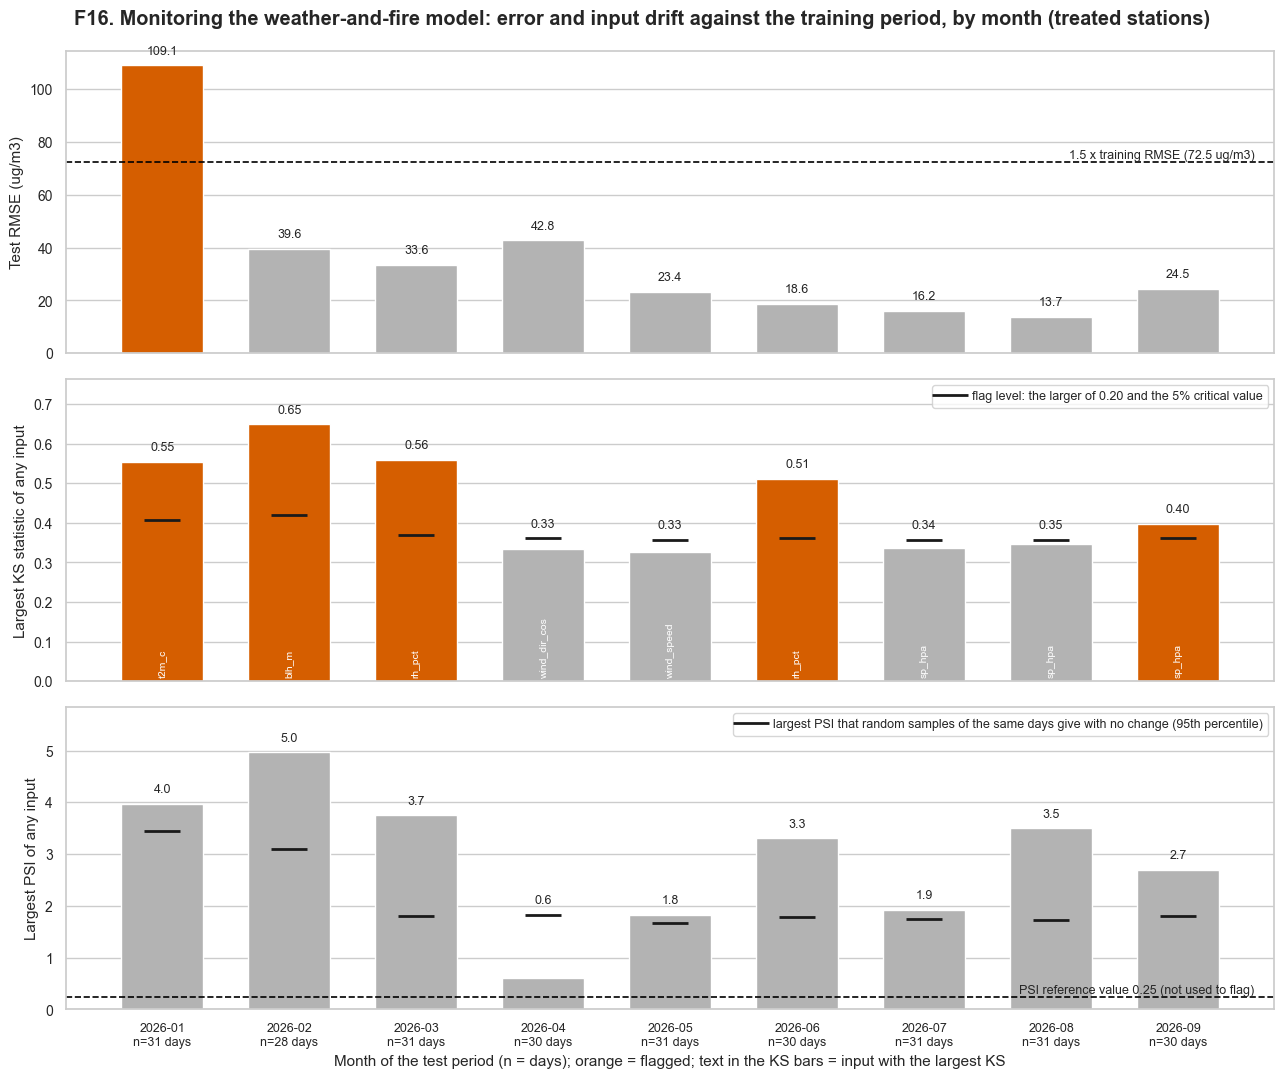

In [277]:
# Step 10.4c: F16 three panels by month: model error, largest KS, largest PSI; thresholds drawn and labelled, values written on the bars, flagged months orange
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True); x = np.arange(len(monitor)); name_of = lambda c: c.replace("n_up_nh_100km_45deg_lag1", "fire")
spec = [("RMSE weather and fire (ug/m3)", "Test RMSE (ug/m3)", "Error flag", "{:.1f}"), ("Max KS", "Largest KS statistic of any input", "Input drift flag", "{:.2f}"), ("Max PSI", "Largest PSI of any input", None, "{:.1f}")]
for ax, (col, ylabel, flag_col, fmt) in zip(axes, spec):
    bars = ax.bar(x, monitor[col], color=["#D55E00" if (flag_col and f) else "#B3B3B3" for f in (monitor[flag_col] if flag_col else [False] * len(monitor))], width=0.65)
    marker_level = {"Max KS": monitor["KS flag level"], "Max PSI": monitor["Max PSI with no drift (95th percentile)"]}.get(col, monitor[col])
    for b, v, ml in zip(bars, monitor[col], marker_level):
        ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, max(v, ml)), ha="center", va="bottom", fontsize=9, xytext=(0, 6), textcoords="offset points")
    ax.set_ylabel(ylabel); ax.grid(axis="x", visible=False)
axes[0].axhline(RMSE_FLAG * reference_rmse, color="black", ls="--", lw=1.2); axes[0].text(len(x) - 0.4, RMSE_FLAG * reference_rmse, f"{RMSE_FLAG} x training RMSE ({RMSE_FLAG * reference_rmse:.1f} ug/m3)", ha="right", va="bottom", fontsize=9)
axes[1].plot(x, monitor["KS flag level"], "k_", ms=26, mew=2, label="flag level: the larger of 0.20 and the 5% critical value"); axes[1].legend(loc="upper right", fontsize=9)
axes[2].plot(x, monitor["Max PSI with no drift (95th percentile)"], "k_", ms=26, mew=2, label="largest PSI that random samples of the same days give with no change (95th percentile)")
axes[2].axhline(PSI_FLAG, color="black", ls="--", lw=1.2); axes[2].text(len(x) - 0.4, PSI_FLAG, f"PSI reference value {PSI_FLAG} (not used to flag)", ha="right", va="bottom", fontsize=9); axes[2].legend(loc="upper right", fontsize=9)
for ax in axes[1:]:
    ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
for xi, c in enumerate(monitor["Input with max KS"]):
    axes[1].text(xi, 0.01, name_of(c), ha="center", va="bottom", fontsize=7.5, rotation=90, color="white")
axes[2].set_xticks(x); axes[2].set_xticklabels([f"{m}\nn={int(n)} days" for m, n in zip(monitor.index, monitor["Days"])], fontsize=9); axes[2].set_xlabel("Month of the test period (n = days); orange = flagged; text in the KS bars = input with the largest KS")
fig.suptitle("F16. Monitoring the weather-and-fire model: error and input drift against the training period, by month (treated stations)", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F16_monitoring"); plt.show()

In [278]:
# Step 10.4d: takeaway text for the monitoring check
worst = monitor["RMSE / training RMSE"].idxmax(); both = int((monitor["Input drift flag"] & monitor["Error flag"]).sum()); psi_noise = int((monitor["Max PSI"] > monitor["Max PSI with no drift (95th percentile)"]).sum())
show_takeaway(
    f"**What we learn:** the model's training RMSE is **{reference_rmse:.1f} ug/m3**. Its error is above {RMSE_FLAG} times that in **{int(monitor['Error flag'].sum())}** of **{len(monitor)}** test months (the worst is **{worst}** at **{monitor.loc[worst, 'RMSE weather and fire (ug/m3)']:.1f} ug/m3**, "
    f"**{monitor.loc[worst, 'RMSE / training RMSE']:.1f}** times). An input drifts beyond its flag level in **{int(monitor['Input drift flag'].sum())}** of {len(monitor)} months; **{both}** of them also {'has' if both == 1 else 'have'} the error flag. "
    f"In {worst} the input with the largest KS is **{name_of(monitor.loc[worst, 'Input with max KS'])}** (KS {monitor.loc[worst, 'Max KS']:.2f}, flag level {monitor.loc[worst, 'KS flag level']:.2f}). "
    f"The largest PSI is above the conventional {PSI_FLAG} in **{int((monitor['Max PSI'] >= PSI_FLAG).sum())}** of {len(monitor)} months and above what random samples of the same days give in **{psi_noise}**; even with no change at all the largest PSI reaches **{monitor['Max PSI with no drift (95th percentile)'].min():.1f} to {monitor['Max PSI with no drift (95th percentile)'].max():.1f}**, far above {PSI_FLAG}, "
    f"so with about 30 days per month a fixed PSI threshold would flag every month; it is shown for information and the KS flag level, which adapts to the number of days, is used to flag."
)

**What we learn:** the model's training RMSE is **48.3 ug/m3**. Its error is above 1.5 times that in **1** of **9** test months (the worst is **2026-01** at **109.1 ug/m3**, **2.3** times). An input drifts beyond its flag level in **5** of 9 months; **1** of them also has the error flag. In 2026-01 the input with the largest KS is **t2m_c** (KS 0.55, flag level 0.41). The largest PSI is above the conventional 0.25 in **9** of 9 months and above what random samples of the same days give in **8**; even with no change at all the largest PSI reaches **1.7 to 3.4**, far above 0.25, so with about 30 days per month a fixed PSI threshold would flag every month; it is shown for information and the KS flag level, which adapts to the number of days, is used to flag.

*F16. Top: RMSE of the weather-and-fire model in each month of the test period (ug/m3) with the error threshold (1.5 times its training RMSE). Middle: the largest KS statistic of any of the nine inputs against the reference days of the training period (same calendar month and its two neighbours), with each month's flag level (the larger of 0.20 and the 5% critical value shared over the inputs). Bottom: the largest PSI of any input with its no-drift level (95th percentile of random samples of the same days) and the conventional 0.25. Values are written on the bars, flagged months are orange, and the text inside the middle bars names the input with the largest KS. Treated stations, daily means; table T10c. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** Whether the inputs of the model move away from what it was trained on, and whether its error rises when they do. January 2026 was colder than any training month, which is the case where a monitor should raise a flag before the forecast is used.

**What it does not show.** With about 30 days per month a fixed PSI or KS threshold is dominated by sampling noise, which is why the KS flag level adapts to the number of days and the PSI is shown only for information. The reference is one year of data, so ordinary year-to-year differences will be flagged in the first years of operation. A flag is a reason to look, not proof that the model is wrong.

## 10.5 Complete the KPI table (T00_kpis)

**Question:** Phase 1 promised two model-based KPIs: the **3-day response of PM2.5 after a stage change** and the **share of variation explained by fire beyond weather**. What are they now?
**Method:** the 3-day response is the frozen estimate for the primary event (days 1 to 3, with its interval and the event count, **flagged as not reliable** because the counterfactual fails the hold-out rule); the share of variation is the increment of R-squared from the fire count after weather and stations (8B.6, an extension, with its interval). The table of Phase 1 is printed again with the two new rows.

In [279]:
# Step 10.5a: the two model-based KPIs added to the table of Phase 1 (values in the treated, winter column; the note gives the interval, the count and the caveat)
prim = event_effects[primary_number][0]
kpi_complete = kpi_table.assign(Note="")
kpi_complete["Treated (winter)"] = kpi_complete["Treated (winter)"].astype(object)
kpi_complete.loc["3-day response of PM2.5 after a stage change (%, primary event)", "Treated (winter)"] = f"n/a (not reliable: {len(usable_events)} usable events)"
kpi_complete.loc["3-day response of PM2.5 after a stage change (%, primary event)", "Note"] = (f"estimate for information {prim['effect_pct']:+.1f}%; {changes.loc[primary_number, 'hour_ist']:%d %b %Y}; 95% interval {prim['ci_low_pct']:+.1f}% to {prim['ci_high_pct']:+.1f}%; {len(primary_events)} primary event, "
                                                                                              f"{len(usable_events)} usable of {len(all_events)}; NOT RELIABLE: the counterfactual fails the hold-out rule (error {event_fits[primary_number]['holdout_error']:.0%})")
kpi_complete.loc["Share of variation explained by fire beyond weather (R-squared points)", "Treated (winter)"] = round(fire_share_beyond_weather["increment"] * 100, 2)
kpi_complete.loc["Share of variation explained by fire beyond weather (R-squared points)", "Note"] = (f"95% interval {fire_share_beyond_weather['low'] * 100:.2f} to {fire_share_beyond_weather['high'] * 100:.2f}; {fire_share_beyond_weather['partial'] * 100:.1f}% of the variation left by weather and stations "
                                                                                                       f"(extension 8B.6, {len(used):,} station-days)")
pd.set_option("display.max_colwidth", 140); display(kpi_complete.fillna("")); save_table(kpi_complete, "T00_kpis")

,Treated (full window),Control (full window),Treated (winter),Control (winter),Note
KPI,,,,,
Mean daily PM2.5 (ug/m3),78.9,47.3,163.4,65.1,
Days above 60 ug/m3 (count),258.0,149.0,122.0,87.0,
Days above 60 ug/m3 (% of valid days),47.6,27.4,94.6,66.9,
Valid group-days (count),542.0,544.0,129.0,130.0,
Hours with valid PM2.5 (% of station-hours),87.0,86.1,84.7,84.5,
Network-outage hours (count),928.0,928.0,424.0,424.0,
Hours at GRAP Stage III or IV (count),971.0,0.0,971.0,0.0,
"3-day response of PM2.5 after a stage change (%, primary event)",,,n/a (not reliable: 0 usable events),,"estimate for information -21.7%; 11 Nov 2025; 95% interval -39.8% to +1.3%; 1 primary event, 0 usable of 5; NOT RELIABLE: the counterfac..."
Share of variation explained by fire beyond weather (R-squared points),,,1.79,,"95% interval 0.01 to 7.21; 3.2% of the variation left by weather and stations (extension 8B.6, 4,757 station-days)"


saved table : T00_kpis


In [280]:
# Step 10.5b: takeaway text for the KPI table
show_takeaway(
    f"**What we learn:** the KPI table now has **{len(kpi_complete)}** rows. The 3-day response after the primary stage change is **{prim['effect_pct']:+.1f}%** (interval {prim['ci_low_pct']:+.1f}% to {prim['ci_high_pct']:+.1f}%) but **not reliable** "
    f"({len(usable_events)} usable events); fire explains **{fire_share_beyond_weather['increment'] * 100:.2f}** points of R-squared beyond weather and stations (interval {fire_share_beyond_weather['low'] * 100:.2f} to {fire_share_beyond_weather['high'] * 100:.2f})."
)

**What we learn:** the KPI table now has **9** rows. The 3-day response after the primary stage change is **-21.7%** (interval -39.8% to +1.3%) but **not reliable** (0 usable events); fire explains **1.79** points of R-squared beyond weather and stations (interval 0.01 to 7.21).

**What it shows.** All the KPIs promised in Phase 1 in one table, the two model-based ones with their intervals and the reason one of them cannot be used.

**What it does not show.** The 3-day response is a frozen-rule estimate that fails its own validity check, so it is reported for completeness and should not be quoted as an effect of GRAP. The variation share is in-sample and from one winter.

## 10.6 Final list of runs tried (T07d and T07d2)

**Question:** how many specifications were tried in total, and how many agree with the primary result?
**Method:** the planned runs of Phase 7 (T07d), the extension analyses of Phases 8B and 9B (T07d2) and the individual estimates they produced. For H1 an estimate *agrees* when it is positive (and *clearly* when its interval is above zero); for H2 when it is a fall (and *clearly* when its interval is below zero or, for the placebo-based extension, the event lies in the lowest 10% of the placebo distribution).

In [281]:
# Step 10.6a: count the planned runs and every estimate of the extensions, with the number that agree and the number that agree clearly
def tally(block, hypothesis, listed, estimates, agree, clear):
    return {"Block": block, "Hypothesis": hypothesis, "Runs or estimates": listed, "Counted by the frozen rule": estimates, "Agree with the hypothesis": agree, "Agree clearly": clear}
ext_h1 = [("Dose-response bins", dose_table.iloc[1:]["Effect (%)"], dose_table.iloc[1:]["CI low"]), ("Subgroups", het_table["Effect per +5 (%)"], het_table["CI low"]),
          ("Season ladder", ladder_table["Effect per +5 (%)"], ladder_table["CI low"]), ("Within and between", within_between["Effect per +5 (%)"], within_between["CI low"]), ("Timing terms", timing_table.iloc[:2]["Effect per +5 (%)"], timing_table.iloc[:2]["CI low"])]
tally_rows = [tally("Planned runs (T07d)", "H1", len(h1_runs), len(robust_only), int(robust_only["Same sign as primary"].sum()), int(h1_ci_above.sum())),
              tally("Planned runs (T07d)", "H2", len(h2_runs), len(counted), agree_h2, int((counted["Same sign as primary"] & (counted["CI high"] < 0)).sum()))]
tally_rows += [tally(f"Extension: {name}", "H1", len(v), 0, int((v > 0).sum()), int((lo > 0).sum())) for name, v, lo in ext_h1]
tr_rows = reversion[reversion["Region"] == "Treated"]
ext_h2 = [("Alternative counterfactuals", method_effects["Effect days 1-3 (%)"].dropna() < 0, method_effects["CI high"].dropna() < 0), ("Difference-in-differences events", did_table.iloc[:-1]["Days 1-3 (%)"] < 0, did_table.iloc[:-1]["Share of placebos below (days 1-3)"] <= LOWER_TAIL),
          ("Mean-reversion excess (treated)", tr_rows["Excess (%)"] < 0, tr_rows["CI high"] < 0)]
tally_rows += [tally(f"Extension: {name}", "H2", len(a), 0, int(a.sum()), int(b.sum())) for name, a, b in ext_h2]
tally_table = pd.DataFrame(tally_rows).set_index("Block")
display(tally_table); save_table(tally_table, "T10d_runs_tried")

,Hypothesis,Runs or estimates,Counted by the frozen rule,Agree with the hypothesis,Agree clearly
Block,,,,,
Planned runs (T07d),H1,21,20,20,16
Planned runs (T07d),H2,20,17,16,3
Extension: Dose-response bins,H1,4,0,4,1
Extension: Subgroups,H1,10,0,10,3
Extension: Season ladder,H1,4,0,4,2
Extension: Within and between,H1,2,0,2,1
Extension: Timing terms,H1,2,0,2,1
Extension: Alternative counterfactuals,H2,20,0,8,1
Extension: Difference-in-differences events,H2,5,0,2,0


saved table : T10d_runs_tried


In [282]:
# Step 10.6b: totals for the report: planned runs, extension analyses (T07d2) and individual estimates, and how many agree
ext_totals = tally_table[tally_table.index.str.startswith("Extension")].groupby("Hypothesis")[["Runs or estimates", "Agree with the hypothesis", "Agree clearly"]].sum()
planned_totals = tally_table[tally_table.index.str.startswith("Planned")].set_index("Hypothesis")
extension_table = pd.DataFrame(extension_runs).set_index("Cell"); save_table(extension_table, "T07d2_extension_runs")
show_takeaway(
    f"**What we learn:** **{len(runs)}** runs were planned in Phase 7 (H1: {len(h1_runs)}, H2: {len(h2_runs)}); **{len(extension_table)}** extension analyses were added after seeing results (table T07d2), producing **{int(ext_totals.loc['H1', 'Runs or estimates'])}** further H1 estimates and **{int(ext_totals.loc['H2', 'Runs or estimates'])}** H2 estimates. "
    f"H1: counted planned runs with the same sign: {agree_text}; and **{int(ext_totals.loc['H1', 'Agree with the hypothesis'])} of {int(ext_totals.loc['H1', 'Runs or estimates'])}** extension estimates are positive "
    f"(**{int(ext_totals.loc['H1', 'Agree clearly'])}** with an interval above zero). H2: **{int(planned_totals.loc['H2', 'Agree with the hypothesis'])} of {int(planned_totals.loc['H2', 'Counted by the frozen rule'])}** counted planned runs agree in sign, but **{int(planned_totals.loc['H2', 'Agree clearly'])}** clearly; "
    f"**{int(ext_totals.loc['H2', 'Agree with the hypothesis'])} of {int(ext_totals.loc['H2', 'Runs or estimates'])}** extension estimates show a fall, **{int(ext_totals.loc['H2', 'Agree clearly'])}** clearly. The runs share the same winter and the same events, so they are not independent."
)

saved table : T07d2_extension_runs


**What we learn:** **41** runs were planned in Phase 7 (H1: 21, H2: 20); **26** extension analyses were added after seeing results (table T07d2), producing **22** further H1 estimates and **35** H2 estimates. H1: counted planned runs with the same sign: 20 of 20 (100%) including the placebo and the control-city run; 18 of 18 excluding them; and **22 of 22** extension estimates are positive (**8** with an interval above zero). H2: **16 of 17** counted planned runs agree in sign, but **3** clearly; **12 of 35** extension estimates show a fall, **1** clearly. The runs share the same winter and the same events, so they are not independent.

**What it shows.** The full count of what was tried, so the report can say how many specifications were run and how many agree, separately for the planned runs and for the extensions chosen after seeing results.

**What it does not show.** The count is not a count of independent tests: most runs reuse the same data, and the extension analyses were chosen after the first results, so agreement among them cannot be read as additional confirmation. No correction for multiple comparisons is applied; the status of each hypothesis rests on the frozen criteria only.

---
# Phase 11: Recommendations and roadmap
*BADIR: **R**ecommendations.* **On this evidence CAQM should not change GRAP thresholds; it should collect order times and design a multi-winter test.** **Rule for this phase.** A recommendation is written only where the evidence supports an action. Where the evidence is **inconclusive** (H2) or **thin** (H1), the recommendation is to **collect specific data or run a specific trial**, not to change policy. Every recommendation is tied to one finding and its status, says what we are **not** claiming, names who would act, by when, how it would be measured and what data is needed. All numbers in this phase come from the tables of Phases 8 to 10. *Associated with* is used throughout; nothing here says that fires or GRAP *caused* a change in PM2.5.

## 11.1 What data would make H2 testable (from the power results of 9B.8)

**Question:** how many events, and what kind of design, would be needed to detect a modest fall after a GRAP activation?
**Method:** the power analysis of 9B.8 used empirical noise from comparable days without a stage and from the control cities. The table below restates it for the recommendations: the smallest fall that one event and eight events could detect with 80% power, and the number of events needed to detect a 15% fall, against the number of qualifying events that one winter gives.

In [283]:
# Step 11.1a: the data requirement for H2 from the power results (9B.8); every number from the tables above
events_per_winter = max(len(primary_events), 1)                                                          # qualifying events under the primary rule in the one winter we have
design_rows = []
for noise_name in noise:
    mde_k = power_table_b[power_table_b["Noise source"] == noise_name].set_index("Events")["Minimum detectable fall (80% power)"]
    need = needed[noise_name]
    design_rows.append({"Noise used": noise_name, "Smallest fall detected, 1 event": show_pct(mde_k[1]), "Smallest fall detected, 8 events": show_pct(mde_k[8]), "Events needed for a 15% fall": show_n(need),
                        "Winters needed at the current rate": show_n(need / events_per_winter) if not np.isnan(need) else show_n(np.nan)})
h2_design = pd.DataFrame(design_rows).set_index("Noise used")
display(h2_design); save_table(h2_design, "T11a_h2_data_requirement")
show_takeaway(
    f"**What we learn:** with the noise of {first_name.lower()}, one event detects a fall of at least **{show_pct(mde1[first_name])}** and eight events **{show_pct(mde8[first_name])}**; about **{show_n(needed[first_name])}** events are needed for a 15% fall. "
    f"One winter gives **{events_per_winter}** qualifying event (and **{len(usable_events)}** with a usable counterfactual), so at the current rate that is about **{show_n(needed[first_name] / events_per_winter)}** winters. "
    f"H2 therefore cannot be tested with one city and one season: it needs a design that creates **many comparable events**, such as several cities with staggered activation dates, or a paired comparison region with its own record."
)

,"Smallest fall detected, 1 event","Smallest fall detected, 8 events",Events needed for a 15% fall,Winters needed at the current rate
Noise used,,,,
Raw changes after rising days,48%,21%,17,17
Control-city placebo effects,52%,40%,more than 40,more than 40


saved table : T11a_h2_data_requirement


**What we learn:** with the noise of raw changes after rising days, one event detects a fall of at least **48%** and eight events **21%**; about **17** events are needed for a 15% fall. One winter gives **1** qualifying event (and **0** with a usable counterfactual), so at the current rate that is about **17** winters. H2 therefore cannot be tested with one city and one season: it needs a design that creates **many comparable events**, such as several cities with staggered activation dates, or a paired comparison region with its own record.

**What it shows.** The size of the gap between what the data can answer and what the question needs, in events and in winters.

**What it does not show.** The numbers rest on approximate noise (overlapping days, control cities that differ from the treated stations) and assume the same effect for every event; they are orders of magnitude, not a trial design. A properly planned design would need its own power calculation.

## 11.2 Recommendations (T8)

The recommendations below are each tied to one finding. The *evidence status* says whether the finding is a frozen-rule result, an exploratory extension, or a data gap; *proposed* targets are suggestions for discussion, not results.

In [284]:
# Step 11.2a: the recommendations table T8 (all numbers come from variables computed in Phases 8 to 10)
kpi_w = kpi_table["Treated (winter)"]
pers_train_pred = fit_predict(frozen_train, frozen_train, WY_TERMS)                           # the advisory is persistence plus weather, so its own training error sets the alarm level
pers_ref_rmse = float(np.sqrt(np.mean((frozen_train["pm25_day"].to_numpy() - pers_train_pred) ** 2))); pers_alarm = RMSE_FLAG * pers_ref_rmse
pers_monthly = monthly_b["Persistence + weather"]; pers_flagged = pers_monthly.index[pers_monthly > pers_alarm].tolist(); jan_pers = float(pers_monthly.loc["2026-01"])
diw_n = int(changes.index[changes["hour_ist"].dt.strftime("%Y-%m-%d") == "2025-10-19"][0]); r200 = robust.loc["all-direction count, 200 km"]; jan_mon = monitor.loc["2026-01"]
rec = [
 ("1. Record the exact time of every GRAP order", f"H2 is {status['H2']}: the hour of the stage change is uncertain for {n_uncertain} of {len(changes)} changes and 'assumed' for {sources.get('assumed', 0)}; the 12-hour buffer is needed because of it (data gap)",
  "that GRAP does or does not lower PM2.5", "Publish the date and hour of each invocation and revocation with the order; keep one machine-readable log", "CAQM", "this winter (2026-27)",
  "share of stage changes with a documented hour; proposed target 100%", "order timestamps and the stage in force by hour"),
 ("2. Build a design that can test H2", f"one event can only detect a fall of at least {show_pct(mde1[first_name])}; about {show_n(needed[first_name])} events are needed for a 15% fall, against {events_per_winter} qualifying event per winter (frozen result: H2 {status['H2']})",
  "that a modest effect of GRAP is absent", "Do not draw policy conclusions about GRAP from one city and one winter; extend over several winters and add a paired or staggered comparison (several cities, or stations outside the NCR with their own record)", "CAQM with state boards and an academic partner", "design before winter 2027-28; collect over 2027-28 and 2028-29",
  f"number of events with a usable counterfactual (hold-out error at most {FIT_MAX_ERROR:.0%}); proposed target at least {MIN_EVENTS_FOR_SUPPORT}, then the number in T11a", "PM2.5, weather and stage by hour for the comparison cities for several winters"),
 ("3. Put monitors and smoke estimates where the fires are", f"H1 is {h1_label}: the association is mostly between months (day-to-day part {dev_row['Effect per +5 (%)']:+.1f}%, interval {dev_row['CI low']:+.1f}% to {dev_row['CI high']:+.1f}%) and fire adds {fire_share_beyond_weather['increment'] * 100:.1f} points of R-squared beyond weather; the stations are in Delhi-NCR, Patna, Lucknow and Kanpur, none in the main burning districts of Punjab and Haryana (exploratory extension)",
  "that fires cause a given share of Delhi's PM2.5, or anything about a single state", "Add PM2.5 monitors in the main burning districts and use fire radiative power or smoke estimates, not counts alone, before setting fire-season targets", "state pollution control boards", "monitors before winter 2027-28",
  "number of PM2.5 stations in the burning districts; proposed target: at least one per district with frequent fires", "PM2.5 near the fires, fire radiative power, several burning seasons"),
 ("4. Keep stations reporting through outages", f"the winter sample has {int(kpi_w['Network-outage hours (count)'])} network-outage hours and {kpi_w['Hours with valid PM2.5 (% of station-hours)']:.1f}% valid station-hours; up to {int(event_table['outage_hours_within_7_days'].max())} outage hours fall within 7 days of one stage change (data gap)",
  "that the air was clean while stations were silent", "Treat outage hours as a reported KPI and fix the networks that drop out in the burning season", "CAQM with state boards", "this winter (2026-27)",
  f"share of valid station-hours from October to February; proposed target at least 90% (now {kpi_w['Hours with valid PM2.5 (% of station-hours)']:.1f}%)", "outage log by station and hour"),
 ("5. Use a simple persistence-based advisory, and monitor it", f"on unseen days, yesterday's PM2.5 plus weather gives an RMSE of {scores_b.loc['Persistence + weather', 'RMSE']:.1f} ug/m3 against {scores.loc['Weather only', 'RMSE']:.1f} for weather only and {scores.loc['Weather and fire', 'RMSE']:.1f} with fire; {kpi_w['Days above 60 ug/m3 (% of valid days)']:.0f}% of winter days are above 60 ug/m3 (exploratory extension)",
  "that this is a validated forecast: it rests on one winter and misses cold extremes", "Base next-day advisories on yesterday's level and weather, re-check the error every month against the drift flags of F16", "city health departments", "pilot this winter (2026-27), review before winter 2027-28",
  f"monthly RMSE of the persistence-plus-weather model against {RMSE_FLAG} times its own training RMSE ({pers_ref_rmse:.1f} ug/m3), an alarm level of {pers_alarm:.0f} ug/m3; January 2026 ({jan_pers:.0f} ug/m3) {'would' if jan_pers > pers_alarm else 'would not'} be flagged"
  f"{' (months above it: ' + ', '.join(pers_flagged) + ')' if pers_flagged else ''}; proposed: no unflagged month", "daily PM2.5 by city and the weather forecast"),
]

In [285]:
# Step 11.2a2: recommendations 6 to 8 (the Diwali week, the cold spell, fires out to 200 km) and the table T8
rec += [
 ("6. Treat the Diwali week as its own high-risk window", f"the activation of {changes.loc[diw_n, 'hour_ist']:%d %b %Y} (Stage {changes.loc[diw_n, 'stage_before']} to {changes.loc[diw_n, 'stage_after']}, in the days before Diwali) shows {event_effects[diw_n][0]['effect_pct']:+.0f}% against its counterfactual and the control cities show {control_effect[diw_n][0]:+.0f}% on the same date, so the rise is shared and is not a result of the stage; "
  f"with the festival periods controlled the fire association is {fest_effect['effect']:+.1f}% per +5 detections against {primary_effect:+.1f}% without (exploratory extension)", "that fireworks, or the stage, explain the rise", "Plan advisories and enforcement for the Diwali week separately from other activations, and do not read a rise in that week as a failure of a stage", "CAQM with city health departments", "before Diwali 2027",
  "PM2.5 in the festival window against the weeks around it, reported every year", "festival dates, hourly PM2.5, firework rules and their enforcement"),
 ("7. Add a cold-spell early warning", f"in January 2026 the weather-and-fire model's error was {jan_mon['RMSE / training RMSE']:.1f} times its training RMSE and the input with the largest drift was {jan_mon['Input with max KS'].replace('t2m_c', 'temperature')} (KS {jan_mon['Max KS']:.2f}); the model had not seen weather that cold (monitoring result)",
  "that the model is wrong in normal weather", "When the monthly mean temperature leaves the range of the training period, treat model forecasts as unreliable and rely on the latest observed level", "city health departments with CAQM", "this winter (2026-27)",
  "months flagged by the temperature drift test before the error rises; proposed: every cold spell flagged", "temperature forecasts and observed PM2.5"),
 ("8. Monitor fires out to 200 km, not only 100 km upwind", f"the all-direction count within 200 km is associated with {r200['effect']:+.1f}% per SD (interval {r200['low']:+.1f}% to {r200['high']:+.1f}%) against {primary_run['effect']:+.1f}% for the upwind 100 km count (exploratory extension)",
  "that fires beyond 200 km, or in a given state, explain Delhi's PM2.5", "Include fire counts out to 200 km in fire-season monitoring and in the monitors proposed in recommendation 3", "state pollution control boards", "before winter 2027-28",
  "daily 200 km counts available for every station; proposed: complete", "satellite fire detections and station wind"),
]
t8 = pd.DataFrame(rec, columns=["Recommendation", "Finding it rests on and its status", "What we are not claiming", "Action", "Responsible stakeholder", "Timeline", "Indicator and target", "Data needed"]).set_index("Recommendation")
pd.set_option("display.max_colwidth", 90); display(t8[["Responsible stakeholder", "Timeline", "Indicator and target"]]); save_table(t8, "T08_recommendations")

,Responsible stakeholder,Timeline,Indicator and target
Recommendation,,,
1. Record the exact time of every GRAP order,CAQM,this winter (2026-27),share of stage changes with a documented hour; proposed target 100%
2. Build a design that can test H2,CAQM with state boards and an academic partner,design before winter 2027-28; collect over 2027-28 and 2028-29,number of events with a usable counterfactual (hold-out error at most 25%); proposed t...
3. Put monitors and smoke estimates where the fires are,state pollution control boards,monitors before winter 2027-28,number of PM2.5 stations in the burning districts; proposed target: at least one per d...
4. Keep stations reporting through outages,CAQM with state boards,this winter (2026-27),share of valid station-hours from October to February; proposed target at least 90% (n...
"5. Use a simple persistence-based advisory, and monitor it",city health departments,"pilot this winter (2026-27), review before winter 2027-28",monthly RMSE of the persistence-plus-weather model against 1.5 times its own training ...
6. Treat the Diwali week as its own high-risk window,CAQM with city health departments,before Diwali 2027,"PM2.5 in the festival window against the weeks around it, reported every year"
7. Add a cold-spell early warning,city health departments with CAQM,this winter (2026-27),months flagged by the temperature drift test before the error rises; proposed: every c...
"8. Monitor fires out to 200 km, not only 100 km upwind",state pollution control boards,before winter 2027-28,daily 200 km counts available for every station; proposed: complete


saved table : T08_recommendations


In [286]:
# Step 11.2b: takeaway text for the recommendations
show_takeaway(
    f"**What we learn:** **{len(t8)}** recommendations, of which **{int(t8['Finding it rests on and its status'].str.contains('data gap').sum())}** rest on data gaps, **{int(t8['Finding it rests on and its status'].str.contains('exploratory').sum())}** on exploratory extensions and none on a frozen result that supports a policy change: "
    f"H1 is {h1_label}, and H2 is {status['H2']}, so the actions ask for **data and a design** (recommendations 1, 2, 3, 4 and 8), a **low-risk advisory pilot with its own monitoring** (recommendation 5) and **specific warnings** for the Diwali week and for cold spells (recommendations 6 and 7)."
)

**What we learn:** **8** recommendations, of which **2** rest on data gaps, **4** on exploratory extensions and none on a frozen result that supports a policy change: H1 is WEAKLY SUPPORTED (frozen rule met), and H2 is INCONCLUSIVE, so the actions ask for **data and a design** (recommendations 1, 2, 3, 4 and 8), a **low-risk advisory pilot with its own monitoring** (recommendation 5) and **specific warnings** for the Diwali week and for cold spells (recommendations 6 and 7).

**What it shows.** What each stakeholder could do on the strength of what was found, and what each action would need. Recommendations 1 to 4 and 8 ask for data or a design because the evidence is inconclusive or thin; recommendations 5, 6 and 7 are pilots and warnings that can be monitored and withdrawn.

**What it does not show.** The table is a set of proposals: the targets are suggested, not derived, and the actions have costs that this data cannot measure (the cost of restrictions, compliance, health outcomes). No recommendation changes the status of a hypothesis. Nothing here says that GRAP works or does not work.

## 11.3 Roadmap (F31)

The recommendations on a time axis, with the responsible stakeholder and the indicator written on each bar. Dates are proposals counted from the start of winter 2026-27.

In [287]:
# Step 11.3a: the roadmap: (recommendation, start, end, stakeholder, indicator label); dates are proposals for discussion
import matplotlib.dates as mdates
road = [("1. Record GRAP order times", "2026-11-01", "2027-03-31", "CAQM", "% of changes with a documented hour: target 100%"),
        ("4. Keep stations reporting through outages", "2026-11-01", "2027-03-31", "CAQM with state boards", "valid station-hours Oct to Feb: target at least 90%"),
        ("5. Persistence-based advisory pilot and monitoring", "2026-11-01", "2027-09-30", "City health departments", f"monthly RMSE below {RMSE_FLAG} x its training RMSE ({pers_alarm:.0f} ug/m3)"),
        ("3. Monitors and smoke estimates in burning districts", "2027-01-01", "2027-09-30", "State pollution control boards", "stations in burning districts"),
        ("2. Design of a testable H2 study", "2027-01-01", "2027-09-30", "CAQM with state boards and an academic partner", "design agreed; events per winter"),
        ("2. Collection over several winters", "2027-10-01", "2029-03-31", "CAQM with state boards and an academic partner", f"usable events: at least {MIN_EVENTS_FOR_SUPPORT}, then {show_n(needed[first_name])}"),
        ("6. Diwali-week plan", "2027-07-01", "2027-10-31", "CAQM with city health departments", "festival-window PM2.5 reported every year"),
        ("7. Cold-spell early warning", "2026-11-01", "2027-02-28", "City health departments", "cold spells flagged before the error rises"),
        ("8. Fire monitoring out to 200 km", "2027-01-01", "2027-09-30", "State pollution control boards", "daily 200 km counts at every station")]
roadmap = pd.DataFrame(road, columns=["Action", "Start", "End", "Stakeholder", "Indicator"]).assign(Start=lambda d: pd.to_datetime(d["Start"]), End=lambda d: pd.to_datetime(d["End"]))
display(roadmap); save_table(roadmap.set_index("Action"), "T11b_roadmap")

,Action,Start,End,Stakeholder,Indicator
0,1. Record GRAP order times,2026-11-01,2027-03-31,CAQM,% of changes with a documented hour: target 100%
1,4. Keep stations reporting through outages,2026-11-01,2027-03-31,CAQM with state boards,valid station-hours Oct to Feb: target at least 90%
2,5. Persistence-based advisory pilot and monitoring,2026-11-01,2027-09-30,City health departments,monthly RMSE below 1.5 x its training RMSE (45 ug/m3)
3,3. Monitors and smoke estimates in burning districts,2027-01-01,2027-09-30,State pollution control boards,stations in burning districts
4,2. Design of a testable H2 study,2027-01-01,2027-09-30,CAQM with state boards and an academic partner,design agreed; events per winter
5,2. Collection over several winters,2027-10-01,2029-03-31,CAQM with state boards and an academic partner,"usable events: at least 3, then 17"
6,6. Diwali-week plan,2027-07-01,2027-10-31,CAQM with city health departments,festival-window PM2.5 reported every year
7,7. Cold-spell early warning,2026-11-01,2027-02-28,City health departments,cold spells flagged before the error rises
8,8. Fire monitoring out to 200 km,2027-01-01,2027-09-30,State pollution control boards,daily 200 km counts at every station


saved table : T11b_roadmap


saved figure: F31_roadmap


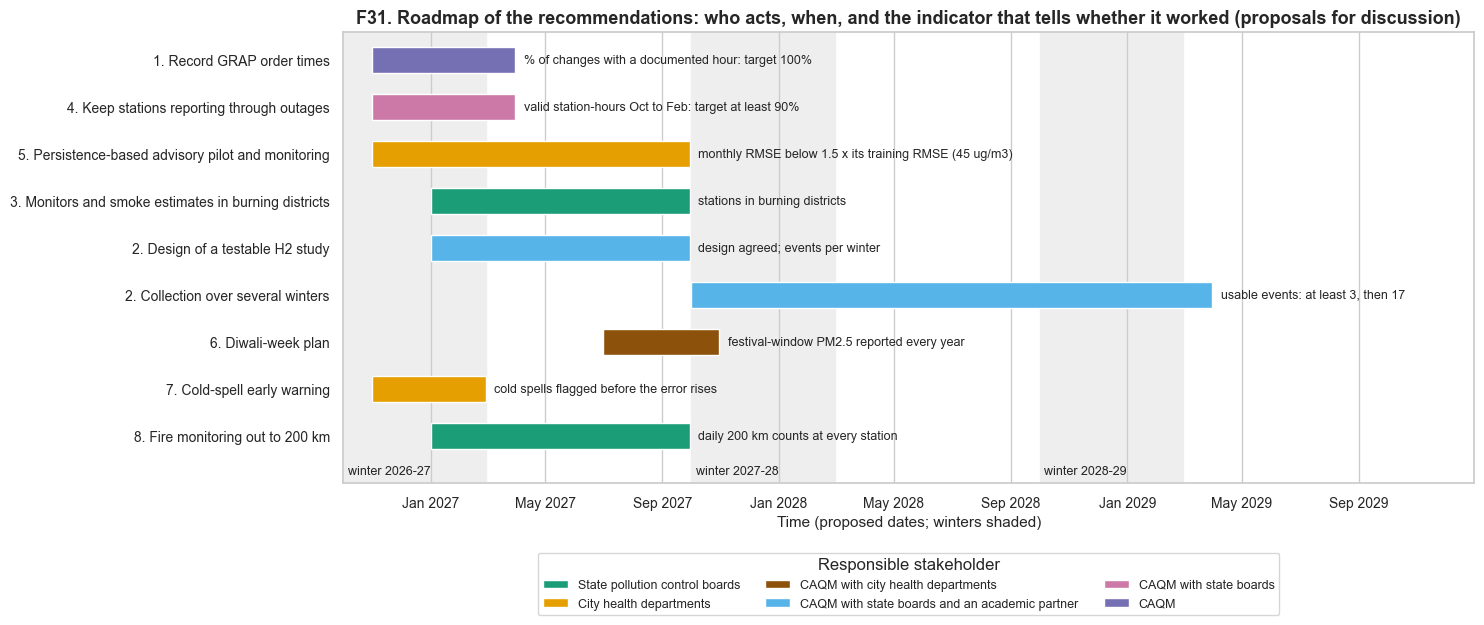

In [288]:
# Step 11.3b: F31 roadmap: one bar per action on a time axis, coloured by stakeholder, with the indicator written beside each bar; winters shaded
fig, ax = plt.subplots(figsize=(15, 6.5)); colours = {"CAQM": "#7570B3", "CAQM with state boards": "#CC79A7", "City health departments": "#E69F00", "State pollution control boards": "#1B9E77", "CAQM with state boards and an academic partner": "#56B4E9", "CAQM with city health departments": "#8C510A"}
for y, row in enumerate(roadmap.iloc[::-1].itertuples()):
    ax.barh(y, (row.End - row.Start).days, left=mdates.date2num(row.Start), color=colours[row.Stakeholder], height=0.55, label=row.Stakeholder if row.Stakeholder not in ax.get_legend_handles_labels()[1] else None)
    ax.annotate(row.Indicator, (mdates.date2num(row.End), y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
for start, end in [("2026-10-01", "2027-02-28"), ("2027-10-01", "2028-02-29"), ("2028-10-01", "2029-02-28")]:
    ax.axvspan(mdates.date2num(pd.Timestamp(start)), mdates.date2num(pd.Timestamp(end)), color="#EEEEEE", zorder=0)
    ax.text(mdates.date2num(pd.Timestamp(start)) + 5, -0.75, "winter " + start[:4] + "-" + str(int(start[:4]) + 1)[2:], fontsize=9, va="center")
ax.set_yticks(range(len(roadmap))); ax.set_yticklabels(roadmap["Action"].iloc[::-1]); ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.set_xlim(mdates.date2num(pd.Timestamp("2026-10-01")), mdates.date2num(pd.Timestamp("2029-12-31")))
ax.set_ylim(-1.0, len(roadmap) - 0.4); ax.set_xlabel("Time (proposed dates; winters shaded)"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=9, title="Responsible stakeholder")
ax.set_title("F31. Roadmap of the recommendations: who acts, when, and the indicator that tells whether it worked (proposals for discussion)")
plt.tight_layout(); save_fig(fig, "F31_roadmap"); plt.show()

*F31. Proposed timeline of the recommendations (bars), coloured by the responsible stakeholder, with the indicator written beside each bar; October to February of each winter is shaded. Dates are proposals counted from the start of winter 2026-27 and are not derived from the data. Source: tables T08 and T11b.*

**What it shows.** The order of work: the data fixes that can be done this winter (order times, outages, the advisory pilot) come before the design and the multi-winter collection that H2 needs.

**What it does not show.** That the dates are feasible or funded, or that the targets will be met; they are a basis for discussion with the stakeholders named.

## 11.4 Limitations and assumptions

In [289]:
# Step 11.4a: limitations, with the numbers behind each one taken from the notebook
show_takeaway(
    f"- **One season.** The data cover **{df['date_ist'].min():%b %Y} to {df['date_ist'].max():%b %Y}** ({df['station_id'].nunique()} stations, {len(df):,} station-hours), with a single burning season; the winter sample has **{len(used['date_ist'].unique())}** dates. The proposal asked for 2019 onwards, so the window is a **deviation** forced by the data that could be assembled.\n"
    f"- **Reverse causation (H2).** A stage is invoked because pollution is high and rising: before the primary event PM2.5 was already rising by about **{event_table.loc[primary_number, 'pm25_trend_pct_per_day']:+.0f}% per day**, so a fall afterwards is expected without any stage (mean reversion, 9B.5 to 9B.6).\n"
    f"- **Outages.** Network outages cover **{int(kpi_w['Network-outage hours (count)'])}** hours of the winter and overlap the events (up to **{int(event_table['outage_hours_within_7_days'].max())}** hours within 7 days of one change); where stations are silent the evidence is missing, not the pollution.\n"
    f"- **Control cities.** Patna, Lucknow and Kanpur have different weather, sources and local rules, so a comparison with them (9B.3, 9B.7) assume parallel trends that cannot be checked beyond the pre-event days; they are not a clean untreated twin.\n"
    f"- **Weather resolution.** ERA5 gives nearest 0.25 degree cells (about 25 km), so local wind and boundary-layer height at a station are approximated; the fire variable is a count of satellite detections within 100 km, a proxy for smoke, not tonnes emitted, and clouds hide fires.\n"
    f"- **Units and checks.** PM2.5 is in ug/m3 as reported by the sources (unit checks in Phase 2); thresholds use the national 24-hour standard of {STANDARD} ug/m3; weather units are in table T01.\n"
    f"- **Deviations from the proposal.** Hourly data aggregated to station-days; validation is **time-blocked** (train to 31 Dec 2025, test from 1 Jan 2026), not random; the upwind fire variable exists for the previous day only (the all-direction count has two lags), not for 1 to 3 days; difference-in-differences and a boosted model were added as extensions; propensity matching, regression discontinuity, LIME, a fairness check and experiment tracking were **not** done."
)

- **One season.** The data cover **Feb 2025 to Sep 2026** (54 stations, 763,344 station-hours), with a single burning season; the winter sample has **129** dates. The proposal asked for 2019 onwards, so the window is a **deviation** forced by the data that could be assembled.
- **Reverse causation (H2).** A stage is invoked because pollution is high and rising: before the primary event PM2.5 was already rising by about **+18% per day**, so a fall afterwards is expected without any stage (mean reversion, 9B.5 to 9B.6).
- **Outages.** Network outages cover **424** hours of the winter and overlap the events (up to **242** hours within 7 days of one change); where stations are silent the evidence is missing, not the pollution.
- **Control cities.** Patna, Lucknow and Kanpur have different weather, sources and local rules, so a comparison with them (9B.3, 9B.7) assume parallel trends that cannot be checked beyond the pre-event days; they are not a clean untreated twin.
- **Weather resolution.** ERA5 gives nearest 0.25 degree cells (about 25 km), so local wind and boundary-layer height at a station are approximated; the fire variable is a count of satellite detections within 100 km, a proxy for smoke, not tonnes emitted, and clouds hide fires.
- **Units and checks.** PM2.5 is in ug/m3 as reported by the sources (unit checks in Phase 2); thresholds use the national 24-hour standard of 60 ug/m3; weather units are in table T01.
- **Deviations from the proposal.** Hourly data aggregated to station-days; validation is **time-blocked** (train to 31 Dec 2025, test from 1 Jan 2026), not random; the upwind fire variable exists for the previous day only (the all-direction count has two lags), not for 1 to 3 days; difference-in-differences and a boosted model were added as extensions; propensity matching, regression discontinuity, LIME, a fairness check and experiment tracking were **not** done.

**What it shows.** The conditions under which the findings hold and the ways in which the work departs from the proposal, so a reader can judge how far to trust each result.

**What it does not show.** The limits are listed, not removed: none of them would be fixed by a different model on the same data. The recommendations of 11.2 are chosen because they address the largest of them (one season, few events, outages, no monitors near the fires).

## 11.5 Responsible AI: privacy, fairness, ethics and explainability

**Privacy.** The data are public, aggregated station readings of air quality, satellite fire detections, weather and published government orders. There is **no personal data**, no individual location and no health record, so no privacy risk arises from the analysis or from the app; the app must not be extended with personal or household data without a new review.

**Fairness as geographic equity.** A model that predicts well in Delhi but badly in smaller places would give some communities worse advice. The prediction model used for the advisory (persistence plus weather) is tested **by sub-area and for the control cities**; the question is whether its error, relative to the pollution level, is similar everywhere. There is no demographic or station-type information in the data, so equity here means *place*, not people.

**Ethics.** Every result is an **association, not a cause**. Two risks follow: a *false negative* in a cold spell (the models under-predict when it is colder than anything in the training period, and a missed warning has a health cost), and **over-reading H2**: GRAP must be presented neither as proven nor as disproven.

**Explainability.** The boosted model is explained with **permutation importance and SHAP** (8B.9, with the caveat that single-input importances of correlated weather variables are unstable). **LIME was not needed:** it explains individual predictions, and the project makes no individual predictions; the advisory model is a transparent regression whose coefficients are published (T08i).

In [290]:
# Step 11.5a: fairness as geographic equity: test error of the persistence-plus-weather model by sub-area (treated) and by city (control: the same specification fitted on the control cities)
test_eval = test.assign(pred=predictions_b["Persistence + weather"])
ctl = h1_frame(analysis_station_day, group="control", winter=False)
ctl = ctl.merge(ctl[["station_id", "date_ist", "pm25_day"]].assign(date_ist=lambda d: d["date_ist"] + pd.Timedelta(days=1)).rename(columns={"pm25_day": "pm25_yesterday"}), on=["station_id", "date_ist"], how="left")
ctl = ctl.dropna(subset=["log_pm25", FIRE, "pm25_yesterday"] + CONTROLS.split(" + ")).assign(log_yday=lambda d: np.log(d["pm25_yesterday"]))
ctl_train, ctl_test = ctl[ctl["date_ist"] <= TRAIN_END], ctl[ctl["date_ist"] >= TEST_START]; ctl_test = ctl_test[ctl_test["station_id"].isin(ctl_train["station_id"].unique())].copy()
ctl_test["pred"] = fit_predict(ctl_train, ctl_test, WY_TERMS)
rows = []
for group_name, frame in [("treated", test_eval), ("control", ctl_test)]:
    for area, g in frame.groupby("sub_area"):
        err = g["pm25_day"].to_numpy() - g["pred"].to_numpy()
        rows.append({"Group": group_name, "Sub-area": area, "Stations": g["station_id"].nunique(), "Test station-days": len(g), "Mean PM2.5 (ug/m3)": g["pm25_day"].mean(), "RMSE (ug/m3)": float(np.sqrt(np.mean(err ** 2))), "RMSE as % of mean PM2.5": float(np.sqrt(np.mean(err ** 2)) / g["pm25_day"].mean() * 100)})
equity = pd.DataFrame(rows).set_index("Sub-area"); display(equity.round(1)); save_table(equity.round(2), "T11c_equity_by_area")

,Group,Stations,Test station-days,Mean PM2.5 (ug/m3),RMSE (ug/m3),RMSE as % of mean PM2.5
Sub-area,,,,,,
Delhi,treated,33,6384,64.7,23.6,36.5
Ghaziabad,treated,3,495,74.1,22.9,30.9
Gurugram,treated,1,183,56.0,18.0,32.2
Noida,treated,2,350,68.4,22.6,33.1
Kanpur,control,3,591,38.1,12.1,31.8
Lucknow,control,5,974,45.6,16.0,35.1
Patna,control,7,1208,45.7,12.3,27.0


saved table : T11c_equity_by_area


saved figure: F33_equity_by_area


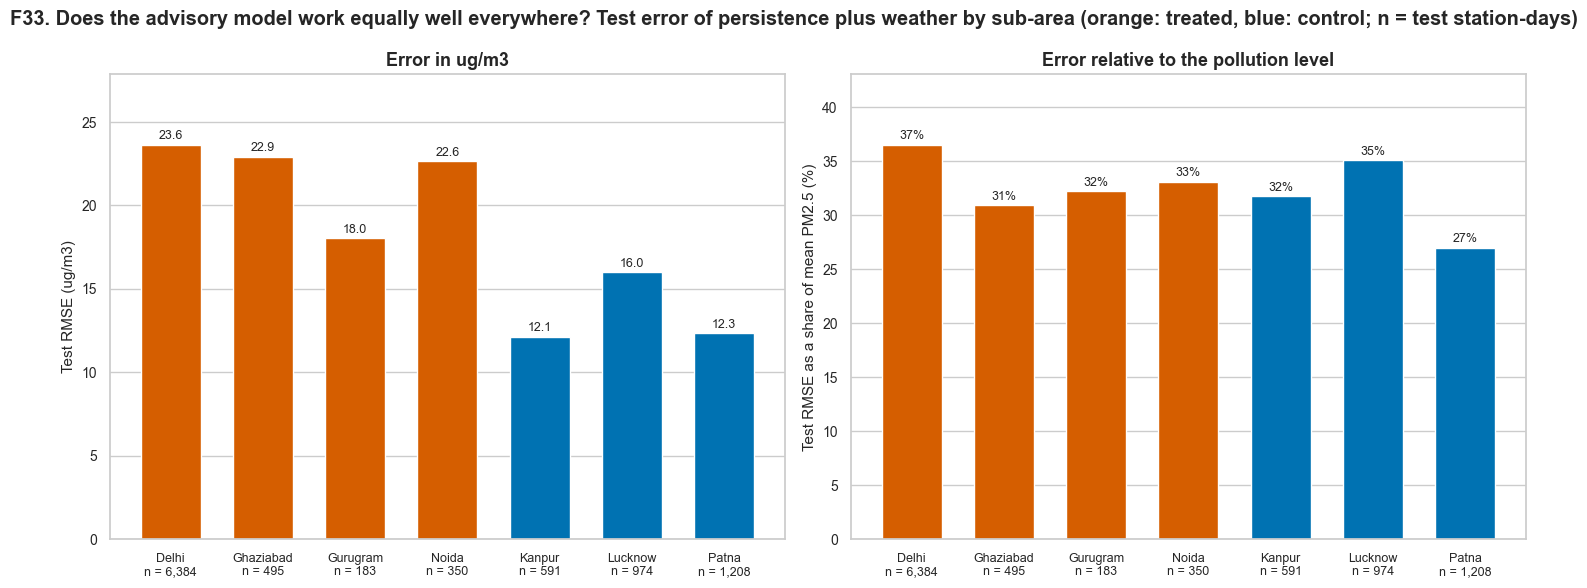

In [291]:
# Step 11.5b: F33 test error by sub-area: RMSE in ug/m3 (left) and as a share of the mean PM2.5 (right); treated orange, control blue; values and n written
fig, axes = plt.subplots(1, 2, figsize=(15, 6)); x = np.arange(len(equity)); cols = [COL[g] for g in equity["Group"]]
for ax, col, fmt, ylabel in [(axes[0], "RMSE (ug/m3)", "{:.1f}", "Test RMSE (ug/m3)"), (axes[1], "RMSE as % of mean PM2.5", "{:.0f}%", "Test RMSE as a share of mean PM2.5 (%)")]:
    bars = ax.bar(x, equity[col], color=cols, width=0.65); label_bars(ax, bars, fmt)
    ax.set_xticks(x); ax.set_xticklabels([f"{a}\nn = {int(n):,}" for a, n in zip(equity.index, equity["Test station-days"])], fontsize=9); ax.set_ylabel(ylabel); ax.set_ylim(0, equity[col].max() * 1.18); ax.grid(axis="x", visible=False)
axes[0].set_title("Error in ug/m3"); axes[1].set_title("Error relative to the pollution level")
fig.suptitle("F33. Does the advisory model work equally well everywhere? Test error of persistence plus weather by sub-area (orange: treated, blue: control; n = test station-days)", fontweight="bold")
plt.tight_layout(); save_fig(fig, "F33_equity_by_area"); plt.show()

In [292]:
# Step 11.5c: takeaway text for the equity check
rel = equity["RMSE as % of mean PM2.5"]; hi_a, lo_a = rel.idxmax(), rel.idxmin(); treated_rows = equity[equity["Group"] == "treated"]
show_takeaway(
    f"**What we learn:** the advisory model's test error, as a share of the mean PM2.5, is **{rel.min():.0f}%** in **{lo_a}** and **{rel.max():.0f}%** in **{hi_a}** (a ratio of **{rel.max() / rel.min():.1f}**); in ug/m3 it ranges from **{equity['RMSE (ug/m3)'].min():.1f}** to **{equity['RMSE (ug/m3)'].max():.1f}**. "
    f"The sub-areas with the fewest test station-days ({', '.join(equity.sort_values('Test station-days').index[:2])}) are the least certain. The treated sub-areas other than Delhi hold **{(1 - treated_rows.loc['Delhi', 'Test station-days'] / treated_rows['Test station-days'].sum()) * 100:.0f}%** of the treated test station-days, so claims for them rest on few stations."
)

**What we learn:** the advisory model's test error, as a share of the mean PM2.5, is **27%** in **Patna** and **37%** in **Delhi** (a ratio of **1.4**); in ug/m3 it ranges from **12.1** to **23.6**. The sub-areas with the fewest test station-days (Gurugram, Noida) are the least certain. The treated sub-areas other than Delhi hold **14%** of the treated test station-days, so claims for them rest on few stations.

*F33. Test error of the persistence-plus-weather model on the test period (1 Jan to 30 Sep 2026), by sub-area: root mean squared error in ug/m3 (left) and as a share of the mean PM2.5 of the sub-area (right); treated sub-areas in orange (one model for all), control cities in blue (the same specification fitted on the control cities); the value is written on each bar and n (test station-days) under it. Source: `final_dataset.parquet` via the station-day table.*

**What it shows.** Whether the advisory model is about equally accurate, relative to the pollution level, in every sub-area and city of the data, which is the geographic form of fairness available here.

**What it does not show.** Fairness between groups of people (the data have no demographic information), or for places without stations. Small sub-areas have few stations and few test days, so their errors are uncertain; the control-city model is fitted separately and is not the same model as the treated one.

In [293]:
# Step 11.5d: the possible-bias table (T11d): each source of bias, how it is measured here, its value, and what was done about it
w_tr = analysis_station_day[(analysis_station_day["group"] == "treated") & analysis_station_day["date_ist"].between(WINTER_START, WINTER_END)]
s34 = df[(df["group"] == "treated") & (df["grap_stage_applied"] >= 3)]; win_means = analysis_station_day[analysis_station_day["date_ist"].between(WINTER_START, WINTER_END)].groupby("group")[["pm25_day", "t2m_c", "wind_speed"]].mean()
status_share = df["fire_day_status"].value_counts(normalize=True)
bias = [("Station imbalance", "share of treated winter station-days from Delhi", f"{(w_tr['sub_area'] == 'Delhi').mean() * 100:.0f}% ({w_tr['sub_area'].eq('Delhi').sum():,} of {len(w_tr):,})", "reported by sub-area in 8B.2 and the equity table; leave-one-sub-area-out runs in 8.7"),
        ("Missing not at random", "share of Stage III and IV station-hours inside a network outage, against all station-hours", f"{s34['network_outage'].mean() * 100:.0f}% against {df['network_outage'].mean() * 100:.0f}%", "outage hours are grey gaps, never interpolated; counted in the KPI table and in recommendation 4"),
        ("Control cities differ", "winter mean PM2.5 and temperature, treated against control", f"{win_means.loc['treated', 'pm25_day']:.0f} against {win_means.loc['control', 'pm25_day']:.0f} ug/m3; {win_means.loc['treated', 't2m_c']:.1f} against {win_means.loc['control', 't2m_c']:.1f} deg C", "used as a comparison, not a twin; difference-in-differences and placebo checks (9B.3, 9B.7)"),
        ("Satellite gaps and assumed zeros", "share of station-hours whose fire value is from an outage or an assumed zero", f"{(status_share.get('outage', 0) + status_share.get('zero_assumed', 0)) * 100:.1f}%", "run without those days in 8.7; clouds hide fires, so counts are a lower bound"),
        ("Fire count is a proxy", "effect per SD of the all-direction 200 km count against the upwind 100 km count", f"{r200['effect']:+.1f}% against {primary_run['effect']:+.1f}%", "wording is association only; fire radiative power run in 8.7"),
        ("Events follow high pollution", "PM2.5 trend in the week before the primary event", f"{event_table.loc[primary_number, 'pm25_trend_pct_per_day']:+.0f}% per day", "placebo dates, spike-day benchmark and mean-reversion regression (9.7, 9B.5, 9B.6)")]
bias_table = pd.DataFrame(bias, columns=["Source of bias", "Measured as", "Value", "What was done about it"]).set_index("Source of bias")
pd.set_option("display.max_colwidth", 110); display(bias_table); save_table(bias_table, "T11d_possible_bias")

,Measured as,Value,What was done about it
Source of bias,,,
Station imbalance,share of treated winter station-days from Delhi,"86% (4,106 of 4,794)",reported by sub-area in 8B.2 and the equity table; leave-one-sub-area-out runs in 8.7
Missing not at random,"share of Stage III and IV station-hours inside a network outage, against all station-hours",12% against 7%,"outage hours are grey gaps, never interpolated; counted in the KPI table and in recommendation 4"
Control cities differ,"winter mean PM2.5 and temperature, treated against control",163 against 65 ug/m3; 18.0 against 19.5 deg C,"used as a comparison, not a twin; difference-in-differences and placebo checks (9B.3, 9B.7)"
Satellite gaps and assumed zeros,share of station-hours whose fire value is from an outage or an assumed zero,3.7%,"run without those days in 8.7; clouds hide fires, so counts are a lower bound"
Fire count is a proxy,effect per SD of the all-direction 200 km count against the upwind 100 km count,+24.2% against +9.5%,wording is association only; fire radiative power run in 8.7
Events follow high pollution,PM2.5 trend in the week before the primary event,+18% per day,"placebo dates, spike-day benchmark and mean-reversion regression (9.7, 9B.5, 9B.6)"


saved table : T11d_possible_bias


In [294]:
# Step 11.5e: why the bias table counts more treated winter station-days than the primary model uses: the rows dropped because a fire value or a weather control is missing
weather_cols = CONTROLS.split(" + "); dropped = w_tr.loc[~w_tr.index.isin(used.index)]
n_valid, n_model, n_dropped = len(w_tr), len(used), len(dropped); no_fire = int(dropped[FIRE].isna().sum()); no_weather = int(dropped[weather_cols].isna().any(axis=1).sum())
both = int((dropped[FIRE].isna() & dropped[weather_cols].isna().any(axis=1)).sum()); other = int(n_dropped - (dropped[FIRE].isna() | dropped[weather_cols].isna().any(axis=1)).sum())
share_valid, share_model = (w_tr["sub_area"] == "Delhi").mean() * 100, (used["sub_area"] == "Delhi").mean() * 100
reason = f"{no_fire} have no upwind fire value and {no_weather} have a missing weather control ({both} have both)" + (f", and {other} for another reason" if other else "")
show_takeaway(f"**Denominator:** {n_valid:,} valid treated winter station-days; {n_dropped} dropped in the model because {reason}; the Delhi share is **{share_valid:.0f}%** of the valid days and **{share_model:.0f}%** of the model's {n_model:,} station-days.")

**Denominator:** 4,794 valid treated winter station-days; 37 dropped in the model because 37 have no upwind fire value and 0 have a missing weather control (0 have both); the Delhi share is **86%** of the valid days and **86%** of the model's 4,757 station-days.

**What it shows.** The main ways in which the data or the design could mislead, each with a number measured from the data and the step taken against it.

**What it does not show.** That the bias is removed: each step reduces or exposes a problem, none eliminates it, and some biases (for example the cloud gaps in the fire data) cannot be measured with this data at all.

---
# Phase 12: Final checks and reconciliation
*No new analysis.* This phase lists what the notebook saved (12.1), says how to reproduce it and what has not been built (12.2), maps the **research questions and methods of the project proposal** to the results (12.3), runs the **final checklist** as far as it can be run by code (12.4), and compares the notebook with the earlier pass of the project (12.5). Items that code cannot check are marked *needs your check* and are not ticked.

## 12.1 Output inventory

**Question:** is every saved figure complete (PNG, SVG and a caption cell in this notebook), and what tables were saved?
**Method:** the files in `outputs/figures` and `outputs/tables` are listed with their IDs; each figure ID must appear in a caption cell (`*F9. ...*`) of this notebook. The cell **fails** (stops the notebook) if a figure has no caption or no SVG.

In [295]:
# Step 12.1a: inventory of the saved figures and tables; a figure without a caption cell or an SVG stops the notebook
import os, re, json
nb_file = os.path.join(ROOT, "notebooks", "air_quality_policy_impact.ipynb")
nb_json = json.load(open(nb_file, encoding="utf-8")) if os.path.exists(nb_file) else None
md_all = "\n".join("".join(c["source"]) for c in nb_json["cells"] if c["cell_type"] == "markdown") if nb_json else ""
captions = set(re.findall(r"^\s*\*(F\d+[a-z]?)\.", md_all, flags=re.M))
fig_files = sorted(f for f in os.listdir(FIG_DIR) if f.endswith(".png"))
fig_inv = pd.DataFrame({"File": fig_files, "ID": [re.match(r"^(F\d+[a-z]?)_", f).group(1) if re.match(r"^(F\d+[a-z]?)_", f) else "" for f in fig_files]})
fig_inv["SVG too"] = [os.path.exists(os.path.join(FIG_DIR, f[:-4] + ".svg")) for f in fig_files]
fig_inv["Caption cell"] = fig_inv["ID"].isin(captions) if nb_json else None
tab_files = sorted(f for f in os.listdir(TAB_DIR) if f.endswith(".csv"))
tab_inv = pd.DataFrame({"File": tab_files, "ID": [re.match(r"^(T\d+[a-z]?\d?)_", f).group(1) if re.match(r"^(T\d+[a-z]?\d?)_", f) else "" for f in tab_files], "Size (kB)": [round(os.path.getsize(os.path.join(TAB_DIR, f)) / 1024, 1) for f in tab_files]})
display(fig_inv.set_index("ID")); save_table(fig_inv.set_index("ID"), "T12a_figure_inventory"); print(len(tab_files), "tables saved, e.g.", ", ".join(tab_files[:4]), "...")
missing = fig_inv[(fig_inv["SVG too"] == False) | (fig_inv["Caption cell"] == False) | (fig_inv["ID"] == "")]
assert nb_json is not None, f"notebook file not found at {nb_file}: the caption check needs it"
assert missing.empty, "figures without SVG, ID or caption cell:\n" + missing.to_string()
show_takeaway(f"**What we learn:** **{len(fig_inv)}** figures (each as PNG and SVG, each with a caption cell) and **{len(tab_inv)}** tables are saved in `outputs/`. The inventory check passes.")

,File,SVG too,Caption cell
ID,,,
F02a,F02a_missing_by_column.png,True,True
F02b,F02b_outage_runs.png,True,True
F02c,F02c_values_removed.png,True,True
F0,F0_data_integration_flow.png,True,True
F0b,F0b_stations_per_sub_area.png,True,True
F10,F10_h1_diagnostics.png,True,True
F11,F11_prediction.png,True,True
F12,F12_event_counterfactuals.png,True,True
F13,F13_event_effects.png,True,True


saved table : T12a_figure_inventory
89 tables saved, e.g. T00_kpis.csv, T01_sources.csv, T01b_join_report.csv, T01c_column_groups.csv ...


**What we learn:** **44** figures (each as PNG and SVG, each with a caption cell) and **89** tables are saved in `outputs/`. The inventory check passes.

**What it shows.** That every figure of the notebook exists as a file in two formats and has its caption in the notebook, and which tables were saved with which IDs.

**What it does not show.** That a caption is *good*: it checks that the caption exists, not that the figure states its units and values (those were checked by viewing each figure during the build). The tables are listed, not checked for content.

## 12.2 Reproduction steps and what has not been built

**To reproduce the numbers** from the final table (`data/processed/final_dataset.parquet`, git-ignored): either run `python run_all.py --from-final` from the repository root (it runs every cell in one fresh process and writes an executed copy to `outputs/executed_notebook.ipynb`), or open `notebooks/air_quality_policy_impact.ipynb`, restart the kernel and run all cells from the repository root or from `notebooks/`; every figure and table is written to `outputs/` and the analysis tables of Phase 4 to `data/processed/analysis_*.parquet`. The steps that build the final table from the raw sources (OpenAQ, FIRMS, ERA5, the GRAP orders) are the scripts in `src/` described in `README.md`, with the sources and retrieval dates in `docs/provenance_log.csv`; `docs/validation_run_output.txt` is the output of the validation script on the final table.

**What does not exist yet.** The plan named a built dashboard. **It has not been built:** `docs/Dashboard.md` is a *plan* for a dashboard, not a dashboard; it would be built from the files in `outputs/` as described in that plan. **Google Colab:** the notebook has been run only on a local machine (Windows, Python 3.10). In Colab, clone the repository, copy `final_dataset.parquet` into `data/processed/`, start from the repository root, and expect `shap` to be missing (one cell then skips the SHAP column); this route has not been tested.

## 12.3 The proposal's research questions and methods against the results (T12b, T12c)

**Question:** what does the notebook say about each of the four research questions of the project proposal, and which methods listed in the proposal were not run, and why?
**Note on numbering.** The notebook's H1 (upwind fire counts) and H2 (GRAP) come from the Stage 1 hypotheses of the project plan; the proposal's RQ1 to RQ4 are mapped to them below. *Supported / not supported / inconclusive* uses the notebook's frozen rules where they exist; for the questions the frozen rules did not cover, the status is the plain reading of the extension results, **not a frozen status**.

In [296]:
# Step 12.3a: the proposal's four research questions against the notebook's results (numbers from the tables of Phases 8 to 10)
frp_run = robust.loc["fire radiative power instead of counts"]
blh_rank, ws_rank = int(single_importance.loc["blh_m", "Rank"]), int(single_importance.loc["wind_speed", "Rank"])
sub_area = het_table[het_table["Dimension"] == "Sub-area"].iloc[0]
pm10_cols = [c for c in df.columns if "pm10" in c.lower()]
rq3_status = "supported" if max(blh_rank, ws_rank) <= 3 else ("partly supported" if min(blh_rank, ws_rank) <= 3 else "not supported by this measure")
rq = [("RQ1 (H1 of the proposal): did restrictions lower PM2.5 and PM10 at affected stations against unaffected ones?", "Notebook H2 and 9B.3 (difference-in-differences with the control cities)",
       f"frozen status {status['H2']}; treated minus control over days 1 to 3 averages {did_pool['Days 1-3 (%)']:+.1f}% (placebo range {did_pool['Placebo 2.5% (days 1-3)']:+.1f}% to {did_pool['Placebo 97.5% (days 1-3)']:+.1f}%); {len(usable_events)} usable events",
       status["H2"].lower(), f"PM2.5 only: PM10 is in the dataset ({len(pm10_cols)} columns) but was not analysed; no usable counterfactual"),
      ("RQ2 (H2 of the proposal): how much of the spike do upwind fires explain after controlling for weather; does fire radiative power add explanatory power?", "Notebook H1, 8B.6 and the fire-radiative-power run of 8.7",
       f"H1 {h1_label}; fire counts add {fire_share_beyond_weather['increment'] * 100:.1f} points of R-squared beyond weather and stations (interval {fire_share_beyond_weather['low'] * 100:.2f} to {fire_share_beyond_weather['high'] * 100:.2f}); fire radiative power: {frp_run['effect']:+.1f}% per SD (interval {frp_run['low']:+.1f}% to {frp_run['high']:+.1f}%)",
       "supported but small", "mostly between months; one winter"),
      ("RQ3 (H3 of the proposal): does weather explain most of the variation; are boundary-layer height and wind speed among the top predictors?", "8B.6 and 8B.9 (permutation importance of the boosted model, single inputs)",
       f"stations and weather explain {variance_table.iloc[1]['R-squared'] * 100:.0f}% of log PM2.5; shuffling the weather inputs raises the test error by {importance.iloc[0, 0]:.1f} ug/m3; boundary-layer height ranks {blh_rank} and wind speed {ws_rank} of {len(single_importance)} inputs",
       rq3_status + " (top 3 taken as 'among the top')", "an extension, not a frozen rule; temperature, pressure and boundary-layer height move together, so single-input ranks (some even negative) are unstable, while the weather inputs shuffled together matter most"),
      ("RQ4 (H4 of the proposal): do effects differ between traffic, industrial and residential stations?", "not testable; nearest result is 8B.2 (sub-areas)",
       f"the stations table has no station-type field; Delhi against the other sub-areas differs by {sub_area['B minus A (points)']:+.1f} points per +5 detections (interval {sub_area['Diff CI low']:+.1f} to {sub_area['Diff CI high']:+.1f})",
       "not tested", "needs a station-type classification that the data do not contain")]
rq_map = pd.DataFrame(rq, columns=["Proposal question", "Notebook hypothesis and cells", "Result", "Status", "Gap"]).set_index("Proposal question")
pd.set_option("display.max_colwidth", 120); display(rq_map[["Notebook hypothesis and cells", "Status"]]); save_table(rq_map, "T12b_proposal_questions")

,Notebook hypothesis and cells,Status
Proposal question,,
RQ1 (H1 of the proposal): did restrictions lower PM2.5 and PM10 at affected stations against unaffected ones?,Notebook H2 and 9B.3 (difference-in-differences with the control cities),inconclusive
RQ2 (H2 of the proposal): how much of the spike do upwind fires explain after controlling for weather; does fire radiative power add explanatory power?,"Notebook H1, 8B.6 and the fire-radiative-power run of 8.7",supported but small
RQ3 (H3 of the proposal): does weather explain most of the variation; are boundary-layer height and wind speed among the top predictors?,"8B.6 and 8B.9 (permutation importance of the boosted model, single inputs)",not supported by this measure (top 3 taken as 'among the top')
"RQ4 (H4 of the proposal): do effects differ between traffic, industrial and residential stations?",not testable; nearest result is 8B.2 (sub-areas),not tested


saved table : T12b_proposal_questions


In [297]:
# Step 12.3b: the methods of the proposal that were run, and those that were not, with the reason
methods = [("Difference-in-differences with an event study", "run (extension)", "9B.3, with placebo-date bands and a pre-trend check"),
           ("Placebo dates and alternative fire radii", "run", "9.7 and 9B.3; radii of 50, 100 and 200 km in 8.7"),
           ("Alternative control groups", "partly", "only the three control cities; no second control group"),
           ("Propensity score matching", "not run", "the comparison group is three whole cities with 15 stations, so matching would leave few comparable units; time"),
           ("Regression discontinuity", "not run", "needs a numeric trigger; GRAP stages follow AQI forecasts that are not in the data (Phase 1)"),
           ("Gradient boosting with tuning", "run", "8B.9 with blocked tuning; no calibration step"),
           ("SHAP", "run", "8B.9, on a twin model because SHAP mishandles categorical splits"),
           ("LIME", "not run", "SHAP and permutation importance were used; time"),
           ("Fairness check across station types", "not run", "no station-type field in the data"),
           ("Comparison of CPCB PM2.5 with US AirNow", "done in the data pipeline", "data/processed/stations_validation_airnow.csv; not repeated in this notebook"),
           ("Drift monitoring", "run", "10.4"),
           ("MLflow tracking and a model API", "partly", "scripts/log_mlflow.py logs the persistence-plus-weather model to MLflow and app/streamlit_app.py serves an advisory page; there is no model API and no deployment"),
           ("Spark ETL", "not used", f"{len(df):,} rows fit in memory")]
methods_table = pd.DataFrame(methods, columns=["Method of the proposal", "Status", "Where or why not"]).set_index("Method of the proposal")
display(methods_table); save_table(methods_table, "T12c_methods_status")
show_takeaway(f"**What we learn:** of the four proposal questions, **{int((rq_map['Status'] == 'not tested').sum())}** could not be tested (no station-type field); RQ1 is {rq_map.iloc[0]['Status']}, RQ2 {rq_map.iloc[1]['Status']} and RQ3 {rq_map.iloc[2]['Status']}. "
              f"Of {len(methods_table)} methods listed, **{int(methods_table['Status'].str.startswith('run').sum())}** were run, **{int((methods_table['Status'] == 'not run').sum())}** were not run and the rest are partial or done elsewhere.")

,Status,Where or why not
Method of the proposal,,
Difference-in-differences with an event study,run (extension),"9B.3, with placebo-date bands and a pre-trend check"
Placebo dates and alternative fire radii,run,"9.7 and 9B.3; radii of 50, 100 and 200 km in 8.7"
Alternative control groups,partly,only the three control cities; no second control group
Propensity score matching,not run,"the comparison group is three whole cities with 15 stations, so matching would leave few comparable units; time"
Regression discontinuity,not run,needs a numeric trigger; GRAP stages follow AQI forecasts that are not in the data (Phase 1)
Gradient boosting with tuning,run,8B.9 with blocked tuning; no calibration step
SHAP,run,"8B.9, on a twin model because SHAP mishandles categorical splits"
LIME,not run,SHAP and permutation importance were used; time
Fairness check across station types,not run,no station-type field in the data


saved table : T12c_methods_status


**What we learn:** of the four proposal questions, **1** could not be tested (no station-type field); RQ1 is inconclusive, RQ2 supported but small and RQ3 not supported by this measure (top 3 taken as 'among the top'). Of 13 methods listed, **5** were run, **4** were not run and the rest are partial or done elsewhere.

**What it shows.** A one-page answer to "did the project do what the proposal said": what each research question found, and which promised methods are missing and why.

**What it does not show.** That the missing methods would have changed a conclusion; they were not run. The statuses for RQ2 and RQ3 are plain readings of results that were not covered by the frozen decision rules.

## 12.4 Final checklist (section 5 of the plan)

**Question:** which items of the final checklist can code confirm, and which need a person?
**Method:** the checklist is evaluated from the notebook file and the saved tables. **pass** means code confirmed it; **needs your check** means it cannot be confirmed by code (it is not ticked); **FAIL** stops the notebook.

In [298]:
# Step 12.4a: the checklist: helpers and the first items (run time, figures, explanation cells, code-cell length and headers, colours)
import time
cells_nb = nb_json["cells"]; checklist = []
def tick(item, status, detail):
    checklist.append({"Item": item, "Status": status, "Detail": detail})
tick("Restart and run all passes top to bottom; the run time is printed", "needs your check", f"every cell up to this one ran without error in this session, in {(time.time() - NOTEBOOK_START) / 60:.1f} min; the run on your laptop with a restarted kernel is yours to confirm")
tick("Every figure is saved as PNG and SVG with its ID and a caption cell", "pass" if missing.empty else "FAIL", f"{len(fig_inv)} figures (12.1)")
cap_idx = [i for i, c in enumerate(cells_nb) if c["cell_type"] == "markdown" and re.match(r"^\s*\*F\d+[a-z]?\.", "".join(c["source"]))]
near_md = lambda i: " ".join("".join(cells_nb[j]["source"]) for j in range(i, min(i + 3, len(cells_nb))) if cells_nb[j]["cell_type"] == "markdown")
no_expl = [i for i in cap_idx if not ("What it shows" in near_md(i) and "does not show" in near_md(i))]
tick("Every figure is followed by an explanation: what it shows, what it does not show", "pass" if not no_expl else "FAIL", f"{len(cap_idx) - len(no_expl)} of {len(cap_idx)} captions are followed by both parts" + (f"; missing after cells {no_expl}" if no_expl else ""))
long_cells = [i for i, c in enumerate(cells_nb) if c["cell_type"] == "code" and len("".join(c["source"]).splitlines()) > 25]
no_header = [i for i, c in enumerate(cells_nb) if c["cell_type"] == "code" and not "".join(c["source"]).lstrip().startswith("#")]
tick("No code cell longer than 25 lines; every code cell starts with a header comment", "pass" if not long_cells and not no_header else "FAIL", f"{sum(c['cell_type'] == 'code' for c in cells_nb)} code cells; longer than 25 lines: {long_cells}; without header comment: {no_header}")
tick("Treated #D55E00, control #0072B2, outages grey", "pass" if COL == {"treated": "#D55E00", "control": "#0072B2"} and GREY == "#999999" else "FAIL", "the colour constants of Phase 0 have the planned values; the use in each figure was checked by viewing")

In [299]:
# Step 12.4b: the decision rules unchanged, the number of specifications stated, the wording search and the typed-number scan
frozen_now = {k: (f"{globals()[k]:%Y-%m-%d}" if k in ("TRAIN_END", "TEST_START") else str(list(globals()[k].values())) if k == "SECONDARY_EVENT_RULES" else str(globals()[k])) for k in frozen.index}
changed = [k for k in frozen.index if str(frozen[k]) != frozen_now[k]]
tick("The decision rules were written before the models and are unchanged", "pass" if not changed else "FAIL", f"the {len(frozen)} frozen constants of Phase 7 equal the values in use now; changed: {changed}")
tick("The number of specifications tried is stated", "pass" if os.path.exists(os.path.join(TAB_DIR, "T10d_runs_tried.csv")) else "FAIL", f"{len(runs)} planned runs and {len(extension_table)} extension analyses (10.6)")
all_text = [("markdown", "".join(c["source"])) for c in cells_nb if c["cell_type"] == "markdown"] + [("code", "".join(c["source"])) for c in cells_nb if c["cell_type"] == "code"]
risky, qualifier = re.compile(r"\b(caused|reduced by|proved|proven|reduced PM2\.5)\b", re.I), re.compile(r"\b(not|no|never|cannot|without|whether|if|would|nor|neither|unless|nothing)\b|\?", re.I)
unqualified = [s.strip()[:110] for _, t in all_text for s in re.split(r"(?<=[.!?])\s+|\n", t) if risky.search(s) and not qualifier.search(s) and "re.compile" not in s]
tick("The wording search finds no causal wording without a qualifier", "pass" if not unqualified else "FAIL", f"sentences with 'caused', 'reduced by' or 'proved' and no negation or condition: {len(unqualified)}" + (f", e.g. {unqualified[:2]}" if unqualified else ""))
pattern = re.compile(r"[+-]\d+(\.\d+)?%|\b\d+\.\d+\s*(ug/m3|%)|\b\d{2,3}(\.\d)?\s*ug/m3|R-squared[^.]*\d")
clean = lambda s: re.sub(r"\b\d{1,2}[AB]?\.\d{1,2}\b|\bF\d+[a-z]?\.|\bT\d+[a-z]?\d?\b", "", s)
typed = [s.strip() for k, t in all_text if k == "markdown" for s in re.split(r"(?<=[.!?])\s+|\n", t) if pattern.search(clean(s))]
tick("No typed numbers: every number in the text comes from a variable or a saved table", "needs your check", f"the results texts are generated from variables; {len(typed)} sentences of the fixed explanation texts contain a signed, percent or unit number; read during the build: thresholds (60 ug/m3, 300 ug/m3), definitions and quoted earlier values only; a second read is yours")

In [300]:
# Step 12.4c: IST on axes, limitations in the interpretation cells, extension labelling, frozen status unchanged, the key questions and the proposal mapping
utc_axes = [i for i, c in enumerate(cells_nb) if c["cell_type"] == "code" and re.search(r"(xlabel|ylabel|title)\([^)]*UTC", "".join(c["source"]))]
tick("Time is IST in every axis; units match the dictionary", "pass" if not utc_axes else "FAIL", f"no axis label or title uses UTC (cells with UTC: {utc_axes}); units were checked against the dictionary during the build")
p10 = next(i for i, c in enumerate(cells_nb) if c["cell_type"] == "markdown" and "# Phase 10" in "".join(c["source"])[:40])
before_10 = " ".join("".join(c["source"]) for c in cells_nb[:p10] if c["cell_type"] == "markdown")
kw = {"one season": r"one (winter|season)|single (winter|season)|one burning season", "reverse causation": r"reverse causation|mean reversion|regression to the mean", "outage overlap": r"outage", "control cities": r"control (cities|city|stations)"}
found = {k: len(re.findall(v, before_10, flags=re.I)) for k, v in kw.items()}
tick("The honest limitations appear in the interpretation cells, not only at the end", "pass" if all(n >= 3 for n in found.values()) else "FAIL", f"mentions before Phase 10: {found}")
ext_cells = [i for i, c in enumerate(cells_nb) if c["cell_type"] == "code" and "log_extension(" in "".join(c["source"]) and "def log_extension" not in "".join(c["source"])]
unlabelled = [i for i in ext_cells if "ADDED AFTER SEEING RESULTS" not in "".join(cells_nb[i]["source"])]
frozen_status_now = {h: ("SUPPORTED" if pd.read_csv(os.path.join(TAB_DIR, f))["Met"].all() else "INCONCLUSIVE") for h, f in [("H1", "T04h_h1_criteria.csv"), ("H2", "T06h_h2_criteria.csv")]}
tick("Every analysis of Phases 8B and 9B is labelled, listed in T07d2, and none changes the frozen status", "pass" if not unlabelled and (frozen_status_now["H1"] == "SUPPORTED") == (status["H1"] == "SUPPORTED") and (frozen_status_now["H2"] == "SUPPORTED") == (status["H2"] == "SUPPORTED") and best_method == selection.iloc[:, 0].idxmin() else "FAIL",
     f"{len(ext_cells)} cells log an extension, unlabelled: {unlabelled}; status from the frozen tables alone: {frozen_status_now}; the counterfactual carried forward is the one with the lowest hold-out error")
q_src = "".join(t for k, t in all_text if k == "code")
tick("Each of the key questions Q1 to Q4 has a plain-words answer", "pass" if all(f"**Q{n}." in q_src for n in range(1, 5)) else "FAIL", "answers in 10.3, with the number, the caveat and the source tables")
tick("The proposal's research questions are mapped and the methods not run are listed", "pass" if len(rq_map) == 4 and len(methods_table) > 0 else "FAIL", f"{len(rq_map)} questions in T12b and {len(methods_table)} methods in T12c")

In [301]:
# Step 12.4d: show the checklist, save it, and stop the notebook if any item fails
checklist_table = pd.DataFrame(checklist).set_index("Item")
pd.set_option("display.max_colwidth", 150); display(checklist_table); save_table(checklist_table, "T12d_final_checklist")
fails = checklist_table[checklist_table["Status"] == "FAIL"]
assert fails.empty, "checklist items that fail:\n" + fails.to_string()
show_takeaway(f"**What we learn:** of **{len(checklist_table)}** checklist items, **{int((checklist_table['Status'] == 'pass').sum())}** pass by code, **{int((checklist_table['Status'] == 'needs your check').sum())}** need a person (they are not ticked: "
              f"{'; '.join(i.split(';')[0].lower() for i in checklist_table.index[checklist_table['Status'] == 'needs your check'])}) and **{len(fails)}** fail.")

,Status,Detail
Item,,
Restart and run all passes top to bottom; the run time is printed,needs your check,"every cell up to this one ran without error in this session, in 3.4 min; the run on your laptop with a restarted kernel is yours to confirm"
Every figure is saved as PNG and SVG with its ID and a caption cell,pass,44 figures (12.1)
"Every figure is followed by an explanation: what it shows, what it does not show",pass,43 of 43 captions are followed by both parts
No code cell longer than 25 lines; every code cell starts with a header comment,pass,304 code cells; longer than 25 lines: []; without header comment: []
"Treated #D55E00, control #0072B2, outages grey",pass,the colour constants of Phase 0 have the planned values; the use in each figure was checked by viewing
The decision rules were written before the models and are unchanged,pass,the 17 frozen constants of Phase 7 equal the values in use now; changed: []
The number of specifications tried is stated,pass,41 planned runs and 26 extension analyses (10.6)
The wording search finds no causal wording without a qualifier,pass,"sentences with 'caused', 'reduced by' or 'proved' and no negation or condition: 0"
No typed numbers: every number in the text comes from a variable or a saved table,needs your check,"the results texts are generated from variables; 25 sentences of the fixed explanation texts contain a signed, percent or unit number; read during ..."


saved table : T12d_final_checklist


**What we learn:** of **14** checklist items, **12** pass by code, **2** need a person (they are not ticked: restart and run all passes top to bottom; no typed numbers: every number in the text comes from a variable or a saved table) and **0** fail.

**What it shows.** Which of the quality rules the notebook set itself can be confirmed mechanically, and which are left to a reader. Nothing is ticked that code did not check.

**What it does not show.** That the figures are *right* or the explanations *good*: those were checked by viewing and reading during the build. The wording search finds causal words used without a negation or condition; it cannot judge a sentence that implies causation without them.

## 12.5 Reconciliation with the earlier pass (T12e)

**Question:** how do the notebook's numbers compare with the earlier pass of the project?
**Rule:** the values that come **straight from the data** (row counts, outage hours, stations, the validation result) **must** match the earlier validation run (`docs/validation_run_output.txt`); the **model results** may differ, because the specifications differ, and differences are not errors. **The notebook was not tuned to match the earlier results.** The earlier model values are the ones recorded in the project plan: about +11.8% per +10 upwind detections (interval -3.0% to +28.9%), and +23% (interval -48% to +190%) after the 11 Nov 2025 activation.

In [302]:
# Step 12.5a: data-derived quantities against the earlier validation run (parsed from the file), then the model results against the earlier values from the project plan
earlier = open(os.path.join(ROOT, "docs", "validation_run_output.txt"), encoding="utf-8").read()
grab = lambda pattern: int(re.search(pattern, earlier).group(1).replace(",", ""))
jan = df[(df["hour_ist"] >= "2026-01-10 18:00") & (df["hour_ist"] <= "2026-01-20 18:00")]
data_rows = [("Rows in the final table", grab(r"row count is ([\d,]+)"), len(df)), ("Hours with PM2.5 present (rows)", grab(r"pm25 present in ([\d,]+) rows"), int(df["pm25"].notna().sum())),
             ("Network-outage hours", grab(r"([\d,]+) outage hours"), int(df.loc[df["network_outage"], "hour_ist"].nunique())), ("PM2.5 rows outside outage hours", grab(r"([\d,]+) PM2.5 rows remain"), int((df["pm25"].notna() & ~df["network_outage"]).sum())),
             ("Treated stations", grab(r"(\d+) treated and"), int(df.loc[df["group"] == "treated", "station_id"].nunique())), ("Control stations", grab(r"treated and (\d+) control"), int(df.loc[df["group"] == "control", "station_id"].nunique())),
             ("Hours of the January 2026 outage window", grab(r"\((\d+) hours\): PM2.5 empty"), int(jan["hour_ist"].nunique()))]
recon = pd.DataFrame([{"Quantity": q, "Earlier pass": e, "Notebook": n, "Same": "same" if e == n else "DIFFERENT", "Reason": "from the data: must match" if e == n else "from the data: must match, investigate"} for q, e, n in data_rows])
display(recon.set_index("Quantity")); assert (recon["Same"] == "same").all(), "a value that comes straight from the data differs from the earlier validation run"

,Earlier pass,Notebook,Same,Reason
Quantity,,,,
Rows in the final table,763344,763344,same,from the data: must match
Hours with PM2.5 present (rows),664591,664591,same,from the data: must match
Network-outage hours,928,928,same,from the data: must match
PM2.5 rows outside outage hours,662378,662378,same,from the data: must match
Treated stations,39,39,same,from the data: must match
Control stations,15,15,same,from the data: must match
Hours of the January 2026 outage window,241,241,same,from the data: must match


In [303]:
# Step 12.5b: model results: the earlier values (git history of the earlier status script and the project plan) against the notebook's; differences are not errors
row10 = effect_table.loc[[i for i in effect_table.index if "+10" in i][0]]; frozen_prim = event_effects[primary_number][0]
two_way10 = two_way_ci(formula, inference_frame, FIRE, unit=10)                      # the earlier pass built its interval with two-way (station and date) clusters
month10 = ((1 + ladder_table.iloc[1]["Effect per +5 (%)"] / 100) ** 2 - 1) * 100       # the month-effects run, converted to +10 detections
did_primary = float(did_table.loc[[n for n in did_table.index if n.startswith("11 Nov 2025")][0], "Days 1-3 (%)"])
includes = lambda lo, hi: "includes zero" if lo <= 0 <= hi else "excludes zero"; fmt = lambda e, lo, hi: f"{e:+.1f} [{lo:+.1f}, {hi:+.1f}], " + includes(lo, hi)
rows = [("H1: effect per +10 upwind detections (%), frozen decision interval", 11.8, row10["Estimate"], "+11.8 [-3.0, +28.9], " + includes(-3.0, 28.9), fmt(row10["Estimate"], row10["Decision CI low"], row10["Decision CI high"]),
         f"not reproduced: the month-effects run ({month10:+.1f}% per +10) is the closest match, which is a likely explanation but is NOT confirmed. Confirmed only: the earlier pass used two-way clusters, but two-way clusters on this specification do not widen the interval (next row); an hourly specification following the earlier plan was also tried during this review and did not reproduce it"),
        ("H1: same, with two-way clusters as in the earlier pass", 11.8, two_way10["effect_pct"], "+11.8 [-3.0, +28.9], " + includes(-3.0, 28.9), fmt(two_way10["effect_pct"], two_way10["low_pct"], two_way10["high_pct"]), "the interval method is the same as the earlier pass; the point estimate still differs"),
        ("H1: effect per +10 with month effects (%)", 11.8, month10, "+11.8", f"{month10:+.1f}", "closest match, not confirmed as the cause: the earlier model scripts are not in git history, so the earlier specification is unknown"),
        ("H2: effect after the 11 Nov 2025 activation (%)", 23.0, frozen_prim["effect_pct"], "+23 [-48, +190], " + includes(-48, 190), fmt(frozen_prim["effect_pct"], frozen_prim["ci_low_pct"], frozen_prim["ci_high_pct"]) + "; fails the hold-out rule", "the earlier counterfactual used a cross-validated R-squared rule (confirmed from the earlier status script), not the frozen hold-out rule"),
        ("H2: treated minus control, same event (%)", 23.0, did_primary, "+23", f"{did_primary:+.1f}", "likely explanation, not confirmed: the earlier value is close to the treated-minus-control estimate for the same event, which suggests the earlier counterfactual followed the regional movement")]
status_rows = [("H1 status", "INCONCLUSIVE", h1_label, "not reproduced (see the first row); the interval method differs"), ("H2 status", "INCONCLUSIVE", status["H2"], "both inconclusive")]
recon_model = pd.DataFrame([{"Quantity": q, "Earlier pass": es, "Notebook": ns, "Same": "similar" if np.sign(e) == np.sign(n) and abs(e - n) < 5 else "different", "Reason": why} for q, e, n, es, ns, why in rows]
                           + [{"Quantity": q, "Earlier pass": e, "Notebook": n, "Same": "same" if e == n.split(" ")[0] else "different", "Reason": why} for q, e, n, why in status_rows])
pd.set_option("display.max_colwidth", 120); display(recon_model.set_index("Quantity")); save_table(pd.concat([recon, recon_model]).set_index("Quantity"), "T12e_reconciliation")

,Earlier pass,Notebook,Same,Reason
Quantity,,,,
"H1: effect per +10 upwind detections (%), frozen decision interval","+11.8 [-3.0, +28.9], includes zero","+20.0 [+2.8, +40.0], excludes zero",different,"not reproduced: the month-effects run (+11.2% per +10) is the closest match, which is a likely explanation but is NO..."
"H1: same, with two-way clusters as in the earlier pass","+11.8 [-3.0, +28.9], includes zero","+20.0 [+3.0, +39.8], excludes zero",different,the interval method is the same as the earlier pass; the point estimate still differs
H1: effect per +10 with month effects (%),+11.8,+11.2,similar,"closest match, not confirmed as the cause: the earlier model scripts are not in git history, so the earlier specific..."
H2: effect after the 11 Nov 2025 activation (%),"+23 [-48, +190], includes zero","-21.7 [-39.8, +1.3], includes zero; fails the hold-out rule",different,"the earlier counterfactual used a cross-validated R-squared rule (confirmed from the earlier status script), not the..."
"H2: treated minus control, same event (%)",+23,+23.4,similar,"likely explanation, not confirmed: the earlier value is close to the treated-minus-control estimate for the same eve..."
H1 status,INCONCLUSIVE,WEAKLY SUPPORTED (frozen rule met),different,not reproduced (see the first row); the interval method differs
H2 status,INCONCLUSIVE,INCONCLUSIVE,same,both inconclusive


saved table : T12e_reconciliation


In [304]:
# Step 12.5c: takeaway text for the reconciliation
show_takeaway(f"**What we learn:** the **{len(recon)}** data-derived quantities match the earlier validation run exactly. The model results differ: for H1 the notebook finds **{row10['Estimate']:+.1f}%** per +10 detections against +11.8% and its decision interval {includes(row10['Decision CI low'], row10['Decision CI high'])} "
              f"while the earlier interval, built with two-way clusters, includes zero; with the same two-way clusters the notebook's interval is **{two_way10['low_pct']:+.1f}% to {two_way10['high_pct']:+.1f}%**. Not reproduced: the month-effects run (**{month10:+.1f}%** per +10) is the closest match, which is a likely explanation but is NOT confirmed. "
              f"For H2 the notebook finds **{frozen_prim['effect_pct']:+.1f}%** against +23% (the sign differs and both intervals include zero); the treated-minus-control estimate for the same event is **{did_primary:+.1f}%**. The earlier statuses were inconclusive for both; the notebook's are {h1_label} and {status['H2']}. The notebook was not changed to match.")

**What we learn:** the **7** data-derived quantities match the earlier validation run exactly. The model results differ: for H1 the notebook finds **+20.0%** per +10 detections against +11.8% and its decision interval excludes zero while the earlier interval, built with two-way clusters, includes zero; with the same two-way clusters the notebook's interval is **+3.0% to +39.8%**. Not reproduced: the month-effects run (**+11.2%** per +10) is the closest match, which is a likely explanation but is NOT confirmed. For H2 the notebook finds **-21.7%** against +23% (the sign differs and both intervals include zero); the treated-minus-control estimate for the same event is **+23.4%**. The earlier statuses were inconclusive for both; the notebook's are WEAKLY SUPPORTED (frozen rule met) and INCONCLUSIVE. The notebook was not changed to match.

**What it shows.** That the data pipeline gives the same facts as the earlier validation run, and how far the model results of the notebook are from the earlier ones, with the parts of the explanation that the git history confirms (two-way clusters, the earlier counterfactual rule and the earlier statuses) separated from those that are only likely.

**What it does not show.** The full earlier specification: the earlier H1 and H2 model scripts are not in the git history, only the earlier status script and its output tables are. The differences are expected (different unit, sample, controls and standard errors) and are not treated as errors.